## 1. Importar librerias

In [1]:
# ==============================================================================
# IMPORTACIÓN DE LIBRERÍAS Y HERRAMIENTAS GENERALES
# ==============================================================================

# 1. Manipulación y cálculo numérico en alta velocidad con arrays y matrices
import numpy as np

# 2. Estructura y análisis de datos tabulares (DataFrames y Series)
import pandas as pd

# 3. Creación de gráficos estáticos, figuras y visualizaciones personalizadas
import matplotlib.pyplot as plt

# 4. Biblioteca de visualización estadística basada en matplotlib (gráficos avanzados)
import seaborn as sns

# 5. Análisis y visualización de valores faltantes (nulos) en el dataset
# Instalación previa si no está presente: 
!pip install missingno
import missingno as msno

# 6. Kit principal de Machine Learning y preprocesamiento de datos
# Instalación previa si no está presente:
!pip install scikit-learn
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

# 7. Normalización y manipulación de texto (Unicode, tildes, caracteres especiales)
import unicodedata

# 8. Manejo de rutas de archivos y directorios de forma independiente del sistema operativo
from pathlib import Path

# 9. Herramientas y pruebas estadísticas avanzadas (cálculos de distribución, p-values, etc.)
from scipy import stats


from itertools import combinations

    





[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Importación e inspeccion de datos - EDA 1 (Interpretacion de datos nulos)

In [2]:
# Cargar el dataset original
df_raw = pd.read_csv('df.csv')

# Crear el DataFrame de trabajo a partir del dataset original
df = df_raw.copy()

In [3]:
# Mostrar todas las columnas y el ancho completo
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Carga del Dataset en el DataFrame

print(df.shape)

df.info()

display(df.head(1))

(336776, 21)
<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              336776 non-null  int64  
 1   year            336776 non-null  int64  
 2   month           336776 non-null  int64  
 3   day             336776 non-null  int64  
 4   dep_time        328521 non-null  float64
 5   sched_dep_time  336776 non-null  int64  
 6   dep_delay       328521 non-null  float64
 7   arr_time        328063 non-null  float64
 8   sched_arr_time  336776 non-null  int64  
 9   arr_delay       327346 non-null  float64
 10  carrier         336776 non-null  str    
 11  flight          336776 non-null  int64  
 12  tailnum         334264 non-null  str    
 13  origin          336776 non-null  str    
 14  dest            336776 non-null  str    
 15  air_time        327346 non-null  float64
 16  distance        336776 non-null  int64  
 17  hour    

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.


#### 2.2.1 Nombres de columnas

In [4]:
df = df.rename(columns={
    'id': 'id',
    'year': 'año',
    'month': 'mes',
    'day': 'dia',
    'dep_time': 'hora_salida_hs',
    'sched_dep_time': 'hora_salida_programada_hs',
    'dep_delay': 'demora_salida_min',
    'arr_time': 'hora_arribo_hs',
    'sched_arr_time': 'hora_arribo_programada_hs',
    'arr_delay': 'demora_arribo_min',
    'carrier': 'aerolinea',
    'flight': 'vuelo',
    'tailnum': 'matricula_avion',
    'origin': 'origen',
    'dest': 'destino',
    'air_time': 'tiempo_vuelo_min',
    'distance': 'distancia_nm',
    'hour': 'hora_hs',
    'minute': 'minuto_min',
    'time_hour': 'fecha_hora',
    'name': 'nombre_aerolinea'
})


In [5]:
df.head(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.


In [6]:
display(df.dtypes.to_frame(name='tipo_dato'))

,tipo_dato
id,int64
año,int64
mes,int64
dia,int64
hora_salida_hs,float64
hora_salida_programada_hs,int64
demora_salida_min,float64
hora_arribo_hs,float64
hora_arribo_programada_hs,int64
demora_arribo_min,float64


#### 2.2.2 Datos Faltantes

In [7]:
df.isna().sum()

id                              0
año                             0
mes                             0
dia                             0
hora_salida_hs               8255
hora_salida_programada_hs       0
demora_salida_min            8255
hora_arribo_hs               8713
hora_arribo_programada_hs       0
demora_arribo_min            9430
aerolinea                       0
vuelo                           0
matricula_avion              2512
origen                          0
destino                         0
tiempo_vuelo_min             9430
distancia_nm                    0
hora_hs                         0
minuto_min                      0
fecha_hora                      0
nombre_aerolinea                0
dtype: int64

##### ANÁLISIS DE VALORES NULOS - Observaciones:

   - Las columnas hora_salida_hs y demora_salida_min con valores nulos se consideraran Cancelados

   - Hora_arribo_hs tiene 8.713 valores nulos. Si descontamos los 8.255 vuelos cancelados, quedan 458 registros adicionales con hora real de llegada faltante. Esto indica que hay vuelos que tienen información de salida, pero no tienen registrada la hora real de llegada. Podrían corresponder a situaciones como vuelos desviados a otro aeropuerto o información incompleta.

   - Tanto demora_arribo_min como tiempo_vuelo_min presentan 9.430 valores nulos. La diferencia con los vuelos cancelados es de 1.175


In [8]:
# 1. Identificar vuelos sin salida real.
# En este dataset, se utiliza esta condición para identificar cancelaciones.
sin_salida_real = df["hora_salida_hs"].isna()

# 2. Separar los vuelos con salida registrada.
con_salida_real = df["hora_salida_hs"].notna()

print("Filas totales:", len(df))
print("Vuelos sin salida real:", sin_salida_real.sum())

print(
    "Sin demora de salida entre los vuelos sin salida real:",
    df.loc[sin_salida_real, "demora_salida_min"].isna().sum()
)

# 3. Analizar vuelos con salida real, pero sin llegada o demora registrada.
sin_demora_arribo_operados = (
    con_salida_real
    & df["demora_arribo_min"].isna()
)

print(
    "Vuelos con salida real, pero sin demora de llegada:",
    sin_demora_arribo_operados.sum()
)

print(
    "De ellos, sin hora real de llegada:",
    df.loc[
        sin_demora_arribo_operados,
        "hora_arribo_hs"
    ].isna().sum()
)

print(
    "De ellos, sin tiempo de vuelo:",
    df.loc[
        sin_demora_arribo_operados,
        "tiempo_vuelo_min"
    ].isna().sum()
)

# 4. Comprobar si las columnas tienen nulos en las mismas filas.
print(
    "¿Coinciden los nulos de demora de llegada y tiempo de vuelo?",
    df["demora_arribo_min"].isna().equals(
        df["tiempo_vuelo_min"].isna()
    )
)

print(
    "¿Coinciden los nulos de hora de salida y demora de salida?",
    df["hora_salida_hs"].isna().equals(
        df["demora_salida_min"].isna()
    )
)

Filas totales: 336776
Vuelos sin salida real: 8255
Sin demora de salida entre los vuelos sin salida real: 8255
Vuelos con salida real, pero sin demora de llegada: 1175
De ellos, sin hora real de llegada: 458
De ellos, sin tiempo de vuelo: 1175
¿Coinciden los nulos de demora de llegada y tiempo de vuelo? True
¿Coinciden los nulos de hora de salida y demora de salida? True


<Axes: >

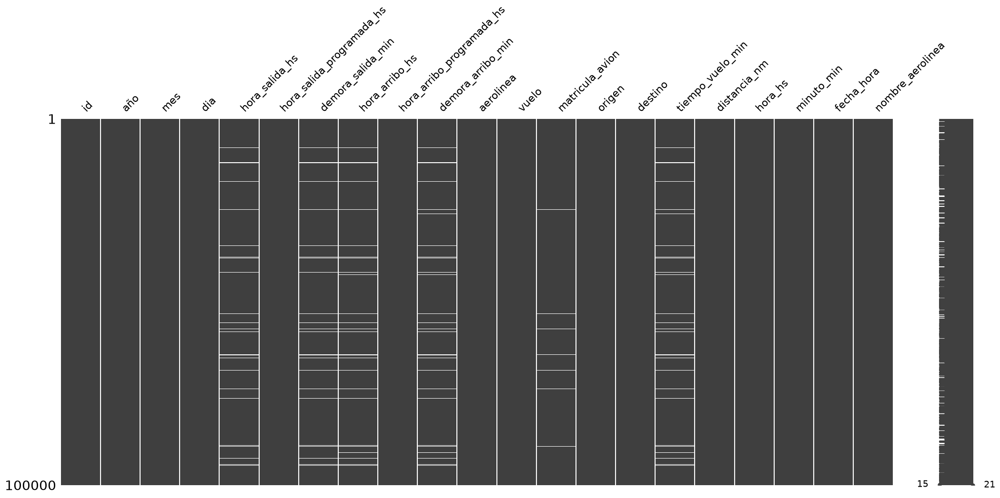

In [9]:
msno.matrix(df.sample(100000))

## 3. Feature Engineering — Creación de variables derivadas

### Fecha y hora de salida y arribo con tipo de dato de fecha

#### Minutos de demora de **SALIDA Y ARRIBO**

##### Salida

In [10]:
df["demora_salida_min"] = df["demora_salida_min"].astype("Int64")

df["demora_salida"] = pd.to_timedelta(
    df["demora_salida_min"],
    unit="min"
)

##### Arribo

In [11]:
df["demora_arribo_min"] = df["demora_arribo_min"].astype("Int64")

df["demora_arribo"] = pd.to_timedelta(
    df["demora_arribo_min"],
    unit="min"
)

In [12]:
type(df["demora_salida_min"].iloc[0])
type(df["demora_salida"].iloc[0])
type(df["demora_arribo_min"].iloc[0])
type(df["demora_arribo"].iloc[0])

pandas.Timedelta

#### Fecha, hora y sub temporalidades de ****SALIDA PROGRAMADA****

In [13]:
# ============================================================
# 1. CREAR FECHA Y HORA PROGRAMADA DE SALIDA
# ============================================================

df["fecha_salida_programada"] = pd.to_datetime(
    {
        "day": df["dia"],
        "month": df["mes"],
        "year": df["año"],
    },
    errors="coerce"
).dt.date

# Seleccionar la columna almacenada como HHMM
columna_hora_programada = 'hora_salida_programada_hs'

# Convertir a entero y completar con ceros a la izquierda
hora_str = (
    pd.to_numeric(df[columna_hora_programada], errors='coerce')
    .astype('Int64')
    .astype('string')
    .str.zfill(4)
)

df["hora_salida_programada"] = pd.to_datetime(
    hora_str,
    format="%H%M",
    errors="coerce"
).dt.time

# Combinar fecha y hora en una nueva columna
df["fecha_hora_salida_programada"] = (
    pd.to_datetime(df["fecha_salida_programada"])
    + pd.to_timedelta(
        df["hora_salida_programada"].astype(str)
    )
)

# Seleccionar la columna temporal
columna_fecha_hora_programada = 'fecha_hora_salida_programada'

# Extraer componentes temporales

#df['año_'] = df[columna_fecha_hora_programada].dt.year
df['mes_salida_programado'] = df[columna_fecha_hora_programada].dt.month

# Crear el nombre del día de la semana directamente desde la fecha
df["dia_semana_salida_programada_num"] = df[columna_fecha_hora_programada].dt.dayofweek

dias_semana = {
    0: 'lunes',
    1: 'martes',
    2: 'miércoles',
    3: 'jueves',
    4: 'viernes',
    5: 'sábado',
    6: 'domingo'
}

df['dia_semana_salida_programada'] = df['dia_semana_salida_programada_num'].map(dias_semana)

df['dia_salida_programado'] = df[columna_fecha_hora_programada].dt.day

df['hora_salida_programada_num'] = df[columna_fecha_hora_programada].dt.hour

df['minuto_salida_programada_num'] = df[columna_fecha_hora_programada].dt.minute


#df['trimestre'] = df[columna_fecha_hora_programada].dt.quarter
#df['trimestre'] = 'Q' + ' '+(df[columna_fecha_hora_programada].dt.quarter)
df["trimestre"] = df[columna_fecha_hora_programada].dt.to_period("Q")


df['semana_año_salida_programada'] = df[columna_fecha_hora_programada].dt.isocalendar().week

df["periodo_semana_salida_programada"] = (
    df[columna_fecha_hora_programada].dt.to_period("W")
)

display(df.dtypes.to_frame(name='tipo_dato'))

,tipo_dato
id,int64
año,int64
mes,int64
dia,int64
hora_salida_hs,float64
hora_salida_programada_hs,int64
demora_salida_min,Int64
hora_arribo_hs,float64
hora_arribo_programada_hs,int64
demora_arribo_min,Int64


#### Fecha, hora y sub temporalidades de ****SALIDA REAL****

In [14]:
# ============================================================
# 1. CREAR FECHA Y HORA REAL DE SALIDA
# ============================================================

df["fecha_hora_salida_real"] = (
    df["fecha_hora_salida_programada"]
    + pd.to_timedelta(
        df["demora_salida_min"],
        unit="min"
    )
)

df["fecha_salida_real"] = (
    df["fecha_hora_salida_real"].dt.date
)


df["hora_salida_real"] = df["fecha_hora_salida_real"].dt.time


#  Seleccionar la columna temporal
columna_fecha_hora_real = 'fecha_hora_salida_real'

# Extraer componentes temporales

# #df['año_'] = df[columna_fecha].dt.year
df['mes_salida_real'] = df[columna_fecha_hora_real].dt.month

# Crear el nombre del día de la semana directamente desde la fecha
df["dia_semanasalida_real_num"] = df[columna_fecha_hora_real].dt.dayofweek

dias_semana = {
    0: 'lunes',
    1: 'martes',
    2: 'miércoles',
    3: 'jueves',
    4: 'viernes',
    5: 'sábado',
    6: 'domingo'
}

df['dia_semana_salida_real'] = df['dia_semanasalida_real_num'].map(dias_semana)

df["periodo_semana_salida_real"] = (
    df[columna_fecha_hora_real].dt.to_period("W")
)



df['dia_salida_real'] = df[columna_fecha_hora_real].dt.day

df['hora_salida_real_num'] = df[columna_fecha_hora_real].dt.hour

df['minuto_salida_real_num'] = df[columna_fecha_hora_real].dt.minute


# #df['trimestre'] = df[columna_fecha].dt.quarter
# #df['trimestre'] = 'Q' + ' '+(df[columna_fecha].dt.quarter)
# df["trimestre"] = df[columna_fecha].dt.to_period("Q")


df['semana_año_salida_real'] = df[columna_fecha_hora_real].dt.isocalendar().week

display(df.dtypes.to_frame(name='tipo_dato'))

,tipo_dato
id,int64
año,int64
mes,int64
dia,int64
hora_salida_hs,float64
hora_salida_programada_hs,int64
demora_salida_min,Int64
hora_arribo_hs,float64
hora_arribo_programada_hs,int64
demora_arribo_min,Int64


#### Hora y sub temporalidades de ****ARRIBO PROGRAMADO****

In [15]:
# ============================================================
# 1. CREAR FECHA Y HORA PROGRAMADA DE ARRIBO
# ============================================================


# Seleccionar la columna almacenada como HHMM
columna_hora = 'hora_arribo_programada_hs'

# Convertir a entero y completar con ceros a la izquierda
hora_str = (
    pd.to_numeric(df[columna_hora], errors='coerce')
    .astype('Int64')
    .astype('string')
    .str.zfill(4)
)

df["hora_arribo_programada"] = pd.to_datetime(
    hora_str,
    format="%H%M",
    errors="coerce"
).dt.time

In [16]:
df.sample(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,demora_arribo,fecha_salida_programada,hora_salida_programada,fecha_hora_salida_programada,mes_salida_programado,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada_num,minuto_salida_programada_num,trimestre,semana_año_salida_programada,periodo_semana_salida_programada,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,periodo_semana_salida_real,dia_salida_real,hora_salida_real_num,minuto_salida_real_num,semana_año_salida_real,hora_arribo_programada
29976,29976,2013,10,4,618.0,622,-4,815.0,827,-12,EV,4150,N16571,EWR,CVG,88.0,569,6,22,2013-10-04 06:00:00,ExpressJet Airlines Inc.,-1 days +23:56:00,-1 days +23:48:00,2013-10-04,06:22:00,2013-10-04 06:22:00,10,4,viernes,4,6,22,2013Q4,40,2013-09-30/2013-10-06,2013-10-04 06:18:00,2013-10-04,06:18:00,10.0,4.0,viernes,2013-09-30/2013-10-06,4.0,6.0,18.0,40,08:27:00


#### Hora y sub temporalidades de ****ARRIBO REAL****

In [17]:
# ============================================================
# 1. CREAR FECHA Y HORA PROGRAMADA DE ARRIBO
# ============================================================


# Seleccionar la columna almacenada como HHMM
columna_hora = 'hora_arribo_hs'

# Convertir a entero y completar con ceros a la izquierda
hora_str = (
    pd.to_numeric(df[columna_hora], errors='coerce')
    .astype('Int64')
    .astype('string')
    .str.zfill(4)
)

df["hora_arribo_real"] = pd.to_datetime(
    hora_str,
    format="%H%M",
    errors="coerce"
).dt.time
display(df.dtypes.to_frame(name='tipo_dato'))

,tipo_dato
id,int64
año,int64
mes,int64
dia,int64
hora_salida_hs,float64
hora_salida_programada_hs,int64
demora_salida_min,Int64
hora_arribo_hs,float64
hora_arribo_programada_hs,int64
demora_arribo_min,Int64


In [18]:
type(df["hora_arribo_real"].iloc[0])

datetime.time

In [19]:
df.head(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,demora_arribo,fecha_salida_programada,hora_salida_programada,fecha_hora_salida_programada,mes_salida_programado,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada_num,minuto_salida_programada_num,trimestre,semana_año_salida_programada,periodo_semana_salida_programada,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,periodo_semana_salida_real,dia_salida_real,hora_salida_real_num,minuto_salida_real_num,semana_año_salida_real,hora_arribo_programada,hora_arribo_real
0,0,2013,1,1,517.0,515,2,830.0,819,11,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,0 days 00:02:00,0 days 00:11:00,2013-01-01,05:15:00,2013-01-01 05:15:00,1,1,martes,1,5,15,2013Q1,1,2012-12-31/2013-01-06,2013-01-01 05:17:00,2013-01-01,05:17:00,1.0,1.0,martes,2012-12-31/2013-01-06,1.0,5.0,17.0,1,08:19:00,08:30:00


### Vuelos Cancelados

In [20]:
df["estado_vuelo"] = (
    df["hora_salida_real"]
    .isna()
    .map({
        True: "cancelado",
        False: "operado"
    })
)

### Tiempo de vuelo

In [21]:
df["tiempo_vuelo"] = pd.to_timedelta(
    df["tiempo_vuelo_min"],
    unit="min"
)

### Estados de puntualidad

In [22]:
def puntualidad(retraso):

    if pd.isna(retraso):
        return "desconocido"

    elif retraso < pd.Timedelta(0):
        return "adelantado"

    elif retraso == pd.Timedelta(0):
        return "a tiempo"

    elif retraso < pd.Timedelta(minutes=5):
        return "aceptable"

    elif retraso <= pd.Timedelta(minutes=15):
        return "moderado"

    elif retraso <= pd.Timedelta(minutes=30):
        return "severo"

    else:
        return "critico"


# Crear las columnas con el nivel de puntualidad
df["nivel_puntualidad_salida"] = (
    df["demora_salida"].apply(puntualidad)
)

df["nivel_puntualidad_arribo"] = (
    df["demora_arribo"].apply(puntualidad)
)

### Periodo del día

In [23]:
df["periodo_salida_programado"] = pd.cut(
    df["hora_salida_programada"].apply(lambda x: x.hour if pd.notna(x) else None),
    bins=[0, 6, 12, 20, 24],
    right=False,
    labels=[
        "Madrugada",
        "Mañana",
        "Tarde",
        "Noche"
    ]
)

df["periodo_salida_real"] = pd.cut(
    df["hora_salida_real"].apply(lambda x: x.hour if pd.notna(x) else None),
    bins=[0, 6, 12, 20, 24],
    right=False,
    labels=[
        "Madrugada",
        "Mañana",
        "Tarde",
        "Noche"
    ]
)

df["periodo_arribo_programado"] = pd.cut(
    df["hora_arribo_programada"].apply(lambda x: x.hour if pd.notna(x) else None),
    bins=[0, 6, 12, 20, 24],
    right=False,
    labels=[
        "Madrugada",
        "Mañana",
        "Tarde",
        "Noche"
    ]
)

df["periodo_arribo__real"] = pd.cut(
    df["hora_arribo_real"].apply(lambda x: x.hour if pd.notna(x) else None),
    bins=[0, 6, 12, 20, 24],
    right=False,
    labels=[
        "Madrugada",
        "Mañana",
        "Tarde",
        "Noche"
    ]
)

### Diferencia entre demora de salida y demora de llegada

**`delay_difference`**: diferencia entre la demora de llegada y la demora de salida.

* **Valor positivo:** la demora aumentó durante el vuelo.
* **Valor negativo:** el vuelo recuperó tiempo.
* **Valor 0:** la demora se mantuvo igual.

Se mantiene como **variable numérica** porque representa una diferencia en minutos.


In [24]:
df["diferencia_demora"] = (
    df["demora_arribo"] - df["demora_salida"]
)

### Ruta (origen + destino )

Analizar la demora de un vuelo considerando el trayecto completo entre origen y destino.

Con ruta podemos investigar:

¿Qué rutas tienen más vuelos demorados?
¿Qué rutas tienen mayor demora promedio?
¿Hay rutas donde los vuelos suelen salir tarde pero recuperar tiempo?
¿La distancia de la ruta está relacionada con la demora?
¿Una determinada ruta presenta un patrón de demora recurrente?

In [25]:
df["ruta"] = (
    df["origen"].astype(str)
    + "-"
    + df["destino"].astype(str)
)

### **Cantidad de vuelos del avión en el año desde cada aeropuerto**

Indica qué número de vuelo está realizando la misma matrícula dentro del año en cada aeropuerto.

Por ejemplo, el primer vuelo registrado del avión en el año tendrá valor `1`, el segundo `2`, el tercero `3`, y así sucesivamente.

Permite analizar si la cantidad acumulada de vuelos realizados por un avión está relacionada con su puntualidad y sus demoras.

In [26]:
# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_programada",
        "fecha_hora_salida_real"
    ]
].copy()

# Determinar el año de referencia:
# salida real si existe; en caso contrario, año programado
temp["año_referencia"] = (
    temp["fecha_hora_salida_real"].dt.year
    .fillna(temp["fecha_hora_salida_programada"].dt.year)
    .astype("Int64")
)

# Ordenar por año de referencia y secuencia programada
temp = temp.sort_values(
    [
        "año_referencia",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Si tiene salida real, suma 1; si es NaT, suma 0
temp["vuelo_operado"] = (
    temp["fecha_hora_salida_real"].notna()
).astype("int8")

# Acumular vuelos operados por año, matrícula y origen
temp["vuelos_acumulados_avion_origen_año"] = (
    temp.groupby(
        [
            "año_referencia",
            "matricula_avion",
            "origen"
        ]
    )["vuelo_operado"]
    .cumsum()
    .astype("Int64")
)

# Devolver los resultados al DataFrame original usando el ID
df["vuelos_acumulados_avion_origen_año"] = (
    df["id"]
    .map(
        temp.set_index("id")[
            "vuelos_acumulados_avion_origen_año"
        ]
    )
    .astype("Int64")
)

### Numerar los vuelos de cada avión dentro de cada día ****PROGRAMADO Y REAL****

Avion que fue y volvio para volver a salir desde alguno de los 3 principales aeropuertos de NY en el mismo dia

In [27]:
# ============================================================
# ORDEN DE VUELOS POR AVIÓN Y DÍA
# ============================================================

temp = df[
    [
        "id",
        "matricula_avion",
        "fecha_hora_salida_programada",
        "fecha_hora_salida_real"
    ]
].copy()


# ------------------------------------------------------------
# 1. ORDEN DE VUELOS SEGÚN LA SALIDA PROGRAMADA
# ------------------------------------------------------------

temp_programado = temp.copy()

temp_programado["dia_programado"] = (
    temp_programado["fecha_hora_salida_programada"].dt.normalize()
)

# Ordenar por avión y horario programado
temp_programado = temp_programado.sort_values(
    [
        "matricula_avion",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Numerar todos los vuelos programados, incluidos los cancelados
temp_programado["numero_orden_vuelo_dia_programado"] = (
    temp_programado
    .groupby(
        ["dia_programado", "matricula_avion"],
        dropna=False
    )
    .cumcount()
    + 1
)

# Incorporar la columna al DataFrame original
df["numero_orden_vuelo_dia_programado"] = (
    df["id"]
    .map(
        temp_programado.set_index("id")[
            "numero_orden_vuelo_dia_programado"
        ]
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 2. ORDEN DE VUELOS SEGÚN LA SALIDA REAL
# ------------------------------------------------------------

temp_real = temp.copy()

# Si existe salida real, usarla.
# Si el vuelo fue cancelado, usar la salida programada
# como referencia para ubicarlo en la secuencia.
temp_real["fecha_hora_referencia"] = (
    temp_real["fecha_hora_salida_real"]
    .fillna(temp_real["fecha_hora_salida_programada"])
)

temp_real["dia_referencia"] = (
    temp_real["fecha_hora_referencia"].dt.normalize()
)

# Ordenar cronológicamente usando la referencia
temp_real = temp_real.sort_values(
    [
        "matricula_avion",
        "fecha_hora_referencia",
        "id"
    ]
)

# Los vuelos operados suman 1; los cancelados suman 0
temp_real["vuelo_operado"] = (
    temp_real["fecha_hora_salida_real"].notna()
).astype("int64")

# Acumular únicamente las salidas reales.
# Un vuelo cancelado conserva el acumulado anterior.
temp_real["numero_orden_vuelo_dia_real"] = (
    temp_real
    .groupby(
        ["dia_referencia", "matricula_avion"],
        dropna=False
    )["vuelo_operado"]
    .cumsum()
    .astype("Int64")
)

# Incorporar la columna al DataFrame original
df["numero_orden_vuelo_dia_real"] = (
    df["id"]
    .map(
        temp_real.set_index("id")[
            "numero_orden_vuelo_dia_real"
        ]
    )
    .astype("Int64")
)

--------------------------------------------------- 

### Retraso del vuelo anterior del aeropuerto

#### **Salida**

In [28]:
# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real",
        "demora_salida_min"
    ]
].copy()

# Ordenar solamente la tabla auxiliar
temp = temp.sort_values(
    [
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real",
        "id"
    ]
)

# Demora de llegada del vuelo anterior
temp["retraso_vuelo_anterior_salida"] = (
    temp.groupby(
        ["matricula_avion", "origen"]
    )["demora_salida_min"]
    .shift(1)
    .astype("Int64")
)

# Pasar al df original
df["retraso_vuelo_anterior_salida"] = (
    temp.set_index("id")[
        "retraso_vuelo_anterior_salida"
    ]
    .reindex(df["id"])
    .values
)

#### **Arribo**

In [29]:
# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real",
        "demora_arribo_min"
    ]
].copy()

# Ordenar solamente la tabla auxiliar
temp = temp.sort_values(
    [
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real",
        "id"
    ]
)

# Demora de llegada del vuelo anterior
temp["retraso_vuelo_anterior_arribo"] = (
    temp.groupby(
        ["matricula_avion", "origen"]
    )["demora_arribo_min"]
    .shift(1)
    .astype("Int64")
)

# Pasar al df original
df["retraso_vuelo_anterior_arribo"] = (
    temp.set_index("id")[
        "retraso_vuelo_anterior_arribo"
    ]
    .reindex(df["id"])
    .values
)

In [30]:
# Ordenar el DataFrame por la columna "id" y restablecer el índice
df = (
    df.sort_values("id")
    .reset_index(drop=True)
)

### **Porcentaje de vuelos anteriores con demora**


Calcula el porcentaje acumulado de vuelos anteriores del mismo aeropuerto de origen que presentaron demora de salida.

Se considera demorado un vuelo cuando `demora_salida_min > 0`.

Esta variable permite analizar si un historial reciente de demoras en el aeropuerto está relacionado con la demora del vuelo actual.


In [31]:
# Crear tabla auxiliar
temp = df[
    [
        "id",
        "origen",
        "fecha_hora_salida_programada",
        "demora_salida_min"
    ]
].copy()

# Ordenar cronológicamente por aeropuerto
temp = temp.sort_values(
    [
        "origen",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Indicar si cada vuelo tuvo demora
temp["vuelo_demorado"] = (
    temp["demora_salida_min"] > 0
)

# Cantidad acumulada de vuelos del aeropuerto
temp["vuelos_anteriores_origen"] = (
    temp.groupby("origen").cumcount()
)

# Cantidad acumulada de vuelos demorados
temp["demoras_acumuladas_origen"] = (
    temp.groupby("origen")["vuelo_demorado"]
    .cumsum()
)

# Demoras de vuelos anteriores, excluyendo el actual
temp["demoras_anteriores_origen"] = (
    temp.groupby("origen")["demoras_acumuladas_origen"]
    .shift(1)
)

# Calcular porcentaje
temp["porcentaje_demora_vuelos_anteriores_origen"] = (
    temp["demoras_anteriores_origen"]
    / temp["vuelos_anteriores_origen"]
    * 100
)

# Pasar a df
df["porcentaje_demora_vuelos_anteriores_origen_%"] = (
    temp["porcentaje_demora_vuelos_anteriores_origen"].round(2)
)

### Tiempo desde el vuelo anterior en el mismo aeropuerto

Tiempo entre la salida real del vuelo anterior y la salida real del vuelo actual del mismo avión, en el mismo aeropuerto

In [32]:
# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real"
    ]
].copy()

# Ordenar solo la tabla auxiliar
temp = temp.sort_values(
    [
        "matricula_avion",
        "origen",
        "fecha_hora_salida_real",
        "id"
    ]
)

# Salida real anterior del mismo avión desde el mismo aeropuerto
temp["salida_anterior_avion_origen"] = (
    temp.groupby(
        ["matricula_avion", "origen"]
    )["fecha_hora_salida_real"]
    .shift(1)
)

# Tiempo desde esa última salida
temp["tiempo_desde_ultima_salida_avion_origen"] = (
    temp["fecha_hora_salida_real"]
    - temp["salida_anterior_avion_origen"]
)

# Pasar el resultado al DataFrame original
df["tiempo_desde_ultima_salida_avion_origen"] = (
    temp.set_index("id")[
        "tiempo_desde_ultima_salida_avion_origen"
    ]
    .reindex(df["id"])
    .values
)

In [33]:
# Ordenar el DataFrame por la columna "id" y restablecer el índice
df = (
    df.sort_values("id")
    .reset_index(drop=True)
)

### Tiempo hasta la próxima salida del mismo avión en el mismo aeropuerto

**Vuelo siguiente del mismo aeropuerto**

`tiempo_hasta_salida_siguiente_origen`: tiempo entre la salida real del vuelo actual y la salida programada del siguiente vuelo del mismo aeropuerto.

Permite analizar la concentración de salidas y el nivel de actividad previsto alrededor de cada vuelo.


In [34]:
# ============================================================
# TIEMPO HASTA LA PRÓXIMA SALIDA PROGRAMADA
# DEL MISMO AVIÓN DESDE EL MISMO AEROPUERTO
# ============================================================

# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "fecha_hora_salida_programada",
        "fecha_hora_salida_real"
    ]
].copy()

# Ordenar según las salidas programadas
temp = temp.sort_values(
    [
        "matricula_avion",
        "origen",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Obtener la próxima salida programada del mismo avión
# desde el mismo aeropuerto
temp["proxima_salida_programada_avion_origen"] = (
    temp.groupby(
        ["matricula_avion", "origen"]
    )["fecha_hora_salida_programada"]
    .shift(-1)
)

# Calcular cuánto tiempo falta desde la salida REAL
# del vuelo actual hasta la próxima salida PROGRAMADA
temp["tiempo_hasta_proxima_salida_avion_origen"] = (
    temp["proxima_salida_programada_avion_origen"]
    - temp["fecha_hora_salida_real"]
)

# Pasar el resultado al DataFrame original
df["tiempo_hasta_proxima_salida_avion_origen"] = (
    df["id"]
    .map(
        temp.set_index("id")[
            "tiempo_hasta_proxima_salida_avion_origen"
        ]
    )
)

### Porcentaje de vuelos anteriores del aeropuerto con demora de **SALIDA Y ARRIBO**

Calcula el porcentaje acumulado de vuelos anteriores del mismo aeropuerto de origen que presentaron demora de salida y arribo, en el año.

Contar demoras moderadas o superiores: se considera demora relevante a partir de los 5 minutos. Así incluimos las categorías moderado, severo y crítico, pero no las demoras aceptables de menos de 5 minutos.


Esta variable permite analizar si un historial reciente de demoras en el aeropuerto está relacionado con la demora del vuelo actual.

In [35]:
# ============================================================
# PORCENTAJE ACUMULADO DE DEMORAS DE SALIDA Y DE ARRIBO
# POR AEROPUERTO, HASTA LA FECHA
# ============================================================

# Crear tabla auxiliar
temp = df[
    [
        "id",
        "origen",
        "estado_vuelo",
        "fecha_hora_salida_programada",
        "demora_salida",
        "demora_arribo"
    ]
].copy()

# Identificar el año de cada vuelo
temp["año_referencia"] = (
    temp["fecha_hora_salida_programada"].dt.year
)

# Ordenar cronológicamente por aeropuerto
temp = temp.sort_values(
    [
        "origen",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Agrupar por aeropuerto y año
grupos = ["origen", "año_referencia"]


# ------------------------------------------------------------
# 1. PORCENTAJE DE DEMORAS DE SALIDA
# ------------------------------------------------------------

# Identificar vuelos operados con demora de salida conocida
temp["salida_valida"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_salida"].notna()
).astype("int64")

# Identificar demoras moderadas o superiores: 5 minutos o más
temp["salida_demora_relevante"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_salida"].notna()
    & (temp["demora_salida"] >= pd.Timedelta(minutes=5))
).astype("int64")

# Acumular vuelos operados con demora de salida conocida
temp["vuelos_salida_acumulados"] = (
    temp.groupby(grupos, dropna=False)["salida_valida"]
    .cumsum()
)

# Acumular vuelos con demoras de salida relevantes
temp["demoras_salida_acumuladas"] = (
    temp.groupby(grupos, dropna=False)["salida_demora_relevante"]
    .cumsum()
)

# Obtener los acumulados anteriores, excluyendo el vuelo actual
temp["vuelos_salida_anteriores"] = (
    temp.groupby(grupos, dropna=False)["vuelos_salida_acumulados"]
    .shift(1)
)

temp["demoras_salida_anteriores"] = (
    temp.groupby(grupos, dropna=False)["demoras_salida_acumuladas"]
    .shift(1)
)

# Calcular el porcentaje de demoras de salida anteriores
temp["porcentaje_demora_salida_anteriores_origen_%"] = (
    temp["demoras_salida_anteriores"]
    / temp["vuelos_salida_anteriores"].where(
        temp["vuelos_salida_anteriores"] > 0
    )
    * 100
).round(2)


# ------------------------------------------------------------
# 2. PORCENTAJE DE DEMORAS DE ARRIBO
# ------------------------------------------------------------

# Identificar vuelos operados con demora de arribo conocida
temp["arribo_valido"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_arribo"].notna()
).astype("int64")

# Identificar demoras de arribo moderadas o superiores
temp["arribo_demora_relevante"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_arribo"].notna()
    & (temp["demora_arribo"] >= pd.Timedelta(minutes=5))
).astype("int64")

# Acumular vuelos operados con demora de arribo conocida
temp["vuelos_arribo_acumulados"] = (
    temp.groupby(grupos, dropna=False)["arribo_valido"]
    .cumsum()
)

# Acumular vuelos con demoras de arribo relevantes
temp["demoras_arribo_acumuladas"] = (
    temp.groupby(grupos, dropna=False)["arribo_demora_relevante"]
    .cumsum()
)

# Obtener los acumulados anteriores, excluyendo el vuelo actual
temp["vuelos_arribo_anteriores"] = (
    temp.groupby(grupos, dropna=False)["vuelos_arribo_acumulados"]
    .shift(1)
)

temp["demoras_arribo_anteriores"] = (
    temp.groupby(grupos, dropna=False)["demoras_arribo_acumuladas"]
    .shift(1)
)

# Calcular el porcentaje de demoras de arribo anteriores
temp["porcentaje_demora_arribo_anteriores_origen_%"] = (
    temp["demoras_arribo_anteriores"]
    / temp["vuelos_arribo_anteriores"].where(
        temp["vuelos_arribo_anteriores"] > 0
    )
    * 100
).round(2)


# ------------------------------------------------------------
# 3. PASAR LOS RESULTADOS AL DATAFRAME ORIGINAL
# ------------------------------------------------------------

resultados = temp.set_index("id")

df["porcentaje_demora_salida_anteriores_origen_%"] = (
    df["id"].map(
        resultados["porcentaje_demora_salida_anteriores_origen_%"]
    )
)

df["porcentaje_demora_arribo_anteriores_origen_%"] = (
    df["id"].map(
        resultados["porcentaje_demora_arribo_anteriores_origen_%"]
    )
)

### Porcentaje de vuelos anteriores con demora del mismo avión desde ese aeropuerto

Calcula el porcentaje acumulado de demoras de un avion con vuelos anteriores del mismo aeropuerto de origen que presentaron demora de salida y arribo, en el año.

Contar demoras moderadas o superiores: se considera demora relevante a partir de los 5 minutos. Así incluimos las categorías moderado, severo y crítico, pero no las demoras aceptables de menos de 5 minutos.


Esta variable permite analizar si un historial reciente de demoras en el aeropuerto está relacionado con la demora del vuelo actual.

In [36]:
# ============================================================
# PORCENTAJE ACUMULADO DE DEMORAS POR AVIÓN Y AEROPUERTO
# SALIDA Y ARRIBO, HASTA LA FECHA
# ============================================================

# Crear tabla auxiliar
temp = df[
    [
        "id",
        "matricula_avion",
        "origen",
        "estado_vuelo",
        "fecha_hora_salida_programada",
        "demora_salida_min",
        "demora_arribo_min"
    ]
].copy()

# Identificar el año de cada vuelo
temp["año_referencia"] = (
    temp["fecha_hora_salida_programada"].dt.year
)

# Ordenar cronológicamente
temp = temp.sort_values(
    [
        "matricula_avion",
        "origen",
        "fecha_hora_salida_programada",
        "id"
    ]
)

# Agrupar por avión, aeropuerto y año
grupos = [
    "matricula_avion",
    "origen",
    "año_referencia"
]


# ------------------------------------------------------------
# 1. PORCENTAJE DE DEMORAS DE SALIDA
# ------------------------------------------------------------

# Vuelos operados con demora de salida conocida
temp["salida_valida"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_salida_min"].notna()
).astype("int64")

# Vuelos con demora de salida relevante: 5 minutos o más
temp["salida_demora_relevante"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_salida_min"].notna()
    & (temp["demora_salida_min"] >= 5)
).astype("int64")

# Acumular vuelos válidos y vuelos demorados
temp["vuelos_salida_acumulados"] = (
    temp.groupby(grupos)["salida_valida"]
    .cumsum()
)

temp["demoras_salida_acumuladas"] = (
    temp.groupby(grupos)["salida_demora_relevante"]
    .cumsum()
)

# Obtener los acumulados anteriores, excluyendo el vuelo actual
temp["vuelos_salida_anteriores"] = (
    temp.groupby(grupos)["vuelos_salida_acumulados"]
    .shift(1)
)

temp["demoras_salida_anteriores"] = (
    temp.groupby(grupos)["demoras_salida_acumuladas"]
    .shift(1)
)

# Calcular porcentaje histórico de demoras de salida
temp["porcentaje_demora_salida_anteriores_avion_origen_%"] = (
    temp["demoras_salida_anteriores"]
    .div(
        temp["vuelos_salida_anteriores"].where(
            temp["vuelos_salida_anteriores"] > 0
        )
    )
    .mul(100)
    .round(2)
)


# ------------------------------------------------------------
# 2. PORCENTAJE DE DEMORAS DE ARRIBO
# ------------------------------------------------------------

# Vuelos operados con demora de arribo conocida
temp["arribo_valido"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_arribo_min"].notna()
).astype("int64")

# Vuelos con demora de arribo relevante: 5 minutos o más
temp["arribo_demora_relevante"] = (
    temp["estado_vuelo"].eq("operado")
    & temp["demora_arribo_min"].notna()
    & (temp["demora_arribo_min"] >= 5)
).astype("int64")

# Acumular vuelos válidos y vuelos demorados
temp["vuelos_arribo_acumulados"] = (
    temp.groupby(grupos)["arribo_valido"]
    .cumsum()
)

temp["demoras_arribo_acumuladas"] = (
    temp.groupby(grupos)["arribo_demora_relevante"]
    .cumsum()
)

# Obtener los acumulados anteriores, excluyendo el vuelo actual
temp["vuelos_arribo_anteriores"] = (
    temp.groupby(grupos)["vuelos_arribo_acumulados"]
    .shift(1)
)

temp["demoras_arribo_anteriores"] = (
    temp.groupby(grupos)["demoras_arribo_acumuladas"]
    .shift(1)
)

# Calcular porcentaje histórico de demoras de arribo
temp["porcentaje_demora_arribo_anteriores_avion_origen_%"] = (
    temp["demoras_arribo_anteriores"]
    .div(
        temp["vuelos_arribo_anteriores"].where(
            temp["vuelos_arribo_anteriores"] > 0
        )
    )
    .mul(100)
    .round(2)
)


# ------------------------------------------------------------
# 3. PASAR LOS RESULTADOS AL DATAFRAME ORIGINAL
# ------------------------------------------------------------

resultados = temp.set_index("id")

df["porcentaje_demora_salida_anteriores_avion_origen_%"] = (
    df["id"].map(
        resultados[
            "porcentaje_demora_salida_anteriores_avion_origen_%"
        ]
    )
)

df["porcentaje_demora_arribo_anteriores_avion_origen_%"] = (
    df["id"].map(
        resultados[
            "porcentaje_demora_arribo_anteriores_avion_origen_%"
        ]
    )
)

### Cantidad de aerolíneas con las que aparece asociada esa matrícula

In [37]:
df["numero_aerolineas_por_matricula"] = (
    df.groupby("matricula_avion")["aerolinea"]
    .transform("nunique")
    .astype("Int64")
)

### Densidad de vuelo por horario de salida (congestion de salida)

Tenemos la falta de datos de las llegadas a ese aeropuerto. y medir la congestion es incompleto por falta de datos como:


llegadas al aeropuerto;
ATOT / momento real de despegue;
ocupación de pista;
capacidad del aeropuerto;
estado de las pistas;
condiciones meteorológicas, etc.


En este ounto medimos a presión de salidas programadas que tiene el aeropuerto alrededor de cada vuelo.

densidad_salidas_origen tanto con programada con  salida real:

Programado = mejor candidato para predicción.

Real = mejor para analizar lo que efectivamente ocurrió.

 Cantidad de vuelos programados en el mismo aeropuerto de origen, dentro de una ventana de ±15; ±30 y ±60 minutos respecto de la hora programada de salida, sin contar el propio vuelo-Congestion

In [38]:
# ============================================================
#  FUNCIÓN PARA CALCULAR DENSIDAD
# ============================================================

def calcular_densidad(
    df,
    columna_fecha_hora,
    columna_resultado,
    minutos
):

    temp = df[
        [
            "id",
            "origen",
            columna_fecha_hora
        ]
    ].dropna(
        subset=[columna_fecha_hora]
    ).copy()

    temp = temp.sort_values(
        ["origen", columna_fecha_hora]
    )

    df[columna_resultado] = 0

    grupos = temp.groupby(
        [
            "origen",
            temp[columna_fecha_hora].dt.date
        ]
    )

    ventana = pd.Timedelta(
        minutes=minutos
    ).value

    for _, grupo in grupos:

        tiempos = (
            grupo[columna_fecha_hora]
            .astype("datetime64[ns]")
            .astype("int64")
            .to_numpy()
        )

        inicio = np.searchsorted(
            tiempos,
            tiempos - ventana,
            side="left"
        )

        fin = np.searchsorted(
            tiempos,
            tiempos + ventana,
            side="right"
        )

        cantidad = fin - inicio - 1

        df.loc[
            grupo["id"].index,
            columna_resultado
        ] = cantidad


# ============================================================
# 4. DENSIDAD DE SALIDAS PROGRAMADAS
# ============================================================

calcular_densidad(
    df,
    "fecha_hora_salida_programada",
    "densidad_salida_programada_15m",
    15
)

calcular_densidad(
    df,
    "fecha_hora_salida_programada",
    "densidad_salida_programada_30m",
    30
)

calcular_densidad(
    df,
    "fecha_hora_salida_programada",
    "densidad_salida_programada_60m",
    60
)


# ============================================================
# 5. DENSIDAD DE SALIDAS REALES
# ============================================================

calcular_densidad(
    df,
    "fecha_hora_salida_real",
    "densidad_salida_real_15m",
    15
)

calcular_densidad(
    df,
    "fecha_hora_salida_real",
    "densidad_salida_real_30m",
    30
)

calcular_densidad(
    df,
    "fecha_hora_salida_real",
    "densidad_salida_real_60m",
    60
)


# ============================================================
# 6. ASEGURAR TIPO ENTERO
# ============================================================

columnas_densidad = [
    "densidad_salida_programada_15m",
    "densidad_salida_programada_30m",
    "densidad_salida_programada_60m",
    "densidad_salida_real_15m",
    "densidad_salida_real_30m",
    "densidad_salida_real_60m"
]

for columna in columnas_densidad:
    df[columna] = df[columna].astype("int64")


# ============================================================
# 7. VOLVER AL ORDEN ORIGINAL
# ============================================================

df = (
    df.sort_values("id")
    .reset_index(drop=True)
)

In [39]:
df["estado_vuelo"] = (
    df["hora_salida_real"]
    .isna()
    .map({
        True: "cancelado",
        False: "operado"
    })
)

### Feriados y vispera de Feriados

In [40]:
# ============================================================
# FERIADOS FEDERALES DE EE.UU.
# DATASET: AÑO 2013
# ============================================================

feriados = pd.to_datetime([
    "2013-01-01",  # Año Nuevo
    "2013-01-21",  # Martin Luther King Jr.
    "2013-02-18",  # Washington's Birthday
    "2013-05-27",  # Memorial Day
    "2013-07-04",  # Independence Day
    "2013-09-02",  # Labor Day
    "2013-10-14",  # Columbus Day
    "2013-11-11",  # Veterans Day
    "2013-11-28",  # Thanksgiving
    "2013-12-25",  # Christmas
    "2014-01-01"   # Año Nuevo siguiente
])

# ============================================================
# PREPARAR LAS FECHAS DE FERIADOS
# ============================================================

# Convertir los feriados a fechas de pandas
feriados = pd.DatetimeIndex(
    pd.to_datetime(feriados)
).normalize()

# Crear la lista de vísperas: un día antes de cada feriado
visperas = feriados - pd.Timedelta(days=1)


# ============================================================
# CREAR LA COLUMNA
# ============================================================

# Normalizar las fechas de salida programada
fechas_salida = pd.to_datetime(
    df["fecha_salida_programada"],
    errors="coerce"
).dt.normalize()

df["feriado"] = np.select(
    [
        fechas_salida.isin(feriados),
        fechas_salida.isin(visperas)
    ],
    [
        "Feriado",
        "Víspera"
    ],
    default="Día normal"
)

### Tipo de Aerolinea

* **Tradicional:** aerolíneas que ofrecen una red amplia de rutas y diferentes tipos de servicios, generalmente incluyendo conexiones entre ciudades y servicios adicionales.
* **Bajo costo:** aerolíneas que buscan reducir costos operativos y ofrecer tarifas más económicas, normalmente con una estructura de servicios más simple.
* **Regional:** aerolíneas que operan principalmente vuelos de corta o media distancia y conectan ciudades pequeñas o regionales, muchas veces prestando servicios para aerolíneas tradicionales.
**Otro:** aerolíneas que no se clasifican dentro de las categorías de tradicionales, bajo costo o regionales utilizadas para este análisis. En este dataset, se incluye **Hawaiian Airlines Inc.**, ya que su operación está enfocada principalmente en conectar las islas de Hawái con otros destinos, por lo que no encaja directamente en las características de las otras tres categorías.


In [41]:
tipo_aerolinea = {
    "United Air Lines Inc.": "Tradicional",
    "American Airlines Inc.": "Tradicional",
    "JetBlue Airways": "Bajo costo",
    "Envoy Air": "Regional",
    "ExpressJet Airlines Inc.": "Regional",
    "Delta Air Lines Inc.": "Tradicional",
    "US Airways Inc.": "Tradicional",
    "Southwest Airlines Co.": "Bajo costo",
    "Virgin America": "Bajo costo",
    "AirTran Airways Corporation": "Bajo costo",
    "Alaska Airlines Inc.": "Tradicional",
    "Endeavor Air Inc.": "Regional",
    "Frontier Airlines Inc.": "Bajo costo",
    "Hawaiian Airlines Inc.": "Tradicional",
    "Mesa Airlines Inc.": "Otro",
    "SkyWest Airlines Inc.": "Regional"
}

df["tipo_aerolinea"] = df["nombre_aerolinea"].map(tipo_aerolinea)

### Guardado de DS Preparado

In [42]:
df_prepared = df.copy()

## 4. Ubicación y reordenamiento de las columnas

In [43]:
print(df.columns.tolist())

['id', 'año', 'mes', 'dia', 'hora_salida_hs', 'hora_salida_programada_hs', 'demora_salida_min', 'hora_arribo_hs', 'hora_arribo_programada_hs', 'demora_arribo_min', 'aerolinea', 'vuelo', 'matricula_avion', 'origen', 'destino', 'tiempo_vuelo_min', 'distancia_nm', 'hora_hs', 'minuto_min', 'fecha_hora', 'nombre_aerolinea', 'demora_salida', 'demora_arribo', 'fecha_salida_programada', 'hora_salida_programada', 'fecha_hora_salida_programada', 'mes_salida_programado', 'dia_semana_salida_programada_num', 'dia_semana_salida_programada', 'dia_salida_programado', 'hora_salida_programada_num', 'minuto_salida_programada_num', 'trimestre', 'semana_año_salida_programada', 'periodo_semana_salida_programada', 'fecha_hora_salida_real', 'fecha_salida_real', 'hora_salida_real', 'mes_salida_real', 'dia_semanasalida_real_num', 'dia_semana_salida_real', 'periodo_semana_salida_real', 'dia_salida_real', 'hora_salida_real_num', 'minuto_salida_real_num', 'semana_año_salida_real', 'hora_arribo_programada', 'hora_a

In [44]:
# Crear una tabla con posición, nombre y tipo de dato
info_columnas = pd.DataFrame({
    "columna": df.columns,
    "tipo_dato": df.dtypes.astype(str).to_numpy()
})

# Usar el índice como posición de cada columna
info_columnas.index.name = "posicion"

# Mostrar la tabla completa
with pd.option_context("display.max_rows", None):
    display(info_columnas)

,columna,tipo_dato
posicion,,
0,id,int64
1,año,int64
2,mes,int64
3,dia,int64
4,hora_salida_hs,float64
5,hora_salida_programada_hs,int64
6,demora_salida_min,Int64
7,hora_arribo_hs,float64
8,hora_arribo_programada_hs,int64


In [45]:
df.head(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,demora_arribo,fecha_salida_programada,hora_salida_programada,fecha_hora_salida_programada,mes_salida_programado,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada_num,minuto_salida_programada_num,trimestre,semana_año_salida_programada,periodo_semana_salida_programada,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,periodo_semana_salida_real,dia_salida_real,hora_salida_real_num,minuto_salida_real_num,semana_año_salida_real,hora_arribo_programada,hora_arribo_real,estado_vuelo,tiempo_vuelo,nivel_puntualidad_salida,nivel_puntualidad_arribo,periodo_salida_programado,periodo_salida_real,periodo_arribo_programado,periodo_arribo__real,diferencia_demora,ruta,vuelos_acumulados_avion_origen_año,numero_orden_vuelo_dia_programado,numero_orden_vuelo_dia_real,retraso_vuelo_anterior_salida,retraso_vuelo_anterior_arribo,porcentaje_demora_vuelos_anteriores_origen_%,tiempo_desde_ultima_salida_avion_origen,tiempo_hasta_proxima_salida_avion_origen,porcentaje_demora_salida_anteriores_origen_%,porcentaje_demora_arribo_anteriores_origen_%,porcentaje_demora_salida_anteriores_avion_origen_%,porcentaje_demora_arribo_anteriores_avion_origen_%,numero_aerolineas_por_matricula,densidad_salida_programada_15m,densidad_salida_programada_30m,densidad_salida_programada_60m,densidad_salida_real_15m,densidad_salida_real_30m,densidad_salida_real_60m,feriado,tipo_aerolinea
0,0,2013,1,1,517.0,515,2,830.0,819,11,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,0 days 00:02:00,0 days 00:11:00,2013-01-01,05:15:00,2013-01-01 05:15:00,1,1,martes,1,5,15,2013Q1,1,2012-12-31/2013-01-06,2013-01-01 05:17:00,2013-01-01,05:17:00,1.0,1.0,martes,2012-12-31/2013-01-06,1.0,5.0,17.0,1,08:19:00,08:30:00,operado,0 days 03:47:00,aceptable,moderado,Madrugada,Madrugada,Mañana,Mañana,0 days 00:09:00,EWR-IAH,1,1,1,<NA>,<NA>,<NA>,NaT,7 days 09:23:00,NaN,NaN,NaN,NaN,1,0,0,10,0,0,9,Feriado,Tradicional


In [46]:
from IPython.display import display, Markdown

# Generar una lista de columnas en formato de código Python
codigo_columnas = (
    "columnas_ordenadas = [\n"
    + "".join(
        f"    {columna!r},\n"
        for columna in df.columns
    )
    + "]"
)

# Mostrar la lista completa dentro de la notebook
display(Markdown(
    f"```python\n{codigo_columnas}\n```"
))


```python
columnas_ordenadas = [
    'id',
    'año',
    'mes',
    'dia',
    'hora_salida_hs',
    'hora_salida_programada_hs',
    'demora_salida_min',
    'hora_arribo_hs',
    'hora_arribo_programada_hs',
    'demora_arribo_min',
    'aerolinea',
    'vuelo',
    'matricula_avion',
    'origen',
    'destino',
    'tiempo_vuelo_min',
    'distancia_nm',
    'hora_hs',
    'minuto_min',
    'fecha_hora',
    'nombre_aerolinea',
    'demora_salida',
    'demora_arribo',
    'fecha_salida_programada',
    'hora_salida_programada',
    'fecha_hora_salida_programada',
    'mes_salida_programado',
    'dia_semana_salida_programada_num',
    'dia_semana_salida_programada',
    'dia_salida_programado',
    'hora_salida_programada_num',
    'minuto_salida_programada_num',
    'trimestre',
    'semana_año_salida_programada',
    'periodo_semana_salida_programada',
    'fecha_hora_salida_real',
    'fecha_salida_real',
    'hora_salida_real',
    'mes_salida_real',
    'dia_semanasalida_real_num',
    'dia_semana_salida_real',
    'periodo_semana_salida_real',
    'dia_salida_real',
    'hora_salida_real_num',
    'minuto_salida_real_num',
    'semana_año_salida_real',
    'hora_arribo_programada',
    'hora_arribo_real',
    'estado_vuelo',
    'tiempo_vuelo',
    'nivel_puntualidad_salida',
    'nivel_puntualidad_arribo',
    'periodo_salida_programado',
    'periodo_salida_real',
    'periodo_arribo_programado',
    'periodo_arribo__real',
    'diferencia_demora',
    'ruta',
    'vuelos_acumulados_avion_origen_año',
    'numero_orden_vuelo_dia_programado',
    'numero_orden_vuelo_dia_real',
    'retraso_vuelo_anterior_salida',
    'retraso_vuelo_anterior_arribo',
    'porcentaje_demora_vuelos_anteriores_origen_%',
    'tiempo_desde_ultima_salida_avion_origen',
    'tiempo_hasta_proxima_salida_avion_origen',
    'porcentaje_demora_salida_anteriores_origen_%',
    'porcentaje_demora_arribo_anteriores_origen_%',
    'porcentaje_demora_salida_anteriores_avion_origen_%',
    'porcentaje_demora_arribo_anteriores_avion_origen_%',
    'numero_aerolineas_por_matricula',
    'densidad_salida_programada_15m',
    'densidad_salida_programada_30m',
    'densidad_salida_programada_60m',
    'densidad_salida_real_15m',
    'densidad_salida_real_30m',
    'densidad_salida_real_60m',
    'feriado',
    'tipo_aerolinea',
]
```

In [47]:
orden_columnas = [
    #Originales de base de datos
    'id',
    'año',
    'mes',
    'dia',
    'hora_salida_hs',
    'hora_salida_programada_hs',
    'demora_salida_min',
    'hora_arribo_hs',
    'hora_arribo_programada_hs',
    'demora_arribo_min',
    'aerolinea',
    'vuelo',
    'matricula_avion',
    'origen',
    'destino',
    'tiempo_vuelo_min',
    'distancia_nm',
    'hora_hs',
    'minuto_min',
    'fecha_hora',
    'nombre_aerolinea',
    #Calculadas a partir de originales de base de datos
    #-----------------------------------SALIDAS
    'demora_salida',
    #-----------------------------------Salidas Programadas
    'trimestre',
    'periodo_semana_salida_programada',
    'mes_salida_programado',
    'semana_año_salida_programada',
    'fecha_hora_salida_programada',
    'fecha_salida_programada',
    'dia_semana_salida_programada_num',
    'dia_semana_salida_programada',
    'dia_salida_programado',
    'hora_salida_programada',
    'hora_salida_programada_num',
    'minuto_salida_programada_num',
    'periodo_salida_real',
    
    #-----------------------------------Salidas Reales
    'semana_año_salida_real',
    'periodo_semana_salida_real',
    'mes_salida_real',
    'dia_semanasalida_real_num',
    'dia_semana_salida_real',
    'dia_salida_real',
    'fecha_hora_salida_real',
    'fecha_salida_real',
    'hora_salida_real',
    'hora_salida_real_num',
    'minuto_salida_real_num',
    'periodo_salida_programado',
    'feriado',
    
    #-----------------------------------Arribos
    'demora_arribo',
    'hora_arribo_programada',
    'hora_arribo_real',
    'periodo_arribo_programado',
    'periodo_arribo__real',
    
    #-----------------------------------Datos de puntualidad
    'estado_vuelo',
    'tiempo_vuelo',
    'nivel_puntualidad_salida',
    'nivel_puntualidad_arribo',
    'diferencia_demora',
    
    #-----------------------------------Aeropuerto
    'ruta',
    'vuelos_acumulados_avion_origen_año',
    'numero_orden_vuelo_dia_real',
    'numero_orden_vuelo_dia_programado',
    'retraso_vuelo_anterior_salida',
    'retraso_vuelo_anterior_arribo',
    'porcentaje_demora_vuelos_anteriores_origen_%',
    'porcentaje_demora_salida_anteriores_origen_%',
    'porcentaje_demora_arribo_anteriores_origen_%',
    'densidad_salida_programada_15m',
    'densidad_salida_programada_30m',
    'densidad_salida_programada_60m',
    'densidad_salida_real_15m',
    'densidad_salida_real_30m',
    'densidad_salida_real_60m',
    
    #------------------------------------Avion
    'tiempo_desde_ultima_salida_avion_origen',
    'tiempo_hasta_proxima_salida_avion_origen',
    'porcentaje_demora_salida_anteriores_avion_origen_%',
    'porcentaje_demora_arribo_anteriores_avion_origen_%',
    'numero_aerolineas_por_matricula',
    'tipo_aerolinea',
    #-------------------------------------------------------------
]


# Reordenar el DataFrame
df = df[orden_columnas]

In [48]:
df.head(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,trimestre,periodo_semana_salida_programada,mes_salida_programado,semana_año_salida_programada,fecha_hora_salida_programada,fecha_salida_programada,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada,hora_salida_programada_num,minuto_salida_programada_num,periodo_salida_real,semana_año_salida_real,periodo_semana_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,dia_salida_real,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,hora_salida_real_num,minuto_salida_real_num,periodo_salida_programado,feriado,demora_arribo,hora_arribo_programada,hora_arribo_real,periodo_arribo_programado,periodo_arribo__real,estado_vuelo,tiempo_vuelo,nivel_puntualidad_salida,nivel_puntualidad_arribo,diferencia_demora,ruta,vuelos_acumulados_avion_origen_año,numero_orden_vuelo_dia_real,numero_orden_vuelo_dia_programado,retraso_vuelo_anterior_salida,retraso_vuelo_anterior_arribo,porcentaje_demora_vuelos_anteriores_origen_%,porcentaje_demora_salida_anteriores_origen_%,porcentaje_demora_arribo_anteriores_origen_%,densidad_salida_programada_15m,densidad_salida_programada_30m,densidad_salida_programada_60m,densidad_salida_real_15m,densidad_salida_real_30m,densidad_salida_real_60m,tiempo_desde_ultima_salida_avion_origen,tiempo_hasta_proxima_salida_avion_origen,porcentaje_demora_salida_anteriores_avion_origen_%,porcentaje_demora_arribo_anteriores_avion_origen_%,numero_aerolineas_por_matricula,tipo_aerolinea
0,0,2013,1,1,517.0,515,2,830.0,819,11,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,0 days 00:02:00,2013Q1,2012-12-31/2013-01-06,1,1,2013-01-01 05:15:00,2013-01-01,1,martes,1,05:15:00,5,15,Madrugada,1,2012-12-31/2013-01-06,1.0,1.0,martes,1.0,2013-01-01 05:17:00,2013-01-01,05:17:00,5.0,17.0,Madrugada,Feriado,0 days 00:11:00,08:19:00,08:30:00,Mañana,Mañana,operado,0 days 03:47:00,aceptable,moderado,0 days 00:09:00,EWR-IAH,1,1,1,<NA>,<NA>,<NA>,NaN,NaN,0,0,10,0,0,9,NaT,7 days 09:23:00,NaN,NaN,1,Tradicional


## 5. Sanity Check

In [49]:
# Sanity Check: Diagnóstico estructural básico del DataFrame

print('--- 1. Dimensiones (Filas, Columnas) ---')
print(df.shape)

print('\\n--- 2. Tipos de datos ---')
print(df.dtypes)

print('\\n--- 3. Valores nulos por columna ---')
null_summary = pd.DataFrame({
    'nulos': df.isnull().sum(),
    'porcentaje_nulos': (df.isnull().mean() * 100).round(2),
    'valores_unicos': df.nunique(dropna=False)
}).sort_values('porcentaje_nulos', ascending=False)

display(null_summary)

print('\\n--- 4. Filas duplicadas ---')
print(df.duplicated().sum())

print('\\n--- 5. Columnas constantes ---')
constant_cols = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]
print(constant_cols if constant_cols else 'No se encontraron columnas constantes.')

print('\\n--- 6. Uso de memoria ---')
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f'{memory_mb:.2f} MB')

print('\\n--- 7. Columnas numéricas ---')
print(df.select_dtypes(include='number').columns.tolist())

print('\\n--- 8. Columnas categóricas / texto ---')
print(df.select_dtypes(include=['object', 'category']).columns.tolist())

print('\\n--- 9. Estadísticas descriptivas ---')
display(df.describe(include='all').T)

--- 1. Dimensiones (Filas, Columnas) ---
(336776, 79)
\n--- 2. Tipos de datos ---
id                                                              int64
año                                                             int64
mes                                                             int64
dia                                                             int64
hora_salida_hs                                                float64
                                                           ...       
tiempo_hasta_proxima_salida_avion_origen              timedelta64[us]
porcentaje_demora_salida_anteriores_avion_origen_%            float64
porcentaje_demora_arribo_anteriores_avion_origen_%            float64
numero_aerolineas_por_matricula                                 Int64
tipo_aerolinea                                                    str
Length: 79, dtype: object
\n--- 3. Valores nulos por columna ---


,nulos,porcentaje_nulos,valores_unicos
tiempo_desde_ultima_salida_avion_origen,16181,4.80,45700
tiempo_hasta_proxima_salida_avion_origen,16080,4.77,45358
retraso_vuelo_anterior_arribo,15503,4.60,574
retraso_vuelo_anterior_salida,14341,4.26,524
porcentaje_demora_salida_anteriores_avion_origen_%,10569,3.14,4804
...,...,...,...
densidad_salida_programada_15m,0,0.00,29
porcentaje_demora_arribo_anteriores_origen_%,3,0.00,2938
densidad_salida_real_60m,0,0.00,70
densidad_salida_real_30m,0,0.00,40


\n--- 4. Filas duplicadas ---
0
\n--- 5. Columnas constantes ---
['año']
\n--- 6. Uso de memoria ---
495.56 MB
\n--- 7. Columnas numéricas ---
['id', 'año', 'mes', 'dia', 'hora_salida_hs', 'hora_salida_programada_hs', 'demora_salida_min', 'hora_arribo_hs', 'hora_arribo_programada_hs', 'demora_arribo_min', 'vuelo', 'tiempo_vuelo_min', 'distancia_nm', 'hora_hs', 'minuto_min', 'demora_salida', 'mes_salida_programado', 'semana_año_salida_programada', 'dia_semana_salida_programada_num', 'dia_salida_programado', 'hora_salida_programada_num', 'minuto_salida_programada_num', 'semana_año_salida_real', 'mes_salida_real', 'dia_semanasalida_real_num', 'dia_salida_real', 'hora_salida_real_num', 'minuto_salida_real_num', 'demora_arribo', 'tiempo_vuelo', 'diferencia_demora', 'vuelos_acumulados_avion_origen_año', 'numero_orden_vuelo_dia_real', 'numero_orden_vuelo_dia_programado', 'retraso_vuelo_anterior_salida', 'retraso_vuelo_anterior_arribo', 'porcentaje_demora_vuelos_anteriores_origen_%', 'porcenta

C:\Users\pres_\AppData\Local\Temp\ipykernel_2448\4041476513.py:33: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include=['object', 'category']).columns.tolist())


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,336776.0,NaN,NaN,NaN,168387.5,0.0,84193.75,168387.5,252581.25,336775.0,97219.001466
año,336776.0,NaN,NaN,NaN,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,0.0
mes,336776.0,NaN,NaN,NaN,6.54851,1.0,4.0,7.0,10.0,12.0,3.414457
dia,336776.0,NaN,NaN,NaN,15.710787,1.0,8.0,16.0,23.0,31.0,8.768607
hora_salida_hs,328521.0,NaN,NaN,NaN,1349.109947,1.0,907.0,1401.0,1744.0,2400.0,488.281791
...,...,...,...,...,...,...,...,...,...,...,...
tiempo_hasta_proxima_salida_avion_origen,320696,NaN,NaN,NaN,6 days 10:18:33.932883,-1 days +14:08:00,0 days 12:06:00,1 days 06:12:00,5 days 13:32:00,354 days 11:36:00,15 days 08:11:56.381227
porcentaje_demora_salida_anteriores_avion_origen_%,326207.0,NaN,NaN,NaN,31.585861,0.0,21.95,31.91,40.79,100.0,15.960138
porcentaje_demora_arribo_anteriores_avion_origen_%,326188.0,NaN,NaN,NaN,35.366621,0.0,25.97,34.88,44.33,100.0,16.327594
numero_aerolineas_por_matricula,334264.0,<NA>,<NA>,<NA>,1.002465,1.0,1.0,1.0,1.0,2.0,0.049589


In [50]:
# ============================================================
# REVISIÓN GENERAL DEL DATAFRAME 
# ============================================================

# Dimensiones del DataFrame
print(f"Cantidad de filas: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]:,}")

# Revisar duplicados
print(f"\nFilas duplicadas: {df.duplicated().sum():,}")
print(f"IDs duplicados: {df['id'].duplicated().sum():,}")

# Crear resumen de las columnas
resumen_eda = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "faltantes": df.isna().sum(),
    "faltantes_pct": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
})

# Mostrar el resumen completo
resumen_eda.index.name = "columna"

with pd.option_context("display.max_rows", None):
    display(resumen_eda)

Cantidad de filas: 336,776
Cantidad de columnas: 79

Filas duplicadas: 0
IDs duplicados: 0


,tipo_dato,no_nulos,faltantes,faltantes_pct,valores_unicos
columna,,,,,
id,int64,336776,0,0.00,336776
año,int64,336776,0,0.00,1
mes,int64,336776,0,0.00,12
dia,int64,336776,0,0.00,31
hora_salida_hs,float64,328521,8255,2.45,1318
hora_salida_programada_hs,int64,336776,0,0.00,1021
demora_salida_min,Int64,328521,8255,2.45,527
hora_arribo_hs,float64,328063,8713,2.59,1411
hora_arribo_programada_hs,int64,336776,0,0.00,1163


In [51]:
# Comprobar diferencias entre el dato original y el derivado

mascara_arribo_faltante = (
    df["hora_arribo_hs"].notna()
    & df["hora_arribo_real"].isna()
)

print(
    "Hora de llegada original disponible, "
    "pero variable derivada faltante:",
    mascara_arribo_faltante.sum()
)

display(
    df.loc[
        mascara_arribo_faltante,
        [
            "id",
            "año",
            "mes",
            "dia",
            "hora_salida_hs",
            "hora_arribo_hs",
            "hora_arribo_programada_hs",
            "demora_arribo_min",
            "tiempo_vuelo_min",
            "origen",
            "destino",
        ],
    ].head(20)
)

Hora de llegada original disponible, pero variable derivada faltante: 150


,id,año,mes,dia,hora_salida_hs,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,tiempo_vuelo_min,origen,destino
817,817,2013,1,1,2209.0,2400.0,2337,23,86.0,JFK,RDU
4303,4303,2013,1,5,2116.0,2400.0,18,-18,151.0,LGA,FLL
11249,11249,2013,1,13,2243.0,2400.0,2224,96,31.0,EWR,PHL
13918,13918,2013,1,16,2138.0,2400.0,2322,38,126.0,EWR,SDF
14916,14916,2013,1,17,2256.0,2400.0,2357,3,47.0,JFK,SYR
19091,19091,2013,1,22,2212.0,2400.0,2250,70,88.0,LGA,DTW
19102,19102,2013,1,22,2249.0,2400.0,2250,70,115.0,LGA,BNA
21750,21750,2013,1,25,2055.0,2400.0,1933,267,114.0,EWR,CVG
24217,24217,2013,1,28,2303.0,2400.0,2354,6,34.0,JFK,BOS
25948,25948,2013,1,30,2155.0,2400.0,2137,143,166.0,EWR,OMA


In [52]:
df.head(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,trimestre,periodo_semana_salida_programada,mes_salida_programado,semana_año_salida_programada,fecha_hora_salida_programada,fecha_salida_programada,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada,hora_salida_programada_num,minuto_salida_programada_num,periodo_salida_real,semana_año_salida_real,periodo_semana_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,dia_salida_real,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,hora_salida_real_num,minuto_salida_real_num,periodo_salida_programado,feriado,demora_arribo,hora_arribo_programada,hora_arribo_real,periodo_arribo_programado,periodo_arribo__real,estado_vuelo,tiempo_vuelo,nivel_puntualidad_salida,nivel_puntualidad_arribo,diferencia_demora,ruta,vuelos_acumulados_avion_origen_año,numero_orden_vuelo_dia_real,numero_orden_vuelo_dia_programado,retraso_vuelo_anterior_salida,retraso_vuelo_anterior_arribo,porcentaje_demora_vuelos_anteriores_origen_%,porcentaje_demora_salida_anteriores_origen_%,porcentaje_demora_arribo_anteriores_origen_%,densidad_salida_programada_15m,densidad_salida_programada_30m,densidad_salida_programada_60m,densidad_salida_real_15m,densidad_salida_real_30m,densidad_salida_real_60m,tiempo_desde_ultima_salida_avion_origen,tiempo_hasta_proxima_salida_avion_origen,porcentaje_demora_salida_anteriores_avion_origen_%,porcentaje_demora_arribo_anteriores_avion_origen_%,numero_aerolineas_por_matricula,tipo_aerolinea
0,0,2013,1,1,517.0,515,2,830.0,819,11,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.,0 days 00:02:00,2013Q1,2012-12-31/2013-01-06,1,1,2013-01-01 05:15:00,2013-01-01,1,martes,1,05:15:00,5,15,Madrugada,1,2012-12-31/2013-01-06,1.0,1.0,martes,1.0,2013-01-01 05:17:00,2013-01-01,05:17:00,5.0,17.0,Madrugada,Feriado,0 days 00:11:00,08:19:00,08:30:00,Mañana,Mañana,operado,0 days 03:47:00,aceptable,moderado,0 days 00:09:00,EWR-IAH,1,1,1,<NA>,<NA>,<NA>,NaN,NaN,0,0,10,0,0,9,NaT,7 days 09:23:00,NaN,NaN,1,Tradicional


## 6. EDA 2 — Análisis de factores asociados a las demoras de llegada

### Objetivo del análisis

#### Analizar y predecir las demoras de llegada de los vuelos, buscando identificar qué factores están asociados a que un vuelo llegue tarde.

A través de estadísticas descriptivas y visualizaciones, se investigarán patrones relacionados con la matrícula del avión, la aerolínea, los aeropuertos, las rutas, los horarios y la secuencia de vuelos durante el día.

#### Criterios generales

- **Demora relevante:** llegada con 5 minutos o más de retraso.
- **Variable principal:** `demora_arribo_min`.
- **Comparaciones:** se analizarán tanto la cantidad de vuelos demorados como su proporción sobre el total de vuelos evaluables.
- **Datos faltantes:** para analizar las demoras de llegada se utilizarán los vuelos que tengan ese dato disponible.
- **Interpretación:** los resultados permitirán identificar asociaciones y patrones, pero no necesariamente demostrar relaciones de causa y efecto.

### Variables Categoricas Relevantes

In [53]:
# REVISIÓN DE CATEGORÍAS RELEVANTES


# 1. Seleccionar las variables que queremos revisar.
columnas_categoricas = [
    # Aerolíneas
    "aerolinea",
    "nombre_aerolinea",
    "tipo_aerolinea",

    # Aeropuertos y rutas
    "origen",
    "destino",
    "ruta",

    # Estado y calendario
    "estado_vuelo",
    "feriado",
    "dia_semana_salida_programada",
    "dia_semana_salida_real",
    "dia_semana_arribo_programada",
    "dia_semana_arribo_real",
    "trimestre",

    # Períodos del día
    "periodo_salida_programado",
    "periodo_salida_real",
    "periodo_arribo_programado",
    "periodo_arribo__real",

    # Niveles de puntualidad
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo",
]


# 2. Comprobar qué columnas existen en el DataFrame.
columnas_existentes = [
    columna
    for columna in columnas_categoricas
    if columna in df.columns
]

columnas_faltantes = [
    columna
    for columna in columnas_categoricas
    if columna not in df.columns
]


# 3. Crear el encabezado del archivo.
bloques = []

bloques.append("REVISIÓN DE CATEGORÍAS RELEVANTES")
bloques.append("=" * 60)

bloques.append(
    f"Columnas solicitadas: {len(columnas_categoricas)}"
)
bloques.append(
    f"Columnas encontradas: {len(columnas_existentes)}"
)
bloques.append(
    f"Columnas no encontradas: {len(columnas_faltantes)}"
)


# 4. Registrar las columnas que no existen.
if columnas_faltantes:
    bloques.append("\nCOLUMNAS NO ENCONTRADAS")
    bloques.append("-" * 60)

    for columna in columnas_faltantes:
        bloques.append(f"- {columna}")


# 5. Obtener las frecuencias de cada columna disponible.
for columna in columnas_existentes:

    serie = df[columna]

    bloques.append("\n" + "=" * 60)
    bloques.append(f"COLUMNA: {columna}")
    bloques.append(f"TIPO DE DATO: {serie.dtype}")
    bloques.append(
        f"VALORES ÚNICOS: {serie.nunique(dropna=True)}"
    )
    bloques.append(
        f"FALTANTES: {serie.isna().sum()}"
    )
    bloques.append("-" * 60)

    frecuencias = serie.value_counts(dropna=False)

    bloques.append(
        frecuencias.to_string()
    )


# 6. Unir todos los resultados en un único texto.
contenido_txt = "\n".join(bloques)


# 7. Exportar el archivo TXT.
archivo_txt = Path("categorias_eda2.txt")

archivo_txt.write_text(
    contenido_txt,
    encoding="utf-8"
)


# 8. Confirmar la ubicación del archivo.
print("Revisión finalizada.")
print(f"Columnas encontradas: {len(columnas_existentes)}")
print(f"Columnas no encontradas: {len(columnas_faltantes)}")
print(f"Archivo generado: {archivo_txt.resolve()}")

if columnas_faltantes:
    print("\nRevisá las columnas no encontradas dentro del TXT.")

Revisión finalizada.
Columnas encontradas: 17
Columnas no encontradas: 2
Archivo generado: C:\Users\pres_\Desktop\lPanth\Cursos YPF\Data Science\df - base - practica\categorias_eda2.txt

Revisá las columnas no encontradas dentro del TXT.


--- 

### Análisis estadístico general de los vuelos



Objetivo

Analizar las características generales de los vuelos mediante medidas estadísticas y visualizaciones, para comprender la distribución de las demoras, la duración de los vuelos y las distancias recorridas.

Variables principales

- `demora_salida_min`: demora de salida en minutos.
- `demora_arribo_min`: demora de llegada en minutos.
- `tiempo_vuelo_min`: duración del vuelo en minutos.
- `distancia_nm`: distancia del vuelo en millas.

Estadísticas descriptivas

Se calcularán la cantidad de observaciones disponibles, los valores faltantes, la media, la mediana, la moda, la varianza, la desviación estándar, los valores mínimo y máximo, los cuartiles, el rango intercuartílico y los percentiles 90 y 95.

También se analizará la asimetría de las distribuciones para detectar si existen valores extremos que afecten las medidas de tendencia central.

Visualizaciones

Se utilizarán histogramas para observar la distribución de las variables numéricas y gráficos de barras para resumir la distribución de vuelos por estado, aerolínea, aeropuerto de origen y período programado.

Las estadísticas de demoras y duración se calcularán sobre vuelos operados con datos disponibles. Los vuelos cancelados se incluirán en el resumen general de estados, pero no se les asignarán demoras o duraciones inexistentes.

**Resultado esperado:** obtener una descripción general de la operación y de las demoras antes de profundizar en los factores asociados con la puntualidad.

In [54]:
#Estadísticas descriptivas generales

# 1. Separar los vuelos operados.
df_operados = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

# 2. Seleccionar variables numéricas relevantes.
variables = {
    "Demora de salida (min)": df_operados["demora_salida_min"],
    "Demora de llegada (min)": df_operados["demora_arribo_min"],
    "Duración del vuelo (min)": df_operados["tiempo_vuelo_min"],
    "Distancia (nm)": df_operados["distancia_nm"],
}

# 3. Función para calcular las estadísticas.
def calcular_estadisticas(serie):

    valores = pd.to_numeric(
        serie, errors="coerce"
    ).dropna()

    if valores.empty:
        return {
            "observaciones": 0,
            "faltantes": int(serie.isna().sum())
        }

    moda = valores.mode()
    modas_texto = ", ".join(
        str(round(float(valor), 2))
        for valor in moda.head(5)
    )

    if len(moda) > 5:
        modas_texto += ", ..."

    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)

    return {
        "observaciones": len(valores),
        "faltantes": int(serie.isna().sum()),
        "media": valores.mean(),
        "mediana": valores.median(),
        "moda": modas_texto,
        "cantidad_modas": len(moda),
        "varianza": valores.var(),
        "desviacion_estandar": valores.std(),
        "minimo": valores.min(),
        "percentil_25": q1,
        "percentil_75": q3,
        "rango_intercuartilico": q3 - q1,
        "percentil_90": valores.quantile(0.90),
        "percentil_95": valores.quantile(0.95),
        "maximo": valores.max(),
        "asimetria": valores.skew()
    }


# 4. Construir la tabla general.
resumen_estadistico = pd.DataFrame({
    nombre: calcular_estadisticas(serie)
    for nombre, serie in variables.items()
}).T

print("Estadísticas descriptivas de los vuelos operados:")
display(resumen_estadistico.round(2))


# 5. Resumen general de los registros.
print(f"Filas totales del dataset: {len(df):,}")
print(f"Vuelos operados: {(df['estado_vuelo'] == 'operado').sum():,}")
print(f"Vuelos cancelados: {(df['estado_vuelo'] == 'cancelado').sum():,}")

Estadísticas descriptivas de los vuelos operados:


,observaciones,faltantes,media,mediana,moda,cantidad_modas,varianza,desviacion_estandar,minimo,percentil_25,percentil_75,rango_intercuartilico,percentil_90,percentil_95,maximo,asimetria
Demora de salida (min),328521,0,12.63907,-2.0,-5.0,1,1616.848997,40.210061,-43,-5.0,11.0,16.0,49.0,88.0,1301,4.802541
Demora de llegada (min),327346,1175,6.895377,-5.0,-13.0,1,1992.130727,44.633292,-86,-17.0,14.0,31.0,52.0,91.0,1272,3.716817
Duración del vuelo (min),327346,1175,150.68646,129.0,42.0,1,8777.49843,93.688305,20.0,82.0,192.0,110.0,319.0,339.0,695.0,1.070705
Distancia (nm),328521,0,1048.5706,888.0,2475.0,1,541561.895394,735.908891,80,509.0,1389.0,880.0,2446.0,2475.0,4983,1.113577


Filas totales del dataset: 336,776
Vuelos operados: 328,521
Vuelos cancelados: 8,255


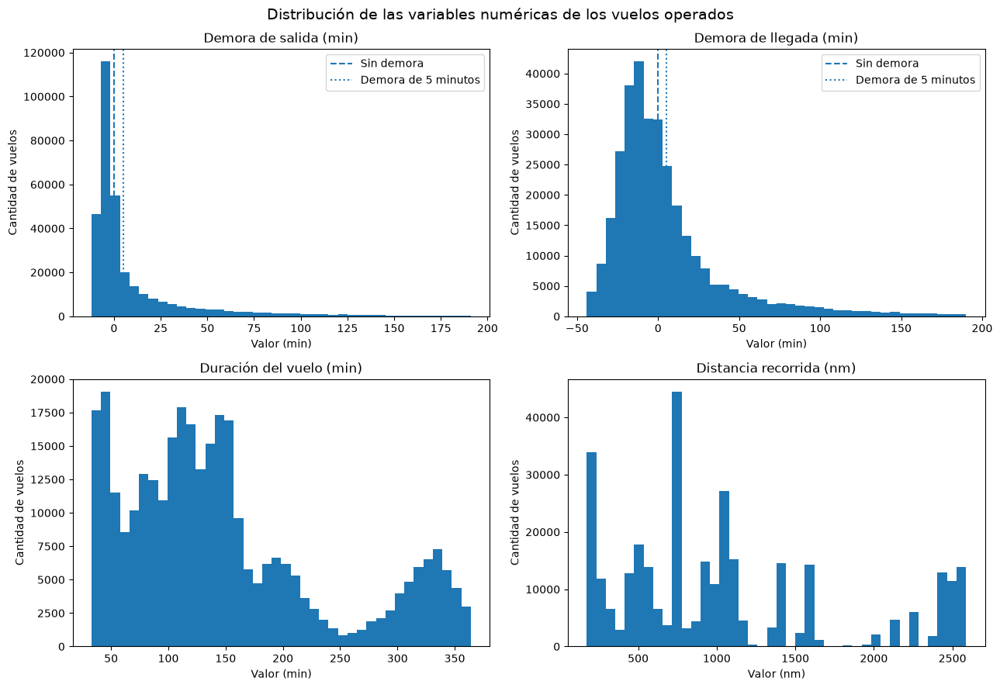

In [55]:
#Distribución de las variables numéricas

variables_grafico = [
    ("Demora de salida (min)", df_operados["demora_salida_min"], "min"),
    ("Demora de llegada (min)", df_operados["demora_arribo_min"], "min"),
    ("Duración del vuelo (min)", df_operados["tiempo_vuelo_min"], "min"),
    ("Distancia recorrida (nm)", df_operados["distancia_nm"], "nm"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (titulo, serie, unidad) in zip(axes, variables_grafico):

    valores = pd.to_numeric(
        serie, errors="coerce"
    ).dropna()

    limite_inferior = valores.quantile(0.01)
    limite_superior = valores.quantile(0.99)

    ax.hist(
        valores,
        bins=40,
        range=(limite_inferior, limite_superior)
    )

    ax.set_title(titulo)
    ax.set_xlabel(f"Valor ({unidad})")
    ax.set_ylabel("Cantidad de vuelos")

    if "Demora de" in titulo:
        ax.axvline(
            0,
            linestyle="--",
            label="Sin demora"
        )
        ax.axvline(
            5,
            linestyle=":",
            label="Demora de 5 minutos"
        )
        ax.legend()

plt.suptitle(
    "Distribución de las variables numéricas de los vuelos operados",
    fontsize=14
)
plt.tight_layout()
plt.show()

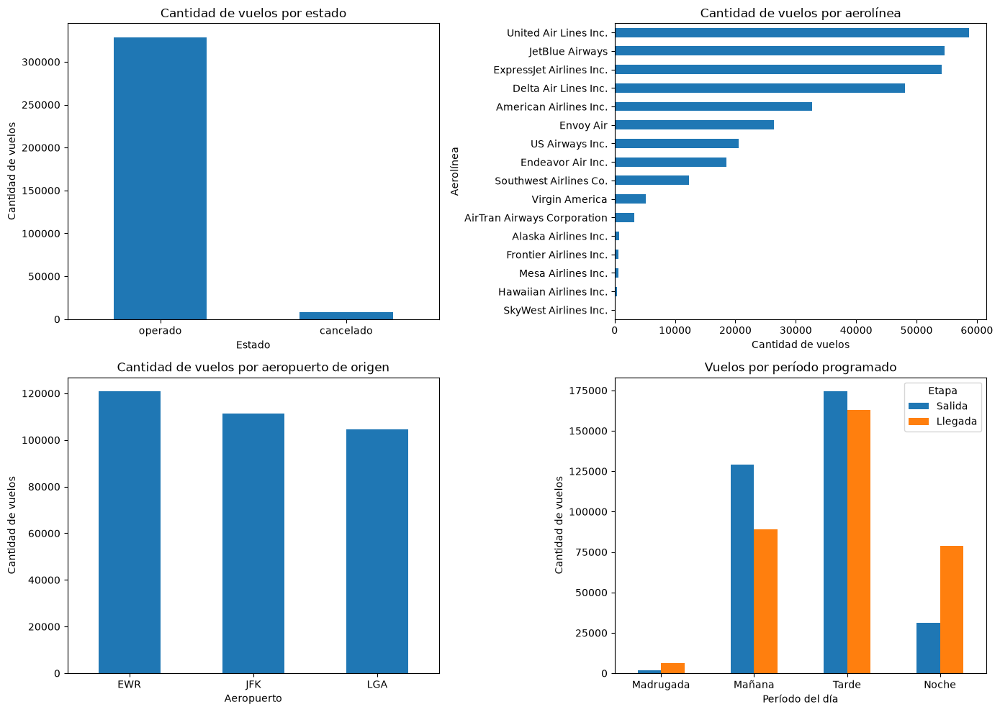

In [56]:
# Distribución general de variables categóricas

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Estado de los vuelos: incluye operados y cancelados.
conteo_estado = (
    df["estado_vuelo"]
    .value_counts()
    .reindex(["operado", "cancelado"], fill_value=0)
)

conteo_estado.plot(
    kind="bar",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Cantidad de vuelos por estado")
axes[0, 0].set_xlabel("Estado")
axes[0, 0].set_ylabel("Cantidad de vuelos")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Volumen de vuelos por aerolínea.
conteo_aerolinea = (
    df["nombre_aerolinea"]
    .value_counts()
    .sort_values()
)

conteo_aerolinea.plot(
    kind="barh",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Cantidad de vuelos por aerolínea")
axes[0, 1].set_xlabel("Cantidad de vuelos")
axes[0, 1].set_ylabel("Aerolínea")

# 3. Volumen de vuelos por aeropuerto de origen.
conteo_origen = (
    df["origen"]
    .value_counts()
    .sort_values(ascending=False)
)

conteo_origen.plot(
    kind="bar",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Cantidad de vuelos por aeropuerto de origen")
axes[1, 0].set_xlabel("Aeropuerto")
axes[1, 0].set_ylabel("Cantidad de vuelos")
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Comparar períodos programados de salida y llegada.
orden_periodos = [
    "Madrugada",
    "Mañana",
    "Tarde",
    "Noche"
]

conteo_periodos = pd.DataFrame({
    "Salida": df["periodo_salida_programado"].value_counts(),
    "Llegada": df["periodo_arribo_programado"].value_counts()
}).reindex(orden_periodos).fillna(0)

conteo_periodos.plot(
    kind="bar",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Vuelos por período programado")
axes[1, 1].set_xlabel("Período del día")
axes[1, 1].set_ylabel("Cantidad de vuelos")
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend(title="Etapa")

plt.tight_layout()
plt.show()

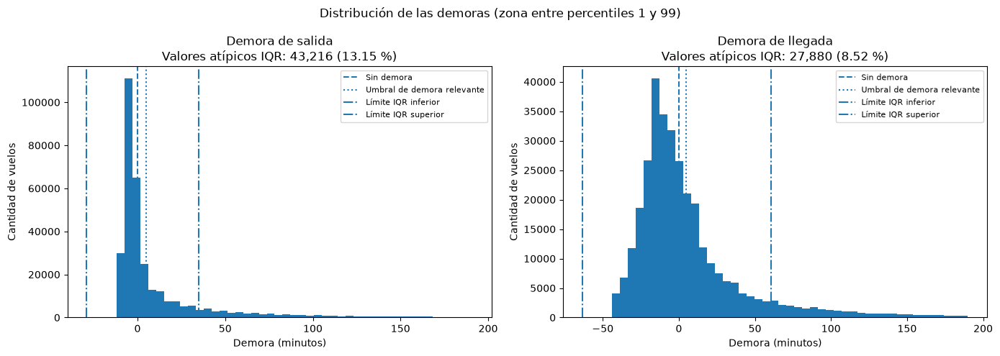

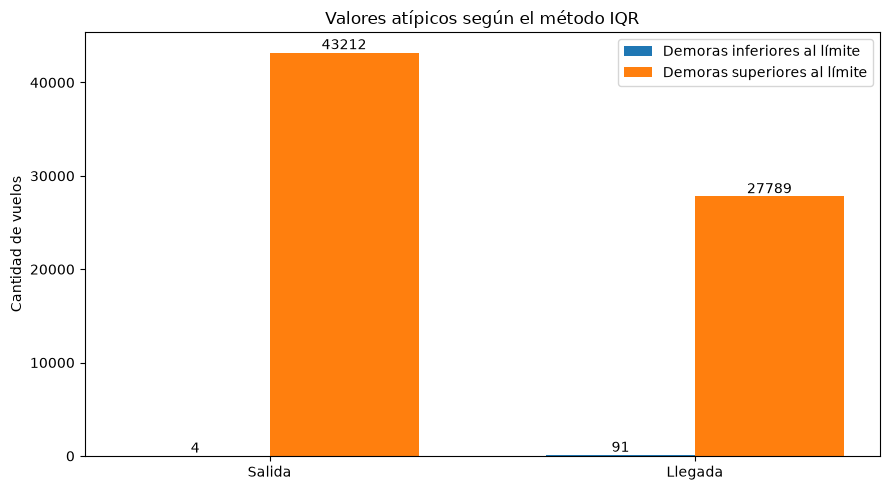

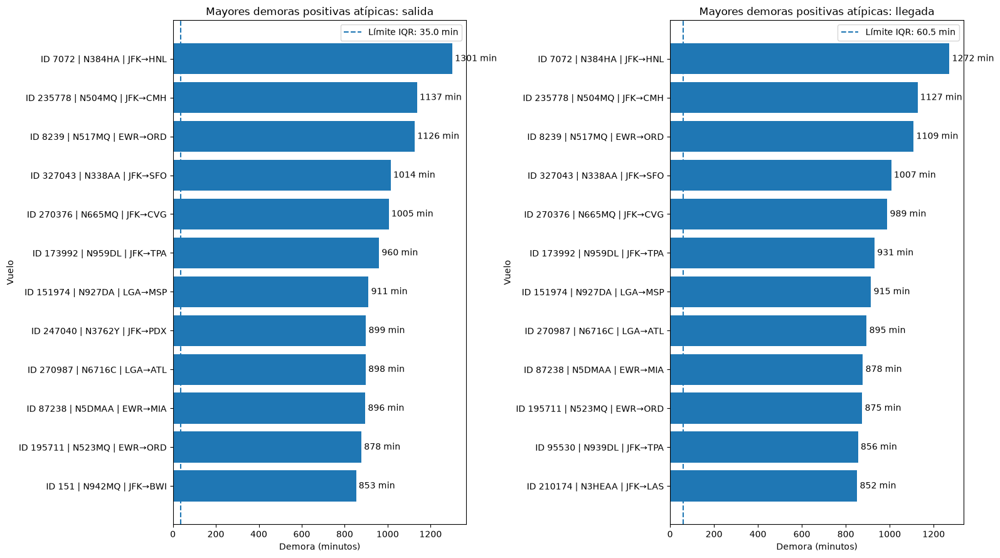

In [57]:
# Visualización de valores atípicos en las demoras

# 1. Considerar vuelos operados.
df_operados = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

variables = {
    "Salida": "demora_salida_min",
    "Llegada": "demora_arribo_min"
}

resultados_outliers = {}

# 2. Calcular los límites del IQR para cada variable.
for nombre, columna in variables.items():

    valores = pd.to_numeric(
        df_operados[columna],
        errors="coerce"
    ).dropna()

    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_inferior = valores < limite_inferior
    mascara_superior = valores > limite_superior

    resultados_outliers[nombre] = {
        "columna": columna,
        "valores": valores,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "inferiores": int(mascara_inferior.sum()),
        "superiores": int(mascara_superior.sum()),
        "total": int(
            mascara_inferior.sum() + mascara_superior.sum()
        ),
        "porcentaje": (
            (mascara_inferior.sum() + mascara_superior.sum())
            / len(valores) * 100
        )
    }


# ---------------------------------------------------------
# GRÁFICO 1. DISTRIBUCIÓN DE LAS DEMORAS
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (nombre, resultado) in zip(
    axes, resultados_outliers.items()
):
    valores = resultado["valores"]

    # Mostrar la zona central para que la distribución sea legible.
    p01 = valores.quantile(0.01)
    p99 = valores.quantile(0.99)

    valores_visibles = valores[
        valores.between(p01, p99)
    ]

    ax.hist(valores_visibles, bins=45)

    ax.axvline(
        0, linestyle="--",
        label="Sin demora"
    )

    ax.axvline(
        5, linestyle=":",
        label="Umbral de demora relevante"
    )

    ax.axvline(
        resultado["limite_inferior"],
        linestyle="-.",
        label="Límite IQR inferior"
    )

    ax.axvline(
        resultado["limite_superior"],
        linestyle="-.",
        label="Límite IQR superior"
    )

    ax.set_title(
        f"Demora de {nombre.lower()}\n"
        f"Valores atípicos IQR: "
        f"{resultado['total']:,} "
        f"({resultado['porcentaje']:.2f} %)"
    )

    ax.set_xlabel("Demora (minutos)")
    ax.set_ylabel("Cantidad de vuelos")
    ax.legend(fontsize=8)

fig.suptitle(
    "Distribución de las demoras (zona entre percentiles 1 y 99)"
)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# GRÁFICO 2. CANTIDAD DE OUTLIERS INFERIORES Y SUPERIORES
# ---------------------------------------------------------

nombres = list(resultados_outliers.keys())
cantidades_inferiores = [
    resultados_outliers[n]["inferiores"]
    for n in nombres
]
cantidades_superiores = [
    resultados_outliers[n]["superiores"]
    for n in nombres
]

posiciones = np.arange(len(nombres))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras_inferiores = ax.bar(
    posiciones - ancho / 2,
    cantidades_inferiores,
    ancho,
    label="Demoras inferiores al límite"
)

barras_superiores = ax.bar(
    posiciones + ancho / 2,
    cantidades_superiores,
    ancho,
    label="Demoras superiores al límite"
)

ax.bar_label(barras_inferiores, fmt="%.0f")
ax.bar_label(barras_superiores, fmt="%.0f")

ax.set_xticks(posiciones)
ax.set_xticklabels(nombres)
ax.set_ylabel("Cantidad de vuelos")
ax.set_title("Valores atípicos según el método IQR")
ax.legend()

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# GRÁFICO 3. VUELOS CON LAS DEMORAS POSITIVAS MÁS EXTREMAS
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

for ax, (nombre, resultado) in zip(
    axes, resultados_outliers.items()
):
    columna = resultado["columna"]
    limite = resultado["limite_superior"]

    # Seleccionar solo vuelos que superan el límite superior del IQR.
    valores = resultado["valores"]
    valores_extremos = valores[valores > limite]

    # Elegir los 12 retrasos positivos más altos.
    top = valores_extremos.nlargest(12)

    if top.empty:
        ax.set_title(f"Sin valores extremos: {nombre}")
        ax.axis("off")
        continue

    vuelos = df_operados.loc[top.index].copy()
    vuelos["_demora_grafico"] = top

    # Etiquetas con ID, matrícula y ruta para identificar cada vuelo.
    etiquetas = vuelos.apply(
        lambda fila: (
            f"ID {fila['id']} | "
            f"{fila['matricula_avion'] if pd.notna(fila['matricula_avion']) else 'Sin matrícula'}"
            f" | {fila['origen']}→{fila['destino']}"
        ),
        axis=1
    )

    vuelos["_etiqueta"] = etiquetas

    vuelos = vuelos.sort_values("_demora_grafico")

    ax.barh(
        vuelos["_etiqueta"],
        vuelos["_demora_grafico"]
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.0f min",
        padding=3
    )

    ax.axvline(
        limite,
        linestyle="--",
        label=f"Límite IQR: {limite:.1f} min"
    )

    ax.set_title(
        f"Mayores demoras positivas atípicas: {nombre.lower()}"
    )
    ax.set_xlabel("Demora (minutos)")
    ax.set_ylabel("Vuelo")
    ax.legend()

fig.tight_layout()
plt.show()

### 1. Análisis de matrículas de aviones

Objetivo general

Identificar aviones que presentan demoras recurrentes, analizar cómo varía su puntualidad y determinar si esos patrones se relacionan con el horario, el tipo de día, el período del año o las condiciones de operación.

El análisis buscará:

- Identificar aviones con demoras recurrentes y cuantificar su frecuencia.
- Comparar los niveles de puntualidad de salida y llegada.
- Reconocer matrículas que presentan una proporción elevada de demoras severas o críticas.
- Determinar si las demoras superiores a 60 minutos son recurrentes o corresponden a situaciones aisladas.
- Analizar si el comportamiento cambia según el horario, el tipo de día, el trimestre o el semestre.
- Investigar la relación entre la distancia recorrida y la puntualidad de los vuelos.
- Estudiar cómo se distribuyen las operaciones entre números de vuelo y aerolíneas.
- Examinar si las demoras de un vuelo se relacionan con las operaciones posteriores del mismo avión.
- Distinguir entre patrones asociados a matrículas individuales y patrones compartidos por numerosos aviones de una misma aerolínea.
- Reconocer casos que justifiquen una investigación más profunda, teniendo en cuenta la cantidad y calidad de los datos disponibles.

**Criterio general de interpretación:** los resultados permitirán identificar asociaciones y patrones de puntualidad, pero no demostrarán por sí solos las causas de las demoras. Las conclusiones deberán considerar la cantidad de vuelos de cada matrícula, los datos faltantes y las diferencias de operación entre aviones, rutas, horarios y aerolíneas.

##### 1.1.1. Datos generales de las matrículas

**Objetivo:** conocer la distribución general de las matrículas de los aviones y la cantidad de vuelos disponibles para cada una, antes de profundizar en su comportamiento.

Preguntas que vamos a investigar:

- ¿Cuántas matrículas diferentes aparecen en el conjunto de datos?
- ¿Cuántos vuelos realizó cada matrícula durante el período analizado?
- ¿Qué cantidad de vuelos no tiene una matrícula identificada?
- ¿Cómo se distribuye la cantidad de vuelos entre las distintas matrículas?
- ¿Cuántas matrículas tienen suficientes vuelos registrados para realizar comparaciones más confiables?

**Enfoque del análisis:** estableceremos una referencia inicial sobre la cantidad de matrículas y sus operaciones. Esta información será importante para interpretar los resultados posteriores, ya que no podemos comparar directamente un avión con cientos de vuelos con otro que aparece en muy pocas operaciones.

In [58]:
# ============================================================
# 1. Indicadores generales
# ============================================================

total_registros = len(df)

# Registros sin matrícula identificada
sin_matricula = df["matricula_avion"].isna().sum()
porcentaje_sin_matricula = sin_matricula / total_registros * 100

# Cantidad de matrículas diferentes registradas
matriculas_distintas = df["matricula_avion"].nunique()

# Seleccionamos los vuelos que fueron operados
df_operados = df.loc[df["estado_vuelo"].eq("operado")].copy()

total_operados = len(df_operados)

# Vuelos operados sin matrícula identificada
operados_sin_matricula = df_operados["matricula_avion"].isna().sum()

# Vuelos operados con matrícula identificada
operados_con_matricula = df_operados["matricula_avion"].notna().sum()

# ============================================================
# 2. Cantidad de vuelos realizados por cada matrícula
# ============================================================

vuelos_por_matricula = (
    df_operados
    .dropna(subset=["matricula_avion"])
    .groupby("matricula_avion")
    .size()
    .sort_values(ascending=False)
)

total_matriculas_operativas = vuelos_por_matricula.size

# Estadísticas de vuelos por matrícula
promedio_vuelos = vuelos_por_matricula.mean()
mediana_vuelos = vuelos_por_matricula.median()
minimo_vuelos = vuelos_por_matricula.min()
maximo_vuelos = vuelos_por_matricula.max()

# ============================================================
# 3. Cantidad de matrículas con diferentes niveles de actividad
# ============================================================

matriculas_30_o_mas = (vuelos_por_matricula >= 30).sum()
matriculas_100_o_mas = (vuelos_por_matricula >= 100).sum()

# Agrupamos las matrículas según la cantidad de vuelos
grupos_vuelos = pd.cut(
    vuelos_por_matricula,
    bins=[0, 9, 29, 99, np.inf],
    labels=[
        "1–9 vuelos",
        "10–29 vuelos",
        "30–99 vuelos",
        "100 o más vuelos"
    ]
)

matriculas_por_grupo = grupos_vuelos.value_counts(sort=False)

# ============================================================
# 4. Mostrar resultados generales
# ============================================================

print("DATOS GENERALES DEL CONJUNTO")
print("-" * 45)
print(f"Total de registros: {total_registros:,}")
print(f"Registros sin matrícula: {sin_matricula:,}")
print(f"Porcentaje sin matrícula: {porcentaje_sin_matricula:.2f}%")
print(f"Matrículas distintas registradas: {matriculas_distintas:,}")

print("\nVUELOS OPERADOS")
print("-" * 45)
print(f"Total de vuelos operados: {total_operados:,}")
print(f"Vuelos operados sin matrícula: {operados_sin_matricula:,}")
print(f"Vuelos operados con matrícula: {operados_con_matricula:,}")
print(f"Matrículas con vuelos operados: {total_matriculas_operativas:,}")

print("\nCANTIDAD DE VUELOS POR MATRÍCULA")
print("-" * 45)
print(f"Promedio de vuelos por matrícula: {promedio_vuelos:.2f}")
print(f"Mediana de vuelos por matrícula: {mediana_vuelos:.0f}")
print(f"Mínimo de vuelos por matrícula: {minimo_vuelos}")
print(f"Máximo de vuelos por matrícula: {maximo_vuelos}")

print("\nMATRÍCULAS SEGÚN CANTIDAD DE VUELOS")
print("-" * 45)
print(f"Matrículas con 30 vuelos o más: {matriculas_30_o_mas:,}")
print(f"Matrículas con 100 vuelos o más: {matriculas_100_o_mas:,}")

print("\nDistribución por grupo:")
print(matriculas_por_grupo.to_string())

DATOS GENERALES DEL CONJUNTO
---------------------------------------------
Total de registros: 336,776
Registros sin matrícula: 2,512
Porcentaje sin matrícula: 0.75%
Matrículas distintas registradas: 4,043

VUELOS OPERADOS
---------------------------------------------
Total de vuelos operados: 328,521
Vuelos operados sin matrícula: 0
Vuelos operados con matrícula: 328,521
Matrículas con vuelos operados: 4,037

CANTIDAD DE VUELOS POR MATRÍCULA
---------------------------------------------
Promedio de vuelos por matrícula: 81.38
Mediana de vuelos por matrícula: 53
Mínimo de vuelos por matrícula: 1
Máximo de vuelos por matrícula: 546

MATRÍCULAS SEGÚN CANTIDAD DE VUELOS
---------------------------------------------
Matrículas con 30 vuelos o más: 2,727
Matrículas con 100 vuelos o más: 1,210

Distribución por grupo:
1–9 vuelos           615
10–29 vuelos         695
30–99 vuelos        1517
100 o más vuelos    1210


DISTRIBUCIÓN DE VUELOS POR MATRÍCULA
Analizamos cómo se distribuye la cantidad de vuelos entre los aviones.


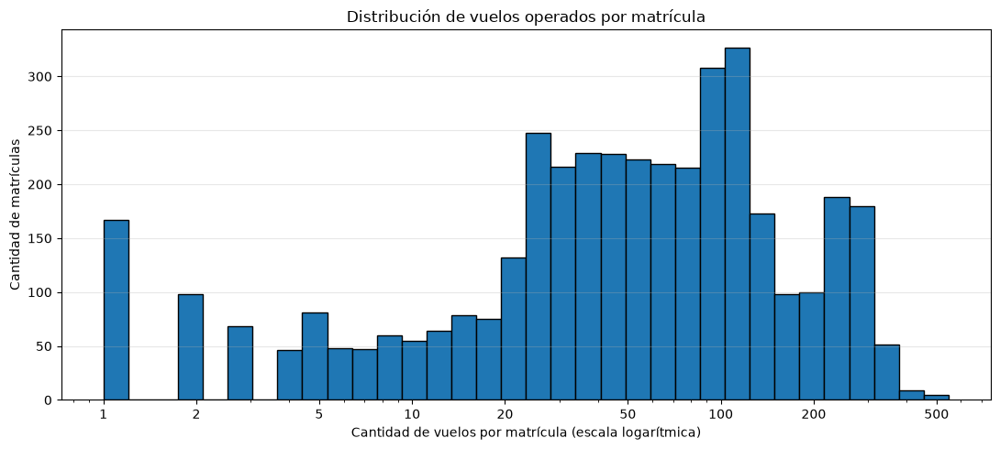

In [59]:
# ============================================================
# GRÁFICO 1: Distribución de vuelos por matrícula
# ============================================================
print("DISTRIBUCIÓN DE VUELOS POR MATRÍCULA")
print("Analizamos cómo se distribuye la cantidad de vuelos entre los aviones.")


limite_maximo = int(vuelos_por_matricula.max())

# Intervalos crecientes para visualizar mejor valores muy diferentes
intervalos = np.geomspace(1, limite_maximo + 1, 35)

plt.figure(figsize=(11, 5))

plt.hist(
    vuelos_por_matricula,
    bins=intervalos,
    edgecolor="black"
)

plt.xscale("log")
plt.xlabel("Cantidad de vuelos por matrícula (escala logarítmica)")
plt.ylabel("Cantidad de matrículas")
plt.title("Distribución de vuelos operados por matrícula")

ticks = [
    valor for valor in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
    if valor <= limite_maximo
]

plt.xticks(ticks, ticks)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

MATRÍCULAS SEGÚN NIVEL DE ACTIVIDAD
Agrupamos los aviones según la cantidad de vuelos para conocer cuántos registros tenemos de cada uno.


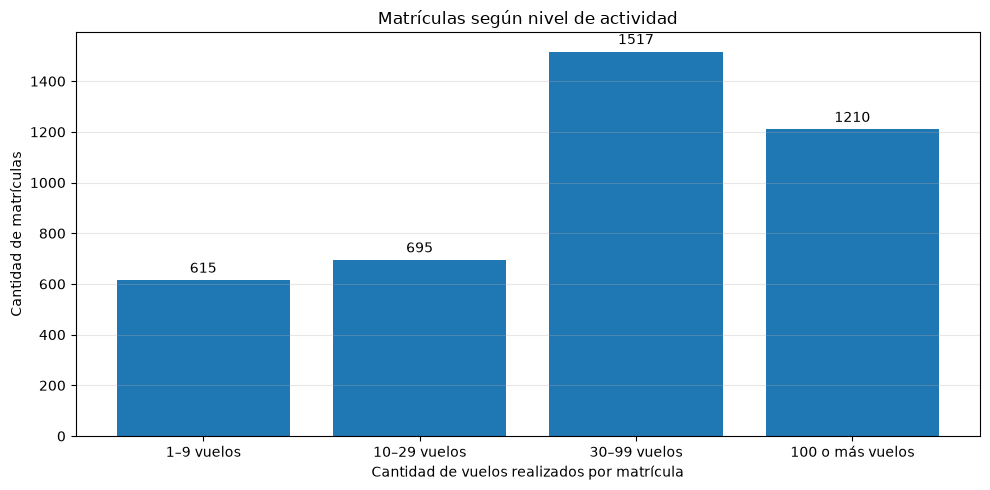

In [60]:
# ============================================================
# GRÁFICO 2: Matrículas según cantidad de vuelos
# ============================================================

print("MATRÍCULAS SEGÚN NIVEL DE ACTIVIDAD")
print("Agrupamos los aviones según la cantidad de vuelos para conocer cuántos registros tenemos de cada uno.")

# Agrupamos las matrículas según la cantidad de vuelos
grupos_vuelos = pd.cut(
    vuelos_por_matricula,
    bins=[0, 9, 29, 99, np.inf],
    labels=[
        "1–9 vuelos",
        "10–29 vuelos",
        "30–99 vuelos",
        "100 o más vuelos"
    ]
)

# Contamos cuántas matrículas hay en cada grupo
matriculas_por_grupo = grupos_vuelos.value_counts(sort=False)

# Generamos el gráfico
plt.figure(figsize=(10, 5))

barras = plt.bar(
    matriculas_por_grupo.index.astype(str),
    matriculas_por_grupo.values
)

plt.xlabel("Cantidad de vuelos realizados por matrícula")
plt.ylabel("Cantidad de matrículas")
plt.title("Matrículas según nivel de actividad")

plt.bar_label(barras, fmt="%.0f", padding=3)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### 1.1.2. Demoras recurrentes y niveles de puntualidad


**Objetivo:** identificar qué aviones presentan demoras de forma reiterada y distinguir los casos aislados de los patrones que se repiten.

Tomaremos como criterio inicial de revisión las matrículas en las que **más del 30 % de los vuelos evaluables presenta demoras severas o críticas, tanto en la salida como en la llegada**. También analizaremos las demoras superiores a 60 minutos para determinar si representan un patrón recurrente o casos excepcionales.

Preguntas que vamos a investigar:

- ¿Hay aviones que se demoran repetidamente?
- ¿Qué porcentaje de los vuelos de cada matrícula llega tarde?
- ¿Cuántas matrículas presentan cada nivel de puntualidad, tanto en salida como en llegada?
- ¿Qué niveles de puntualidad predominan en cada avión?
- ¿Hay matrículas con un comportamiento claramente diferente al resto?
- ¿Qué aviones acumulan vuelos con demoras superiores a una hora en la salida o en la llegada?
- ¿Existen matrículas que registran demoras superiores a una hora tanto en salida como en llegada dentro de un mismo vuelo?

La clasificación se basará en los niveles de puntualidad que ya están definidos en el conjunto de datos:

- `adelantado`
- `a tiempo`
- `aceptable`
- `moderado`
- `severo`
- `critico`
- `desconocido`, que se analizará por separado porque representa información faltante.

**Enfoque del análisis:** no nos limitaremos a ordenar las matrículas por demora promedio. También observaremos la frecuencia de los vuelos demorados, el porcentaje que representan y la cantidad de vuelos disponibles para cada avión. Así evitaremos considerar problemático a un avión por un único vuelo excepcional.

El umbral del 30 % funcionará como un criterio inicial para seleccionar casos que merecen un análisis más profundo, no como una prueba definitiva de que un avión presenta problemas. Para las demoras superiores a 60 minutos distinguiremos entre los casos de salida, los de llegada y aquellos en los que ambas demoras se producen en el mismo vuelo.

DEMORAS RECURRENTES Y NIVELES DE PUNTUALIDAD
Analizamos la frecuencia y la gravedad de las demoras por matrícula.

RESUMEN GENERAL
---------------------------------------------
Vuelos operados: 328,521
Vuelos operados sin matrícula: 0
Vuelos operados con matrícula identificada: 328,521
Matrículas analizadas: 4,037
Matrículas con al menos 30 salidas y llegadas evaluables: 2,724

DEMORAS SEVERAS O CRÍTICAS
---------------------------------------------
Matrículas con más del 30 % en ambas etapas: 530
De ellas, con al menos 30 salidas y llegadas evaluables: 230

DEMORAS SUPERIORES A 60 MINUTOS
---------------------------------------------
Matrículas con al menos un vuelo con demora >60 min en salida: 3,360
Matrículas con al menos un vuelo con demora >60 min en llegada: 3,371
Matrículas con demoras >60 min en ambas etapas, aunque sean vuelos distintos: 3,299
Matrículas con al menos un mismo vuelo con demora >60 min en ambas etapas: 3,272

MATRÍCULAS A REVISAR CON MAYOR BASE DE DATOS SEVERO 

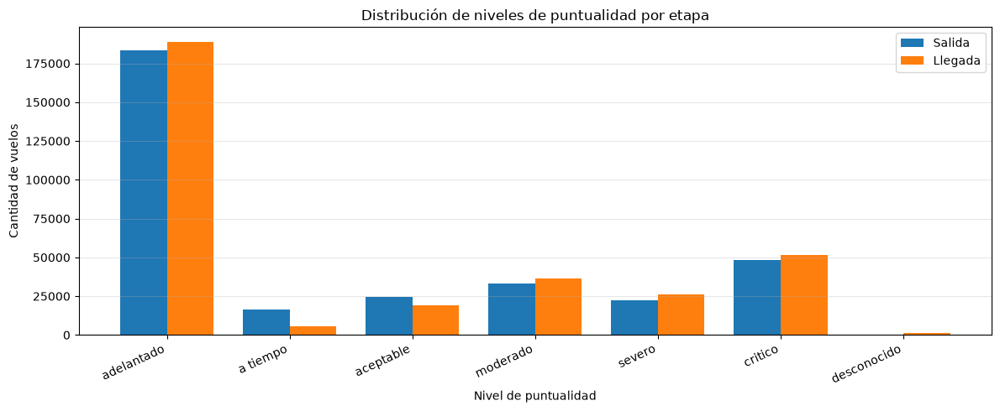


GRÁFICO 2. NIVEL PREDOMINANTE POR MATRÍCULA
Contamos cuántas matrículas tienen cada nivel como el más frecuente.
Los niveles desconocidos no se consideran para definir el predominante.


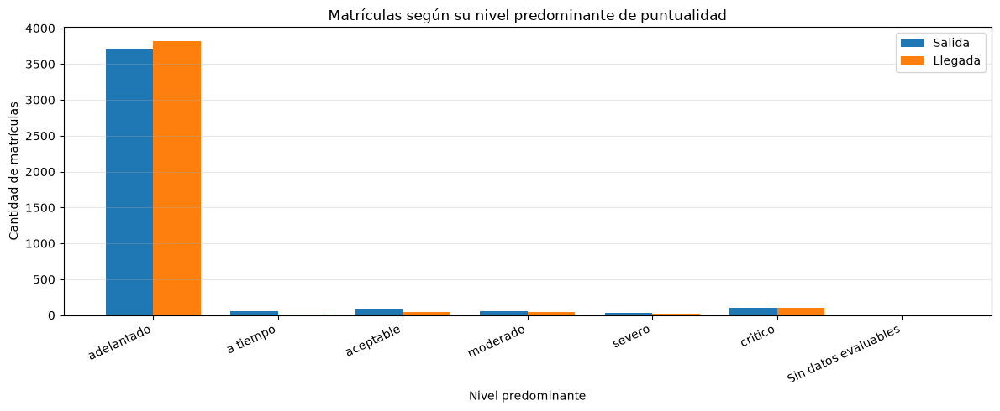


GRÁFICO 3. COMPARACIÓN ENTRE SALIDA Y LLEGADA
Cada punto representa una matrícula con al menos 30 salidas y llegadas evaluables.
Las líneas marcan el umbral de revisión del 30 %.


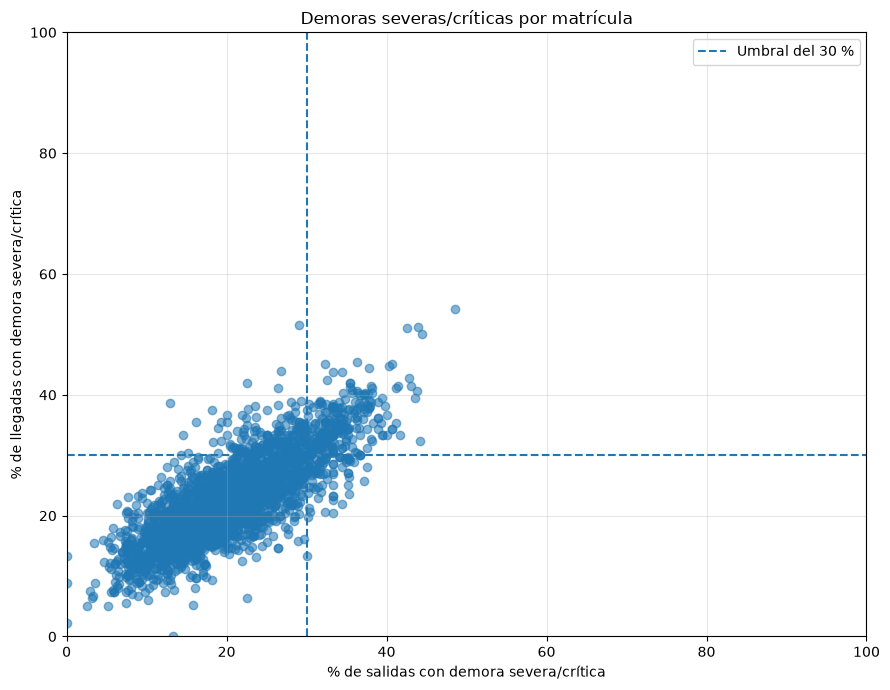


GRÁFICO 4. LLEGADAS CON DEMORAS SEVERAS O CRÍTICAS
Mostramos las 15 matrículas con mayor porcentaje de llegadas severas o críticas, con al menos 30 llegadas evaluables.
El porcentaje se calcula sobre las llegadas evaluables de cada matrícula.


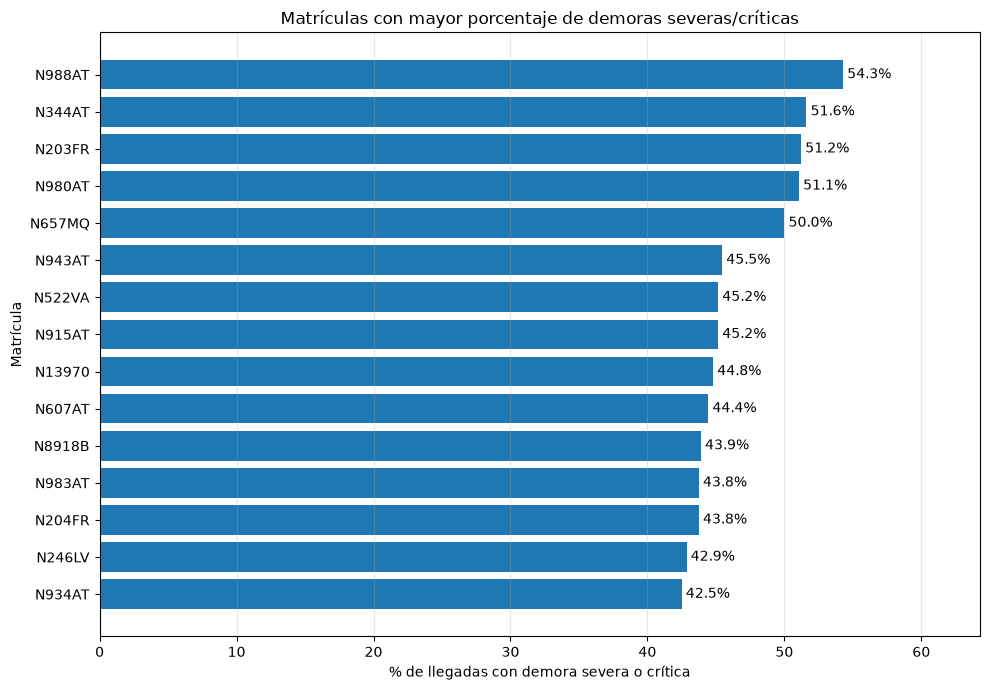


GRÁFICO 5. DEMORAS SUPERIORES A 60 MINUTOS
Comparamos la cantidad de vuelos con demoras >60 minutos en salida y llegada.
Cada recuento corresponde a vuelos, no solo a matrículas con algún caso.


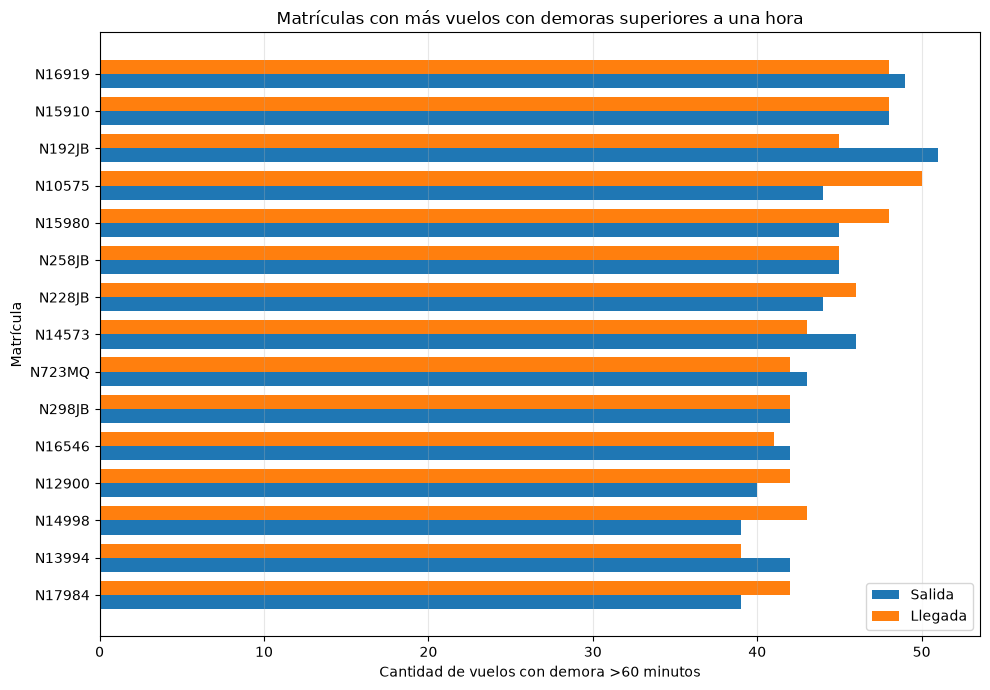

In [61]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("DEMORAS RECURRENTES Y NIVELES DE PUNTUALIDAD")
print("Analizamos la frecuencia y la gravedad de las demoras por matrícula.")

# Trabajamos únicamente con vuelos operados
operados = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Registros operados sin matrícula identificada
operados_sin_matricula = operados["matricula_avion"].isna().sum()

# Excluimos matrículas faltantes o vacías
base = operados.loc[
    operados["matricula_avion"].notna()
].copy()

base = base.loc[
    base["matricula_avion"].astype("string").str.strip().ne("")
].copy()

# Niveles ya definidos en el DataFrame
niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

niveles_conocidos = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# Indicadores auxiliares por vuelo
base["_salida_tarde"] = (
    base["demora_salida_min"].gt(0).fillna(False)
)

base["_arribo_tarde"] = (
    base["demora_arribo_min"].gt(0).fillna(False)
)

base["_salida_severo_critico"] = (
    base["nivel_puntualidad_salida"].isin(["severo", "critico"])
)

base["_arribo_severo_critico"] = (
    base["nivel_puntualidad_arribo"].isin(["severo", "critico"])
)

base["_salida_mas60"] = (
    base["demora_salida_min"].gt(60).fillna(False)
)

base["_arribo_mas60"] = (
    base["demora_arribo_min"].gt(60).fillna(False)
)

# Ambas demoras superiores a 60 minutos en el mismo vuelo
base["_ambas_mas60_mismo_vuelo"] = (
    base["_salida_mas60"] & base["_arribo_mas60"]
)


# ============================================================
# 2. RESUMEN DE PUNTUALIDAD POR MATRÍCULA
# ============================================================

resumen_matriculas = (
    base.groupby("matricula_avion")
    .agg(
        vuelos_operados=("matricula_avion", "size"),

        salidas_evaluables=("demora_salida_min", "count"),
        arribos_evaluables=("demora_arribo_min", "count"),

        salidas_tarde=("_salida_tarde", "sum"),
        arribos_tarde=("_arribo_tarde", "sum"),

        salidas_severo_critico=("_salida_severo_critico", "sum"),
        arribos_severo_critico=("_arribo_severo_critico", "sum"),

        vuelos_mas60_salida=("_salida_mas60", "sum"),
        vuelos_mas60_arribo=("_arribo_mas60", "sum"),
        vuelos_mas60_ambas=("_ambas_mas60_mismo_vuelo", "sum")
    )
)

# Porcentaje de vuelos que salen o llegan tarde
resumen_matriculas["pct_salidas_tarde"] = (
    100 * resumen_matriculas["salidas_tarde"]
    / resumen_matriculas["salidas_evaluables"].replace(0, np.nan)
)

resumen_matriculas["pct_arribos_tarde"] = (
    100 * resumen_matriculas["arribos_tarde"]
    / resumen_matriculas["arribos_evaluables"].replace(0, np.nan)
)

# Porcentaje de demoras severas o críticas
resumen_matriculas["pct_severo_critico_salida"] = (
    100 * resumen_matriculas["salidas_severo_critico"]
    / resumen_matriculas["salidas_evaluables"].replace(0, np.nan)
)

resumen_matriculas["pct_severo_critico_arribo"] = (
    100 * resumen_matriculas["arribos_severo_critico"]
    / resumen_matriculas["arribos_evaluables"].replace(0, np.nan)
)


# ============================================================
# 3. NIVEL DE PUNTUALIDAD PREDOMINANTE POR MATRÍCULA
# ============================================================

def nivel_predominante(serie):
    # Excluimos "desconocido" al buscar el nivel predominante
    valores = serie.loc[
        serie.notna() & serie.ne("desconocido")
    ]

    if valores.empty:
        return "Sin datos evaluables"

    modas = valores.mode()

    if modas.empty:
        return "Sin datos evaluables"

    # Si hay empate, mode() devuelve los niveles empatados
    # y tomamos el primero según el orden de los valores.
    return modas.iloc[0]


predominantes = (
    base.groupby("matricula_avion")
    .agg(
        nivel_predominante_salida=(
            "nivel_puntualidad_salida",
            nivel_predominante
        ),
        nivel_predominante_arribo=(
            "nivel_puntualidad_arribo",
            nivel_predominante
        )
    )
)

resumen_matriculas = resumen_matriculas.join(predominantes)


# ============================================================
# 4. CRITERIOS DE REVISIÓN
# ============================================================

# Criterio inicial: más del 30 % de demoras severas/críticas
# tanto en salida como en llegada.
criterio_30 = (
    resumen_matriculas["pct_severo_critico_salida"].gt(30)
    & resumen_matriculas["pct_severo_critico_arribo"].gt(30)
)

matriculas_criterio_30 = resumen_matriculas.loc[criterio_30].copy()

# Para comparaciones más sólidas, exigimos al menos
# 30 salidas y 30 llegadas evaluables por matrícula.
MIN_VUELOS = 30

comparables = resumen_matriculas.loc[
    (resumen_matriculas["salidas_evaluables"] >= MIN_VUELOS)
    & (resumen_matriculas["arribos_evaluables"] >= MIN_VUELOS)
].copy()

criterio_30_base = (
    comparables["pct_severo_critico_salida"].gt(30)
    & comparables["pct_severo_critico_arribo"].gt(30)
)

matriculas_criterio_30_base = comparables.loc[criterio_30_base].copy()


# ============================================================
# 5. RESUMEN GENERAL
# ============================================================

print("\nRESUMEN GENERAL")
print("-" * 45)
print(f"Vuelos operados: {len(operados):,}")
print(f"Vuelos operados sin matrícula: {operados_sin_matricula:,}")
print(f"Vuelos operados con matrícula identificada: {len(base):,}")
print(f"Matrículas analizadas: {len(resumen_matriculas):,}")
print(f"Matrículas con al menos {MIN_VUELOS} salidas y llegadas evaluables: "
    f"{len(comparables):,}")

print("\nDEMORAS SEVERAS O CRÍTICAS")
print("-" * 45)
print(f"Matrículas con más del 30 % en ambas etapas: "
    f"{len(matriculas_criterio_30):,}")
print(f"De ellas, con al menos {MIN_VUELOS} salidas y llegadas evaluables: "
    f"{len(matriculas_criterio_30_base):,}")

print("\nDEMORAS SUPERIORES A 60 MINUTOS")
print("-" * 45)
print(
    "Matrículas con al menos un vuelo con demora >60 min en salida: "
    f"{(resumen_matriculas['vuelos_mas60_salida'] > 0).sum():,}"
)
print(
    "Matrículas con al menos un vuelo con demora >60 min en llegada: "
    f"{(resumen_matriculas['vuelos_mas60_arribo'] > 0).sum():,}"
)
print(
    "Matrículas con demoras >60 min en ambas etapas, aunque sean vuelos distintos: "
    f"{((resumen_matriculas['vuelos_mas60_salida'] > 0) & (resumen_matriculas['vuelos_mas60_arribo'] > 0)).sum():,}"
)
print(
    "Matrículas con al menos un mismo vuelo con demora >60 min en ambas etapas: "
    f"{(resumen_matriculas['vuelos_mas60_ambas'] > 0).sum():,}"
)

if not matriculas_criterio_30_base.empty:
    candidatas_ordenadas = matriculas_criterio_30_base.assign(
        promedio_pct_severo_critico=(
            matriculas_criterio_30_base["pct_severo_critico_salida"]
            + matriculas_criterio_30_base["pct_severo_critico_arribo"]
        ) / 2
    ).sort_values("promedio_pct_severo_critico", ascending=False)

    print("\nMATRÍCULAS A REVISAR CON MAYOR BASE DE DATOS SEVERO Y CRÍTICO")
    print("-" * 45)

    for matricula, fila in candidatas_ordenadas.head(10).iterrows():
        print(
            f"{matricula}: "
            f"salida {fila['pct_severo_critico_salida']:.1f} %, "
            f"llegada {fila['pct_severo_critico_arribo']:.1f} %"
        )


# ============================================================
# GRÁFICO 1. DISTRIBUCIÓN DE NIVELES DE PUNTUALIDAD
# ============================================================

print("\nGRÁFICO 1. DISTRIBUCIÓN DE NIVELES DE PUNTUALIDAD")
print("Comparamos cuántos vuelos tienen cada nivel en salida y llegada.")
print("'Desconocido' se muestra por separado porque faltan datos de demora.")

conteo_salida = (
    base["nivel_puntualidad_salida"]
    .value_counts()
    .reindex(niveles, fill_value=0)
)

conteo_arribo = (
    base["nivel_puntualidad_arribo"]
    .value_counts()
    .reindex(niveles, fill_value=0)
)

x = np.arange(len(niveles))
ancho = 0.38

plt.figure(figsize=(12, 5))

plt.bar(
    x - ancho / 2,
    conteo_salida.values,
    ancho,
    label="Salida"
)

plt.bar(
    x + ancho / 2,
    conteo_arribo.values,
    ancho,
    label="Llegada"
)

plt.xticks(x, niveles, rotation=25, ha="right")
plt.xlabel("Nivel de puntualidad")
plt.ylabel("Cantidad de vuelos")
plt.title("Distribución de niveles de puntualidad por etapa")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 2. NIVEL PREDOMINANTE POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 2. NIVEL PREDOMINANTE POR MATRÍCULA")
print("Contamos cuántas matrículas tienen cada nivel como el más frecuente.")
print("Los niveles desconocidos no se consideran para definir el predominante.")

niveles_predominantes = niveles_conocidos + ["Sin datos evaluables"]

conteo_pred_salida = (
    resumen_matriculas["nivel_predominante_salida"]
    .value_counts()
    .reindex(niveles_predominantes, fill_value=0)
)

conteo_pred_arribo = (
    resumen_matriculas["nivel_predominante_arribo"]
    .value_counts()
    .reindex(niveles_predominantes, fill_value=0)
)

x = np.arange(len(niveles_predominantes))

plt.figure(figsize=(12, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    conteo_pred_salida.values,
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    conteo_pred_arribo.values,
    ancho,
    label="Llegada"
)

plt.xticks(x, niveles_predominantes, rotation=25, ha="right")
plt.xlabel("Nivel predominante")
plt.ylabel("Cantidad de matrículas")
plt.title("Matrículas según su nivel predominante de puntualidad")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. PORCENTAJE DE DEMORAS SEVERAS/CRÍTICAS
# ============================================================

print("\nGRÁFICO 3. COMPARACIÓN ENTRE SALIDA Y LLEGADA")
print(
    f"Cada punto representa una matrícula con al menos "
    f"{MIN_VUELOS} salidas y llegadas evaluables."
)
print("Las líneas marcan el umbral de revisión del 30 %.")

plt.figure(figsize=(9, 7))

plt.scatter(
    comparables["pct_severo_critico_salida"],
    comparables["pct_severo_critico_arribo"],
    alpha=0.55
)

plt.axvline(30, linestyle="--", label="Umbral del 30 %")
plt.axhline(30, linestyle="--")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel("% de salidas con demora severa/crítica")
plt.ylabel("% de llegadas con demora severa/crítica")
plt.title("Demoras severas/críticas por matrícula")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 4. MATRÍCULAS CON MAYOR PORCENTAJE DE LLEGADAS CON DEMORA SEVERA O CRÍTICA
# ============================================================

print("\nGRÁFICO 4. LLEGADAS CON DEMORAS SEVERAS O CRÍTICAS")
print(
    f"Mostramos las 15 matrículas con mayor porcentaje de llegadas "
    f"severas o críticas, con al menos {MIN_VUELOS} llegadas evaluables."
)
print("El porcentaje se calcula sobre las llegadas evaluables de cada matrícula.")

# Seleccionamos matrículas con suficientes llegadas evaluables
matriculas_arribo_comparables = resumen_matriculas.loc[
    resumen_matriculas["arribos_evaluables"] >= MIN_VUELOS
].copy()

# Seleccionamos las 15 matrículas con mayor porcentaje
top_arribos_severos = (
    matriculas_arribo_comparables
    .sort_values(
        "pct_severo_critico_arribo",
        ascending=False
    )
    .head(15)
    .sort_values(
        "pct_severo_critico_arribo",
        ascending=True
    )
)

# Graficamos los resultados
if not top_arribos_severos.empty:

    plt.figure(figsize=(10, 7))

    barras = plt.barh(
        top_arribos_severos.index.astype(str),
        top_arribos_severos["pct_severo_critico_arribo"]
    )

    plt.bar_label(barras, fmt="%.1f%%", padding=3)

    plt.xlabel("% de llegadas con demora severa o crítica")
    plt.ylabel("Matrícula")
    plt.title("Matrículas con mayor porcentaje de demoras severas/críticas")

    plt.xlim(
        0,
        min(
            110,
            top_arribos_severos["pct_severo_critico_arribo"].max() + 10
        )
    )

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No hay matrículas con suficientes llegadas evaluables.")


# ============================================================
# GRÁFICO 5. DEMORAS SUPERIORES A 60 MINUTOS
# ============================================================

print("\nGRÁFICO 5. DEMORAS SUPERIORES A 60 MINUTOS")
print("Comparamos la cantidad de vuelos con demoras >60 minutos en salida y llegada.")
print("Cada recuento corresponde a vuelos, no solo a matrículas con algún caso.")

resumen_matriculas["_total_vuelos_mas60_etapas"] = (
    resumen_matriculas["vuelos_mas60_salida"]
    + resumen_matriculas["vuelos_mas60_arribo"]
)

top_mas60 = (
    resumen_matriculas.loc[
        resumen_matriculas["_total_vuelos_mas60_etapas"] > 0
    ]
    .sort_values("_total_vuelos_mas60_etapas", ascending=False)
    .head(15)
    .sort_values("_total_vuelos_mas60_etapas", ascending=True)
)

if not top_mas60.empty:
    y = np.arange(len(top_mas60))
    alto = 0.38

    plt.figure(figsize=(10, 7))

    plt.barh(
        y - alto / 2,
        top_mas60["vuelos_mas60_salida"],
        alto,
        label="Salida"
    )

    plt.barh(
        y + alto / 2,
        top_mas60["vuelos_mas60_arribo"],
        alto,
        label="Llegada"
    )

    plt.yticks(y, top_mas60.index.astype(str))
    plt.xlabel("Cantidad de vuelos con demora >60 minutos")
    plt.ylabel("Matrícula")
    plt.title("Matrículas con más vuelos con demoras superiores a una hora")
    plt.legend()
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron demoras superiores a 60 minutos en los vuelos evaluados.")

##### 1.1.3. Relación entre puntualidad de salida y llegada

**Objetivo:** analizar si las demoras que se producen antes de la salida se reflejan en la llegada.

Preguntas que vamos a investigar:

- ¿Los aviones que salen con mayor demora tienden también a llegar tarde?
- ¿Hay matrículas que consiguen recuperar tiempo durante el vuelo?
- ¿Existen aviones que salen puntualmente, pero presentan demoras frecuentes a la llegada?
- ¿La relación entre salida y llegada es similar para todas las matrículas?
- ¿Qué diferencia existe entre la demora de salida y la demora de llegada de un mismo vuelo?

**Enfoque del análisis:** compararemos las demoras de salida y llegada de los vuelos y estudiaremos sus patrones por matrícula. No vamos a asumir que una demora de salida siempre provoca una demora de llegada, porque también pueden influir el tiempo de vuelo, la programación y otras condiciones operativas.

RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
Analizamos si las demoras de salida se mantienen, disminuyen o aumentan al llegar.

RESUMEN GENERAL
---------------------------------------------
Vuelos con ambas demoras disponibles: 327,346
Vuelos en los que disminuye la demora: 221,565 (67.7 %)
Vuelos sin cambio en la demora: 6,982 (2.1 %)
Vuelos en los que aumenta la demora: 98,799 (30.2 %)
Correlación de Pearson entre ambas demoras: 0.915
Correlación de Spearman entre ambas demoras: 0.626

GRÁFICO 1. RELACIÓN ENTRE DEMORA DE SALIDA Y LLEGADA
Cada punto representa un vuelo. La diagonal indica dónde ambas demoras son iguales.
Para facilitar la lectura, los ejes muestran el rango central de los datos.


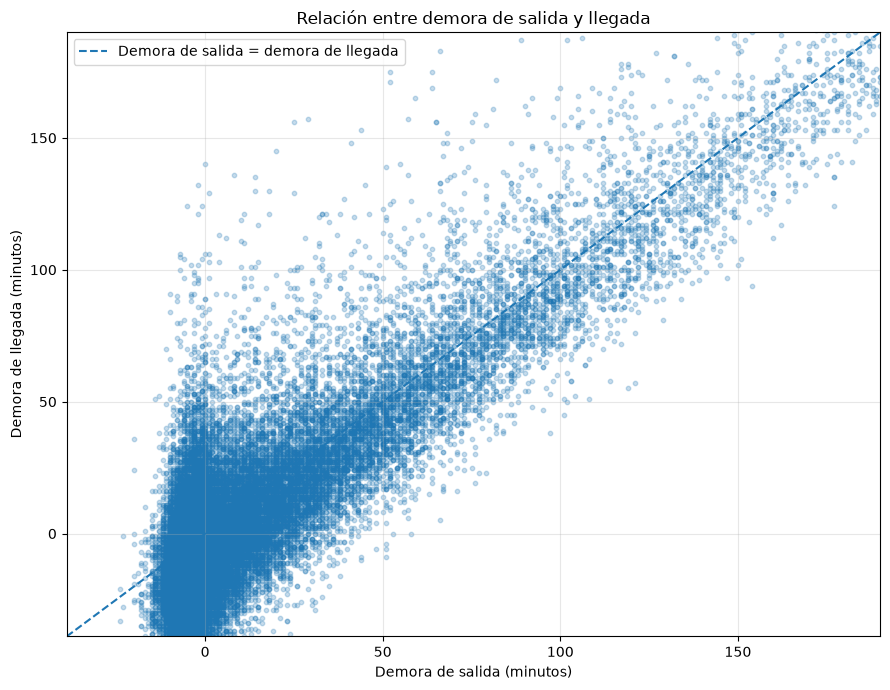


GRÁFICO 2. CAMBIO DE LA DEMORA DURANTE EL VUELO
Calculamos demora de llegada menos demora de salida.
Valores negativos indican que disminuye la demora; positivos, que aumenta.


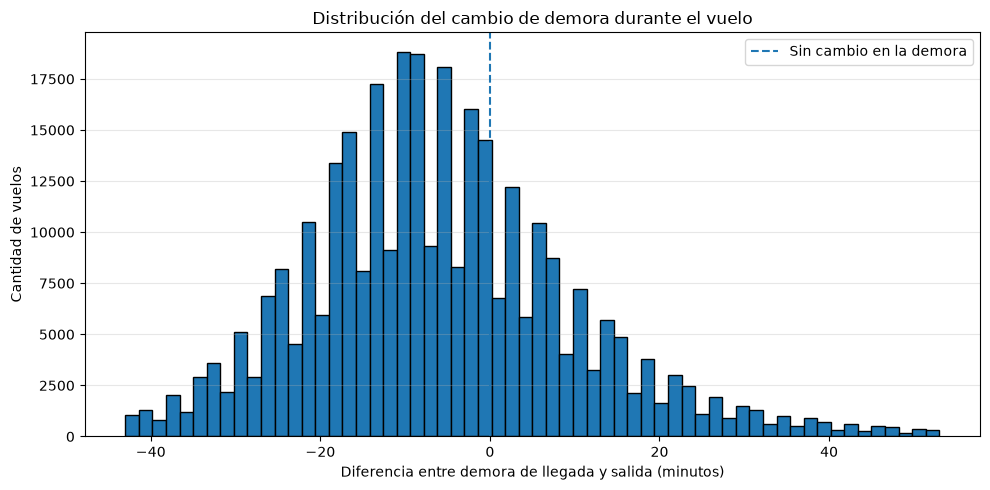


GRÁFICO 3. DEMORA MEDIA POR MATRÍCULA
Comparamos la demora media de salida y llegada de cada avión.
Se incluyen matrículas con al menos 30 vuelos con ambas demoras disponibles.


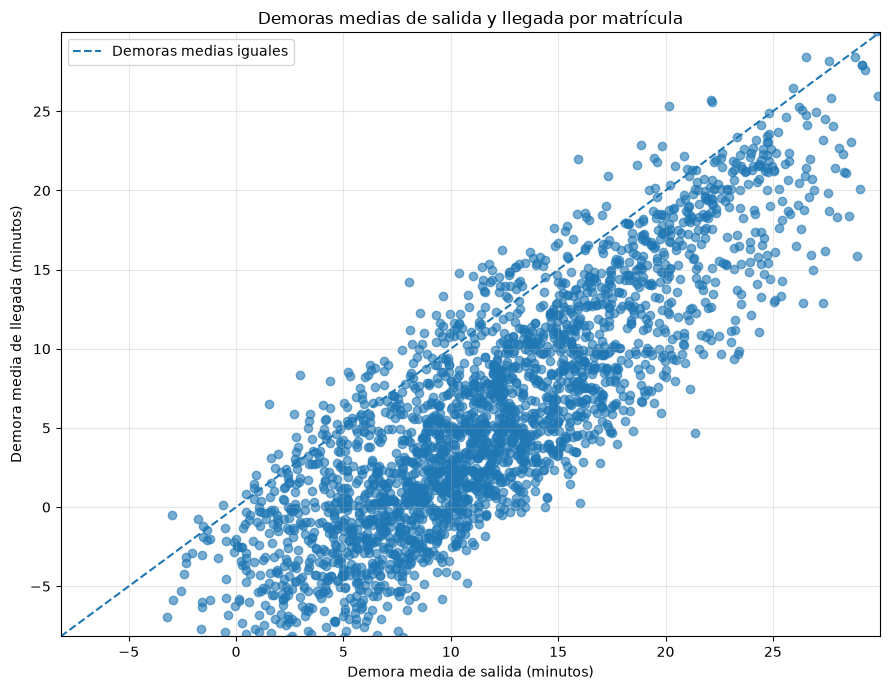


GRÁFICO 4. SALIDAS PUNTUALES CON LLEGADAS SEVERAS/CRÍTICAS
Buscamos aviones que salen a horario o adelantados, pero llegan con demora severa o crítica.
Se exige un mínimo de 10 vuelos comparables con salida puntual por matrícula.


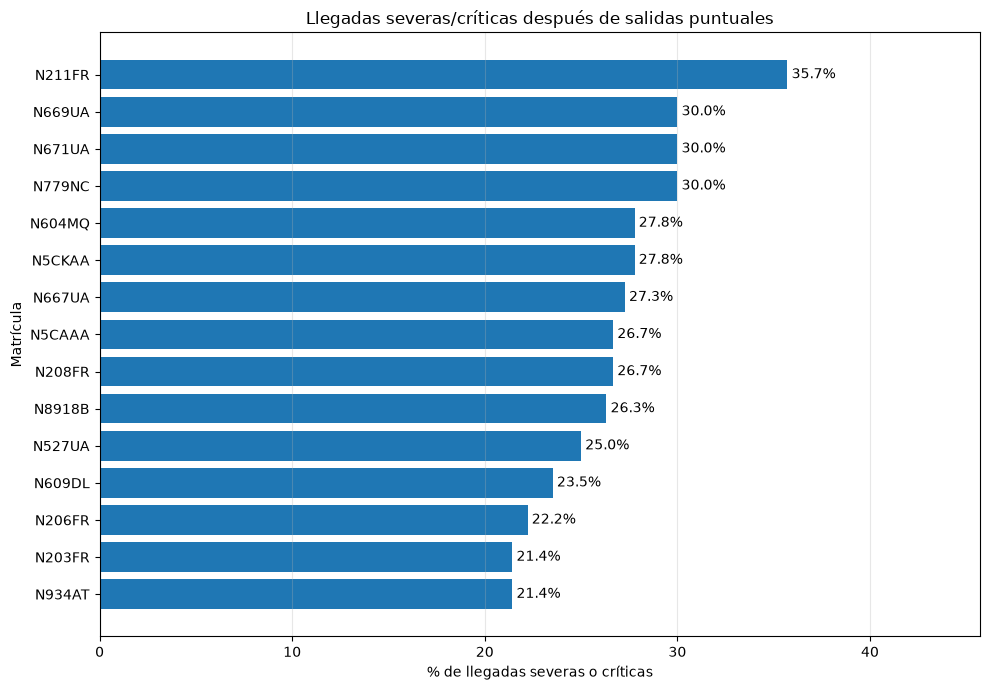


GRÁFICO 5. RELACIÓN ENTRE DEMORAS POR MATRÍCULA
Observamos cómo varía la correlación entre salida y llegada de un avión a otro.
Solo incluimos matrículas con al menos 30 vuelos comparables y variación en ambas demoras.


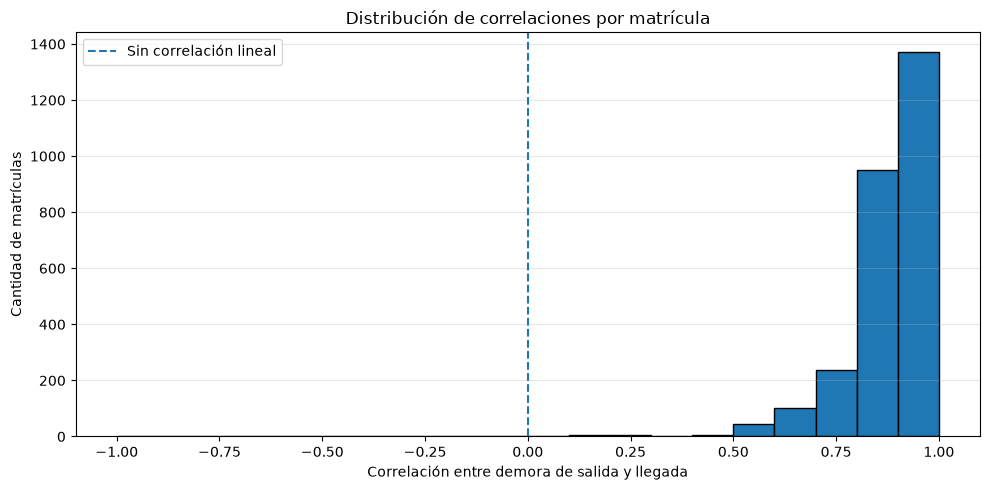

Matrículas incluidas en el gráfico: 2,724


In [62]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA")
print("Analizamos si las demoras de salida se mantienen, disminuyen o aumentan al llegar.")

# Seleccionamos vuelos operados
vuelos_operados = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

# Nos aseguramos de que las demoras sean numéricas
columnas_demora = [
    "demora_salida_min",
    "demora_arribo_min"
]

for columna in columnas_demora:
    vuelos_operados[columna] = pd.to_numeric(
        vuelos_operados[columna],
        errors="coerce"
    )

# Para comparar salida y llegada del mismo vuelo,
# necesitamos que ambas demoras estén disponibles.
vuelos_pares = vuelos_operados.dropna(
    subset=columnas_demora
).copy()

# Diferencia entre demora de llegada y demora de salida.
# Negativa: disminuye la demora respecto de la salida.
# Positiva: aumenta la demora respecto de la salida.
vuelos_pares["diferencia_demora_min"] = (
    vuelos_pares["demora_arribo_min"]
    - vuelos_pares["demora_salida_min"]
)

# Porcentajes generales de recuperación, estabilidad o aumento
total_pares = len(vuelos_pares)

recupera_tiempo = (
    vuelos_pares["diferencia_demora_min"] < 0
).sum()

sin_cambio = (
    vuelos_pares["diferencia_demora_min"] == 0
).sum()

acumula_demora = (
    vuelos_pares["diferencia_demora_min"] > 0
).sum()

print("\nRESUMEN GENERAL")
print("-" * 45)
print(f"Vuelos con ambas demoras disponibles: {total_pares:,}")

if total_pares > 0:
    print(
        f"Vuelos en los que disminuye la demora: "
        f"{recupera_tiempo:,} ({recupera_tiempo / total_pares * 100:.1f} %)"
    )
    print(
        f"Vuelos sin cambio en la demora: "
        f"{sin_cambio:,} ({sin_cambio / total_pares * 100:.1f} %)"
    )
    print(
        f"Vuelos en los que aumenta la demora: "
        f"{acumula_demora:,} ({acumula_demora / total_pares * 100:.1f} %)"
    )

    correlacion_pearson = vuelos_pares[
        "demora_salida_min"
    ].corr(vuelos_pares["demora_arribo_min"], method="pearson")

    correlacion_spearman = vuelos_pares[
        "demora_salida_min"
    ].corr(vuelos_pares["demora_arribo_min"], method="spearman")

    print(
        f"Correlación de Pearson entre ambas demoras: "
        f"{correlacion_pearson:.3f}"
    )
    print(
        f"Correlación de Spearman entre ambas demoras: "
        f"{correlacion_spearman:.3f}"
    )


# Preparamos los vuelos con matrícula identificada
vuelos_pares_matricula = vuelos_pares.loc[
    vuelos_pares["matricula_avion"].notna()
].copy()

vuelos_pares_matricula = vuelos_pares_matricula.loc[
    vuelos_pares_matricula["matricula_avion"]
    .astype("string")
    .str.strip()
    .ne("")
].copy()


# ============================================================
# GRÁFICO 1. RELACIÓN ENTRE DEMORA DE SALIDA Y LLEGADA
# ============================================================

print("\nGRÁFICO 1. RELACIÓN ENTRE DEMORA DE SALIDA Y LLEGADA")
print("Cada punto representa un vuelo. La diagonal indica dónde ambas demoras son iguales.")
print("Para facilitar la lectura, los ejes muestran el rango central de los datos.")

# Tomamos una muestra para mejorar la visualización.
# Los indicadores de arriba se calcularon con todos los vuelos.
if len(vuelos_pares) > 50000:
    muestra = vuelos_pares.sample(n=50000, random_state=42)
else:
    muestra = vuelos_pares

valores_ejes = pd.concat([
    vuelos_pares["demora_salida_min"],
    vuelos_pares["demora_arribo_min"]
])

limite_inferior = valores_ejes.quantile(0.01)
limite_superior = valores_ejes.quantile(0.99)

if limite_inferior == limite_superior:
    limite_inferior -= 1
    limite_superior += 1

plt.figure(figsize=(9, 7))

plt.scatter(
    muestra["demora_salida_min"],
    muestra["demora_arribo_min"],
    alpha=0.25,
    s=10
)

plt.plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    linestyle="--",
    label="Demora de salida = demora de llegada"
)

plt.xlim(limite_inferior, limite_superior)
plt.ylim(limite_inferior, limite_superior)

plt.xlabel("Demora de salida (minutos)")
plt.ylabel("Demora de llegada (minutos)")
plt.title("Relación entre demora de salida y llegada")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 2. DIFERENCIA ENTRE AMBAS DEMORAS
# ============================================================

print("\nGRÁFICO 2. CAMBIO DE LA DEMORA DURANTE EL VUELO")
print("Calculamos demora de llegada menos demora de salida.")
print("Valores negativos indican que disminuye la demora; positivos, que aumenta.")

diferencia = vuelos_pares["diferencia_demora_min"]

lim_inf = diferencia.quantile(0.01)
lim_sup = diferencia.quantile(0.99)

if lim_inf == lim_sup:
    lim_inf -= 1
    lim_sup += 1

plt.figure(figsize=(10, 5))

plt.hist(
    diferencia,
    bins=60,
    range=(lim_inf, lim_sup),
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Sin cambio en la demora"
)

plt.xlabel("Diferencia entre demora de llegada y salida (minutos)")
plt.ylabel("Cantidad de vuelos")
plt.title("Distribución del cambio de demora durante el vuelo")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 2. RESUMEN POR MATRÍCULA
# ============================================================

resumen_salida_arribo = (
    vuelos_pares_matricula
    .groupby("matricula_avion")
    .agg(
        vuelos_comparables=("diferencia_demora_min", "size"),
        demora_media_salida=("demora_salida_min", "mean"),
        demora_media_arribo=("demora_arribo_min", "mean"),
        diferencia_media=("diferencia_demora_min", "mean"),
        diferencia_mediana=("diferencia_demora_min", "median")
    )
)

# Cantidad de vuelos por matrícula en los que la demora disminuye
# o aumenta entre la salida y la llegada.
resumen_cambios = (
    vuelos_pares_matricula
    .groupby("matricula_avion")
    .agg(
        vuelos_recupera=("diferencia_demora_min", lambda s: (s < 0).sum()),
        vuelos_aumenta=("diferencia_demora_min", lambda s: (s > 0).sum())
    )
)

resumen_salida_arribo = resumen_salida_arribo.join(resumen_cambios)


# ============================================================
# GRÁFICO 3. DEMORA MEDIA POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 3. DEMORA MEDIA POR MATRÍCULA")
print("Comparamos la demora media de salida y llegada de cada avión.")
print("Se incluyen matrículas con al menos 30 vuelos con ambas demoras disponibles.")

MIN_VUELOS_MATRICULA = 30

matriculas_comparables = resumen_salida_arribo.loc[
    resumen_salida_arribo["vuelos_comparables"] >= MIN_VUELOS_MATRICULA
].copy()

if not matriculas_comparables.empty:

    valores_medios = pd.concat([
        matriculas_comparables["demora_media_salida"],
        matriculas_comparables["demora_media_arribo"]
    ])

    lim_inf = valores_medios.quantile(0.01)
    lim_sup = valores_medios.quantile(0.99)

    if lim_inf == lim_sup:
        lim_inf -= 1
        lim_sup += 1

    plt.figure(figsize=(9, 7))

    plt.scatter(
        matriculas_comparables["demora_media_salida"],
        matriculas_comparables["demora_media_arribo"],
        alpha=0.6
    )

    plt.plot(
        [lim_inf, lim_sup],
        [lim_inf, lim_sup],
        linestyle="--",
        label="Demoras medias iguales"
    )

    plt.xlim(lim_inf, lim_sup)
    plt.ylim(lim_inf, lim_sup)

    plt.xlabel("Demora media de salida (minutos)")
    plt.ylabel("Demora media de llegada (minutos)")
    plt.title("Demoras medias de salida y llegada por matrícula")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No hay matrículas con suficientes vuelos para realizar esta comparación.")


# ============================================================
# GRÁFICO 4. SALIDAS PUNTUALES CON LLEGADAS SEVERAS/CRÍTICAS
# ============================================================

print("\nGRÁFICO 4. SALIDAS PUNTUALES CON LLEGADAS SEVERAS/CRÍTICAS")
print("Buscamos aviones que salen a horario o adelantados, pero llegan con demora severa o crítica.")
print("Se exige un mínimo de 10 vuelos comparables con salida puntual por matrícula.")

# Salida puntual: demora de salida igual o inferior a cero.
vuelos_salida_puntual = vuelos_pares_matricula.loc[
    vuelos_pares_matricula["demora_salida_min"] <= 0
].copy()

# Usamos las categorías de puntualidad ya existentes.
vuelos_salida_puntual["_arribo_severo_critico"] = (
    vuelos_salida_puntual["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
)

resumen_salida_puntual = (
    vuelos_salida_puntual
    .groupby("matricula_avion")
    .agg(
        vuelos_salida_puntual=("demora_salida_min", "size"),
        llegadas_severas_criticas=("_arribo_severo_critico", "sum"),
        pct_arribos_severos_criticos=(
            "_arribo_severo_critico",
            lambda s: 100 * s.mean()
        )
    )
)

MIN_SALIDAS_PUNTUALES = 10

top_salida_puntual = (
    resumen_salida_puntual.loc[
        resumen_salida_puntual["vuelos_salida_puntual"]
        >= MIN_SALIDAS_PUNTUALES
    ]
    .sort_values("pct_arribos_severos_criticos", ascending=False)
    .head(15)
    .sort_values("pct_arribos_severos_criticos", ascending=True)
)

if not top_salida_puntual.empty:

    plt.figure(figsize=(10, 7))

    barras = plt.barh(
        top_salida_puntual.index.astype(str),
        top_salida_puntual["pct_arribos_severos_criticos"]
    )

    plt.bar_label(barras, fmt="%.1f%%", padding=3)

    plt.xlabel("% de llegadas severas o críticas")
    plt.ylabel("Matrícula")
    plt.title("Llegadas severas/críticas después de salidas puntuales")

    plt.xlim(
        0,
        min(
            110,
            top_salida_puntual["pct_arribos_severos_criticos"].max() + 10
        )
    )

    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No hay matrículas con suficientes salidas puntuales para este análisis.")


# ============================================================
# GRÁFICO 5. CORRELACIÓN ENTRE DEMORAS POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 5. RELACIÓN ENTRE DEMORAS POR MATRÍCULA")
print("Observamos cómo varía la correlación entre salida y llegada de un avión a otro.")
print("Solo incluimos matrículas con al menos 30 vuelos comparables y variación en ambas demoras.")

correlaciones_por_matricula = []

for matricula, grupo in vuelos_pares_matricula.groupby("matricula_avion"):

    if len(grupo) < MIN_VUELOS_MATRICULA:
        continue

    if (
        grupo["demora_salida_min"].nunique() < 2
        or grupo["demora_arribo_min"].nunique() < 2
    ):
        continue

    correlacion = grupo["demora_salida_min"].corr(
        grupo["demora_arribo_min"],
        method="pearson"
    )

    if pd.notna(correlacion):
        correlaciones_por_matricula.append(correlacion)

if correlaciones_por_matricula:

    plt.figure(figsize=(10, 5))

    plt.hist(
        correlaciones_por_matricula,
        bins=np.linspace(-1, 1, 21),
        edgecolor="black"
    )

    plt.axvline(0, linestyle="--", label="Sin correlación lineal")

    plt.xlabel("Correlación entre demora de salida y llegada")
    plt.ylabel("Cantidad de matrículas")
    plt.title("Distribución de correlaciones por matrícula")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(
        f"Matrículas incluidas en el gráfico: "
        f"{len(correlaciones_por_matricula):,}"
    )

else:
    print("No hay matrículas con suficientes datos y variación para calcular la correlación.")

##### 1.1.4. Puntualidad según el horario programado

**Objetivo:** determinar si el comportamiento de un avión cambia según el momento del día en que tiene programada su operación.

Preguntas que vamos a investigar:

- ¿La puntualidad de un mismo avión cambia según el período del día de salida?
- ¿La demora de llegada varía según el período de llegada programado?
- ¿Hay aviones que presentan demoras recurrentes en determinados períodos, pero no en otros?
- ¿Los patrones son similares para la puntualidad de salida y de llegada?

Utilizaremos los períodos del día que ya están definidos:

- `Madrugada`
- `Mañana`
- `Tarde`
- `Noche`

**Enfoque del análisis:** utilizaremos principalmente los horarios programados, porque la hora real puede haber cambiado como consecuencia de una demora. Buscaremos patrones por franja horaria sin asumir que un avión es menos puntual por operar más tarde. También tendremos en cuenta cuántos vuelos de cada matrícula hay en cada período.

Para el análisis de llegada, distinguiremos el horario de llegada programado del horario de salida programado, ya que representan momentos diferentes de la operación.

Columnas de período identificadas:
Salida programada: periodo_salida_programado
Llegada programada: periodo_arribo_programado

PREPARACIÓN DEL ANÁLISIS
---------------------------------------------
Vuelos operados: 328,521
Matrículas identificadas: 4,037
Se utilizarán los períodos programados, no los horarios reales.

GRÁFICO 1. DEMORAS SEVERAS Y CRÍTICAS POR PERÍODO
Comparamos el porcentaje de demoras severas/críticas según la franja programada.
Para salida se usa el período de salida; para llegada, el período de llegada.
Madrugada: 1,944 salidas evaluables; 5,994 llegadas evaluables.
Mañana: 126,998 salidas evaluables; 87,142 llegadas evaluables.
Tarde: 169,343 salidas evaluables; 158,101 llegadas evaluables.
Noche: 30,236 salidas evaluables; 76,109 llegadas evaluables.


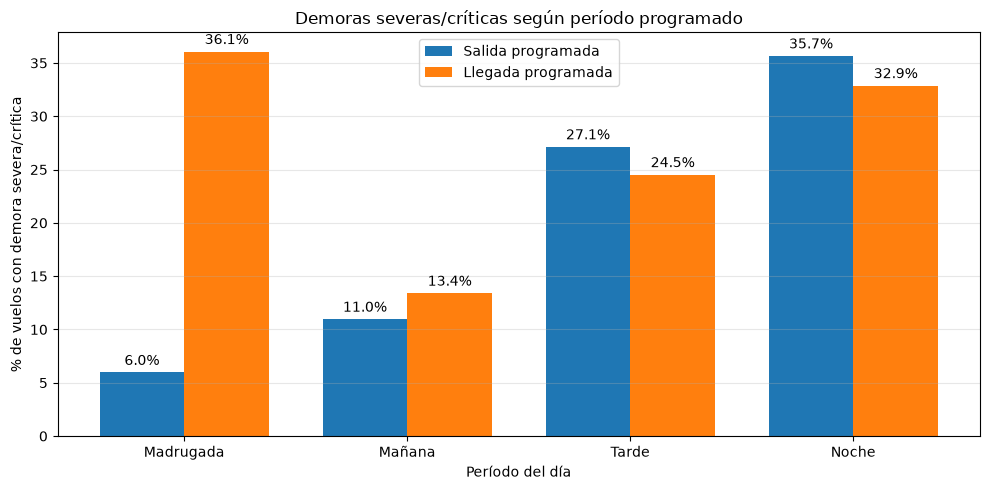


GRÁFICO 2. PUNTUALIDAD SEGÚN SALIDA PROGRAMADA
Mostramos la distribución porcentual de los niveles de puntualidad por franja.
'Desconocido' se incluye por separado para mostrar los datos faltantes.


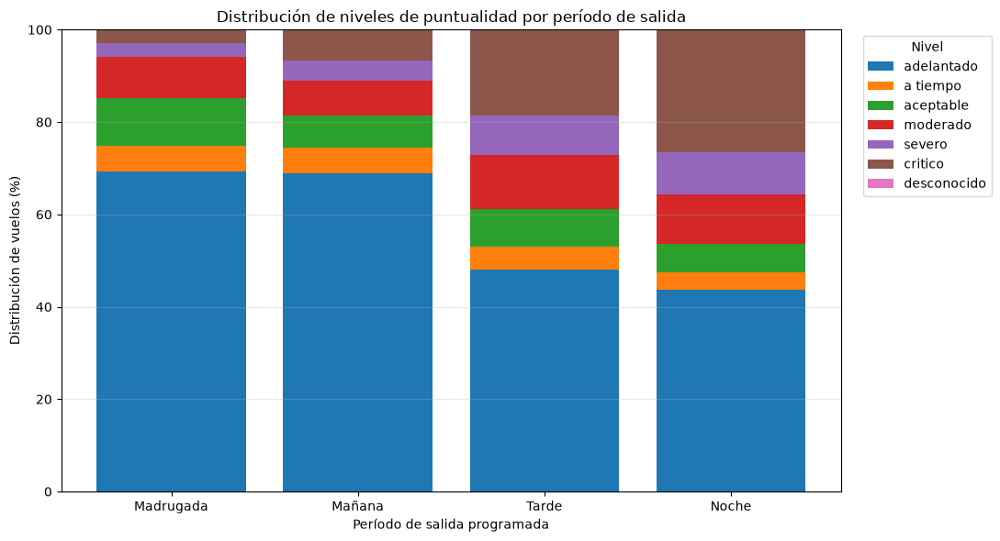


GRÁFICO 3. PUNTUALIDAD SEGÚN LLEGADA PROGRAMADA
Mostramos los niveles de puntualidad de llegada según la franja de llegada prevista.
Así evitamos atribuir a la llegada el período en el que salió el avión.


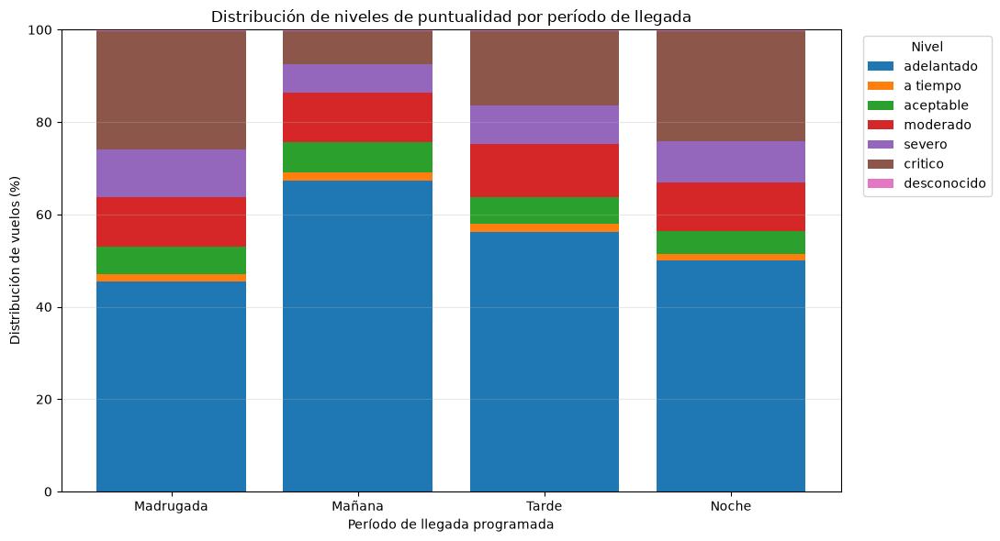


GRÁFICO 4. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN EL PERÍODO
Mostramos hasta 15 matrículas con porcentajes elevados de demoras severas/críticas.
Cada celda requiere al menos 10 vuelos evaluables de esa matrícula en ese período.
Las celdas vacías indican que no hay suficientes vuelos para comparar esa combinación.


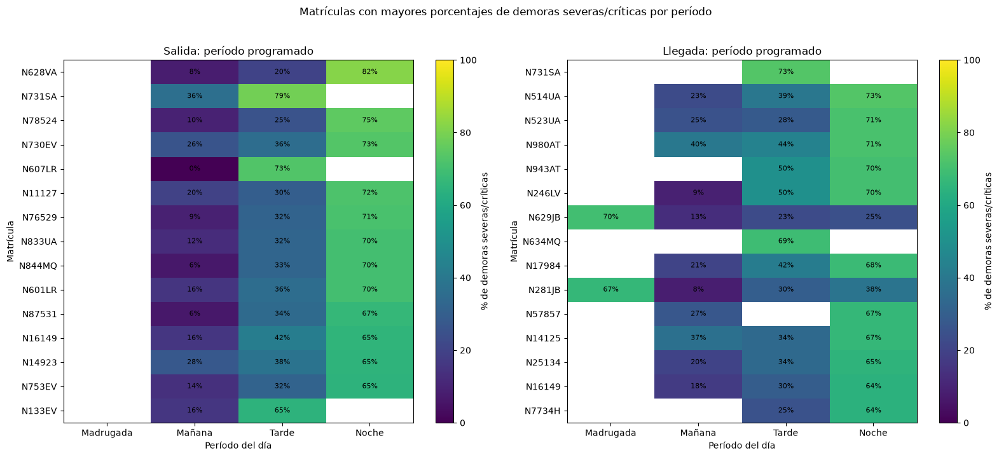

In [63]:
# ============================================================
# 1. IDENTIFICAR LAS COLUMNAS DE PERÍODO
# ============================================================

def normalizar_texto(valor):
    """Pasa a minúsculas y elimina tildes para comparar nombres."""
    texto = str(valor).strip().lower()
    return "".join(
        caracter
        for caracter in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caracter)
    )


def normalizar_nombre_columna(nombre):
    return (
        normalizar_texto(nombre)
        .replace(" ", "_")
        .replace("-", "_")
    )


def buscar_columna_periodo(etapa):
    columnas_normalizadas = {
        normalizar_nombre_columna(col): col
        for col in df.columns
    }

    if etapa == "salida":
        candidatas = [
            "periodo_salida_programada",
            "periodo_salida_programado",
            "periodo_salida",
            "periodo_del_dia_salida",
            "periodo_dia_salida",
            "franja_horaria_salida",
            "franja_salida_programada"
        ]
        terminos_etapa = ["salida", "departure", "dep"]

    else:
        candidatas = [
            "periodo_arribo_programado",
            "periodo_arribo_programado_hs",
            "periodo_llegada_programada",
            "periodo_llegada_programado",
            "periodo_arribo",
            "periodo_llegada",
            "periodo_del_dia_arribo",
            "periodo_del_dia_llegada",
            "franja_horaria_arribo",
            "franja_horaria_llegada"
        ]
        terminos_etapa = ["arribo", "llegada", "arrival"]

    # Primero buscamos nombres conocidos
    for candidata in candidatas:
        nombre = normalizar_nombre_columna(candidata)

        if nombre in columnas_normalizadas:
            return columnas_normalizadas[nombre]

    # Si el nombre es diferente, intentamos encontrarlo por sus partes
    posibles = []

    for columna in df.columns:
        nombre = normalizar_nombre_columna(columna)

        tiene_periodo = (
            "periodo" in nombre
            or "franja" in nombre
        )

        coincide_etapa = any(
            termino in nombre
            for termino in terminos_etapa
        )

        if tiene_periodo and coincide_etapa:
            posibles.append(columna)

    if len(posibles) == 1:
        return posibles[0]

    columnas_periodo = [
        col for col in df.columns
        if "periodo" in normalizar_nombre_columna(col)
        or "franja" in normalizar_nombre_columna(col)
    ]

    raise KeyError(
        f"No se pudo identificar la columna de período de {etapa}. "
        f"Columnas de período encontradas: {columnas_periodo}. "
        "Revisá sus nombres y ajustá la búsqueda."
    )


col_periodo_salida = buscar_columna_periodo("salida")
col_periodo_arribo = buscar_columna_periodo("arribo")

print("Columnas de período identificadas:")
print(f"Salida programada: {col_periodo_salida}")
print(f"Llegada programada: {col_periodo_arribo}")


# ============================================================
# 2. PREPARACIÓN DE LOS DATOS
# ============================================================

periodos = ["Madrugada", "Mañana", "Tarde", "Noche"]

niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

MIN_VUELOS_POR_MATRICULA_PERIODO = 10

base = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()


def canonizar_periodo(valor):
    if pd.isna(valor):
        return np.nan

    valor_normalizado = normalizar_texto(valor)

    equivalencias = {
        "madrugada": "Madrugada",
        "manana": "Mañana",
        "tarde": "Tarde",
        "noche": "Noche"
    }

    return equivalencias.get(valor_normalizado, np.nan)


def canonizar_nivel(valor):
    if pd.isna(valor):
        return "desconocido"

    valor_normalizado = normalizar_texto(valor)

    if valor_normalizado in niveles:
        return valor_normalizado

    return "desconocido"


# Copias auxiliares para el análisis; no modificamos las columnas originales
base["_periodo_salida_analisis"] = (
    base[col_periodo_salida].map(canonizar_periodo)
)

base["_periodo_arribo_analisis"] = (
    base[col_periodo_arribo].map(canonizar_periodo)
)

base["_nivel_salida_analisis"] = (
    base["nivel_puntualidad_salida"].map(canonizar_nivel)
)

base["_nivel_arribo_analisis"] = (
    base["nivel_puntualidad_arribo"].map(canonizar_nivel)
)

# Nos aseguramos de tener demoras numéricas para calcular porcentajes
base["demora_salida_min"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["demora_arribo_min"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

# Matrículas identificadas
base["_matricula_valida"] = (
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").str.strip().ne("")
)

# Resumen de registros operados
print("\nPREPARACIÓN DEL ANÁLISIS")
print("-" * 45)
print(f"Vuelos operados: {len(base):,}")
print(f"Matrículas identificadas: {base.loc[base['_matricula_valida'], 'matricula_avion'].nunique():,}")
print("Se utilizarán los períodos programados, no los horarios reales.")


# ============================================================
# GRÁFICO 1. DEMORAS SEVERAS/CRÍTICAS POR PERÍODO
# ============================================================

print("\nGRÁFICO 1. DEMORAS SEVERAS Y CRÍTICAS POR PERÍODO")
print("Comparamos el porcentaje de demoras severas/críticas según la franja programada.")
print("Para salida se usa el período de salida; para llegada, el período de llegada.")

tasas = []

for periodo in periodos:

    # Salida: vuelos con salida programada en este período
    salidas = base.loc[
        base["_periodo_salida_analisis"].eq(periodo)
        & base["demora_salida_min"].notna()
    ]

    # Llegada: vuelos con llegada programada en este período
    arribos = base.loc[
        base["_periodo_arribo_analisis"].eq(periodo)
        & base["demora_arribo_min"].notna()
    ]

    pct_salida = (
        100 * salidas["_nivel_salida_analisis"]
        .isin(["severo", "critico"]).mean()
        if len(salidas) > 0 else np.nan
    )

    pct_arribo = (
        100 * arribos["_nivel_arribo_analisis"]
        .isin(["severo", "critico"]).mean()
        if len(arribos) > 0 else np.nan
    )

    tasas.append({
        "periodo": periodo,
        "pct_salida": pct_salida,
        "pct_arribo": pct_arribo,
        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_periodos = pd.DataFrame(tasas).set_index("periodo")

for periodo, fila in resumen_periodos.iterrows():
    print(
        f"{periodo}: "
        f"{fila['vuelos_salida']:,.0f} salidas evaluables; "
        f"{fila['vuelos_arribo']:,.0f} llegadas evaluables."
    )

x = np.arange(len(periodos))
ancho = 0.38

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_periodos["pct_salida"],
    ancho,
    label="Salida programada"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_periodos["pct_arribo"],
    ancho,
    label="Llegada programada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, periodos)
plt.xlabel("Período del día")
plt.ylabel("% de vuelos con demora severa/crítica")
plt.title("Demoras severas/críticas según período programado")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 2. NIVELES DE PUNTUALIDAD SEGÚN SALIDA PROGRAMADA
# ============================================================

print("\nGRÁFICO 2. PUNTUALIDAD SEGÚN SALIDA PROGRAMADA")
print("Mostramos la distribución porcentual de los niveles de puntualidad por franja.")
print("'Desconocido' se incluye por separado para mostrar los datos faltantes.")

conteo_salida = pd.crosstab(
    base["_periodo_salida_analisis"],
    base["_nivel_salida_analisis"]
)

conteo_salida = conteo_salida.reindex(
    index=periodos,
    columns=niveles,
    fill_value=0
)

pct_salida_periodo = (
    100 * conteo_salida.div(
        conteo_salida.sum(axis=1).replace(0, np.nan),
        axis=0
    )
).fillna(0)

plt.figure(figsize=(11, 6))

base_barras = np.zeros(len(periodos))

for nivel in niveles:
    valores = pct_salida_periodo[nivel].to_numpy()

    plt.bar(
        periodos,
        valores,
        bottom=base_barras,
        label=nivel
    )

    base_barras += valores

plt.xlabel("Período de salida programada")
plt.ylabel("Distribución de vuelos (%)")
plt.title("Distribución de niveles de puntualidad por período de salida")
plt.ylim(0, 100)
plt.legend(title="Nivel", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. NIVELES DE PUNTUALIDAD SEGÚN LLEGADA PROGRAMADA
# ============================================================

print("\nGRÁFICO 3. PUNTUALIDAD SEGÚN LLEGADA PROGRAMADA")
print("Mostramos los niveles de puntualidad de llegada según la franja de llegada prevista.")
print("Así evitamos atribuir a la llegada el período en el que salió el avión.")

conteo_arribo = pd.crosstab(
    base["_periodo_arribo_analisis"],
    base["_nivel_arribo_analisis"]
)

conteo_arribo = conteo_arribo.reindex(
    index=periodos,
    columns=niveles,
    fill_value=0
)

pct_arribo_periodo = (
    100 * conteo_arribo.div(
        conteo_arribo.sum(axis=1).replace(0, np.nan),
        axis=0
    )
).fillna(0)

plt.figure(figsize=(11, 6))

base_barras = np.zeros(len(periodos))

for nivel in niveles:
    valores = pct_arribo_periodo[nivel].to_numpy()

    plt.bar(
        periodos,
        valores,
        bottom=base_barras,
        label=nivel
    )

    base_barras += valores

plt.xlabel("Período de llegada programada")
plt.ylabel("Distribución de vuelos (%)")
plt.title("Distribución de niveles de puntualidad por período de llegada")
plt.ylim(0, 100)
plt.legend(title="Nivel", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 4. RESUMEN POR MATRÍCULA Y PERÍODO
# ============================================================

def resumen_matricula_periodo(
    columna_periodo,
    columna_demora,
    columna_nivel
):
    datos = base.loc[
        base["_matricula_valida"]
        & base[columna_periodo].isin(periodos)
        & base[columna_demora].notna()
    ].copy()

    datos["_es_severo_critico"] = (
        datos[columna_nivel].isin(["severo", "critico"])
    )

    resumen = (
        datos
        .groupby(["matricula_avion", columna_periodo])
        .agg(
            vuelos_evaluables=("_es_severo_critico", "size"),
            vuelos_severos_criticos=("_es_severo_critico", "sum")
        )
    )

    # Evitamos comparar porcentajes basados en muy pocos vuelos
    resumen = resumen.loc[
        resumen["vuelos_evaluables"]
        >= MIN_VUELOS_POR_MATRICULA_PERIODO
    ].copy()

    resumen["pct_severo_critico"] = (
        100
        * resumen["vuelos_severos_criticos"]
        / resumen["vuelos_evaluables"]
    )

    matriz = resumen["pct_severo_critico"].unstack(
        columna_periodo
    )

    matriz = matriz.reindex(columns=periodos)

    # Seleccionamos matrículas con los porcentajes más altos
    # en al menos uno de los períodos donde tienen suficientes vuelos.
    if not matriz.empty:
        orden = (
            matriz.max(axis=1)
            .sort_values(ascending=False)
            .head(15)
            .index
        )

        matriz = matriz.loc[orden]

    return matriz


matriz_salida = resumen_matricula_periodo(
    "_periodo_salida_analisis",
    "demora_salida_min",
    "_nivel_salida_analisis"
)

matriz_arribo = resumen_matricula_periodo(
    "_periodo_arribo_analisis",
    "demora_arribo_min",
    "_nivel_arribo_analisis"
)


# ============================================================
# GRÁFICO 4. MAPA DE CALOR POR MATRÍCULA Y PERÍODO
# ============================================================

print("\nGRÁFICO 4. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN EL PERÍODO")
print("Mostramos hasta 15 matrículas con porcentajes elevados de demoras severas/críticas.")
print(
    f"Cada celda requiere al menos {MIN_VUELOS_POR_MATRICULA_PERIODO} "
    "vuelos evaluables de esa matrícula en ese período."
)
print("Las celdas vacías indican que no hay suficientes vuelos para comparar esa combinación.")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

configuraciones = [
    (
        axes[0],
        matriz_salida,
        "Salida: período programado"
    ),
    (
        axes[1],
        matriz_arribo,
        "Llegada: período programado"
    )
]

for ax, matriz, titulo in configuraciones:

    if matriz.empty:
        ax.set_title(titulo)
        ax.text(
            0.5, 0.5,
            "Sin suficientes datos",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_axis_off()
        continue

    valores = matriz.to_numpy(dtype=float)
    imagen = ax.imshow(
        np.ma.masked_invalid(valores),
        aspect="auto",
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns)
    ax.set_yticks(np.arange(len(matriz.index)))
    ax.set_yticklabels(matriz.index.astype(str))

    ax.set_xlabel("Período del día")
    ax.set_ylabel("Matrícula")
    ax.set_title(titulo)

    # Etiquetamos las celdas con porcentaje disponible
    for fila in range(valores.shape[0]):
        for columna in range(valores.shape[1]):
            valor = valores[fila, columna]

            if np.isfinite(valor):
                ax.text(
                    columna,
                    fila,
                    f"{valor:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        imagen,
        ax=ax,
        label="% de demoras severas/críticas"
    )

fig.suptitle(
    "Matrículas con mayores porcentajes de demoras severas/críticas por período",
    y=1.02
)

plt.tight_layout()
plt.show()

##### 1.1.5. Puntualidad según el tipo de día y el trimestre del año

**Objetivo:** analizar si el comportamiento de las matrículas cambia entre días normales, feriados y vísperas, y si se observan diferencias según el trimestre.

Preguntas que vamos a investigar:

- ¿Qué aviones presentan demoras tanto en días normales como en feriados y vísperas?
- ¿Hay matrículas cuyas demoras se concentran principalmente en feriados o vísperas?
- ¿Qué porcentaje de los vuelos de cada avión llega demorado según el tipo de día?
- ¿Los aviones que suelen ser puntuales en días normales mantienen ese comportamiento durante los feriados?
- ¿Hay matrículas que presentan diferencias importantes de puntualidad entre los trimestres del año?

Utilizaremos la variable `feriado`, con las categorías:

- `Día normal`
- `Feriado`
- `Víspera`

También utilizaremos la variable temporal `trimestre`, para observar posibles cambios de comportamiento a lo largo del año.

**Enfoque del análisis:** compararemos las tasas de demora de llegada y, cuando aporte información, las de salida. La cantidad de observaciones por matrícula y tipo de día será importante para interpretar los resultados. Las diferencias entre trimestres se considerarán patrones descriptivos y no necesariamente efectos causados por la época del año.

1.1.5 PUNTUALIDAD SEGÚN TIPO DE DÍA Y TRIMESTRE
Analizamos si las demoras severas y críticas cambian según el tipo de día y la época del año.

Preparación de datos:
Vuelos operados: 328,521
Matrículas identificadas: 4,037
Trimestres disponibles: 2013Q1, 2013Q2, 2013Q3, 2013Q4
Los porcentajes de demora se calculan sobre vuelos con información de demora disponible.

GRÁFICO 1. DEMORAS SEVERAS Y CRÍTICAS SEGÚN TIPO DE DÍA
Comparamos los porcentajes de demoras severas/críticas en salida y llegada.
El tipo de día corresponde a la categoría registrada en la variable feriado.
Día normal: 311,698 salidas evaluables, 310,564 llegadas evaluables.
Feriado: 8,508 salidas evaluables, 8,483 llegadas evaluables.
Víspera: 8,315 salidas evaluables, 8,299 llegadas evaluables.


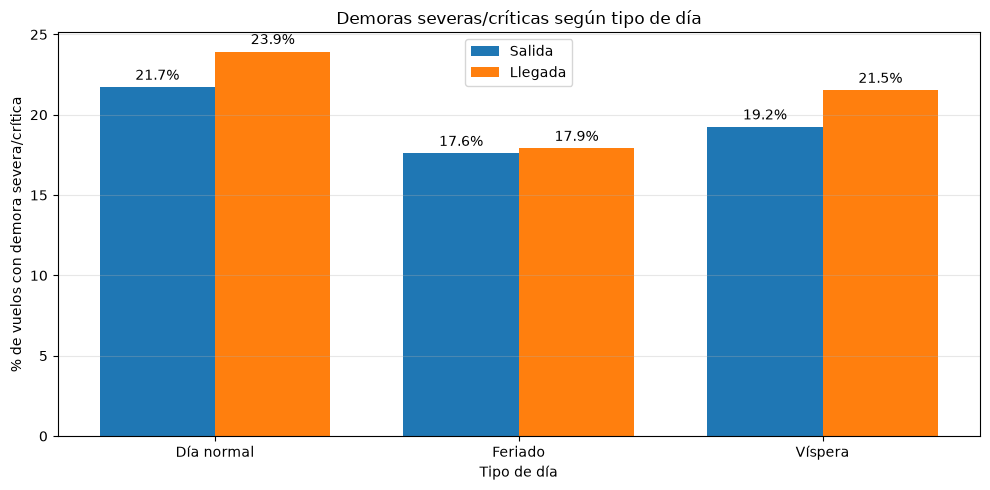


GRÁFICO 2. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN TIPO DE DÍA
Comparamos las demoras severas/críticas de llegada por matrícula.
Cada celda necesita al menos 3 vuelos evaluables. Se muestran hasta 15 matrículas con porcentajes elevados.
Las celdas vacías indican que no hay suficientes observaciones para comparar.


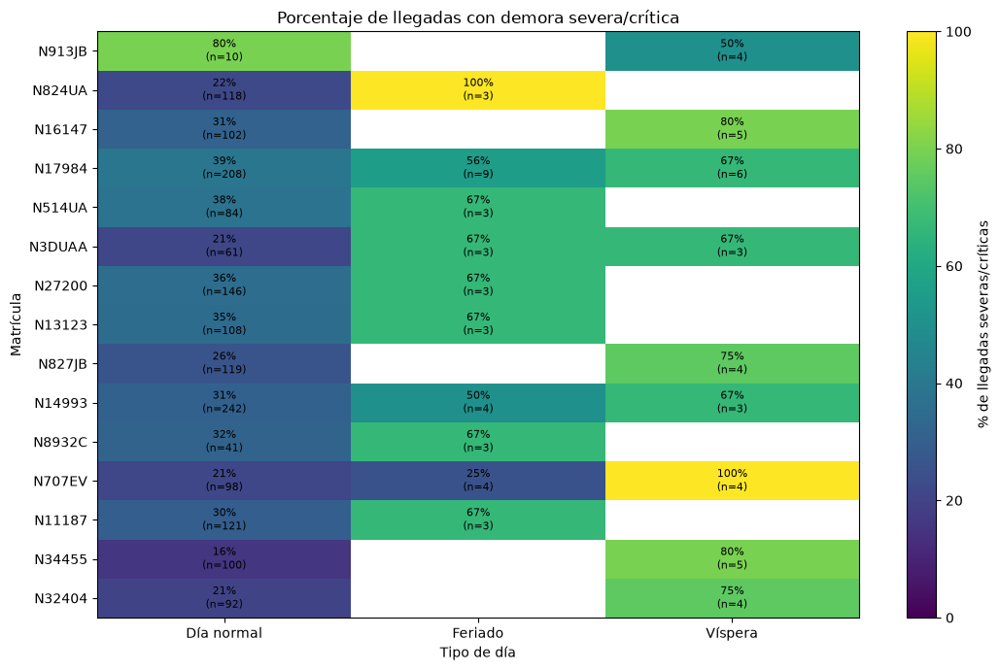


GRÁFICO 3. COMPARACIÓN ENTRE DÍAS NORMALES Y DÍAS ESPECIALES
Comparamos el porcentaje de llegadas severas/críticas de cada matrícula.
Solo se comparan matrículas con al menos 3 llegadas evaluables en ambos grupos.
Los puntos por encima de la diagonal tienen más demoras severas/críticas en el grupo especial.
Matrículas comparables entre días normales y feriado: 1,238
Matrículas comparables entre días normales y víspera: 1,210


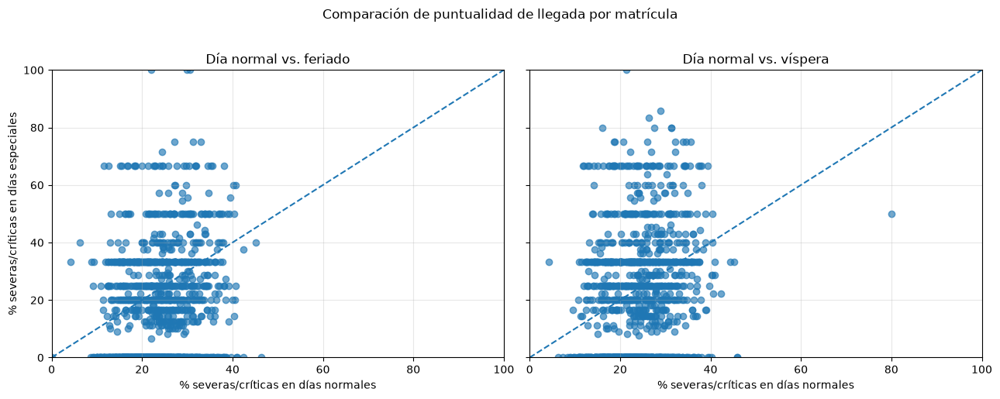


GRÁFICO 4. DEMORAS SEVERAS Y CRÍTICAS POR TRIMESTRE
Comparamos los porcentajes generales de salida y llegada en cada trimestre.
Las diferencias son descriptivas y no demuestran que el trimestre cause las demoras.
2013Q1: 78,146 salidas evaluables, 77,911 llegadas evaluables.
2013Q2: 83,129 salidas evaluables, 82,767 llegadas evaluables.
2013Q3: 84,448 salidas evaluables, 84,059 llegadas evaluables.
2013Q4: 82,798 salidas evaluables, 82,609 llegadas evaluables.


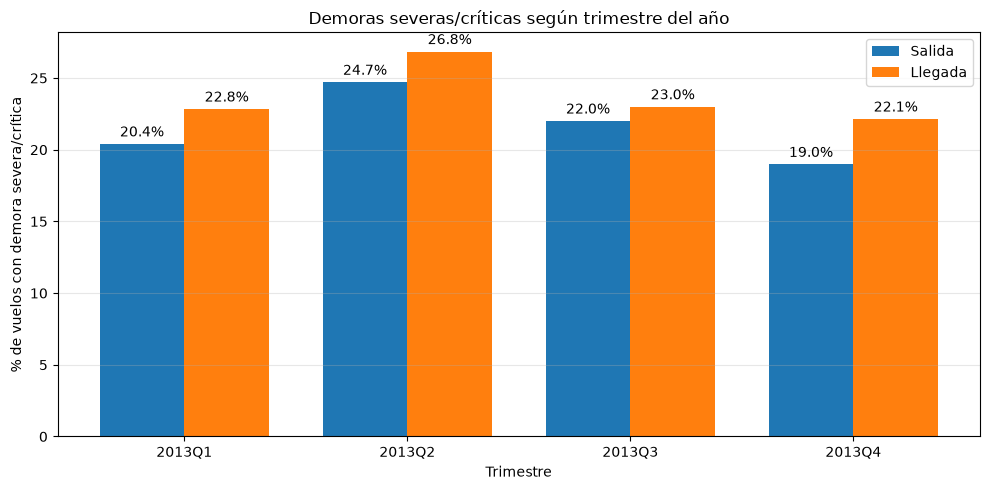


GRÁFICO 5. CAMBIOS DE PUNTUALIDAD POR MATRÍCULA Y TRIMESTRE
Comparamos el porcentaje de llegadas severas/críticas de cada avión entre trimestres.
Cada celda necesita al menos 10 llegadas evaluables. Mostramos hasta 15 matrículas con diferencias entre períodos.
Las celdas vacías indican que no se alcanza el mínimo de vuelos requerido.


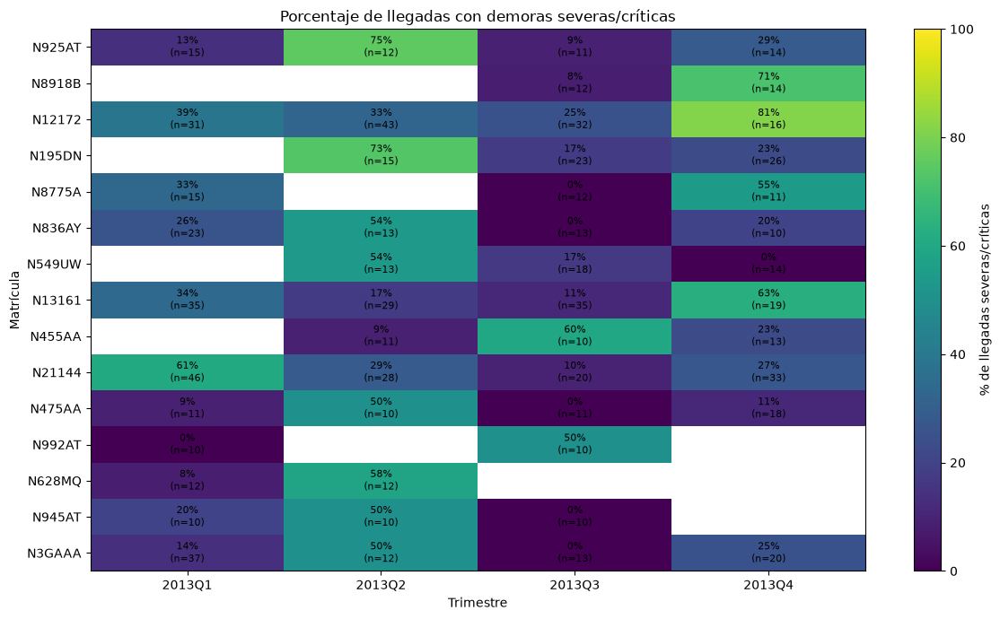

In [64]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.1.5 PUNTUALIDAD SEGÚN TIPO DE DÍA Y TRIMESTRE")
print("Analizamos si las demoras severas y críticas cambian según el tipo de día y la época del año.")

# Comprobamos que estén disponibles las columnas necesarias
columnas_necesarias = [
    "estado_vuelo",
    "matricula_avion",
    "demora_salida_min",
    "demora_arribo_min",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo",
    "feriado",
    "trimestre"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(
        f"Faltan estas columnas en df: {faltantes}"
    )


def normalizar_texto(valor):
    """Normaliza texto para comparar categorías sin diferencias de tildes."""
    if pd.isna(valor):
        return ""

    texto = str(valor).strip().lower()

    return "".join(
        caracter
        for caracter in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caracter)
    )


def normalizar_tipo_dia(valor):
    valor = normalizar_texto(valor)

    equivalencias = {
        "dia normal": "Día normal",
        "normal": "Día normal",
        "feriado": "Feriado",
        "vispera": "Víspera"
    }

    return equivalencias.get(valor, np.nan)


def normalizar_nivel(valor):
    valor = normalizar_texto(valor)

    equivalencias = {
        "adelantado": "adelantado",
        "a tiempo": "a tiempo",
        "aceptable": "aceptable",
        "moderado": "moderado",
        "severo": "severo",
        "critico": "critico",
        "desconocido": "desconocido"
    }

    return equivalencias.get(valor, "desconocido")


# Trabajamos únicamente con vuelos operados
base = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

# Convertimos las demoras a formato numérico en la copia de trabajo
for columna in ["demora_salida_min", "demora_arribo_min"]:
    base[columna] = pd.to_numeric(
        base[columna],
        errors="coerce"
    )

# Normalizamos las categorías en columnas auxiliares
base["_tipo_dia_analisis"] = base["feriado"].map(
    normalizar_tipo_dia
)

base["_trimestre_analisis"] = (
    base["trimestre"].astype("string").str.strip()
)

base["_nivel_salida_analisis"] = (
    base["nivel_puntualidad_salida"].map(normalizar_nivel)
)

base["_nivel_arribo_analisis"] = (
    base["nivel_puntualidad_arribo"].map(normalizar_nivel)
)

# Identificamos matrículas válidas
base["_matricula_valida"] = (
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").str.strip().ne("")
)

# Indicadores de demoras severas o críticas
base["_salida_severa_critica"] = (
    base["_nivel_salida_analisis"].isin(["severo", "critico"])
)

base["_arribo_severo_critico"] = (
    base["_nivel_arribo_analisis"].isin(["severo", "critico"])
)

tipos_dia = ["Día normal", "Feriado", "Víspera"]

# Ordenamos cronológicamente los trimestres, que normalmente
# aparecerán como 2013Q1, 2013Q2, 2013Q3 y 2013Q4.
trimestres = sorted(
    base["_trimestre_analisis"].dropna().unique()
)

MIN_VUELOS_TIPO_DIA = 3
MIN_VUELOS_TRIMESTRE = 10

print("\nPreparación de datos:")
print(f"Vuelos operados: {len(base):,}")
print(
    "Matrículas identificadas: "
    f"{base.loc[base['_matricula_valida'], 'matricula_avion'].nunique():,}"
)
print(f"Trimestres disponibles: {', '.join(trimestres)}")
print(
    "Los porcentajes de demora se calculan sobre vuelos con "
    "información de demora disponible."
)


# ============================================================
# GRÁFICO 1. DEMORAS SEVERAS/CRÍTICAS SEGÚN TIPO DE DÍA
# ============================================================

print("\nGRÁFICO 1. DEMORAS SEVERAS Y CRÍTICAS SEGÚN TIPO DE DÍA")
print("Comparamos los porcentajes de demoras severas/críticas en salida y llegada.")
print("El tipo de día corresponde a la categoría registrada en la variable feriado.")

resultados_dia = []

for tipo in tipos_dia:

    grupo = base.loc[
        base["_tipo_dia_analisis"].eq(tipo)
    ]

    salidas = grupo.loc[
        grupo["demora_salida_min"].notna()
    ]

    arribos = grupo.loc[
        grupo["demora_arribo_min"].notna()
    ]

    pct_salida = (
        100 * salidas["_salida_severa_critica"].mean()
        if not salidas.empty else np.nan
    )

    pct_arribo = (
        100 * arribos["_arribo_severo_critico"].mean()
        if not arribos.empty else np.nan
    )

    resultados_dia.append({
        "tipo_dia": tipo,
        "pct_salida": pct_salida,
        "pct_arribo": pct_arribo,
        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_tipo_dia = (
    pd.DataFrame(resultados_dia)
    .set_index("tipo_dia")
    .reindex(tipos_dia)
)

for tipo, fila in resumen_tipo_dia.iterrows():
    print(
        f"{tipo}: "
        f"{fila['vuelos_salida']:,.0f} salidas evaluables, "
        f"{fila['vuelos_arribo']:,.0f} llegadas evaluables."
    )

x = np.arange(len(tipos_dia))
ancho = 0.38

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_tipo_dia["pct_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_tipo_dia["pct_arribo"],
    ancho,
    label="Llegada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, tipos_dia)
plt.ylabel("% de vuelos con demora severa/crítica")
plt.xlabel("Tipo de día")
plt.title("Demoras severas/críticas según tipo de día")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# PREPARACIÓN DE RESÚMENES POR MATRÍCULA Y TIPO DE DÍA
# ============================================================

base_arribos = base.loc[
    base["_matricula_valida"]
    & base["_tipo_dia_analisis"].isin(tipos_dia)
    & base["demora_arribo_min"].notna()
].copy()

resumen_matricula_dia = (
    base_arribos
    .groupby(["matricula_avion", "_tipo_dia_analisis"])
    .agg(
        vuelos_evaluables=("_arribo_severo_critico", "size"),
        vuelos_severos_criticos=("_arribo_severo_critico", "sum")
    )
)

resumen_matricula_dia["pct_severo_critico"] = (
    100
    * resumen_matricula_dia["vuelos_severos_criticos"]
    / resumen_matricula_dia["vuelos_evaluables"]
)

matriz_dia_pct = (
    resumen_matricula_dia["pct_severo_critico"]
    .unstack("_tipo_dia_analisis")
    .reindex(columns=tipos_dia)
)

matriz_dia_n = (
    resumen_matricula_dia["vuelos_evaluables"]
    .unstack("_tipo_dia_analisis")
    .reindex(columns=tipos_dia)
)


# ============================================================
# GRÁFICO 2. MAPA DE CALOR POR MATRÍCULA Y TIPO DE DÍA
# ============================================================

print("\nGRÁFICO 2. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN TIPO DE DÍA")
print("Comparamos las demoras severas/críticas de llegada por matrícula.")
print(
    f"Cada celda necesita al menos {MIN_VUELOS_TIPO_DIA} vuelos evaluables. "
    "Se muestran hasta 15 matrículas con porcentajes elevados."
)
print("Las celdas vacías indican que no hay suficientes observaciones para comparar.")

# Ocultamos porcentajes calculados a partir de muy pocos vuelos
matriz_dia_filtrada = matriz_dia_pct.where(
    matriz_dia_n >= MIN_VUELOS_TIPO_DIA
)

# Priorizamos matrículas que tengan datos en al menos dos tipos de día
matriz_dia_filtrada = matriz_dia_filtrada.loc[
    matriz_dia_filtrada.notna().sum(axis=1) >= 2
]

# Seleccionamos las matrículas con mayor promedio de porcentajes disponibles
if not matriz_dia_filtrada.empty:

    orden_dia = (
        matriz_dia_filtrada.mean(axis=1)
        .sort_values(ascending=False)
        .head(15)
        .index
    )

    matriz_dia_grafico = matriz_dia_filtrada.loc[orden_dia]
    matriz_dia_n_grafico = matriz_dia_n.loc[orden_dia]

    fig, ax = plt.subplots(figsize=(11, 7))

    imagen = ax.imshow(
        np.ma.masked_invalid(matriz_dia_grafico.to_numpy(dtype=float)),
        aspect="auto",
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(len(tipos_dia)))
    ax.set_xticklabels(tipos_dia)
    ax.set_yticks(np.arange(len(matriz_dia_grafico.index)))
    ax.set_yticklabels(matriz_dia_grafico.index.astype(str))

    ax.set_xlabel("Tipo de día")
    ax.set_ylabel("Matrícula")
    ax.set_title("Porcentaje de llegadas con demora severa/crítica")

    # Mostramos porcentaje y cantidad de vuelos en cada celda
    valores = matriz_dia_grafico.to_numpy(dtype=float)
    cantidades = matriz_dia_n_grafico.to_numpy(dtype=float)

    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):

            valor = valores[i, j]
            cantidad = cantidades[i, j]

            if np.isfinite(valor) and np.isfinite(cantidad):
                ax.text(
                    j,
                    i,
                    f"{valor:.0f}%\n(n={int(cantidad)})",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        imagen,
        ax=ax,
        label="% de llegadas severas/críticas"
    )

    plt.tight_layout()
    plt.show()

else:
    print(
        "No hay suficientes matrículas con al menos "
        f"{MIN_VUELOS_TIPO_DIA} vuelos evaluables en dos tipos de día."
    )


# ============================================================
# GRÁFICO 3. DÍAS NORMALES FRENTE A FERIADOS Y VÍSPERAS
# ============================================================

print("\nGRÁFICO 3. COMPARACIÓN ENTRE DÍAS NORMALES Y DÍAS ESPECIALES")
print("Comparamos el porcentaje de llegadas severas/críticas de cada matrícula.")
print(
    f"Solo se comparan matrículas con al menos {MIN_VUELOS_TIPO_DIA} "
    "llegadas evaluables en ambos grupos."
)
print("Los puntos por encima de la diagonal tienen más demoras severas/críticas en el grupo especial.")

def obtener_comparacion_dia(tipo_especial):

    resumen = resumen_matricula_dia

    try:
        normal = resumen.xs("Día normal", level="_tipo_dia_analisis")
        especial = resumen.xs(tipo_especial, level="_tipo_dia_analisis")
    except KeyError:
        return pd.DataFrame()

    comparacion = pd.DataFrame({
        "pct_normal": normal["pct_severo_critico"],
        "n_normal": normal["vuelos_evaluables"],
        "pct_especial": especial["pct_severo_critico"],
        "n_especial": especial["vuelos_evaluables"]
    })

    comparacion = comparacion.dropna()

    comparacion = comparacion.loc[
        (comparacion["n_normal"] >= MIN_VUELOS_TIPO_DIA)
        & (comparacion["n_especial"] >= MIN_VUELOS_TIPO_DIA)
    ]

    return comparacion


comparacion_feriado = obtener_comparacion_dia("Feriado")
comparacion_vispera = obtener_comparacion_dia("Víspera")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

comparaciones = [
    (axes[0], comparacion_feriado, "Día normal vs. feriado", "Feriado"),
    (axes[1], comparacion_vispera, "Día normal vs. víspera", "Víspera")
]

for ax, comparacion, titulo, tipo_especial in comparaciones:

    if comparacion.empty:
        ax.text(
            0.5, 0.5,
            "No hay suficientes matrículas\npara comparar",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_title(titulo)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.3)
        continue

    ax.scatter(
        comparacion["pct_normal"],
        comparacion["pct_especial"],
        alpha=0.65
    )

    ax.plot([0, 100], [0, 100], linestyle="--")

    ax.set_title(titulo)
    ax.set_xlabel("% severas/críticas en días normales")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)

    print(
        f"Matrículas comparables entre días normales y {tipo_especial.lower()}: "
        f"{len(comparacion):,}"
    )

axes[0].set_ylabel("% severas/críticas en días especiales")

plt.suptitle("Comparación de puntualidad de llegada por matrícula", y=1.02)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 4. DEMORAS SEVERAS/CRÍTICAS SEGÚN TRIMESTRE
# ============================================================

print("\nGRÁFICO 4. DEMORAS SEVERAS Y CRÍTICAS POR TRIMESTRE")
print("Comparamos los porcentajes generales de salida y llegada en cada trimestre.")
print("Las diferencias son descriptivas y no demuestran que el trimestre cause las demoras.")

resultados_trimestre = []

for trimestre in trimestres:

    grupo = base.loc[
        base["_trimestre_analisis"].eq(trimestre)
    ]

    salidas = grupo.loc[
        grupo["demora_salida_min"].notna()
    ]

    arribos = grupo.loc[
        grupo["demora_arribo_min"].notna()
    ]

    pct_salida = (
        100 * salidas["_salida_severa_critica"].mean()
        if not salidas.empty else np.nan
    )

    pct_arribo = (
        100 * arribos["_arribo_severo_critico"].mean()
        if not arribos.empty else np.nan
    )

    resultados_trimestre.append({
        "trimestre": trimestre,
        "pct_salida": pct_salida,
        "pct_arribo": pct_arribo,
        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_trimestres = (
    pd.DataFrame(resultados_trimestre)
    .set_index("trimestre")
    .reindex(trimestres)
)

for trimestre, fila in resumen_trimestres.iterrows():
    print(
        f"{trimestre}: "
        f"{fila['vuelos_salida']:,.0f} salidas evaluables, "
        f"{fila['vuelos_arribo']:,.0f} llegadas evaluables."
    )

x = np.arange(len(trimestres))

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_trimestres["pct_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_trimestres["pct_arribo"],
    ancho,
    label="Llegada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, trimestres)
plt.xlabel("Trimestre")
plt.ylabel("% de vuelos con demora severa/crítica")
plt.title("Demoras severas/críticas según trimestre del año")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 5. RESUMEN POR MATRÍCULA Y TRIMESTRE
# ============================================================

base_arribos_trim = base.loc[
    base["_matricula_valida"]
    & base["_trimestre_analisis"].isin(trimestres)
    & base["demora_arribo_min"].notna()
].copy()

resumen_matricula_trim = (
    base_arribos_trim
    .groupby(["matricula_avion", "_trimestre_analisis"])
    .agg(
        vuelos_evaluables=("_arribo_severo_critico", "size"),
        vuelos_severos_criticos=("_arribo_severo_critico", "sum")
    )
)

resumen_matricula_trim["pct_severo_critico"] = (
    100
    * resumen_matricula_trim["vuelos_severos_criticos"]
    / resumen_matricula_trim["vuelos_evaluables"]
)

matriz_trim_pct = (
    resumen_matricula_trim["pct_severo_critico"]
    .unstack("_trimestre_analisis")
    .reindex(columns=trimestres)
)

matriz_trim_n = (
    resumen_matricula_trim["vuelos_evaluables"]
    .unstack("_trimestre_analisis")
    .reindex(columns=trimestres)
)


# ============================================================
# GRÁFICO 5. MAPA DE CALOR POR MATRÍCULA Y TRIMESTRE
# ============================================================

print("\nGRÁFICO 5. CAMBIOS DE PUNTUALIDAD POR MATRÍCULA Y TRIMESTRE")
print("Comparamos el porcentaje de llegadas severas/críticas de cada avión entre trimestres.")
print(
    f"Cada celda necesita al menos {MIN_VUELOS_TRIMESTRE} llegadas evaluables. "
    "Mostramos hasta 15 matrículas con diferencias entre períodos."
)
print("Las celdas vacías indican que no se alcanza el mínimo de vuelos requerido.")

matriz_trim_filtrada = matriz_trim_pct.where(
    matriz_trim_n >= MIN_VUELOS_TRIMESTRE
)

# Para comparar cambios, exigimos al menos dos trimestres con datos suficientes
matriz_trim_filtrada = matriz_trim_filtrada.loc[
    matriz_trim_filtrada.notna().sum(axis=1) >= 2
]

if not matriz_trim_filtrada.empty:

    variacion = (
        matriz_trim_filtrada.max(axis=1)
        - matriz_trim_filtrada.min(axis=1)
    )

    orden_trim = (
        variacion
        .sort_values(ascending=False)
        .head(15)
        .index
    )

    matriz_trim_grafico = matriz_trim_filtrada.loc[orden_trim]
    matriz_trim_n_grafico = matriz_trim_n.loc[orden_trim]

    fig, ax = plt.subplots(figsize=(12, 7))

    imagen = ax.imshow(
        np.ma.masked_invalid(matriz_trim_grafico.to_numpy(dtype=float)),
        aspect="auto",
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(len(trimestres)))
    ax.set_xticklabels(trimestres)
    ax.set_yticks(np.arange(len(matriz_trim_grafico.index)))
    ax.set_yticklabels(matriz_trim_grafico.index.astype(str))

    ax.set_xlabel("Trimestre")
    ax.set_ylabel("Matrícula")
    ax.set_title("Porcentaje de llegadas con demoras severas/críticas")

    valores = matriz_trim_grafico.to_numpy(dtype=float)
    cantidades = matriz_trim_n_grafico.to_numpy(dtype=float)

    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):

            valor = valores[i, j]
            cantidad = cantidades[i, j]

            if np.isfinite(valor) and np.isfinite(cantidad):
                ax.text(
                    j,
                    i,
                    f"{valor:.0f}%\n(n={int(cantidad)})",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        imagen,
        ax=ax,
        label="% de llegadas severas/críticas"
    )

    plt.tight_layout()
    plt.show()

else:
    print(
        "No hay suficientes matrículas con al menos "
        f"{MIN_VUELOS_TRIMESTRE} llegadas evaluables en dos trimestres."
    )

##### 1.1.6. Persistencia del comportamiento a lo largo del año

**Objetivo:** determinar si las matrículas mantienen patrones similares de puntualidad a lo largo del tiempo.

Preguntas que vamos a investigar:

- ¿La demora de un avión se mantiene entre el primer y el segundo semestre?
- ¿Las matrículas que presentan demoras frecuentes en una parte del año continúan mostrando ese comportamiento en la otra?
- ¿Qué aviones mejoran o empeoran su puntualidad entre ambos períodos?

Compararemos los dos semestres de 2013:

- **Primer semestre:** enero a junio.
- **Segundo semestre:** julio a diciembre.

**Enfoque del análisis:** observaremos tanto la variación de la demora promedio como la proporción de vuelos demorados. Para que la comparación sea más útil, tendremos en cuenta la cantidad de vuelos disponibles en cada semestre y procuraremos comparar matrículas con observaciones suficientes en ambos períodos.

Una diferencia entre semestres no implica necesariamente un cambio propio del avión: también puede estar relacionada con modificaciones en las rutas, los horarios o las condiciones operativas.

1.1.6. PERSISTENCIA DEL COMPORTAMIENTO A LO LARGO DEL AÑO
Comparamos la puntualidad de las matrículas entre los dos semestres de 2013.

DATOS DEL ANÁLISIS
---------------------------------------------
Vuelos operados de 2013: 328,521
Matrículas identificadas: 4,037
Mínimo para comparar cada matrícula: 30 observaciones evaluables por semestre y etapa.

RESUMEN GENERAL POR SEMESTRE
---------------------------------------------

Primer semestre
Salidas evaluables: 161,275
Llegadas evaluables: 160,678
Demora media de salida: 13.72 minutos
Demora media de llegada: 8.15 minutos
Salidas con demora positiva: 39.98 %
Llegadas con demora positiva: 41.93 %
Salidas severas/críticas: 22.62 %
Llegadas severas/críticas: 24.90 %

Segundo semestre
Salidas evaluables: 167,246
Llegadas evaluables: 166,668
Demora media de salida: 11.60 minutos
Demora media de llegada: 5.68 minutos
Salidas con demora positiva: 38.24 %
Llegadas con demora positiva: 39.38 %
Salidas severas/críticas: 20.50 %
Llegadas severas/

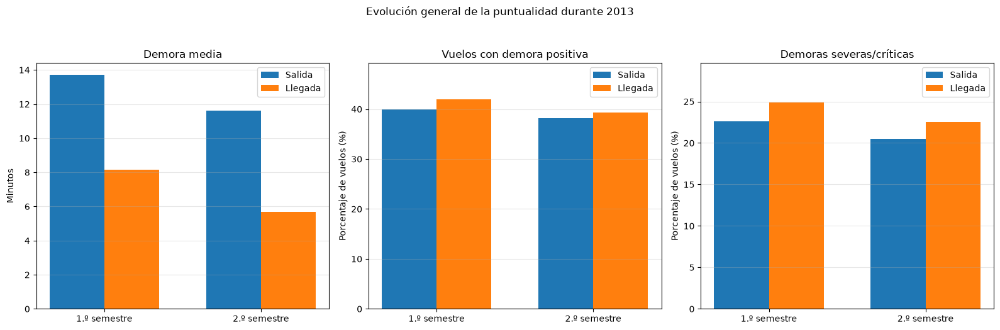


MATRÍCULAS COMPARABLES ENTRE AMBOS SEMESTRES
---------------------------------------------
Demora media de salida: 1,603
Demora media de llegada: 1,600
% de salidas con demora: 1,603
% de llegadas con demora: 1,600
% severo/crítico de salida: 1,603
% severo/crítico de llegada: 1,600

GRÁFICO 2. CAMBIO EN LA DEMORA MEDIA POR MATRÍCULA
Cada punto representa una matrícula con suficientes vuelos en ambos semestres.
La distancia respecto de la diagonal indica cuánto cambió su demora media.


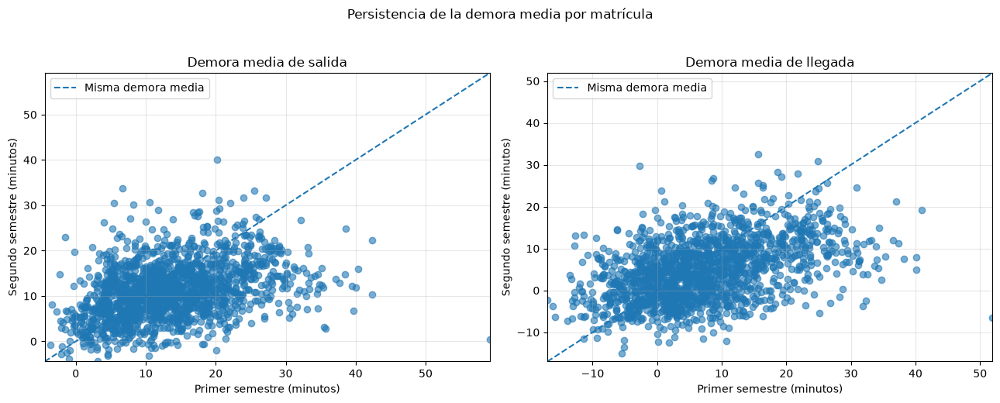


GRÁFICO 3. PERSISTENCIA DEL PORCENTAJE DE VUELOS DEMORADOS
Comparamos el porcentaje de vuelos con demora positiva entre semestres.
Por encima de la diagonal, el porcentaje es mayor en el segundo semestre.


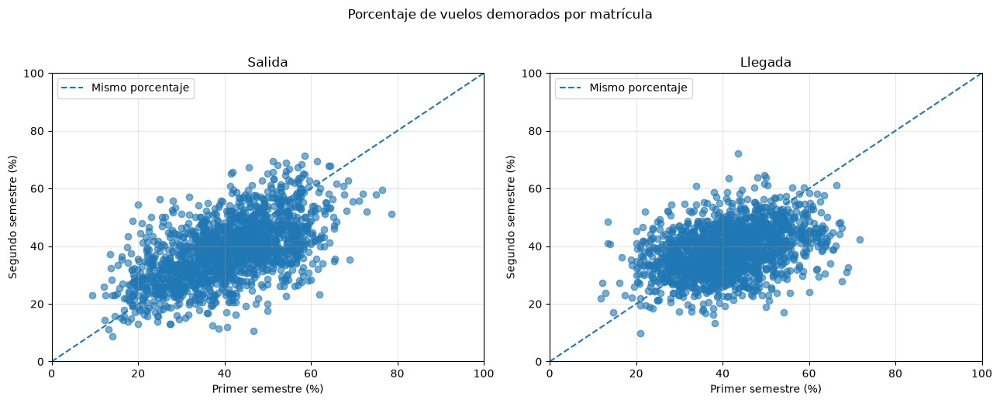


GRÁFICO 4. PERSISTENCIA DE LAS DEMORAS SEVERAS/CRÍTICAS
Comparamos la proporción de vuelos severos/críticos de cada matrícula.
Los porcentajes se calculan sobre niveles de puntualidad evaluables.


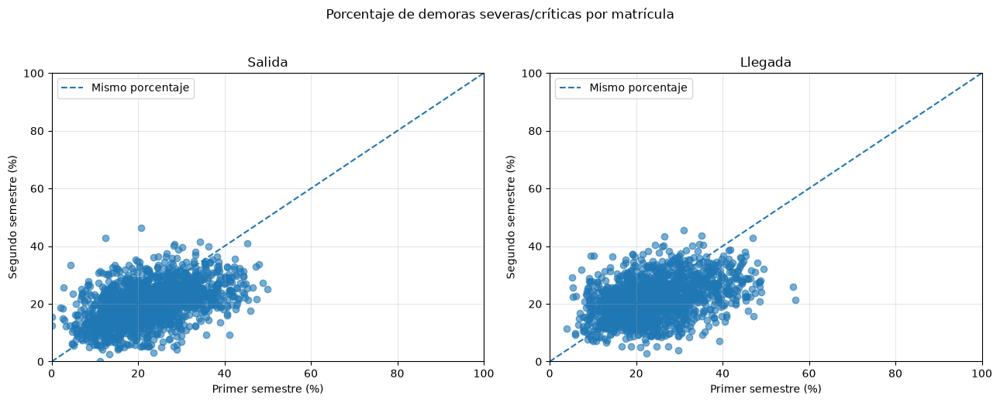


GRÁFICO 5. MATRÍCULAS QUE MÁS MEJORAN O EMPEORAN
Medimos el cambio en puntos porcentuales de demoras severas/críticas de llegada.
Un valor negativo indica una reducción; uno positivo, un aumento.


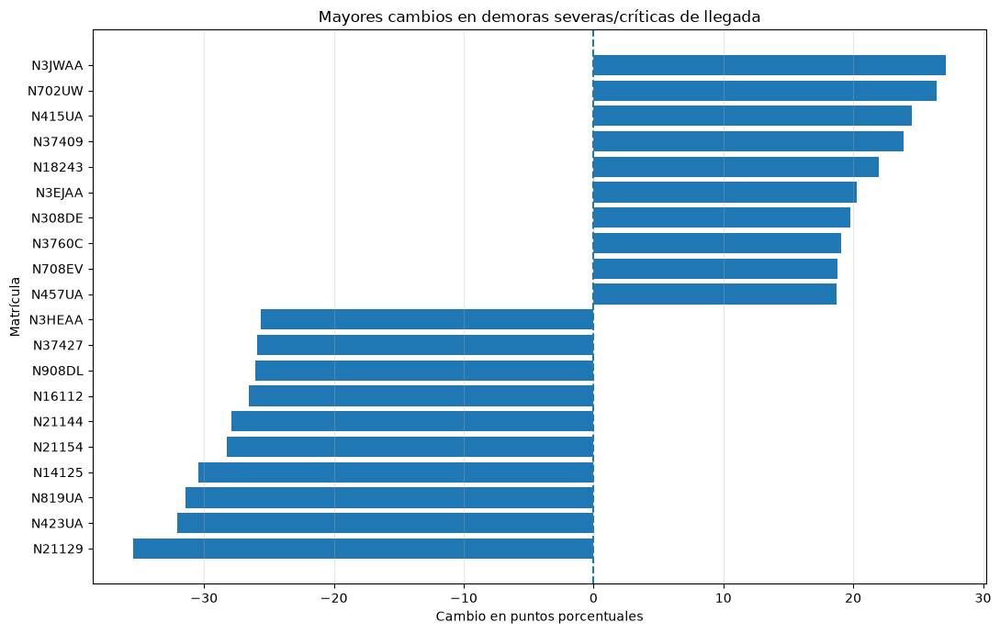


Mayores mejoras:
matricula_avion
N21129   -35.47
N423UA   -32.07
N819UA   -31.43
N14125   -30.44
N21154   -28.22
N21144   -27.89
N16112   -26.52
N908DL   -26.06
N37427   -25.88
N3HEAA   -25.64

Mayores empeoramientos:
matricula_avion
N3JWAA    27.14
N702UW    26.42
N415UA    24.55
N37409    23.90
N18243    21.96
N3EJAA    20.31
N308DE    19.75
N3760C    19.05
N708EV    18.78
N457UA    18.69


In [65]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.1.6. PERSISTENCIA DEL COMPORTAMIENTO A LO LARGO DEL AÑO")
print("Comparamos la puntualidad de las matrículas entre los dos semestres de 2013.")

# Columnas que necesitamos para este análisis
columnas_necesarias = [
    "año",
    "mes",
    "estado_vuelo",
    "matricula_avion",
    "demora_salida_min",
    "demora_arribo_min",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Seleccionamos vuelos operados de 2013
base = df.loc[
    df["estado_vuelo"].eq("operado")
    & pd.to_numeric(df["año"], errors="coerce").eq(2013)
].copy()

# Utilizamos el mes existente para determinar el semestre
mes = pd.to_numeric(base["mes"], errors="coerce")

base = base.loc[mes.between(1, 12)].copy()
mes = mes.loc[base.index]

# Variable auxiliar temporal: no se agrega al df original
semestres = ["Primer semestre", "Segundo semestre"]

base["_semestre_analisis"] = np.where(
    mes <= 6,
    "Primer semestre",
    "Segundo semestre"
)

# Nos aseguramos de que las demoras sean numéricas
base["demora_salida_min"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["demora_arribo_min"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

# Matrículas identificadas
base_matriculas = base.loc[
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").str.strip().ne("")
].copy()

MIN_VUELOS_SEMESTRE = 30

print("\nDATOS DEL ANÁLISIS")
print("-" * 45)
print(f"Vuelos operados de 2013: {len(base):,}")
print(f"Matrículas identificadas: {base_matriculas['matricula_avion'].nunique():,}")
print(f"Mínimo para comparar cada matrícula: {MIN_VUELOS_SEMESTRE} observaciones evaluables por semestre y etapa.")


# ============================================================
# 2. RESUMEN GENERAL POR SEMESTRE
# ============================================================

resultados_generales = []

for semestre in semestres:

    grupo = base.loc[
        base["_semestre_analisis"].eq(semestre)
    ]

    # Vuelos con demora de salida conocida
    salidas = grupo.loc[
        grupo["demora_salida_min"].notna()
    ]

    # Vuelos con demora de llegada conocida
    arribos = grupo.loc[
        grupo["demora_arribo_min"].notna()
    ]

    # Niveles de puntualidad evaluables.
    # Se utiliza "desconocido" tal como ya existe en df;
    # no creamos ni modificamos categorías.
    salida_nivel = grupo.loc[
        grupo["nivel_puntualidad_salida"].notna()
        & grupo["nivel_puntualidad_salida"].ne("desconocido")
    ]

    arribo_nivel = grupo.loc[
        grupo["nivel_puntualidad_arribo"].notna()
        & grupo["nivel_puntualidad_arribo"].ne("desconocido")
    ]

    resultados_generales.append({
        "semestre": semestre,

        "demora_media_salida": salidas["demora_salida_min"].mean(),
        "demora_media_arribo": arribos["demora_arribo_min"].mean(),

        "pct_tarde_salida": (
            100 * salidas["demora_salida_min"].gt(0).mean()
            if not salidas.empty else np.nan
        ),

        "pct_tarde_arribo": (
            100 * arribos["demora_arribo_min"].gt(0).mean()
            if not arribos.empty else np.nan
        ),

        "pct_severo_critico_salida": (
            100 * salida_nivel["nivel_puntualidad_salida"]
            .isin(["severo", "critico"]).mean()
            if not salida_nivel.empty else np.nan
        ),

        "pct_severo_critico_arribo": (
            100 * arribo_nivel["nivel_puntualidad_arribo"]
            .isin(["severo", "critico"]).mean()
            if not arribo_nivel.empty else np.nan
        ),

        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_general = (
    pd.DataFrame(resultados_generales)
    .set_index("semestre")
    .reindex(semestres)
)

print("\nRESUMEN GENERAL POR SEMESTRE")
print("-" * 45)

for semestre, fila in resumen_general.iterrows():

    print(f"\n{semestre}")
    print(f"Salidas evaluables: {fila['vuelos_salida']:,.0f}")
    print(f"Llegadas evaluables: {fila['vuelos_arribo']:,.0f}")
    print(f"Demora media de salida: {fila['demora_media_salida']:.2f} minutos")
    print(f"Demora media de llegada: {fila['demora_media_arribo']:.2f} minutos")
    print(f"Salidas con demora positiva: {fila['pct_tarde_salida']:.2f} %")
    print(f"Llegadas con demora positiva: {fila['pct_tarde_arribo']:.2f} %")
    print(f"Salidas severas/críticas: {fila['pct_severo_critico_salida']:.2f} %")
    print(f"Llegadas severas/críticas: {fila['pct_severo_critico_arribo']:.2f} %")


# ============================================================
# GRÁFICO 1. COMPARACIÓN GENERAL ENTRE SEMESTRES
# ============================================================

print("\nGRÁFICO 1. COMPARACIÓN GENERAL ENTRE SEMESTRES")
print("Observamos los cambios en la demora media, la frecuencia de vuelos demorados")
print("y la proporción de demoras severas/críticas.")

configuraciones_generales = [
    (
        "demora_media_salida",
        "demora_media_arribo",
        "Demora media",
        "Minutos"
    ),
    (
        "pct_tarde_salida",
        "pct_tarde_arribo",
        "Vuelos con demora positiva",
        "Porcentaje de vuelos (%)"
    ),
    (
        "pct_severo_critico_salida",
        "pct_severo_critico_arribo",
        "Demoras severas/críticas",
        "Porcentaje de vuelos (%)"
    )
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

x = np.arange(len(semestres))
ancho = 0.35

for ax, (metrica_salida, metrica_arribo, titulo, etiqueta) in zip(
    axes,
    configuraciones_generales
):
    barras_salida = ax.bar(
        x - ancho / 2,
        resumen_general[metrica_salida],
        ancho,
        label="Salida"
    )

    barras_arribo = ax.bar(
        x + ancho / 2,
        resumen_general[metrica_arribo],
        ancho,
        label="Llegada"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(["1.º semestre", "2.º semestre"])
    ax.set_title(titulo)
    ax.set_ylabel(etiqueta)
    ax.grid(axis="y", alpha=0.3)

    if "Porcentaje" in etiqueta:
        ax.set_ylim(
            0,
            min(
                110,
                max(
                    resumen_general[metrica_salida].max(),
                    resumen_general[metrica_arribo].max()
                ) * 1.15 + 1
            )
        )

    ax.legend()

plt.suptitle("Evolución general de la puntualidad durante 2013", y=1.04)
plt.tight_layout()
plt.show()


# ============================================================
# 3. RESUMEN POR MATRÍCULA Y SEMESTRE
# ============================================================

# Contamos únicamente niveles de puntualidad conocidos.
def contar_niveles_evaluables(serie):
    return (
        serie.notna() & serie.ne("desconocido")
    ).sum()


def contar_severos_criticos(serie):
    return serie.isin(["severo", "critico"]).sum()


resumen = (
    base_matriculas
    .groupby(["matricula_avion", "_semestre_analisis"])
    .agg(
        vuelos_operados=("matricula_avion", "size"),

        salidas_evaluables=("demora_salida_min", "count"),
        arribos_evaluables=("demora_arribo_min", "count"),

        demora_media_salida=("demora_salida_min", "mean"),
        demora_media_arribo=("demora_arribo_min", "mean"),

        salidas_con_demora=(
            "demora_salida_min",
            lambda s: s.dropna().gt(0).sum()
        ),

        arribos_con_demora=(
            "demora_arribo_min",
            lambda s: s.dropna().gt(0).sum()
        ),

        niveles_salida_evaluables=(
            "nivel_puntualidad_salida",
            contar_niveles_evaluables
        ),

        niveles_arribo_evaluables=(
            "nivel_puntualidad_arribo",
            contar_niveles_evaluables
        ),

        salidas_severas_criticas=(
            "nivel_puntualidad_salida",
            contar_severos_criticos
        ),

        arribos_severos_criticos=(
            "nivel_puntualidad_arribo",
            contar_severos_criticos
        )
    )
)

# Calculamos porcentajes a partir de los recuentos existentes
resumen["pct_tarde_salida"] = (
    100 * resumen["salidas_con_demora"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_tarde_arribo"] = (
    100 * resumen["arribos_con_demora"]
    / resumen["arribos_evaluables"].replace(0, np.nan)
)

resumen["pct_severo_critico_salida"] = (
    100 * resumen["salidas_severas_criticas"]
    / resumen["niveles_salida_evaluables"].replace(0, np.nan)
)

resumen["pct_severo_critico_arribo"] = (
    100 * resumen["arribos_severos_criticos"]
    / resumen["niveles_arribo_evaluables"].replace(0, np.nan)
)


# ============================================================
# 4. PREPARAR COMPARACIONES ENTRE SEMESTRES
# ============================================================

def crear_comparacion(metrica, cantidad_evaluable):
    """
    Devuelve una fila por matrícula y una columna por semestre.
    Solo incluye matrículas con al menos el mínimo de observaciones
    evaluables en ambos semestres.
    """

    valores = (
        resumen[metrica]
        .unstack("_semestre_analisis")
        .reindex(columns=semestres)
    )

    cantidades = (
        resumen[cantidad_evaluable]
        .unstack("_semestre_analisis")
        .reindex(columns=semestres)
    )

    suficientes = (
        cantidades[semestres[0]].ge(MIN_VUELOS_SEMESTRE)
        & cantidades[semestres[1]].ge(MIN_VUELOS_SEMESTRE)
    )

    valores_disponibles = valores[semestres].notna().all(axis=1)

    return valores.loc[suficientes & valores_disponibles].copy()


# Comparaciones de demora media
comparacion_media_salida = crear_comparacion(
    "demora_media_salida",
    "salidas_evaluables"
)

comparacion_media_arribo = crear_comparacion(
    "demora_media_arribo",
    "arribos_evaluables"
)

# Comparaciones de cualquier demora positiva
comparacion_tarde_salida = crear_comparacion(
    "pct_tarde_salida",
    "salidas_evaluables"
)

comparacion_tarde_arribo = crear_comparacion(
    "pct_tarde_arribo",
    "arribos_evaluables"
)

# Comparaciones de demoras severas/críticas
comparacion_severa_salida = crear_comparacion(
    "pct_severo_critico_salida",
    "niveles_salida_evaluables"
)

comparacion_severa_arribo = crear_comparacion(
    "pct_severo_critico_arribo",
    "niveles_arribo_evaluables"
)

print("\nMATRÍCULAS COMPARABLES ENTRE AMBOS SEMESTRES")
print("-" * 45)
print(f"Demora media de salida: {len(comparacion_media_salida):,}")
print(f"Demora media de llegada: {len(comparacion_media_arribo):,}")
print(f"% de salidas con demora: {len(comparacion_tarde_salida):,}")
print(f"% de llegadas con demora: {len(comparacion_tarde_arribo):,}")
print(f"% severo/crítico de salida: {len(comparacion_severa_salida):,}")
print(f"% severo/crítico de llegada: {len(comparacion_severa_arribo):,}")


# ============================================================
# FUNCIÓN PARA GRÁFICOS DE COMPARACIÓN ENTRE SEMESTRES
# ============================================================

def graficar_comparacion(
    datos,
    titulo,
    etiqueta,
    porcentajes=False
):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    etapas = [
        (axes[0], comparacion_media_salida if False else None)
    ]

    # Los datos se pasan como un diccionario para cada etapa.
    return fig, axes


# ============================================================
# GRÁFICO 2. DEMORA MEDIA POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 2. CAMBIO EN LA DEMORA MEDIA POR MATRÍCULA")
print("Cada punto representa una matrícula con suficientes vuelos en ambos semestres.")
print("La distancia respecto de la diagonal indica cuánto cambió su demora media.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, datos, etapa in [
    (axes[0], comparacion_media_salida, "Salida"),
    (axes[1], comparacion_media_arribo, "Llegada")
]:

    if datos.empty:
        ax.set_title(etapa)
        ax.text(
            0.5, 0.5,
            "Sin matrículas comparables",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        continue

    primero = datos["Primer semestre"]
    segundo = datos["Segundo semestre"]

    ax.scatter(primero, segundo, alpha=0.6)

    valores = pd.concat([primero, segundo]).dropna()
    minimo = valores.min()
    maximo = valores.max()

    if minimo == maximo:
        minimo -= 1
        maximo += 1

    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        linestyle="--",
        label="Misma demora media"
    )

    ax.set_xlim(minimo, maximo)
    ax.set_ylim(minimo, maximo)
    ax.set_xlabel("Primer semestre (minutos)")
    ax.set_ylabel("Segundo semestre (minutos)")
    ax.set_title(f"Demora media de {etapa.lower()}")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Persistencia de la demora media por matrícula", y=1.03)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. PORCENTAJE DE VUELOS CON DEMORA POSITIVA
# ============================================================

print("\nGRÁFICO 3. PERSISTENCIA DEL PORCENTAJE DE VUELOS DEMORADOS")
print("Comparamos el porcentaje de vuelos con demora positiva entre semestres.")
print("Por encima de la diagonal, el porcentaje es mayor en el segundo semestre.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, datos, etapa in [
    (axes[0], comparacion_tarde_salida, "Salida"),
    (axes[1], comparacion_tarde_arribo, "Llegada")
]:

    if datos.empty:
        ax.set_title(etapa)
        ax.text(
            0.5, 0.5,
            "Sin matrículas comparables",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        continue

    ax.scatter(
        datos["Primer semestre"],
        datos["Segundo semestre"],
        alpha=0.6
    )

    ax.plot([0, 100], [0, 100], linestyle="--", label="Mismo porcentaje")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Primer semestre (%)")
    ax.set_ylabel("Segundo semestre (%)")
    ax.set_title(etapa)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Porcentaje de vuelos demorados por matrícula", y=1.03)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 4. PORCENTAJE DE DEMORAS SEVERAS/CRÍTICAS
# ============================================================

print("\nGRÁFICO 4. PERSISTENCIA DE LAS DEMORAS SEVERAS/CRÍTICAS")
print("Comparamos la proporción de vuelos severos/críticos de cada matrícula.")
print("Los porcentajes se calculan sobre niveles de puntualidad evaluables.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, datos, etapa in [
    (axes[0], comparacion_severa_salida, "Salida"),
    (axes[1], comparacion_severa_arribo, "Llegada")
]:

    if datos.empty:
        ax.set_title(etapa)
        ax.text(
            0.5, 0.5,
            "Sin matrículas comparables",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        continue

    ax.scatter(
        datos["Primer semestre"],
        datos["Segundo semestre"],
        alpha=0.6
    )

    ax.plot([0, 100], [0, 100], linestyle="--", label="Mismo porcentaje")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Primer semestre (%)")
    ax.set_ylabel("Segundo semestre (%)")
    ax.set_title(etapa)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Porcentaje de demoras severas/críticas por matrícula", y=1.03)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 5. MATRÍCULAS QUE MEJORAN O EMPEORAN
# ============================================================

print("\nGRÁFICO 5. MATRÍCULAS QUE MÁS MEJORAN O EMPEORAN")
print("Medimos el cambio en puntos porcentuales de demoras severas/críticas de llegada.")
print("Un valor negativo indica una reducción; uno positivo, un aumento.")

if not comparacion_severa_arribo.empty:

    cambios = (
        comparacion_severa_arribo["Segundo semestre"]
        - comparacion_severa_arribo["Primer semestre"]
    )

    mejoras = cambios.nsmallest(10)
    empeoramientos = cambios.nlargest(10)

    seleccion = pd.concat([
        mejoras,
        empeoramientos
    ])

    seleccion = seleccion.loc[
        ~seleccion.index.duplicated()
    ].sort_values()

    plt.figure(figsize=(11, 7))

    barras = plt.barh(
        seleccion.index.astype(str),
        seleccion.values
    )

    plt.axvline(0, linestyle="--")
    plt.xlabel("Cambio en puntos porcentuales")
    plt.ylabel("Matrícula")
    plt.title("Mayores cambios en demoras severas/críticas de llegada")
    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\nMayores mejoras:")
    print(mejoras.round(2).to_string())

    print("\nMayores empeoramientos:")
    print(empeoramientos.sort_values(ascending=False).round(2).to_string())

else:
    print("No hay suficientes matrículas comparables para evaluar los cambios.")

##### 1.1.7. Características de operación de cada matrícula



**Objetivo:** comprender cómo se utiliza cada avión y si esas condiciones de operación se relacionan con su puntualidad.

Preguntas que vamos a investigar:

- ¿Una misma matrícula realiza siempre el mismo número de vuelo o diferentes números de vuelo durante el día?
- ¿Las matrículas que operan para más de una aerolínea presentan patrones diferentes de puntualidad?
- Cuando una matrícula trabaja para varias aerolíneas, ¿se observan diferencias de puntualidad según la aerolínea?
- ¿La cantidad de vuelos que realiza una matrícula durante el día se relaciona con su nivel de puntualidad?

**Enfoque del análisis:** distinguiremos entre la cantidad de vuelos operados, los números de vuelo que realiza y las aerolíneas asociadas a cada matrícula. Cuando un avión trabaje para varias aerolíneas, la comparación de puntualidad deberá tener en cuenta cuántos vuelos realizó con cada una.

La relación entre la cantidad de vuelos diarios y las demoras se estudiará inicialmente como una asociación. El posible efecto de una demora sobre los vuelos posteriores se analizará con mayor detalle en el bloque de efecto cascada.

1.1.7. CARACTERÍSTICAS DE OPERACIÓN DE CADA MATRÍCULA
Analizamos cómo se utilizan los aviones y su relación con la puntualidad.

DATOS UTILIZADOS
---------------------------------------------
Vuelos operados sin matrícula identificada: 0
Vuelos operados con matrícula identificada: 328,521
Matrículas analizadas: 4,037
Vuelos sin fecha programada válida para el análisis diario: 0

GRÁFICO 1. NÚMEROS DE VUELO POR MATRÍCULA Y DÍA
Analizamos si un mismo avión realiza un único número de vuelo
o distintos números de vuelo durante una misma jornada.
La agrupación diaria utiliza la fecha programada de salida.

Distribución de días de operación:
1 número de vuelo: 186,240 días (74.8 %)
2 números de vuelo: 48,889 días (19.6 %)
3 o más números: 13,964 días (5.6 %)
Sin número identificado: 0 días (0.0 %)


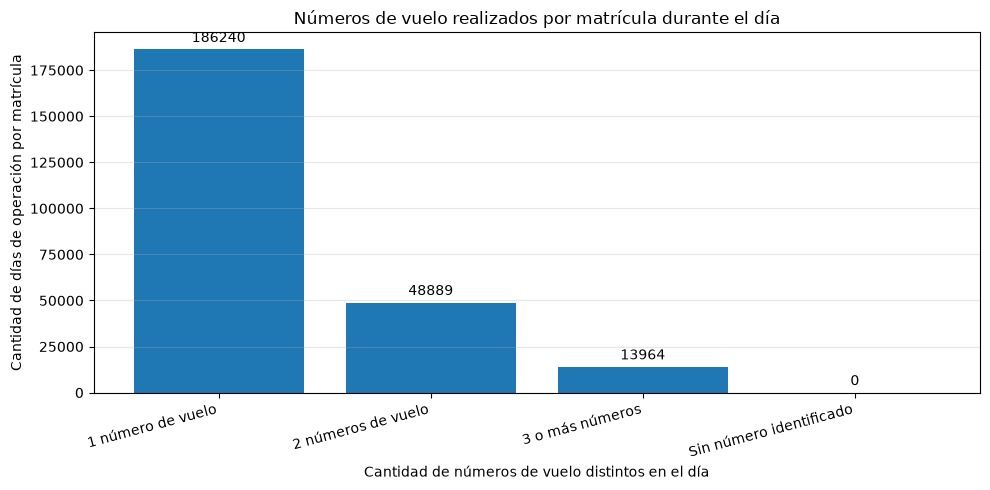


GRÁFICO 2. CANTIDAD DE AEROLÍNEAS POR MATRÍCULA
Identificamos cuántos aviones aparecen asociados a una o varias aerolíneas.
Utilizamos numero_aerolineas_por_matricula, que ya existe en df.

Matrículas asociadas a más de una aerolínea: 17


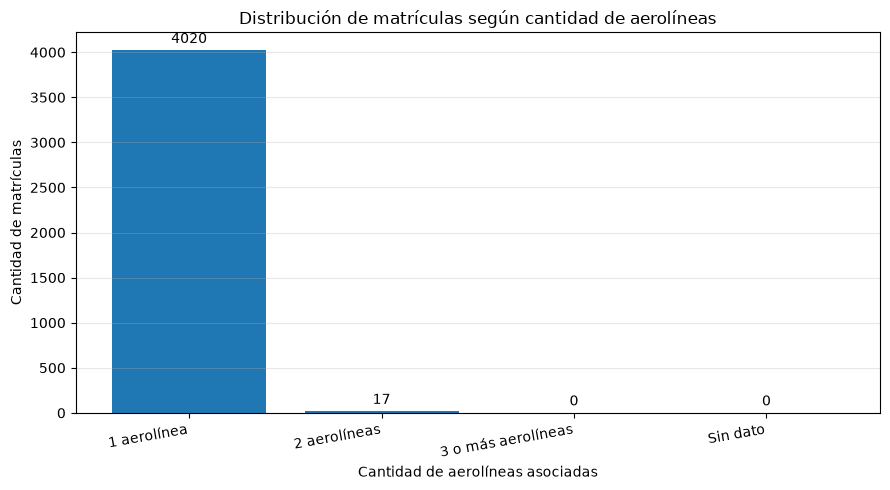


GRÁFICO 3. PUNTUALIDAD SEGÚN CANTIDAD DE AEROLÍNEAS
Comparamos el porcentaje de vuelos con demoras severas/críticas
entre aviones asociados a una o varias aerolíneas.
Los niveles desconocidos no se incluyen en el cálculo del porcentaje.
1 aerolínea: 327,721 salidas evaluables; 326,549 llegadas evaluables.
2 aerolíneas: 800 salidas evaluables; 797 llegadas evaluables.
3 o más aerolíneas: 0 salidas evaluables; 0 llegadas evaluables.


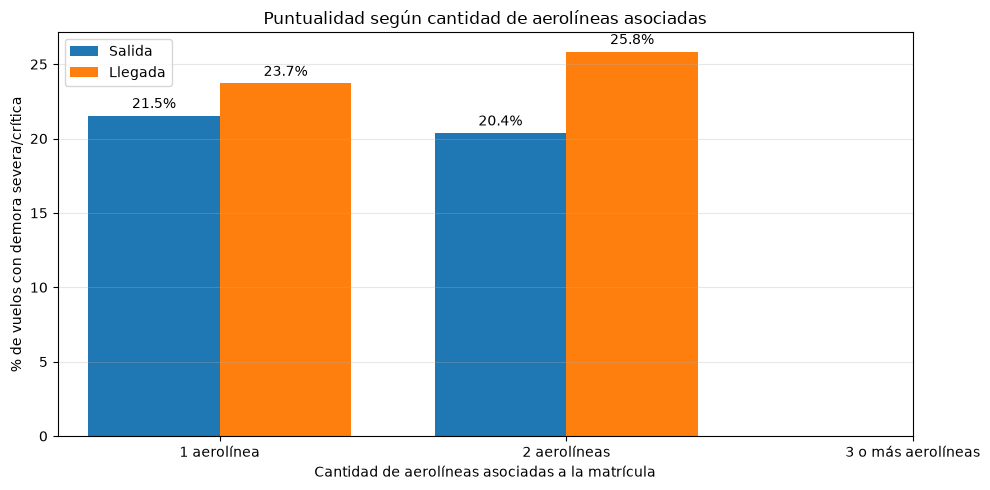


GRÁFICO 4. VUELOS DIARIOS Y PUNTUALIDAD
Analizamos si el porcentaje de demoras severas/críticas cambia
según la cantidad de vuelos que realiza un avión durante el día.
Esto es una asociación; el efecto de un vuelo sobre el siguiente
se analizará por separado en el bloque de efecto cascada.
1 vuelo: 186,233 salidas evaluables; 185,524 llegadas evaluables.
2 vuelos: 97,792 salidas evaluables; 97,453 llegadas evaluables.
3 vuelos: 34,185 salidas evaluables; 34,074 llegadas evaluables.
4 o más vuelos: 10,311 salidas evaluables; 10,295 llegadas evaluables.


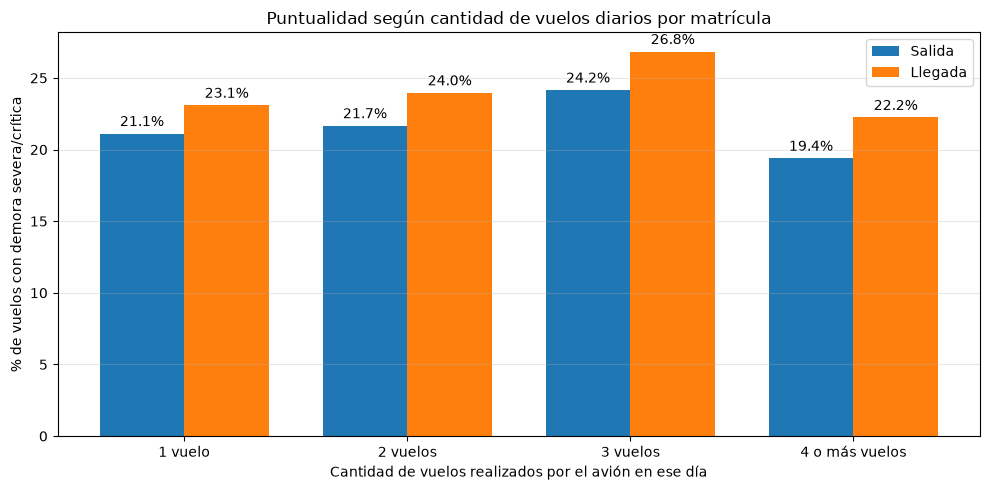


GRÁFICO 5. PUNTUALIDAD SEGÚN AEROLÍNEA PARA UNA MISMA MATRÍCULA
Comparamos las demoras severas/críticas de llegada para matrículas
que aparecen asociadas a más de una aerolínea.
Cada combinación matrícula-aerolínea requiere al menos 10 llegadas evaluables.


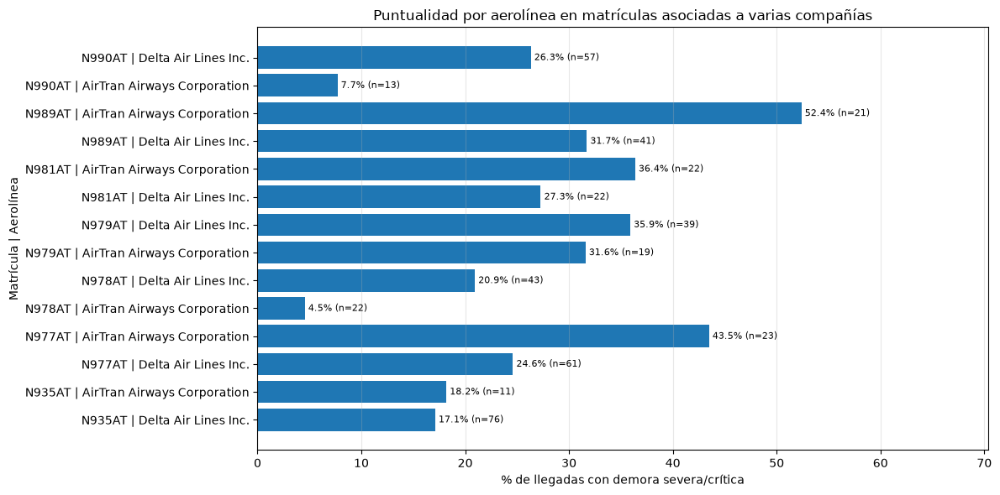


Matrículas comparables entre al menos dos aerolíneas: 7 en el gráfico.


In [66]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.1.7. CARACTERÍSTICAS DE OPERACIÓN DE CADA MATRÍCULA")
print("Analizamos cómo se utilizan los aviones y su relación con la puntualidad.")

columnas_necesarias = [
    "id",
    "estado_vuelo",
    "matricula_avion",
    "vuelo",
    "aerolinea",
    "nombre_aerolinea",
    "fecha_hora_salida_programada",
    "numero_aerolineas_por_matricula",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo",
    "demora_salida_min",
    "demora_arribo_min"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Trabajamos con vuelos operados, sin modificar df
base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Excluimos matrículas faltantes o vacías para los análisis por avión
matricula_valida = (
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").fillna("").str.strip().ne("")
)

sin_matricula = (~matricula_valida).sum()

base = base.loc[matricula_valida].copy()

# Fecha del día programado de salida.
# Se deriva temporalmente del datetime existente.
base["_fecha_dia_programada"] = (
    pd.to_datetime(
        base["fecha_hora_salida_programada"],
        errors="coerce"
    )
    .dt.normalize()
)

# Cantidad de aerolíneas por matrícula, usando la variable ya existente.
# Agrupamos para tener un único valor por avión.
resumen_aerolineas = (
    base.groupby("matricula_avion", as_index=False)
    .agg(
        numero_aerolineas=(
            "numero_aerolineas_por_matricula",
            "max"
        )
    )
)

# Incorporamos temporalmente este resumen a la copia de trabajo.
base = base.merge(
    resumen_aerolineas,
    on="matricula_avion",
    how="left",
    validate="many_to_one"
)

print("\nDATOS UTILIZADOS")
print("-" * 45)
print(f"Vuelos operados sin matrícula identificada: {sin_matricula:,}")
print(f"Vuelos operados con matrícula identificada: {len(base):,}")
print(f"Matrículas analizadas: {base['matricula_avion'].nunique():,}")
print(
    "Vuelos sin fecha programada válida para el análisis diario: "
    f"{base['_fecha_dia_programada'].isna().sum():,}"
)


# ============================================================
# GRÁFICO 1. NÚMEROS DE VUELO DIFERENTES POR AVIÓN Y DÍA
# ============================================================

print("\nGRÁFICO 1. NÚMEROS DE VUELO POR MATRÍCULA Y DÍA")
print("Analizamos si un mismo avión realiza un único número de vuelo")
print("o distintos números de vuelo durante una misma jornada.")
print("La agrupación diaria utiliza la fecha programada de salida.")

datos_diarios = base.dropna(
    subset=["_fecha_dia_programada"]
).copy()

operaciones_diarias = (
    datos_diarios
    .groupby(["matricula_avion", "_fecha_dia_programada"])
    .agg(
        vuelos_dia=("id", "size"),
        numeros_vuelo_distintos=("vuelo", "nunique")
    )
    .reset_index()
)

# Agrupamos los días de operación según la cantidad de números de vuelo distintos.
grupos_numeros = [
    "1 número de vuelo",
    "2 números de vuelo",
    "3 o más números",
    "Sin número identificado"
]

operaciones_diarias["_grupo_numeros"] = np.select(
    [
        operaciones_diarias["numeros_vuelo_distintos"].eq(1),
        operaciones_diarias["numeros_vuelo_distintos"].eq(2),
        operaciones_diarias["numeros_vuelo_distintos"].ge(3)
    ],
    [
        grupos_numeros[0],
        grupos_numeros[1],
        grupos_numeros[2]
    ],
    default=grupos_numeros[3]
)

distribucion_numeros = (
    operaciones_diarias["_grupo_numeros"]
    .value_counts()
    .reindex(grupos_numeros, fill_value=0)
)

total_dias_avion = len(operaciones_diarias)

print("\nDistribución de días de operación:")
for grupo, cantidad in distribucion_numeros.items():
    porcentaje = (
        100 * cantidad / total_dias_avion
        if total_dias_avion else 0
    )
    print(f"{grupo}: {cantidad:,} días ({porcentaje:.1f} %)")

plt.figure(figsize=(10, 5))

barras = plt.bar(
    distribucion_numeros.index,
    distribucion_numeros.values
)

plt.bar_label(barras, fmt="%.0f", padding=3)
plt.xlabel("Cantidad de números de vuelo distintos en el día")
plt.ylabel("Cantidad de días de operación por matrícula")
plt.title("Números de vuelo realizados por matrícula durante el día")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 2. CANTIDAD DE AEROLÍNEAS POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 2. CANTIDAD DE AEROLÍNEAS POR MATRÍCULA")
print("Identificamos cuántos aviones aparecen asociados a una o varias aerolíneas.")
print("Utilizamos numero_aerolineas_por_matricula, que ya existe en df.")

def grupo_aerolineas(cantidad):
    if pd.isna(cantidad):
        return "Sin dato"
    if cantidad == 1:
        return "1 aerolínea"
    if cantidad == 2:
        return "2 aerolíneas"
    if cantidad >= 3:
        return "3 o más aerolíneas"
    return "Sin dato"


resumen_aerolineas["_grupo_aerolineas"] = (
    resumen_aerolineas["numero_aerolineas"].map(grupo_aerolineas)
)

orden_aerolineas = [
    "1 aerolínea",
    "2 aerolíneas",
    "3 o más aerolíneas",
    "Sin dato"
]

distribucion_aerolineas = (
    resumen_aerolineas["_grupo_aerolineas"]
    .value_counts()
    .reindex(orden_aerolineas, fill_value=0)
)

matriculas_multiaerolinea = resumen_aerolineas.loc[
    resumen_aerolineas["numero_aerolineas"] > 1
]

print(
    f"\nMatrículas asociadas a más de una aerolínea: "
    f"{len(matriculas_multiaerolinea):,}"
)

plt.figure(figsize=(9, 5))

barras = plt.bar(
    distribucion_aerolineas.index,
    distribucion_aerolineas.values
)

plt.bar_label(barras, fmt="%.0f", padding=3)
plt.xlabel("Cantidad de aerolíneas asociadas")
plt.ylabel("Cantidad de matrículas")
plt.title("Distribución de matrículas según cantidad de aerolíneas")
plt.xticks(rotation=10, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. PUNTUALIDAD SEGÚN CANTIDAD DE AEROLÍNEAS
# ============================================================

print("\nGRÁFICO 3. PUNTUALIDAD SEGÚN CANTIDAD DE AEROLÍNEAS")
print("Comparamos el porcentaje de vuelos con demoras severas/críticas")
print("entre aviones asociados a una o varias aerolíneas.")
print("Los niveles desconocidos no se incluyen en el cálculo del porcentaje.")

grupos_aerolineas = [
    "1 aerolínea",
    "2 aerolíneas",
    "3 o más aerolíneas"
]

resultados_aerolineas = []

for grupo in grupos_aerolineas:

    if grupo == "1 aerolínea":
        registros = base.loc[
            base["numero_aerolineas"].eq(1)
        ]

    elif grupo == "2 aerolíneas":
        registros = base.loc[
            base["numero_aerolineas"].eq(2)
        ]

    else:
        registros = base.loc[
            base["numero_aerolineas"].ge(3)
        ]

    salidas = registros.loc[
        registros["nivel_puntualidad_salida"].notna()
        & registros["nivel_puntualidad_salida"].ne("desconocido")
    ]

    arribos = registros.loc[
        registros["nivel_puntualidad_arribo"].notna()
        & registros["nivel_puntualidad_arribo"].ne("desconocido")
    ]

    pct_salida = (
        100 * salidas["nivel_puntualidad_salida"]
        .isin(["severo", "critico"]).mean()
        if not salidas.empty else np.nan
    )

    pct_arribo = (
        100 * arribos["nivel_puntualidad_arribo"]
        .isin(["severo", "critico"]).mean()
        if not arribos.empty else np.nan
    )

    resultados_aerolineas.append({
        "grupo": grupo,
        "pct_salida": pct_salida,
        "pct_arribo": pct_arribo,
        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_puntualidad_aerolineas = (
    pd.DataFrame(resultados_aerolineas)
    .set_index("grupo")
    .reindex(grupos_aerolineas)
)

for grupo, fila in resumen_puntualidad_aerolineas.iterrows():
    print(
        f"{grupo}: "
        f"{fila['vuelos_salida']:,.0f} salidas evaluables; "
        f"{fila['vuelos_arribo']:,.0f} llegadas evaluables."
    )

x = np.arange(len(grupos_aerolineas))
ancho = 0.38

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_puntualidad_aerolineas["pct_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_puntualidad_aerolineas["pct_arribo"],
    ancho,
    label="Llegada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, grupos_aerolineas)
plt.xlabel("Cantidad de aerolíneas asociadas a la matrícula")
plt.ylabel("% de vuelos con demora severa/crítica")
plt.title("Puntualidad según cantidad de aerolíneas asociadas")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 4. CANTIDAD DE VUELOS DIARIOS Y PUNTUALIDAD
# ============================================================

print("\nGRÁFICO 4. VUELOS DIARIOS Y PUNTUALIDAD")
print("Analizamos si el porcentaje de demoras severas/críticas cambia")
print("según la cantidad de vuelos que realiza un avión durante el día.")
print("Esto es una asociación; el efecto de un vuelo sobre el siguiente")
print("se analizará por separado en el bloque de efecto cascada.")

# Para cada matrícula y fecha, contamos los vuelos operados.
# Luego asociamos esa cantidad a los vuelos de ese mismo avión y día.
base_diaria = datos_diarios.merge(
    operaciones_diarias[
        [
            "matricula_avion",
            "_fecha_dia_programada",
            "vuelos_dia"
        ]
    ],
    on=["matricula_avion", "_fecha_dia_programada"],
    how="left",
    validate="many_to_one"
)

grupos_vuelos_dia = [
    "1 vuelo",
    "2 vuelos",
    "3 vuelos",
    "4 o más vuelos"
]

base_diaria["_grupo_vuelos_dia"] = pd.cut(
    base_diaria["vuelos_dia"],
    bins=[0, 1, 2, 3, np.inf],
    labels=grupos_vuelos_dia
)

resultados_vuelos_diarios = []

for grupo in grupos_vuelos_dia:

    registros = base_diaria.loc[
        base_diaria["_grupo_vuelos_dia"].eq(grupo)
    ]

    salidas = registros.loc[
        registros["nivel_puntualidad_salida"].notna()
        & registros["nivel_puntualidad_salida"].ne("desconocido")
    ]

    arribos = registros.loc[
        registros["nivel_puntualidad_arribo"].notna()
        & registros["nivel_puntualidad_arribo"].ne("desconocido")
    ]

    pct_salida = (
        100 * salidas["nivel_puntualidad_salida"]
        .isin(["severo", "critico"]).mean()
        if not salidas.empty else np.nan
    )

    pct_arribo = (
        100 * arribos["nivel_puntualidad_arribo"]
        .isin(["severo", "critico"]).mean()
        if not arribos.empty else np.nan
    )

    resultados_vuelos_diarios.append({
        "grupo": grupo,
        "pct_salida": pct_salida,
        "pct_arribo": pct_arribo,
        "vuelos_salida": len(salidas),
        "vuelos_arribo": len(arribos)
    })

resumen_vuelos_diarios = (
    pd.DataFrame(resultados_vuelos_diarios)
    .set_index("grupo")
    .reindex(grupos_vuelos_dia)
)

for grupo, fila in resumen_vuelos_diarios.iterrows():
    print(
        f"{grupo}: "
        f"{fila['vuelos_salida']:,.0f} salidas evaluables; "
        f"{fila['vuelos_arribo']:,.0f} llegadas evaluables."
    )

x = np.arange(len(grupos_vuelos_dia))

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_vuelos_diarios["pct_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_vuelos_diarios["pct_arribo"],
    ancho,
    label="Llegada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, grupos_vuelos_dia)
plt.xlabel("Cantidad de vuelos realizados por el avión en ese día")
plt.ylabel("% de vuelos con demora severa/crítica")
plt.title("Puntualidad según cantidad de vuelos diarios por matrícula")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 5. PUNTUALIDAD POR AEROLÍNEA EN MATRÍCULAS MULTIAEROLÍNEA
# ============================================================

print("\nGRÁFICO 5. PUNTUALIDAD SEGÚN AEROLÍNEA PARA UNA MISMA MATRÍCULA")
print("Comparamos las demoras severas/críticas de llegada para matrículas")
print("que aparecen asociadas a más de una aerolínea.")
print("Cada combinación matrícula-aerolínea requiere al menos 10 llegadas evaluables.")

MIN_VUELOS_MATRICULA_AEROLINEA = 10

base_multiaerolinea = base.loc[
    base["numero_aerolineas"] > 1
].copy()

# Utilizamos niveles ya existentes y excluimos "desconocido" del denominador.
base_multiaerolinea = base_multiaerolinea.loc[
    base_multiaerolinea["nivel_puntualidad_arribo"].notna()
    & base_multiaerolinea["nivel_puntualidad_arribo"].ne("desconocido")
].copy()

comparacion_matricula_aerolinea = (
    base_multiaerolinea
    .groupby(
        ["matricula_avion", "aerolinea", "nombre_aerolinea"]
    )
    .agg(
        vuelos_evaluables=("nivel_puntualidad_arribo", "size"),
        vuelos_severos_criticos=(
            "nivel_puntualidad_arribo",
            lambda s: s.isin(["severo", "critico"]).sum()
        )
    )
    .reset_index()
)

comparacion_matricula_aerolinea["pct_severo_critico_arribo"] = (
    100
    * comparacion_matricula_aerolinea["vuelos_severos_criticos"]
    / comparacion_matricula_aerolinea["vuelos_evaluables"]
)

# Evitamos porcentajes basados en muy pocos vuelos
comparacion_matricula_aerolinea = (
    comparacion_matricula_aerolinea.loc[
        comparacion_matricula_aerolinea["vuelos_evaluables"]
        >= MIN_VUELOS_MATRICULA_AEROLINEA
    ].copy()
)

# Para comparar aerolíneas dentro del mismo avión,
# exigimos al menos dos aerolíneas con suficientes vuelos evaluables.
aerolineas_comparables = (
    comparacion_matricula_aerolinea
    .groupby("matricula_avion")["aerolinea"]
    .nunique()
)

matriculas_comparables_aerolineas = aerolineas_comparables.loc[
    aerolineas_comparables >= 2
].index

comparacion_matricula_aerolinea = (
    comparacion_matricula_aerolinea.loc[
        comparacion_matricula_aerolinea["matricula_avion"].isin(
            matriculas_comparables_aerolineas
        )
    ].copy()
)

if not comparacion_matricula_aerolinea.empty:

    # Seleccionamos hasta 10 matrículas con más vuelos comparables
    top_matriculas = (
        comparacion_matricula_aerolinea
        .groupby("matricula_avion")["vuelos_evaluables"]
        .sum()
        .nlargest(10)
        .index
    )

    grafico_aerolineas = (
        comparacion_matricula_aerolinea.loc[
            comparacion_matricula_aerolinea["matricula_avion"].isin(
                top_matriculas
            )
        ]
        .sort_values(
            ["matricula_avion", "pct_severo_critico_arribo"]
        )
        .copy()
    )

    etiquetas = (
        grafico_aerolineas["matricula_avion"].astype(str)
        + " | "
        + grafico_aerolineas["nombre_aerolinea"].astype(str)
    )

    plt.figure(
        figsize=(12, max(6, len(grafico_aerolineas) * 0.42))
    )

    barras = plt.barh(
        etiquetas,
        grafico_aerolineas["pct_severo_critico_arribo"]
    )

    etiquetas_barras = [
        f"{porcentaje:.1f}% (n={cantidad})"
        for porcentaje, cantidad in zip(
            grafico_aerolineas["pct_severo_critico_arribo"],
            grafico_aerolineas["vuelos_evaluables"]
        )
    ]

    plt.bar_label(
        barras,
        labels=etiquetas_barras,
        padding=3,
        fontsize=8
    )

    maximo = grafico_aerolineas["pct_severo_critico_arribo"].max()

    plt.xlim(0, min(120, maximo + 18))
    plt.xlabel("% de llegadas con demora severa/crítica")
    plt.ylabel("Matrícula | Aerolínea")
    plt.title("Puntualidad por aerolínea en matrículas asociadas a varias compañías")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(
        "\nMatrículas comparables entre al menos dos aerolíneas: "
        f"{len(top_matriculas):,} en el gráfico."
    )

else:
    print(
        "\nNo se encontraron matrículas con al menos dos aerolíneas "
        f"que tengan {MIN_VUELOS_MATRICULA_AEROLINEA} llegadas evaluables "
        "por combinación. No conviene forzar la comparación con muy pocos datos."
    )

##### 1.1.8. Relación entre la distancia recorrida y las demoras

**Objetivo:** analizar si la distancia del vuelo se relaciona con la puntualidad y determinar si una misma matrícula presenta comportamientos diferentes según la distancia que debe recorrer.

Preguntas que vamos a investigar:

- ¿Los vuelos de mayor distancia presentan más o menos demora de llegada?
- ¿Los vuelos cortos tienen más problemas de puntualidad que los vuelos largos?
- ¿A medida que aumenta la distancia, también aumenta la demora de llegada?
- ¿La distancia se relaciona de manera diferente con la demora de salida y con la demora de llegada?
- ¿Hay matrículas que presentan un buen nivel de puntualidad en vuelos cortos, pero más demoras en vuelos largos, o viceversa?
- ¿Las matrículas que acumulan mayores demoras suelen realizar vuelos de determinadas distancias?
- ¿Los aviones mantienen sus patrones de puntualidad independientemente de la distancia de sus vuelos?

**Enfoque del análisis:** utilizaremos la variable `distancia_nm` para comparar la puntualidad en vuelos de diferentes longitudes. Analizaremos tanto la demora de salida como la de llegada y, cuando corresponda, la diferencia entre ambas para estudiar si se recupera o se acumula tiempo durante el trayecto.

Primero observaremos la relación general entre distancia y demora. Después estudiaremos si el comportamiento cambia entre matrículas y, cuando sea útil, entre rutas.

No asumiremos que la distancia es la causa directa de una demora. También pueden influir la ruta, los aeropuertos de origen y destino, los horarios programados y otras condiciones operativas. Por eso, los resultados se interpretarán como asociaciones que pueden orientar investigaciones posteriores.

1.1.8. RELACIÓN ENTRE DISTANCIA RECORRIDA Y DEMORAS
Analizamos si la distancia del vuelo se relaciona con la puntualidad.

DATOS UTILIZADOS
---------------------------------------------
Vuelos operados: 328,521
Vuelos sin distancia identificada: 0
Matrículas identificadas: 4,037

GRUPOS DE DISTANCIA
---------------------------------------------
Corta: aproximadamente entre 80 y 659 nm
Media: aproximadamente entre 659 y 1085 nm
Larga: aproximadamente entre 1085 y 4983 nm

Los tres grupos contienen cantidades aproximadamente similares de vuelos, aunque las distancias repetidas pueden generar diferencias.

GRÁFICO 1. DISTANCIA Y DEMORA DE SALIDA/LLEGADA
Cada punto representa un vuelo operado.
Observamos si las demoras tienden a aumentar o disminuir con la distancia.
La visualización limita los ejes al rango central para facilitar la lectura.
Correlación de Spearman entre distancia y demora de salida: 0.076
Correlación de Spearman entre distancia y demora de llegada: -0.074


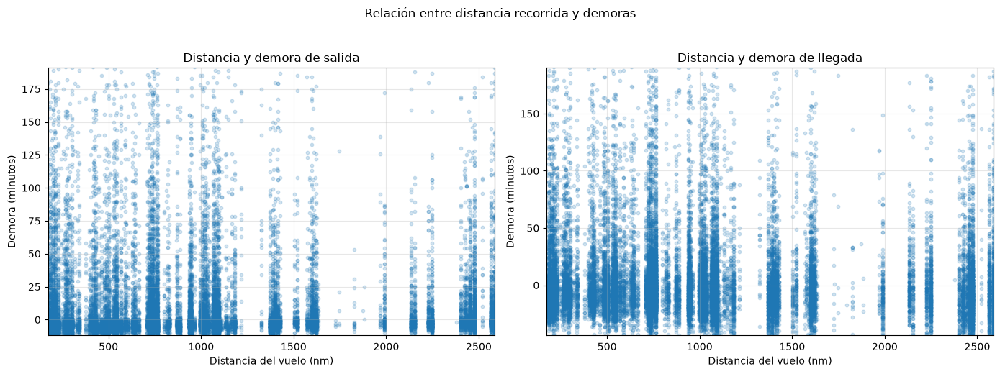


RESUMEN POR DISTANCIA
---------------------------------------------

Distancia corta
Vuelos operados: 109,619
Salidas con nivel evaluable: 109,619
Llegadas con nivel evaluable: 109,286
Demoras severas/críticas en salida: 22.75 %
Demoras severas/críticas en llegada: 24.63 %
Demora media de llegada: 9.23 minutos
Demora mediana de llegada: -4.00 minutos

Distancia media
Vuelos operados: 111,907
Salidas con nivel evaluable: 111,907
Llegadas con nivel evaluable: 111,528
Demoras severas/críticas en salida: 22.15 %
Demoras severas/críticas en llegada: 24.68 %
Demora media de llegada: 8.46 minutos
Demora mediana de llegada: -4.00 minutos

Distancia larga
Vuelos operados: 106,995
Salidas con nivel evaluable: 106,995
Llegadas con nivel evaluable: 106,532
Demoras severas/críticas en salida: 19.67 %
Demoras severas/críticas en llegada: 21.77 %
Demora media de llegada: 2.87 minutos
Demora mediana de llegada: -7.00 minutos

GRÁFICO 2. PORCENTAJE DE DEMORAS SEVERAS/CRÍTICAS POR DISTANCIA
Comparamos 

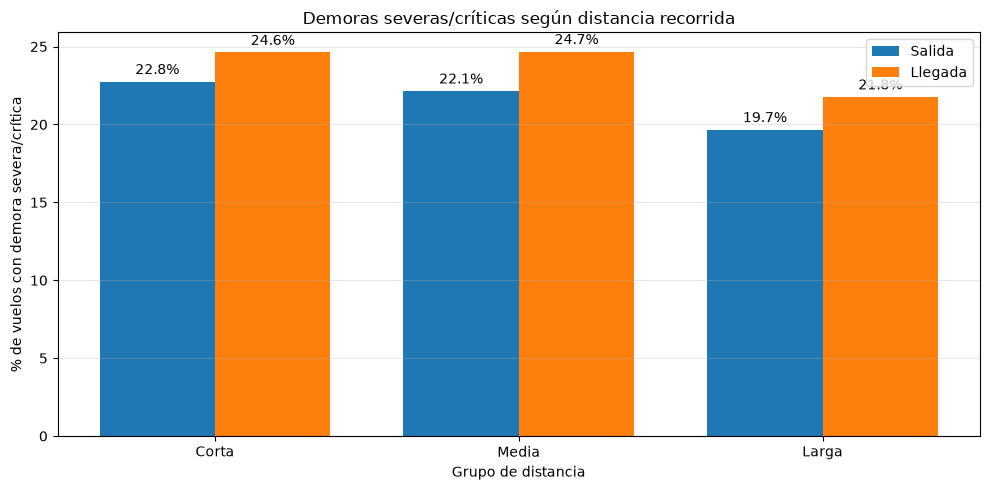


GRÁFICO 3. DEMORA MEDIANA SEGÚN DISTANCIA
Comparamos la demora mediana de salida y llegada para los tres grupos.
La mediana reduce la influencia de unos pocos vuelos con retrasos extremos.


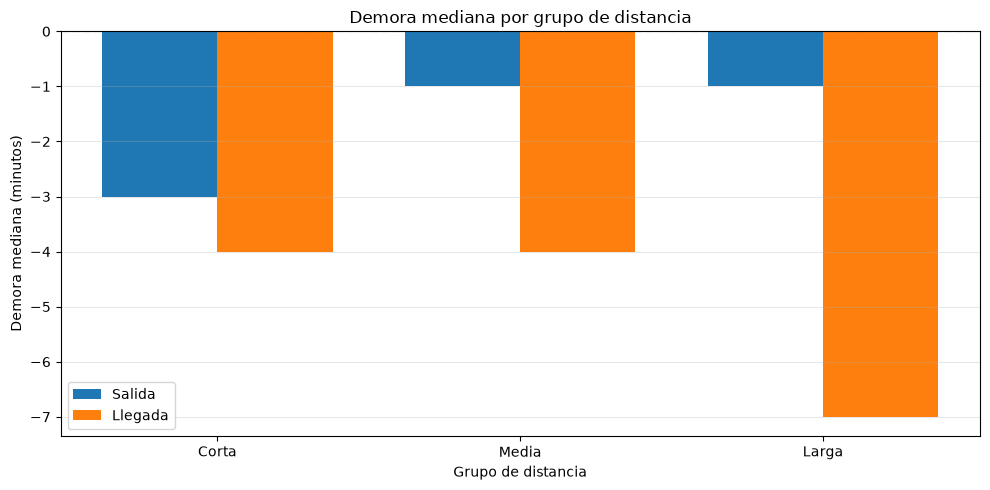


PREPARACIÓN DEL ANÁLISIS POR MATRÍCULA
Comparamos los niveles de puntualidad de cada avión en diferentes distancias.

GRÁFICO 4. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN DISTANCIA
Mostramos matrículas cuyo porcentaje de llegadas severas/críticas
cambia entre grupos de distancia.
Cada celda requiere al menos 10 llegadas evaluables; se muestran hasta 15 matrículas.
Las celdas vacías indican que no hay suficientes vuelos para comparar.


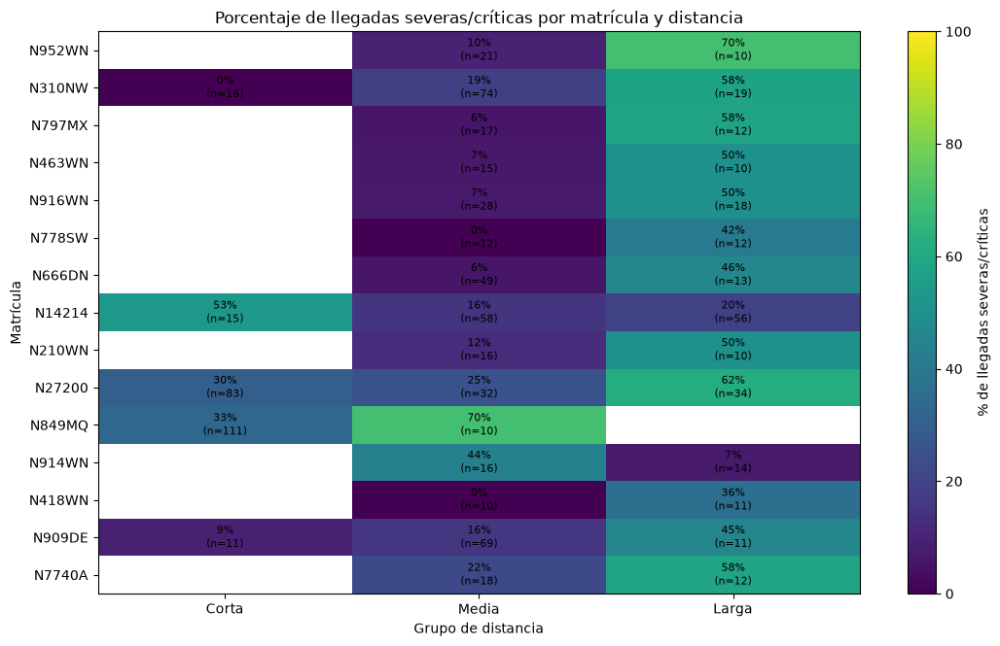


GRÁFICO 5. DISTANCIA Y PUNTUALIDAD POR RUTA
Cada punto representa una ruta.
Esto ayuda a observar si las rutas más largas también presentan
mayores porcentajes de llegadas severas/críticas.
Solo incluimos rutas con al menos 100 llegadas evaluables.
Rutas incluidas: 193
Correlación de Spearman entre distancia de ruta y porcentaje de llegadas severas/críticas: -0.215


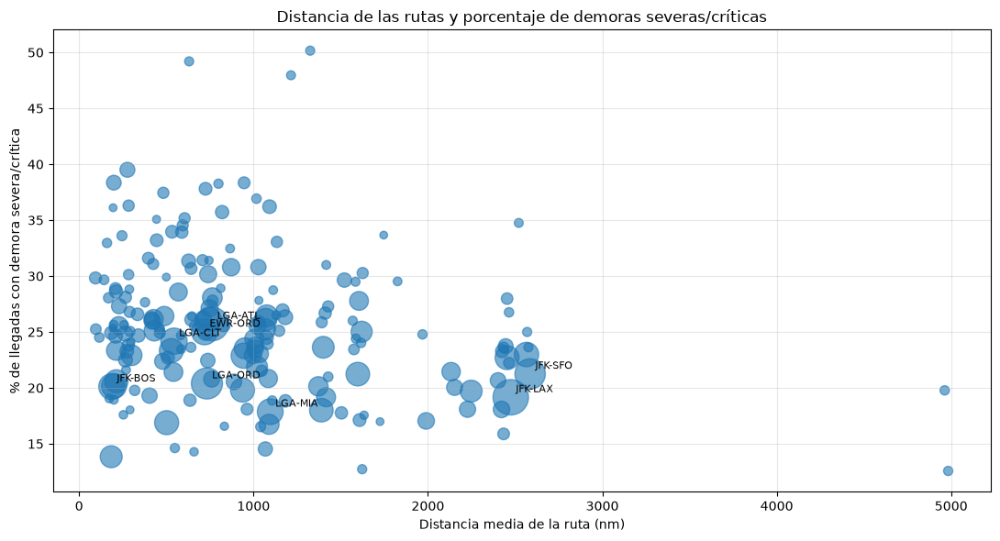

In [67]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.1.8. RELACIÓN ENTRE DISTANCIA RECORRIDA Y DEMORAS")
print("Analizamos si la distancia del vuelo se relaciona con la puntualidad.")

columnas_necesarias = [
    "estado_vuelo",
    "matricula_avion",
    "distancia_nm",
    "demora_salida_min",
    "demora_arribo_min",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo",
    "ruta"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Trabajamos sobre una copia para no modificar df
base = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

# Las demoras se convierten a números únicamente en la copia de trabajo
for columna in ["demora_salida_min", "demora_arribo_min"]:
    base[columna] = pd.to_numeric(
        base[columna],
        errors="coerce"
    )

base["distancia_nm"] = pd.to_numeric(
    base["distancia_nm"],
    errors="coerce"
)

# Indicadores temporales para reconocer demoras severas/críticas.
# Se reutilizan los niveles que ya existen en df.
base["_salida_severa_critica"] = (
    base["nivel_puntualidad_salida"].isin(["severo", "critico"])
)

base["_arribo_severo_critico"] = (
    base["nivel_puntualidad_arribo"].isin(["severo", "critico"])
)

print("\nDATOS UTILIZADOS")
print("-" * 45)
print(f"Vuelos operados: {len(base):,}")
print(
    "Vuelos sin distancia identificada: "
    f"{base['distancia_nm'].isna().sum():,}"
)
print(
    "Matrículas identificadas: "
    f"{base['matricula_avion'].nunique():,}"
)


# ============================================================
# 2. AGRUPAR LOS VUELOS SEGÚN LA DISTANCIA
# ============================================================

# Formamos tres grupos según la distribución real de distancias:
# corta, media y larga. Los límites se calculan con los terciles
# de distancia, no con límites fijados arbitrariamente.

distancias_validas = base["distancia_nm"].dropna()

if distancias_validas.nunique() < 3:
    raise ValueError(
        "No hay suficientes distancias distintas para formar tres grupos."
    )

codigos_distancia, limites_distancia = pd.qcut(
    distancias_validas,
    q=3,
    labels=False,
    retbins=True,
    duplicates="drop"
)

cantidad_grupos = len(limites_distancia) - 1

nombres_distancia = ["Corta", "Media", "Larga"][:cantidad_grupos]

# Esta variable se crea solamente en la copia de trabajo
base["_grupo_distancia"] = pd.Series(
    index=base.index,
    dtype="object"
)

codigos_distancia = codigos_distancia.astype(int)

base.loc[
    codigos_distancia.index,
    "_grupo_distancia"
] = codigos_distancia.map(
    {i: nombre for i, nombre in enumerate(nombres_distancia)}
)

grupos_distancia = nombres_distancia

print("\nGRUPOS DE DISTANCIA")
print("-" * 45)

for i, nombre in enumerate(grupos_distancia):
    minimo = limites_distancia[i]
    maximo = limites_distancia[i + 1]

    print(
        f"{nombre}: aproximadamente entre "
        f"{minimo:.0f} y {maximo:.0f} nm"
    )

print(
    "\nLos tres grupos contienen cantidades aproximadamente similares "
    "de vuelos, aunque las distancias repetidas pueden generar diferencias."
)


# ============================================================
# GRÁFICO 1. RELACIÓN GENERAL ENTRE DISTANCIA Y DEMORA
# ============================================================

print("\nGRÁFICO 1. DISTANCIA Y DEMORA DE SALIDA/LLEGADA")
print("Cada punto representa un vuelo operado.")
print("Observamos si las demoras tienden a aumentar o disminuir con la distancia.")
print("La visualización limita los ejes al rango central para facilitar la lectura.")

# Correlaciones de Spearman: útiles para evaluar una asociación monotónica
# sin exigir una relación lineal perfecta.
for columna, nombre in [
    ("demora_salida_min", "Salida"),
    ("demora_arribo_min", "Llegada")
]:
    datos_corr = base[
        ["distancia_nm", columna]
    ].dropna()

    correlacion = datos_corr["distancia_nm"].corr(
        datos_corr[columna],
        method="spearman"
    )

    print(
        f"Correlación de Spearman entre distancia y demora de {nombre.lower()}: "
        f"{correlacion:.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, columna, nombre in [
    (axes[0], "demora_salida_min", "Salida"),
    (axes[1], "demora_arribo_min", "Llegada")
]:
    datos = base[
        ["distancia_nm", columna]
    ].dropna()

    if len(datos) > 25000:
        datos = datos.sample(25000, random_state=42)

    if datos.empty:
        ax.set_title(nombre)
        ax.text(
            0.5, 0.5,
            "Sin datos evaluables",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        continue

    ax.scatter(
        datos["distancia_nm"],
        datos[columna],
        alpha=0.2,
        s=10
    )

    # Límites visuales basados en los percentiles 1 y 99
    x_min, x_max = base["distancia_nm"].quantile([0.01, 0.99])
    y_min, y_max = base[columna].quantile([0.01, 0.99])

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_xlabel("Distancia del vuelo (nm)")
    ax.set_ylabel("Demora (minutos)")
    ax.set_title(f"Distancia y demora de {nombre.lower()}")
    ax.grid(alpha=0.3)

plt.suptitle("Relación entre distancia recorrida y demoras", y=1.03)
plt.tight_layout()
plt.show()


# ============================================================
# 3. RESUMEN POR GRUPO DE DISTANCIA
# ============================================================

resultados_distancia = []

for grupo in grupos_distancia:
    datos = base.loc[
        base["_grupo_distancia"].eq(grupo)
    ]

    salidas = datos.loc[
        datos["nivel_puntualidad_salida"].notna()
        & datos["nivel_puntualidad_salida"].ne("desconocido")
    ]

    arribos = datos.loc[
        datos["nivel_puntualidad_arribo"].notna()
        & datos["nivel_puntualidad_arribo"].ne("desconocido")
    ]

    resultados_distancia.append({
        "grupo": grupo,
        "vuelos": len(datos),

        "salidas_evaluables": len(salidas),
        "arribos_evaluables": len(arribos),

        "pct_severo_critico_salida": (
            100 * salidas["_salida_severa_critica"].mean()
            if not salidas.empty else np.nan
        ),

        "pct_severo_critico_arribo": (
            100 * arribos["_arribo_severo_critico"].mean()
            if not arribos.empty else np.nan
        ),

        "demora_media_salida": datos["demora_salida_min"].mean(),
        "demora_media_arribo": datos["demora_arribo_min"].mean(),

        "demora_mediana_salida": datos["demora_salida_min"].median(),
        "demora_mediana_arribo": datos["demora_arribo_min"].median()
    })

resumen_distancia = (
    pd.DataFrame(resultados_distancia)
    .set_index("grupo")
    .reindex(grupos_distancia)
)

print("\nRESUMEN POR DISTANCIA")
print("-" * 45)

for grupo, fila in resumen_distancia.iterrows():
    print(f"\nDistancia {grupo.lower()}")
    print(f"Vuelos operados: {fila['vuelos']:,.0f}")
    print(f"Salidas con nivel evaluable: {fila['salidas_evaluables']:,.0f}")
    print(f"Llegadas con nivel evaluable: {fila['arribos_evaluables']:,.0f}")
    print(
        f"Demoras severas/críticas en salida: "
        f"{fila['pct_severo_critico_salida']:.2f} %"
    )
    print(
        f"Demoras severas/críticas en llegada: "
        f"{fila['pct_severo_critico_arribo']:.2f} %"
    )
    print(
        f"Demora media de llegada: "
        f"{fila['demora_media_arribo']:.2f} minutos"
    )
    print(
        f"Demora mediana de llegada: "
        f"{fila['demora_mediana_arribo']:.2f} minutos"
    )


# ============================================================
# GRÁFICO 2. DEMORAS SEVERAS/CRÍTICAS SEGÚN DISTANCIA
# ============================================================

print("\nGRÁFICO 2. PORCENTAJE DE DEMORAS SEVERAS/CRÍTICAS POR DISTANCIA")
print("Comparamos la proporción de demoras severas/críticas entre vuelos cortos, medios y largos.")
print("Los porcentajes excluyen los niveles 'desconocido' del denominador.")

x = np.arange(len(grupos_distancia))
ancho = 0.38

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_distancia["pct_severo_critico_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_distancia["pct_severo_critico_arribo"],
    ancho,
    label="Llegada"
)

plt.bar_label(barras_salida, fmt="%.1f%%", padding=3)
plt.bar_label(barras_arribo, fmt="%.1f%%", padding=3)

plt.xticks(x, grupos_distancia)
plt.xlabel("Grupo de distancia")
plt.ylabel("% de vuelos con demora severa/crítica")
plt.title("Demoras severas/críticas según distancia recorrida")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. DEMORA MEDIANA SEGÚN DISTANCIA
# ============================================================

print("\nGRÁFICO 3. DEMORA MEDIANA SEGÚN DISTANCIA")
print("Comparamos la demora mediana de salida y llegada para los tres grupos.")
print("La mediana reduce la influencia de unos pocos vuelos con retrasos extremos.")

plt.figure(figsize=(10, 5))

barras_salida = plt.bar(
    x - ancho / 2,
    resumen_distancia["demora_mediana_salida"],
    ancho,
    label="Salida"
)

barras_arribo = plt.bar(
    x + ancho / 2,
    resumen_distancia["demora_mediana_arribo"],
    ancho,
    label="Llegada"
)

plt.axhline(0, linestyle="--")

plt.xticks(x, grupos_distancia)
plt.xlabel("Grupo de distancia")
plt.ylabel("Demora mediana (minutos)")
plt.title("Demora mediana por grupo de distancia")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 4. RESUMEN DE DEMORAS POR MATRÍCULA Y DISTANCIA
# ============================================================

print("\nPREPARACIÓN DEL ANÁLISIS POR MATRÍCULA")
print("Comparamos los niveles de puntualidad de cada avión en diferentes distancias.")

MIN_VUELOS_MATRICULA_DISTANCIA = 10

# Solo usamos llegadas con nivel de puntualidad evaluable.
# Se reutiliza la categoría existente y se excluye 'desconocido'.
datos_matricula_distancia = base.loc[
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").str.strip().ne("")
    & base["_grupo_distancia"].notna()
    & base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
].copy()

resumen_matricula_distancia = (
    datos_matricula_distancia
    .groupby(["matricula_avion", "_grupo_distancia"])
    .agg(
        vuelos_evaluables=("nivel_puntualidad_arribo", "size"),
        vuelos_severos_criticos=(
            "_arribo_severo_critico",
            "sum"
        )
    )
)

resumen_matricula_distancia["pct_severo_critico"] = (
    100
    * resumen_matricula_distancia["vuelos_severos_criticos"]
    / resumen_matricula_distancia["vuelos_evaluables"]
)

matriz_pct = (
    resumen_matricula_distancia["pct_severo_critico"]
    .unstack("_grupo_distancia")
    .reindex(columns=grupos_distancia)
)

matriz_n = (
    resumen_matricula_distancia["vuelos_evaluables"]
    .unstack("_grupo_distancia")
    .reindex(columns=grupos_distancia)
)

# Ocultamos porcentajes que se calculan con menos de 10 vuelos
matriz_pct_filtrada = matriz_pct.where(
    matriz_n >= MIN_VUELOS_MATRICULA_DISTANCIA
)

# Necesitamos al menos dos grupos de distancia evaluables por matrícula
matriz_pct_filtrada = matriz_pct_filtrada.loc[
    matriz_pct_filtrada.notna().sum(axis=1) >= 2
]


# ============================================================
# GRÁFICO 4. MATRÍCULAS SEGÚN DISTANCIA
# ============================================================

print("\nGRÁFICO 4. PUNTUALIDAD DE CADA MATRÍCULA SEGÚN DISTANCIA")
print("Mostramos matrículas cuyo porcentaje de llegadas severas/críticas")
print("cambia entre grupos de distancia.")
print(
    f"Cada celda requiere al menos {MIN_VUELOS_MATRICULA_DISTANCIA} "
    "llegadas evaluables; se muestran hasta 15 matrículas."
)
print("Las celdas vacías indican que no hay suficientes vuelos para comparar.")

if not matriz_pct_filtrada.empty:

    variacion_matricula = (
        matriz_pct_filtrada.max(axis=1)
        - matriz_pct_filtrada.min(axis=1)
    )

    mejores_matriculas = (
        variacion_matricula
        .sort_values(ascending=False)
        .head(15)
        .index
    )

    matriz_grafico = matriz_pct_filtrada.loc[mejores_matriculas]
    matriz_n_grafico = matriz_n.loc[mejores_matriculas]

    fig, ax = plt.subplots(
        figsize=(11, max(5, len(matriz_grafico) * 0.45))
    )

    valores = matriz_grafico.to_numpy(dtype=float)

    imagen = ax.imshow(
        np.ma.masked_invalid(valores),
        aspect="auto",
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(len(grupos_distancia)))
    ax.set_xticklabels(grupos_distancia)

    ax.set_yticks(np.arange(len(matriz_grafico.index)))
    ax.set_yticklabels(matriz_grafico.index.astype(str))

    ax.set_xlabel("Grupo de distancia")
    ax.set_ylabel("Matrícula")
    ax.set_title("Porcentaje de llegadas severas/críticas por matrícula y distancia")

    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):

            valor = valores[i, j]
            cantidad = matriz_n_grafico.iloc[i, j]

            if np.isfinite(valor) and pd.notna(cantidad):
                ax.text(
                    j,
                    i,
                    f"{valor:.0f}%\n(n={int(cantidad)})",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        imagen,
        ax=ax,
        label="% de llegadas severas/críticas"
    )

    plt.tight_layout()
    plt.show()

else:
    print(
        "No hay suficientes matrículas con al menos "
        f"{MIN_VUELOS_MATRICULA_DISTANCIA} llegadas evaluables "
        "en dos grupos de distancia."
    )


# ============================================================
# GRÁFICO 5. DISTANCIA Y DEMORAS SEVERAS/CRÍTICAS POR RUTA
# ============================================================

print("\nGRÁFICO 5. DISTANCIA Y PUNTUALIDAD POR RUTA")
print("Cada punto representa una ruta.")
print("Esto ayuda a observar si las rutas más largas también presentan")
print("mayores porcentajes de llegadas severas/críticas.")
print("Solo incluimos rutas con al menos 100 llegadas evaluables.")

datos_rutas = base.loc[
    base["ruta"].notna()
    & base["distancia_nm"].notna()
    & base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
].copy()

resumen_rutas = (
    datos_rutas
    .groupby("ruta")
    .agg(
        vuelos_evaluables=("nivel_puntualidad_arribo", "size"),
        distancia_media=("distancia_nm", "mean"),
        pct_severo_critico=("_arribo_severo_critico", "mean")
    )
)

resumen_rutas["pct_severo_critico"] *= 100

resumen_rutas = resumen_rutas.loc[
    resumen_rutas["vuelos_evaluables"] >= 100
].copy()

if not resumen_rutas.empty:

    # Correlación de Spearman a nivel de ruta
    correlacion_rutas = resumen_rutas["distancia_media"].corr(
        resumen_rutas["pct_severo_critico"],
        method="spearman"
    )

    print(f"Rutas incluidas: {len(resumen_rutas):,}")
    print(
        "Correlación de Spearman entre distancia de ruta y porcentaje "
        f"de llegadas severas/críticas: {correlacion_rutas:.3f}"
    )

    plt.figure(figsize=(11, 6))

    plt.scatter(
        resumen_rutas["distancia_media"],
        resumen_rutas["pct_severo_critico"],
        s=30 + resumen_rutas["vuelos_evaluables"] / 15,
        alpha=0.6
    )

    # Etiquetamos las ocho rutas con mayor cantidad de vuelos evaluables
    rutas_etiquetadas = resumen_rutas.nlargest(
        8,
        "vuelos_evaluables"
    )

    for ruta, fila in rutas_etiquetadas.iterrows():
        plt.annotate(
            ruta,
            (
                fila["distancia_media"],
                fila["pct_severo_critico"]
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    plt.xlabel("Distancia media de la ruta (nm)")
    plt.ylabel("% de llegadas con demora severa/crítica")
    plt.title("Distancia de las rutas y porcentaje de demoras severas/críticas")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No hay rutas con al menos 100 llegadas evaluables.")

#### 1.2. Análisis del efecto cascada: vuelos sucesivos del mismo avión

Este bloque queda separado del análisis anterior porque no estudia solamente el comportamiento general de una matrícula, sino cómo una operación puede relacionarse con la siguiente.

Objetivo general

Investigar si las demoras de un vuelo se relacionan con la puntualidad de las operaciones posteriores del mismo avión y si el tiempo disponible entre vuelos influye en ese comportamiento.

Preguntas que vamos a investigar:

- ¿A medida que un avión realiza más vuelos durante el día, aumentan sus demoras?
- ¿La demora de un vuelo afecta al vuelo siguiente del mismo avión?
- ¿El tiempo disponible entre un vuelo y el siguiente influye en la puntualidad?
- ¿El primer vuelo del avión en el día presenta menos demoras que los vuelos posteriores?

**Enfoque del análisis:** tendremos en cuenta la secuencia real de operaciones, el orden de los vuelos y el tiempo disponible entre ellas. Para evaluar la relación con una demora anterior, será necesario identificar correctamente el vuelo previo del mismo avión, teniendo en cuenta el aeropuerto en el que se produjo cada operación.

También distinguiremos entre el tiempo transcurrido desde la llegada real de un vuelo anterior hasta la siguiente salida y el tiempo que estaba previsto entre las operaciones, cuando ambos datos estén disponibles.

Este bloque se relaciona con el análisis de matrículas, pero responde a preguntas diferentes: el primero busca reconocer patrones habituales de puntualidad; el segundo intenta estudiar posibles relaciones entre vuelos consecutivos.


1.2. ANÁLISIS DEL EFECTO CASCADA
Estudiamos si la secuencia de operaciones de un avión
se relaciona con las demoras de salida y llegada.

DATOS UTILIZADOS
---------------------------------------------
Vuelos operados con matrícula identificada: 328,521
Matrículas analizadas: 4,037

GRÁFICO 1. CANTIDAD DE VUELOS DIARIOS Y DEMORAS
Comparamos las demoras severas/críticas según cuántos vuelos
realiza una misma matrícula durante el día.
La cantidad diaria se calcula con las salidas reales registradas.
1 vuelo: 186,226 salidas evaluables y 185,515 llegadas evaluables.
2 vuelos: 97,778 salidas evaluables y 97,437 llegadas evaluables.
3 vuelos: 34,167 salidas evaluables y 34,059 llegadas evaluables.
4 o más vuelos: 10,350 salidas evaluables y 10,335 llegadas evaluables.


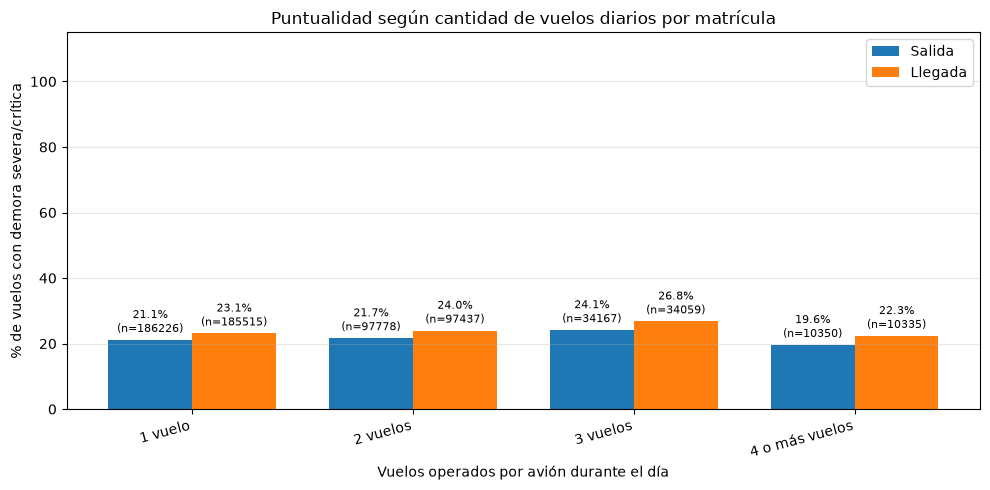


GRÁFICO 2. PUNTUALIDAD SEGÚN EL ORDEN DEL VUELO
Comparamos el primer vuelo del día con el segundo, el tercero
y los posteriores, utilizando numero_orden_vuelo_dia_real.
El orden se toma de la variable ya preparada en df.


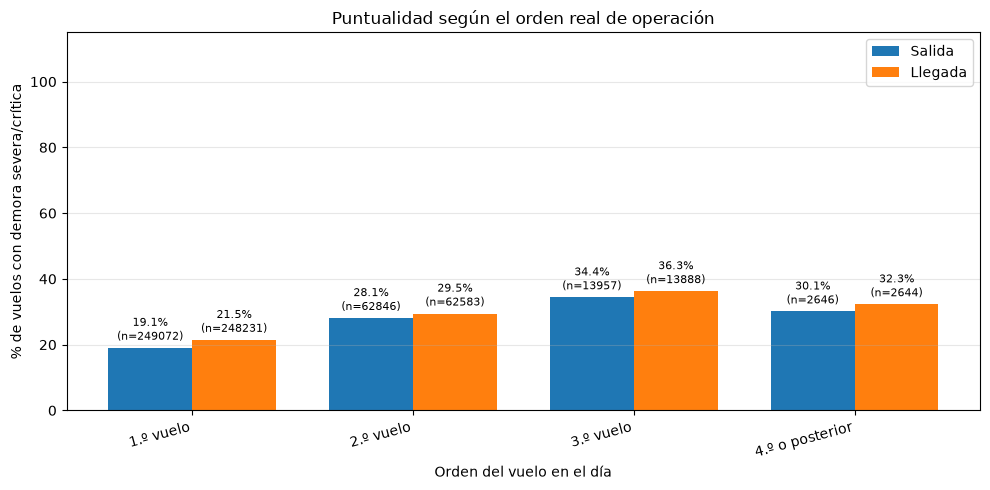


GRÁFICO 3. DEMORA DEL VUELO ANTERIOR Y DEMORAS DEL VUELO ACTUAL
Utilizamos retraso_vuelo_anterior_arribo para comparar la demora
de llegada anterior con la puntualidad de la operación actual.
Los grupos muestran si las demoras severas/críticas son más frecuentes
cuando el vuelo anterior llegó con mayor retraso.


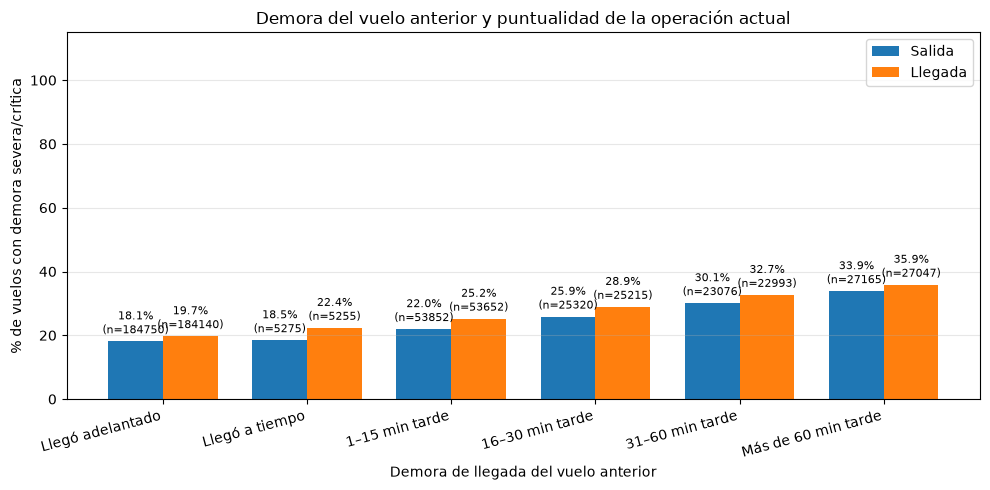


Correlación de Spearman entre la demora de llegada anterior y la demora de salida actual: 0.116
Operaciones con demora de llegada anterior disponible: 319,438

GRÁFICO 4. TIEMPO DESDE LA ÚLTIMA SALIDA REAL
Analizamos la puntualidad según cuánto tiempo pasó desde la última
salida real de esa matrícula desde el mismo aeropuerto de origen.
Este indicador mide separación entre salidas del mismo avión en ese origen;
no equivale al tiempo de escala desde la llegada de un vuelo.


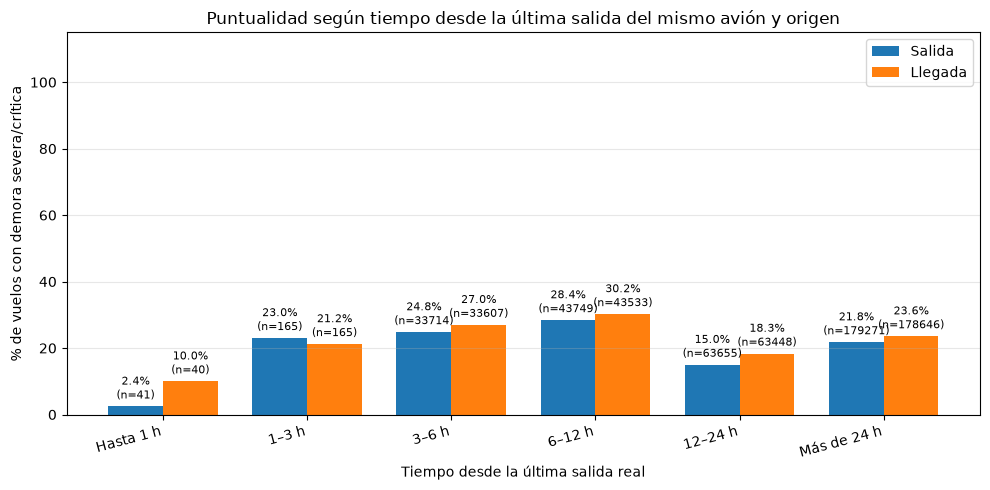


GRÁFICO 5. TIEMPO HASTA LA PRÓXIMA SALIDA PROGRAMADA
Comparamos la puntualidad según el intervalo programado hasta la próxima
salida de la misma matrícula desde el mismo aeropuerto.
Es un indicador de la separación entre salidas programadas,
no una medida exacta del tiempo disponible desde la llegada real.


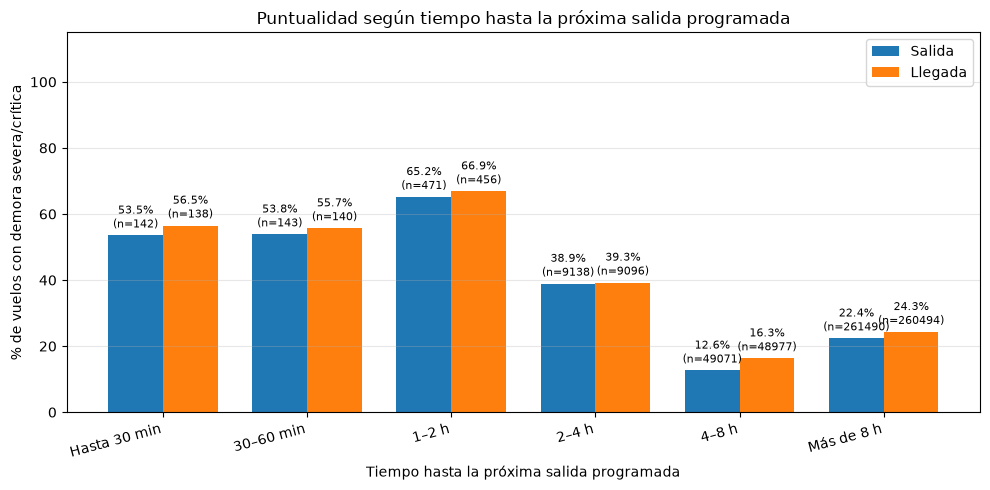

In [68]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.2. ANÁLISIS DEL EFECTO CASCADA")
print("Estudiamos si la secuencia de operaciones de un avión")
print("se relaciona con las demoras de salida y llegada.")

columnas_necesarias = [
    "estado_vuelo",
    "matricula_avion",
    "fecha_hora_salida_real",
    "numero_orden_vuelo_dia_real",
    "retraso_vuelo_anterior_salida",
    "retraso_vuelo_anterior_arribo",
    "tiempo_desde_ultima_salida_avion_origen",
    "tiempo_hasta_proxima_salida_avion_origen",
    "demora_salida_min",
    "demora_arribo_min",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Trabajamos únicamente con vuelos operados y matrículas identificadas.
# Todas las columnas auxiliares se crean en esta copia, no en df.
base = df.loc[
    df["estado_vuelo"].eq("operado")
    & df["matricula_avion"].notna()
    & df["matricula_avion"].astype("string").str.strip().ne("")
].copy()

# Nos aseguramos de que las demoras estén en minutos numéricos
for columna in [
    "demora_salida_min",
    "demora_arribo_min",
    "retraso_vuelo_anterior_salida",
    "retraso_vuelo_anterior_arribo"
]:
    base[columna] = pd.to_numeric(
        base[columna],
        errors="coerce"
    )

# Las dos variables de tiempo ya existen en df.
# Las convertimos a timedelta solo dentro de la copia de trabajo.
for columna in [
    "tiempo_desde_ultima_salida_avion_origen",
    "tiempo_hasta_proxima_salida_avion_origen"
]:
    base[columna] = pd.to_timedelta(
        base[columna],
        errors="coerce"
    )

# Función para calcular la proporción de demoras severas/críticas.
# Excluye los niveles "desconocido" del denominador.
def porcentaje_severo_critico(datos, columna_nivel, columna_demora):

    evaluables = datos.loc[
        datos[columna_demora].notna()
        & datos[columna_nivel].notna()
        & datos[columna_nivel].ne("desconocido")
    ]

    if evaluables.empty:
        return np.nan

    return (
        100
        * evaluables[columna_nivel]
        .isin(["severo", "critico"])
        .mean()
    )


# Función reutilizable para resumir y graficar por grupos.
def resumen_por_grupo(datos, columna_grupo, categorias):

    resultados = []

    for categoria in categorias:

        grupo = datos.loc[
            datos[columna_grupo].eq(categoria)
        ]

        salida_evaluable = grupo.loc[
            grupo["demora_salida_min"].notna()
            & grupo["nivel_puntualidad_salida"].notna()
            & grupo["nivel_puntualidad_salida"].ne("desconocido")
        ]

        arribo_evaluable = grupo.loc[
            grupo["demora_arribo_min"].notna()
            & grupo["nivel_puntualidad_arribo"].notna()
            & grupo["nivel_puntualidad_arribo"].ne("desconocido")
        ]

        resultados.append({
            "grupo": categoria,

            "pct_salida": porcentaje_severo_critico(
                grupo,
                "nivel_puntualidad_salida",
                "demora_salida_min"
            ),

            "pct_arribo": porcentaje_severo_critico(
                grupo,
                "nivel_puntualidad_arribo",
                "demora_arribo_min"
            ),

            "n_salida": len(salida_evaluable),
            "n_arribo": len(arribo_evaluable)
        })

    return pd.DataFrame(resultados).set_index("grupo")


def graficar_tasas(resumen, titulo, etiqueta_x):

    x = np.arange(len(resumen))
    ancho = 0.38

    fig, ax = plt.subplots(
        figsize=(max(10, len(resumen) * 1.5), 5)
    )

    barras_salida = ax.bar(
        x - ancho / 2,
        resumen["pct_salida"],
        ancho,
        label="Salida"
    )

    barras_arribo = ax.bar(
        x + ancho / 2,
        resumen["pct_arribo"],
        ancho,
        label="Llegada"
    )

    # Porcentaje y cantidad evaluable de cada etapa
    etiquetas_salida = [
        (
            f"{pct:.1f}%\n(n={int(n)})"
            if pd.notna(pct) else ""
        )
        for pct, n in zip(
            resumen["pct_salida"],
            resumen["n_salida"]
        )
    ]

    etiquetas_arribo = [
        (
            f"{pct:.1f}%\n(n={int(n)})"
            if pd.notna(pct) else ""
        )
        for pct, n in zip(
            resumen["pct_arribo"],
            resumen["n_arribo"]
        )
    ]

    ax.bar_label(
        barras_salida,
        labels=etiquetas_salida,
        padding=3,
        fontsize=8
    )

    ax.bar_label(
        barras_arribo,
        labels=etiquetas_arribo,
        padding=3,
        fontsize=8
    )

    ax.set_xticks(x)
    ax.set_xticklabels(resumen.index.astype(str), rotation=15, ha="right")
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("% de vuelos con demora severa/crítica")
    ax.set_title(titulo)
    ax.set_ylim(0, 115)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


print("\nDATOS UTILIZADOS")
print("-" * 45)
print(f"Vuelos operados con matrícula identificada: {len(base):,}")
print(f"Matrículas analizadas: {base['matricula_avion'].nunique():,}")


# ============================================================
# GRÁFICO 1. CANTIDAD DE VUELOS REALIZADOS POR DÍA
# ============================================================

print("\nGRÁFICO 1. CANTIDAD DE VUELOS DIARIOS Y DEMORAS")
print("Comparamos las demoras severas/críticas según cuántos vuelos")
print("realiza una misma matrícula durante el día.")
print("La cantidad diaria se calcula con las salidas reales registradas.")

# Fecha efectiva de salida: variable auxiliar de la copia de trabajo
base["_fecha_dia_real"] = (
    pd.to_datetime(
        base["fecha_hora_salida_real"],
        errors="coerce"
    )
    .dt.normalize()
)

datos_dia = base.dropna(
    subset=["_fecha_dia_real"]
).copy()

# Contamos los vuelos operados de cada matrícula en cada día real
conteo_diario = (
    datos_dia
    .groupby(["matricula_avion", "_fecha_dia_real"])
    .size()
    .rename("_cantidad_vuelos_dia")
    .reset_index()
)

# Asociamos la cantidad diaria a cada vuelo correspondiente
datos_dia = datos_dia.merge(
    conteo_diario,
    on=["matricula_avion", "_fecha_dia_real"],
    how="left",
    validate="many_to_one"
)

grupos_cantidad_diaria = [
    "1 vuelo",
    "2 vuelos",
    "3 vuelos",
    "4 o más vuelos"
]

datos_dia["_grupo_vuelos_dia"] = pd.cut(
    datos_dia["_cantidad_vuelos_dia"],
    bins=[0, 1, 2, 3, np.inf],
    labels=grupos_cantidad_diaria
)

resumen_diario = resumen_por_grupo(
    datos_dia,
    "_grupo_vuelos_dia",
    grupos_cantidad_diaria
)

for grupo, fila in resumen_diario.iterrows():
    print(
        f"{grupo}: "
        f"{fila['n_salida']:,.0f} salidas evaluables y "
        f"{fila['n_arribo']:,.0f} llegadas evaluables."
    )

graficar_tasas(
    resumen_diario,
    "Puntualidad según cantidad de vuelos diarios por matrícula",
    "Vuelos operados por avión durante el día"
)


# ============================================================
# GRÁFICO 2. PRIMER VUELO Y VUELOS POSTERIORES
# ============================================================

print("\nGRÁFICO 2. PUNTUALIDAD SEGÚN EL ORDEN DEL VUELO")
print("Comparamos el primer vuelo del día con el segundo, el tercero")
print("y los posteriores, utilizando numero_orden_vuelo_dia_real.")
print("El orden se toma de la variable ya preparada en df.")

base["_orden_real_analisis"] = pd.to_numeric(
    base["numero_orden_vuelo_dia_real"],
    errors="coerce"
)

datos_orden = base.loc[
    base["_orden_real_analisis"].notna()
].copy()

orden = datos_orden["_orden_real_analisis"].astype(float)

datos_orden["_grupo_orden_real"] = np.select(
    [
        orden.eq(1),
        orden.eq(2),
        orden.eq(3),
        orden.ge(4)
    ],
    [
        "1.º vuelo",
        "2.º vuelo",
        "3.º vuelo",
        "4.º o posterior"
    ],
    default="Sin orden"
)

grupos_orden = [
    "1.º vuelo",
    "2.º vuelo",
    "3.º vuelo",
    "4.º o posterior"
]

resumen_orden = resumen_por_grupo(
    datos_orden,
    "_grupo_orden_real",
    grupos_orden
)

graficar_tasas(
    resumen_orden,
    "Puntualidad según el orden real de operación",
    "Orden del vuelo en el día"
)


# ============================================================
# GRÁFICO 3. DEMORA DEL VUELO ANTERIOR Y PUNTUALIDAD ACTUAL
# ============================================================

print("\nGRÁFICO 3. DEMORA DEL VUELO ANTERIOR Y DEMORAS DEL VUELO ACTUAL")
print("Utilizamos retraso_vuelo_anterior_arribo para comparar la demora")
print("de llegada anterior con la puntualidad de la operación actual.")
print("Los grupos muestran si las demoras severas/críticas son más frecuentes")
print("cuando el vuelo anterior llegó con mayor retraso.")

datos_anterior = base.loc[
    base["retraso_vuelo_anterior_arribo"].notna()
].copy()

# Agrupamos la demora de llegada del vuelo anterior
# en rangos de minutos.
bins_anterior = [-np.inf, -1, 0, 15, 30, 60, np.inf]

grupos_anterior = [
    "Llegó adelantado",
    "Llegó a tiempo",
    "1–15 min tarde",
    "16–30 min tarde",
    "31–60 min tarde",
    "Más de 60 min tarde"
]

datos_anterior["_grupo_demora_anterior"] = pd.cut(
    datos_anterior["retraso_vuelo_anterior_arribo"].astype(float),
    bins=bins_anterior,
    labels=grupos_anterior
)

resumen_anterior = resumen_por_grupo(
    datos_anterior,
    "_grupo_demora_anterior",
    grupos_anterior
)

graficar_tasas(
    resumen_anterior,
    "Demora del vuelo anterior y puntualidad de la operación actual",
    "Demora de llegada del vuelo anterior"
)

# Calculamos la correlación entre la demora de llegada anterior
# y la demora de salida del vuelo actual.
correlacion_datos = base[
    [
        "retraso_vuelo_anterior_arribo",
        "demora_salida_min"
    ]
].dropna()

if (
    len(correlacion_datos) > 1
    and correlacion_datos["retraso_vuelo_anterior_arribo"].nunique() > 1
    and correlacion_datos["demora_salida_min"].nunique() > 1
):

    correlacion = correlacion_datos[
        "retraso_vuelo_anterior_arribo"
    ].corr(
        correlacion_datos["demora_salida_min"],
        method="spearman"
    )

    print(
        "\nCorrelación de Spearman entre la demora de llegada anterior "
        "y la demora de salida actual: "
        f"{correlacion:.3f}"
    )

print(
    f"Operaciones con demora de llegada anterior disponible: "
    f"{len(datos_anterior):,}"
)


# ============================================================
# GRÁFICO 4. TIEMPO DESDE LA ÚLTIMA SALIDA REAL
# DEL MISMO AVIÓN DESDE EL MISMO ORIGEN
# ============================================================

print("\nGRÁFICO 4. TIEMPO DESDE LA ÚLTIMA SALIDA REAL")
print("Analizamos la puntualidad según cuánto tiempo pasó desde la última")
print("salida real de esa matrícula desde el mismo aeropuerto de origen.")
print("Este indicador mide separación entre salidas del mismo avión en ese origen;")
print("no equivale al tiempo de escala desde la llegada de un vuelo.")

datos_ultima_salida = base.loc[
    base["tiempo_desde_ultima_salida_avion_origen"].notna()
].copy()

# Convertimos la duración a minutos solo en la copia de análisis
datos_ultima_salida["_min_desde_ultima_salida"] = (
    datos_ultima_salida[
        "tiempo_desde_ultima_salida_avion_origen"
    ].dt.total_seconds() / 60
)

# Excluimos duraciones negativas, que no representan un intervalo válido
datos_ultima_salida = datos_ultima_salida.loc[
    datos_ultima_salida["_min_desde_ultima_salida"] >= 0
].copy()

bins_tiempo_desde = [
    0, 60, 180, 360, 720, 1440, np.inf
]

grupos_tiempo_desde = [
    "Hasta 1 h",
    "1–3 h",
    "3–6 h",
    "6–12 h",
    "12–24 h",
    "Más de 24 h"
]

datos_ultima_salida["_grupo_tiempo_desde"] = pd.cut(
    datos_ultima_salida["_min_desde_ultima_salida"],
    bins=bins_tiempo_desde,
    labels=grupos_tiempo_desde
)

resumen_tiempo_desde = resumen_por_grupo(
    datos_ultima_salida,
    "_grupo_tiempo_desde",
    grupos_tiempo_desde
)

graficar_tasas(
    resumen_tiempo_desde,
    "Puntualidad según tiempo desde la última salida del mismo avión y origen",
    "Tiempo desde la última salida real"
)


# ============================================================
# GRÁFICO 5. TIEMPO HASTA LA PRÓXIMA SALIDA PROGRAMADA
# DEL MISMO AVIÓN DESDE EL MISMO ORIGEN
# ============================================================

print("\nGRÁFICO 5. TIEMPO HASTA LA PRÓXIMA SALIDA PROGRAMADA")
print("Comparamos la puntualidad según el intervalo programado hasta la próxima")
print("salida de la misma matrícula desde el mismo aeropuerto.")
print("Es un indicador de la separación entre salidas programadas,")
print("no una medida exacta del tiempo disponible desde la llegada real.")

datos_proxima_salida = base.loc[
    base["tiempo_hasta_proxima_salida_avion_origen"].notna()
].copy()

datos_proxima_salida["_min_hasta_proxima_salida"] = (
    datos_proxima_salida[
        "tiempo_hasta_proxima_salida_avion_origen"
    ].dt.total_seconds() / 60
)

datos_proxima_salida = datos_proxima_salida.loc[
    datos_proxima_salida["_min_hasta_proxima_salida"] >= 0
].copy()

bins_tiempo_hasta = [
    0, 30, 60, 120, 240, 480, np.inf
]

grupos_tiempo_hasta = [
    "Hasta 30 min",
    "30–60 min",
    "1–2 h",
    "2–4 h",
    "4–8 h",
    "Más de 8 h"
]

datos_proxima_salida["_grupo_tiempo_hasta"] = pd.cut(
    datos_proxima_salida["_min_hasta_proxima_salida"],
    bins=bins_tiempo_hasta,
    labels=grupos_tiempo_hasta
)

resumen_tiempo_hasta = resumen_por_grupo(
    datos_proxima_salida,
    "_grupo_tiempo_hasta",
    grupos_tiempo_hasta
)

graficar_tasas(
    resumen_tiempo_hasta,
    "Puntualidad según tiempo hasta la próxima salida programada",
    "Tiempo hasta la próxima salida programada"
)

#### 1.3. Relación entre las matrículas y el comportamiento de las aerolíneas


Aunque parte de esta pregunta puede estudiarse dentro de las características de operación, conviene conservar un bloque específico para conectar ambos análisis.

Objetivo general

Determinar si las demoras asociadas a una aerolínea se concentran en algunas matrículas o si aparecen de manera más extendida entre los aviones vinculados a esa compañía.

Preguntas que vamos a investigar:

- ¿Una aerolínea presenta muchas demoras porque un conjunto de aviones asociados a ella muestra patrones similares de puntualidad?
- ¿Las demoras se concentran en algunas matrículas o se distribuyen entre muchos aviones de la misma aerolínea?
- ¿Las matrículas con demoras recurrentes pertenecen principalmente a una misma aerolínea?
- ¿Los patrones de puntualidad de una matrícula se mantienen cuando opera para distintas aerolíneas?

**Enfoque del análisis:** primero identificaremos los patrones por matrícula y luego los relacionaremos con las aerolíneas. Esto permitirá distinguir entre un patrón concentrado en algunos aviones y otro que aparece en muchas matrículas vinculadas a una misma compañía.

No concluiremos que una aerolínea es responsable de las demoras únicamente porque algunos de sus aviones presenten malos resultados. También tendremos en cuenta la cantidad de vuelos, la distribución de las rutas, los horarios y la posible concentración de operaciones en determinadas matrículas.

1.3. RELACIÓN ENTRE MATRÍCULAS Y AEROLÍNEAS
Analizamos si las demoras se concentran en algunos aviones
o si se distribuyen entre muchas matrículas de una misma compañía.

DATOS UTILIZADOS
---------------------------------------------
Vuelos operados: 328,521
Vuelos operados con matrícula identificada: 328,521
Matrículas distintas identificadas: 4,037
Aerolíneas identificadas: 16
Mínimo para comparar matrícula-aerolínea: 30 vuelos evaluables por etapa.

GRÁFICO 1. PUNTUALIDAD GENERAL POR AEROLÍNEA
Comparamos el porcentaje de vuelos con demoras severas/críticas
de salida y llegada para cada aerolínea.
Los niveles desconocidos no se incluyen en el denominador.


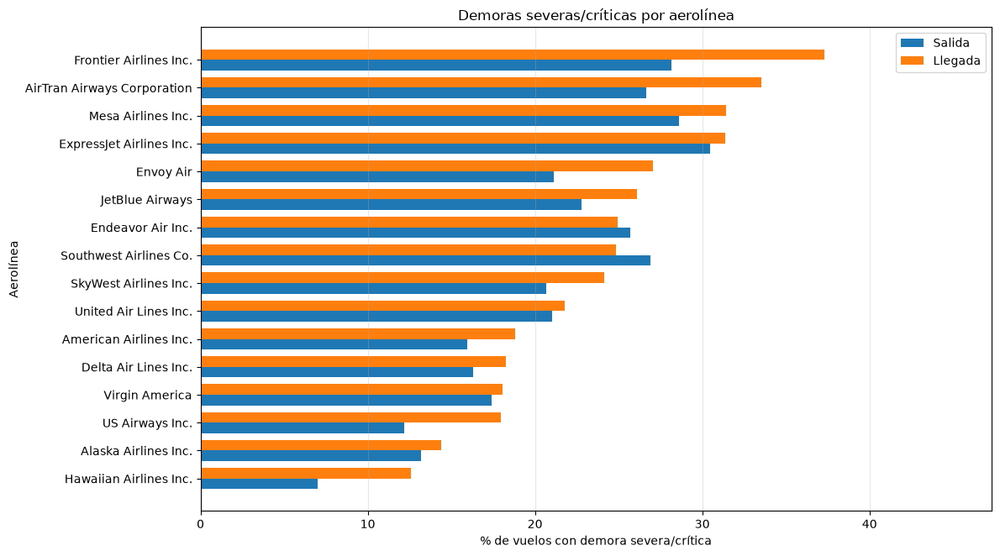


RESUMEN DE MATRÍCULAS POR AEROLÍNEA
---------------------------------------------
Combinaciones matrícula-aerolínea comparables: 2,718
Combinaciones con más del 30 % de demoras severas/críticas en ambas etapas: 230

GRÁFICO 2. MATRÍCULAS CON DEMORAS RECURRENTES POR AEROLÍNEA
Para cada aerolínea, calculamos qué proporción de las combinaciones
matrícula-aerolínea supera el 30 % de demoras severas/críticas
tanto en salida como en llegada.
Solo se incluyen combinaciones con al menos 30 observaciones evaluables por etapa.


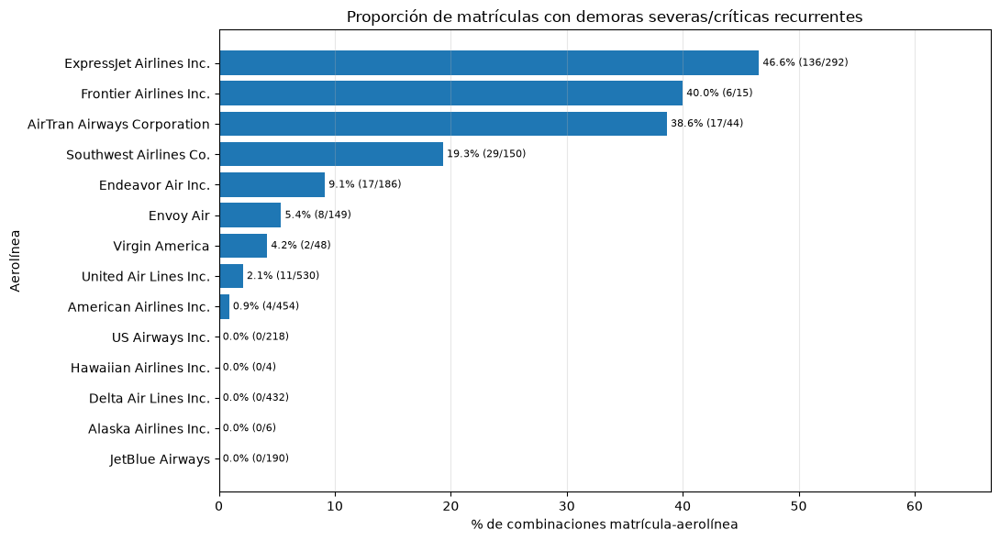


GRÁFICO 3. CONCENTRACIÓN DE DEMORAS EN MATRÍCULAS RECURRENTES
Medimos qué porcentaje de las llegadas severas/críticas de las
combinaciones comparables de cada aerolínea corresponde a matrículas
que superan el umbral del 30 % tanto en salida como en llegada.
Este porcentaje no incluye combinaciones con menos de 30 vuelos evaluables por etapa.


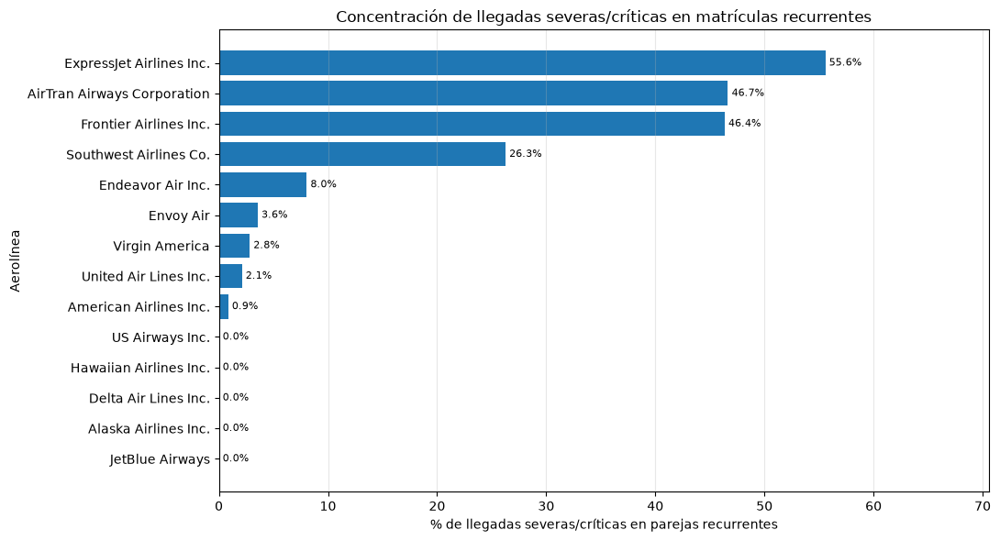


GRÁFICO 4. MATRÍCULAS CON DEMORAS RECURRENTES DENTRO DE CADA AEROLÍNEA
Mostramos las combinaciones matrícula-aerolínea que cumplen el criterio
de más del 30 % de demoras severas/críticas tanto en salida como en llegada.
Se muestran los porcentajes de llegada y el número de vuelos evaluables.


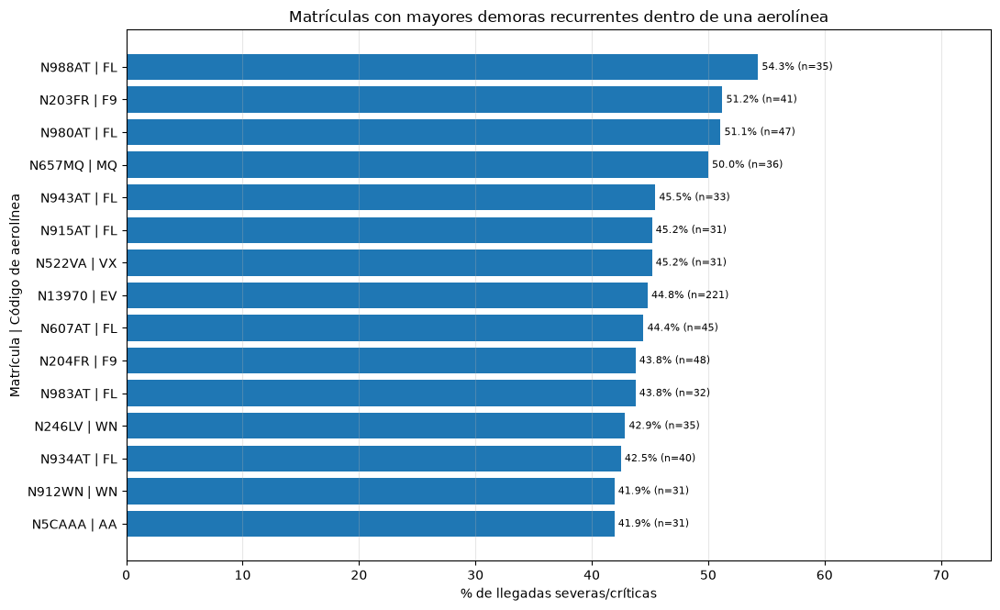


GRÁFICO 5. COMPARACIÓN DE UNA MATRÍCULA ENTRE AEROLÍNEAS
Buscamos aviones que aparecen asociados a más de una aerolínea
y comparamos su porcentaje de llegadas severas/críticas con cada compañía.
Se requieren al menos 10 llegadas evaluables por matrícula y aerolínea.


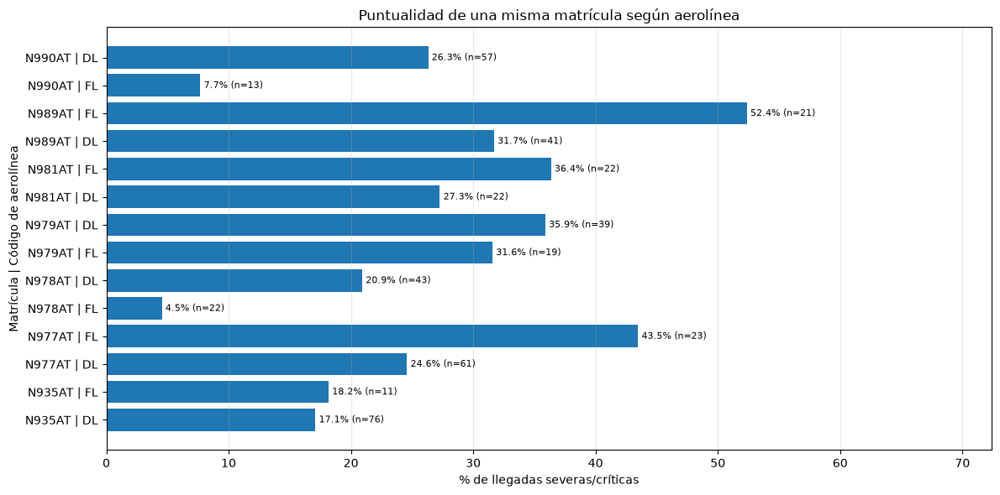


Matrículas comparables entre varias aerolíneas: 7


In [69]:
# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

print("1.3. RELACIÓN ENTRE MATRÍCULAS Y AEROLÍNEAS")
print("Analizamos si las demoras se concentran en algunos aviones")
print("o si se distribuyen entre muchas matrículas de una misma compañía.")

columnas_necesarias = [
    "id",
    "estado_vuelo",
    "matricula_avion",
    "aerolinea",
    "nombre_aerolinea",
    "numero_aerolineas_por_matricula",
    "nivel_puntualidad_salida",
    "nivel_puntualidad_arribo"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Trabajamos sobre una copia; df no se modifica
base = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()

# Separamos las operaciones con matrícula identificada.
# El resumen general por aerolínea utilizará todos los vuelos operados.
base_matriculas = base.loc[
    base["matricula_avion"].notna()
    & base["matricula_avion"].astype("string").str.strip().ne("")
].copy()

# Utilizamos las categorías que ya existen en df.
# Excluimos "desconocido" de los denominadores.
MIN_VUELOS_PAREJA = 30
UMBRAL_DEMORAS = 30

print("\nDATOS UTILIZADOS")
print("-" * 45)
print(f"Vuelos operados: {len(base):,}")
print(f"Vuelos operados con matrícula identificada: {len(base_matriculas):,}")
print(f"Matrículas distintas identificadas: {base_matriculas['matricula_avion'].nunique():,}")
print(f"Aerolíneas identificadas: {base['aerolinea'].nunique():,}")
print(f"Mínimo para comparar matrícula-aerolínea: {MIN_VUELOS_PAREJA} vuelos evaluables por etapa.")


# ============================================================
# 2. RESUMEN GENERAL POR AEROLÍNEA
# ============================================================

resumen_aerolineas = (
    base
    .groupby(["aerolinea", "nombre_aerolinea"])
    .agg(
        vuelos_operados=("id", "size"),

        salidas_evaluables=(
            "nivel_puntualidad_salida",
            lambda s: (s.notna() & s.ne("desconocido")).sum()
        ),

        llegadas_evaluables=(
            "nivel_puntualidad_arribo",
            lambda s: (s.notna() & s.ne("desconocido")).sum()
        ),

        salidas_severas_criticas=(
            "nivel_puntualidad_salida",
            lambda s: s.isin(["severo", "critico"]).sum()
        ),

        llegadas_severas_criticas=(
            "nivel_puntualidad_arribo",
            lambda s: s.isin(["severo", "critico"]).sum()
        ),

        matriculas=("matricula_avion", "nunique")
    )
    .reset_index()
)

resumen_aerolineas["pct_severo_critico_salida"] = (
    100 * resumen_aerolineas["salidas_severas_criticas"]
    / resumen_aerolineas["salidas_evaluables"].replace(0, np.nan)
)

resumen_aerolineas["pct_severo_critico_arribo"] = (
    100 * resumen_aerolineas["llegadas_severas_criticas"]
    / resumen_aerolineas["llegadas_evaluables"].replace(0, np.nan)
)


# ============================================================
# GRÁFICO 1. PUNTUALIDAD GENERAL POR AEROLÍNEA
# ============================================================

print("\nGRÁFICO 1. PUNTUALIDAD GENERAL POR AEROLÍNEA")
print("Comparamos el porcentaje de vuelos con demoras severas/críticas")
print("de salida y llegada para cada aerolínea.")
print("Los niveles desconocidos no se incluyen en el denominador.")

orden_aerolineas = (
    resumen_aerolineas
    .sort_values("pct_severo_critico_arribo", ascending=True)
    .copy()
)

y = np.arange(len(orden_aerolineas))
alto = 0.38

fig, ax = plt.subplots(
    figsize=(12, max(6, len(orden_aerolineas) * 0.42))
)

barras_salida = ax.barh(
    y - alto / 2,
    orden_aerolineas["pct_severo_critico_salida"],
    alto,
    label="Salida"
)

barras_arribo = ax.barh(
    y + alto / 2,
    orden_aerolineas["pct_severo_critico_arribo"],
    alto,
    label="Llegada"
)

ax.set_yticks(y)
ax.set_yticklabels(orden_aerolineas["nombre_aerolinea"])
ax.set_xlabel("% de vuelos con demora severa/crítica")
ax.set_ylabel("Aerolínea")
ax.set_title("Demoras severas/críticas por aerolínea")
ax.legend()
ax.grid(axis="x", alpha=0.3)

maximo = np.nanmax(
    orden_aerolineas[
        ["pct_severo_critico_salida", "pct_severo_critico_arribo"]
    ].to_numpy()
)

ax.set_xlim(0, min(110, maximo + 10))

plt.tight_layout()
plt.show()


# ============================================================
# 3. RESUMEN POR MATRÍCULA Y AEROLÍNEA
# ============================================================

# Calculamos las métricas para cada combinación matrícula-aerolínea.
# No agregamos estas variables al df original.

resumen_parejas = (
    base_matriculas
    .groupby(
        ["matricula_avion", "aerolinea", "nombre_aerolinea"]
    )
    .agg(
        vuelos_operados=("id", "size"),

        salidas_evaluables=(
            "nivel_puntualidad_salida",
            lambda s: (s.notna() & s.ne("desconocido")).sum()
        ),

        llegadas_evaluables=(
            "nivel_puntualidad_arribo",
            lambda s: (s.notna() & s.ne("desconocido")).sum()
        ),

        salidas_severas_criticas=(
            "nivel_puntualidad_salida",
            lambda s: s.isin(["severo", "critico"]).sum()
        ),

        llegadas_severas_criticas=(
            "nivel_puntualidad_arribo",
            lambda s: s.isin(["severo", "critico"]).sum()
        )
    )
    .reset_index()
)

resumen_parejas["pct_severo_critico_salida"] = (
    100 * resumen_parejas["salidas_severas_criticas"]
    / resumen_parejas["salidas_evaluables"].replace(0, np.nan)
)

resumen_parejas["pct_severo_critico_arribo"] = (
    100 * resumen_parejas["llegadas_severas_criticas"]
    / resumen_parejas["llegadas_evaluables"].replace(0, np.nan)
)

# Solo comparamos las combinaciones con suficientes observaciones
parejas_comparables = resumen_parejas.loc[
    (resumen_parejas["salidas_evaluables"] >= MIN_VUELOS_PAREJA)
    & (resumen_parejas["llegadas_evaluables"] >= MIN_VUELOS_PAREJA)
].copy()

# Aplicamos el criterio acordado: más del 30 % en ambas etapas
parejas_comportamiento_recurrente = parejas_comparables.loc[
    (parejas_comparables["pct_severo_critico_salida"] > UMBRAL_DEMORAS)
    & (parejas_comparables["pct_severo_critico_arribo"] > UMBRAL_DEMORAS)
].copy()

print("\nRESUMEN DE MATRÍCULAS POR AEROLÍNEA")
print("-" * 45)
print(f"Combinaciones matrícula-aerolínea comparables: {len(parejas_comparables):,}")
print(
    "Combinaciones con más del 30 % de demoras severas/críticas "
    f"en ambas etapas: {len(parejas_comportamiento_recurrente):,}"
)


# ============================================================
# RESUMEN DE CONCENTRACIÓN POR AEROLÍNEA
# ============================================================

resumen_concentracion = (
    parejas_comparables
    .groupby(["aerolinea", "nombre_aerolinea"])
    .agg(
        parejas_comparables=("matricula_avion", "size"),

        parejas_recurrentes=(
            "pct_severo_critico_arribo",
            lambda s: (
                (s > UMBRAL_DEMORAS)
                & (
                    parejas_comparables.loc[
                        s.index,
                        "pct_severo_critico_salida"
                    ] > UMBRAL_DEMORAS
                )
            ).sum()
        ),

        llegadas_severas_criticas=(
            "llegadas_severas_criticas", "sum"
        )
    )
    .reset_index()
)

# Porcentaje de combinaciones con demoras recurrentes
resumen_concentracion["pct_parejas_recurrentes"] = (
    100 * resumen_concentracion["parejas_recurrentes"]
    / resumen_concentracion["parejas_comparables"].replace(0, np.nan)
)

# Cantidad de llegadas severas/críticas de las parejas identificadas
incidentes_recurrentes = (
    parejas_comportamiento_recurrente
    .groupby(["aerolinea", "nombre_aerolinea"])
    ["llegadas_severas_criticas"]
    .sum()
    .rename("llegadas_severas_criticas_parejas_recurrentes")
    .reset_index()
)

resumen_concentracion = resumen_concentracion.merge(
    incidentes_recurrentes,
    on=["aerolinea", "nombre_aerolinea"],
    how="left",
    validate="one_to_one"
)

resumen_concentracion[
    "llegadas_severas_criticas_parejas_recurrentes"
] = resumen_concentracion[
    "llegadas_severas_criticas_parejas_recurrentes"
].fillna(0)

resumen_concentracion["pct_incidentes_en_parejas_recurrentes"] = (
    100
    * resumen_concentracion[
        "llegadas_severas_criticas_parejas_recurrentes"
    ]
    / resumen_concentracion[
        "llegadas_severas_criticas"
    ].replace(0, np.nan)
)


# ============================================================
# GRÁFICO 2. PORCENTAJE DE MATRÍCULAS CON DEMORAS RECURRENTES
# ============================================================

print("\nGRÁFICO 2. MATRÍCULAS CON DEMORAS RECURRENTES POR AEROLÍNEA")
print("Para cada aerolínea, calculamos qué proporción de las combinaciones")
print("matrícula-aerolínea supera el 30 % de demoras severas/críticas")
print("tanto en salida como en llegada.")
print(f"Solo se incluyen combinaciones con al menos {MIN_VUELOS_PAREJA} observaciones evaluables por etapa.")

orden_concentracion = (
    resumen_concentracion
    .sort_values("pct_parejas_recurrentes", ascending=True)
)

y = np.arange(len(orden_concentracion))

fig, ax = plt.subplots(
    figsize=(11, max(6, len(orden_concentracion) * 0.42))
)

barras = ax.barh(
    y,
    orden_concentracion["pct_parejas_recurrentes"]
)

ax.set_yticks(y)
ax.set_yticklabels(orden_concentracion["nombre_aerolinea"])
ax.set_xlabel("% de combinaciones matrícula-aerolínea")
ax.set_ylabel("Aerolínea")
ax.set_title("Proporción de matrículas con demoras severas/críticas recurrentes")
ax.grid(axis="x", alpha=0.3)

etiquetas = [
    f"{pct:.1f}% ({int(malas)}/{int(total)})"
    for pct, malas, total in zip(
        orden_concentracion["pct_parejas_recurrentes"],
        orden_concentracion["parejas_recurrentes"],
        orden_concentracion["parejas_comparables"]
    )
]

ax.bar_label(barras, labels=etiquetas, padding=3, fontsize=8)

maximo = orden_concentracion["pct_parejas_recurrentes"].max()
ax.set_xlim(0, min(120, maximo + 20))

plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. CONCENTRACIÓN DE LLEGADAS SEVERAS/CRÍTICAS
# ============================================================

print("\nGRÁFICO 3. CONCENTRACIÓN DE DEMORAS EN MATRÍCULAS RECURRENTES")
print("Medimos qué porcentaje de las llegadas severas/críticas de las")
print("combinaciones comparables de cada aerolínea corresponde a matrículas")
print("que superan el umbral del 30 % tanto en salida como en llegada.")
print("Este porcentaje no incluye combinaciones con menos de 30 vuelos evaluables por etapa.")

orden_incidentes = (
    resumen_concentracion
    .dropna(subset=["pct_incidentes_en_parejas_recurrentes"])
    .sort_values("pct_incidentes_en_parejas_recurrentes", ascending=True)
)

if not orden_incidentes.empty:

    y = np.arange(len(orden_incidentes))

    fig, ax = plt.subplots(
        figsize=(11, max(6, len(orden_incidentes) * 0.42))
    )

    barras = ax.barh(
        y,
        orden_incidentes["pct_incidentes_en_parejas_recurrentes"]
    )

    ax.set_yticks(y)
    ax.set_yticklabels(orden_incidentes["nombre_aerolinea"])
    ax.set_xlabel("% de llegadas severas/críticas en parejas recurrentes")
    ax.set_ylabel("Aerolínea")
    ax.set_title("Concentración de llegadas severas/críticas en matrículas recurrentes")
    ax.grid(axis="x", alpha=0.3)

    ax.bar_label(
        barras,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

    maximo = orden_incidentes["pct_incidentes_en_parejas_recurrentes"].max()
    ax.set_xlim(0, min(120, maximo + 15))

    plt.tight_layout()
    plt.show()

else:
    print("No hay suficientes incidentes evaluables para calcular esta proporción.")


# ============================================================
# GRÁFICO 4. MATRÍCULAS CON MAYOR PORCENTAJE DE DEMORAS RECURRENTES
# ============================================================

print("\nGRÁFICO 4. MATRÍCULAS CON DEMORAS RECURRENTES DENTRO DE CADA AEROLÍNEA")
print("Mostramos las combinaciones matrícula-aerolínea que cumplen el criterio")
print("de más del 30 % de demoras severas/críticas tanto en salida como en llegada.")
print("Se muestran los porcentajes de llegada y el número de vuelos evaluables.")

if not parejas_comportamiento_recurrente.empty:

    top_parejas = (
        parejas_comportamiento_recurrente
        .sort_values(
            ["pct_severo_critico_arribo", "llegadas_evaluables"],
            ascending=[False, False]
        )
        .head(15)
        .sort_values("pct_severo_critico_arribo", ascending=True)
        .copy()
    )

    etiquetas = (
        top_parejas["matricula_avion"].astype(str)
        + " | "
        + top_parejas["aerolinea"].astype(str)
    )

    fig, ax = plt.subplots(
        figsize=(11, max(6, len(top_parejas) * 0.45))
    )

    barras = ax.barh(
        etiquetas,
        top_parejas["pct_severo_critico_arribo"]
    )

    etiquetas_barras = [
        f"{pct:.1f}% (n={int(cantidad)})"
        for pct, cantidad in zip(
            top_parejas["pct_severo_critico_arribo"],
            top_parejas["llegadas_evaluables"]
        )
    ]

    ax.bar_label(
        barras,
        labels=etiquetas_barras,
        padding=3,
        fontsize=8
    )

    ax.set_xlabel("% de llegadas severas/críticas")
    ax.set_ylabel("Matrícula | Código de aerolínea")
    ax.set_title("Matrículas con mayores demoras recurrentes dentro de una aerolínea")
    ax.grid(axis="x", alpha=0.3)

    maximo = top_parejas["pct_severo_critico_arribo"].max()
    ax.set_xlim(0, min(120, maximo + 20))

    plt.tight_layout()
    plt.show()

else:
    print("Ninguna combinación matrícula-aerolínea cumple el criterio con suficientes datos.")


# ============================================================
# GRÁFICO 5. UNA MISMA MATRÍCULA ASOCIADA A VARIAS AEROLÍNEAS
# ============================================================

print("\nGRÁFICO 5. COMPARACIÓN DE UNA MATRÍCULA ENTRE AEROLÍNEAS")
print("Buscamos aviones que aparecen asociados a más de una aerolínea")
print("y comparamos su porcentaje de llegadas severas/críticas con cada compañía.")
print("Se requieren al menos 10 llegadas evaluables por matrícula y aerolínea.")

MIN_VUELOS_MULTIAEROLINEA = 10

# Aprovechamos la variable ya existente en df.
base_multiaerolinea = base_matriculas.loc[
    base_matriculas["numero_aerolineas_por_matricula"].gt(1).fillna(False)
].copy()

resumen_multiaerolinea = (
    base_multiaerolinea
    .groupby(["matricula_avion", "aerolinea", "nombre_aerolinea"])
    .agg(
        llegadas_evaluables=(
            "nivel_puntualidad_arribo",
            lambda s: (s.notna() & s.ne("desconocido")).sum()
        ),

        llegadas_severas_criticas=(
            "nivel_puntualidad_arribo",
            lambda s: s.isin(["severo", "critico"]).sum()
        )
    )
    .reset_index()
)

resumen_multiaerolinea["pct_severo_critico_arribo"] = (
    100
    * resumen_multiaerolinea["llegadas_severas_criticas"]
    / resumen_multiaerolinea["llegadas_evaluables"].replace(0, np.nan)
)

# Nos quedamos con las combinaciones con suficientes datos
resumen_multiaerolinea = resumen_multiaerolinea.loc[
    resumen_multiaerolinea["llegadas_evaluables"]
    >= MIN_VUELOS_MULTIAEROLINEA
].copy()

# La misma matrícula debe tener al menos dos aerolíneas comparables
cantidad_aerolineas_comparables = (
    resumen_multiaerolinea
    .groupby("matricula_avion")["aerolinea"]
    .nunique()
)

matriculas_comparables = cantidad_aerolineas_comparables.loc[
    cantidad_aerolineas_comparables >= 2
].index

resumen_multiaerolinea = resumen_multiaerolinea.loc[
    resumen_multiaerolinea["matricula_avion"].isin(
        matriculas_comparables
    )
].copy()

if not resumen_multiaerolinea.empty:

    # Identificamos matrículas cuya puntualidad más varía entre aerolíneas
    variacion = (
        resumen_multiaerolinea
        .groupby("matricula_avion")["pct_severo_critico_arribo"]
        .agg(lambda s: s.max() - s.min())
        .sort_values(ascending=False)
    )

    top_matriculas = variacion.head(10).index

    datos_grafico = (
        resumen_multiaerolinea.loc[
            resumen_multiaerolinea["matricula_avion"].isin(top_matriculas)
        ]
        .sort_values(
            ["matricula_avion", "pct_severo_critico_arribo"]
        )
        .copy()
    )

    etiquetas = (
        datos_grafico["matricula_avion"].astype(str)
        + " | "
        + datos_grafico["aerolinea"].astype(str)
    )

    fig, ax = plt.subplots(
        figsize=(12, max(6, len(datos_grafico) * 0.40))
    )

    barras = ax.barh(
        etiquetas,
        datos_grafico["pct_severo_critico_arribo"]
    )

    etiquetas_barras = [
        f"{pct:.1f}% (n={int(cantidad)})"
        for pct, cantidad in zip(
            datos_grafico["pct_severo_critico_arribo"],
            datos_grafico["llegadas_evaluables"]
        )
    ]

    ax.bar_label(
        barras,
        labels=etiquetas_barras,
        padding=3,
        fontsize=8
    )

    ax.set_xlabel("% de llegadas severas/críticas")
    ax.set_ylabel("Matrícula | Código de aerolínea")
    ax.set_title("Puntualidad de una misma matrícula según aerolínea")
    ax.grid(axis="x", alpha=0.3)

    maximo = datos_grafico["pct_severo_critico_arribo"].max()
    ax.set_xlim(0, min(120, maximo + 20))

    plt.tight_layout()
    plt.show()

    print(
        "\nMatrículas comparables entre varias aerolíneas: "
        f"{len(matriculas_comparables):,}"
    )

else:
    print(
        "No se encontraron matrículas asociadas a varias aerolíneas "
        f"con al menos {MIN_VUELOS_MULTIAEROLINEA} llegadas evaluables "
        "por compañía. No conviene forzar la comparación con tan pocos datos."
    )

###
---
---
---



### 2. Análisis por aerolínea

    Objetivo general

Determinar si los patrones de demora están relacionados con la aerolínea, su volumen de operaciones y la composición de su flota, identificando si las demoras se concentran en determinadas matrículas o si se distribuyen entre muchos aviones de una misma compañía.

    Resultado esperado

El análisis por aerolínea buscará:

- Identificar las compañías con mayor cantidad y proporción de vuelos demorados.
- Comparar la puntualidad de salida y llegada.
- Determinar si las demoras se concentran en algunas matrículas o se distribuyen entre muchos aviones.
- Relacionar los patrones de puntualidad de las matrículas con las aerolíneas a las que están asociadas.
- Investigar si la cantidad de vuelos diarios por avión se relaciona con la puntualidad de manera diferente según la compañía.
- Explorar la relación entre el número de vuelo y la distancia recorrida.
- Comparar los resultados entre los distintos tipos de aerolínea.

**Criterio general de interpretación:** no concluiremos que una aerolínea es responsable de las demoras únicamente porque tenga una gran cantidad de vuelos demorados o algunas matrículas con malos resultados. Tendremos en cuenta los porcentajes, la cantidad de operaciones y la distribución de las demoras entre los aviones para distinguir los patrones individuales de aquellos que aparecen en una parte más amplia de la flota.

#### 2.1. Datos generales y volumen de operaciones por aerolínea

**Objetivo:** conocer la distribución de los vuelos entre las aerolíneas y establecer una referencia para interpretar sus resultados de puntualidad.

Preguntas que vamos a investigar:

- ¿Cuántos vuelos operó cada aerolínea durante el período analizado?
- ¿Qué aerolíneas concentran la mayor cantidad de operaciones?
- ¿Cuántas matrículas diferentes aparecen asociadas a cada aerolínea?
- ¿Qué diferencias existen entre las aerolíneas con mayor y menor volumen de vuelos?

**Enfoque del análisis:** utilizaremos `aerolinea` para identificar los códigos de las compañías y `nombre_aerolinea` para facilitar la lectura de los resultados. También tendremos en cuenta la cantidad de vuelos de cada compañía, porque una aerolínea con más operaciones puede acumular más demoras en términos absolutos sin necesariamente presentar una peor puntualidad.

2.1. DATOS GENERALES Y VOLUMEN DE OPERACIONES POR AEROLÍNEA
Analizamos el volumen de operaciones y la cantidad de aviones
asociados a cada compañía.

RESUMEN GENERAL
--------------------------------------------------
Registros totales: 336,776
Vuelos operados: 328,521
Vuelos cancelados: 8,255
Vuelos operados sin matrícula identificada: 0
Matrículas distintas identificadas en vuelos operados: 4,037
Aerolíneas identificadas: 16

AEROLÍNEAS CON MAYOR VOLUMEN DE OPERACIONES
--------------------------------------------------
UA - United Air Lines Inc.: 57,979 vuelos operados
B6 - JetBlue Airways: 54,169 vuelos operados
EV - ExpressJet Airlines Inc.: 51,356 vuelos operados
DL - Delta Air Lines Inc.: 47,761 vuelos operados
AA - American Airlines Inc.: 32,093 vuelos operados

AEROLÍNEAS CON MENOR VOLUMEN DE OPERACIONES
--------------------------------------------------
OO - SkyWest Airlines Inc.: 29 vuelos operados
HA - Hawaiian Airlines Inc.: 342 vuelos operados
YV - Mesa Airlines Inc.: 545 v

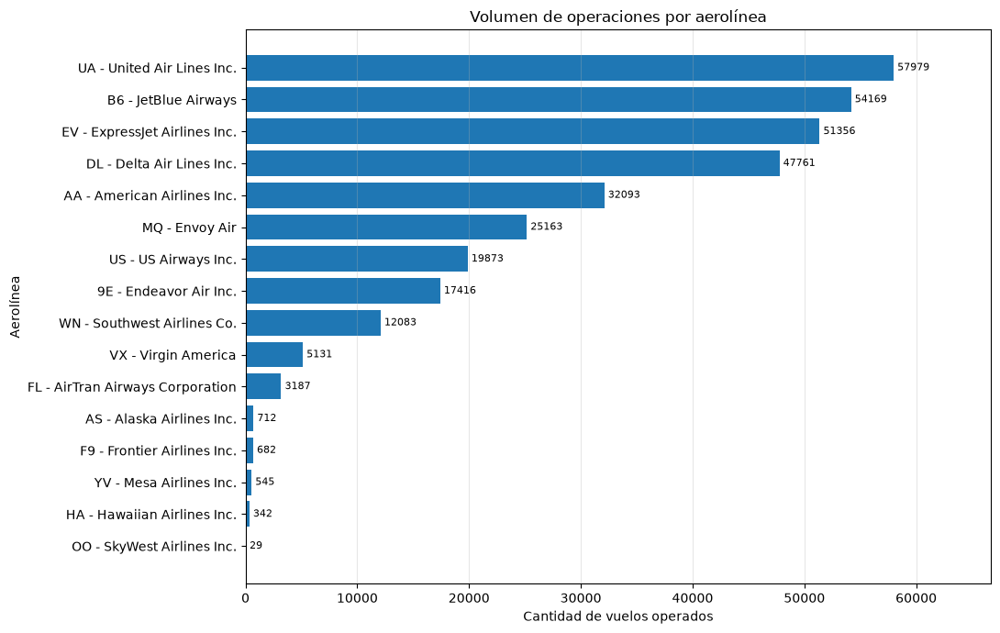


GRÁFICO 2. MATRÍCULAS IDENTIFICADAS POR AEROLÍNEA
Contamos cuántos aviones distintos aparecen en vuelos operados
por cada compañía. Una misma matrícula puede aparecer asociada
a más de una aerolínea.


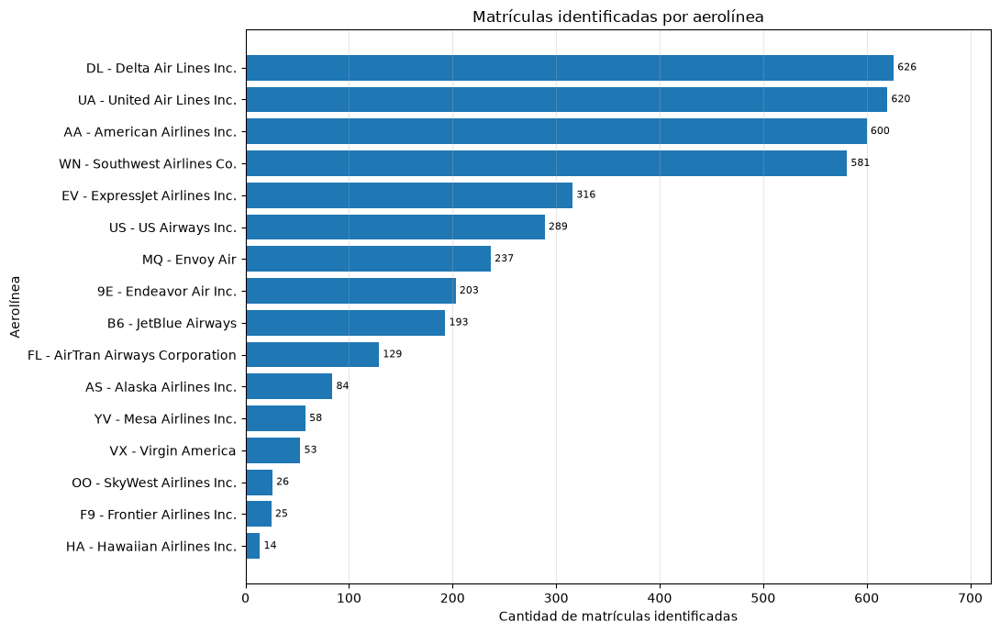


GRÁFICO 3. OPERACIONES POR MATRÍCULA
Comparamos la mediana de vuelos operados por avión dentro de cada aerolínea.
Esto ayuda a distinguir entre una compañía con muchos vuelos porque
tiene más matrículas y otra en la que cada matrícula registra más operaciones.


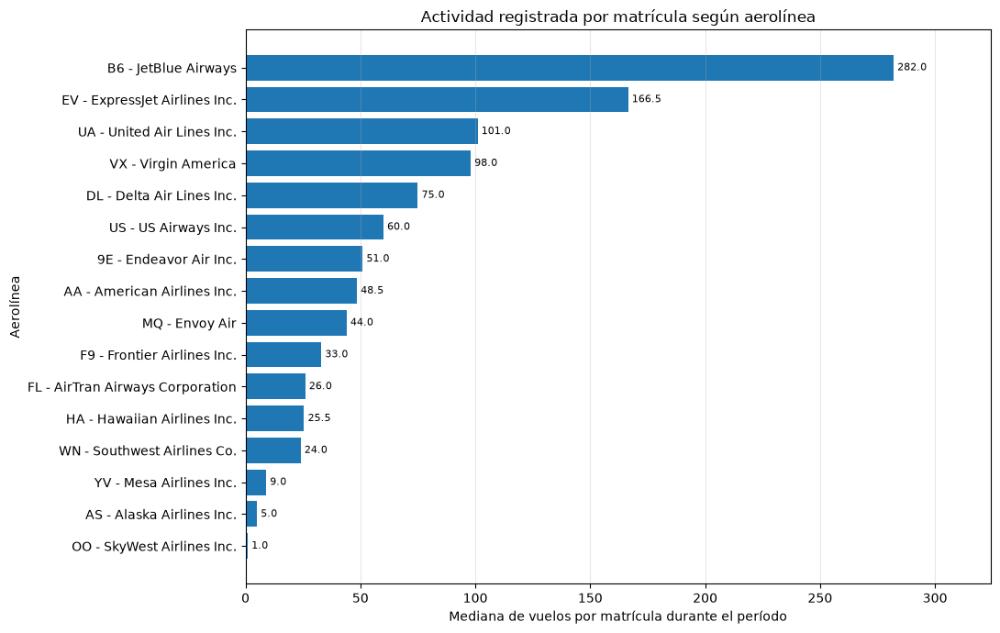

In [70]:
# ============================================================
# 2.1. DATOS GENERALES Y VOLUMEN DE OPERACIONES POR AEROLÍNEA
# ============================================================

print("2.1. DATOS GENERALES Y VOLUMEN DE OPERACIONES POR AEROLÍNEA")
print("Analizamos el volumen de operaciones y la cantidad de aviones")
print("asociados a cada compañía.")


# ============================================================
# 1. PREPARACIÓN DE LOS DATOS
# ============================================================

columnas_necesarias = [
    "id",
    "estado_vuelo",
    "aerolinea",
    "nombre_aerolinea",
    "matricula_avion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas necesarias en df: {faltantes}")

# Copia de trabajo: no modificamos df
base = df.copy()

# Separamos los vuelos operados
operados = base.loc[
    base["estado_vuelo"].eq("operado")
].copy()

# Matrículas identificadas en vuelos operados
operados_con_matricula = operados.loc[
    operados["matricula_avion"].notna()
    & operados["matricula_avion"].astype("string").str.strip().ne("")
].copy()

# ============================================================
# 2. RESUMEN GENERAL POR AEROLÍNEA
# ============================================================

resumen_aerolineas = (
    base
    .groupby(
        ["aerolinea", "nombre_aerolinea"],
        dropna=False
    )
    .agg(
        vuelos_registrados=("id", "size"),

        vuelos_operados=(
            "estado_vuelo",
            lambda s: s.eq("operado").sum()
        ),

        vuelos_cancelados=(
            "estado_vuelo",
            lambda s: s.eq("cancelado").sum()
        )
    )
    .reset_index()
)

# Cantidad de matrículas distintas por aerolínea.
# Se cuentan las matrículas identificadas en vuelos operados.
matriculas_por_aerolinea = (
    operados_con_matricula
    .groupby(["aerolinea", "nombre_aerolinea"])
    .agg(
        matriculas_identificadas=("matricula_avion", "nunique")
    )
    .reset_index()
)

resumen_aerolineas = resumen_aerolineas.merge(
    matriculas_por_aerolinea,
    on=["aerolinea", "nombre_aerolinea"],
    how="left",
    validate="one_to_one"
)

resumen_aerolineas["matriculas_identificadas"] = (
    resumen_aerolineas["matriculas_identificadas"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# 3. VUELOS OPERADOS POR MATRÍCULA DENTRO DE CADA AEROLÍNEA
# ============================================================

# Contamos las operaciones de cada matrícula con cada compañía.
vuelos_por_matricula_aerolinea = (
    operados_con_matricula
    .groupby(
        ["aerolinea", "nombre_aerolinea", "matricula_avion"]
    )
    .size()
    .rename("cantidad_vuelos")
    .reset_index()
)

# Calculamos promedio y mediana de vuelos por matrícula.
# La mediana permite reducir la influencia de aviones con
# cantidades excepcionalmente elevadas de operaciones.
actividad_por_aerolinea = (
    vuelos_por_matricula_aerolinea
    .groupby(["aerolinea", "nombre_aerolinea"])
    .agg(
        promedio_vuelos_por_matricula=("cantidad_vuelos", "mean"),
        mediana_vuelos_por_matricula=("cantidad_vuelos", "median")
    )
    .reset_index()
)

resumen_aerolineas = resumen_aerolineas.merge(
    actividad_por_aerolinea,
    on=["aerolinea", "nombre_aerolinea"],
    how="left",
    validate="one_to_one"
)

# ============================================================
# 4. RESUMEN IMPRESO
# ============================================================

print("\nRESUMEN GENERAL")
print("-" * 50)
print(f"Registros totales: {len(base):,}")
print(f"Vuelos operados: {len(operados):,}")
print(f"Vuelos cancelados: {base['estado_vuelo'].eq('cancelado').sum():,}")
print(
    "Vuelos operados sin matrícula identificada: "
    f"{operados['matricula_avion'].isna().sum():,}"
)
print(
    "Matrículas distintas identificadas en vuelos operados: "
    f"{operados_con_matricula['matricula_avion'].nunique():,}"
)
print(f"Aerolíneas identificadas: {resumen_aerolineas['aerolinea'].nunique():,}")

print("\nAEROLÍNEAS CON MAYOR VOLUMEN DE OPERACIONES")
print("-" * 50)

top_volumen = resumen_aerolineas.sort_values(
    "vuelos_operados",
    ascending=False
).head(5)

for _, fila in top_volumen.iterrows():
    print(
        f"{fila['aerolinea']} - {fila['nombre_aerolinea']}: "
        f"{fila['vuelos_operados']:,} vuelos operados"
    )

print("\nAEROLÍNEAS CON MENOR VOLUMEN DE OPERACIONES")
print("-" * 50)

menor_volumen = resumen_aerolineas.sort_values(
    "vuelos_operados",
    ascending=True
).head(5)

for _, fila in menor_volumen.iterrows():
    print(
        f"{fila['aerolinea']} - {fila['nombre_aerolinea']}: "
        f"{fila['vuelos_operados']:,} vuelos operados"
    )


# ============================================================
# GRÁFICO 1. VUELOS OPERADOS POR AEROLÍNEA
# ============================================================

print("\nGRÁFICO 1. VOLUMEN DE VUELOS OPERADOS")
print("Comparamos cuántos vuelos operó cada aerolínea.")
print("Esto permite identificar las compañías con más y menos operaciones.")

grafico_vuelos = resumen_aerolineas.sort_values(
    "vuelos_operados",
    ascending=True
)

etiquetas = (
    grafico_vuelos["aerolinea"].astype(str)
    + " - "
    + grafico_vuelos["nombre_aerolinea"].astype(str)
)

fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    etiquetas,
    grafico_vuelos["vuelos_operados"]
)

ax.bar_label(barras, fmt="%.0f", padding=3, fontsize=8)

ax.set_xlabel("Cantidad de vuelos operados")
ax.set_ylabel("Aerolínea")
ax.set_title("Volumen de operaciones por aerolínea")
ax.grid(axis="x", alpha=0.3)

ax.set_xlim(
    0,
    grafico_vuelos["vuelos_operados"].max() * 1.15
)

plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 2. MATRÍCULAS IDENTIFICADAS POR AEROLÍNEA
# ============================================================

print("\nGRÁFICO 2. MATRÍCULAS IDENTIFICADAS POR AEROLÍNEA")
print("Contamos cuántos aviones distintos aparecen en vuelos operados")
print("por cada compañía. Una misma matrícula puede aparecer asociada")
print("a más de una aerolínea.")

grafico_matriculas = resumen_aerolineas.sort_values(
    "matriculas_identificadas",
    ascending=True
)

etiquetas = (
    grafico_matriculas["aerolinea"].astype(str)
    + " - "
    + grafico_matriculas["nombre_aerolinea"].astype(str)
)

fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    etiquetas,
    grafico_matriculas["matriculas_identificadas"]
)

ax.bar_label(barras, fmt="%.0f", padding=3, fontsize=8)

ax.set_xlabel("Cantidad de matrículas identificadas")
ax.set_ylabel("Aerolínea")
ax.set_title("Matrículas identificadas por aerolínea")
ax.grid(axis="x", alpha=0.3)

ax.set_xlim(
    0,
    max(1, grafico_matriculas["matriculas_identificadas"].max() * 1.15)
)

plt.tight_layout()
plt.show()


# ============================================================
# GRÁFICO 3. VUELOS OPERADOS POR MATRÍCULA
# ============================================================

print("\nGRÁFICO 3. OPERACIONES POR MATRÍCULA")
print("Comparamos la mediana de vuelos operados por avión dentro de cada aerolínea.")
print("Esto ayuda a distinguir entre una compañía con muchos vuelos porque")
print("tiene más matrículas y otra en la que cada matrícula registra más operaciones.")

grafico_actividad = resumen_aerolineas.sort_values(
    "mediana_vuelos_por_matricula",
    ascending=True
).copy()

etiquetas = (
    grafico_actividad["aerolinea"].astype(str)
    + " - "
    + grafico_actividad["nombre_aerolinea"].astype(str)
)

fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    etiquetas,
    grafico_actividad["mediana_vuelos_por_matricula"]
)

ax.bar_label(barras, fmt="%.1f", padding=3, fontsize=8)

ax.set_xlabel("Mediana de vuelos por matrícula durante el período")
ax.set_ylabel("Aerolínea")
ax.set_title("Actividad registrada por matrícula según aerolínea")
ax.grid(axis="x", alpha=0.3)

ax.set_xlim(
    0,
    max(1, grafico_actividad["mediana_vuelos_por_matricula"].max() * 1.15)
)

plt.tight_layout()
plt.show()

#### 2.2. Demoras y niveles de puntualidad por aerolínea

**Objetivo:** identificar qué aerolíneas presentan más demoras y comparar la frecuencia y gravedad de esos episodios.

Preguntas que vamos a investigar:

- ¿Qué aerolíneas presentan la mayor cantidad de vuelos demorados?
- ¿Qué porcentaje de sus vuelos llega tarde?
- ¿Qué aerolíneas tienen mayores porcentajes de demoras severas y críticas?
- ¿Existen diferencias entre la puntualidad de salida y la de llegada?
- ¿Las aerolíneas con mayor cantidad de vuelos también presentan mayores porcentajes de demora?

**Enfoque del análisis:** diferenciaremos entre la cantidad total de vuelos demorados y la proporción que representan sobre los vuelos evaluables. Utilizaremos los niveles de puntualidad ya existentes y analizaremos las demoras severas y críticas como indicador principal para identificar situaciones que merecen una revisión más profunda.

2.2 | DEMORAS SEVERAS Y CRÍTICAS POR AEROLÍNEA

1. RESUMEN DE VUELOS CON DEMORAS SEVERAS Y CRÍTICAS
Se analizan los niveles existentes de puntualidad, no cualquier demora positiva.

Llegadas: aerolíneas ordenadas por porcentaje severo + crítico
aerolinea            nombre_aerolinea  vuelos_operados  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
       F9      Frontier Airlines Inc.              682                  681                83                171                        254                 12.19                  25.11                          37.30
       FL AirTran Airways Corporation             3187                 3175               400                665                       1065                 12.60                  20.94                          33.54
       YV          Mesa Airlines Inc.              545                  544                45              

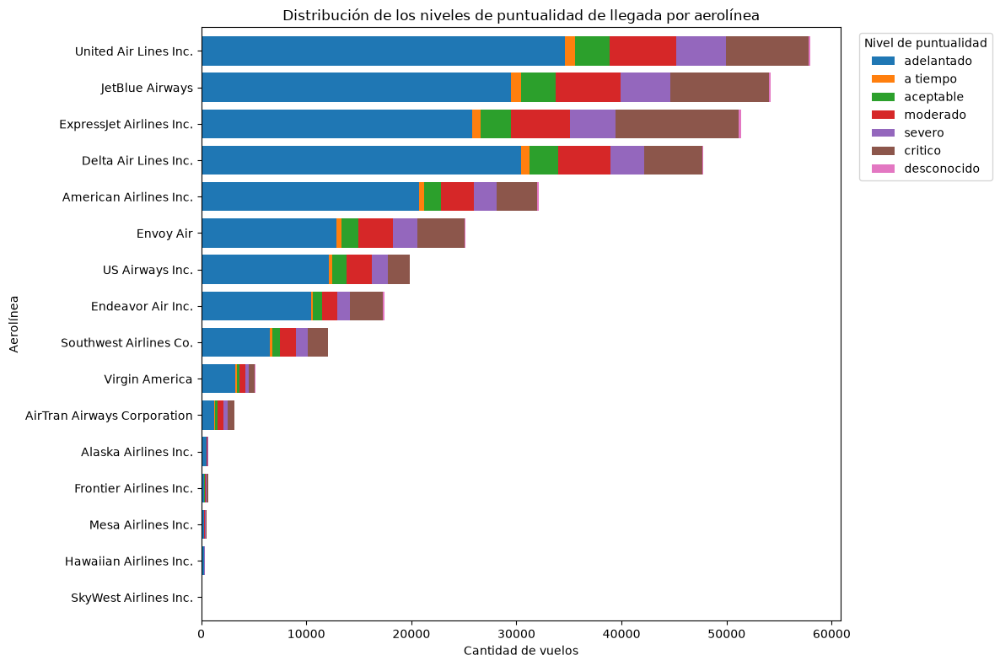


2.2 GRÁFICO: CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS
Cada barra muestra cuántos vuelos de cada aerolínea llegaron
con demora severa y cuántos con demora crítica.


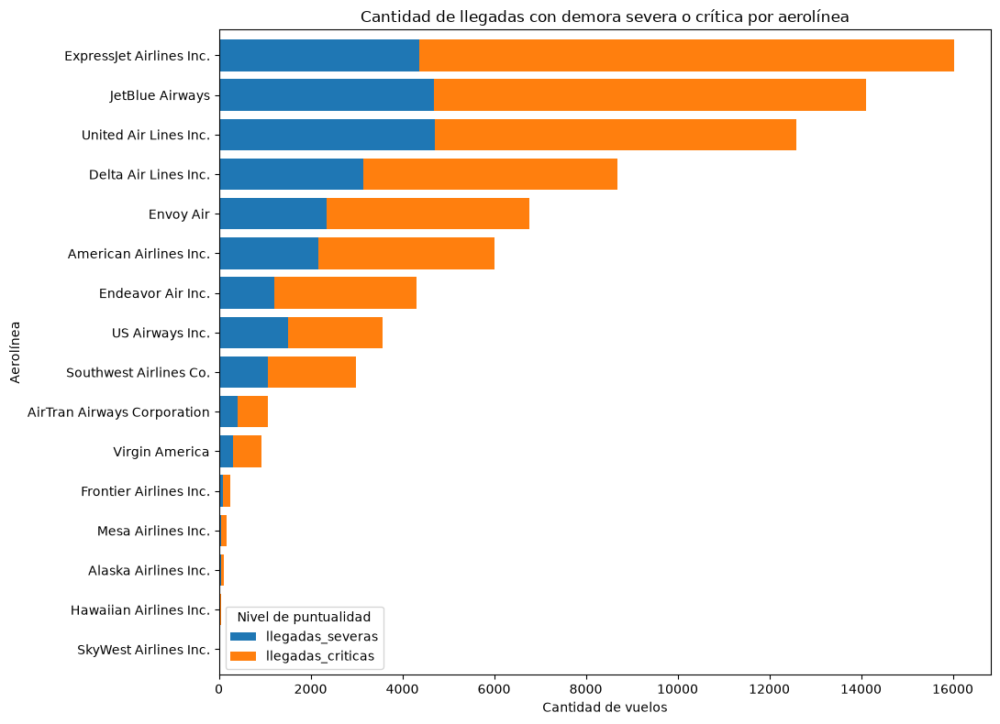


3. GRÁFICO: PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS
Se compara cada categoría por separado sobre las llegadas evaluables.
Esto permite distinguir la frecuencia de demoras severas de la de críticas.


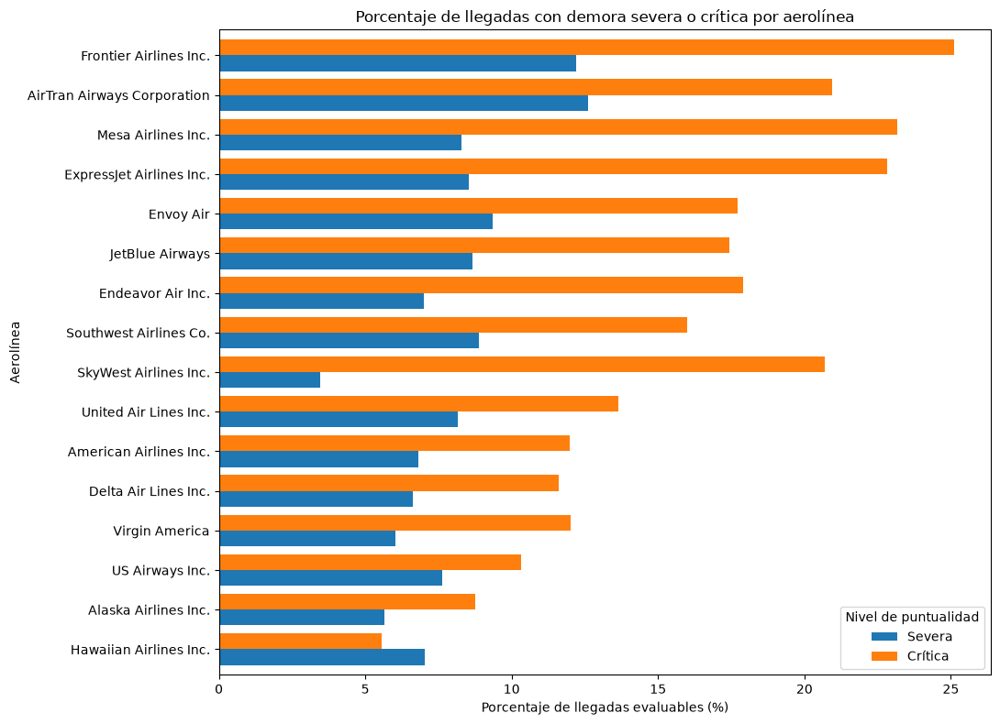


4. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS EN SALIDA Y LLEGADA
Compara el porcentaje combinado de niveles severos y críticos
en las salidas evaluables y las llegadas evaluables.


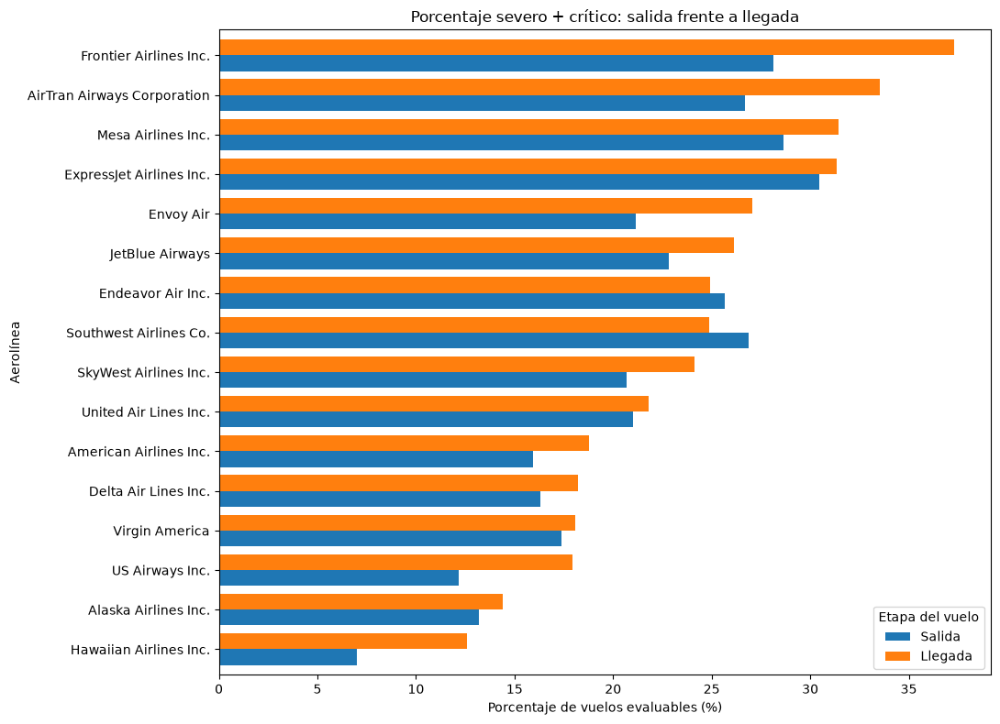


5. GRÁFICO: VOLUMEN OPERADO Y PORCENTAJE DE LLEGADAS SEVERAS/CRÍTICAS
Cada punto representa una aerolínea.
El eje horizontal muestra sus vuelos operados y el vertical
el porcentaje de llegadas con nivel severo o crítico.


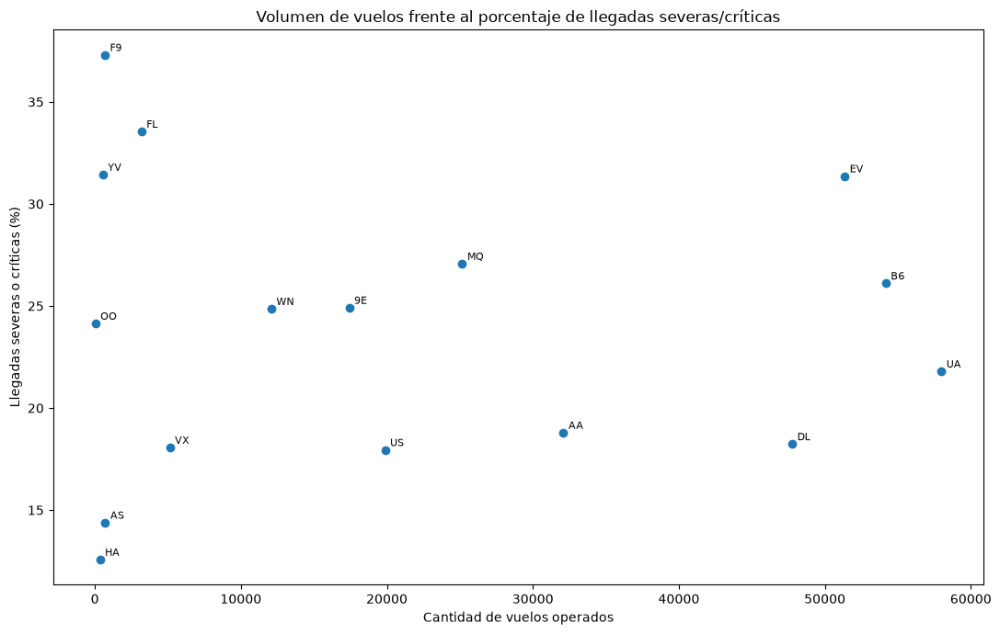


6. COMPARACIÓN NUMÉRICA ENTRE SALIDA Y LLEGADA
aerolinea            nombre_aerolinea  salidas_severas_criticas  pct_salidas_severas_criticas  llegadas_severas_criticas  pct_llegadas_severas_criticas
       F9      Frontier Airlines Inc.                       192                         28.15                        254                          37.30
       FL AirTran Airways Corporation                       850                         26.67                       1065                          33.54
       YV          Mesa Airlines Inc.                       156                         28.62                        171                          31.43
       EV    ExpressJet Airlines Inc.                     15644                         30.46                      16028                          31.36
       MQ                   Envoy Air                      5320                         21.14                       6777                          27.07
       B6             JetBlue Airways   

In [71]:

# ============================================================
# 2.2. DEMORAS SEVERAS Y CRÍTICAS POR AEROLÍNEA
# ============================================================

print("=" * 75)
print("2.2 | DEMORAS SEVERAS Y CRÍTICAS POR AEROLÍNEA")
print("=" * 75)

# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

# Trabajamos solamente con vuelos operados.
# Las columnas auxiliares se crean en una copia, no en df.
base = df.loc[df["estado_vuelo"].eq("operado")].copy()

nivel_arribo = base["nivel_puntualidad_arribo"]
nivel_salida = base["nivel_puntualidad_salida"]

# Un vuelo es evaluable si tiene un nivel conocido.
# "desconocido" no se incluye en el denominador.
base["_arribo_evaluable"] = (
    nivel_arribo.notna()
    & nivel_arribo.ne("desconocido")
)

base["_salida_evaluable"] = (
    nivel_salida.notna()
    & nivel_salida.ne("desconocido")
)

# Identificar las dos categorías prioritarias.
base["_arribo_severo"] = nivel_arribo.eq("severo").fillna(False)
base["_arribo_critico"] = nivel_arribo.eq("critico").fillna(False)

base["_salida_severa"] = nivel_salida.eq("severo").fillna(False)
base["_salida_critica"] = nivel_salida.eq("critico").fillna(False)


# ------------------------------------------------------------
# 2. Resumen por aerolínea
# ------------------------------------------------------------

print("\n1. RESUMEN DE VUELOS CON DEMORAS SEVERAS Y CRÍTICAS")
print("Se analizan los niveles existentes de puntualidad, no cualquier demora positiva.")

resumen = (
    base.groupby(
        ["aerolinea", "nombre_aerolinea"],
        as_index=False
    )
    .agg(
        vuelos_operados=("estado_vuelo", "size"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas=("_salida_severa", "sum"),
        salidas_criticas=("_salida_critica", "sum")
    )
)

# Cantidades combinadas: severas + críticas.
resumen["llegadas_severas_criticas"] = (
    resumen["llegadas_severas"] + resumen["llegadas_criticas"]
)

resumen["salidas_severas_criticas"] = (
    resumen["salidas_severas"] + resumen["salidas_criticas"]
)

# Porcentajes de llegada, sobre llegadas evaluables.
resumen["pct_llegadas_severas"] = (
    100 * resumen["llegadas_severas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_criticas"] = (
    100 * resumen["llegadas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_severas_criticas"] = (
    100 * resumen["llegadas_severas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

# Porcentajes de salida, sobre salidas evaluables.
resumen["pct_salidas_severas"] = (
    100 * resumen["salidas_severas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_criticas"] = (
    100 * resumen["salidas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_severas_criticas"] = (
    100 * resumen["salidas_severas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

columnas_principales = [
    "aerolinea",
    "nombre_aerolinea",
    "vuelos_operados",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

# Mostrar primero las aerolíneas con mayor porcentaje
# de llegadas severas y críticas combinadas.
tabla_arribos = (
    resumen[columnas_principales]
    .sort_values("pct_llegadas_severas_criticas", ascending=False)
    .copy()
)

columnas_porcentaje = [
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_arribos[columnas_porcentaje] = (
    tabla_arribos[columnas_porcentaje].round(2)
)

print("\nLlegadas: aerolíneas ordenadas por porcentaje severo + crítico")
print(tabla_arribos.to_string(index=False))


# ------------------------------------------------------------
# 3. Gráfico: cantidad de llegadas severas y críticas
# ------------------------------------------------------------





print("\n2.1 GRÁFICO: DISTRIBUCIÓN DE TODOS LOS NIVELES DE PUNTUALIDAD")
print("Se muestra la cantidad de llegadas de cada aerolínea según")
print("todos los niveles de puntualidad existentes en df.")
print("La categoría 'desconocido' se incluye para completar la distribución.")

# Orden de las categorías para facilitar la lectura.
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Contar vuelos por aerolínea y nivel de puntualidad de llegada.
distribucion_niveles = pd.crosstab(
    base["nombre_aerolinea"],
    base["nivel_puntualidad_arribo"]
)

# Mantener el orden definido y contemplar posibles categorías ausentes.
distribucion_niveles = distribucion_niveles.reindex(
    columns=orden_niveles,
    fill_value=0
)

# Ordenar las aerolíneas por volumen total de vuelos operados.
distribucion_niveles = distribucion_niveles.loc[
    distribucion_niveles.sum(axis=1).sort_values().index
]

# Gráfico de barras horizontales apiladas.
distribucion_niveles.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    width=0.8
)

plt.title("Distribución de los niveles de puntualidad de llegada por aerolínea")
plt.xlabel("Cantidad de vuelos")
plt.ylabel("Aerolínea")
plt.legend(title="Nivel de puntualidad", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()








print("\n2.2 GRÁFICO: CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS")
print("Cada barra muestra cuántos vuelos de cada aerolínea llegaron")
print("con demora severa y cuántos con demora crítica.")

grafico = resumen.sort_values(
    "llegadas_severas_criticas",
    ascending=True
).set_index("nombre_aerolinea")

grafico[
    ["llegadas_severas", "llegadas_criticas"]
].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 8),
    width=0.8
)

plt.title("Cantidad de llegadas con demora severa o crítica por aerolínea")
plt.xlabel("Cantidad de vuelos")
plt.ylabel("Aerolínea")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Gráfico: porcentaje de llegadas severas y críticas
# ------------------------------------------------------------

print("\n3. GRÁFICO: PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS")
print("Se compara cada categoría por separado sobre las llegadas evaluables.")
print("Esto permite distinguir la frecuencia de demoras severas de la de críticas.")

grafico = resumen.sort_values(
    "pct_llegadas_severas_criticas",
    ascending=True
).set_index("nombre_aerolinea")

grafico[
    ["pct_llegadas_severas", "pct_llegadas_criticas"]
].rename(
    columns={
        "pct_llegadas_severas": "Severa",
        "pct_llegadas_criticas": "Crítica"
    }
).plot(
    kind="barh",
    figsize=(11, 8),
    width=0.8
)

plt.title("Porcentaje de llegadas con demora severa o crítica por aerolínea")
plt.xlabel("Porcentaje de llegadas evaluables (%)")
plt.ylabel("Aerolínea")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: comparación entre salida y llegada
# ------------------------------------------------------------

print("\n4. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS EN SALIDA Y LLEGADA")
print("Compara el porcentaje combinado de niveles severos y críticos")
print("en las salidas evaluables y las llegadas evaluables.")

grafico = resumen.sort_values(
    "pct_llegadas_severas_criticas",
    ascending=True
).set_index("nombre_aerolinea")

grafico[
    ["pct_salidas_severas_criticas", "pct_llegadas_severas_criticas"]
].rename(
    columns={
        "pct_salidas_severas_criticas": "Salida",
        "pct_llegadas_severas_criticas": "Llegada"
    }
).plot(
    kind="barh",
    figsize=(11, 8),
    width=0.8
)

plt.title("Porcentaje severo + crítico: salida frente a llegada")
plt.xlabel("Porcentaje de vuelos evaluables (%)")
plt.ylabel("Aerolínea")
plt.legend(title="Etapa del vuelo")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico: volumen de operaciones frente a gravedad
# ------------------------------------------------------------

print("\n5. GRÁFICO: VOLUMEN OPERADO Y PORCENTAJE DE LLEGADAS SEVERAS/CRÍTICAS")
print("Cada punto representa una aerolínea.")
print("El eje horizontal muestra sus vuelos operados y el vertical")
print("el porcentaje de llegadas con nivel severo o crítico.")

plt.figure(figsize=(11, 7))

plt.scatter(
    resumen["vuelos_operados"],
    resumen["pct_llegadas_severas_criticas"]
)

for _, fila in resumen.iterrows():
    if pd.notna(fila["pct_llegadas_severas_criticas"]):
        plt.annotate(
            fila["aerolinea"],
            (
                fila["vuelos_operados"],
                fila["pct_llegadas_severas_criticas"]
            ),
            xytext=(4, 3),
            textcoords="offset points",
            fontsize=8
        )

plt.title("Volumen de vuelos frente al porcentaje de llegadas severas/críticas")
plt.xlabel("Cantidad de vuelos operados")
plt.ylabel("Llegadas severas o críticas (%)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Comparación numérica entre salida y llegada
# ------------------------------------------------------------

print("\n6. COMPARACIÓN NUMÉRICA ENTRE SALIDA Y LLEGADA")

tabla_comparacion = resumen[
    [
        "aerolinea",
        "nombre_aerolinea",
        "salidas_severas_criticas",
        "pct_salidas_severas_criticas",
        "llegadas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
].sort_values(
    "pct_llegadas_severas_criticas",
    ascending=False
).copy()

tabla_comparacion[
    ["pct_salidas_severas_criticas", "pct_llegadas_severas_criticas"]
] = tabla_comparacion[
    ["pct_salidas_severas_criticas", "pct_llegadas_severas_criticas"]
].round(2)

print(tabla_comparacion.to_string(index=False))

#### 2.3. Distribución de las demoras entre las matrículas de cada aerolínea

**Objetivo:** determinar si las demoras de una compañía se concentran en unos pocos aviones o si aparecen de forma generalizada entre las matrículas que operan para ella.

Preguntas que vamos a investigar:

- ¿Una aerolínea presenta muchas demoras porque tiene un conjunto de aviones con comportamientos similares?
- ¿Las demoras se concentran en unas pocas matrículas o se distribuyen entre gran parte de la flota?
- ¿Qué proporción de las matrículas de cada aerolínea presenta demoras severas y críticas de forma recurrente?
- ¿Qué porcentaje de las llegadas severas y críticas de una compañía corresponde a matrículas con demoras recurrentes?
- ¿Las matrículas que presentan mayores porcentajes de demora pertenecen principalmente a determinadas aerolíneas?

**Enfoque del análisis:** conectaremos los resultados del análisis de matrículas con los de las aerolíneas. Aplicaremos el criterio inicial de más del 30 % de demoras severas o críticas tanto en salida como en llegada, siempre considerando la cantidad de vuelos evaluables.

Esto permitirá distinguir entre una aerolínea cuyas demoras se concentran en algunos aviones y otra en la que el problema aparece distribuido entre muchas matrículas.

2.3 | MATRÍCULAS CON DEMORAS SEVERAS Y CRÍTICAS POR AEROLÍNEA

1. ANÁLISIS DE PUNTUALIDAD POR MATRÍCULA Y AEROLÍNEA
Se calculan los porcentajes severos/críticos de salida y llegada.
Una matrícula será recurrente si supera el 30 % en ambas etapas.

Matrículas identificadas: 4037
Combinaciones matrícula-aerolínea analizadas: 4054
Matrículas recurrentes según el criterio: 85

2. RESUMEN POR AEROLÍNEA
Se compara el tamaño de la flota identificada y la cantidad
de matrículas que supera el 30 % severo/crítico en ambas etapas.

Aerolíneas ordenadas por porcentaje de matrículas recurrentes:
aerolinea            nombre_aerolinea  vuelos_operados  matriculas_analizadas  matriculas_recurrentes  pct_matriculas_recurrentes  llegadas_severas_criticas  llegadas_graves_matriculas_recurrentes  pct_llegadas_graves_en_matriculas_recurrentes  pct_llegadas_graves_recurrentes_sobre_identificadas
       OO       SkyWest Airlines Inc.               29                     26                       6            

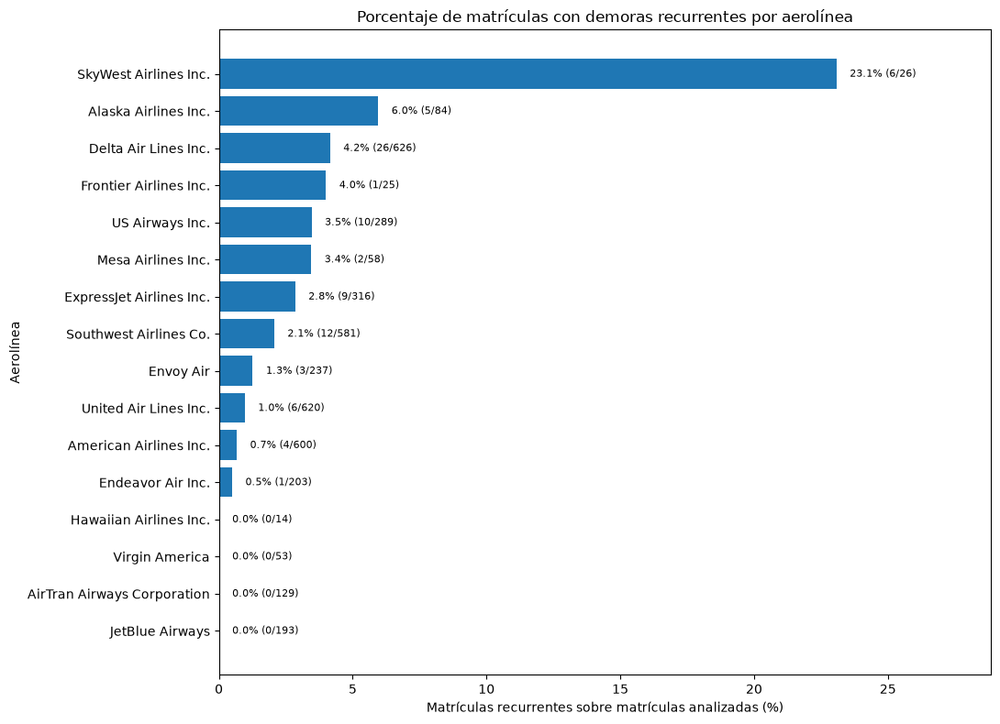


4. GRÁFICO: LLEGADAS SEVERAS/CRÍTICAS ASOCIADAS A MATRÍCULAS RECURRENTES
Se mide qué porcentaje de todas las llegadas severas/críticas
de cada aerolínea corresponde a vuelos operados por matrículas
que cumplen el criterio de recurrencia.


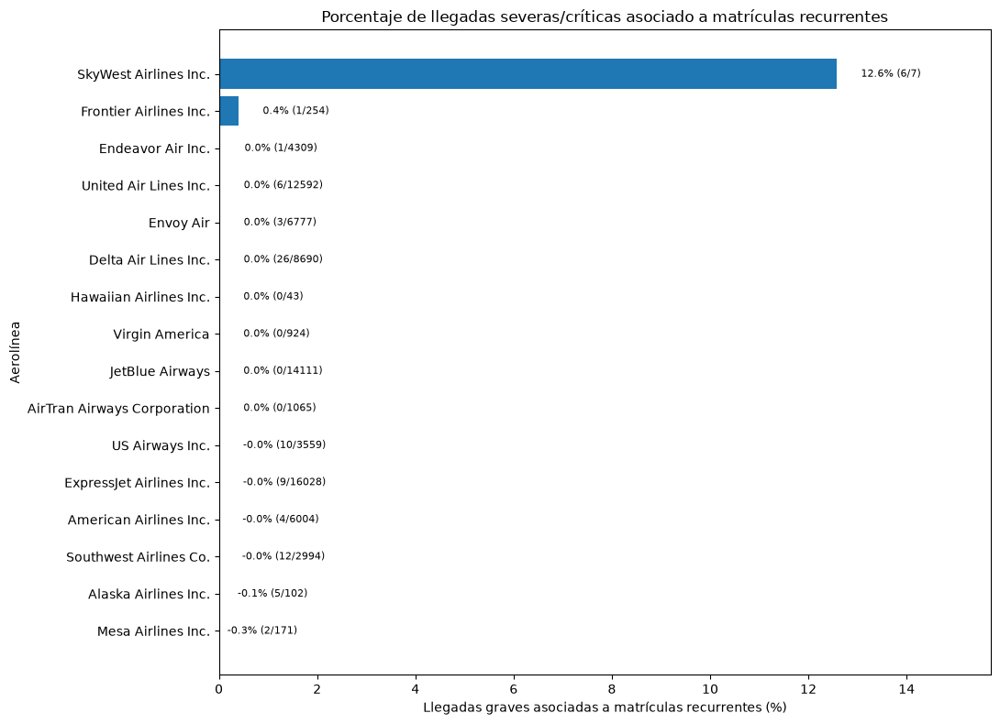


5. MATRÍCULAS RECURRENTES CON MAYOR PORCENTAJE DE LLEGADAS GRAVES
Se muestran las matrículas que cumplen el criterio de recurrencia,
ordenadas por su porcentaje severo/crítico de llegada.
Los conteos evaluables permiten valorar la cantidad de observaciones.
aerolinea         nombre_aerolinea matricula_avion  vuelos_operados_matricula  salidas_evaluables  salidas_severas_criticas  pct_salida_severa_critica  llegadas_evaluables  llegadas_severas_criticas  pct_arribo_severo_critico
       AA   American Airlines Inc.          N5ERAA                          1                   1                         1                      100.0                    1                          1                      100.0
       AA   American Airlines Inc.          N7AEAA                          1                   1                         1                      100.0                    1                          1                      100.0
       AA   American Airlines Inc.          N7ASAA             

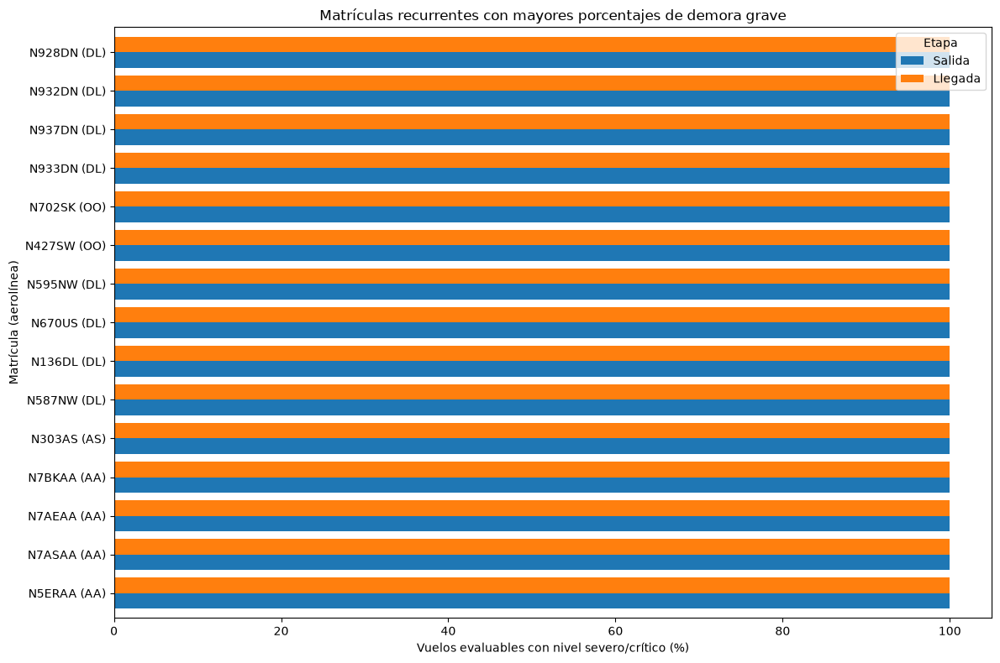

In [72]:

# ============================================================
# 2.3. DISTRIBUCIÓN DE LAS DEMORAS ENTRE LAS MATRÍCULAS
#      DE CADA AEROLÍNEA
# ============================================================

print("=" * 80)
print("2.3 | MATRÍCULAS CON DEMORAS SEVERAS Y CRÍTICAS POR AEROLÍNEA")
print("=" * 80)

# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

# Analizamos solamente vuelos operados.
base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Identificar vuelos evaluables según los niveles ya existentes.
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
)

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
)

# Identificar únicamente las categorías prioritarias.
base["_salida_severa_critica"] = (
    base["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
    .astype("int8")
)

base["_arribo_severo_critico"] = (
    base["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
    .astype("int8")
)

# Distinguir las matrículas identificadas de los registros
# que no tienen una matrícula válida.
matricula_texto = base["matricula_avion"].astype("string").str.strip()

base["_matricula_valida"] = (
    matricula_texto.notna()
    & matricula_texto.ne("").fillna(False)
)

# ------------------------------------------------------------
# 2. Calcular indicadores para cada matrícula y aerolínea
# ------------------------------------------------------------

print("\n1. ANÁLISIS DE PUNTUALIDAD POR MATRÍCULA Y AEROLÍNEA")
print("Se calculan los porcentajes severos/críticos de salida y llegada.")
print("Una matrícula será recurrente si supera el 30 % en ambas etapas.")

claves_aerolinea = ["aerolinea", "nombre_aerolinea"]

# Para este análisis, cada unidad es una combinación de
# aerolínea + matrícula.
base_matriculas = base.loc[base["_matricula_valida"]].copy()

matriculas = (
    base_matriculas
    .groupby(
        claves_aerolinea + ["matricula_avion"],
        as_index=False
    )
    .agg(
        vuelos_operados_matricula=("id", "size"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_severa_critica", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_severo_critico", "sum")
    )
)

# Porcentajes sobre los vuelos evaluables de cada matrícula.
matriculas["pct_salida_severa_critica"] = (
    100
    * matriculas["salidas_severas_criticas"]
    / matriculas["salidas_evaluables"].replace(0, np.nan)
)

matriculas["pct_arribo_severo_critico"] = (
    100
    * matriculas["llegadas_severas_criticas"]
    / matriculas["llegadas_evaluables"].replace(0, np.nan)
)

# Criterio del proyecto:
# más del 30 % en salida Y más del 30 % en llegada.
matriculas["_matricula_recurrente"] = (
    matriculas["pct_salida_severa_critica"].gt(30)
    & matriculas["pct_arribo_severo_critico"].gt(30)
)

# Tabla de las matrículas que cumplen el criterio.
matriculas_recurrentes = matriculas.loc[
    matriculas["_matricula_recurrente"]
].copy()

print(f"\nMatrículas identificadas: {matriculas['matricula_avion'].nunique()}")
print(f"Combinaciones matrícula-aerolínea analizadas: {len(matriculas)}")
print(f"Matrículas recurrentes según el criterio: {len(matriculas_recurrentes)}")


# ------------------------------------------------------------
# 3. Resumen por aerolínea: proporción de matrículas recurrentes
# ------------------------------------------------------------

print("\n2. RESUMEN POR AEROLÍNEA")
print("Se compara el tamaño de la flota identificada y la cantidad")
print("de matrículas que supera el 30 % severo/crítico en ambas etapas.")

resumen_flota = (
    matriculas
    .groupby(claves_aerolinea, as_index=False)
    .agg(
        matriculas_analizadas=("matricula_avion", "nunique"),
        matriculas_recurrentes=("_matricula_recurrente", "sum")
    )
)

resumen_flota["pct_matriculas_recurrentes"] = (
    100
    * resumen_flota["matriculas_recurrentes"]
    / resumen_flota["matriculas_analizadas"].replace(0, np.nan)
)

# ------------------------------------------------------------
# 4. Calcular qué proporción de las llegadas graves corresponde
#    a matrículas recurrentes
# ------------------------------------------------------------

# Incorporar a cada vuelo la clasificación de su combinación
# matrícula-aerolínea, sin modificar df.
base = base.merge(
    matriculas[
        claves_aerolinea
        + ["matricula_avion", "_matricula_recurrente"]
    ],
    on=claves_aerolinea + ["matricula_avion"],
    how="left"
)

# Una llegada severa/crítica se atribuye a una matrícula
# recurrente cuando cumple ambas condiciones.
base["_llegada_grave_matricula_recurrente"] = (
    base["_arribo_severo_critico"].eq(1)
    & base["_matricula_recurrente"].fillna(False)
).astype("int8")

# Contar también llegadas severas/críticas con matrícula
# identificada, para poder evaluar el efecto de los registros
# sin matrícula conocida.
base["_llegada_grave_matricula_identificada"] = (
    base["_arribo_severo_critico"].eq(1)
    & base["_matricula_valida"]
).astype("int8")

resumen_llegadas = (
    base
    .groupby(claves_aerolinea, as_index=False)
    .agg(
        vuelos_operados=("id", "size"),

        llegadas_severas_criticas=(
            "_arribo_severo_critico", "sum"
        ),

        llegadas_graves_matricula_identificada=(
            "_llegada_grave_matricula_identificada", "sum"
        ),

        llegadas_graves_matriculas_recurrentes=(
            "_llegada_grave_matricula_recurrente", "sum"
        )
    )
)

resumen = resumen_llegadas.merge(
    resumen_flota,
    on=claves_aerolinea,
    how="left"
)

# Las aerolíneas sin matrículas identificadas no deben perderse
# del resumen.
resumen["matriculas_analizadas"] = (
    resumen["matriculas_analizadas"].fillna(0).astype(int)
)

resumen["matriculas_recurrentes"] = (
    resumen["matriculas_recurrentes"].fillna(0).astype(int)
)

# Porcentaje de las matrículas identificadas que son recurrentes.
resumen["pct_matriculas_recurrentes"] = (
    100
    * resumen["matriculas_recurrentes"]
    / resumen["matriculas_analizadas"].replace(0, np.nan)
)

# Indicador principal: porcentaje de todas las llegadas
# severas/críticas de la compañía asociado a matrículas recurrentes.
resumen["pct_llegadas_graves_en_matriculas_recurrentes"] = (
    100
    * resumen["llegadas_graves_matriculas_recurrentes"]
    / resumen["llegadas_severas_criticas"].replace(0, np.nan)
)

# Indicador complementario: mismo porcentaje, pero solo entre
# las llegadas graves que tienen matrícula identificada.
resumen["pct_llegadas_graves_recurrentes_sobre_identificadas"] = (
    100
    * resumen["llegadas_graves_matriculas_recurrentes"]
    / resumen["llegadas_graves_matricula_identificada"].replace(0, np.nan)
)

columnas_resumen = [
    "aerolinea",
    "nombre_aerolinea",
    "vuelos_operados",
    "matriculas_analizadas",
    "matriculas_recurrentes",
    "pct_matriculas_recurrentes",
    "llegadas_severas_criticas",
    "llegadas_graves_matriculas_recurrentes",
    "pct_llegadas_graves_en_matriculas_recurrentes",
    "pct_llegadas_graves_recurrentes_sobre_identificadas"
]

tabla_resumen = resumen[columnas_resumen].copy()

columnas_porcentaje = [
    "pct_matriculas_recurrentes",
    "pct_llegadas_graves_en_matriculas_recurrentes",
    "pct_llegadas_graves_recurrentes_sobre_identificadas"
]

tabla_resumen[columnas_porcentaje] = (
    tabla_resumen[columnas_porcentaje].round(2)
)

print("\nAerolíneas ordenadas por porcentaje de matrículas recurrentes:")
print(
    tabla_resumen
    .sort_values("pct_matriculas_recurrentes", ascending=False)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Gráfico: porcentaje de matrículas recurrentes por aerolínea
# ------------------------------------------------------------

print("\n3. GRÁFICO: PROPORCIÓN DE MATRÍCULAS CON DEMORAS RECURRENTES")
print("Cada barra muestra qué porcentaje de las matrículas identificadas")
print("de cada aerolínea supera el 30 % severo/crítico en salida y llegada.")
print("Las etiquetas indican el porcentaje y la cantidad de matrículas.")

grafico_flota = resumen.sort_values(
    "pct_matriculas_recurrentes",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(11, 8))

barras = ax.barh(
    grafico_flota["nombre_aerolinea"],
    grafico_flota["pct_matriculas_recurrentes"].fillna(0)
)

for barra, (_, fila) in zip(barras, grafico_flota.iterrows()):
    etiqueta = (
        f"{fila['pct_matriculas_recurrentes']:.1f}% "
        f"({fila['matriculas_recurrentes']}/"
        f"{fila['matriculas_analizadas']})"
        if pd.notna(fila["pct_matriculas_recurrentes"])
        else f"Sin matrículas evaluables"
    )

    ax.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        etiqueta,
        va="center",
        fontsize=8
    )

ax.set_title("Porcentaje de matrículas con demoras recurrentes por aerolínea")
ax.set_xlabel("Matrículas recurrentes sobre matrículas analizadas (%)")
ax.set_ylabel("Aerolínea")
ax.set_xlim(
    0,
    max(5, grafico_flota["pct_matriculas_recurrentes"].max()
        if grafico_flota["pct_matriculas_recurrentes"].notna().any()
        else 0) * 1.25
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico: proporción de llegadas graves asociada a matrículas
#    recurrentes
# ------------------------------------------------------------

print("\n4. GRÁFICO: LLEGADAS SEVERAS/CRÍTICAS ASOCIADAS A MATRÍCULAS RECURRENTES")
print("Se mide qué porcentaje de todas las llegadas severas/críticas")
print("de cada aerolínea corresponde a vuelos operados por matrículas")
print("que cumplen el criterio de recurrencia.")

grafico_llegadas = resumen.sort_values(
    "pct_llegadas_graves_en_matriculas_recurrentes",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(11, 8))

barras = ax.barh(
    grafico_llegadas["nombre_aerolinea"],
    grafico_llegadas[
        "pct_llegadas_graves_en_matriculas_recurrentes"
    ].fillna(0)
)

for barra, (_, fila) in zip(barras, grafico_llegadas.iterrows()):
    total = fila["llegadas_severas_criticas"]
    asociadas = fila["llegadas_graves_matriculas_recurrentes"]
    porcentaje = fila["pct_llegadas_graves_en_matriculas_recurrentes"]

    etiqueta = (
        f"{porcentaje:.1f}% ({asociadas}/{total})"
        if pd.notna(porcentaje)
        else "Sin llegadas graves evaluables"
    )

    ax.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        etiqueta,
        va="center",
        fontsize=8
    )

ax.set_title(
    "Porcentaje de llegadas severas/críticas asociado a matrículas recurrentes"
)
ax.set_xlabel("Llegadas graves asociadas a matrículas recurrentes (%)")
ax.set_ylabel("Aerolínea")
ax.set_xlim(
    0,
    max(
        5,
        grafico_llegadas[
            "pct_llegadas_graves_en_matriculas_recurrentes"
        ].max()
        if grafico_llegadas[
            "pct_llegadas_graves_en_matriculas_recurrentes"
        ].notna().any()
        else 0
    ) * 1.25
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Tabla: matrículas recurrentes con mayores porcentajes
# ------------------------------------------------------------

print("\n5. MATRÍCULAS RECURRENTES CON MAYOR PORCENTAJE DE LLEGADAS GRAVES")
print("Se muestran las matrículas que cumplen el criterio de recurrencia,")
print("ordenadas por su porcentaje severo/crítico de llegada.")
print("Los conteos evaluables permiten valorar la cantidad de observaciones.")

columnas_matriculas = [
    "aerolinea",
    "nombre_aerolinea",
    "matricula_avion",
    "vuelos_operados_matricula",
    "salidas_evaluables",
    "salidas_severas_criticas",
    "pct_salida_severa_critica",
    "llegadas_evaluables",
    "llegadas_severas_criticas",
    "pct_arribo_severo_critico"
]

tabla_matriculas = (
    matriculas_recurrentes[columnas_matriculas]
    .sort_values(
        ["pct_arribo_severo_critico", "pct_salida_severa_critica"],
        ascending=False
    )
    .head(20)
    .copy()
)

columnas_pct_matriculas = [
    "pct_salida_severa_critica",
    "pct_arribo_severo_critico"
]

tabla_matriculas[columnas_pct_matriculas] = (
    tabla_matriculas[columnas_pct_matriculas].round(2)
)

print(tabla_matriculas.to_string(index=False))


# ------------------------------------------------------------
# 8. Gráfico: comparación de salida y llegada en las matrículas
#    recurrentes con mayores porcentajes de llegada grave
# ------------------------------------------------------------

print("\n6. GRÁFICO: MATRÍCULAS RECURRENTES CON MAYORES PORCENTAJES")
print("Cada etiqueta combina matrícula y código de aerolínea.")
print("Se comparan los porcentajes severos/críticos de salida y llegada")
print("para las 15 matrículas recurrentes con mayor porcentaje de llegada grave.")

grafico_matriculas = (
    matriculas_recurrentes
    .sort_values("pct_arribo_severo_critico", ascending=False)
    .head(15)
    .copy()
)

if not grafico_matriculas.empty:
    grafico_matriculas["etiqueta"] = (
        grafico_matriculas["matricula_avion"]
        + " ("
        + grafico_matriculas["aerolinea"]
        + ")"
    )

    grafico_matriculas = grafico_matriculas.sort_values(
        "pct_arribo_severo_critico",
        ascending=True
    ).set_index("etiqueta")

    grafico_matriculas[
        [
            "pct_salida_severa_critica",
            "pct_arribo_severo_critico"
        ]
    ].rename(
        columns={
            "pct_salida_severa_critica": "Salida",
            "pct_arribo_severo_critico": "Llegada"
        }
    ).plot(
        kind="barh",
        figsize=(12, 8),
        width=0.8
    )

    plt.title(
        "Matrículas recurrentes con mayores porcentajes de demora grave"
    )
    plt.xlabel("Vuelos evaluables con nivel severo/crítico (%)")
    plt.ylabel("Matrícula (aerolínea)")
    plt.legend(title="Etapa")
    plt.tight_layout()
    plt.show()

else:
    print(
        "No se encontraron matrículas que superen el 30 % "
        "severo/crítico tanto en salida como en llegada."
    )

#### 2.4. Relación entre puntualidad de salida y llegada según la aerolínea

**Objetivo:** estudiar si la relación entre las demoras de salida y las de llegada cambia de una aerolínea a otra.

Preguntas que vamos a investigar:

- ¿Qué relación existe entre salir adelantado, a tiempo o demorado y llegar tarde según cada aerolínea?
- ¿Qué compañías presentan mayores diferencias entre las demoras de salida y llegada?
- ¿Hay aerolíneas cuyos vuelos suelen salir demorados, pero consiguen reducir la demora antes de llegar?
- ¿Existen compañías en las que los vuelos salen puntualmente, pero presentan demoras frecuentes a la llegada?

**Enfoque del análisis:** compararemos la puntualidad de salida y llegada por aerolínea. También analizaremos si las demoras disminuyen o aumentan entre ambas etapas, sin asumir que la diferencia depende exclusivamente de la compañía.

2.4 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados y niveles de puntualidad conocidos.
El análisis principal se centra en las categorías severo y crítico.
Vuelos operados: 328,521
Vuelos evaluables en salida y llegada: 327,346

2. RESUMEN DE PUNTUALIDAD POR AEROLÍNEA
Los porcentajes de salida y llegada se comparan usando
los mismos vuelos evaluables en ambas etapas.

Aerolíneas ordenadas por porcentaje de llegadas severas/críticas:
aerolinea            nombre_aerolinea  vuelos_operados  vuelos_comparables  pct_salida_grave_comparable  pct_llegada_grave_comparable  diferencia_llegada_salida_pp  pct_salida_severa_critica  pct_llegada_severa_critica
       F9      Frontier Airlines Inc.              682                 681                        28.05                         37.30                          9.25                      28.15                       37.30
       FL AirTran Airways Corporation             3187           

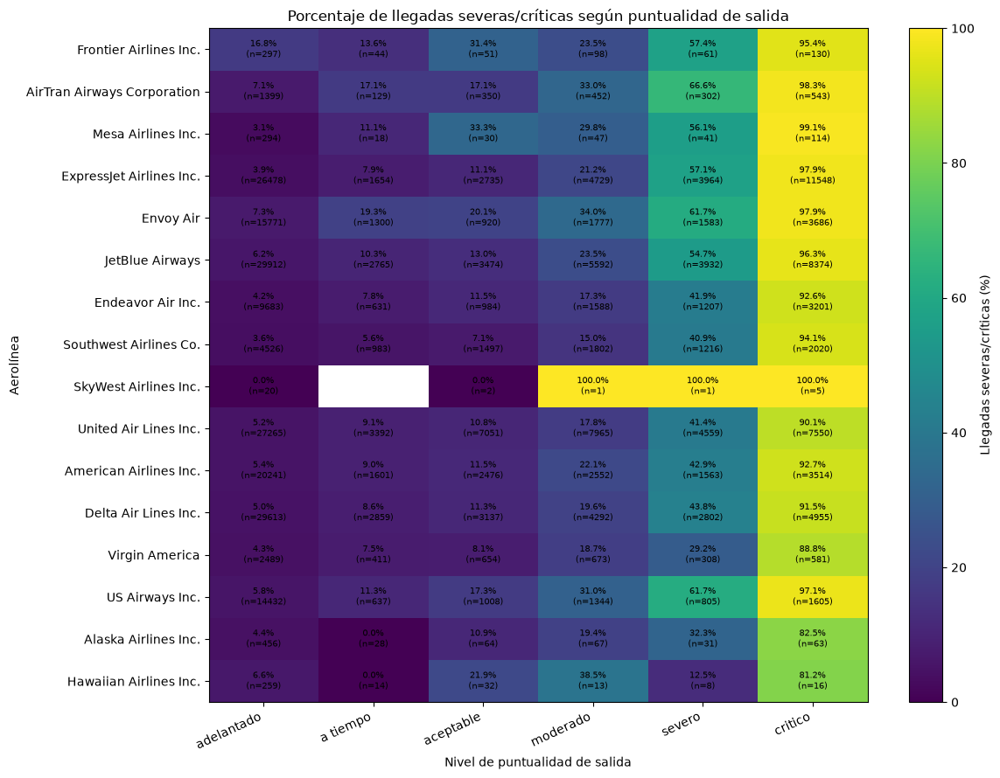


5. GRÁFICO: SALIDA FRENTE A LLEGADA
Se comparan los porcentajes severos/críticos sobre los mismos vuelos.
Así podemos ver qué aerolíneas presentan una mayor proporción
de vuelos graves al llegar que al salir.


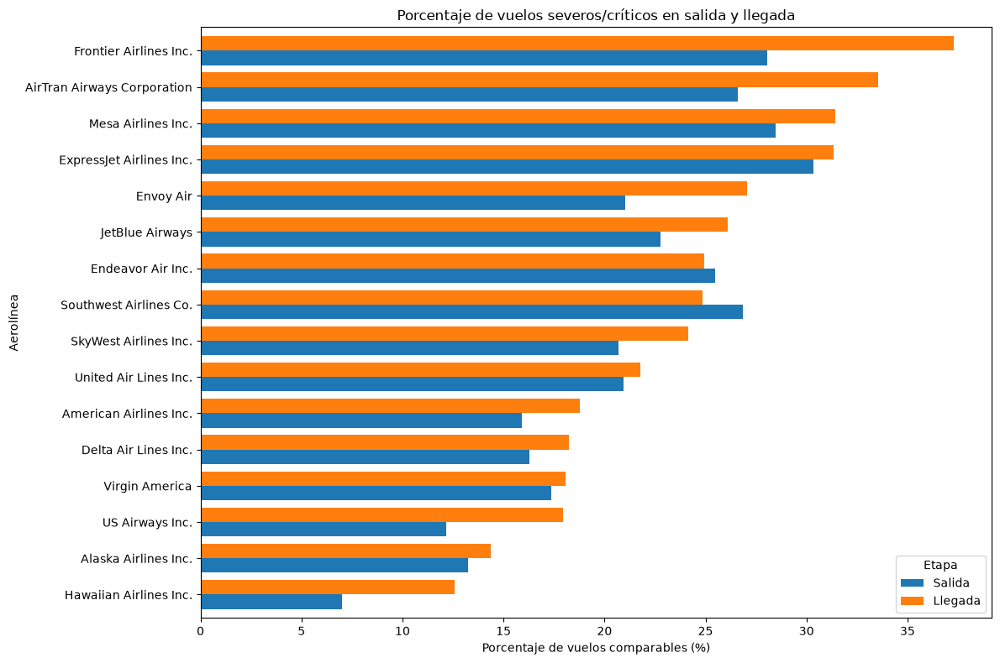


6. GRÁFICO: DIFERENCIA ENTRE SALIDA Y LLEGADA
La diferencia se expresa en puntos porcentuales.
Un valor positivo indica mayor proporción de vuelos graves al llegar;
uno negativo indica menor proporción de vuelos graves al llegar.


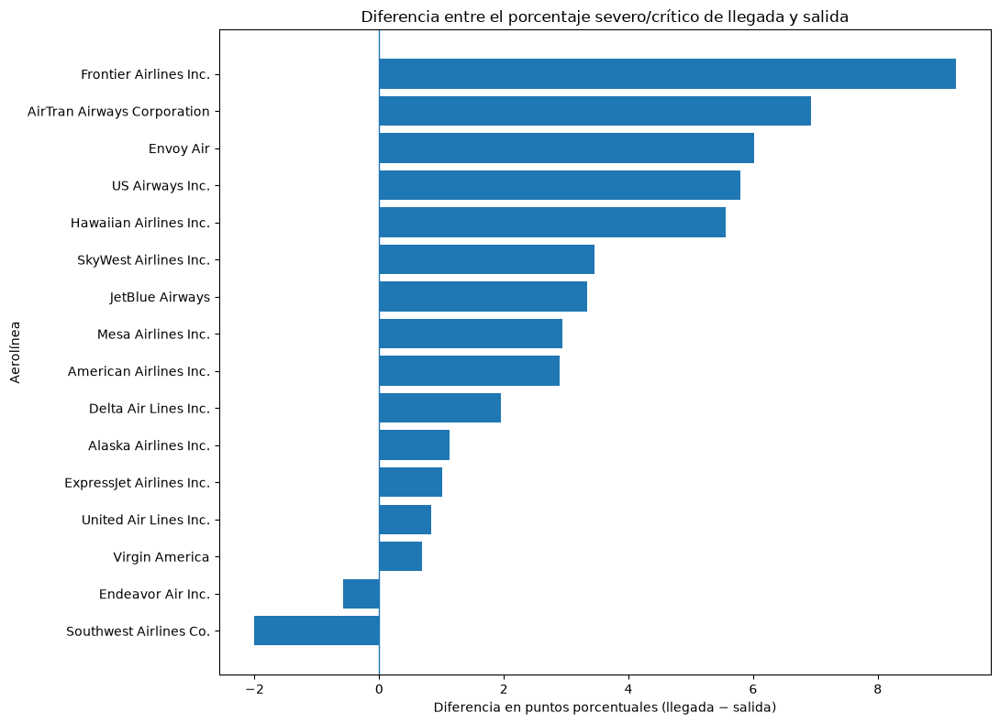


7. DIFERENCIA DE DEMORA EN MINUTOS
Se utiliza la columna existente diferencia_demora.
Un valor negativo indica que la demora de llegada es menor que la
de salida; un valor positivo indica que aumentó.
La mediana se utiliza como medida principal para reducir el efecto
de valores extremos.

Aerolíneas ordenadas desde mayor reducción hacia mayor aumento de demora:
aerolinea            nombre_aerolinea  vuelos_con_diferencia  mediana_diferencia_min  promedio_diferencia_min  vuelos_con_reduccion  pct_vuelos_con_reduccion  vuelos_con_aumento  pct_vuelos_con_aumento
       AS        Alaska Airlines Inc.                    709                   -17.0                   -15.76                   569                     80.25                 131                   18.48
       VX              Virgin America                   5116                   -12.0                   -10.99                  3709                     72.50                1320                   25.80
       HA      Hawaiian Airli

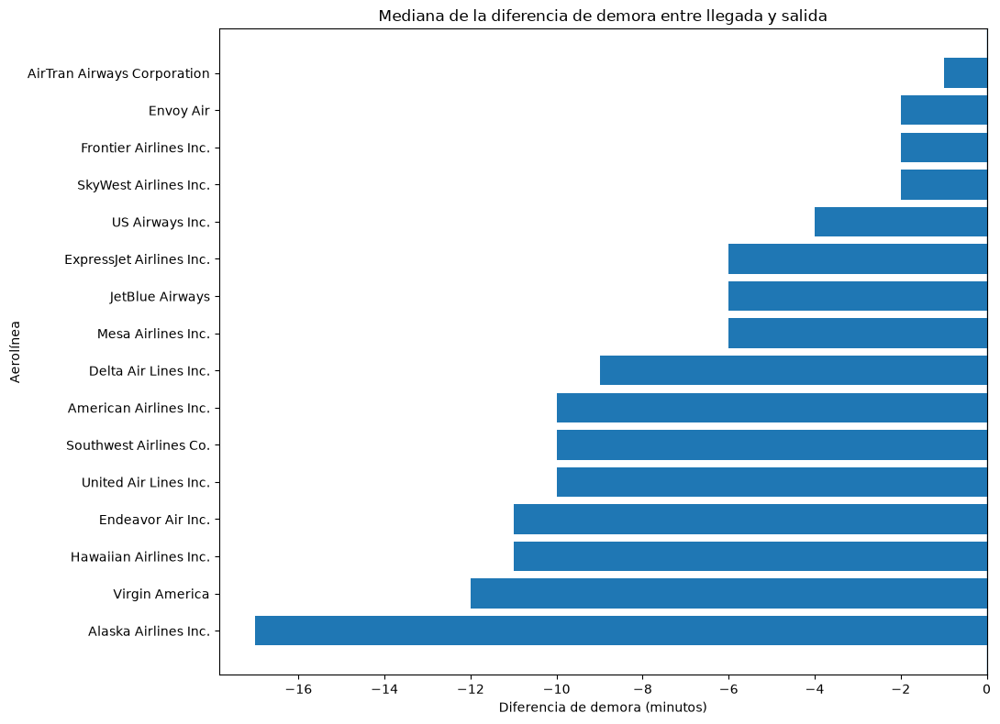

In [73]:
# ============================================================
# 2.4. RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
#      SEGÚN LA AEROLÍNEA
# ============================================================

print("=" * 80)
print("2.4 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA")
print("=" * 80)

# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados y niveles de puntualidad conocidos.")
print("El análisis principal se centra en las categorías severo y crítico.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Identificar vuelos evaluables en cada etapa.
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
)

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
)

# Indicadores de demora severa o crítica.
base["_salida_grave"] = (
    base["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
)

base["_arribo_grave"] = (
    base["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
)

# Para comparar ambas etapas sobre los mismos vuelos,
# conservar solamente aquellos con los dos niveles conocidos.
comparables = base.loc[
    base["_salida_evaluable"] & base["_arribo_evaluable"]
].copy()

print(f"Vuelos operados: {len(base):,}")
print(f"Vuelos evaluables en salida y llegada: {len(comparables):,}")


# ------------------------------------------------------------
# 2. Resumen general por aerolínea
# ------------------------------------------------------------

print("\n2. RESUMEN DE PUNTUALIDAD POR AEROLÍNEA")
print("Los porcentajes de salida y llegada se comparan usando")
print("los mismos vuelos evaluables en ambas etapas.")

claves = ["aerolinea", "nombre_aerolinea"]

# Estadísticas generales de cada etapa.
resumen_general = (
    base.groupby(claves, as_index=False)
    .agg(
        vuelos_operados=("id", "size"),
        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_grave", "sum"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

# Porcentajes independientes de cada etapa.
resumen_general["pct_salida_severa_critica"] = (
    100
    * resumen_general["salidas_severas_criticas"]
    / resumen_general["salidas_evaluables"].replace(0, np.nan)
)

resumen_general["pct_llegada_severa_critica"] = (
    100
    * resumen_general["llegadas_severas_criticas"]
    / resumen_general["llegadas_evaluables"].replace(0, np.nan)
)

# Comparación usando exactamente los mismos vuelos.
resumen_pareado = (
    comparables.groupby(claves, as_index=False)
    .agg(
        vuelos_comparables=("id", "size"),
        salidas_graves_comparables=("_salida_grave", "sum"),
        llegadas_graves_comparables=("_arribo_grave", "sum")
    )
)

resumen_pareado["pct_salida_grave_comparable"] = (
    100
    * resumen_pareado["salidas_graves_comparables"]
    / resumen_pareado["vuelos_comparables"].replace(0, np.nan)
)

resumen_pareado["pct_llegada_grave_comparable"] = (
    100
    * resumen_pareado["llegadas_graves_comparables"]
    / resumen_pareado["vuelos_comparables"].replace(0, np.nan)
)

# Diferencia expresada en puntos porcentuales.
# Positiva: más proporción de vuelos graves al llegar.
# Negativa: menos proporción de vuelos graves al llegar.
resumen_pareado["diferencia_llegada_salida_pp"] = (
    resumen_pareado["pct_llegada_grave_comparable"]
    - resumen_pareado["pct_salida_grave_comparable"]
)

resumen = resumen_general.merge(
    resumen_pareado,
    on=claves,
    how="left"
)

columnas_tabla = [
    "aerolinea",
    "nombre_aerolinea",
    "vuelos_operados",
    "vuelos_comparables",
    "pct_salida_grave_comparable",
    "pct_llegada_grave_comparable",
    "diferencia_llegada_salida_pp",
    "pct_salida_severa_critica",
    "pct_llegada_severa_critica"
]

tabla_resumen = resumen[columnas_tabla].copy()

columnas_pct = [
    "pct_salida_grave_comparable",
    "pct_llegada_grave_comparable",
    "diferencia_llegada_salida_pp",
    "pct_salida_severa_critica",
    "pct_llegada_severa_critica"
]

tabla_resumen[columnas_pct] = tabla_resumen[columnas_pct].round(2)

print("\nAerolíneas ordenadas por porcentaje de llegadas severas/críticas:")
print(
    tabla_resumen
    .sort_values("pct_llegada_grave_comparable", ascending=False)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Relación entre la categoría de salida y la llegada grave
# ------------------------------------------------------------

print("\n3. RELACIÓN ENTRE LA PUNTUALIDAD DE SALIDA Y LA LLEGADA")
print("Para cada aerolínea y nivel de salida, calculamos qué porcentaje")
print("de los vuelos llega con nivel severo o crítico.")
print("Se excluyen los vuelos cuyo nivel de salida o llegada es desconocido.")

orden_salida = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

detalle = (
    comparables.groupby(
        claves + ["nivel_puntualidad_salida"],
        as_index=False,
        observed=True
    )
    .agg(
        vuelos_categoria=("id", "size"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

detalle["pct_llegada_grave"] = (
    100
    * detalle["llegadas_severas_criticas"]
    / detalle["vuelos_categoria"].replace(0, np.nan)
)

# Matriz de porcentajes por aerolínea y nivel de salida.
matriz_pct = detalle.pivot(
    index="nombre_aerolinea",
    columns="nivel_puntualidad_salida",
    values="pct_llegada_grave"
).reindex(columns=orden_salida)

# Matriz de cantidades para contextualizar cada porcentaje.
matriz_n = detalle.pivot(
    index="nombre_aerolinea",
    columns="nivel_puntualidad_salida",
    values="vuelos_categoria"
).reindex(columns=orden_salida)

# Ordenar aerolíneas de mayor a menor porcentaje grave de llegada.
orden_aerolineas = (
    resumen_pareado
    .set_index("nombre_aerolinea")["pct_llegada_grave_comparable"]
    .sort_values(ascending=False)
    .index
)

matriz_pct = matriz_pct.reindex(orden_aerolineas)
matriz_n = matriz_n.reindex(orden_aerolineas)

print("\nPorcentaje de llegadas severas/críticas según el nivel de salida:")
print(matriz_pct.round(2).to_string())

print("\nCantidad de vuelos que integra cada grupo:")
print(matriz_n.fillna(0).astype(int).to_string())


# ------------------------------------------------------------
# 4. Gráfico: mapa de calor de salida y llegada
# ------------------------------------------------------------

print("\n4. GRÁFICO: NIVEL DE SALIDA FRENTE A LLEGADAS SEVERAS/CRÍTICAS")
print("Cada celda muestra el porcentaje de llegadas graves dentro")
print("de una categoría de salida. Entre paréntesis aparece la cantidad de vuelos.")

valores = np.ma.masked_invalid(matriz_pct.to_numpy(dtype=float))

fig, ax = plt.subplots(figsize=(12, 9))

imagen = ax.imshow(
    valores,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(orden_salida)))
ax.set_xticklabels(orden_salida, rotation=25, ha="right")

ax.set_yticks(range(len(matriz_pct.index)))
ax.set_yticklabels(matriz_pct.index)

ax.set_title(
    "Porcentaje de llegadas severas/críticas según puntualidad de salida"
)
ax.set_xlabel("Nivel de puntualidad de salida")
ax.set_ylabel("Aerolínea")

for i, aerolinea in enumerate(matriz_pct.index):
    for j, nivel in enumerate(orden_salida):
        porcentaje = matriz_pct.loc[aerolinea, nivel]
        cantidad = matriz_n.loc[aerolinea, nivel]

        if pd.notna(porcentaje) and pd.notna(cantidad):
            ax.text(
                j,
                i,
                f"{porcentaje:.1f}%\n(n={int(cantidad)})",
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: comparación de los porcentajes graves en ambas etapas
# ------------------------------------------------------------

print("\n5. GRÁFICO: SALIDA FRENTE A LLEGADA")
print("Se comparan los porcentajes severos/críticos sobre los mismos vuelos.")
print("Así podemos ver qué aerolíneas presentan una mayor proporción")
print("de vuelos graves al llegar que al salir.")

grafico_etapas = resumen_pareado.sort_values(
    "pct_llegada_grave_comparable",
    ascending=True
).set_index("nombre_aerolinea")

grafico_etapas[
    [
        "pct_salida_grave_comparable",
        "pct_llegada_grave_comparable"
    ]
].rename(
    columns={
        "pct_salida_grave_comparable": "Salida",
        "pct_llegada_grave_comparable": "Llegada"
    }
).plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8
)

plt.title("Porcentaje de vuelos severos/críticos en salida y llegada")
plt.xlabel("Porcentaje de vuelos comparables (%)")
plt.ylabel("Aerolínea")
plt.legend(title="Etapa")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico: diferencia entre porcentajes de salida y llegada
# ------------------------------------------------------------

print("\n6. GRÁFICO: DIFERENCIA ENTRE SALIDA Y LLEGADA")
print("La diferencia se expresa en puntos porcentuales.")
print("Un valor positivo indica mayor proporción de vuelos graves al llegar;")
print("uno negativo indica menor proporción de vuelos graves al llegar.")

grafico_diferencia = resumen_pareado.sort_values(
    "diferencia_llegada_salida_pp",
    ascending=True
).copy()

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    grafico_diferencia["nombre_aerolinea"],
    grafico_diferencia["diferencia_llegada_salida_pp"]
)

ax.axvline(0, linewidth=1)
ax.set_title(
    "Diferencia entre el porcentaje severo/crítico de llegada y salida"
)
ax.set_xlabel("Diferencia en puntos porcentuales (llegada − salida)")
ax.set_ylabel("Aerolínea")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Analizar si las demoras disminuyen o aumentan en minutos
# ------------------------------------------------------------

print("\n7. DIFERENCIA DE DEMORA EN MINUTOS")
print("Se utiliza la columna existente diferencia_demora.")
print("Un valor negativo indica que la demora de llegada es menor que la")
print("de salida; un valor positivo indica que aumentó.")
print("La mediana se utiliza como medida principal para reducir el efecto")
print("de valores extremos.")

# Esta columna existente representa la diferencia entre ambas demoras.
# Se transforma temporalmente a minutos, sin agregar columnas a df.
base["_diferencia_demora_min"] = (
    base["diferencia_demora"].dt.total_seconds() / 60
)

# Utilizar vuelos que tengan las dos demoras y la diferencia disponible.
demoras_comparables = base.loc[
    base["demora_salida_min"].notna()
    & base["demora_arribo_min"].notna()
    & base["_diferencia_demora_min"].notna()
].copy()

demoras_comparables["_demora_disminuye"] = (
    demoras_comparables["_diferencia_demora_min"] < 0
)

demoras_comparables["_demora_aumenta"] = (
    demoras_comparables["_diferencia_demora_min"] > 0
)

resumen_minutos = (
    demoras_comparables.groupby(claves, as_index=False)
    .agg(
        vuelos_con_diferencia=("id", "size"),
        mediana_diferencia_min=("_diferencia_demora_min", "median"),
        promedio_diferencia_min=("_diferencia_demora_min", "mean"),
        vuelos_con_reduccion=("_demora_disminuye", "sum"),
        vuelos_con_aumento=("_demora_aumenta", "sum")
    )
)

resumen_minutos["pct_vuelos_con_reduccion"] = (
    100
    * resumen_minutos["vuelos_con_reduccion"]
    / resumen_minutos["vuelos_con_diferencia"].replace(0, np.nan)
)

resumen_minutos["pct_vuelos_con_aumento"] = (
    100
    * resumen_minutos["vuelos_con_aumento"]
    / resumen_minutos["vuelos_con_diferencia"].replace(0, np.nan)
)

resumen_minutos = resumen_minutos.sort_values(
    "mediana_diferencia_min",
    ascending=True
)

columnas_minutos = [
    "aerolinea",
    "nombre_aerolinea",
    "vuelos_con_diferencia",
    "mediana_diferencia_min",
    "promedio_diferencia_min",
    "vuelos_con_reduccion",
    "pct_vuelos_con_reduccion",
    "vuelos_con_aumento",
    "pct_vuelos_con_aumento"
]

tabla_minutos = resumen_minutos[columnas_minutos].copy()

columnas_redondeo = [
    "mediana_diferencia_min",
    "promedio_diferencia_min",
    "pct_vuelos_con_reduccion",
    "pct_vuelos_con_aumento"
]

tabla_minutos[columnas_redondeo] = (
    tabla_minutos[columnas_redondeo].round(2)
)

print("\nAerolíneas ordenadas desde mayor reducción hacia mayor aumento de demora:")
print(tabla_minutos.to_string(index=False))


# ------------------------------------------------------------
# 8. Gráfico: mediana de la diferencia de demora en minutos
# ------------------------------------------------------------

print("\n8. GRÁFICO: MEDIANA DE LA DIFERENCIA DE DEMORA")
print("Valores negativos: en la llegada disminuyó la demora respecto a la salida.")
print("Valores positivos: en la llegada aumentó la demora respecto a la salida.")
print("El gráfico es complementario: el indicador principal sigue siendo")
print("la proporción de vuelos con demoras severas y críticas.")

grafico_minutos = resumen_minutos.sort_values(
    "mediana_diferencia_min",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    grafico_minutos["nombre_aerolinea"],
    grafico_minutos["mediana_diferencia_min"]
)

ax.axvline(0, linewidth=1)

ax.set_title("Mediana de la diferencia de demora entre llegada y salida")
ax.set_xlabel("Diferencia de demora (minutos)")
ax.set_ylabel("Aerolínea")

plt.tight_layout()
plt.show()

#### 2.5. Cantidad de vuelos diarios por avión y puntualidad según aerolínea

**Objetivo:** determinar si la cantidad de operaciones que realiza un avión durante el día se relaciona con su puntualidad y si ese patrón cambia según la aerolínea.

Preguntas que vamos a investigar:

- ¿La cantidad de vuelos diarios por avión se relaciona con las demoras de la misma manera en todas las aerolíneas?
- ¿Las compañías cuyos aviones realizan más operaciones diarias presentan mayores porcentajes de demoras severas y críticas?
- ¿Existen diferencias entre aerolíneas cuando sus aviones realizan cantidades similares de vuelos diarios?

**Enfoque del análisis:** combinaremos la aerolínea, la matrícula y la cantidad de vuelos diarios para comparar patrones de puntualidad. Consideraremos la cantidad de operaciones y los vuelos evaluables para no sacar conclusiones a partir de grupos muy pequeños.

El análisis de la secuencia de vuelos y del posible efecto de una demora sobre la operación siguiente se mantendrá en el bloque de efecto cascada.

2.5 | VUELOS DIARIOS POR AVIÓN Y DEMORAS SEVERAS/CRÍTICAS

1. PREPARACIÓN DE LOS DATOS
Se analizan vuelos operados con matrícula y fecha programada disponibles.
La cantidad diaria se calcula por matrícula y fecha de salida programada.
Vuelos operados en df: 328,521
Vuelos con matrícula y fecha programada válidas: 328,521
Matrículas identificadas: 4037

2. CANTIDAD DE OPERACIONES DIARIAS POR MATRÍCULA
El conteo considera todos los vuelos operados de una matrícula
en esa fecha programada, independientemente de la aerolínea.

Distribución de vuelos según la actividad diaria del avión:
_grupo_vuelos_dia
1 vuelo     186233
2 vuelos     97792
3 vuelos     34185
4 vuelos     10136
5 o más        175

3. IDENTIFICACIÓN DE VUELOS EVALUABLES Y DEMORAS GRAVES
Solo se consideran severas y críticas las categorías ya existentes.
Los niveles desconocidos no se incluyen en los denominadores.

4. TABLA RESUMEN POR AEROLÍNEA Y ACTIVIDAD DIARIA
La tabla permite comparar aerolíneas con aviones que realiza

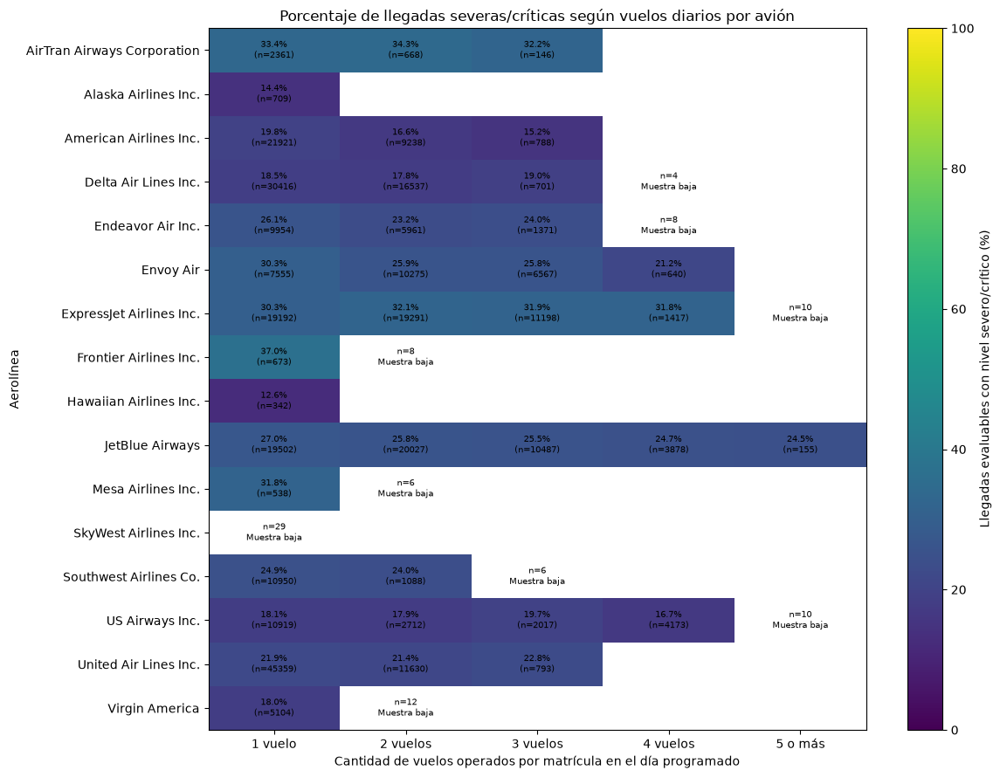


6. GRÁFICO: ACTIVIDAD DIARIA DEL AVIÓN Y DEMORAS GRAVES DE SALIDA
Se compara el porcentaje de salidas severas/críticas según
la cantidad de vuelos diarios y la aerolínea.
Solo se muestran porcentajes con al menos 30 salidas evaluables.


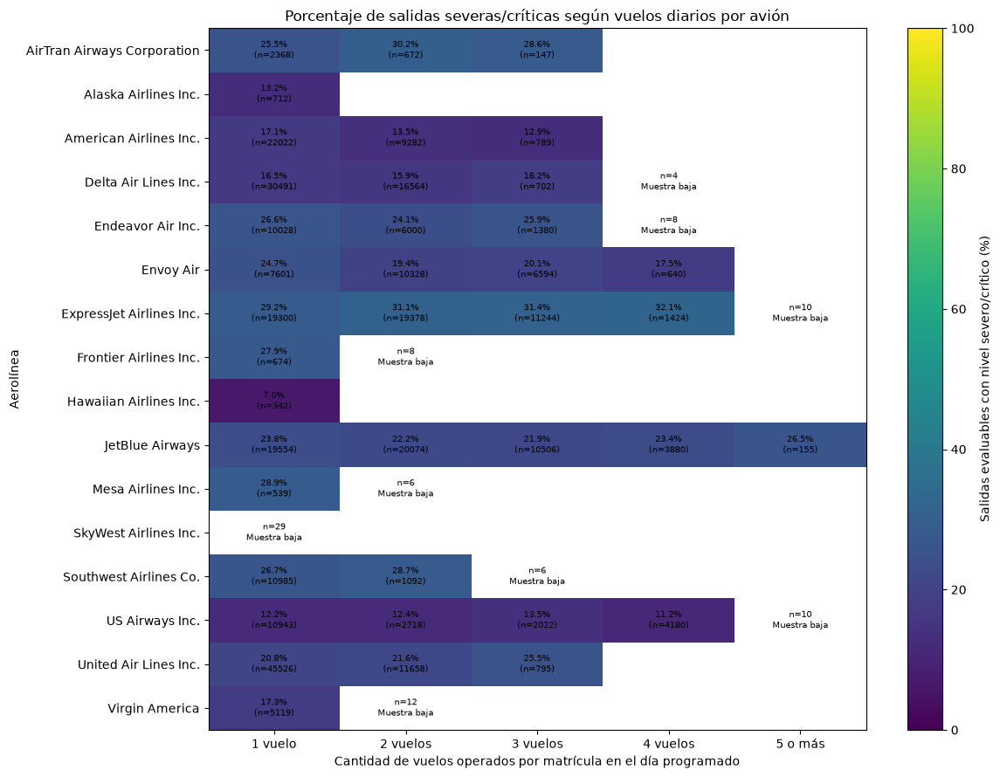


7. GRÁFICO: COMPORTAMIENTO GENERAL SEGÚN ACTIVIDAD DIARIA
Se reúnen todas las aerolíneas para observar si, en conjunto,
aumenta o disminuye el porcentaje severo/crítico al aumentar
la cantidad de operaciones diarias por matrícula.


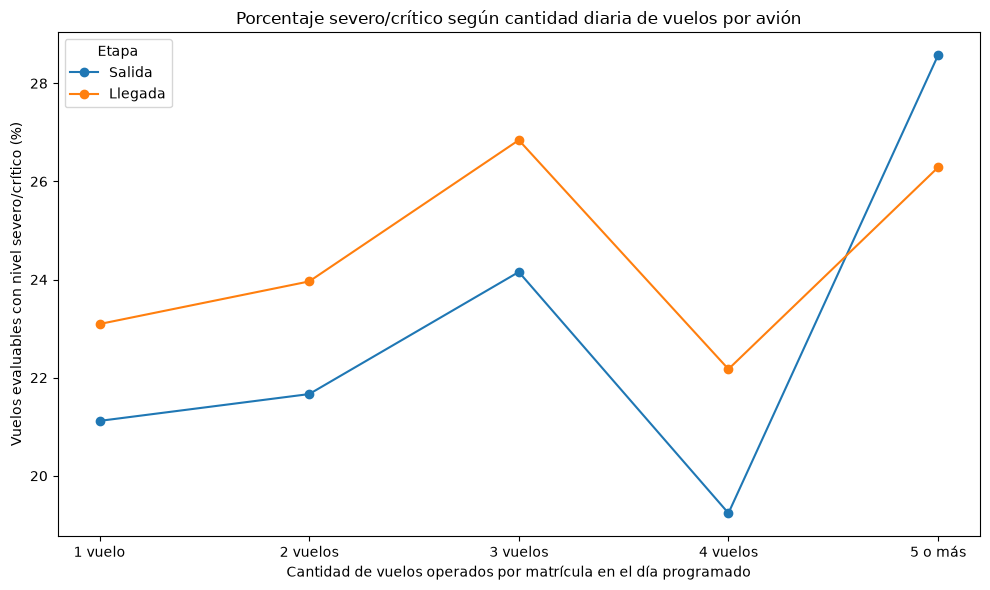


Resumen general por cantidad de vuelos diarios:
                   vuelos_en_grupo  salidas_evaluables  pct_salidas_severas_criticas  llegadas_evaluables  pct_llegadas_severas_criticas
_grupo_vuelos_dia                                                                                                                       
1 vuelo                     186233              186233                         21.12               185524                          23.09
2 vuelos                     97792               97792                         21.67                97453                          23.96
3 vuelos                     34185               34185                         24.15                34074                          26.84
4 vuelos                     10136               10136                         19.24                10120                          22.17
5 o más                        175                 175                         28.57                  175                        

In [74]:
# ============================================================
# 2.5. CANTIDAD DE VUELOS DIARIOS POR AVIÓN Y PUNTUALIDAD
#      SEGÚN AEROLÍNEA
# ============================================================

print("=" * 80)
print("2.5 | VUELOS DIARIOS POR AVIÓN Y DEMORAS SEVERAS/CRÍTICAS")
print("=" * 80)


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se analizan vuelos operados con matrícula y fecha programada disponibles.")
print("La cantidad diaria se calcula por matrícula y fecha de salida programada.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

vuelos_operados_total = len(base)

# Clave auxiliar de matrícula: elimina espacios en los extremos.
base["_matricula_analisis"] = (
    base["matricula_avion"]
    .astype("string")
    .str.strip()
)

# Utilizamos la fecha de salida programada existente.
# normalize() conserva la fecha y deja la hora en 00:00.
base["_fecha_programada_analisis"] = (
    base["fecha_hora_salida_programada"].dt.normalize()
)

# Excluir registros sin matrícula o fecha para este análisis.
base = base.loc[
    base["_matricula_analisis"].notna()
    & base["_matricula_analisis"].ne("").fillna(False)
    & base["_fecha_programada_analisis"].notna()
].copy()

print(f"Vuelos operados en df: {vuelos_operados_total:,}")
print(f"Vuelos con matrícula y fecha programada válidas: {len(base):,}")
print(
    "Matrículas identificadas:",
    base["_matricula_analisis"].nunique()
)


# ------------------------------------------------------------
# 2. Contar vuelos por matrícula y día
# ------------------------------------------------------------

print("\n2. CANTIDAD DE OPERACIONES DIARIAS POR MATRÍCULA")
print("El conteo considera todos los vuelos operados de una matrícula")
print("en esa fecha programada, independientemente de la aerolínea.")

conteo_diario = (
    base.groupby(
        ["_matricula_analisis", "_fecha_programada_analisis"],
        as_index=False
    )
    .agg(
        vuelos_avion_dia=("id", "size")
    )
)

# Incorporar el conteo diario a cada vuelo.
# El conteo se calcula por matrícula y fecha, no por aerolínea.
base = base.merge(
    conteo_diario,
    on=["_matricula_analisis", "_fecha_programada_analisis"],
    how="left",
    validate="many_to_one"
)

# Clasificar los días según la cantidad de operaciones del avión.
grupos_vuelos_dia = [
    "1 vuelo",
    "2 vuelos",
    "3 vuelos",
    "4 vuelos",
    "5 o más"
]

base["_grupo_vuelos_dia"] = pd.cut(
    base["vuelos_avion_dia"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=grupos_vuelos_dia,
    include_lowest=True,
    ordered=True
)

print("\nDistribución de vuelos según la actividad diaria del avión:")
print(
    base["_grupo_vuelos_dia"]
    .value_counts(sort=False, dropna=False)
    .to_string()
)


# ------------------------------------------------------------
# 3. Preparar los indicadores de puntualidad
# ------------------------------------------------------------

print("\n3. IDENTIFICACIÓN DE VUELOS EVALUABLES Y DEMORAS GRAVES")
print("Solo se consideran severas y críticas las categorías ya existentes.")
print("Los niveles desconocidos no se incluyen en los denominadores.")

base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
).astype("int8")

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

base["_salida_grave"] = (
    base["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
).astype("int8")

base["_arribo_grave"] = (
    base["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
).astype("int8")


# ------------------------------------------------------------
# 4. Resumen por aerolínea y cantidad diaria de vuelos
# ------------------------------------------------------------

print("\n4. TABLA RESUMEN POR AEROLÍNEA Y ACTIVIDAD DIARIA")
print("La tabla permite comparar aerolíneas con aviones que realizan")
print("cantidades similares de vuelos diarios.")

claves_aerolinea = [
    "aerolinea",
    "nombre_aerolinea"
]

resumen_dia = (
    base.groupby(
        claves_aerolinea + ["_grupo_vuelos_dia"],
        as_index=False,
        observed=True
    )
    .agg(
        vuelos_en_grupo=("id", "size"),

        matriculas_distintas=("_matricula_analisis", "nunique"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_grave", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

# Porcentaje de salida severa/crítica.
resumen_dia["pct_salidas_severas_criticas"] = (
    100
    * resumen_dia["salidas_severas_criticas"]
    / resumen_dia["salidas_evaluables"].replace(0, np.nan)
)

# Porcentaje de llegada severa/crítica.
resumen_dia["pct_llegadas_severas_criticas"] = (
    100
    * resumen_dia["llegadas_severas_criticas"]
    / resumen_dia["llegadas_evaluables"].replace(0, np.nan)
)

columnas_tabla = [
    "aerolinea",
    "nombre_aerolinea",
    "_grupo_vuelos_dia",
    "vuelos_en_grupo",
    "matriculas_distintas",
    "salidas_evaluables",
    "salidas_severas_criticas",
    "pct_salidas_severas_criticas",
    "llegadas_evaluables",
    "llegadas_severas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_resumen = resumen_dia[columnas_tabla].copy()

tabla_resumen[
    [
        "pct_salidas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
] = tabla_resumen[
    [
        "pct_salidas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
].round(2)

tabla_resumen = tabla_resumen.sort_values(
    ["_grupo_vuelos_dia", "pct_llegadas_severas_criticas"],
    ascending=[True, False]
)

print(tabla_resumen.to_string(index=False))


# ------------------------------------------------------------
# 5. Preparar matrices para los mapas de calor
# ------------------------------------------------------------

# Umbral orientativo para mostrar porcentajes en los gráficos.
# Los conteos se mantienen visibles aunque el grupo sea pequeño.
MIN_EVALUABLES = 30

orden_aerolineas = sorted(
    base["nombre_aerolinea"].dropna().unique()
)

matriz_llegadas = (
    resumen_dia
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_vuelos_dia",
        values="pct_llegadas_severas_criticas"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_vuelos_dia
    )
)

matriz_n_llegadas = (
    resumen_dia
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_vuelos_dia",
        values="llegadas_evaluables"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_vuelos_dia
    )
)

matriz_salidas = (
    resumen_dia
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_vuelos_dia",
        values="pct_salidas_severas_criticas"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_vuelos_dia
    )
)

matriz_n_salidas = (
    resumen_dia
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_vuelos_dia",
        values="salidas_evaluables"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_vuelos_dia
    )
)


# ------------------------------------------------------------
# 6. Gráfico: porcentaje de llegadas severas/críticas
# ------------------------------------------------------------

print("\n5. GRÁFICO: ACTIVIDAD DIARIA DEL AVIÓN Y DEMORAS GRAVES DE LLEGADA")
print("Cada celda representa una aerolínea y una cantidad de vuelos diarios.")
print("Se muestra el porcentaje de llegadas severas/críticas.")
print(f"Para mostrar un porcentaje se requieren al menos {MIN_EVALUABLES} llegadas evaluables.")
print("Los grupos menores se identifican con su cantidad de observaciones.")

matriz_llegadas_visible = matriz_llegadas.where(
    matriz_n_llegadas >= MIN_EVALUABLES
)

datos_llegadas = np.ma.masked_invalid(
    matriz_llegadas_visible.to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(12, 9))

imagen = ax.imshow(
    datos_llegadas,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(grupos_vuelos_dia)))
ax.set_xticklabels(grupos_vuelos_dia)

ax.set_yticks(range(len(orden_aerolineas)))
ax.set_yticklabels(orden_aerolineas)

ax.set_title(
    "Porcentaje de llegadas severas/críticas según vuelos diarios por avión"
)
ax.set_xlabel("Cantidad de vuelos operados por matrícula en el día programado")
ax.set_ylabel("Aerolínea")

for i, aerolinea in enumerate(orden_aerolineas):
    for j, grupo in enumerate(grupos_vuelos_dia):

        cantidad = matriz_n_llegadas.loc[aerolinea, grupo]
        porcentaje = matriz_llegadas.loc[aerolinea, grupo]

        if pd.notna(cantidad) and cantidad > 0:

            if cantidad >= MIN_EVALUABLES and pd.notna(porcentaje):
                etiqueta = f"{porcentaje:.1f}%\n(n={int(cantidad)})"
            else:
                etiqueta = f"n={int(cantidad)}\nMuestra baja"

            ax.text(
                j,
                i,
                etiqueta,
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas evaluables con nivel severo/crítico (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Gráfico: porcentaje de salidas severas/críticas
# ------------------------------------------------------------

print("\n6. GRÁFICO: ACTIVIDAD DIARIA DEL AVIÓN Y DEMORAS GRAVES DE SALIDA")
print("Se compara el porcentaje de salidas severas/críticas según")
print("la cantidad de vuelos diarios y la aerolínea.")
print(f"Solo se muestran porcentajes con al menos {MIN_EVALUABLES} salidas evaluables.")

matriz_salidas_visible = matriz_salidas.where(
    matriz_n_salidas >= MIN_EVALUABLES
)

datos_salidas = np.ma.masked_invalid(
    matriz_salidas_visible.to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(12, 9))

imagen = ax.imshow(
    datos_salidas,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(grupos_vuelos_dia)))
ax.set_xticklabels(grupos_vuelos_dia)

ax.set_yticks(range(len(orden_aerolineas)))
ax.set_yticklabels(orden_aerolineas)

ax.set_title(
    "Porcentaje de salidas severas/críticas según vuelos diarios por avión"
)
ax.set_xlabel("Cantidad de vuelos operados por matrícula en el día programado")
ax.set_ylabel("Aerolínea")

for i, aerolinea in enumerate(orden_aerolineas):
    for j, grupo in enumerate(grupos_vuelos_dia):

        cantidad = matriz_n_salidas.loc[aerolinea, grupo]
        porcentaje = matriz_salidas.loc[aerolinea, grupo]

        if pd.notna(cantidad) and cantidad > 0:

            if cantidad >= MIN_EVALUABLES and pd.notna(porcentaje):
                etiqueta = f"{porcentaje:.1f}%\n(n={int(cantidad)})"
            else:
                etiqueta = f"n={int(cantidad)}\nMuestra baja"

            ax.text(
                j,
                i,
                etiqueta,
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Salidas evaluables con nivel severo/crítico (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Gráfico: comportamiento general según cantidad de vuelos diarios
# ------------------------------------------------------------

print("\n7. GRÁFICO: COMPORTAMIENTO GENERAL SEGÚN ACTIVIDAD DIARIA")
print("Se reúnen todas las aerolíneas para observar si, en conjunto,")
print("aumenta o disminuye el porcentaje severo/crítico al aumentar")
print("la cantidad de operaciones diarias por matrícula.")

resumen_global = (
    base.groupby(
        "_grupo_vuelos_dia",
        as_index=False,
        observed=True
    )
    .agg(
        vuelos_en_grupo=("id", "size"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_grave", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

resumen_global["pct_salidas_severas_criticas"] = (
    100
    * resumen_global["salidas_severas_criticas"]
    / resumen_global["salidas_evaluables"].replace(0, np.nan)
)

resumen_global["pct_llegadas_severas_criticas"] = (
    100
    * resumen_global["llegadas_severas_criticas"]
    / resumen_global["llegadas_evaluables"].replace(0, np.nan)
)

resumen_global = (
    resumen_global
    .set_index("_grupo_vuelos_dia")
    .reindex(grupos_vuelos_dia)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    grupos_vuelos_dia,
    resumen_global["pct_salidas_severas_criticas"],
    marker="o",
    label="Salida"
)

ax.plot(
    grupos_vuelos_dia,
    resumen_global["pct_llegadas_severas_criticas"],
    marker="o",
    label="Llegada"
)

ax.set_title(
    "Porcentaje severo/crítico según cantidad diaria de vuelos por avión"
)
ax.set_xlabel("Cantidad de vuelos operados por matrícula en el día programado")
ax.set_ylabel("Vuelos evaluables con nivel severo/crítico (%)")
ax.legend(title="Etapa")
plt.tight_layout()
plt.show()

print("\nResumen general por cantidad de vuelos diarios:")
print(
    resumen_global[
        [
            "vuelos_en_grupo",
            "salidas_evaluables",
            "pct_salidas_severas_criticas",
            "llegadas_evaluables",
            "pct_llegadas_severas_criticas"
        ]
    ].round(2).to_string()
)

#### 2.6. Relación entre el número de vuelo y la distancia recorrida

**Objetivo:** explorar si existe alguna asociación entre la cantidad de cifras del número de vuelo y la distancia recorrida, y determinar si el patrón varía entre aerolíneas.

Preguntas que vamos a investigar:

- ¿Existe una relación entre la cantidad de cifras del número de vuelo y la distancia recorrida?
- ¿Las aerolíneas presentan patrones similares o diferentes?
- ¿Los vuelos con números de distinta longitud muestran diferencias de distancia o puntualidad?

**Enfoque del análisis:** utilizaremos las variables `vuelo`, `distancia_nm` y `aerolinea`. Este análisis será exploratorio: no asumiremos que la cantidad de cifras del número de vuelo representa directamente la distancia ni que existe una regla común para todas las compañías.

2.6 | NÚMERO DE VUELO, DISTANCIA Y PUNTUALIDAD

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados con número de vuelo y distancia disponibles.
La puntualidad se evalúa mediante los niveles severo y crítico.
Vuelos operados analizados: 328,521
Aerolíneas identificadas: 16

2. DISTRIBUCIÓN DE LOS NÚMEROS DE VUELO
Se cuenta cuántos vuelos corresponden a cada longitud numérica.
_grupo_cifras
1 cifra       2924
2 cifras     14689
3 cifras    105085
4 cifras    205823
5 o más          0

3. DISTANCIA Y PUNTUALIDAD SEGÚN LA CANTIDAD DE CIFRAS
Los porcentajes severos/críticos se calculan sobre los vuelos evaluables.

Resumen general:
                 vuelos  distancia_mediana_nm  distancia_promedio_nm  salidas_evaluables  salidas_severas_criticas  llegadas_evaluables  llegadas_severas_criticas  pct_salida_severa_critica  pct_llegada_severa_critica
_grupo_cifras                                                                                                                               

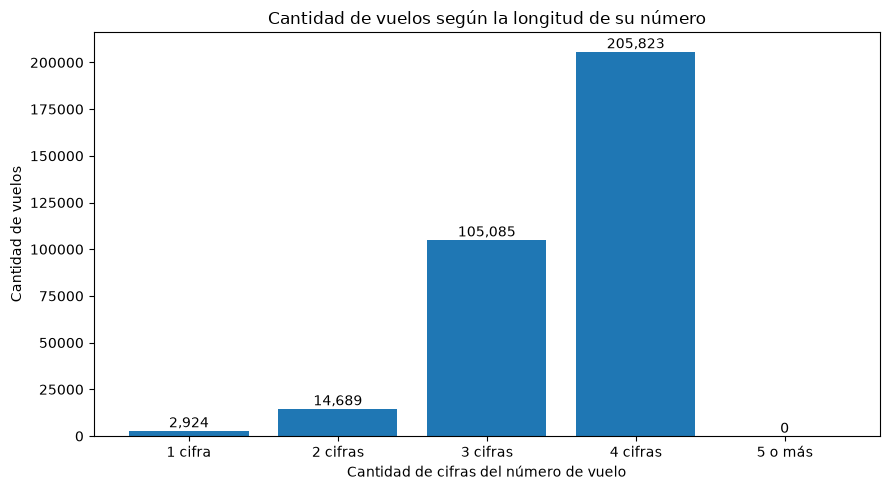


5. GRÁFICO: DISTRIBUCIÓN DE DISTANCIAS POR NÚMERO DE CIFRAS
El diagrama de caja permite comparar las distancias y su dispersión.
La línea central representa la mediana de cada grupo.


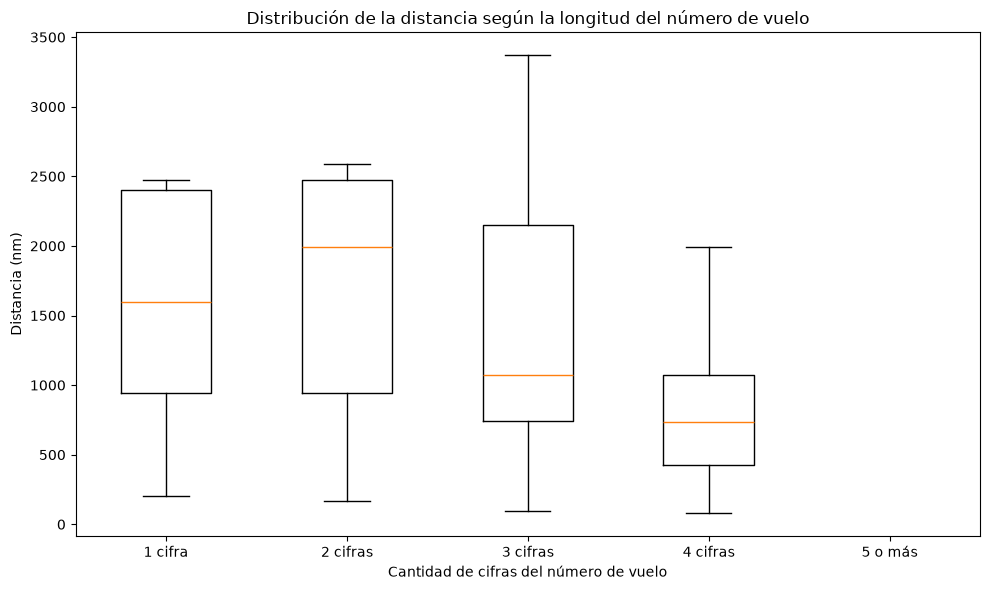


6. RESUMEN POR AEROLÍNEA Y LONGITUD DEL NÚMERO
Permite comparar vuelos de números con igual longitud dentro
de cada compañía, tanto por distancia como por puntualidad.

Tabla por aerolínea y cantidad de cifras:
aerolinea            nombre_aerolinea _grupo_cifras  vuelos  distancia_mediana_nm  distancia_promedio_nm  salidas_evaluables  pct_salida_severa_critica  llegadas_evaluables  pct_llegada_severa_critica
       9E           Endeavor Air Inc.      4 cifras   17416                 509.0                 531.50               17416                      25.67                17294                       24.92
       AA      American Airlines Inc.       1 cifra     724                2475.0                2475.00                 724                       7.04                  723                       11.48
       AA      American Airlines Inc.      2 cifras    2381                2475.0                2264.06                2381                      16.97                 2373             

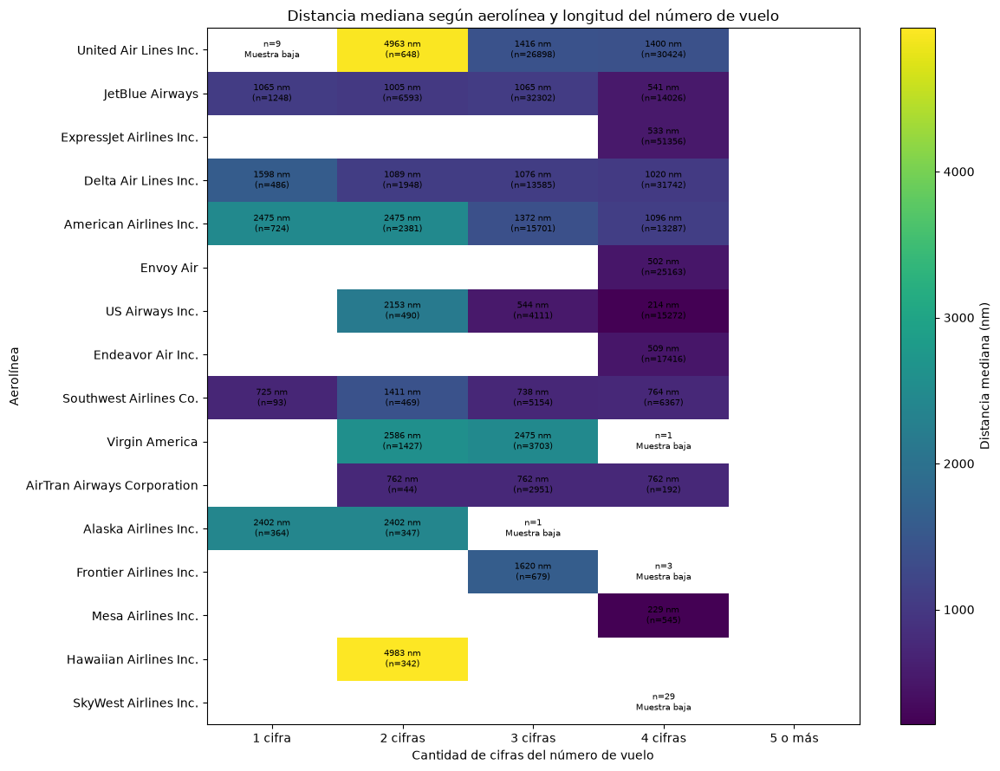


8. GRÁFICO: DEMORAS SEVERAS/CRÍTICAS POR AEROLÍNEA Y CIFRAS
Se compara el porcentaje de llegadas severas/críticas dentro
de cada combinación de aerolínea y longitud del número.
Solo se muestran porcentajes con al menos 30 llegadas evaluables.


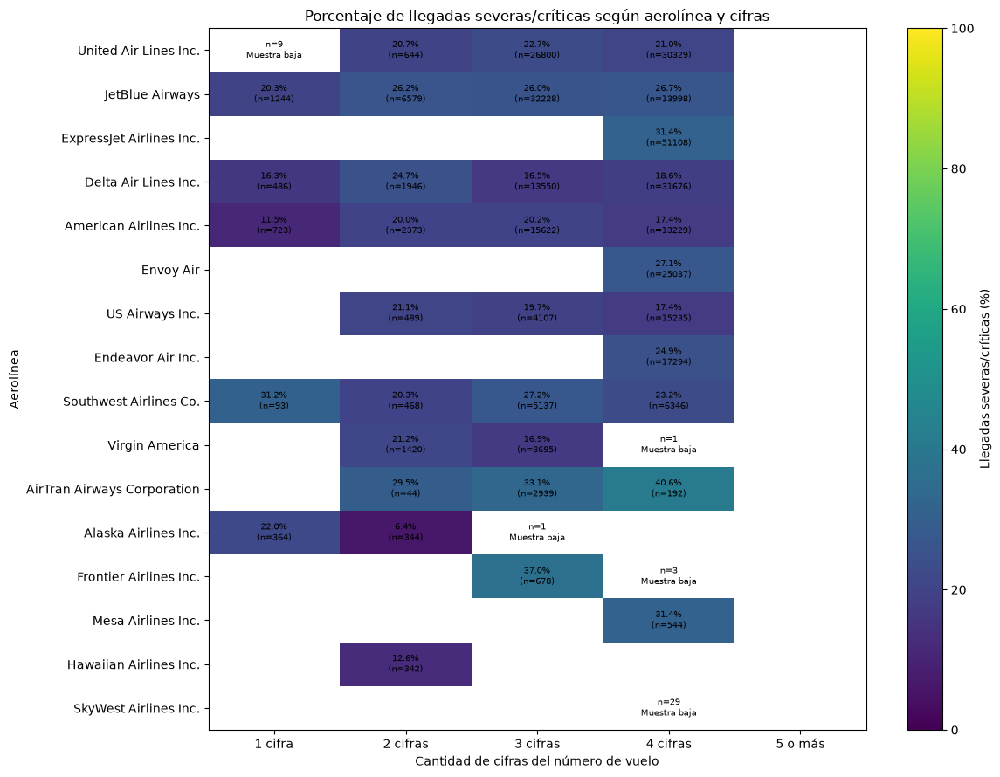


9. GRÁFICO: PUNTUALIDAD SEGÚN CANTIDAD DE CIFRAS
Compara los porcentajes severos/críticos de salida y llegada
para observar si existen diferencias generales entre los grupos.


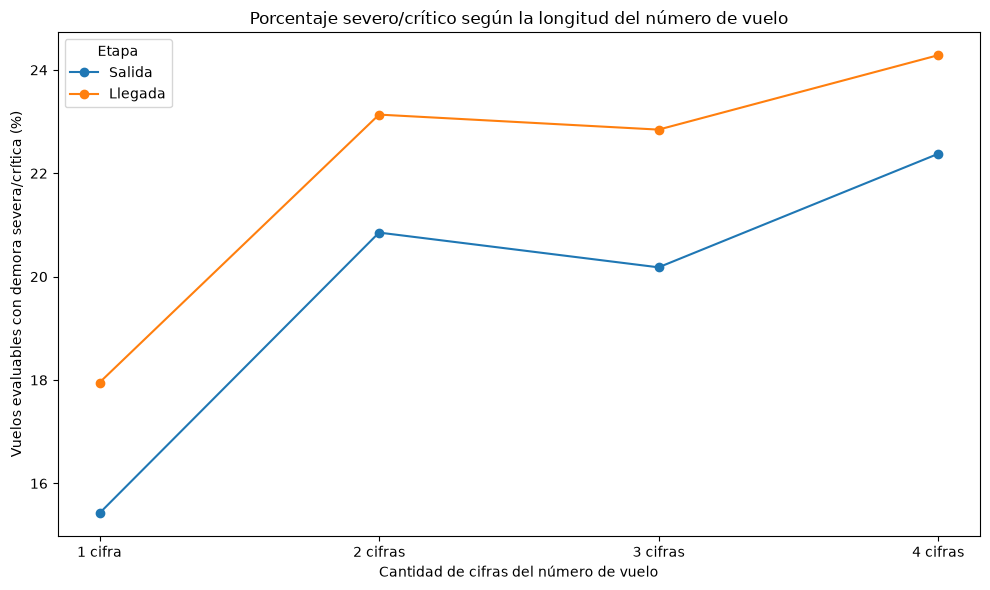

In [75]:

# ============================================================
# 2.6. RELACIÓN ENTRE EL NÚMERO DE VUELO Y LA DISTANCIA
#      RECORRIDA
# ============================================================

print("=" * 80)
print("2.6 | NÚMERO DE VUELO, DISTANCIA Y PUNTUALIDAD")
print("=" * 80)


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados con número de vuelo y distancia disponibles.")
print("La puntualidad se evalúa mediante los niveles severo y crítico.")

base = df.loc[
    df["estado_vuelo"].eq("operado")
    & df["vuelo"].notna()
    & df["distancia_nm"].notna()
].copy()

# Calcular temporalmente la cantidad de cifras del número de vuelo.
base["_numero_cifras"] = (
    base["vuelo"]
    .astype("Int64")
    .astype("string")
    .str.len()
    .astype("Int64")
)

# Agrupar en categorías para facilitar la comparación.
grupos_cifras = [
    "1 cifra",
    "2 cifras",
    "3 cifras",
    "4 cifras",
    "5 o más"
]

base["_grupo_cifras"] = pd.cut(
    base["_numero_cifras"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=grupos_cifras,
    include_lowest=True,
    ordered=True
)

# Niveles evaluables: se excluye "desconocido".
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
).astype("int8")

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Indicadores prioritarios de demoras severas y críticas.
base["_salida_grave"] = (
    base["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
).astype("int8")

base["_arribo_grave"] = (
    base["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
).astype("int8")

print(f"Vuelos operados analizados: {len(base):,}")
print(f"Aerolíneas identificadas: {base['aerolinea'].nunique()}")


# ------------------------------------------------------------
# 2. Distribución de vuelos por cantidad de cifras
# ------------------------------------------------------------

print("\n2. DISTRIBUCIÓN DE LOS NÚMEROS DE VUELO")
print("Se cuenta cuántos vuelos corresponden a cada longitud numérica.")

conteo_cifras = (
    base["_grupo_cifras"]
    .value_counts(sort=False)
    .reindex(grupos_cifras, fill_value=0)
)

print(conteo_cifras.rename("cantidad_vuelos").to_string())


# ------------------------------------------------------------
# 3. Resumen general por cantidad de cifras
# ------------------------------------------------------------

print("\n3. DISTANCIA Y PUNTUALIDAD SEGÚN LA CANTIDAD DE CIFRAS")
print("Los porcentajes severos/críticos se calculan sobre los vuelos evaluables.")

resumen_global = (
    base.groupby("_grupo_cifras", observed=True)
    .agg(
        vuelos=("id", "size"),
        distancia_mediana_nm=("distancia_nm", "median"),
        distancia_promedio_nm=("distancia_nm", "mean"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_grave", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
    .reindex(grupos_cifras)
)

resumen_global["pct_salida_severa_critica"] = (
    100
    * resumen_global["salidas_severas_criticas"]
    / resumen_global["salidas_evaluables"].replace(0, np.nan)
)

resumen_global["pct_llegada_severa_critica"] = (
    100
    * resumen_global["llegadas_severas_criticas"]
    / resumen_global["llegadas_evaluables"].replace(0, np.nan)
)

print("\nResumen general:")
print(resumen_global.round(2).to_string())


# ------------------------------------------------------------
# 4. Gráfico: cantidad de vuelos por longitud numérica
# ------------------------------------------------------------

print("\n4. GRÁFICO: CANTIDAD DE VUELOS POR NÚMERO DE CIFRAS")
print("Permite observar cuáles son las longitudes numéricas más frecuentes.")

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    grupos_cifras,
    conteo_cifras.values
)

for barra in barras:
    altura = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f"{altura:,.0f}",
        ha="center",
        va="bottom"
    )

ax.set_title("Cantidad de vuelos según la longitud de su número")
ax.set_xlabel("Cantidad de cifras del número de vuelo")
ax.set_ylabel("Cantidad de vuelos")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: distancia según cantidad de cifras
# ------------------------------------------------------------

print("\n5. GRÁFICO: DISTRIBUCIÓN DE DISTANCIAS POR NÚMERO DE CIFRAS")
print("El diagrama de caja permite comparar las distancias y su dispersión.")
print("La línea central representa la mediana de cada grupo.")

datos_distancia = [
    base.loc[
        base["_grupo_cifras"].eq(grupo),
        "distancia_nm"
    ].dropna().to_numpy()
    for grupo in grupos_cifras
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    datos_distancia,
    tick_labels=grupos_cifras,
    showfliers=False
)

ax.set_title("Distribución de la distancia según la longitud del número de vuelo")
ax.set_xlabel("Cantidad de cifras del número de vuelo")
ax.set_ylabel("Distancia (nm)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Resumen por aerolínea y cantidad de cifras
# ------------------------------------------------------------

print("\n6. RESUMEN POR AEROLÍNEA Y LONGITUD DEL NÚMERO")
print("Permite comparar vuelos de números con igual longitud dentro")
print("de cada compañía, tanto por distancia como por puntualidad.")

claves = [
    "aerolinea",
    "nombre_aerolinea",
    "_grupo_cifras"
]

resumen_aerolinea = (
    base.groupby(
        claves,
        observed=True,
        as_index=False
    )
    .agg(
        vuelos=("id", "size"),

        distancia_mediana_nm=("distancia_nm", "median"),
        distancia_promedio_nm=("distancia_nm", "mean"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas_criticas=("_salida_grave", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

resumen_aerolinea["pct_salida_severa_critica"] = (
    100
    * resumen_aerolinea["salidas_severas_criticas"]
    / resumen_aerolinea["salidas_evaluables"].replace(0, np.nan)
)

resumen_aerolinea["pct_llegada_severa_critica"] = (
    100
    * resumen_aerolinea["llegadas_severas_criticas"]
    / resumen_aerolinea["llegadas_evaluables"].replace(0, np.nan)
)

columnas_tabla = [
    "aerolinea",
    "nombre_aerolinea",
    "_grupo_cifras",
    "vuelos",
    "distancia_mediana_nm",
    "distancia_promedio_nm",
    "salidas_evaluables",
    "pct_salida_severa_critica",
    "llegadas_evaluables",
    "pct_llegada_severa_critica"
]

tabla_aerolineas = resumen_aerolinea[columnas_tabla].copy()

tabla_aerolineas[
    [
        "distancia_mediana_nm",
        "distancia_promedio_nm",
        "pct_salida_severa_critica",
        "pct_llegada_severa_critica"
    ]
] = tabla_aerolineas[
    [
        "distancia_mediana_nm",
        "distancia_promedio_nm",
        "pct_salida_severa_critica",
        "pct_llegada_severa_critica"
    ]
].round(2)

print("\nTabla por aerolínea y cantidad de cifras:")
print(
    tabla_aerolineas.sort_values(
        ["aerolinea", "_grupo_cifras"]
    ).to_string(index=False)
)


# ------------------------------------------------------------
# 7. Gráfico: mediana de distancia por aerolínea y cifras
# ------------------------------------------------------------

print("\n7. GRÁFICO: DISTANCIA MEDIANA POR AEROLÍNEA Y LONGITUD NUMÉRICA")
print("Cada celda muestra la distancia mediana del grupo.")
print("Las celdas con menos de 30 vuelos se identifican como muestra baja.")

MIN_VUELOS = 30

orden_aerolineas = (
    base.groupby("nombre_aerolinea")
    .size()
    .sort_values(ascending=False)
    .index.tolist()
)

matriz_distancia = (
    resumen_aerolinea
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_cifras",
        values="distancia_mediana_nm"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_cifras
    )
)

matriz_vuelos = (
    resumen_aerolinea
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_cifras",
        values="vuelos"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_cifras
    )
)

matriz_distancia_visible = matriz_distancia.where(
    matriz_vuelos >= MIN_VUELOS
)

datos_mapa_distancia = np.ma.masked_invalid(
    matriz_distancia_visible.to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(12, 9))

imagen = ax.imshow(
    datos_mapa_distancia,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(grupos_cifras)))
ax.set_xticklabels(grupos_cifras)

ax.set_yticks(range(len(orden_aerolineas)))
ax.set_yticklabels(orden_aerolineas)

ax.set_title("Distancia mediana según aerolínea y longitud del número de vuelo")
ax.set_xlabel("Cantidad de cifras del número de vuelo")
ax.set_ylabel("Aerolínea")

for i, aerolinea in enumerate(orden_aerolineas):
    for j, grupo in enumerate(grupos_cifras):
        cantidad = matriz_vuelos.loc[aerolinea, grupo]
        distancia = matriz_distancia.loc[aerolinea, grupo]

        if pd.notna(cantidad) and cantidad > 0:
            if cantidad >= MIN_VUELOS and pd.notna(distancia):
                etiqueta = f"{distancia:.0f} nm\n(n={int(cantidad)})"
            else:
                etiqueta = f"n={int(cantidad)}\nMuestra baja"

            ax.text(
                j,
                i,
                etiqueta,
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Distancia mediana (nm)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Gráfico: porcentaje de llegadas severas/críticas
#    por aerolínea y longitud
# ------------------------------------------------------------

print("\n8. GRÁFICO: DEMORAS SEVERAS/CRÍTICAS POR AEROLÍNEA Y CIFRAS")
print("Se compara el porcentaje de llegadas severas/críticas dentro")
print("de cada combinación de aerolínea y longitud del número.")
print("Solo se muestran porcentajes con al menos 30 llegadas evaluables.")

matriz_pct_llegada = (
    resumen_aerolinea
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_cifras",
        values="pct_llegada_severa_critica"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_cifras
    )
)

matriz_eval_llegada = (
    resumen_aerolinea
    .pivot(
        index="nombre_aerolinea",
        columns="_grupo_cifras",
        values="llegadas_evaluables"
    )
    .reindex(
        index=orden_aerolineas,
        columns=grupos_cifras
    )
)

matriz_pct_visible = matriz_pct_llegada.where(
    matriz_eval_llegada >= MIN_VUELOS
)

datos_mapa_pct = np.ma.masked_invalid(
    matriz_pct_visible.to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(12, 9))

imagen = ax.imshow(
    datos_mapa_pct,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(grupos_cifras)))
ax.set_xticklabels(grupos_cifras)

ax.set_yticks(range(len(orden_aerolineas)))
ax.set_yticklabels(orden_aerolineas)

ax.set_title(
    "Porcentaje de llegadas severas/críticas según aerolínea y cifras"
)
ax.set_xlabel("Cantidad de cifras del número de vuelo")
ax.set_ylabel("Aerolínea")

for i, aerolinea in enumerate(orden_aerolineas):
    for j, grupo in enumerate(grupos_cifras):
        cantidad = matriz_eval_llegada.loc[aerolinea, grupo]
        porcentaje = matriz_pct_llegada.loc[aerolinea, grupo]

        if pd.notna(cantidad) and cantidad > 0:
            if cantidad >= MIN_VUELOS and pd.notna(porcentaje):
                etiqueta = f"{porcentaje:.1f}%\n(n={int(cantidad)})"
            else:
                etiqueta = f"n={int(cantidad)}\nMuestra baja"

            ax.text(
                j,
                i,
                etiqueta,
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Gráfico: comparación general de salida y llegada
# ------------------------------------------------------------

print("\n9. GRÁFICO: PUNTUALIDAD SEGÚN CANTIDAD DE CIFRAS")
print("Compara los porcentajes severos/críticos de salida y llegada")
print("para observar si existen diferencias generales entre los grupos.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    grupos_cifras,
    resumen_global["pct_salida_severa_critica"],
    marker="o",
    label="Salida"
)

ax.plot(
    grupos_cifras,
    resumen_global["pct_llegada_severa_critica"],
    marker="o",
    label="Llegada"
)

ax.set_title(
    "Porcentaje severo/crítico según la longitud del número de vuelo"
)
ax.set_xlabel("Cantidad de cifras del número de vuelo")
ax.set_ylabel("Vuelos evaluables con demora severa/crítica (%)")
ax.legend(title="Etapa")

plt.tight_layout()
plt.show()

#### 2.7. Puntualidad según el tipo de aerolínea

**Objetivo:** comparar los patrones de puntualidad de las distintas categorías de aerolíneas.

Preguntas que vamos a investigar:

- ¿Existen diferencias de puntualidad entre aerolíneas tradicionales, de bajo costo y regionales?
- ¿Qué categorías presentan mayores porcentajes de demoras severas y críticas?
- ¿Las diferencias se mantienen tanto en salida como en llegada?
- ¿Las categorías con mayor volumen de vuelos presentan patrones diferentes de puntualidad?

Utilizaremos la variable `tipo_aerolinea`, con las categorías existentes:

- `Tradicional`
- `Bajo costo`
- `Regional`
- `Otro`

**Enfoque del análisis:** compararemos tanto los porcentajes de demora como la cantidad de operaciones de cada categoría. La categoría `Otro` se conservará por separado, sin asignarla arbitrariamente a otro grupo.

También tendremos en cuenta que las diferencias entre categorías pueden estar relacionadas con las rutas, los horarios, el volumen de operaciones y la composición de sus flotas.

2.7 | PUNTUALIDAD SEGÚN EL TIPO DE AEROLÍNEA

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados y los cuatro tipos de aerolínea.
El indicador principal son las demoras severas y críticas.
Vuelos operados analizados: 328,521
Tipos de aerolínea encontrados:
tipo_aerolinea
Tradicional    158760
Bajo costo      75252
Regional        93964
Otro              545
Name: count, dtype: int64

2. RESUMEN DE OPERACIONES Y PUNTUALIDAD
Los porcentajes de cada etapa utilizan sus vuelos evaluables.
Los niveles 'desconocido' se excluyen del denominador.

3. COMPARACIÓN DIRECTA ENTRE SALIDA Y LLEGADA
Para que la comparación sea equivalente, consideramos solo los vuelos
que tienen un nivel de puntualidad conocido en ambas etapas.

Tabla comparativa por tipo de aerolínea:
tipo_aerolinea  vuelos_operados  aerolineas_distintas  matriculas_distintas  salidas_evaluables  salidas_severas  salidas_criticas  pct_salidas_severas  pct_salidas_criticas  pct_salidas_severas_criticas  llegadas_evaluables  lle

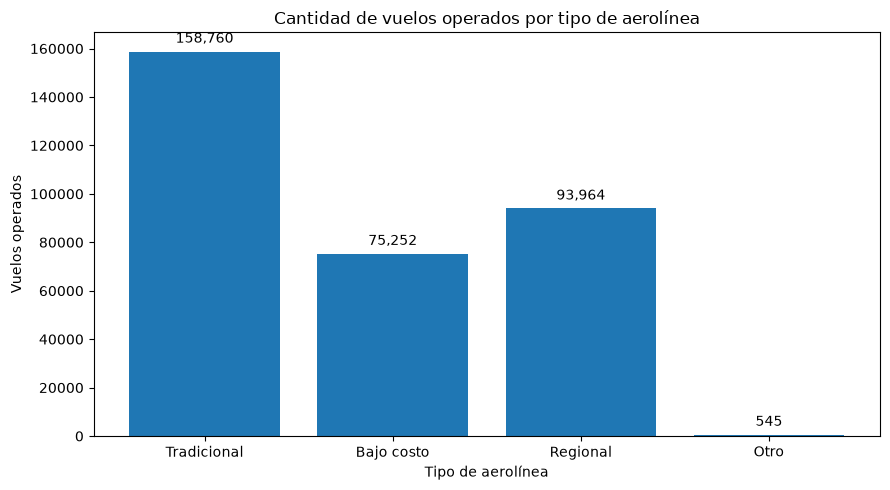


5. GRÁFICO: CANTIDAD DE VUELOS CON DEMORAS SEVERAS Y CRÍTICAS
Se muestran las cantidades absolutas de salida y llegada.
Una categoría con más operaciones puede acumular más casos,
por lo que este gráfico debe leerse junto con los porcentajes.


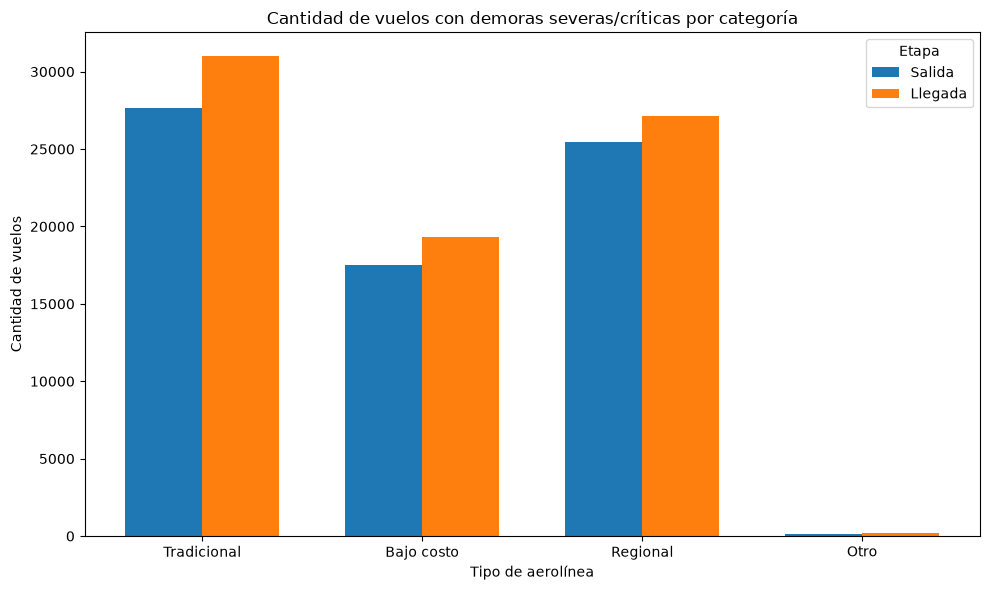


6. GRÁFICO PRINCIPAL: PORCENTAJE DE DEMORAS SEVERAS Y CRÍTICAS
Se comparan salida y llegada usando los mismos vuelos evaluables.
Este es el gráfico principal para identificar diferencias de gravedad
entre los tipos de aerolínea.


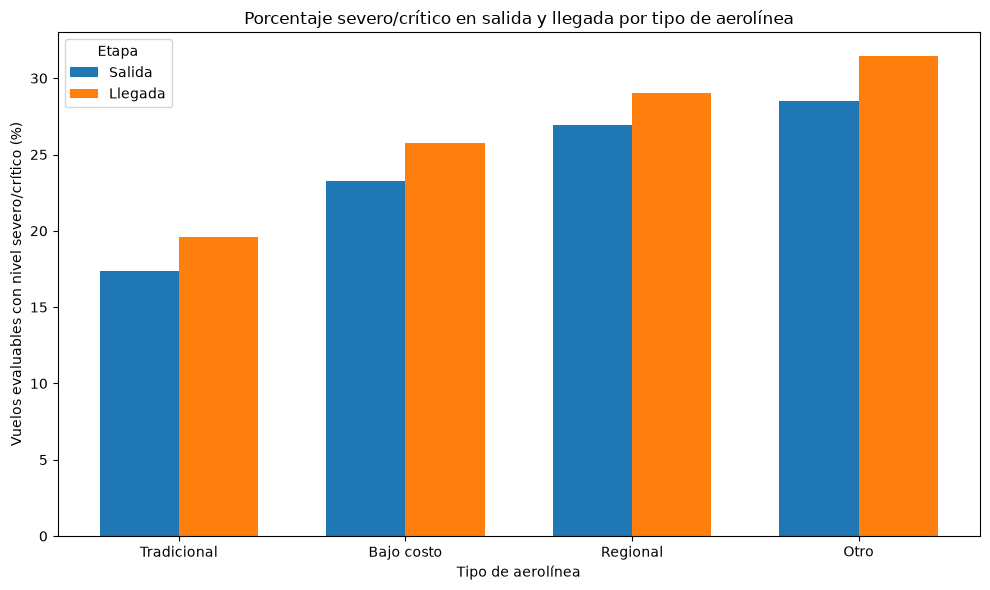


7. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS DE LLEGADA POR SEPARADO
Se diferencia la frecuencia de llegadas severas de las críticas.
Los porcentajes utilizan todas las llegadas evaluables de cada categoría.


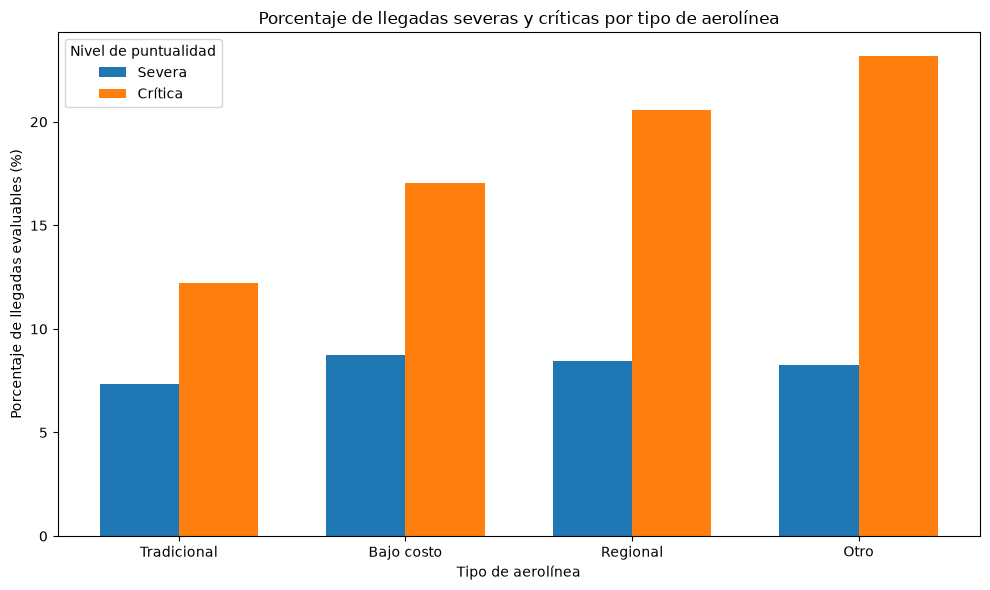

In [76]:
# ============================================================
# 2.7. PUNTUALIDAD SEGÚN EL TIPO DE AEROLÍNEA
# ============================================================

print("=" * 80)
print("2.7 | PUNTUALIDAD SEGÚN EL TIPO DE AEROLÍNEA")
print("=" * 80)


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados y los cuatro tipos de aerolínea.")
print("El indicador principal son las demoras severas y críticas.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Conservar las categorías existentes y su orden de presentación.
orden_tipos = [
    "Tradicional",
    "Bajo costo",
    "Regional",
    "Otro"
]

# Identificar vuelos evaluables por etapa.
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
).astype("int8")

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Identificar las categorías de gravedad prioritarias.
base["_salida_severa"] = (
    base["nivel_puntualidad_salida"].eq("severo")
).astype("int8")

base["_salida_critica"] = (
    base["nivel_puntualidad_salida"].eq("critico")
).astype("int8")

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"].eq("severo")
).astype("int8")

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"].eq("critico")
).astype("int8")

# Indicadores combinados: severo + crítico.
base["_salida_severa_critica"] = (
    base["_salida_severa"] + base["_salida_critica"]
)

base["_arribo_severo_critico"] = (
    base["_arribo_severo"] + base["_arribo_critico"]
)

print(f"Vuelos operados analizados: {len(base):,}")
print("Tipos de aerolínea encontrados:")
print(base["tipo_aerolinea"].value_counts().reindex(orden_tipos, fill_value=0))


# ------------------------------------------------------------
# 2. Resumen general por tipo de aerolínea
# ------------------------------------------------------------

print("\n2. RESUMEN DE OPERACIONES Y PUNTUALIDAD")
print("Los porcentajes de cada etapa utilizan sus vuelos evaluables.")
print("Los niveles 'desconocido' se excluyen del denominador.")

resumen = (
    base.groupby("tipo_aerolinea")
    .agg(
        vuelos_operados=("id", "size"),
        aerolineas_distintas=("aerolinea", "nunique"),
        matriculas_distintas=("matricula_avion", "nunique"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas=("_salida_severa", "sum"),
        salidas_criticas=("_salida_critica", "sum"),
        salidas_severas_criticas=("_salida_severa_critica", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_severo_critico", "sum")
    )
    .reindex(orden_tipos, fill_value=0)
    .rename_axis("tipo_aerolinea")
    .reset_index()
)

# Porcentajes de salida.
resumen["pct_salidas_severas"] = (
    100
    * resumen["salidas_severas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_criticas"] = (
    100
    * resumen["salidas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_severas_criticas"] = (
    100
    * resumen["salidas_severas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

# Porcentajes de llegada.
resumen["pct_llegadas_severas"] = (
    100
    * resumen["llegadas_severas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_criticas"] = (
    100
    * resumen["llegadas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_severas_criticas"] = (
    100
    * resumen["llegadas_severas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)


# ------------------------------------------------------------
# 3. Comparar salida y llegada usando los mismos vuelos
# ------------------------------------------------------------

print("\n3. COMPARACIÓN DIRECTA ENTRE SALIDA Y LLEGADA")
print("Para que la comparación sea equivalente, consideramos solo los vuelos")
print("que tienen un nivel de puntualidad conocido en ambas etapas.")

comparables = base.loc[
    base["_salida_evaluable"].eq(1)
    & base["_arribo_evaluable"].eq(1)
].copy()

resumen_comparable = (
    comparables.groupby("tipo_aerolinea")
    .agg(
        vuelos_comparables=("id", "size"),
        salidas_graves_comparables=("_salida_severa_critica", "sum"),
        llegadas_graves_comparables=("_arribo_severo_critico", "sum")
    )
    .reindex(orden_tipos, fill_value=0)
    .rename_axis("tipo_aerolinea")
    .reset_index()
)

resumen_comparable["pct_salida_grave_comparable"] = (
    100
    * resumen_comparable["salidas_graves_comparables"]
    / resumen_comparable["vuelos_comparables"].replace(0, np.nan)
)

resumen_comparable["pct_llegada_grave_comparable"] = (
    100
    * resumen_comparable["llegadas_graves_comparables"]
    / resumen_comparable["vuelos_comparables"].replace(0, np.nan)
)

resumen_comparable["diferencia_llegada_salida_pp"] = (
    resumen_comparable["pct_llegada_grave_comparable"]
    - resumen_comparable["pct_salida_grave_comparable"]
)

resumen = resumen.merge(
    resumen_comparable,
    on="tipo_aerolinea",
    how="left"
)

# Tabla final con indicadores relevantes.
columnas_tabla = [
    "tipo_aerolinea",
    "vuelos_operados",
    "aerolineas_distintas",
    "matriculas_distintas",
    "salidas_evaluables",
    "salidas_severas",
    "salidas_criticas",
    "pct_salidas_severas",
    "pct_salidas_criticas",
    "pct_salidas_severas_criticas",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas",
    "vuelos_comparables",
    "pct_salida_grave_comparable",
    "pct_llegada_grave_comparable",
    "diferencia_llegada_salida_pp"
]

tabla = resumen[columnas_tabla].copy()

columnas_porcentaje = [
    "pct_salidas_severas",
    "pct_salidas_criticas",
    "pct_salidas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas",
    "pct_salida_grave_comparable",
    "pct_llegada_grave_comparable",
    "diferencia_llegada_salida_pp"
]

tabla[columnas_porcentaje] = tabla[columnas_porcentaje].round(2)

print("\nTabla comparativa por tipo de aerolínea:")
print(tabla.to_string(index=False))


# ------------------------------------------------------------
# 4. Gráfico: volumen de operaciones
# ------------------------------------------------------------

print("\n4. GRÁFICO: VOLUMEN DE VUELOS POR TIPO DE AEROLÍNEA")
print("Permite comparar la cantidad de vuelos operados por cada categoría.")
print("Las cantidades ayudan a contextualizar los porcentajes de demora.")

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    resumen["tipo_aerolinea"],
    resumen["vuelos_operados"]
)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(
        f"{altura:,.0f}",
        (barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title("Cantidad de vuelos operados por tipo de aerolínea")
ax.set_xlabel("Tipo de aerolínea")
ax.set_ylabel("Vuelos operados")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: cantidad absoluta de vuelos severos y críticos
# ------------------------------------------------------------

print("\n5. GRÁFICO: CANTIDAD DE VUELOS CON DEMORAS SEVERAS Y CRÍTICAS")
print("Se muestran las cantidades absolutas de salida y llegada.")
print("Una categoría con más operaciones puede acumular más casos,")
print("por lo que este gráfico debe leerse junto con los porcentajes.")

posiciones = np.arange(len(resumen))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

barras_salida = ax.bar(
    posiciones - ancho / 2,
    resumen["salidas_severas_criticas"],
    ancho,
    label="Salida"
)

barras_llegada = ax.bar(
    posiciones + ancho / 2,
    resumen["llegadas_severas_criticas"],
    ancho,
    label="Llegada"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(resumen["tipo_aerolinea"])
ax.set_title("Cantidad de vuelos con demoras severas/críticas por categoría")
ax.set_xlabel("Tipo de aerolínea")
ax.set_ylabel("Cantidad de vuelos")
ax.legend(title="Etapa")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico principal: porcentaje severo/crítico por etapa
# ------------------------------------------------------------

print("\n6. GRÁFICO PRINCIPAL: PORCENTAJE DE DEMORAS SEVERAS Y CRÍTICAS")
print("Se comparan salida y llegada usando los mismos vuelos evaluables.")
print("Este es el gráfico principal para identificar diferencias de gravedad")
print("entre los tipos de aerolínea.")

posiciones = np.arange(len(resumen_comparable))

fig, ax = plt.subplots(figsize=(10, 6))

barras_salida = ax.bar(
    posiciones - ancho / 2,
    resumen_comparable["pct_salida_grave_comparable"],
    ancho,
    label="Salida"
)

barras_llegada = ax.bar(
    posiciones + ancho / 2,
    resumen_comparable["pct_llegada_grave_comparable"],
    ancho,
    label="Llegada"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(resumen_comparable["tipo_aerolinea"])
ax.set_title("Porcentaje severo/crítico en salida y llegada por tipo de aerolínea")
ax.set_xlabel("Tipo de aerolínea")
ax.set_ylabel("Vuelos evaluables con nivel severo/crítico (%)")
ax.legend(title="Etapa")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Gráfico: separar demoras severas y críticas de llegada
# ------------------------------------------------------------

print("\n7. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS DE LLEGADA POR SEPARADO")
print("Se diferencia la frecuencia de llegadas severas de las críticas.")
print("Los porcentajes utilizan todas las llegadas evaluables de cada categoría.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    posiciones - ancho / 2,
    resumen["pct_llegadas_severas"],
    ancho,
    label="Severa"
)

ax.bar(
    posiciones + ancho / 2,
    resumen["pct_llegadas_criticas"],
    ancho,
    label="Crítica"
)

ax.set_xticks(posiciones)
ax.set_xticklabels(resumen["tipo_aerolinea"])
ax.set_title("Porcentaje de llegadas severas y críticas por tipo de aerolínea")
ax.set_xlabel("Tipo de aerolínea")
ax.set_ylabel("Porcentaje de llegadas evaluables (%)")
ax.legend(title="Nivel de puntualidad")

plt.tight_layout()
plt.show()

###
---
---
---



### 3. Análisis por aeropuerto de origen (`origen`)

**Objetivo general:** analizar si el aeropuerto desde el que parte un vuelo está relacionado con la frecuencia de las demoras severas y críticas, estudiar la relación entre la puntualidad de salida y llegada y explorar si la congestión de las operaciones programadas aporta información relevante para el sistema predictivo.

El análisis se centrará en los tres aeropuertos de origen presentes en el dataset: `EWR`, `JFK` y `LGA`.

#### 3.1. Volumen de operaciones y demoras por aeropuerto

**Objetivo:** comparar la cantidad de vuelos operados desde cada aeropuerto y determinar si existen diferencias en la frecuencia y gravedad de las demoras.

Preguntas que vamos a investigar:

- ¿Desde qué aeropuerto se registran más vuelos con demoras severas y críticas?
- ¿Qué aeropuerto presenta el mayor porcentaje de salidas con demoras severas y críticas?
- ¿Existen diferencias entre los aeropuertos en el porcentaje de llegadas con demoras severas y críticas?
- ¿El aeropuerto con mayor cantidad de vuelos también presenta una mayor proporción de demoras graves?

**Enfoque del análisis:** diferenciaremos entre la cantidad absoluta de vuelos afectados y el porcentaje que representan sobre los vuelos evaluables de cada aeropuerto. Analizaremos por separado las demoras severas y críticas y también su combinación, para evitar confundir un mayor volumen de operaciones con una mayor frecuencia relativa de demoras graves.

3.1 | VOLUMEN DE OPERACIONES Y DEMORAS POR AEROPUERTO

1. PREPARACIÓN DE LOS DATOS
Se analizan los vuelos operados en los aeropuertos de origen.
La prioridad son las demoras severas y críticas de salida y llegada.
Vuelos operados analizados: 328,521
Aeropuertos de origen identificados: 3

2. TABLA RESUMEN DE OPERACIONES Y DEMORAS
Se muestran cantidades y porcentajes por aeropuerto.
Cada porcentaje se calcula sobre los vuelos evaluables de su etapa.

Tabla comparativa por aeropuerto:
origen  vuelos_operados  salidas_evaluables  salidas_severas  salidas_criticas  salidas_severas_criticas  pct_salidas_severas  pct_salidas_criticas  pct_salidas_severas_criticas  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
   EWR           117596              117596             9028             19914                     28942                 7.68                 16.93                         2

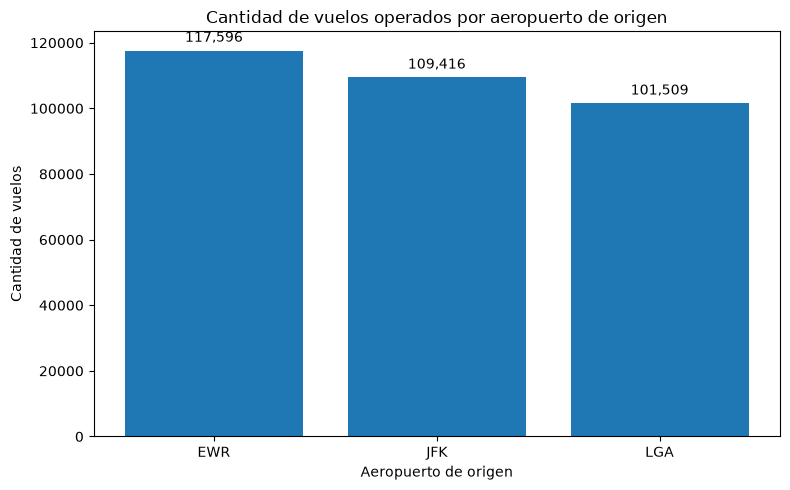


4.1. GRÁFICO PREVIO: DISTRIBUCIÓN GENERAL DE LA PUNTUALIDAD
Se muestra la cantidad de vuelos en cada estado de puntualidad
por aeropuerto, diferenciando salida y llegada.
Se incluyen todos los estados existentes, incluido desconocido.


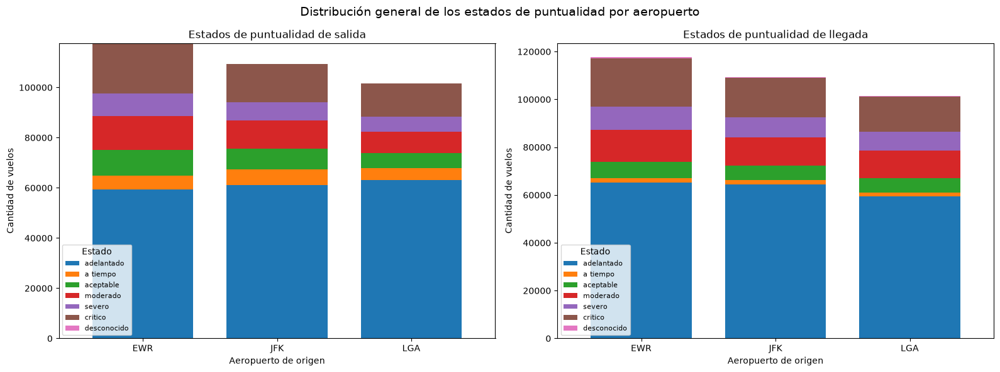


4.2. GRÁFICO: CANTIDAD DE DEMORAS SEVERAS Y CRÍTICAS
Se comparan por separado las cantidades de casos severos y críticos
en salida y llegada para cada aeropuerto.


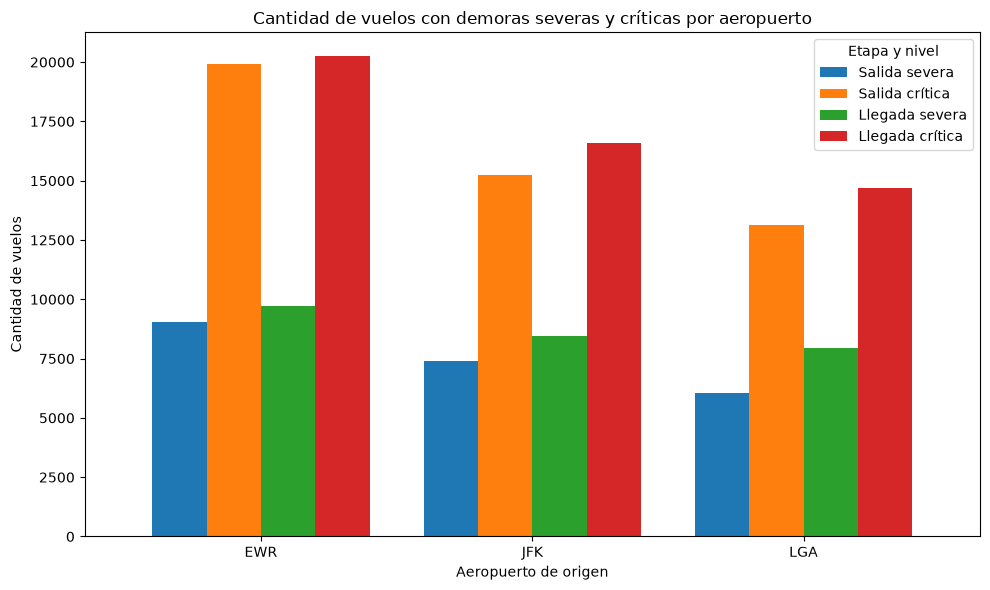


5.1. GRÁFICO PREVIO: PORCENTAJE DE CADA ESTADO DE PUNTUALIDAD
Se compara qué proporción de vuelos corresponde a cada estado
de puntualidad en cada aeropuerto, diferenciando salida y llegada.
La distribución incluye todos los estados, incluido desconocido.


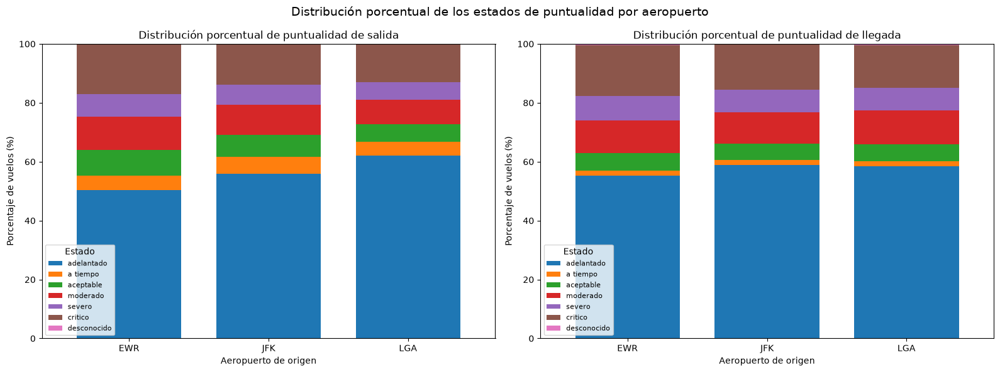


5.2. GRÁFICO: PORCENTAJE DE DEMORAS SEVERAS Y CRÍTICAS
Compara los porcentajes de salida y llegada, distinguiendo
las categorías severo y crítico.
Este gráfico permite comparar la gravedad relativa entre aeropuertos.


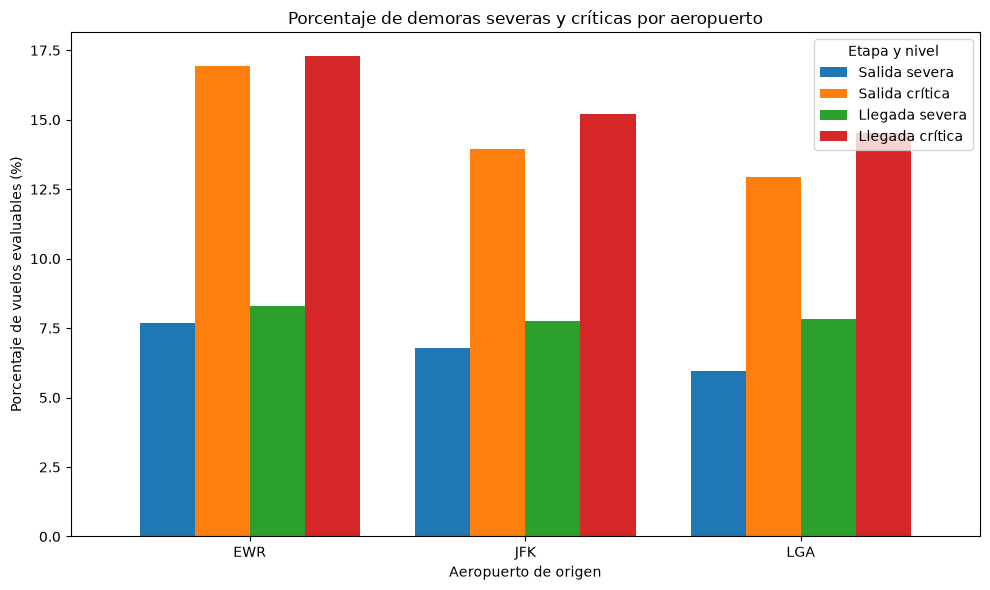


6. COMPARACIÓN FINAL DE AEROPUERTOS
Se ordenan los aeropuertos según el porcentaje combinado
de salidas y llegadas severas/críticas para facilitar la lectura.

Orden por porcentaje de llegadas severas/críticas:
origen  vuelos_operados  pct_salidas_severas_criticas  pct_llegadas_severas_criticas  salidas_severas_criticas  llegadas_severas_criticas
   EWR           117596                         24.61                          25.59                     28942                      29970
   JFK           109416                         20.70                          22.97                     22650                      25050
   LGA           101509                         18.90                          22.36                     19182                      22610


In [77]:

# ============================================================
# 3.1. VOLUMEN DE OPERACIONES Y DEMORAS POR AEROPUERTO
# ============================================================

print("=" * 80)
print("3.1 | VOLUMEN DE OPERACIONES Y DEMORAS POR AEROPUERTO")
print("=" * 80)


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se analizan los vuelos operados en los aeropuertos de origen.")
print("La prioridad son las demoras severas y críticas de salida y llegada.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

orden_aeropuertos = ["EWR", "JFK", "LGA"]

# Identificar vuelos evaluables para cada etapa.
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
).astype("int8")

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Separar los niveles severo y crítico.
base["_salida_severa"] = (
    base["nivel_puntualidad_salida"].eq("severo")
).astype("int8")

base["_salida_critica"] = (
    base["nivel_puntualidad_salida"].eq("critico")
).astype("int8")

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"].eq("severo")
).astype("int8")

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"].eq("critico")
).astype("int8")

# Combinar severas + críticas.
base["_salida_severa_critica"] = (
    base["_salida_severa"] + base["_salida_critica"]
)

base["_arribo_severo_critico"] = (
    base["_arribo_severo"] + base["_arribo_critico"]
)

print(f"Vuelos operados analizados: {len(base):,}")
print(f"Aeropuertos de origen identificados: {base['origen'].nunique()}")


# ------------------------------------------------------------
# 2. Resumen por aeropuerto
# ------------------------------------------------------------

print("\n2. TABLA RESUMEN DE OPERACIONES Y DEMORAS")
print("Se muestran cantidades y porcentajes por aeropuerto.")
print("Cada porcentaje se calcula sobre los vuelos evaluables de su etapa.")

resumen = (
    base.groupby("origen")
    .agg(
        vuelos_operados=("id", "size"),

        salidas_evaluables=("_salida_evaluable", "sum"),
        salidas_severas=("_salida_severa", "sum"),
        salidas_criticas=("_salida_critica", "sum"),
        salidas_severas_criticas=("_salida_severa_critica", "sum"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_severo_critico", "sum")
    )
    .reindex(orden_aeropuertos)
    .rename_axis("origen")
    .reset_index()
)

# Porcentajes de salida.
resumen["pct_salidas_severas"] = (
    100
    * resumen["salidas_severas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_criticas"] = (
    100
    * resumen["salidas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

resumen["pct_salidas_severas_criticas"] = (
    100
    * resumen["salidas_severas_criticas"]
    / resumen["salidas_evaluables"].replace(0, np.nan)
)

# Porcentajes de llegada.
resumen["pct_llegadas_severas"] = (
    100
    * resumen["llegadas_severas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_criticas"] = (
    100
    * resumen["llegadas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_severas_criticas"] = (
    100
    * resumen["llegadas_severas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

columnas_resumen = [
    "origen",
    "vuelos_operados",
    "salidas_evaluables",
    "salidas_severas",
    "salidas_criticas",
    "salidas_severas_criticas",
    "pct_salidas_severas",
    "pct_salidas_criticas",
    "pct_salidas_severas_criticas",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_resumen = resumen[columnas_resumen].copy()

columnas_porcentaje = [
    "pct_salidas_severas",
    "pct_salidas_criticas",
    "pct_salidas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_resumen[columnas_porcentaje] = (
    tabla_resumen[columnas_porcentaje].round(2)
)

print("\nTabla comparativa por aeropuerto:")
print(tabla_resumen.to_string(index=False))


# ------------------------------------------------------------
# 3. Gráfico: volumen de operaciones
# ------------------------------------------------------------

print("\n3. GRÁFICO: CANTIDAD DE VUELOS OPERADOS POR AEROPUERTO")
print("Permite identificar desde qué aeropuerto se opera el mayor volumen.")
print("Este resultado se utilizará como contexto para interpretar las demoras.")

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    resumen["origen"],
    resumen["vuelos_operados"]
)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(
        f"{altura:,.0f}",
        (barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title("Cantidad de vuelos operados por aeropuerto de origen")
ax.set_xlabel("Aeropuerto de origen")
ax.set_ylabel("Cantidad de vuelos")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Gráfico: cantidad absoluta de demoras severas y críticas
# ------------------------------------------------------------


# ------------------------------------------------------------
# Gráfico previo al 4: distribución general de estados
# de puntualidad en cantidades
# ------------------------------------------------------------



print("\n4.1. GRÁFICO PREVIO: DISTRIBUCIÓN GENERAL DE LA PUNTUALIDAD")
print("Se muestra la cantidad de vuelos en cada estado de puntualidad")
print("por aeropuerto, diferenciando salida y llegada.")
print("Se incluyen todos los estados existentes, incluido desconocido.")

orden_estados = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Contar vuelos por aeropuerto y estado de puntualidad.
estados_salida_cantidad = pd.crosstab(
    base["origen"],
    base["nivel_puntualidad_salida"]
).reindex(
    index=orden_aeropuertos,
    columns=orden_estados,
    fill_value=0
)

estados_llegada_cantidad = pd.crosstab(
    base["origen"],
    base["nivel_puntualidad_arribo"]
).reindex(
    index=orden_aeropuertos,
    columns=orden_estados,
    fill_value=0
)

# Dos paneles para comparar las distribuciones generales.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

estados_salida_cantidad.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    width=0.75
)

axes[0].set_title("Estados de puntualidad de salida")
axes[0].set_xlabel("Aeropuerto de origen")
axes[0].set_ylabel("Cantidad de vuelos")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Estado", fontsize=8)

estados_llegada_cantidad.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    width=0.75
)

axes[1].set_title("Estados de puntualidad de llegada")
axes[1].set_xlabel("Aeropuerto de origen")
axes[1].set_ylabel("Cantidad de vuelos")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Estado", fontsize=8)

fig.suptitle(
    "Distribución general de los estados de puntualidad por aeropuerto",
    fontsize=14
)

plt.tight_layout()
plt.show()






print("\n4.2. GRÁFICO: CANTIDAD DE DEMORAS SEVERAS Y CRÍTICAS")
print("Se comparan por separado las cantidades de casos severos y críticos")
print("en salida y llegada para cada aeropuerto.")

columnas_cantidades = [
    "salidas_severas",
    "salidas_criticas",
    "llegadas_severas",
    "llegadas_criticas"
]

grafico_cantidades = (
    resumen.set_index("origen")[columnas_cantidades]
    .rename(
        columns={
            "salidas_severas": "Salida severa",
            "salidas_criticas": "Salida crítica",
            "llegadas_severas": "Llegada severa",
            "llegadas_criticas": "Llegada crítica"
        }
    )
)

grafico_cantidades.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Cantidad de vuelos con demoras severas y críticas por aeropuerto")
plt.xlabel("Aeropuerto de origen")
plt.ylabel("Cantidad de vuelos")
plt.xticks(rotation=0)
plt.legend(title="Etapa y nivel")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: porcentaje de demoras severas y críticas
# ------------------------------------------------------------



# ------------------------------------------------------------
# Gráfico previo al 5: distribución general de estados
# de puntualidad en porcentajes
# ------------------------------------------------------------

print("\n5.1. GRÁFICO PREVIO: PORCENTAJE DE CADA ESTADO DE PUNTUALIDAD")
print("Se compara qué proporción de vuelos corresponde a cada estado")
print("de puntualidad en cada aeropuerto, diferenciando salida y llegada.")
print("La distribución incluye todos los estados, incluido desconocido.")

# Convertir las cantidades anteriores en porcentajes por aeropuerto.
# Cada aeropuerto suma aproximadamente 100 % en cada panel.
estados_salida_pct = (
    estados_salida_cantidad
    .div(estados_salida_cantidad.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

estados_llegada_pct = (
    estados_llegada_cantidad
    .div(estados_llegada_cantidad.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

estados_salida_pct.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    width=0.75
)

axes[0].set_title("Distribución porcentual de puntualidad de salida")
axes[0].set_xlabel("Aeropuerto de origen")
axes[0].set_ylabel("Porcentaje de vuelos (%)")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Estado", fontsize=8)

estados_llegada_pct.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    width=0.75
)

axes[1].set_title("Distribución porcentual de puntualidad de llegada")
axes[1].set_xlabel("Aeropuerto de origen")
axes[1].set_ylabel("Porcentaje de vuelos (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Estado", fontsize=8)

fig.suptitle(
    "Distribución porcentual de los estados de puntualidad por aeropuerto",
    fontsize=14
)

plt.tight_layout()
plt.show()






print("\n5.2. GRÁFICO: PORCENTAJE DE DEMORAS SEVERAS Y CRÍTICAS")
print("Compara los porcentajes de salida y llegada, distinguiendo")
print("las categorías severo y crítico.")
print("Este gráfico permite comparar la gravedad relativa entre aeropuertos.")

columnas_porcentajes_grafico = [
    "pct_salidas_severas",
    "pct_salidas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas"
]

grafico_porcentajes = (
    resumen.set_index("origen")[columnas_porcentajes_grafico]
    .rename(
        columns={
            "pct_salidas_severas": "Salida severa",
            "pct_salidas_criticas": "Salida crítica",
            "pct_llegadas_severas": "Llegada severa",
            "pct_llegadas_criticas": "Llegada crítica"
        }
    )
)

grafico_porcentajes.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Porcentaje de demoras severas y críticas por aeropuerto")
plt.xlabel("Aeropuerto de origen")
plt.ylabel("Porcentaje de vuelos evaluables (%)")
plt.xticks(rotation=0)
plt.legend(title="Etapa y nivel")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Comparación ordenada de los aeropuertos
# ------------------------------------------------------------

print("\n6. COMPARACIÓN FINAL DE AEROPUERTOS")
print("Se ordenan los aeropuertos según el porcentaje combinado")
print("de salidas y llegadas severas/críticas para facilitar la lectura.")

tabla_comparacion = resumen[
    [
        "origen",
        "vuelos_operados",
        "pct_salidas_severas_criticas",
        "pct_llegadas_severas_criticas",
        "salidas_severas_criticas",
        "llegadas_severas_criticas"
    ]
].copy()

tabla_comparacion[
    [
        "pct_salidas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
] = tabla_comparacion[
    [
        "pct_salidas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
].round(2)

print("\nOrden por porcentaje de llegadas severas/críticas:")
print(
    tabla_comparacion
    .sort_values("pct_llegadas_severas_criticas", ascending=False)
    .to_string(index=False)
)

#### 3.2. Relación entre puntualidad de salida y llegada según el aeropuerto

**Objetivo:** estudiar si la relación entre la puntualidad de salida y la de llegada presenta diferencias según el aeropuerto de origen.

Preguntas que vamos a investigar:

- ¿Qué porcentaje de los vuelos que salen adelantados, a tiempo o con distintos niveles de demora termina llegando con una demora severa o crítica?
- ¿Existen aeropuertos donde una salida con demora esté más asociada con una llegada severamente demorada o crítica?
- ¿Hay diferencias entre los aeropuertos en la proporción de vuelos que presentan demoras graves tanto al salir como al llegar?
- ¿La puntualidad de salida aporta información útil para anticipar la gravedad de la demora de llegada?

**Enfoque del análisis:** relacionaremos los niveles de puntualidad de salida con los de llegada, diferenciando los resultados por aeropuerto. Para comparar ambas etapas de forma consistente, utilizaremos los vuelos que tengan niveles de puntualidad conocidos en salida y llegada. Priorizaremos las llegadas severas y críticas y tendremos en cuenta que una asociación entre ambas etapas no demuestra por sí sola una relación causal.

3.2 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados con niveles conocidos de salida y llegada.
La prioridad es identificar llegadas severas y críticas.
Vuelos operados: 328,521
Vuelos evaluables en salida y llegada: 327,346
Aeropuertos analizados: EWR, JFK, LGA

2. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD DE SALIDA Y LLEGADA
Cada fila representa un nivel de salida y cada columna un nivel de llegada.
Los valores son porcentajes dentro de cada nivel de salida.
Entre paréntesis se muestra la cantidad de vuelos de cada combinación.

Aeropuerto: EWR
nivel_puntualidad_arribo  adelantado  a tiempo  aceptable  moderado  severo  critico
nivel_puntualidad_salida                                                            
adelantado                     80.12      1.69       5.56      8.20    3.17     1.27
a tiempo                       67.98      2.10       8.24     12.91    6.18     2.59
aceptable                      63.70      2.54       8

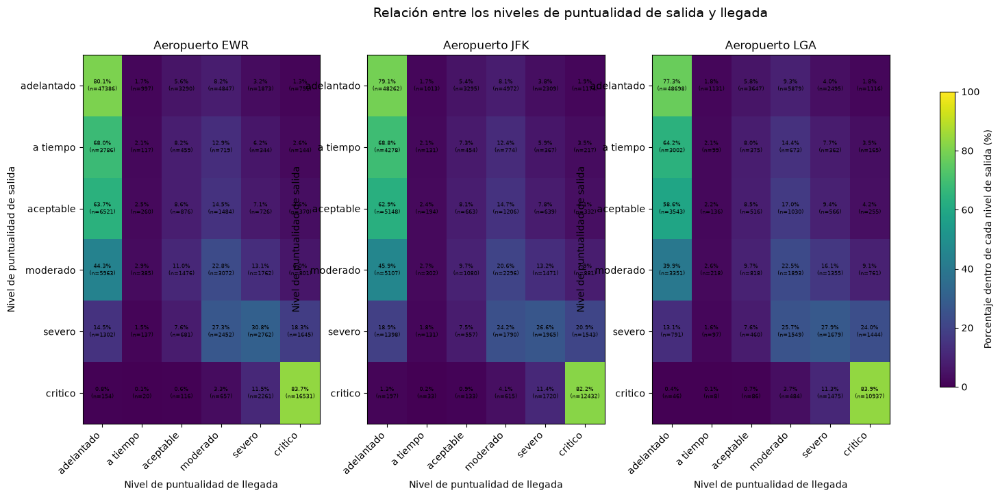


4. TABLA: LLEGADAS SEVERAS/CRÍTICAS SEGÚN NIVEL DE SALIDA
Se calcula qué porcentaje de los vuelos de cada nivel de salida
termina con una llegada severa o crítica, separado por aeropuerto.
origen nivel_puntualidad_salida  vuelos  llegadas_severas_criticas  pct_llegada_severa_critica
   EWR               adelantado   59144                       2624                        4.44
   EWR                 a tiempo    5569                        488                        8.76
   EWR                aceptable   10237                       1096                       10.71
   EWR                 moderado   13459                       2563                       19.04
   EWR                   severo    8979                       4407                       49.08
   EWR                  critico   19739                      18792                       95.20
   JFK               adelantado   61025                       3483                        5.71
   JFK                 a tiempo    6221           

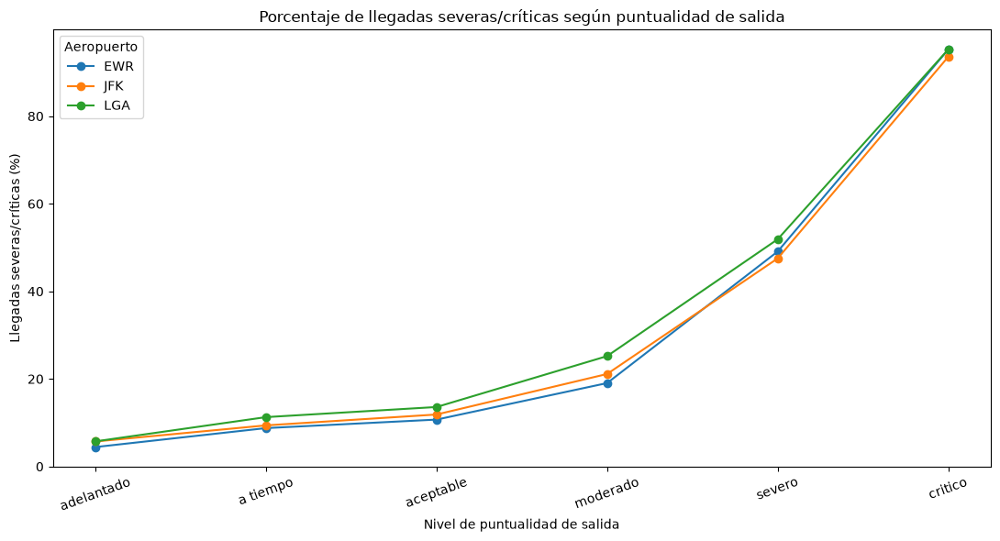


6. TABLA: VUELOS CON DEMORAS SEVERAS/CRÍTICAS AL SALIR Y LLEGAR
Se identifican los vuelos que tienen un nivel severo o crítico
tanto en salida como en llegada.
origen  vuelos_comparables  salidas_severas_criticas  llegadas_severas_criticas  vuelos_graves_ambas_etapas  pct_vuelos_graves_ambas_etapas  pct_graves_salida_comparable  pct_graves_llegada_comparable
   EWR              117127                     28718                      29970                       23199                           19.81                         24.52                          25.59
   JFK              109079                     22514                      25050                       17660                           16.19                         20.64                          22.97
   LGA              101140                     19056                      22610                       15535                           15.36                         18.84                          22.36

7. GRÁFICO: PORCENTAJE DE VUELOS G

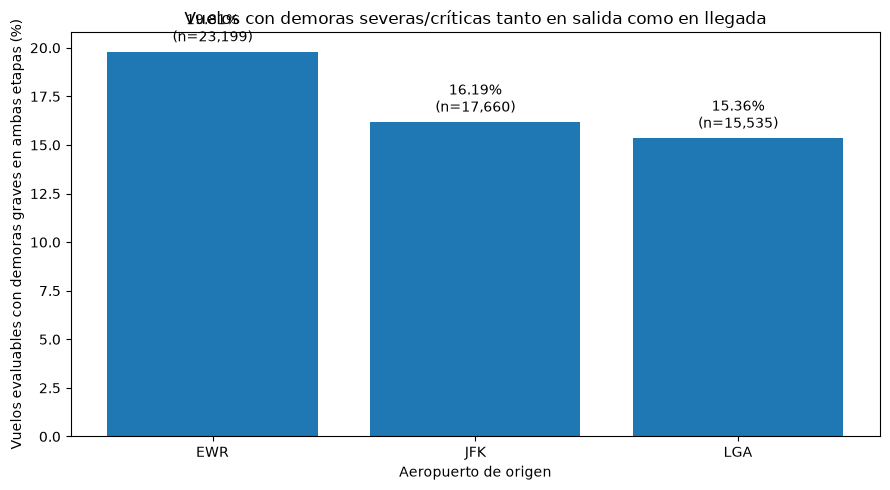

In [78]:
# ============================================================
# 3.2. RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
#      SEGÚN EL AEROPUERTO
# ============================================================

print("=" * 80)
print("3.2 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA")
print("=" * 80)


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados con niveles conocidos de salida y llegada.")
print("La prioridad es identificar llegadas severas y críticas.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

orden_aeropuertos = ["EWR", "JFK", "LGA"]

orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
)

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
)

# Para estudiar la relación entre ambas etapas, usamos los mismos vuelos.
comparables = base.loc[
    base["_salida_evaluable"] & base["_arribo_evaluable"]
].copy()

# Identificar las demoras graves en cada etapa.
comparables["_salida_grave"] = (
    comparables["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
)

comparables["_arribo_grave"] = (
    comparables["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
)

# Vuelo grave en ambas etapas: severo/crítico al salir Y al llegar.
comparables["_grave_en_ambas_etapas"] = (
    comparables["_salida_grave"]
    & comparables["_arribo_grave"]
)

print(f"Vuelos operados: {len(base):,}")
print(f"Vuelos evaluables en salida y llegada: {len(comparables):,}")
print(
    "Aeropuertos analizados:",
    ", ".join(orden_aeropuertos)
)


# ------------------------------------------------------------
# 2. Distribución general de los estados de llegada
#    según el estado de salida
# ------------------------------------------------------------

print("\n2. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD DE SALIDA Y LLEGADA")
print("Cada fila representa un nivel de salida y cada columna un nivel de llegada.")
print("Los valores son porcentajes dentro de cada nivel de salida.")
print("Entre paréntesis se muestra la cantidad de vuelos de cada combinación.")

matrices_cantidad = {}
matrices_porcentaje = {}

for aeropuerto in orden_aeropuertos:

    datos_aeropuerto = comparables.loc[
        comparables["origen"].eq(aeropuerto)
    ]

    matriz_cantidad = pd.crosstab(
        datos_aeropuerto["nivel_puntualidad_salida"],
        datos_aeropuerto["nivel_puntualidad_arribo"]
    ).reindex(
        index=orden_niveles,
        columns=orden_niveles,
        fill_value=0
    )

    # Porcentaje de cada nivel de llegada dentro del nivel de salida.
    matriz_porcentaje = (
        matriz_cantidad
        .div(matriz_cantidad.sum(axis=1).replace(0, np.nan), axis=0)
        * 100
    )

    matrices_cantidad[aeropuerto] = matriz_cantidad
    matrices_porcentaje[aeropuerto] = matriz_porcentaje

    print(f"\nAeropuerto: {aeropuerto}")
    print(matriz_porcentaje.round(2).to_string())


# ------------------------------------------------------------
# 3. Gráfico: mapas de calor de la relación entre ambas etapas
# ------------------------------------------------------------

print("\n3. GRÁFICO: DISTRIBUCIÓN DE ESTADOS DE PUNTUALIDAD")
print("Se compara la relación entre salida y llegada en cada aeropuerto.")
print("El gráfico incluye todas las categorías conocidas de puntualidad.")
print("Los porcentajes permiten comparar las distribuciones dentro de cada fila.")

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

imagen = None

for ax, aeropuerto in zip(axes, orden_aeropuertos):

    matriz_pct = matrices_porcentaje[aeropuerto]
    matriz_n = matrices_cantidad[aeropuerto]

    datos = np.ma.masked_invalid(
        matriz_pct.to_numpy(dtype=float)
    )

    imagen = ax.imshow(
        datos,
        aspect="auto",
        interpolation="nearest",
        vmin=0,
        vmax=100
    )

    ax.set_title(f"Aeropuerto {aeropuerto}")
    ax.set_xlabel("Nivel de puntualidad de llegada")
    ax.set_ylabel("Nivel de puntualidad de salida")

    ax.set_xticks(range(len(orden_niveles)))
    ax.set_xticklabels(orden_niveles, rotation=45, ha="right")

    ax.set_yticks(range(len(orden_niveles)))
    ax.set_yticklabels(orden_niveles)

    for i, nivel_salida in enumerate(orden_niveles):
        for j, nivel_arribo in enumerate(orden_niveles):

            cantidad = matriz_n.loc[nivel_salida, nivel_arribo]
            porcentaje = matriz_pct.loc[nivel_salida, nivel_arribo]

            if cantidad > 0 and pd.notna(porcentaje):
                ax.text(
                    j,
                    i,
                    f"{porcentaje:.1f}%\n(n={cantidad})",
                    ha="center",
                    va="center",
                    fontsize=6
                )

barra_color = fig.colorbar(
    imagen,
    ax=axes.tolist(),
    shrink=0.8
)
barra_color.set_label("Porcentaje dentro de cada nivel de salida (%)")

fig.suptitle(
    "Relación entre los niveles de puntualidad de salida y llegada",
    fontsize=14
)

plt.show()


# ------------------------------------------------------------
# 4. Porcentaje de llegadas severas/críticas según la salida
# ------------------------------------------------------------

print("\n4. TABLA: LLEGADAS SEVERAS/CRÍTICAS SEGÚN NIVEL DE SALIDA")
print("Se calcula qué porcentaje de los vuelos de cada nivel de salida")
print("termina con una llegada severa o crítica, separado por aeropuerto.")

detalle = (
    comparables.groupby(
        ["origen", "nivel_puntualidad_salida"],
        observed=True,
        as_index=False
    )
    .agg(
        vuelos=("id", "size"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

detalle["pct_llegada_severa_critica"] = (
    100
    * detalle["llegadas_severas_criticas"]
    / detalle["vuelos"].replace(0, np.nan)
)

# Mantener un orden lógico de los niveles.
detalle["nivel_puntualidad_salida"] = pd.Categorical(
    detalle["nivel_puntualidad_salida"],
    categories=orden_niveles,
    ordered=True
)

detalle = detalle.sort_values(
    ["origen", "nivel_puntualidad_salida"]
)

print(
    detalle[
        [
            "origen",
            "nivel_puntualidad_salida",
            "vuelos",
            "llegadas_severas_criticas",
            "pct_llegada_severa_critica"
        ]
    ].round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 5. Gráfico: porcentaje de llegadas graves según el nivel de salida
# ------------------------------------------------------------

print("\n5. GRÁFICO PRINCIPAL: LLEGADAS SEVERAS/CRÍTICAS SEGÚN SALIDA")
print("Cada línea representa un aeropuerto.")
print("El eje vertical muestra el porcentaje de llegadas evaluables")
print("con nivel severo o crítico dentro de cada categoría de salida.")

fig, ax = plt.subplots(figsize=(11, 6))

for aeropuerto in orden_aeropuertos:

    temporal = (
        detalle.loc[detalle["origen"].eq(aeropuerto)]
        .set_index("nivel_puntualidad_salida")
        .reindex(orden_niveles)
    )

    ax.plot(
        orden_niveles,
        temporal["pct_llegada_severa_critica"],
        marker="o",
        label=aeropuerto
    )

ax.set_title(
    "Porcentaje de llegadas severas/críticas según puntualidad de salida"
)
ax.set_xlabel("Nivel de puntualidad de salida")
ax.set_ylabel("Llegadas severas/críticas (%)")
ax.legend(title="Aeropuerto")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Resumen de vuelos con demoras graves en ambas etapas
# ------------------------------------------------------------

print("\n6. TABLA: VUELOS CON DEMORAS SEVERAS/CRÍTICAS AL SALIR Y LLEGAR")
print("Se identifican los vuelos que tienen un nivel severo o crítico")
print("tanto en salida como en llegada.")

resumen_ambas = (
    comparables.groupby("origen")
    .agg(
        vuelos_comparables=("id", "size"),
        salidas_severas_criticas=("_salida_grave", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum"),
        vuelos_graves_ambas_etapas=("_grave_en_ambas_etapas", "sum")
    )
    .reindex(orden_aeropuertos)
    .rename_axis("origen")
    .reset_index()
)

resumen_ambas["pct_vuelos_graves_ambas_etapas"] = (
    100
    * resumen_ambas["vuelos_graves_ambas_etapas"]
    / resumen_ambas["vuelos_comparables"].replace(0, np.nan)
)

resumen_ambas["pct_graves_salida_comparable"] = (
    100
    * resumen_ambas["salidas_severas_criticas"]
    / resumen_ambas["vuelos_comparables"].replace(0, np.nan)
)

resumen_ambas["pct_graves_llegada_comparable"] = (
    100
    * resumen_ambas["llegadas_severas_criticas"]
    / resumen_ambas["vuelos_comparables"].replace(0, np.nan)
)

print(
    resumen_ambas.round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 7. Gráfico: proporción de vuelos graves en ambas etapas
# ------------------------------------------------------------

print("\n7. GRÁFICO: PORCENTAJE DE VUELOS GRAVES EN AMBAS ETAPAS")
print("Cada barra representa la proporción de vuelos evaluables")
print("que salieron y llegaron con nivel severo o crítico.")
print("La etiqueta muestra la cantidad de vuelos que cumple el criterio.")

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    resumen_ambas["origen"],
    resumen_ambas["pct_vuelos_graves_ambas_etapas"]
)

for barra, (_, fila) in zip(barras, resumen_ambas.iterrows()):

    porcentaje = fila["pct_vuelos_graves_ambas_etapas"]
    cantidad = fila["vuelos_graves_ambas_etapas"]

    ax.annotate(
        f"{porcentaje:.2f}%\n(n={cantidad:,})",
        (
            barra.get_x() + barra.get_width() / 2,
            barra.get_height()
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Vuelos con demoras severas/críticas tanto en salida como en llegada"
)
ax.set_xlabel("Aeropuerto de origen")
ax.set_ylabel("Vuelos evaluables con demoras graves en ambas etapas (%)")

plt.tight_layout()
plt.show()

#### 3.3. Congestión de operaciones programadas por aeropuerto

**Objetivo:** explorar si la cantidad de vuelos programados en un mismo aeropuerto y franja horaria está relacionada con la aparición de demoras severas y críticas.

Preguntas que vamos a investigar:

- ¿Qué aeropuertos concentran una mayor cantidad de vuelos programados en una misma franja horaria?
- ¿Los períodos con mayor concentración de vuelos programados presentan mayores porcentajes de salidas severas y críticas?
- ¿La congestión horaria también está relacionada con las demoras severas y críticas de llegada?
- ¿La relación entre la congestión y las demoras es similar en EWR, JFK y LGA?
- ¿La cantidad de vuelos programados en el aeropuerto y la franja horaria podría aportar información útil para el sistema predictivo?

**Enfoque del análisis:** utilizaremos la cantidad de vuelos programados por aeropuerto y franja horaria como una aproximación a la congestión operativa. También podremos aprovechar las variables de densidad de salidas programadas ya existentes en `df`, correspondientes a ventanas de 15, 30 y 60 minutos. Compararemos los porcentajes de demoras severas y críticas entre distintos niveles de concentración de vuelos, sin asumir que la congestión es la única causa de las demoras.



3.3 | CONGESTIÓN DE OPERACIONES PROGRAMADAS

1. CANTIDAD DE VUELOS PROGRAMADOS POR AEROPUERTO Y HORA
Se cuentan las operaciones previstas en cada bloque horario.
Se incluyen los vuelos programados aunque hayan sido cancelados.
Solo se consideran bloques horarios con al menos un vuelo programado.

Resumen del volumen horario programado:
origen  bloques_horarios_con_vuelos  vuelos_programados_totales  mediana_vuelos_hora  promedio_vuelos_hora  percentil_90_vuelos_hora  maximo_vuelos_hora
   EWR                         6266                      120835                 20.0                 19.28                      27.0                  38
   JFK                         6935                      111279                 17.0                 16.05                      26.0                  35
   LGA                         6285                      104662                 18.0                 16.65                      23.0                  31

2. GRÁFICO: DISTRIBUCIÓN DE VUELOS PROGRAMADOS PO

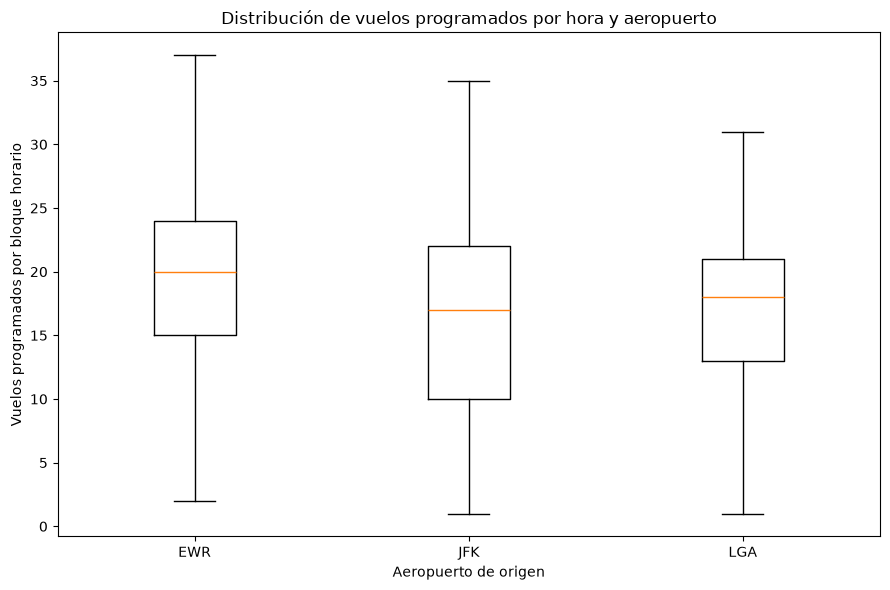


3. DENSIDAD DE SALIDAS PROGRAMADAS POR AEROPUERTO
Utilizamos las columnas de densidad ya existentes en df.
Comparamos mediana, promedio y máximo de las ventanas de 15, 30 y 60 minutos.
Los valores representan la densidad calculada previamente en el dataset.

Resumen de densidades programadas:
origen    ventana  vuelos_con_dato  densidad_mediana  densidad_promedio  densidad_maxima
   EWR 15 minutos           120835              11.0              11.15               28
   JFK 15 minutos           111279              11.0              11.41               28
   LGA 15 minutos           104662              11.0              10.65               24
   EWR 30 minutos           120835              22.0              21.77               43
   JFK 30 minutos           111279              21.0              20.76               41
   LGA 30 minutos           104662              20.0              19.54               38
   EWR 60 minutos           120835              43.0              41.51           

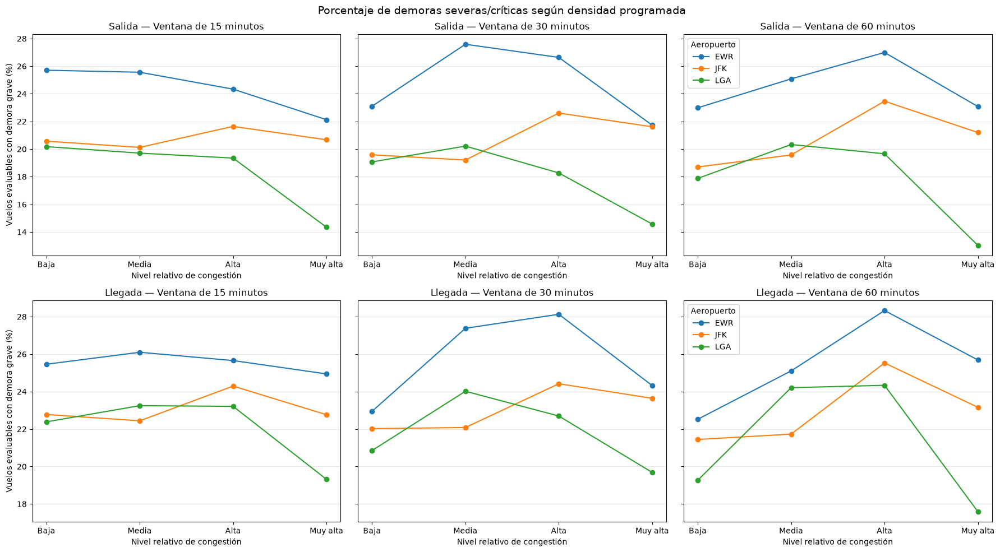


8. COMPARACIÓN FINAL DE LOS NIVELES DE CONGESTIÓN
Se presenta una tabla compacta para comparar las ventanas.
Buscamos identificar si el porcentaje de demoras graves aumenta
sistemáticamente en niveles más altos de densidad.
origen    ventana nivel_congestion  vuelos_operados  pct_salida_severa_critica  pct_llegada_severa_critica
   EWR 15 minutos             Baja            31628                      25.71                       25.46
   EWR 15 minutos            Media            32796                      25.56                       26.10
   EWR 15 minutos             Alta            29898                      24.34                       25.66
   EWR 15 minutos         Muy alta            23274                      22.13                       24.95
   JFK 15 minutos             Baja            39228                      20.57                       22.78
   JFK 15 minutos            Media            19747                      20.12                       22.44
   JFK 15 minutos         

In [79]:
# ============================================================
# 3.3. CONGESTIÓN DE OPERACIONES PROGRAMADAS POR AEROPUERTO
# ============================================================

print("=" * 80)
print("3.3 | CONGESTIÓN DE OPERACIONES PROGRAMADAS")
print("=" * 80)

orden_aeropuertos = ["EWR", "JFK", "LGA"]

columnas_densidad = {
    "15 minutos": "densidad_salida_programada_15m",
    "30 minutos": "densidad_salida_programada_30m",
    "60 minutos": "densidad_salida_programada_60m"
}


# ------------------------------------------------------------
# 1. Cantidad de vuelos programados por aeropuerto y hora
# ------------------------------------------------------------

print("\n1. CANTIDAD DE VUELOS PROGRAMADOS POR AEROPUERTO Y HORA")
print("Se cuentan las operaciones previstas en cada bloque horario.")
print("Se incluyen los vuelos programados aunque hayan sido cancelados.")
print("Solo se consideran bloques horarios con al menos un vuelo programado.")

# Se utiliza df completo porque queremos contar operaciones programadas,
# no solamente los vuelos que finalmente fueron operados.
programados = df.loc[
    df["origen"].notna()
    & df["fecha_hora_salida_programada"].notna()
].copy()

# Inicio de la hora programada de cada vuelo.
programados["_bloque_horario"] = (
    programados["fecha_hora_salida_programada"].dt.floor("h")
)

# Contar las operaciones previstas en cada aeropuerto y bloque horario.
vuelos_por_hora = (
    programados.groupby(
        ["origen", "_bloque_horario"],
        as_index=False
    )
    .agg(
        vuelos_programados_hora=("id", "size")
    )
)

# Resumir la distribución del volumen horario por aeropuerto.
resumen_horario = (
    vuelos_por_hora.groupby("origen")
    .agg(
        bloques_horarios_con_vuelos=("vuelos_programados_hora", "size"),
        vuelos_programados_totales=("vuelos_programados_hora", "sum"),
        mediana_vuelos_hora=("vuelos_programados_hora", "median"),
        promedio_vuelos_hora=("vuelos_programados_hora", "mean"),
        percentil_90_vuelos_hora=(
            "vuelos_programados_hora",
            lambda x: x.quantile(0.90)
        ),
        maximo_vuelos_hora=("vuelos_programados_hora", "max")
    )
    .reindex(orden_aeropuertos)
    .rename_axis("origen")
    .reset_index()
)

print("\nResumen del volumen horario programado:")
print(resumen_horario.round(2).to_string(index=False))


# ------------------------------------------------------------
# 2. Gráfico: distribución del volumen por hora
# ------------------------------------------------------------

# ------------------------------------------------------------
# 2. Gráfico: distribución del volumen por hora
# ------------------------------------------------------------

print("\n2. GRÁFICO: DISTRIBUCIÓN DE VUELOS PROGRAMADOS POR HORA")
print("Cada caja resume la cantidad de vuelos programados por bloque")
print("horario en cada aeropuerto. La línea central representa la mediana.")

datos_horarios = [
    vuelos_por_hora.loc[
        vuelos_por_hora["origen"].eq(aeropuerto),
        "vuelos_programados_hora"
    ].to_numpy()
    for aeropuerto in orden_aeropuertos
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    datos_horarios,
    tick_labels=orden_aeropuertos,  # Corregido
    showfliers=False
)

ax.set_title("Distribución de vuelos programados por hora y aeropuerto")
ax.set_xlabel("Aeropuerto de origen")
ax.set_ylabel("Vuelos programados por bloque horario")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Comparar las densidades programadas de 15, 30 y 60 minutos
# ------------------------------------------------------------

print("\n3. DENSIDAD DE SALIDAS PROGRAMADAS POR AEROPUERTO")
print("Utilizamos las columnas de densidad ya existentes en df.")
print("Comparamos mediana, promedio y máximo de las ventanas de 15, 30 y 60 minutos.")
print("Los valores representan la densidad calculada previamente en el dataset.")

resumen_densidad_aeropuerto = []

for ventana, columna in columnas_densidad.items():

    temporal = df.loc[
        df["origen"].notna() & df[columna].notna(),
        ["origen", columna]
    ].copy()

    resumen_ventana = (
        temporal.groupby("origen")[columna]
        .agg(
            mediana="median",
            promedio="mean",
            maximo="max",
            vuelos_con_dato="count"
        )
        .reindex(orden_aeropuertos)
        .reset_index()
    )

    resumen_ventana["ventana"] = ventana
    resumen_ventana = resumen_ventana.rename(
        columns={
            "mediana": "densidad_mediana",
            "promedio": "densidad_promedio",
            "maximo": "densidad_maxima"
        }
    )

    resumen_densidad_aeropuerto.append(resumen_ventana)

resumen_densidad_aeropuerto = pd.concat(
    resumen_densidad_aeropuerto,
    ignore_index=True
)

print("\nResumen de densidades programadas:")
print(
    resumen_densidad_aeropuerto[
        [
            "origen",
            "ventana",
            "vuelos_con_dato",
            "densidad_mediana",
            "densidad_promedio",
            "densidad_maxima"
        ]
    ].round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 4. Preparar resultados de puntualidad
# ------------------------------------------------------------

print("\n4. PREPARACIÓN DE LOS INDICADORES DE PUNTUALIDAD")
print("Para medir las demoras utilizamos solamente vuelos operados.")
print("Los niveles 'desconocido' no se incluyen en los denominadores.")
print("La medida principal combina los niveles severo y crítico.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
).astype("int8")

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

base["_salida_grave"] = (
    base["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
).astype("int8")

base["_arribo_grave"] = (
    base["nivel_puntualidad_arribo"]
    .isin(["severo", "critico"])
).astype("int8")

print(f"Vuelos operados: {len(base):,}")


# ------------------------------------------------------------
# 5. Clasificar los niveles de congestión
# ------------------------------------------------------------

print("\n5. CLASIFICACIÓN DE LOS NIVELES DE CONGESTIÓN")
print("Se agrupan los valores de densidad en niveles relativos.")
print("Los cortes se calculan con los valores disponibles en df completo.")
print("Las categorías no representan límites oficiales de capacidad aeroportuaria.")

def categorizar_densidad(serie):
    """
    Agrupa una variable de densidad en cuartiles.
    Si los valores repetidos impiden formar cuatro grupos,
    utiliza la cantidad de grupos que sea posible.
    """
    resultado = pd.Series(
        index=serie.index,
        dtype="object"
    )

    valores = serie.dropna()

    # Si todos los valores son iguales, no hay variación para categorizar.
    if valores.nunique() < 2:
        resultado.loc[valores.index] = "Sin variación"
        return resultado, ["Sin variación"]

    intervalos = pd.qcut(
        valores,
        q=4,
        duplicates="drop"
    )

    cantidad_grupos = len(intervalos.cat.categories)

    etiquetas_disponibles = {
        1: ["Sin variación"],
        2: ["Baja", "Alta"],
        3: ["Baja", "Media", "Alta"],
        4: ["Baja", "Media", "Alta", "Muy alta"]
    }

    etiquetas = etiquetas_disponibles.get(
        cantidad_grupos,
        [f"Nivel {i + 1}" for i in range(cantidad_grupos)]
    )

    intervalos = intervalos.cat.rename_categories(etiquetas)

    resultado.loc[intervalos.index] = (
        intervalos.astype("object").to_numpy()
    )

    return resultado, etiquetas


# Los niveles se calculan usando toda la distribución de df,
# y luego se asignan a los vuelos operados mediante el índice original.
etiquetas_por_ventana = {}
columnas_nivel = {}

for ventana, columna in columnas_densidad.items():

    nombre_nivel = f"_nivel_congestion_{ventana.split()[0]}m"

    niveles_completos, etiquetas = categorizar_densidad(df[columna])

    base[nombre_nivel] = niveles_completos.reindex(
        base.index
    ).to_numpy()

    etiquetas_por_ventana[ventana] = etiquetas
    columnas_nivel[ventana] = nombre_nivel

    print(f"{ventana}: {', '.join(etiquetas)}")


# ------------------------------------------------------------
# 6. Calcular demoras por nivel de congestión y aeropuerto
# ------------------------------------------------------------

print("\n6. DEMORAS SEVERAS/CRÍTICAS SEGÚN CONGESTIÓN")
print("Calculamos cantidades y porcentajes de salida y llegada.")
print("Cada porcentaje utiliza únicamente los vuelos evaluables de su etapa.")

resultados = []

for ventana, columna_nivel in columnas_nivel.items():

    resumen_ventana = (
        base.groupby(
            ["origen", columna_nivel],
            observed=True,
            as_index=False
        )
        .agg(
            vuelos_operados=("id", "size"),

            salidas_evaluables=("_salida_evaluable", "sum"),
            salidas_severas_criticas=("_salida_grave", "sum"),

            llegadas_evaluables=("_arribo_evaluable", "sum"),
            llegadas_severas_criticas=("_arribo_grave", "sum")
        )
        .rename(
            columns={columna_nivel: "nivel_congestion"}
        )
    )

    resumen_ventana["pct_salida_severa_critica"] = (
        100
        * resumen_ventana["salidas_severas_criticas"]
        / resumen_ventana["salidas_evaluables"].replace(0, np.nan)
    )

    resumen_ventana["pct_llegada_severa_critica"] = (
        100
        * resumen_ventana["llegadas_severas_criticas"]
        / resumen_ventana["llegadas_evaluables"].replace(0, np.nan)
    )

    resumen_ventana["ventana"] = ventana

    resultados.append(resumen_ventana)

resumen_congestion = pd.concat(
    resultados,
    ignore_index=True
)

# Mantener el orden lógico de las categorías en cada ventana.
resumen_congestion["orden_nivel"] = np.nan

for ventana, etiquetas in etiquetas_por_ventana.items():

    mascara = resumen_congestion["ventana"].eq(ventana)

    resumen_congestion.loc[mascara, "orden_nivel"] = (
        resumen_congestion.loc[mascara, "nivel_congestion"]
        .map({etiqueta: i for i, etiqueta in enumerate(etiquetas)})
    )

resumen_congestion = resumen_congestion.sort_values(
    ["ventana", "origen", "orden_nivel"]
)

columnas_resultado = [
    "origen",
    "ventana",
    "nivel_congestion",
    "vuelos_operados",
    "salidas_evaluables",
    "salidas_severas_criticas",
    "pct_salida_severa_critica",
    "llegadas_evaluables",
    "llegadas_severas_criticas",
    "pct_llegada_severa_critica"
]

print("\nTabla de resultados por aeropuerto, ventana y nivel de congestión:")
print(
    resumen_congestion[columnas_resultado]
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 7. Gráfico: porcentaje de demoras graves por nivel de congestión
# ------------------------------------------------------------

print("\n7. GRÁFICOS: CONGESTIÓN Y DEMORAS SEVERAS/CRÍTICAS")
print("La figura contiene seis paneles: salida y llegada para cada ventana.")
print("Cada línea representa un aeropuerto.")
print("Esto permite comparar si el patrón entre congestión y demoras")
print("es similar o diferente en EWR, JFK y LGA.")

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10),
    sharey="row"
)

configuraciones = [
    ("15 minutos", 0),
    ("30 minutos", 1),
    ("60 minutos", 2)
]

columnas_pct = [
    ("pct_salida_severa_critica", "Salida"),
    ("pct_llegada_severa_critica", "Llegada")
]

for columna_pct, etapa in columnas_pct:

    fila = 0 if etapa == "Salida" else 1

    for ventana, columna in configuraciones:

        ax = axes[fila, columna]
        etiquetas = etiquetas_por_ventana[ventana]
        x = np.arange(len(etiquetas))

        datos_ventana = resumen_congestion.loc[
            resumen_congestion["ventana"].eq(ventana)
        ]

        for aeropuerto in orden_aeropuertos:

            temporal = (
                datos_ventana.loc[
                    datos_ventana["origen"].eq(aeropuerto)
                ]
                .set_index("nivel_congestion")
                .reindex(etiquetas)
            )

            ax.plot(
                x,
                temporal[columna_pct],
                marker="o",
                label=aeropuerto
            )

        ax.set_xticks(x)
        ax.set_xticklabels(etiquetas)
        ax.set_title(f"{etapa} — Ventana de {ventana}")
        ax.set_xlabel("Nivel relativo de congestión")
        ax.grid(axis="y", alpha=0.3)

        if columna == 0:
            ax.set_ylabel("Vuelos evaluables con demora grave (%)")

        if columna == 2:
            ax.legend(title="Aeropuerto")

fig.suptitle(
    "Porcentaje de demoras severas/críticas según densidad programada",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Resumen final para comparar las ventanas
# ------------------------------------------------------------

print("\n8. COMPARACIÓN FINAL DE LOS NIVELES DE CONGESTIÓN")
print("Se presenta una tabla compacta para comparar las ventanas.")
print("Buscamos identificar si el porcentaje de demoras graves aumenta")
print("sistemáticamente en niveles más altos de densidad.")

columnas_finales = [
    "origen",
    "ventana",
    "nivel_congestion",
    "vuelos_operados",
    "pct_salida_severa_critica",
    "pct_llegada_severa_critica"
]

print(
    resumen_congestion[columnas_finales]
    .round(2)
    .to_string(index=False)
)

###
---
---
---

### 4. Análisis por Destino (`destino`)

**Objetivo general:** analizar si el destino y la ruta de un vuelo están relacionados con la frecuencia de las demoras severas y críticas, estudiar si la relación entre puntualidad de salida y llegada cambia según el destino y explorar la influencia de la distancia y la duración del vuelo.

El análisis utilizará las columnas existentes `destino`, `origen`, `ruta`, `distancia_nm` y `tiempo_vuelo_min`. Se priorizarán las demoras severas y críticas, distinguiendo las cantidades absolutas de los porcentajes sobre los vuelos evaluables.

#### 4.1. Volumen de operaciones y demoras por destino

**Objetivo:** identificar los destinos que reciben más vuelos operados y comparar la frecuencia y gravedad de las demoras asociadas a esos vuelos.

Preguntas que vamos a investigar:

- ¿Qué destinos concentran la mayor cantidad de vuelos con demoras severas y críticas?
- ¿Qué destinos presentan los mayores porcentajes de llegadas con demoras severas y críticas?
- ¿Los destinos que reciben más vuelos también presentan una mayor proporción de demoras graves?
- ¿Existen destinos donde las demoras graves sean especialmente frecuentes, aunque reciban menos vuelos?

**Enfoque del análisis:** compararemos la cantidad de llegadas severas y críticas de cada destino con el porcentaje que representan sobre sus llegadas evaluables. También distinguiremos las categorías `severo` y `critico` para identificar diferencias en la gravedad. Para evitar conclusiones basadas en muestras pequeñas, tendremos en cuenta la cantidad de vuelos evaluables de cada destino.

4.1 | VOLUMEN DE OPERACIONES Y DEMORAS POR DESTINO

1. PREPARACIÓN DE LOS DATOS
Se analizan los vuelos operados según su aeropuerto de destino.
La prioridad son las llegadas con demoras severas y críticas.
Vuelos operados: 328,521
Destinos identificados: 104

2. RESUMEN DE OPERACIONES Y DEMORAS POR DESTINO
Se calculan cantidades absolutas y porcentajes.
Los porcentajes utilizan únicamente las llegadas evaluables.

Todos los destinos, ordenados por porcentaje de llegadas graves:
destino  vuelos_operados  llegadas_evaluables  llegadas_no_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
    CAE              107                  106                       1                16                 51                         67                 15.09                  48.11                          63.21
    OKC              327                  315                      12                37          

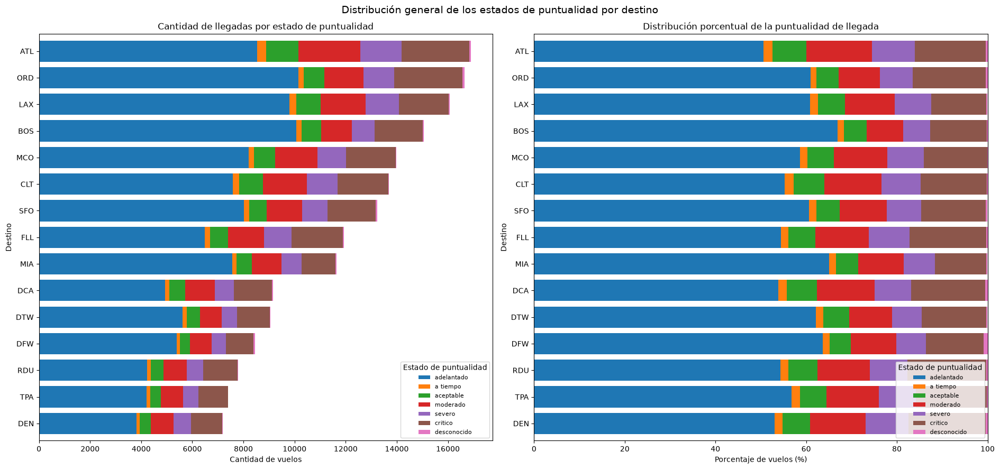


4. GRÁFICO: CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS
Se seleccionan los 20 destinos con mayor cantidad de llegadas graves.
Se diferencian los casos severos de los críticos.
Este gráfico permite identificar dónde se acumula la mayor cantidad
de vuelos con demoras graves.


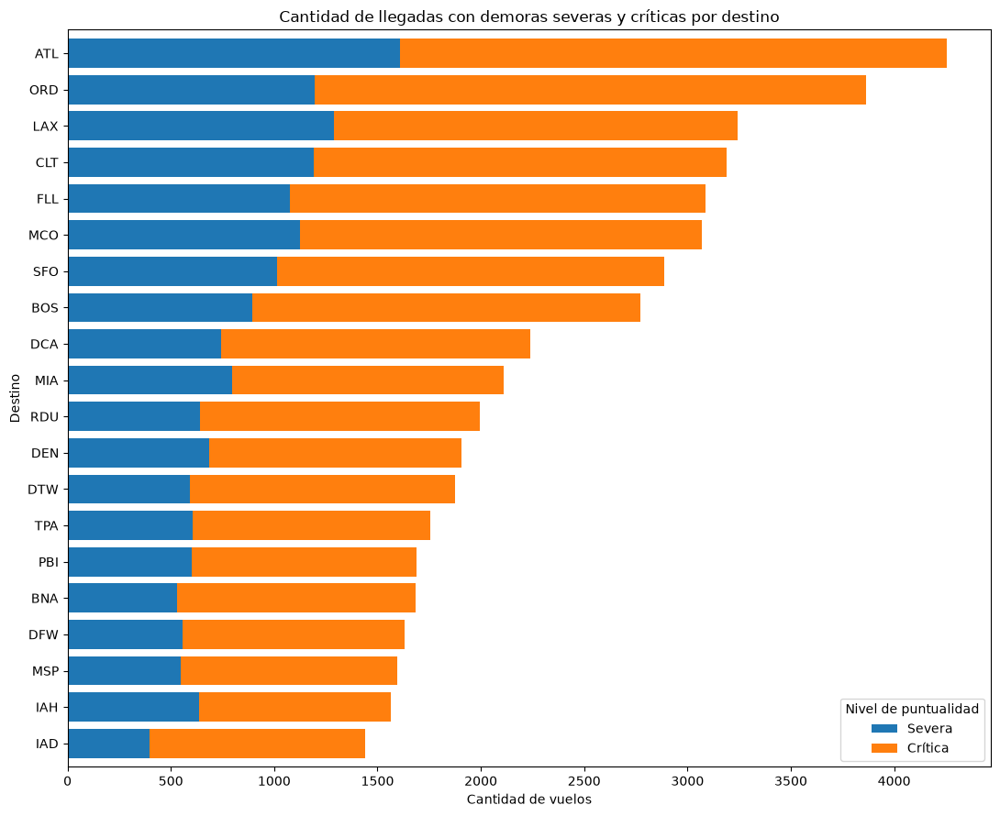


5. GRÁFICO: PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS
Se comparan los destinos con mayor porcentaje de demoras graves.
Solo se consideran destinos con al menos 30 llegadas evaluables.
Separamos los porcentajes severos y críticos para analizar la gravedad.


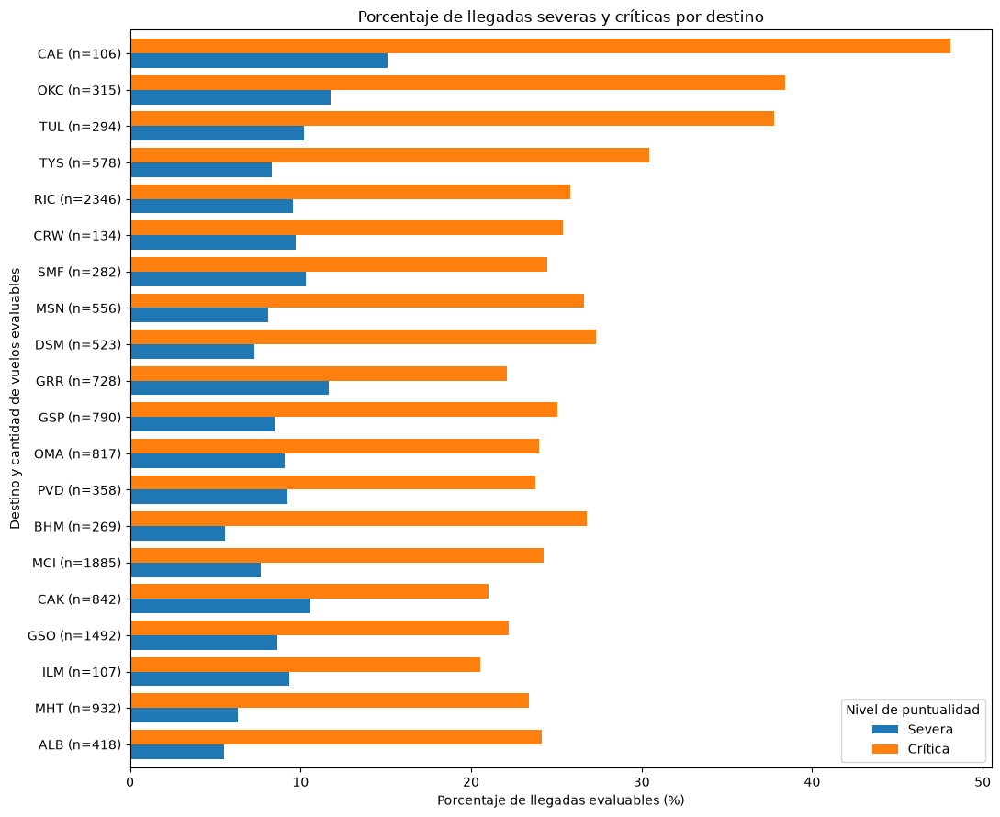


6. GRÁFICO: VOLUMEN DE OPERACIONES Y PORCENTAJE DE DEMORAS GRAVES
Cada punto representa un destino con al menos
30 llegadas evaluables.
El eje horizontal muestra el volumen de vuelos y el vertical
el porcentaje de llegadas severas y críticas.


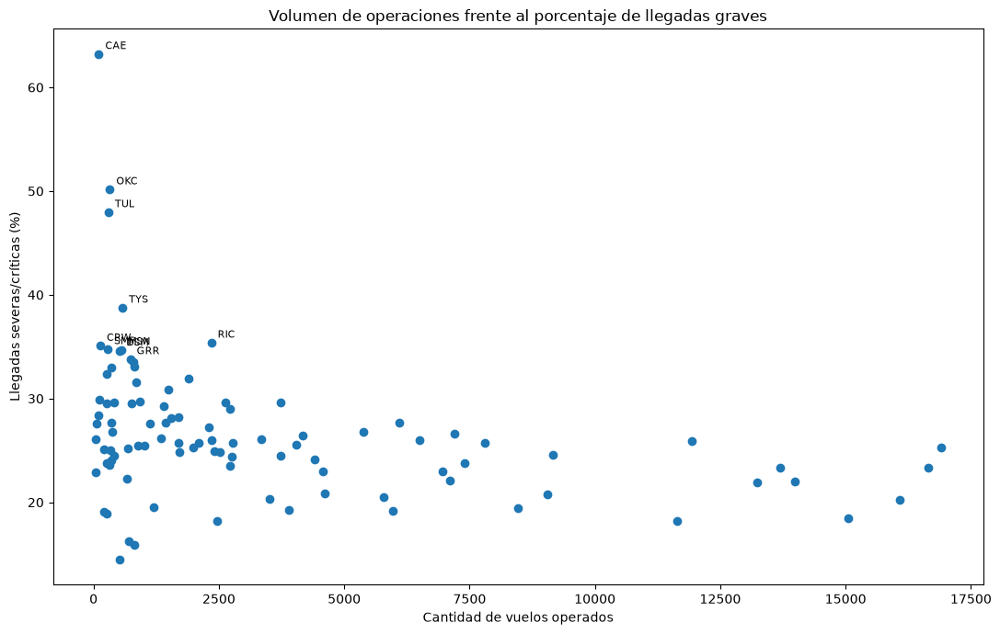


7. DESTINOS CON MAYOR CANTIDAD DE DEMORAS GRAVES
Esta tabla permite identificar los destinos que acumulan
más llegadas severas y críticas, independientemente de su porcentaje.
destino  vuelos_operados  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas_criticas
    ATL            16898                16837              1610               2645                       4255                          25.27
    ORD            16642                16566              1195               2671                       3866                          23.34
    LAX            16076                16026              1291               1952                       3243                          20.24
    CLT            13698                13674              1193               1994                       3187                          23.31
    FLL            11934                11897              1077               2010                       3087         

In [80]:

# ============================================================
# 4.1. VOLUMEN DE OPERACIONES Y DEMORAS POR DESTINO
# ============================================================

print("=" * 80)
print("4.1 | VOLUMEN DE OPERACIONES Y DEMORAS POR DESTINO")
print("=" * 80)

MIN_EVALUABLES = 30
orden_estados = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se analizan los vuelos operados según su aeropuerto de destino.")
print("La prioridad son las llegadas con demoras severas y críticas.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Identificar vuelos con nivel de llegada evaluable.
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Identificar por separado los niveles severo y crítico.
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"].eq("severo")
).astype("int8")

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"].eq("critico")
).astype("int8")

# Indicador combinado: severo + crítico.
base["_arribo_severo_critico"] = (
    base["_arribo_severo"] + base["_arribo_critico"]
)

print(f"Vuelos operados: {len(base):,}")
print(f"Destinos identificados: {base['destino'].nunique()}")


# ------------------------------------------------------------
# 2. Resumen de operaciones y demoras por destino
# ------------------------------------------------------------

print("\n2. RESUMEN DE OPERACIONES Y DEMORAS POR DESTINO")
print("Se calculan cantidades absolutas y porcentajes.")
print("Los porcentajes utilizan únicamente las llegadas evaluables.")

resumen = (
    base.groupby("destino", as_index=False)
    .agg(
        vuelos_operados=("id", "size"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),

        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),

        llegadas_severas_criticas=(
            "_arribo_severo_critico", "sum"
        )
    )
)

# Registros sin nivel de llegada evaluable.
resumen["llegadas_no_evaluables"] = (
    resumen["vuelos_operados"]
    - resumen["llegadas_evaluables"]
)

# Porcentajes individuales.
resumen["pct_llegadas_severas"] = (
    100
    * resumen["llegadas_severas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

resumen["pct_llegadas_criticas"] = (
    100
    * resumen["llegadas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

# Porcentaje combinado.
resumen["pct_llegadas_severas_criticas"] = (
    100
    * resumen["llegadas_severas_criticas"]
    / resumen["llegadas_evaluables"].replace(0, np.nan)
)

columnas_resumen = [
    "destino",
    "vuelos_operados",
    "llegadas_evaluables",
    "llegadas_no_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_resumen = resumen[columnas_resumen].copy()

columnas_pct = [
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_resumen[columnas_pct] = (
    tabla_resumen[columnas_pct].round(2)
)

print("\nTodos los destinos, ordenados por porcentaje de llegadas graves:")
print(
    tabla_resumen
    .sort_values(
        "pct_llegadas_severas_criticas",
        ascending=False,
        na_position="last"
    )
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Distribución general de todos los estados de puntualidad
#    en cantidades y porcentajes
# ------------------------------------------------------------

print("\n3. GRÁFICOS PREVIOS: DISTRIBUCIÓN GENERAL DE PUNTUALIDAD")
print("Se muestran los siete estados existentes de puntualidad de llegada.")
print("Incluimos 'desconocido' para completar la distribución.")
print("Para facilitar la lectura, se seleccionan los 15 destinos con")
print("mayor cantidad de vuelos operados.")

top_destinos_volumen = (
    resumen.nlargest(15, "vuelos_operados")["destino"].tolist()
)

datos_top = base.loc[
    base["destino"].isin(top_destinos_volumen)
].copy()

# Conteo de vuelos por destino y estado de llegada.
estados_cantidad = pd.crosstab(
    datos_top["destino"],
    datos_top["nivel_puntualidad_arribo"]
).reindex(
    index=top_destinos_volumen,
    columns=orden_estados,
    fill_value=0
)

# Porcentaje de cada estado dentro de los vuelos operados del destino.
estados_porcentaje = (
    estados_cantidad
    .div(estados_cantidad.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

# Invertir el orden para mostrar los destinos en barras horizontales.
estados_cantidad = estados_cantidad.iloc[::-1]
estados_porcentaje = estados_porcentaje.iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(19, 9))

# Gráfico general en cantidades.
estados_cantidad.plot(
    kind="barh",
    stacked=True,
    ax=axes[0],
    width=0.8
)

axes[0].set_title("Cantidad de llegadas por estado de puntualidad")
axes[0].set_xlabel("Cantidad de vuelos")
axes[0].set_ylabel("Destino")
axes[0].legend(
    title="Estado de puntualidad",
    fontsize=8,
    loc="lower right"
)

# Gráfico general en porcentajes.
estados_porcentaje.plot(
    kind="barh",
    stacked=True,
    ax=axes[1],
    width=0.8
)

axes[1].set_title("Distribución porcentual de la puntualidad de llegada")
axes[1].set_xlabel("Porcentaje de vuelos (%)")
axes[1].set_ylabel("Destino")
axes[1].set_xlim(0, 100)
axes[1].legend(
    title="Estado de puntualidad",
    fontsize=8,
    loc="lower right"
)

fig.suptitle(
    "Distribución general de los estados de puntualidad por destino",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Gráfico: cantidad de llegadas severas y críticas
# ------------------------------------------------------------

print("\n4. GRÁFICO: CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS")
print("Se seleccionan los 20 destinos con mayor cantidad de llegadas graves.")
print("Se diferencian los casos severos de los críticos.")
print("Este gráfico permite identificar dónde se acumula la mayor cantidad")
print("de vuelos con demoras graves.")

top_cantidad = (
    resumen
    .nlargest(20, "llegadas_severas_criticas")
    .sort_values("llegadas_severas_criticas", ascending=True)
    .set_index("destino")
)

top_cantidad[
    ["llegadas_severas", "llegadas_criticas"]
].rename(
    columns={
        "llegadas_severas": "Severa",
        "llegadas_criticas": "Crítica"
    }
).plot(
    kind="barh",
    stacked=True,
    figsize=(11, 9),
    width=0.8
)

plt.title("Cantidad de llegadas con demoras severas y críticas por destino")
plt.xlabel("Cantidad de vuelos")
plt.ylabel("Destino")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Gráfico: porcentaje de llegadas severas y críticas
# ------------------------------------------------------------

print("\n5. GRÁFICO: PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS")
print("Se comparan los destinos con mayor porcentaje de demoras graves.")
print(f"Solo se consideran destinos con al menos {MIN_EVALUABLES} llegadas evaluables.")
print("Separamos los porcentajes severos y críticos para analizar la gravedad.")

destinos_evaluables = resumen.loc[
    resumen["llegadas_evaluables"] >= MIN_EVALUABLES
].copy()

top_porcentaje = (
    destinos_evaluables
    .nlargest(20, "pct_llegadas_severas_criticas")
    .sort_values("pct_llegadas_severas_criticas", ascending=True)
    .copy()
)

# Incorporar la cantidad de vuelos evaluables al nombre del destino.
top_porcentaje["_etiqueta"] = (
    top_porcentaje["destino"]
    + " (n="
    + top_porcentaje["llegadas_evaluables"].astype(str)
    + ")"
)

top_porcentaje = top_porcentaje.set_index("_etiqueta")

top_porcentaje[
    ["pct_llegadas_severas", "pct_llegadas_criticas"]
].rename(
    columns={
        "pct_llegadas_severas": "Severa",
        "pct_llegadas_criticas": "Crítica"
    }
).plot(
    kind="barh",
    figsize=(11, 9),
    width=0.8
)

plt.title("Porcentaje de llegadas severas y críticas por destino")
plt.xlabel("Porcentaje de llegadas evaluables (%)")
plt.ylabel("Destino y cantidad de vuelos evaluables")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico: volumen de vuelos frente al porcentaje de
#    demoras severas y críticas
# ------------------------------------------------------------

print("\n6. GRÁFICO: VOLUMEN DE OPERACIONES Y PORCENTAJE DE DEMORAS GRAVES")
print("Cada punto representa un destino con al menos")
print(f"{MIN_EVALUABLES} llegadas evaluables.")
print("El eje horizontal muestra el volumen de vuelos y el vertical")
print("el porcentaje de llegadas severas y críticas.")

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    destinos_evaluables["vuelos_operados"],
    destinos_evaluables["pct_llegadas_severas_criticas"]
)

# Identificar los diez destinos con mayor porcentaje de demoras graves.
destinos_destacados = destinos_evaluables.nlargest(
    10,
    "pct_llegadas_severas_criticas"
)

for _, fila in destinos_destacados.iterrows():

    ax.annotate(
        fila["destino"],
        (
            fila["vuelos_operados"],
            fila["pct_llegadas_severas_criticas"]
        ),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Volumen de operaciones frente al porcentaje de llegadas graves")
ax.set_xlabel("Cantidad de vuelos operados")
ax.set_ylabel("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Tabla: destinos con mayor cantidad de llegadas graves
# ------------------------------------------------------------

print("\n7. DESTINOS CON MAYOR CANTIDAD DE DEMORAS GRAVES")
print("Esta tabla permite identificar los destinos que acumulan")
print("más llegadas severas y críticas, independientemente de su porcentaje.")

tabla_mayor_cantidad = (
    resumen[
        [
            "destino",
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_severas_criticas",
            "pct_llegadas_severas_criticas"
        ]
    ]
    .sort_values(
        "llegadas_severas_criticas",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_mayor_cantidad["pct_llegadas_severas_criticas"] = (
    tabla_mayor_cantidad["pct_llegadas_severas_criticas"].round(2)
)

print(tabla_mayor_cantidad.to_string(index=False))


# ------------------------------------------------------------
# 8. Tabla: destinos con mayor porcentaje de llegadas graves
# ------------------------------------------------------------

print("\n8. DESTINOS CON MAYOR PORCENTAJE DE DEMORAS GRAVES")
print("Se incluyen solamente destinos con al menos")
print(f"{MIN_EVALUABLES} llegadas evaluables.")
print("Esto ayuda a evitar que porcentajes extremos basados en muy pocos")
print("vuelos dominen la comparación.")

tabla_mayor_porcentaje = (
    destinos_evaluables[
        [
            "destino",
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_severas_criticas",
            "pct_llegadas_severas",
            "pct_llegadas_criticas",
            "pct_llegadas_severas_criticas"
        ]
    ]
    .sort_values(
        "pct_llegadas_severas_criticas",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_mayor_porcentaje[columnas_pct] = (
    tabla_mayor_porcentaje[columnas_pct].round(2)
)

print(tabla_mayor_porcentaje.to_string(index=False))

#### 4.2. Distribución de las demoras según la ruta de origen a destino

**Objetivo:** determinar si existen rutas que presentan una frecuencia elevada de demoras severas y críticas y estudiar si esos patrones varían entre combinaciones de origen y destino.

Preguntas que vamos a investigar:

- ¿Qué rutas acumulan la mayor cantidad de llegadas severas y críticas?
- ¿Qué rutas presentan los mayores porcentajes de demoras graves?
- ¿Existen rutas donde las demoras severas y críticas aparecen de forma recurrente?
- ¿Una misma ruta presenta patrones diferentes según el aeropuerto de origen?
- ¿Hay rutas con porcentajes elevados de demoras graves incluso cuando su volumen de operaciones es reducido?

**Enfoque del análisis:** utilizaremos la columna existente `ruta`, que representa la combinación de aeropuerto de origen y destino. Compararemos cantidades y porcentajes de llegadas severas y críticas, considerando el volumen de vuelos evaluables de cada ruta. Nos concentraremos en las rutas con suficientes observaciones para que las comparaciones sean más representativas.

4.2 | DEMORAS SEVERAS Y CRÍTICAS POR RUTA

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados con ruta y destino identificados.
La prioridad son las llegadas con demoras severas y críticas.
Vuelos operados analizados: 328,521
Rutas identificadas: 223

2. RESUMEN DE OPERACIONES Y DEMORAS POR RUTA
Se calculan cantidades y porcentajes de llegadas severas y críticas.
Los porcentajes utilizan únicamente las llegadas evaluables.

Cantidad de rutas analizadas: 223

3. RUTAS CON MAYOR CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS
Se identifican las rutas que acumulan más casos graves.
Separamos las llegadas severas de las críticas.
   ruta origen destino  vuelos_operados  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
LGA-ATL    LGA     ATL            10082                10041              1019               1563                       2582                 10.15                  15

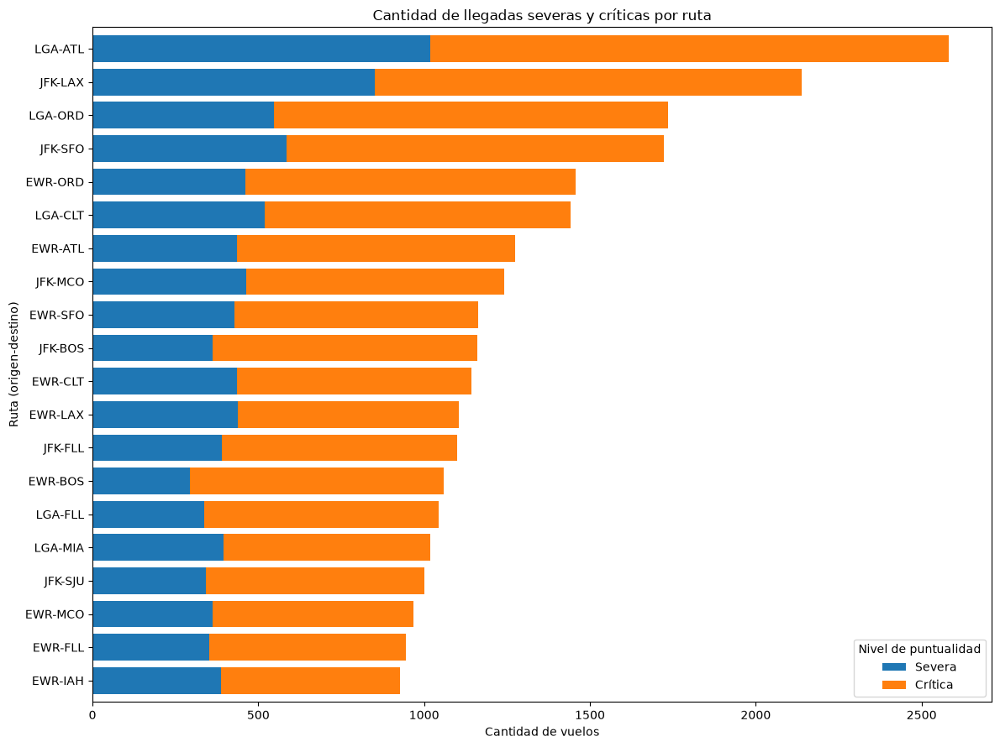


5. RUTAS CON MAYOR PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS
Se consideran rutas con al menos 30 llegadas evaluables.
Esto ayuda a evitar que grupos muy pequeños dominen la comparación.
   ruta origen destino  vuelos_operados  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
EWR-CAE    EWR     CAE               95                   94                13                 47                         60                 13.83                  50.00                          63.83
EWR-OKC    EWR     OKC              327                  315                37                121                        158                 11.75                  38.41                          50.16
EWR-TYS    EWR     TYS              314                  313                25                129                        154                  7.99                  41.21                          49.20
EWR-TUL  

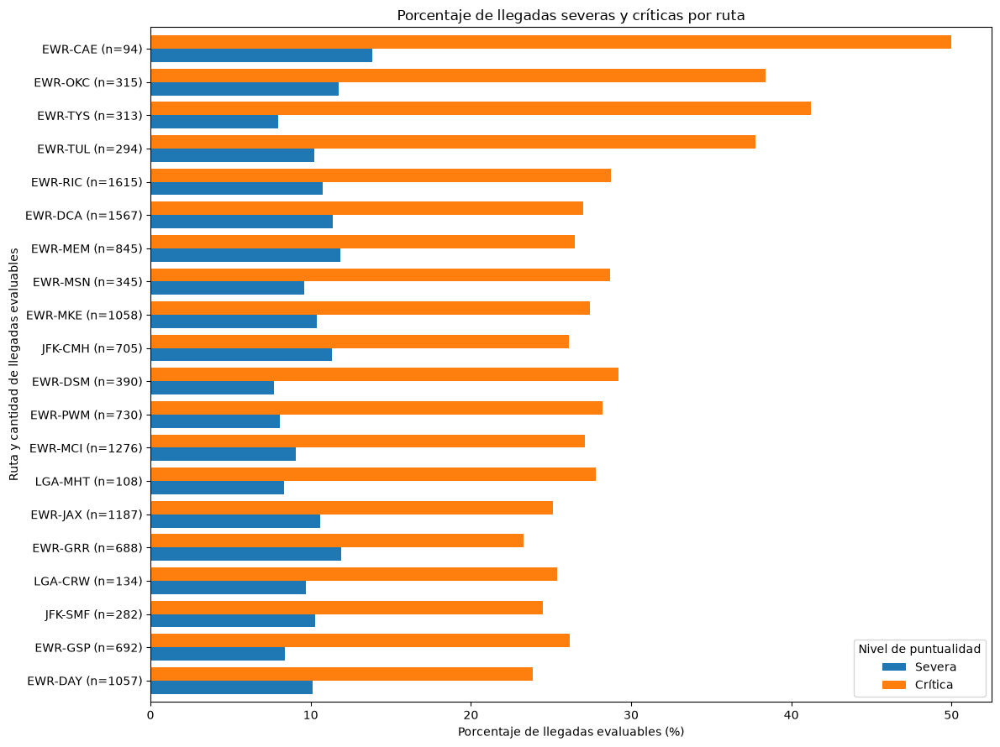


7. GRÁFICO: VOLUMEN DE OPERACIONES Y PORCENTAJE DE DEMORAS GRAVES
Se consideran rutas con al menos 30 llegadas evaluables.
Cada punto representa una ruta.
Se destacan las 12 rutas con mayor porcentaje de llegadas graves.


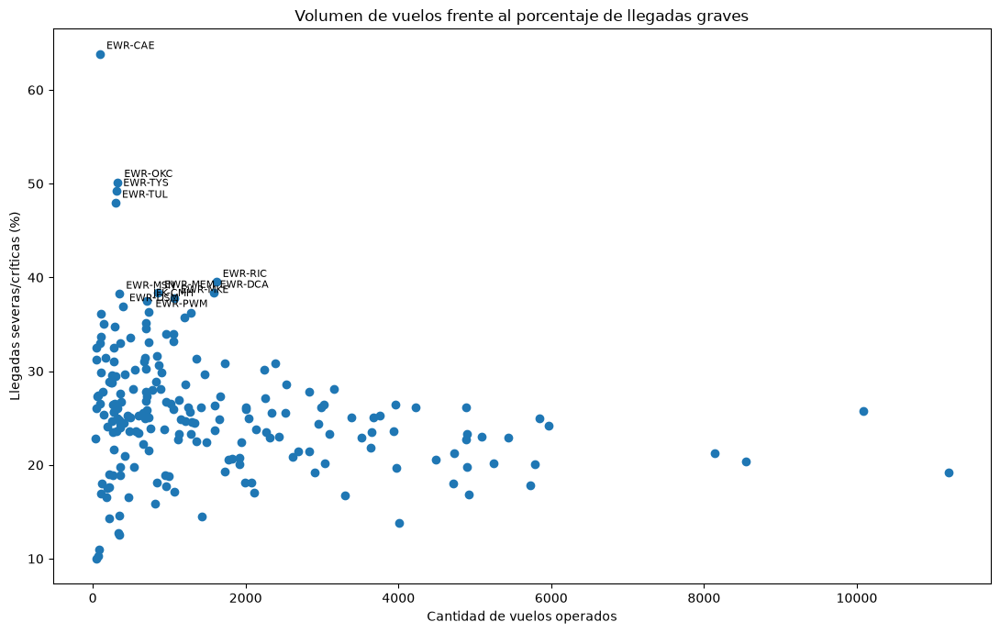


8. ANÁLISIS TRIMESTRAL DE LAS DEMORAS POR RUTA
Se observa en cuántos trimestres aparecen llegadas severas y críticas.
Esto permite distinguir los casos concentrados en un período
de los que aparecen repetidamente a lo largo del año.

Rutas con presencia de demoras graves en más trimestres:
   ruta  trimestres_con_vuelos  trimestres_con_casos_graves  total_llegadas_graves  vuelos_operados  llegadas_evaluables  pct_llegadas_severas_criticas
LGA-ATL                      4                            4                   2582            10082                10041                          25.71
JFK-LAX                      4                            4                   2138            11196                11159                          19.16
LGA-ORD                      4                            4                   1735             8548                 8507                          20.39
JFK-SFO                      4                            4                   1723             8138 

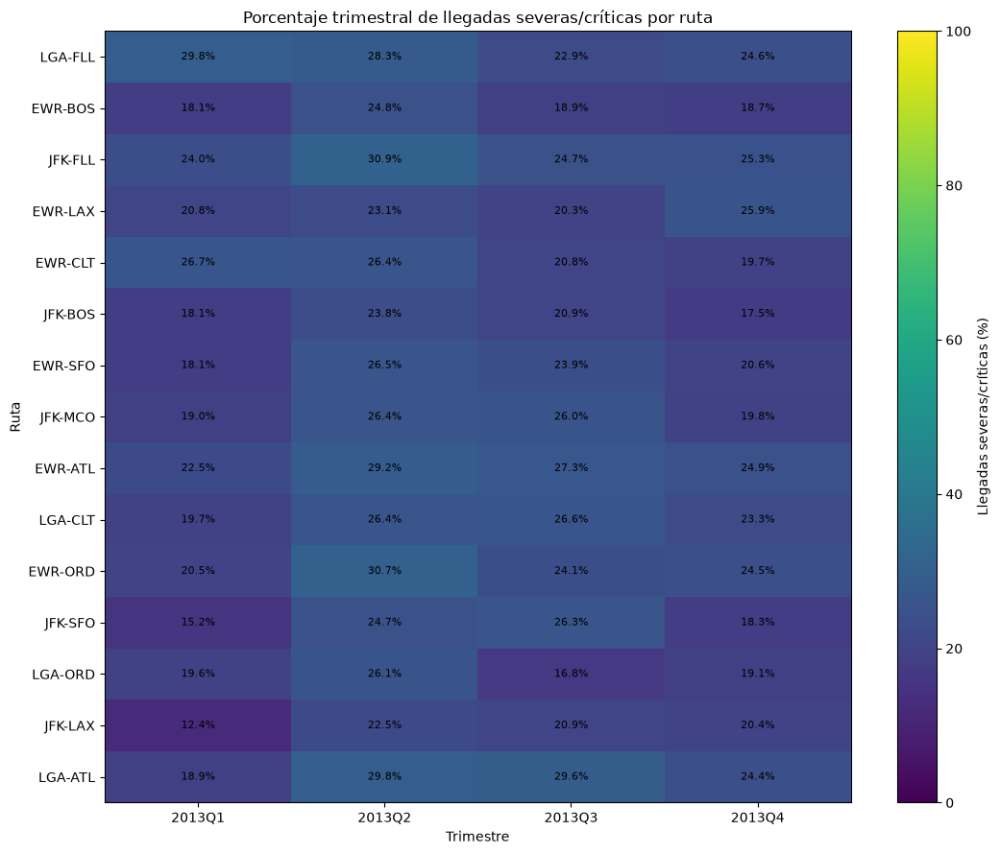


10. COMPARACIÓN DE UN MISMO DESTINO SEGÚN EL AEROPUERTO DE ORIGEN
Como ruta ya contiene origen y destino, comparamos las diferentes
rutas que llegan al mismo destino desde EWR, JFK o LGA.

Comparación de destinos desde distintos aeropuertos:
destino origen  vuelos_operados  llegadas_evaluables  llegadas_severas_criticas  pct_llegadas_severas_criticas
    ATL    EWR             4891                 4876                       1274                          26.13
    ATL    JFK             1925                 1920                        399                          20.78
    ATL    LGA            10082                10041                       2582                          25.71
    BOS    EWR             5251                 5247                       1058                          20.16
    BOS    JFK             5786                 5773                       1161                          20.11
    BOS    LGA             4012                 4002                        554            

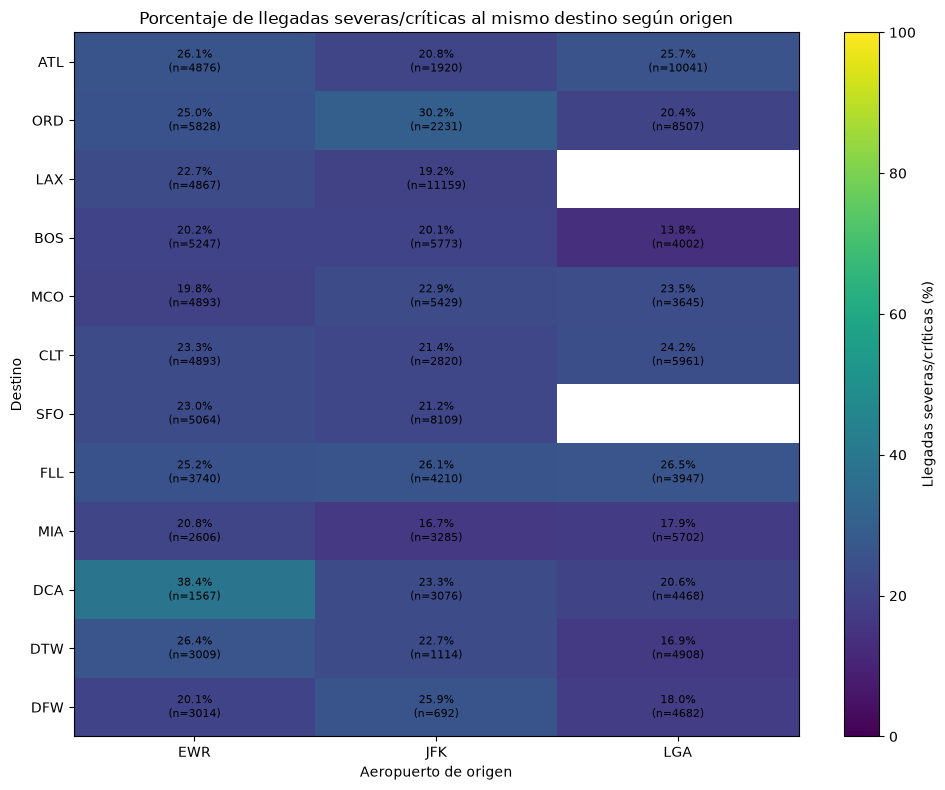

In [81]:
# ============================================================
# 4.2. DISTRIBUCIÓN DE LAS DEMORAS SEGÚN LA RUTA
#      DE ORIGEN A DESTINO
# ============================================================

print("=" * 80)
print("4.2 | DEMORAS SEVERAS Y CRÍTICAS POR RUTA")
print("=" * 80)

MIN_EVALUABLES = 30

# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados con ruta y destino identificados.")
print("La prioridad son las llegadas con demoras severas y críticas.")

base = df.loc[
    df["estado_vuelo"].eq("operado")
    & df["ruta"].notna()
    & df["origen"].notna()
    & df["destino"].notna()
].copy()

# Identificar llegadas evaluables.
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Identificar separadamente los niveles de gravedad.
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"].eq("severo")
).astype("int8")

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"].eq("critico")
).astype("int8")

# Indicador combinado.
base["_arribo_severo_critico"] = (
    base["_arribo_severo"] + base["_arribo_critico"]
)

print(f"Vuelos operados analizados: {len(base):,}")
print(f"Rutas identificadas: {base['ruta'].nunique()}")


# ------------------------------------------------------------
# 2. Resumen de operaciones y demoras por ruta
# ------------------------------------------------------------

print("\n2. RESUMEN DE OPERACIONES Y DEMORAS POR RUTA")
print("Se calculan cantidades y porcentajes de llegadas severas y críticas.")
print("Los porcentajes utilizan únicamente las llegadas evaluables.")

resumen_rutas = (
    base.groupby(
        ["ruta", "origen", "destino"],
        as_index=False
    )
    .agg(
        vuelos_operados=("id", "size"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=(
            "_arribo_severo_critico", "sum"
        )
    )
)

# Porcentajes individuales.
resumen_rutas["pct_llegadas_severas"] = (
    100
    * resumen_rutas["llegadas_severas"]
    / resumen_rutas["llegadas_evaluables"].replace(0, np.nan)
)

resumen_rutas["pct_llegadas_criticas"] = (
    100
    * resumen_rutas["llegadas_criticas"]
    / resumen_rutas["llegadas_evaluables"].replace(0, np.nan)
)

# Porcentaje combinado: indicador principal.
resumen_rutas["pct_llegadas_severas_criticas"] = (
    100
    * resumen_rutas["llegadas_severas_criticas"]
    / resumen_rutas["llegadas_evaluables"].replace(0, np.nan)
)

print("\nCantidad de rutas analizadas:", len(resumen_rutas))


# ------------------------------------------------------------
# 3. Tabla: rutas con mayor cantidad de llegadas graves
# ------------------------------------------------------------

print("\n3. RUTAS CON MAYOR CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS")
print("Se identifican las rutas que acumulan más casos graves.")
print("Separamos las llegadas severas de las críticas.")

columnas_ruta = [
    "ruta",
    "origen",
    "destino",
    "vuelos_operados",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_severas_criticas",
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_rutas_cantidad = (
    resumen_rutas[columnas_ruta]
    .sort_values(
        "llegadas_severas_criticas",
        ascending=False
    )
    .head(20)
    .copy()
)

columnas_porcentaje = [
    "pct_llegadas_severas",
    "pct_llegadas_criticas",
    "pct_llegadas_severas_criticas"
]

tabla_rutas_cantidad[columnas_porcentaje] = (
    tabla_rutas_cantidad[columnas_porcentaje].round(2)
)

print(tabla_rutas_cantidad.to_string(index=False))


# ------------------------------------------------------------
# 4. Gráfico: cantidad de llegadas severas y críticas por ruta
# ------------------------------------------------------------

print("\n4. GRÁFICO: CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS POR RUTA")
print("Se muestran las 20 rutas con mayor cantidad de llegadas graves.")
print("Las barras distinguen los casos severos de los críticos.")

grafico_cantidad = (
    tabla_rutas_cantidad
    .sort_values("llegadas_severas_criticas", ascending=True)
    .set_index("ruta")
)

grafico_cantidad[
    ["llegadas_severas", "llegadas_criticas"]
].rename(
    columns={
        "llegadas_severas": "Severa",
        "llegadas_criticas": "Crítica"
    }
).plot(
    kind="barh",
    stacked=True,
    figsize=(12, 9),
    width=0.8
)

plt.title("Cantidad de llegadas severas y críticas por ruta")
plt.xlabel("Cantidad de vuelos")
plt.ylabel("Ruta (origen-destino)")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Tabla: rutas con mayor porcentaje de llegadas graves
# ------------------------------------------------------------

print("\n5. RUTAS CON MAYOR PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS")
print(f"Se consideran rutas con al menos {MIN_EVALUABLES} llegadas evaluables.")
print("Esto ayuda a evitar que grupos muy pequeños dominen la comparación.")

rutas_evaluables = resumen_rutas.loc[
    resumen_rutas["llegadas_evaluables"] >= MIN_EVALUABLES
].copy()

tabla_rutas_porcentaje = (
    rutas_evaluables[columnas_ruta]
    .sort_values(
        "pct_llegadas_severas_criticas",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_rutas_porcentaje[columnas_porcentaje] = (
    tabla_rutas_porcentaje[columnas_porcentaje].round(2)
)

print(tabla_rutas_porcentaje.to_string(index=False))


# ------------------------------------------------------------
# 6. Gráfico: porcentaje de llegadas severas y críticas por ruta
# ------------------------------------------------------------

print("\n6. GRÁFICO: PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS POR RUTA")
print("Se comparan los 20 mayores porcentajes entre rutas con suficientes datos.")
print("Se distinguen los porcentajes severos y críticos.")

grafico_porcentaje = (
    tabla_rutas_porcentaje
    .sort_values(
        "pct_llegadas_severas_criticas",
        ascending=True
    )
    .copy()
)

grafico_porcentaje["_etiqueta"] = (
    grafico_porcentaje["ruta"]
    + " (n="
    + grafico_porcentaje["llegadas_evaluables"].astype(str)
    + ")"
)

grafico_porcentaje = grafico_porcentaje.set_index("_etiqueta")

grafico_porcentaje[
    ["pct_llegadas_severas", "pct_llegadas_criticas"]
].rename(
    columns={
        "pct_llegadas_severas": "Severa",
        "pct_llegadas_criticas": "Crítica"
    }
).plot(
    kind="barh",
    figsize=(12, 9),
    width=0.8
)

plt.title("Porcentaje de llegadas severas y críticas por ruta")
plt.xlabel("Porcentaje de llegadas evaluables (%)")
plt.ylabel("Ruta y cantidad de llegadas evaluables")
plt.legend(title="Nivel de puntualidad")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Gráfico: volumen de vuelos frente al porcentaje de
#    llegadas severas y críticas
# ------------------------------------------------------------

print("\n7. GRÁFICO: VOLUMEN DE OPERACIONES Y PORCENTAJE DE DEMORAS GRAVES")
print(f"Se consideran rutas con al menos {MIN_EVALUABLES} llegadas evaluables.")
print("Cada punto representa una ruta.")
print("Se destacan las 12 rutas con mayor porcentaje de llegadas graves.")

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    rutas_evaluables["vuelos_operados"],
    rutas_evaluables["pct_llegadas_severas_criticas"]
)

rutas_destacadas = rutas_evaluables.nlargest(
    12,
    "pct_llegadas_severas_criticas"
)

for _, fila in rutas_destacadas.iterrows():

    ax.annotate(
        fila["ruta"],
        (
            fila["vuelos_operados"],
            fila["pct_llegadas_severas_criticas"]
        ),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Volumen de vuelos frente al porcentaje de llegadas graves")
ax.set_xlabel("Cantidad de vuelos operados")
ax.set_ylabel("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Análisis trimestral de las demoras por ruta
# ------------------------------------------------------------

print("\n8. ANÁLISIS TRIMESTRAL DE LAS DEMORAS POR RUTA")
print("Se observa en cuántos trimestres aparecen llegadas severas y críticas.")
print("Esto permite distinguir los casos concentrados en un período")
print("de los que aparecen repetidamente a lo largo del año.")

resumen_trimestral = (
    base.groupby(
        ["ruta", "trimestre"],
        as_index=False,
        observed=True
    )
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=(
            "_arribo_severo_critico", "sum"
        )
    )
)

resumen_trimestral["pct_llegadas_severas_criticas"] = (
    100
    * resumen_trimestral["llegadas_severas_criticas"]
    / resumen_trimestral["llegadas_evaluables"].replace(0, np.nan)
)

# Contar trimestres con operaciones y trimestres con casos graves.
recurrencia = (
    resumen_trimestral.groupby("ruta")
    .agg(
        trimestres_con_vuelos=("trimestre", "nunique"),
        trimestres_con_casos_graves=(
            "llegadas_severas_criticas",
            lambda x: (x > 0).sum()
        ),
        total_llegadas_graves=("llegadas_severas_criticas", "sum")
    )
    .reset_index()
)

recurrencia = recurrencia.merge(
    resumen_rutas[
        [
            "ruta",
            "vuelos_operados",
            "llegadas_evaluables",
            "pct_llegadas_severas_criticas"
        ]
    ],
    on="ruta",
    how="left"
)

# Mostrar primero rutas con casos graves en más trimestres.
tabla_recurrencia = recurrencia.loc[
    recurrencia["llegadas_evaluables"] >= MIN_EVALUABLES
].sort_values(
    [
        "trimestres_con_casos_graves",
        "total_llegadas_graves"
    ],
    ascending=False
).head(20).copy()

tabla_recurrencia["pct_llegadas_severas_criticas"] = (
    tabla_recurrencia["pct_llegadas_severas_criticas"].round(2)
)

print("\nRutas con presencia de demoras graves en más trimestres:")
print(tabla_recurrencia.to_string(index=False))


# ------------------------------------------------------------
# 9. Gráfico: evolución trimestral del porcentaje de demoras graves
# ------------------------------------------------------------

print("\n9. GRÁFICO: EVOLUCIÓN TRIMESTRAL DE LAS DEMORAS POR RUTA")
print("Se seleccionan las 15 rutas con mayor cantidad total de llegadas graves.")
print("Cada celda representa el porcentaje trimestral de llegadas")
print("severas y críticas sobre las llegadas evaluables de esa ruta.")
print("Las celdas vacías indican que no hubo vuelos de esa ruta en el trimestre.")

rutas_top_trimestral = (
    rutas_evaluables
    .nlargest(15, "llegadas_severas_criticas")["ruta"]
    .tolist()
)

datos_trimestrales = resumen_trimestral.loc[
    resumen_trimestral["ruta"].isin(rutas_top_trimestral)
].copy()

matriz_trimestral = datos_trimestrales.pivot(
    index="ruta",
    columns="trimestre",
    values="pct_llegadas_severas_criticas"
)

matriz_trimestral = matriz_trimestral.reindex(
    index=rutas_top_trimestral,
    columns=sorted(base["trimestre"].dropna().unique())
)

matriz_trimestral = matriz_trimestral.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 9))

datos_mapa = np.ma.masked_invalid(
    matriz_trimestral.to_numpy(dtype=float)
)

imagen = ax.imshow(
    datos_mapa,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_yticks(range(len(matriz_trimestral.index)))
ax.set_yticklabels(matriz_trimestral.index)

ax.set_xticks(range(len(matriz_trimestral.columns)))
ax.set_xticklabels(
    [str(trimestre) for trimestre in matriz_trimestral.columns]
)

ax.set_title("Porcentaje trimestral de llegadas severas/críticas por ruta")
ax.set_xlabel("Trimestre")
ax.set_ylabel("Ruta")

for i, ruta in enumerate(matriz_trimestral.index):
    for j, trimestre in enumerate(matriz_trimestral.columns):

        porcentaje = matriz_trimestral.loc[ruta, trimestre]

        if pd.notna(porcentaje):
            ax.text(
                j,
                i,
                f"{porcentaje:.1f}%",
                ha="center",
                va="center",
                fontsize=8
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Comparación de un mismo destino según el aeropuerto de origen
# ------------------------------------------------------------

print("\n10. COMPARACIÓN DE UN MISMO DESTINO SEGÚN EL AEROPUERTO DE ORIGEN")
print("Como ruta ya contiene origen y destino, comparamos las diferentes")
print("rutas que llegan al mismo destino desde EWR, JFK o LGA.")

resumen_destino_origen = (
    base.groupby(
        ["destino", "origen"],
        as_index=False
    )
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas_criticas=(
            "_arribo_severo_critico", "sum"
        )
    )
)

resumen_destino_origen["pct_llegadas_severas_criticas"] = (
    100
    * resumen_destino_origen["llegadas_severas_criticas"]
    / resumen_destino_origen["llegadas_evaluables"].replace(0, np.nan)
)

# Identificar destinos atendidos desde al menos dos orígenes.
origenes_por_destino = (
    resumen_destino_origen.groupby("destino")["origen"].nunique()
)

destinos_varios_origenes = origenes_por_destino[
    origenes_por_destino >= 2
].index

comparacion_destinos = resumen_destino_origen.loc[
    resumen_destino_origen["destino"].isin(destinos_varios_origenes)
    & resumen_destino_origen["llegadas_evaluables"].ge(MIN_EVALUABLES)
].copy()

# Elegir los 12 destinos con más llegadas evaluables entre los que
# cuentan con al menos dos aeropuertos de origen.
top_destinos_comparacion = (
    comparacion_destinos.groupby("destino")["llegadas_evaluables"]
    .sum()
    .nlargest(12)
    .index.tolist()
)

comparacion_destinos = comparacion_destinos.loc[
    comparacion_destinos["destino"].isin(top_destinos_comparacion)
]

tabla_destino_origen = comparacion_destinos[
    [
        "destino",
        "origen",
        "vuelos_operados",
        "llegadas_evaluables",
        "llegadas_severas_criticas",
        "pct_llegadas_severas_criticas"
    ]
].copy()

tabla_destino_origen["pct_llegadas_severas_criticas"] = (
    tabla_destino_origen["pct_llegadas_severas_criticas"].round(2)
)

print("\nComparación de destinos desde distintos aeropuertos:")
print(
    tabla_destino_origen
    .sort_values(["destino", "origen"])
    .to_string(index=False)
)


# ------------------------------------------------------------
# 11. Gráfico: un mismo destino según el aeropuerto de origen
# ------------------------------------------------------------

print("\n11. GRÁFICO: LLEGADAS GRAVES AL MISMO DESTINO SEGÚN SU ORIGEN")
print("Se comparan los porcentajes de demoras severas/críticas")
print("para destinos atendidos desde distintos aeropuertos.")
print("Solo se muestran combinaciones con al menos 30 llegadas evaluables.")

matriz_destinos = comparacion_destinos.pivot(
    index="destino",
    columns="origen",
    values="pct_llegadas_severas_criticas"
).reindex(
    index=top_destinos_comparacion,
    columns=["EWR", "JFK", "LGA"]
)

matriz_destinos_n = comparacion_destinos.pivot(
    index="destino",
    columns="origen",
    values="llegadas_evaluables"
).reindex(
    index=top_destinos_comparacion,
    columns=["EWR", "JFK", "LGA"]
)

fig, ax = plt.subplots(figsize=(10, 8))

datos_mapa = np.ma.masked_invalid(
    matriz_destinos.to_numpy(dtype=float)
)

imagen = ax.imshow(
    datos_mapa,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(matriz_destinos.columns)))
ax.set_xticklabels(matriz_destinos.columns)

ax.set_yticks(range(len(matriz_destinos.index)))
ax.set_yticklabels(matriz_destinos.index)

ax.set_title(
    "Porcentaje de llegadas severas/críticas al mismo destino según origen"
)
ax.set_xlabel("Aeropuerto de origen")
ax.set_ylabel("Destino")

for i, destino in enumerate(matriz_destinos.index):
    for j, origen in enumerate(matriz_destinos.columns):

        porcentaje = matriz_destinos.loc[destino, origen]
        cantidad = matriz_destinos_n.loc[destino, origen]

        if pd.notna(porcentaje) and pd.notna(cantidad):
            ax.text(
                j,
                i,
                f"{porcentaje:.1f}%\n(n={int(cantidad)})",
                ha="center",
                va="center",
                fontsize=8
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()

#### 4.3. Relación entre puntualidad de salida y llegada según el destino

**Objetivo:** estudiar si la relación entre la puntualidad de salida y la gravedad de la llegada varía según el destino del vuelo.

Preguntas que vamos a investigar:

- ¿Qué porcentaje de los vuelos que salen adelantados, a tiempo o con distintos niveles de demora termina llegando con una demora severa o crítica?
- ¿Existen destinos donde una salida demorada esté más asociada con una llegada severamente demorada o crítica?
- ¿Hay destinos donde una proporción elevada de vuelos sale puntualmente, pero llega con demoras graves?
- ¿La relación entre la puntualidad de salida y llegada presenta patrones diferentes según el destino?

**Enfoque del análisis:** relacionaremos los niveles de puntualidad de salida con los de llegada y compararemos los resultados por destino. Para que la comparación sea consistente, utilizaremos vuelos con niveles de puntualidad conocidos en ambas etapas. Priorizaremos las llegadas severas y críticas y tendremos en cuenta que las diferencias también pueden estar asociadas con las rutas, la duración del vuelo, los horarios y otros factores operativos.

4.3 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA POR DESTINO

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados con niveles conocidos de salida y llegada.
El indicador principal son las llegadas severas y críticas.
Vuelos operados con destino identificado: 328,521
Vuelos evaluables en ambas etapas: 327,346
Destinos analizados: 104

2. DISTRIBUCIÓN GENERAL SEGÚN EL NIVEL DE SALIDA
Se calcula qué porcentaje de los vuelos llega con demora severa
o crítica según el nivel de puntualidad que tuvo al salir.

Resumen general:
nivel_puntualidad_salida  vuelos  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
              adelantado  183135              6677               3041                       9718                  3.65                   1.66                           5.31
                a tiempo   16466              1073                526                       1599                  6.52

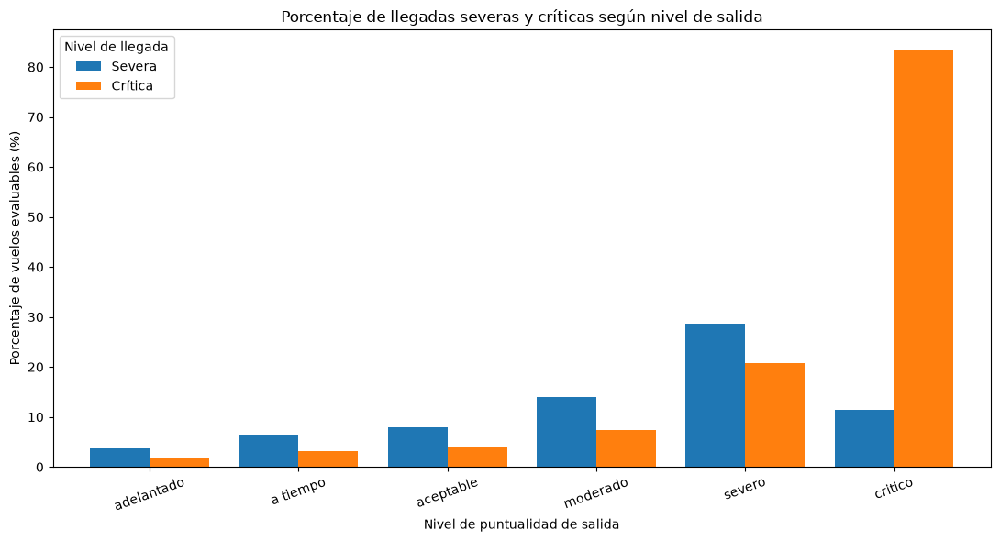


4. RESUMEN DE LA RELACIÓN ENTRE SALIDA Y LLEGADA POR DESTINO
Se calcula el porcentaje de llegadas severas y críticas
para cada destino y cada nivel de puntualidad de salida.

Detalle por destino y nivel de salida:
destino nivel_puntualidad_salida  vuelos  llegadas_severas  llegadas_criticas  pct_llegadas_severas_criticas
    ABQ               adelantado     122                 7                  4                           9.02
    ABQ                 a tiempo      17                 0                  5                          29.41
    ABQ                aceptable      13                 0                  1                           7.69
    ABQ                 moderado      29                 3                  4                          24.14
    ABQ                   severo      30                 7                  9                          53.33
    ABQ                  critico      43                 3                 32                          81.40
    ACK               

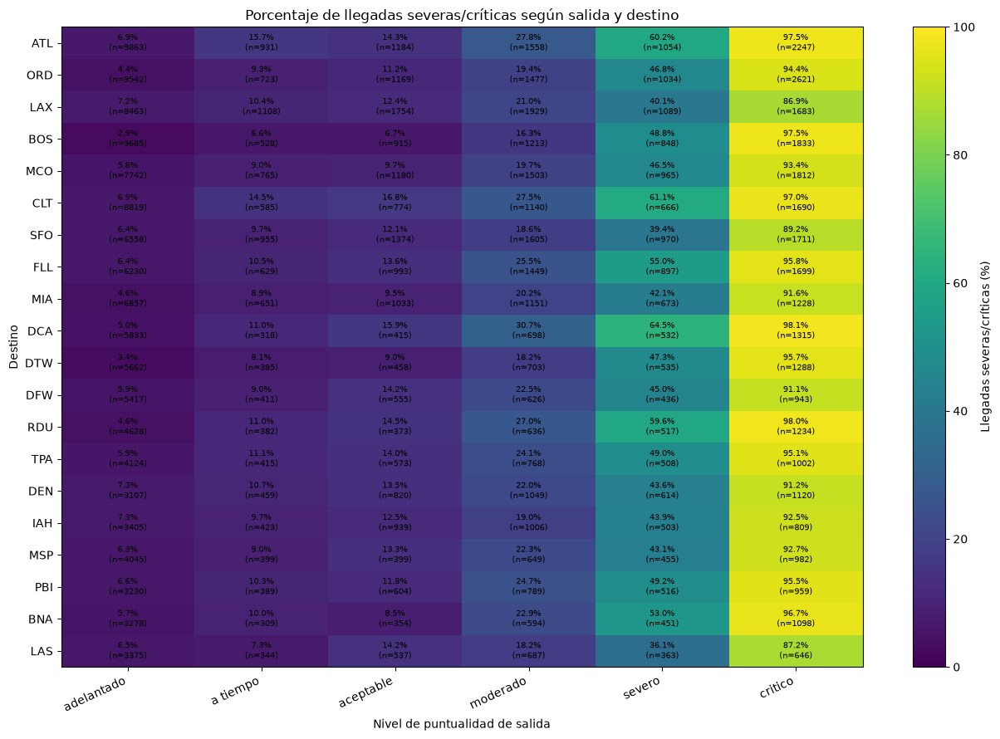


7. DESTINOS CON DEMORAS GRAVES A PESAR DE SALIR PUNTUALMENTE
Consideramos salida puntual exclusivamente cuando el vuelo
sale adelantado o a tiempo.
Se excluyen los destinos con menos de 30 vuelos en este grupo.
destino  vuelos_salida_puntual  llegadas_graves_tras_salida_puntual  pct_llegadas_graves_tras_salida_puntual
    OKC                    130                                   17                                    13.08
    XNA                    738                                   87                                    11.79
    ABQ                    139                                   16                                    11.51
    CAE                     35                                    4                                    11.43
    SMF                    136                                   15                                    11.03
    SJC                    192                                   21                                    10.94
    PHL                  

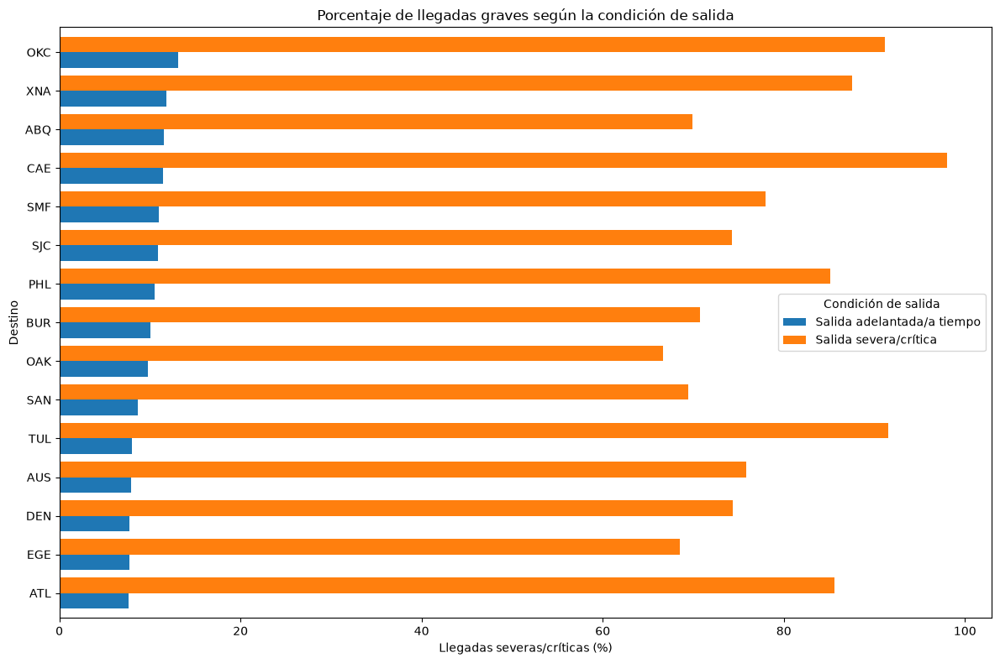


9. DESTINOS CON DEMORAS GRAVES TANTO EN SALIDA COMO EN LLEGADA
Se identifica qué proporción de vuelos presenta niveles severos
o críticos en ambas etapas.
destino  vuelos_comparables  vuelos_graves_ambas_etapas  pct_vuelos_graves_ambas_etapas  llegadas_severas_criticas  pct_llegadas_severas_criticas
    CAE                 106                          50                           47.17                         67                          63.21
    TUL                 294                         119                           40.48                        141                          47.96
    OKC                 315                         123                           39.05                        158                          50.16
    TYS                 578                         194                           33.56                        224                          38.75
    CRW                 134                          43                           32.09                         47

In [82]:
# ============================================================
# 4.3. RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
#      SEGÚN EL DESTINO
# ============================================================

print("=" * 80)
print("4.3 | RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA POR DESTINO")
print("=" * 80)

MIN_EVALUABLES = 30

orden_niveles_salida = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados con niveles conocidos de salida y llegada.")
print("El indicador principal son las llegadas severas y críticas.")

base = df.loc[
    df["estado_vuelo"].eq("operado")
    & df["destino"].notna()
].copy()

# Identificar vuelos evaluables en ambas etapas.
base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].notna()
    & base["nivel_puntualidad_salida"].ne("desconocido")
)

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
)

# Comparar utilizando los mismos vuelos.
comparables = base.loc[
    base["_salida_evaluable"]
    & base["_arribo_evaluable"]
].copy()

# Identificar las demoras severas y críticas.
comparables["_salida_grave"] = (
    comparables["nivel_puntualidad_salida"]
    .isin(["severo", "critico"])
)

comparables["_arribo_severo"] = (
    comparables["nivel_puntualidad_arribo"].eq("severo")
)

comparables["_arribo_critico"] = (
    comparables["nivel_puntualidad_arribo"].eq("critico")
)

comparables["_arribo_grave"] = (
    comparables["_arribo_severo"]
    | comparables["_arribo_critico"]
)

# Salida adelantada o a tiempo.
# "aceptable" se mantiene como categoría independiente.
comparables["_salida_puntual"] = (
    comparables["nivel_puntualidad_salida"]
    .isin(["adelantado", "a tiempo"])
)

# Identificar vuelos graves en ambas etapas.
comparables["_grave_ambas_etapas"] = (
    comparables["_salida_grave"]
    & comparables["_arribo_grave"]
)

print(f"Vuelos operados con destino identificado: {len(base):,}")
print(f"Vuelos evaluables en ambas etapas: {len(comparables):,}")
print(f"Destinos analizados: {comparables['destino'].nunique()}")


# ------------------------------------------------------------
# 2. Relación general entre los niveles de salida y llegada
# ------------------------------------------------------------

print("\n2. DISTRIBUCIÓN GENERAL SEGÚN EL NIVEL DE SALIDA")
print("Se calcula qué porcentaje de los vuelos llega con demora severa")
print("o crítica según el nivel de puntualidad que tuvo al salir.")

resumen_salida = (
    comparables.groupby(
        "nivel_puntualidad_salida",
        as_index=False
    )
    .agg(
        vuelos=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

resumen_salida["pct_llegadas_severas"] = (
    100
    * resumen_salida["llegadas_severas"]
    / resumen_salida["vuelos"]
)

resumen_salida["pct_llegadas_criticas"] = (
    100
    * resumen_salida["llegadas_criticas"]
    / resumen_salida["vuelos"]
)

resumen_salida["pct_llegadas_severas_criticas"] = (
    100
    * resumen_salida["llegadas_severas_criticas"]
    / resumen_salida["vuelos"]
)

resumen_salida["nivel_puntualidad_salida"] = pd.Categorical(
    resumen_salida["nivel_puntualidad_salida"],
    categories=orden_niveles_salida,
    ordered=True
)

resumen_salida = resumen_salida.sort_values(
    "nivel_puntualidad_salida"
)

print("\nResumen general:")
print(
    resumen_salida.round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 3. Gráfico: porcentaje de llegadas severas y críticas
#    según puntualidad de salida
# ------------------------------------------------------------

print("\n3. GRÁFICO: LLEGADAS SEVERAS Y CRÍTICAS SEGÚN PUNTUALIDAD DE SALIDA")
print("Permite observar cómo cambia la gravedad de la llegada")
print("según el estado de puntualidad con el que sale el vuelo.")
print("Separamos las llegadas severas de las críticas.")

grafico_general = (
    resumen_salida
    .set_index("nivel_puntualidad_salida")[
        [
            "pct_llegadas_severas",
            "pct_llegadas_criticas"
        ]
    ]
    .rename(
        columns={
            "pct_llegadas_severas": "Severa",
            "pct_llegadas_criticas": "Crítica"
        }
    )
)

grafico_general.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Porcentaje de llegadas severas y críticas según nivel de salida")
plt.xlabel("Nivel de puntualidad de salida")
plt.ylabel("Porcentaje de vuelos evaluables (%)")
plt.legend(title="Nivel de llegada")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Calcular la relación entre salida y llegada por destino
# ------------------------------------------------------------

print("\n4. RESUMEN DE LA RELACIÓN ENTRE SALIDA Y LLEGADA POR DESTINO")
print("Se calcula el porcentaje de llegadas severas y críticas")
print("para cada destino y cada nivel de puntualidad de salida.")

detalle = (
    comparables.groupby(
        ["destino", "nivel_puntualidad_salida"],
        as_index=False
    )
    .agg(
        vuelos=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

detalle["pct_llegadas_severas"] = (
    100
    * detalle["llegadas_severas"]
    / detalle["vuelos"]
)

detalle["pct_llegadas_criticas"] = (
    100
    * detalle["llegadas_criticas"]
    / detalle["vuelos"]
)

detalle["pct_llegadas_severas_criticas"] = (
    100
    * detalle["llegadas_severas_criticas"]
    / detalle["vuelos"]
)

# Ordenar las categorías de salida.
detalle["nivel_puntualidad_salida"] = pd.Categorical(
    detalle["nivel_puntualidad_salida"],
    categories=orden_niveles_salida,
    ordered=True
)

detalle = detalle.sort_values(
    ["destino", "nivel_puntualidad_salida"]
)

print("\nDetalle por destino y nivel de salida:")
print(
    detalle[
        [
            "destino",
            "nivel_puntualidad_salida",
            "vuelos",
            "llegadas_severas",
            "llegadas_criticas",
            "pct_llegadas_severas_criticas"
        ]
    ]
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Resumen general de cada destino
# ------------------------------------------------------------

print("\n5. RESUMEN GENERAL DE PUNTUALIDAD POR DESTINO")
print("Se comparan las llegadas graves de cada destino")
print("sobre el total de vuelos evaluables en ambas etapas.")

resumen_destino = (
    comparables.groupby("destino", as_index=False)
    .agg(
        vuelos_comparables=("id", "size"),

        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum"),

        salidas_severas_criticas=("_salida_grave", "sum"),

        vuelos_graves_ambas_etapas=("_grave_ambas_etapas", "sum")
    )
)

resumen_destino["pct_llegadas_severas_criticas"] = (
    100
    * resumen_destino["llegadas_severas_criticas"]
    / resumen_destino["vuelos_comparables"]
)

resumen_destino["pct_vuelos_graves_ambas_etapas"] = (
    100
    * resumen_destino["vuelos_graves_ambas_etapas"]
    / resumen_destino["vuelos_comparables"]
)

# Separar los vuelos que salieron adelantados/a tiempo
# de aquellos que salieron severa o críticamente demorados.
resumen_condicional = (
    comparables.groupby("destino")
    .agg(
        vuelos_salida_puntual=("_salida_puntual", "sum"),
        llegadas_graves_tras_salida_puntual=(
            "_arribo_grave",
            lambda x: 0
        ),
        vuelos_salida_grave=("_salida_grave", "sum")
    )
)

# Conteo condicional de llegadas graves después de una salida puntual.
resumen_condicional["llegadas_graves_tras_salida_puntual"] = (
    comparables.loc[comparables["_salida_puntual"]]
    .groupby("destino")["_arribo_grave"]
    .sum()
)

# Conteo condicional de llegadas graves después de una salida grave.
resumen_condicional["llegadas_graves_tras_salida_grave"] = (
    comparables.loc[comparables["_salida_grave"]]
    .groupby("destino")["_arribo_grave"]
    .sum()
)

resumen_condicional = resumen_condicional.fillna(0)

resumen_condicional["pct_llegadas_graves_tras_salida_puntual"] = (
    100
    * resumen_condicional["llegadas_graves_tras_salida_puntual"]
    / resumen_condicional["vuelos_salida_puntual"].replace(0, np.nan)
)

resumen_condicional["pct_llegadas_graves_tras_salida_grave"] = (
    100
    * resumen_condicional["llegadas_graves_tras_salida_grave"]
    / resumen_condicional["vuelos_salida_grave"].replace(0, np.nan)
)

resumen_condicional = (
    resumen_condicional
    .rename_axis("destino")
    .reset_index()
)

resumen_destino = resumen_destino.merge(
    resumen_condicional,
    on="destino",
    how="left"
)

columnas_resumen = [
    "destino",
    "vuelos_comparables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_severas_criticas",
    "pct_llegadas_severas_criticas",
    "vuelos_salida_puntual",
    "llegadas_graves_tras_salida_puntual",
    "pct_llegadas_graves_tras_salida_puntual",
    "vuelos_salida_grave",
    "llegadas_graves_tras_salida_grave",
    "pct_llegadas_graves_tras_salida_grave",
    "vuelos_graves_ambas_etapas",
    "pct_vuelos_graves_ambas_etapas"
]

tabla_resumen = resumen_destino[columnas_resumen].copy()

columnas_porcentaje = [
    "pct_llegadas_severas_criticas",
    "pct_llegadas_graves_tras_salida_puntual",
    "pct_llegadas_graves_tras_salida_grave",
    "pct_vuelos_graves_ambas_etapas"
]

tabla_resumen[columnas_porcentaje] = (
    tabla_resumen[columnas_porcentaje].round(2)
)

print("\nResumen por destino:")
print(
    tabla_resumen
    .sort_values("pct_llegadas_severas_criticas", ascending=False)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 6. Gráfico: mapa de calor por destino y nivel de salida
# ------------------------------------------------------------

print("\n6. GRÁFICO: LLEGADAS GRAVES SEGÚN EL NIVEL DE SALIDA POR DESTINO")
print("Se seleccionan los 20 destinos con mayor cantidad de vuelos comparables.")
print("Cada celda muestra el porcentaje de llegadas severas/críticas")
print("según el nivel de puntualidad de salida.")
print(f"Se requieren al menos {MIN_EVALUABLES} vuelos por grupo para mostrar el porcentaje.")

top_destinos = (
    resumen_destino
    .nlargest(20, "vuelos_comparables")["destino"]
    .tolist()
)

matriz_pct = detalle.pivot(
    index="destino",
    columns="nivel_puntualidad_salida",
    values="pct_llegadas_severas_criticas"
).reindex(
    index=top_destinos,
    columns=orden_niveles_salida
)

matriz_n = detalle.pivot(
    index="destino",
    columns="nivel_puntualidad_salida",
    values="vuelos"
).reindex(
    index=top_destinos,
    columns=orden_niveles_salida
)

# Ocultar porcentajes de grupos con pocos vuelos.
matriz_visible = matriz_pct.where(
    matriz_n >= MIN_EVALUABLES
)

fig, ax = plt.subplots(figsize=(13, 9))

datos_mapa = np.ma.masked_invalid(
    matriz_visible.to_numpy(dtype=float)
)

imagen = ax.imshow(
    datos_mapa,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(orden_niveles_salida)))
ax.set_xticklabels(orden_niveles_salida, rotation=25, ha="right")

ax.set_yticks(range(len(top_destinos)))
ax.set_yticklabels(top_destinos)

ax.set_title(
    "Porcentaje de llegadas severas/críticas según salida y destino"
)
ax.set_xlabel("Nivel de puntualidad de salida")
ax.set_ylabel("Destino")

for i, destino in enumerate(top_destinos):
    for j, nivel in enumerate(orden_niveles_salida):

        cantidad = matriz_n.loc[destino, nivel]
        porcentaje = matriz_pct.loc[destino, nivel]

        if pd.notna(cantidad) and cantidad > 0:

            if cantidad >= MIN_EVALUABLES and pd.notna(porcentaje):
                etiqueta = f"{porcentaje:.1f}%\n(n={int(cantidad)})"
            else:
                etiqueta = f"n={int(cantidad)}\nMuestra baja"

            ax.text(
                j,
                i,
                etiqueta,
                ha="center",
                va="center",
                fontsize=7
            )

barra_color = fig.colorbar(imagen, ax=ax)
barra_color.set_label("Llegadas severas/críticas (%)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Destinos donde los vuelos salen puntualmente y llegan graves
# ------------------------------------------------------------

print("\n7. DESTINOS CON DEMORAS GRAVES A PESAR DE SALIR PUNTUALMENTE")
print("Consideramos salida puntual exclusivamente cuando el vuelo")
print("sale adelantado o a tiempo.")
print("Se excluyen los destinos con menos de 30 vuelos en este grupo.")

destinos_salida_puntual = resumen_destino.loc[
    resumen_destino["vuelos_salida_puntual"] >= MIN_EVALUABLES
].copy()

tabla_salida_puntual = (
    destinos_salida_puntual[
        [
            "destino",
            "vuelos_salida_puntual",
            "llegadas_graves_tras_salida_puntual",
            "pct_llegadas_graves_tras_salida_puntual"
        ]
    ]
    .sort_values(
        "pct_llegadas_graves_tras_salida_puntual",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_salida_puntual["pct_llegadas_graves_tras_salida_puntual"] = (
    tabla_salida_puntual[
        "pct_llegadas_graves_tras_salida_puntual"
    ].round(2)
)

print(tabla_salida_puntual.to_string(index=False))


# ------------------------------------------------------------
# 8. Comparación: salida puntual frente a salida grave
# ------------------------------------------------------------

print("\n8. GRÁFICO: SALIDA PUNTUAL FRENTE A SALIDA SEVERA/CRÍTICA")
print("Se comparan los porcentajes de llegada grave bajo dos condiciones:")
print("1. Vuelos que salieron adelantados o a tiempo.")
print("2. Vuelos que salieron con demora severa o crítica.")
print("Solo se incluyen destinos con al menos 30 vuelos en cada grupo.")

destinos_comparables = resumen_destino.loc[
    (resumen_destino["vuelos_salida_puntual"] >= MIN_EVALUABLES)
    & (resumen_destino["vuelos_salida_grave"] >= MIN_EVALUABLES)
].copy()

top_comparacion = (
    destinos_comparables
    .nlargest(
        15,
        "pct_llegadas_graves_tras_salida_puntual"
    )
    .sort_values(
        "pct_llegadas_graves_tras_salida_puntual",
        ascending=True
    )
    .set_index("destino")
)

top_comparacion[
    [
        "pct_llegadas_graves_tras_salida_puntual",
        "pct_llegadas_graves_tras_salida_grave"
    ]
].rename(
    columns={
        "pct_llegadas_graves_tras_salida_puntual": "Salida adelantada/a tiempo",
        "pct_llegadas_graves_tras_salida_grave": "Salida severa/crítica"
    }
).plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8
)

plt.title("Porcentaje de llegadas graves según la condición de salida")
plt.xlabel("Llegadas severas/críticas (%)")
plt.ylabel("Destino")
plt.legend(title="Condición de salida")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Tabla: vuelos con demoras graves en ambas etapas
# ------------------------------------------------------------

print("\n9. DESTINOS CON DEMORAS GRAVES TANTO EN SALIDA COMO EN LLEGADA")
print("Se identifica qué proporción de vuelos presenta niveles severos")
print("o críticos en ambas etapas.")

tabla_ambas_etapas = (
    resumen_destino.loc[
        resumen_destino["vuelos_comparables"] >= MIN_EVALUABLES,
        [
            "destino",
            "vuelos_comparables",
            "vuelos_graves_ambas_etapas",
            "pct_vuelos_graves_ambas_etapas",
            "llegadas_severas_criticas",
            "pct_llegadas_severas_criticas"
        ]
    ]
    .sort_values(
        "pct_vuelos_graves_ambas_etapas",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_ambas_etapas[
    [
        "pct_vuelos_graves_ambas_etapas",
        "pct_llegadas_severas_criticas"
    ]
] = tabla_ambas_etapas[
    [
        "pct_vuelos_graves_ambas_etapas",
        "pct_llegadas_severas_criticas"
    ]
].round(2)

print(tabla_ambas_etapas.to_string(index=False))

#### 4.4. Relación entre distancia, duración del vuelo y demoras

**Objetivo:** explorar si la distancia recorrida y la duración del vuelo están relacionadas con la frecuencia de las demoras severas y críticas, y determinar si estos patrones varían según la ruta o el destino.

Preguntas que vamos a investigar:

- ¿Los vuelos de mayor distancia presentan diferentes porcentajes de llegadas severas y críticas?
- ¿Existe una relación entre la duración del vuelo y la frecuencia de las demoras graves?
- ¿Los vuelos de corta, media y larga distancia muestran patrones diferentes de puntualidad?
- ¿La relación entre distancia, duración y demora cambia según el destino o la ruta?
- ¿La distancia y la duración del vuelo podrían aportar información útil para anticipar demoras severas y críticas?

**Enfoque del análisis:** utilizaremos las variables existentes `distancia_nm` y `tiempo_vuelo_min` para comparar las demoras severas y críticas entre vuelos de diferentes distancias y duraciones. Estudiaremos las distribuciones y los porcentajes de demora, teniendo en cuenta el volumen de observaciones de cada grupo. No asumiremos que una mayor distancia o duración provoque necesariamente más demoras, ya que también pueden intervenir factores propios de la ruta y de la operación.

4.4 | DISTANCIA, DURACIÓN Y DEMORAS SEVERAS/CRÍTICAS

1. PREPARACIÓN DE LOS DATOS
Se consideran vuelos operados con distancia y duración disponibles.
La prioridad son las llegadas severas y críticas.
Vuelos operados: 328,521
Vuelos con nivel de llegada evaluable: 327,346

2. CLASIFICACIÓN DE DISTANCIA Y DURACIÓN
Se forman grupos relativos mediante terciles.
Los límites se calculan a partir de los valores observados.

Rangos de distancia:
Corta: 80 a 659 nm
Media: 659 a 1,085 nm
Larga: 1,085 a 4,983 nm

Rangos de duración:
Corta: 20.0 a 102.0 minutos
Media: 102.0 a 157.0 minutos
Larga: 157.0 a 695.0 minutos

3. PUNTUALIDAD SEGÚN LA DISTANCIA RECORRIDA
Se comparan las llegadas severas y críticas por grupo de distancia.
Los porcentajes utilizan únicamente las llegadas evaluables.

Resumen por distancia:
grupo_distancia  vuelos_operados  distancia_mediana_nm  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pc

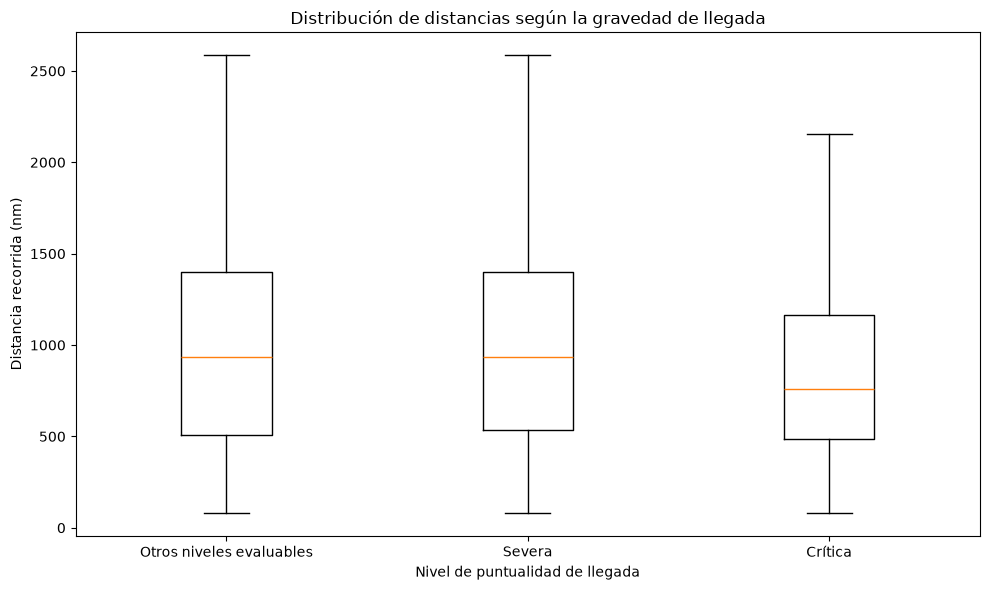


5. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS SEGÚN DISTANCIA
Se compara el porcentaje de llegadas severas y críticas
en los grupos de distancia corta, media y larga.


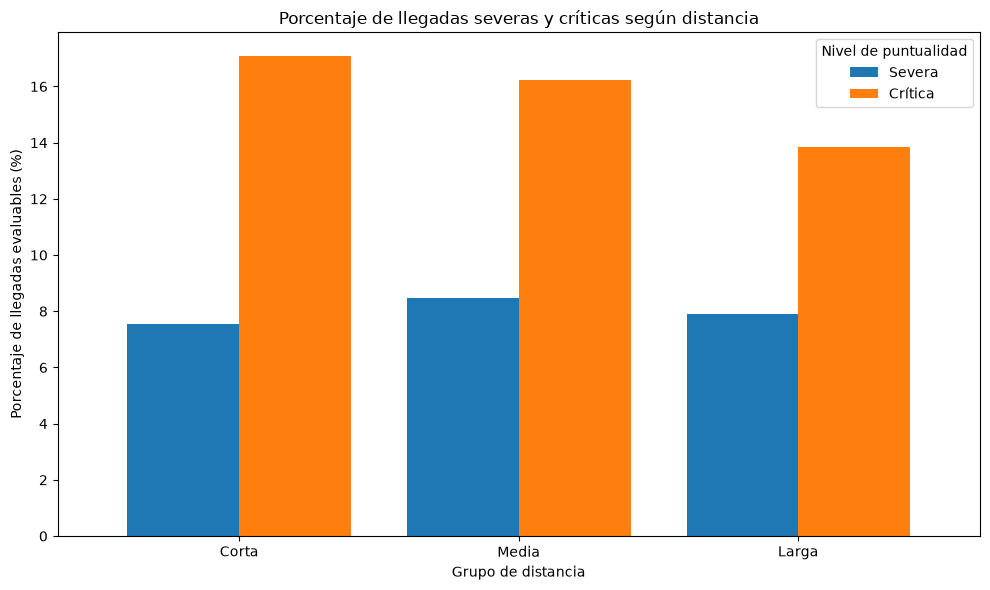


6. PUNTUALIDAD SEGÚN LA DURACIÓN DEL VUELO
Se comparan las llegadas severas y críticas por grupo de duración.
Los porcentajes se calculan sobre las llegadas evaluables.

Resumen por duración:
grupo_duracion  vuelos_operados  duracion_mediana_min  llegadas_evaluables  llegadas_severas  llegadas_criticas  llegadas_severas_criticas  pct_llegadas_severas  pct_llegadas_criticas  pct_llegadas_severas_criticas
         Corta           110627                  63.0               110627              7975              18222                      26197                  7.21                  16.47                          23.68
         Media           107797                 130.0               107797              8286              16745                      25031                  7.69                  15.53                          23.22
         Larga           108922                 251.0               108922              9870              16532                      26402                  9.06  

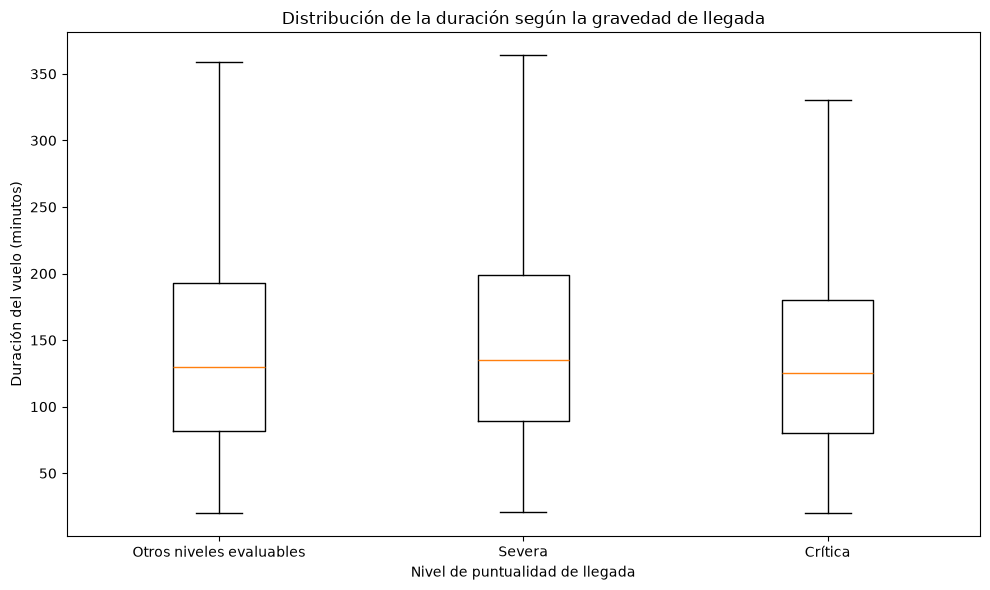


8. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS SEGÚN DURACIÓN
Se compara el porcentaje de llegadas severas y críticas
entre vuelos de corta, media y larga duración.


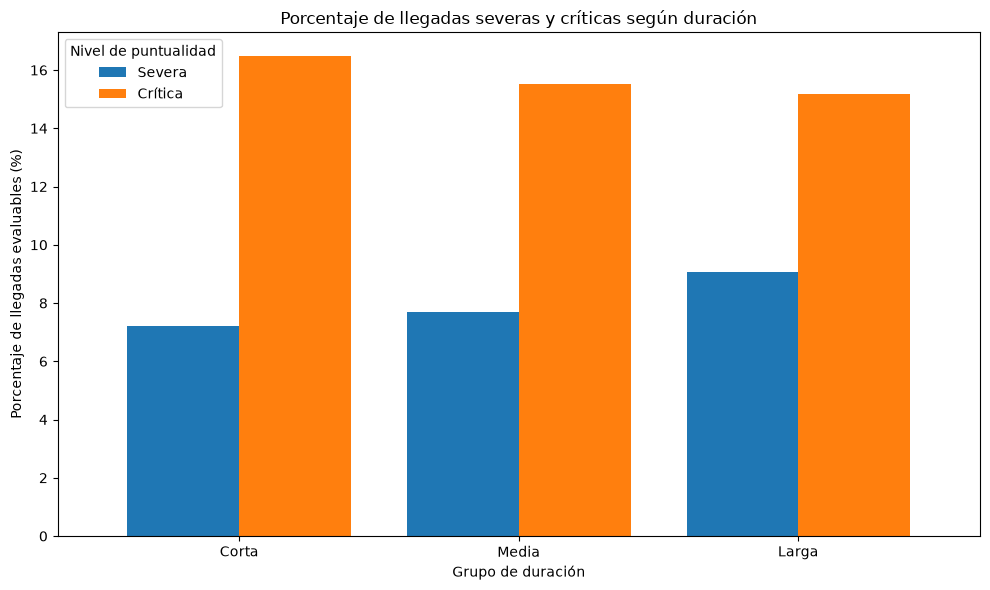


9. ANÁLISIS POR RUTA
Se agrupan los vuelos por ruta para comparar la distancia y duración
medianas con el porcentaje de llegadas severas y críticas.
Se exigirán al menos 30 llegadas evaluables por ruta.

Rutas con mayor porcentaje de llegadas severas/críticas:
   ruta  vuelos_evaluables  distancia_mediana_nm  duracion_mediana_min  llegadas_severas  llegadas_criticas  pct_llegadas_severas_criticas
EWR-CAE                 94                 602.0                  90.0                13                 47                          63.83
EWR-OKC                315                1325.0                 190.0                37                121                          50.16
EWR-TYS                313                 631.0                  96.0                25                129                          49.20
EWR-TUL                294                1215.0                 176.0                30                111                          47.96
EWR-RIC               1615                 

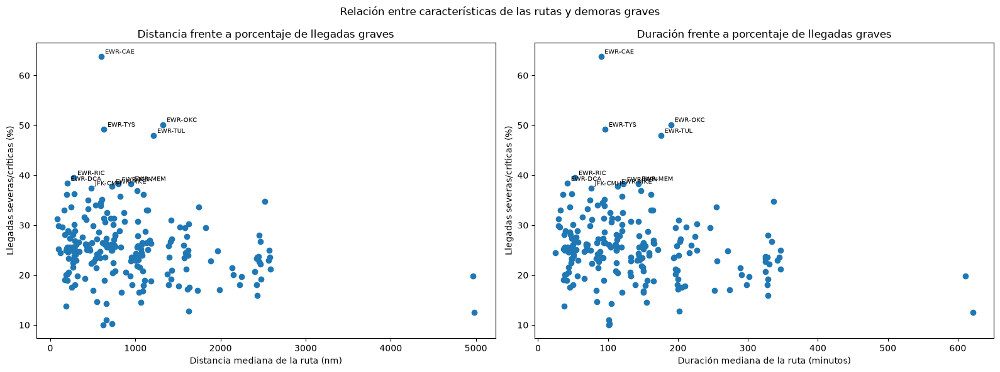


11. CORRELACIÓN DESCRIPTIVA CON LAS LLEGADAS SEVERAS/CRÍTICAS
Calculamos la correlación de Spearman entre distancia o duración
y el indicador de llegada severa/crítica.
Este valor resume una asociación monotónica, no una relación causal.
                    variable  vuelos_evaluables  correlacion_spearman
              Distancia (nm)             327346               -0.0248
Duración del vuelo (minutos)             327346                0.0027


In [83]:
# ============================================================
# 4.4. RELACIÓN ENTRE DISTANCIA, DURACIÓN DEL VUELO Y DEMORAS
# ============================================================

print("=" * 80)
print("4.4 | DISTANCIA, DURACIÓN Y DEMORAS SEVERAS/CRÍTICAS")
print("=" * 80)

MIN_EVALUABLES = 30

# Orden de los niveles de puntualidad para los gráficos.
orden_gravedad = [
    "Otros niveles evaluables",
    "Severa",
    "Crítica"
]


# ------------------------------------------------------------
# 1. Preparar los datos
# ------------------------------------------------------------

print("\n1. PREPARACIÓN DE LOS DATOS")
print("Se consideran vuelos operados con distancia y duración disponibles.")
print("La prioridad son las llegadas severas y críticas.")

base = df.loc[df["estado_vuelo"].eq("operado")].copy()

# Identificar llegadas evaluables.
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].notna()
    & base["nivel_puntualidad_arribo"].ne("desconocido")
).astype("int8")

# Identificar por separado los niveles severo y crítico.
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"].eq("severo")
).astype("int8")

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"].eq("critico")
).astype("int8")

base["_arribo_grave"] = (
    base["_arribo_severo"] + base["_arribo_critico"]
)

# Categoría general para comparar las distribuciones.
# "Otros niveles evaluables" no significa que todos sean puntuales:
# incluye adelantado, a tiempo, aceptable y moderado.
base["_grupo_gravedad_arribo"] = np.select(
    [
        base["_arribo_severo"].eq(1),
        base["_arribo_critico"].eq(1)
    ],
    [
        "Severa",
        "Crítica"
    ],
    default="Otros niveles evaluables"
)

base["_grupo_gravedad_arribo"] = pd.Categorical(
    base["_grupo_gravedad_arribo"],
    categories=orden_gravedad,
    ordered=True
)

print(f"Vuelos operados: {len(base):,}")
print(f"Vuelos con nivel de llegada evaluable: {base['_arribo_evaluable'].sum():,}")


# ------------------------------------------------------------
# 2. Función para clasificar variables en terciles
# ------------------------------------------------------------

def crear_grupos_terciles(serie, nombres_grupos):
    """
    Clasifica una variable numérica en hasta tres grupos
    mediante terciles de su distribución.

    Los grupos son relativos al dataset analizado.
    Si existen valores repetidos que impiden formar tres grupos,
    se utilizan las categorías que sean posibles.
    """

    valores = serie.dropna()

    if valores.empty:
        grupos = pd.Series(
            pd.Categorical(
                [None] * len(serie),
                categories=["Sin datos"],
                ordered=True
            ),
            index=serie.index
        )
        return grupos, ["Sin datos"], []

    if valores.nunique() == 1:
        etiquetas = ["Sin variación"]

        grupos = pd.Series(
            pd.Categorical(
                ["Sin variación" if pd.notna(v) else None for v in serie],
                categories=etiquetas,
                ordered=True
            ),
            index=serie.index
        )

        return grupos, etiquetas, [valores.iloc[0], valores.iloc[0]]

    # Obtener cortes mediante terciles.
    _, cortes = pd.qcut(
        valores,
        q=3,
        retbins=True,
        duplicates="drop"
    )

    cantidad_grupos = len(cortes) - 1

    # Seleccionar las etiquetas según la cantidad de grupos posibles.
    if cantidad_grupos == 3:
        etiquetas = nombres_grupos

    elif cantidad_grupos == 2:
        etiquetas = ["Menor", "Mayor"]

    else:
        etiquetas = [f"Grupo {i + 1}" for i in range(cantidad_grupos)]

    grupos = pd.cut(
        serie,
        bins=cortes,
        labels=etiquetas,
        include_lowest=True,
        ordered=True
    )

    return grupos, etiquetas, cortes


# ------------------------------------------------------------
# 3. Clasificar distancia y duración
# ------------------------------------------------------------

print("\n2. CLASIFICACIÓN DE DISTANCIA Y DURACIÓN")
print("Se forman grupos relativos mediante terciles.")
print("Los límites se calculan a partir de los valores observados.")

# Trabajamos por separado para no perder vuelos que tengan
# una de las dos variables disponible y la otra no.

base_distancia = base.loc[
    base["distancia_nm"].notna()
    & base["distancia_nm"].gt(0)
].copy()

base_duracion = base.loc[
    base["tiempo_vuelo_min"].notna()
    & base["tiempo_vuelo_min"].gt(0)
].copy()

# Clasificación de distancias.
(
    base_distancia["_grupo_distancia"],
    grupos_distancia,
    cortes_distancia
) = crear_grupos_terciles(
    base_distancia["distancia_nm"],
    ["Corta", "Media", "Larga"]
)

# Clasificación de duración.
(
    base_duracion["_grupo_duracion"],
    grupos_duracion,
    cortes_duracion
) = crear_grupos_terciles(
    base_duracion["tiempo_vuelo_min"],
    ["Corta", "Media", "Larga"]
)

print("\nRangos de distancia:")
for i, grupo in enumerate(grupos_distancia):
    if len(cortes_distancia) > 1:
        print(
            f"{grupo}: {cortes_distancia[i]:,.0f} a "
            f"{cortes_distancia[i + 1]:,.0f} nm"
        )
    else:
        print(f"{grupo}: {cortes_distancia[0]:,.0f} nm")

print("\nRangos de duración:")
for i, grupo in enumerate(grupos_duracion):
    if len(cortes_duracion) > 1:
        print(
            f"{grupo}: {cortes_duracion[i]:,.1f} a "
            f"{cortes_duracion[i + 1]:,.1f} minutos"
        )
    else:
        print(f"{grupo}: {cortes_duracion[0]:,.1f} minutos")


# ------------------------------------------------------------
# 4. Resumen de puntualidad según distancia
# ------------------------------------------------------------

print("\n3. PUNTUALIDAD SEGÚN LA DISTANCIA RECORRIDA")
print("Se comparan las llegadas severas y críticas por grupo de distancia.")
print("Los porcentajes utilizan únicamente las llegadas evaluables.")

resumen_distancia = (
    base_distancia.groupby(
        "_grupo_distancia",
        observed=True
    )
    .agg(
        vuelos_operados=("id", "size"),
        distancia_mediana_nm=("distancia_nm", "median"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
    .reindex(grupos_distancia)
    .rename_axis("grupo_distancia")
    .reset_index()
)

resumen_distancia["pct_llegadas_severas"] = (
    100
    * resumen_distancia["llegadas_severas"]
    / resumen_distancia["llegadas_evaluables"].replace(0, np.nan)
)

resumen_distancia["pct_llegadas_criticas"] = (
    100
    * resumen_distancia["llegadas_criticas"]
    / resumen_distancia["llegadas_evaluables"].replace(0, np.nan)
)

resumen_distancia["pct_llegadas_severas_criticas"] = (
    100
    * resumen_distancia["llegadas_severas_criticas"]
    / resumen_distancia["llegadas_evaluables"].replace(0, np.nan)
)

print("\nResumen por distancia:")
print(resumen_distancia.round(2).to_string(index=False))


# ------------------------------------------------------------
# 5. Gráfico: distancia según la gravedad de llegada
# ------------------------------------------------------------

print("\n4. GRÁFICO: DISTRIBUCIÓN DE DISTANCIAS SEGÚN LA PUNTUALIDAD")
print("Se compara la distribución de distancias de los vuelos")
print("sin nivel severo/crítico, con nivel severo y con nivel crítico.")
print("La línea central de cada caja representa la mediana.")

datos_boxplot_distancia = [
    base_distancia.loc[
        base_distancia["_grupo_gravedad_arribo"].eq(grupo)
        & base_distancia["_arribo_evaluable"].eq(1),
        "distancia_nm"
    ].dropna().to_numpy()
    for grupo in orden_gravedad
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    datos_boxplot_distancia,
    tick_labels=orden_gravedad,
    showfliers=False
)

ax.set_title("Distribución de distancias según la gravedad de llegada")
ax.set_xlabel("Nivel de puntualidad de llegada")
ax.set_ylabel("Distancia recorrida (nm)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Gráfico: porcentaje de demoras graves por distancia
# ------------------------------------------------------------

print("\n5. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS SEGÚN DISTANCIA")
print("Se compara el porcentaje de llegadas severas y críticas")
print("en los grupos de distancia corta, media y larga.")

grafico_distancia = (
    resumen_distancia
    .set_index("grupo_distancia")[
        [
            "pct_llegadas_severas",
            "pct_llegadas_criticas"
        ]
    ]
    .rename(
        columns={
            "pct_llegadas_severas": "Severa",
            "pct_llegadas_criticas": "Crítica"
        }
    )
)

grafico_distancia.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Porcentaje de llegadas severas y críticas según distancia")
plt.xlabel("Grupo de distancia")
plt.ylabel("Porcentaje de llegadas evaluables (%)")
plt.legend(title="Nivel de puntualidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Resumen de puntualidad según duración
# ------------------------------------------------------------

print("\n6. PUNTUALIDAD SEGÚN LA DURACIÓN DEL VUELO")
print("Se comparan las llegadas severas y críticas por grupo de duración.")
print("Los porcentajes se calculan sobre las llegadas evaluables.")

resumen_duracion = (
    base_duracion.groupby(
        "_grupo_duracion",
        observed=True
    )
    .agg(
        vuelos_operados=("id", "size"),
        duracion_mediana_min=("tiempo_vuelo_min", "median"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
    .reindex(grupos_duracion)
    .rename_axis("grupo_duracion")
    .reset_index()
)

resumen_duracion["pct_llegadas_severas"] = (
    100
    * resumen_duracion["llegadas_severas"]
    / resumen_duracion["llegadas_evaluables"].replace(0, np.nan)
)

resumen_duracion["pct_llegadas_criticas"] = (
    100
    * resumen_duracion["llegadas_criticas"]
    / resumen_duracion["llegadas_evaluables"].replace(0, np.nan)
)

resumen_duracion["pct_llegadas_severas_criticas"] = (
    100
    * resumen_duracion["llegadas_severas_criticas"]
    / resumen_duracion["llegadas_evaluables"].replace(0, np.nan)
)

print("\nResumen por duración:")
print(resumen_duracion.round(2).to_string(index=False))


# ------------------------------------------------------------
# 8. Gráfico: duración según gravedad de llegada
# ------------------------------------------------------------

print("\n7. GRÁFICO: DISTRIBUCIÓN DE DURACIÓN SEGÚN PUNTUALIDAD")
print("Se compara la duración de los vuelos según la gravedad de llegada.")
print("La línea central representa la mediana de cada grupo.")

datos_boxplot_duracion = [
    base_duracion.loc[
        base_duracion["_grupo_gravedad_arribo"].eq(grupo)
        & base_duracion["_arribo_evaluable"].eq(1),
        "tiempo_vuelo_min"
    ].dropna().to_numpy()
    for grupo in orden_gravedad
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    datos_boxplot_duracion,
    tick_labels=orden_gravedad,
    showfliers=False
)

ax.set_title("Distribución de la duración según la gravedad de llegada")
ax.set_xlabel("Nivel de puntualidad de llegada")
ax.set_ylabel("Duración del vuelo (minutos)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Gráfico: porcentaje de demoras graves por duración
# ------------------------------------------------------------

print("\n8. GRÁFICO: DEMORAS SEVERAS Y CRÍTICAS SEGÚN DURACIÓN")
print("Se compara el porcentaje de llegadas severas y críticas")
print("entre vuelos de corta, media y larga duración.")

grafico_duracion = (
    resumen_duracion
    .set_index("grupo_duracion")[
        [
            "pct_llegadas_severas",
            "pct_llegadas_criticas"
        ]
    ]
    .rename(
        columns={
            "pct_llegadas_severas": "Severa",
            "pct_llegadas_criticas": "Crítica"
        }
    )
)

grafico_duracion.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Porcentaje de llegadas severas y críticas según duración")
plt.xlabel("Grupo de duración")
plt.ylabel("Porcentaje de llegadas evaluables (%)")
plt.legend(title="Nivel de puntualidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Relación entre distancia, duración y demoras por ruta
# ------------------------------------------------------------

print("\n9. ANÁLISIS POR RUTA")
print("Se agrupan los vuelos por ruta para comparar la distancia y duración")
print("medianas con el porcentaje de llegadas severas y críticas.")
print(f"Se exigirán al menos {MIN_EVALUABLES} llegadas evaluables por ruta.")

base_rutas = base.loc[
    base["ruta"].notna()
    & base["distancia_nm"].notna()
    & base["tiempo_vuelo_min"].notna()
    & base["_arribo_evaluable"].eq(1)
].copy()

resumen_rutas = (
    base_rutas.groupby(
        ["ruta", "origen", "destino"],
        as_index=False
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        distancia_mediana_nm=("distancia_nm", "median"),
        duracion_mediana_min=("tiempo_vuelo_min", "median"),

        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_severas_criticas=("_arribo_grave", "sum")
    )
)

resumen_rutas["pct_llegadas_severas_criticas"] = (
    100
    * resumen_rutas["llegadas_severas_criticas"]
    / resumen_rutas["vuelos_evaluables"]
)

rutas_evaluables = resumen_rutas.loc[
    resumen_rutas["vuelos_evaluables"] >= MIN_EVALUABLES
].copy()

# Tabla de las rutas con mayor porcentaje severo/crítico.
tabla_rutas = (
    rutas_evaluables
    .sort_values(
        "pct_llegadas_severas_criticas",
        ascending=False
    )
    .head(20)
    .copy()
)

tabla_rutas["pct_llegadas_severas_criticas"] = (
    tabla_rutas["pct_llegadas_severas_criticas"].round(2)
)

print("\nRutas con mayor porcentaje de llegadas severas/críticas:")
print(
    tabla_rutas[
        [
            "ruta",
            "vuelos_evaluables",
            "distancia_mediana_nm",
            "duracion_mediana_min",
            "llegadas_severas",
            "llegadas_criticas",
            "pct_llegadas_severas_criticas"
        ]
    ].round(2).to_string(index=False)
)


# ------------------------------------------------------------
# 11. Gráfico: distancia y duración frente a demoras graves por ruta
# ------------------------------------------------------------

print("\n10. GRÁFICOS: DISTANCIA Y DURACIÓN FRENTE A DEMORAS GRAVES POR RUTA")
print("Cada punto representa una ruta con suficientes llegadas evaluables.")
print("Se compara la distancia y duración medianas de la ruta")
print("con su porcentaje de llegadas severas y críticas.")
print("Se identifican las diez rutas con mayor porcentaje de demoras graves.")

rutas_destacadas = rutas_evaluables.nlargest(
    10,
    "pct_llegadas_severas_criticas"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distancia frente a porcentaje de demoras graves.
axes[0].scatter(
    rutas_evaluables["distancia_mediana_nm"],
    rutas_evaluables["pct_llegadas_severas_criticas"]
)

for _, fila in rutas_destacadas.iterrows():
    axes[0].annotate(
        fila["ruta"],
        (
            fila["distancia_mediana_nm"],
            fila["pct_llegadas_severas_criticas"]
        ),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7
    )

axes[0].set_title("Distancia frente a porcentaje de llegadas graves")
axes[0].set_xlabel("Distancia mediana de la ruta (nm)")
axes[0].set_ylabel("Llegadas severas/críticas (%)")

# Duración frente a porcentaje de demoras graves.
axes[1].scatter(
    rutas_evaluables["duracion_mediana_min"],
    rutas_evaluables["pct_llegadas_severas_criticas"]
)

for _, fila in rutas_destacadas.iterrows():
    axes[1].annotate(
        fila["ruta"],
        (
            fila["duracion_mediana_min"],
            fila["pct_llegadas_severas_criticas"]
        ),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=7
    )

axes[1].set_title("Duración frente a porcentaje de llegadas graves")
axes[1].set_xlabel("Duración mediana de la ruta (minutos)")
axes[1].set_ylabel("Llegadas severas/críticas (%)")

fig.suptitle(
    "Relación entre características de las rutas y demoras graves"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Correlación descriptiva entre variables y llegadas graves
# ------------------------------------------------------------

print("\n11. CORRELACIÓN DESCRIPTIVA CON LAS LLEGADAS SEVERAS/CRÍTICAS")
print("Calculamos la correlación de Spearman entre distancia o duración")
print("y el indicador de llegada severa/crítica.")
print("Este valor resume una asociación monotónica, no una relación causal.")

resultados_correlacion = []

for variable, nombre in [
    ("distancia_nm", "Distancia (nm)"),
    ("tiempo_vuelo_min", "Duración del vuelo (minutos)")
]:

    datos = base.loc[
        base["_arribo_evaluable"].eq(1)
        & base[variable].notna()
        & base[variable].gt(0)
    ].copy()

    correlacion = datos[variable].corr(
        datos["_arribo_grave"],
        method="spearman"
    )

    resultados_correlacion.append({
        "variable": nombre,
        "vuelos_evaluables": len(datos),
        "correlacion_spearman": correlacion
    })

tabla_correlacion = pd.DataFrame(resultados_correlacion)

tabla_correlacion["correlacion_spearman"] = (
    tabla_correlacion["correlacion_spearman"].round(4)
)

print(tabla_correlacion.to_string(index=False))

###
---
---
---

### 5. Análisis por horario del vuelo

El horario de salida puede estar relacionado con el comportamiento de las demoras. A lo largo del día, los vuelos podrían presentar diferentes niveles de puntualidad debido a factores operativos y a posibles retrasos acumulados durante la jornada.

El objetivo de este análisis es identificar si existen horarios con mayor proporción de llegadas severas o críticas y explorar si la puntualidad empeora a medida que avanza el día.

Para ello, utilizaremos principalmente la hora de salida programada (`fecha_hora_salida_programada`) y los niveles de puntualidad de salida y llegada.

Cantidad de vuelos y llegadas severas/críticas según la franja horaria.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.


,vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
_franja_horaria,,,,,,,,
Madrugada,1944,1940,105,88,193,5.41,4.54,9.95
Mañana,126998,126646,8240,10353,18593,6.51,8.17,14.68
Tarde,169343,168596,14984,33296,48280,8.89,19.75,28.64
Noche,30236,30164,2802,7762,10564,9.29,25.73,35.02


Gráfico 1: volumen de vuelos operados según la franja horaria.
Permite observar en qué momentos del día se concentra la actividad.


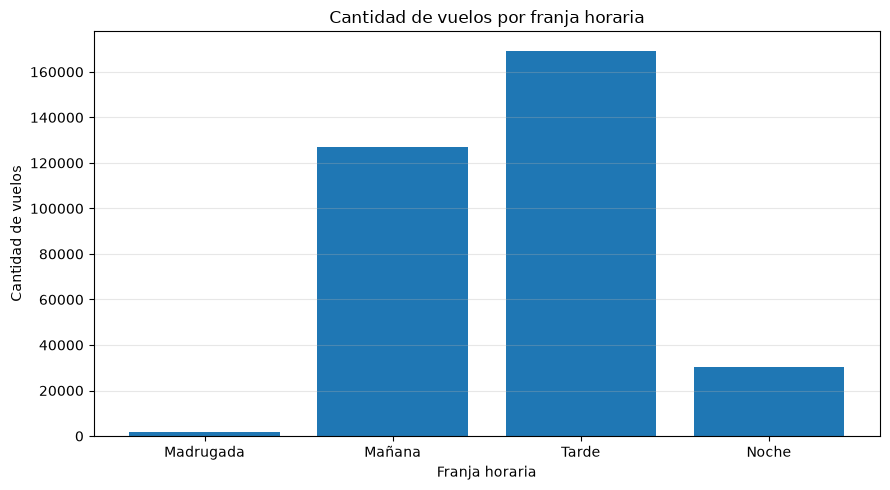

Gráfico 2: porcentaje de llegadas severas y críticas por franja horaria.
Permite comparar la proporción de vuelos con demoras graves, independientemente del volumen de vuelos.


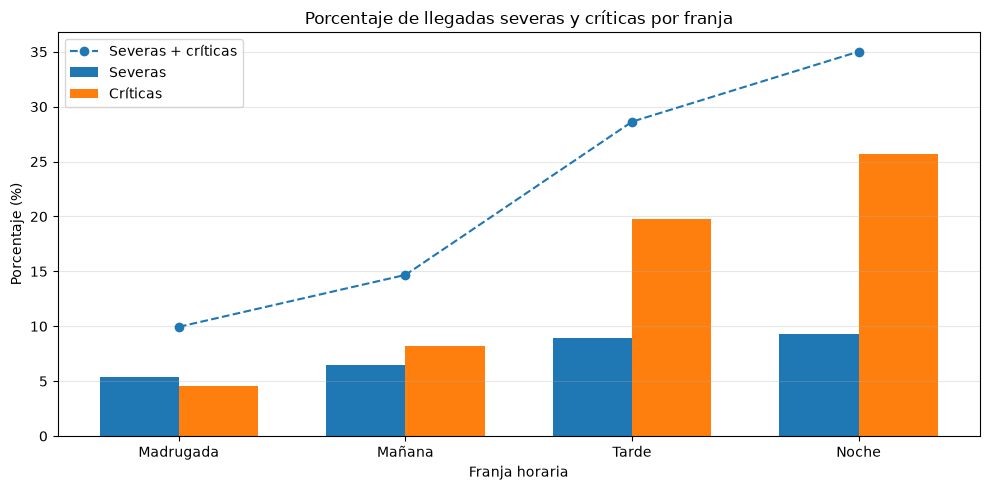

Resumen horario: cantidad de vuelos, demoras medianas y porcentaje de llegadas severas/críticas.
La mediana permite observar el comportamiento típico sin que los valores extremos influyan tanto como en el promedio.


,vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves
_hora_programada,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN
5,1944.0,1940.0,105.0,88.0,193.0,-3.0,-8.0,5.41,4.54,9.95
6,25526.0,25447.0,1474.0,1398.0,2872.0,-3.0,-8.0,5.79,5.49,11.29
7,22532.0,22475.0,1235.0,1326.0,2561.0,-3.0,-10.0,5.49,5.90,11.39
8,26800.0,26734.0,1827.0,2376.0,4203.0,-3.0,-8.0,6.83,8.89,15.72


Gráfico 3: evolución del porcentaje de llegadas severas y críticas durante el día.
Una tendencia creciente podría indicar que los vuelos programados más tarde presentan mayor proporción de demoras graves.


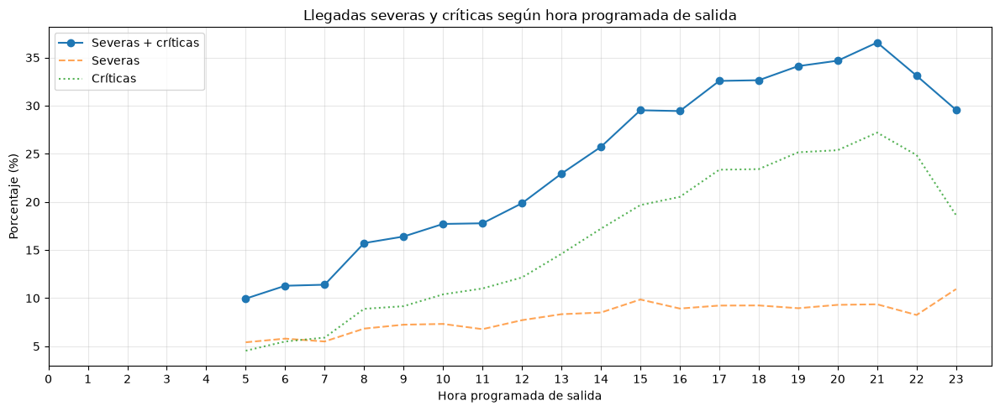

Gráfico 4: mediana de demora de salida y llegada según la hora programada.
Permite observar si las demoras típicas aumentan a medida que avanza el día.


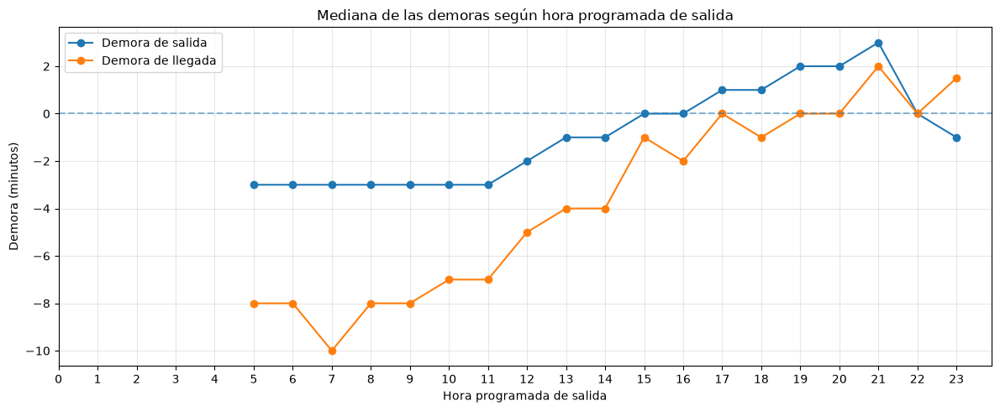

Relación entre la puntualidad de salida y la puntualidad de llegada.
Cada fila representa una categoría de salida y muestra cómo se distribuyen las llegadas de esos mismos vuelos, en porcentajes.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico
nivel_puntualidad_salida,,,,,,
adelantado,78.82,1.72,5.59,8.57,3.65,1.66
a tiempo,67.21,2.11,7.82,13.15,6.52,3.19
aceptable,62.18,2.41,8.40,15.21,7.89,3.91
moderado,43.71,2.74,10.23,22.01,13.91,7.40
severo,15.60,1.63,7.59,25.87,28.62,20.69
critico,0.83,0.13,0.70,3.67,11.39,83.29


Gráfico 5: mapa de calor de la relación entre puntualidad de salida y llegada.
Los valores más altos muestran qué categorías de llegada son más frecuentes para cada categoría de salida.


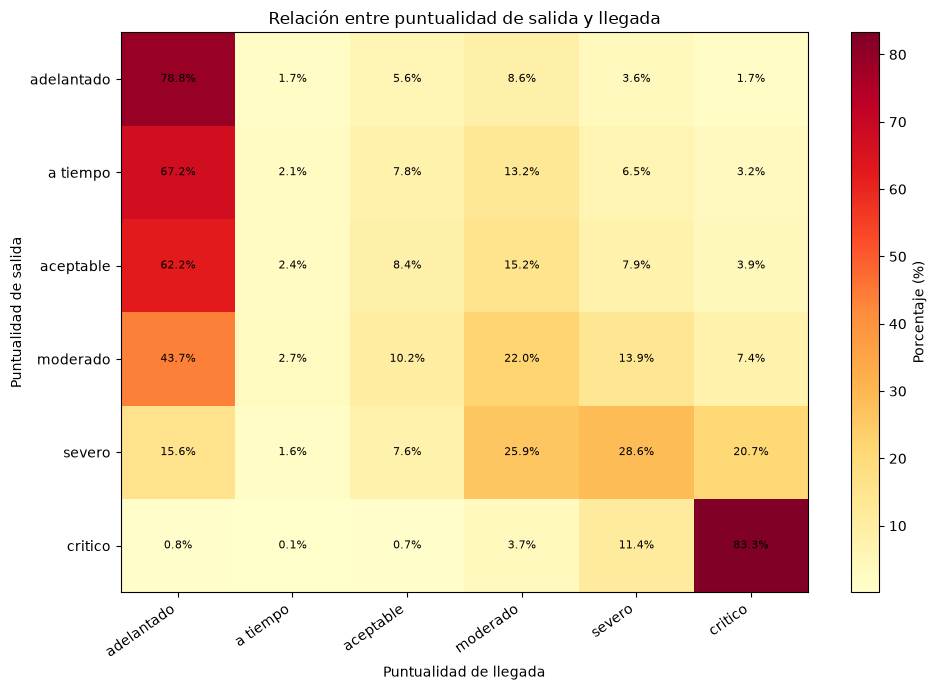

Porcentaje de llegadas severas y críticas según el nivel de puntualidad de salida.
Se consideran únicamente vuelos con salida y llegada evaluables.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
nivel_puntualidad_salida,,,,,
adelantado,183135,6677,3041,9718,5.31
a tiempo,16466,1073,526,1599,9.71
aceptable,24465,1931,957,2888,11.80
moderado,32992,4588,2443,7031,21.31
severo,22383,6406,4632,11038,49.31
critico,47905,5456,39900,45356,94.68


Gráfico 6: porcentaje de llegadas severas y críticas según la puntualidad de salida.
Permite observar si las salidas con mayor demora están asociadas con más llegadas graves.


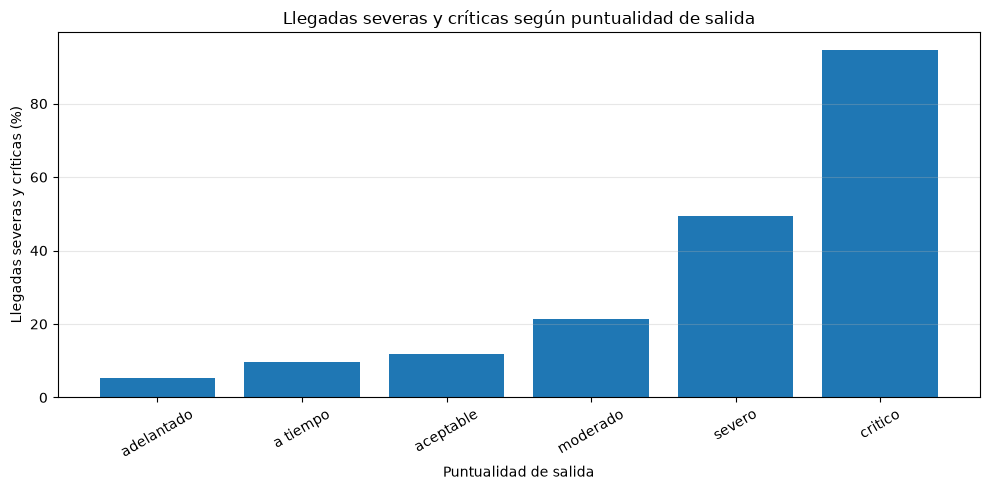

In [84]:
# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["fecha_hora_salida_programada"].notna())
].copy()

# Hora programada de salida
base["_hora_programada"] = (
    base["fecha_hora_salida_programada"].dt.hour
)

# Franjas horarias
orden_franjas = ["Madrugada", "Mañana", "Tarde", "Noche"]

base["_franja_horaria"] = pd.cut(
    base["_hora_programada"],
    bins=[0, 6, 12, 20, 24],
    labels=orden_franjas,
    right=False
)

# Categorías de puntualidad que se pueden evaluar
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# Indicadores temporales de puntualidad de llegada y salida
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] | base["_arribo_critico"]
)

base["_salida_evaluable"] = (
    base["nivel_puntualidad_salida"].isin(niveles_evaluables)
)

# Demoras numéricas para calcular medianas
base["_demora_salida_num"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["_demora_arribo_num"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)


# ==========================================================
# 5.1. PUNTUALIDAD POR FRANJA HORARIA
# ==========================================================

resumen_franjas = (
    base.groupby("_franja_horaria", observed=False)
    .agg(
        vuelos=("_hora_programada", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_franjas)
)

resumen_franjas["pct_severas"] = (
    resumen_franjas["llegadas_severas"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

resumen_franjas["pct_criticas"] = (
    resumen_franjas["llegadas_criticas"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

resumen_franjas["pct_graves"] = (
    resumen_franjas["llegadas_graves"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

print("Cantidad de vuelos y llegadas severas/críticas según la franja horaria.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.")

display(resumen_franjas.round(2))


# Gráfico 1: cantidad de vuelos por franja

print("Gráfico 1: volumen de vuelos operados según la franja horaria.")
print("Permite observar en qué momentos del día se concentra la actividad.")

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    resumen_franjas.index.astype(str),
    resumen_franjas["vuelos"]
)

ax.set_title("Cantidad de vuelos por franja horaria")
ax.set_xlabel("Franja horaria")
ax.set_ylabel("Cantidad de vuelos")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Gráfico 2: porcentaje de llegadas severas y críticas

print("Gráfico 2: porcentaje de llegadas severas y críticas por franja horaria.")
print("Permite comparar la proporción de vuelos con demoras graves, independientemente del volumen de vuelos.")

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(orden_franjas))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_franjas["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_franjas["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_franjas["pct_graves"],
    marker="o",
    linestyle="--",
    label="Severas + críticas"
)

ax.set_xticks(x, labels=orden_franjas)
ax.set_title("Porcentaje de llegadas severas y críticas por franja")
ax.set_xlabel("Franja horaria")
ax.set_ylabel("Porcentaje (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5.2. EVOLUCIÓN DE LAS DEMORAS POR HORA
# ==========================================================

resumen_horas = (
    base.groupby("_hora_programada")
    .agg(
        vuelos=("_hora_programada", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_salida=("_demora_salida_num", "median"),
        mediana_demora_arribo=("_demora_arribo_num", "median")
    )
    .reindex(range(24))
)

resumen_horas["pct_severas"] = (
    resumen_horas["llegadas_severas"] /
    resumen_horas["llegadas_evaluables"] * 100
)

resumen_horas["pct_criticas"] = (
    resumen_horas["llegadas_criticas"] /
    resumen_horas["llegadas_evaluables"] * 100
)

resumen_horas["pct_graves"] = (
    resumen_horas["llegadas_graves"] /
    resumen_horas["llegadas_evaluables"] * 100
)

print("Resumen horario: cantidad de vuelos, demoras medianas y porcentaje de llegadas severas/críticas.")
print("La mediana permite observar el comportamiento típico sin que los valores extremos influyan tanto como en el promedio.")

display(resumen_horas.round(2))


# Gráfico 3: porcentaje de llegadas graves por hora

print("Gráfico 3: evolución del porcentaje de llegadas severas y críticas durante el día.")
print("Una tendencia creciente podría indicar que los vuelos programados más tarde presentan mayor proporción de demoras graves.")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_graves"],
    marker="o",
    label="Severas + críticas"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_severas"],
    linestyle="--",
    alpha=0.7,
    label="Severas"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_criticas"],
    linestyle=":",
    alpha=0.8,
    label="Críticas"
)

ax.set_title("Llegadas severas y críticas según hora programada de salida")
ax.set_xlabel("Hora programada de salida")
ax.set_ylabel("Porcentaje (%)")
ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Gráfico 4: mediana de demora por hora

print("Gráfico 4: mediana de demora de salida y llegada según la hora programada.")
print("Permite observar si las demoras típicas aumentan a medida que avanza el día.")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    resumen_horas.index,
    resumen_horas["mediana_demora_salida"],
    marker="o",
    label="Demora de salida"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["mediana_demora_arribo"],
    marker="o",
    label="Demora de llegada"
)

ax.axhline(0, linestyle="--", alpha=0.5)

ax.set_title("Mediana de las demoras según hora programada de salida")
ax.set_xlabel("Hora programada de salida")
ax.set_ylabel("Demora (minutos)")
ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5.3. RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
# ==========================================================

# Tomamos únicamente vuelos con puntualidad evaluable
# tanto en la salida como en la llegada.

comparables = base.loc[
    base["_salida_evaluable"] &
    base["_arribo_evaluable"]
].copy()

# Tabla de relación entre categorías de salida y llegada
tabla_relacion = pd.crosstab(
    comparables["nivel_puntualidad_salida"],
    comparables["nivel_puntualidad_arribo"],
    normalize="index"
) * 100

tabla_relacion = tabla_relacion.reindex(
    index=orden_niveles,
    columns=orden_niveles
).fillna(0)

print("Relación entre la puntualidad de salida y la puntualidad de llegada.")
print("Cada fila representa una categoría de salida y muestra cómo se distribuyen las llegadas de esos mismos vuelos, en porcentajes.")

display(tabla_relacion.round(2))


# Gráfico 5: mapa de calor de salida y llegada

print("Gráfico 5: mapa de calor de la relación entre puntualidad de salida y llegada.")
print("Los valores más altos muestran qué categorías de llegada son más frecuentes para cada categoría de salida.")

fig, ax = plt.subplots(figsize=(10, 7))

imagen = ax.imshow(
    tabla_relacion.values,
    cmap="YlOrRd",
    aspect="auto"
)

ax.set_xticks(range(len(orden_niveles)))
ax.set_xticklabels(orden_niveles, rotation=35, ha="right")

ax.set_yticks(range(len(orden_niveles)))
ax.set_yticklabels(orden_niveles)

ax.set_title("Relación entre puntualidad de salida y llegada")
ax.set_xlabel("Puntualidad de llegada")
ax.set_ylabel("Puntualidad de salida")

for i in range(len(orden_niveles)):
    for j in range(len(orden_niveles)):
        ax.text(
            j,
            i,
            f"{tabla_relacion.iloc[i, j]:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(imagen, ax=ax, label="Porcentaje (%)")

plt.tight_layout()
plt.show()


# Resumen: llegadas graves según puntualidad de salida

resumen_salida = (
    comparables.groupby("nivel_puntualidad_salida")
    .agg(
        vuelos=("_hora_programada", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_niveles)
)

resumen_salida["pct_graves"] = (
    resumen_salida["llegadas_graves"] /
    resumen_salida["vuelos"] * 100
)

print("Porcentaje de llegadas severas y críticas según el nivel de puntualidad de salida.")
print("Se consideran únicamente vuelos con salida y llegada evaluables.")

display(resumen_salida.round(2))


# Gráfico 6: llegadas graves según puntualidad de salida

print("Gráfico 6: porcentaje de llegadas severas y críticas según la puntualidad de salida.")
print("Permite observar si las salidas con mayor demora están asociadas con más llegadas graves.")

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    resumen_salida.index.astype(str),
    resumen_salida["pct_graves"]
)

ax.set_title("Llegadas severas y críticas según puntualidad de salida")
ax.set_xlabel("Puntualidad de salida")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 5.1. Puntualidad según la franja horaria

Agrupar los vuelos según su horario de salida programado:

- **Madrugada:** 00:00 a 05:59.
- **Mañana:** 06:00 a 11:59.
- **Tarde:** 12:00 a 19:59.
- **Noche:** 20:00 a 23:59.

Analizar:

- ¿Los vuelos de la mañana presentan menos llegadas severas y críticas?
- ¿Qué franja horaria concentra la mayor proporción de demoras graves?
- ¿Existen diferencias importantes entre las franjas horarias?

Distribución general de los niveles de puntualidad de llegada por franja horaria.
Se incluyen todas las categorías, también 'desconocido', para mostrar la distribución completa.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_franja,,,,,,,
Madrugada,1327,50,140,230,105,88,4
Mañana,83924,2322,7862,13945,8240,10353,352
Tarde,89235,2622,9390,19069,14984,33296,747
Noche,14447,415,1590,3148,2802,7762,72


Distribución porcentual de los niveles de puntualidad por franja horaria.
Cada fila suma aproximadamente 100% y permite comparar las franjas independientemente de su volumen de vuelos.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_franja,,,,,,,
Madrugada,68.26,2.57,7.20,11.83,5.40,4.53,0.21
Mañana,66.08,1.83,6.19,10.98,6.49,8.15,0.28
Tarde,52.69,1.55,5.54,11.26,8.85,19.66,0.44
Noche,47.78,1.37,5.26,10.41,9.27,25.67,0.24


Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada según la franja horaria.
Permite observar cómo se distribuyen las categorías en cada franja, incluyendo los casos desconocidos.


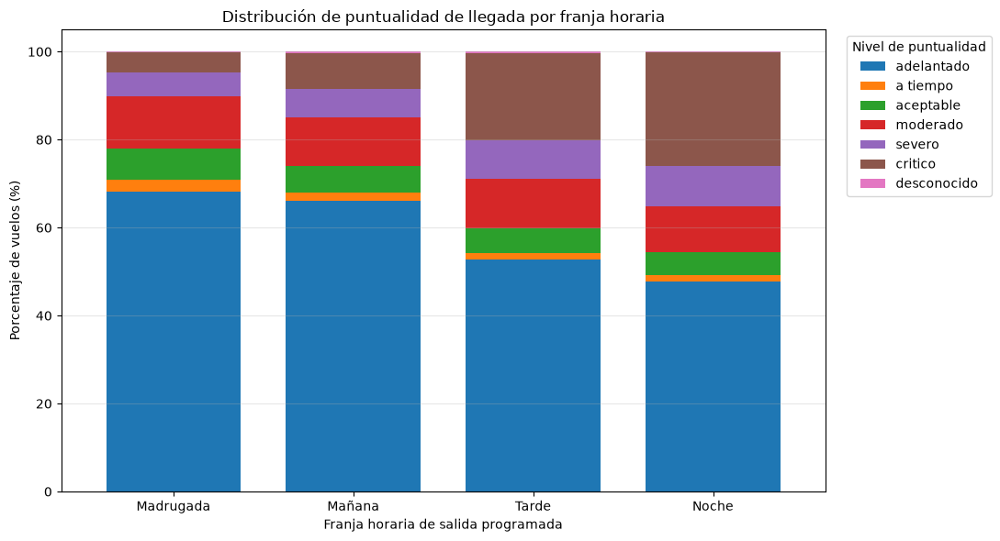

Resumen de llegadas severas y críticas por franja horaria.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo la categoría 'desconocido'.


,vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
_franja,,,,,,,,
Madrugada,1944,1940,105,88,193,5.41,4.54,9.95
Mañana,126998,126646,8240,10353,18593,6.51,8.17,14.68
Tarde,169343,168596,14984,33296,48280,8.89,19.75,28.64
Noche,30236,30164,2802,7762,10564,9.29,25.73,35.02


Gráfico 2: comparación del porcentaje de llegadas severas, críticas y su combinación por franja horaria.
La línea representa el porcentaje conjunto de llegadas severas y críticas, que será nuestro indicador principal.


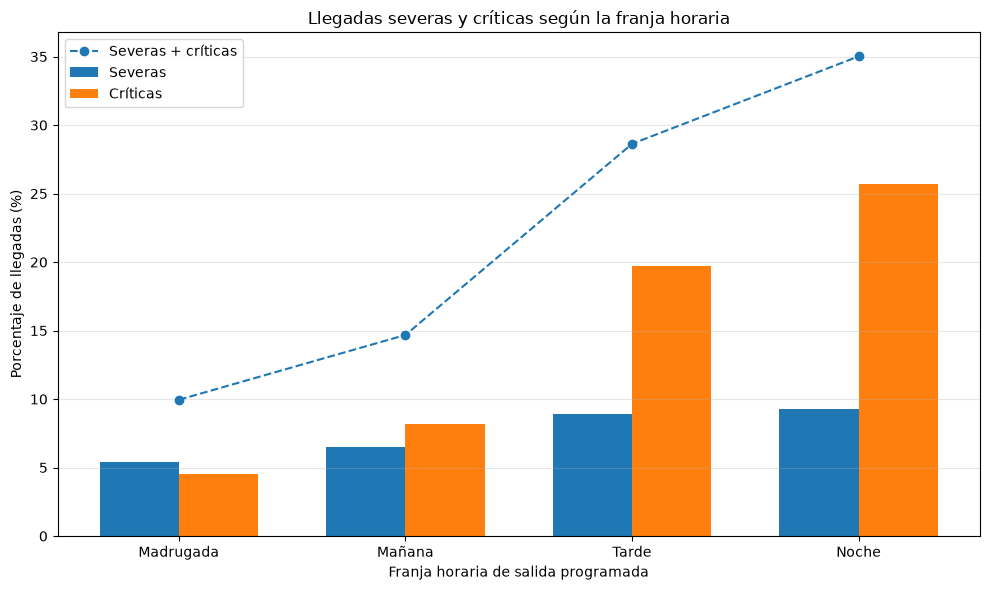

La franja con mayor porcentaje de llegadas severas y críticas es Noche, con 35.02%.
El porcentaje de llegadas severas y críticas durante la mañana es 14.68%.


In [85]:
# ==========================================================
# 5.1. PUNTUALIDAD SEGÚN LA FRANJA HORARIA
# ==========================================================

# Orden de las franjas horarias
orden_franjas = ["Madrugada", "Mañana", "Tarde", "Noche"]

# Orden de los niveles de puntualidad
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Categorías que se consideran evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# Trabajar únicamente con vuelos operados
# y utilizar una copia para no modificar df.

base = df.loc[
    df["estado_vuelo"] == "operado",
    [
        "periodo_salida_programado",
        "nivel_puntualidad_arribo"
    ]
].copy()

# Excluir registros sin franja horaria
base = base.dropna(subset=["periodo_salida_programado"])

# Establecer el orden de las franjas en esta copia
base["_franja"] = pd.Categorical(
    base["periodo_salida_programado"].astype(str),
    categories=orden_franjas,
    ordered=True
)

# Indicadores de puntualidad de llegada
base["_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_severa"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_critica"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_grave"] = base["_severa"] | base["_critica"]


# ==========================================================
# 1. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD POR FRANJA
# ==========================================================

# Cantidad de vuelos por nivel de puntualidad
tabla_niveles = pd.crosstab(
    base["_franja"],
    base["nivel_puntualidad_arribo"]
)

tabla_niveles = tabla_niveles.reindex(
    index=orden_franjas,
    columns=orden_niveles,
    fill_value=0
)

# Porcentaje de cada nivel sobre el total de vuelos de su franja
tabla_pct_niveles = (
    tabla_niveles
    .div(tabla_niveles.sum(axis=1), axis=0) * 100
)

print("Distribución general de los niveles de puntualidad de llegada por franja horaria.")
print("Se incluyen todas las categorías, también 'desconocido', para mostrar la distribución completa.")

display(tabla_niveles)

print("Distribución porcentual de los niveles de puntualidad por franja horaria.")
print("Cada fila suma aproximadamente 100% y permite comparar las franjas independientemente de su volumen de vuelos.")

display(tabla_pct_niveles.round(2))


# Gráfico 1: distribución porcentual de todos los niveles

print("Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada según la franja horaria.")
print("Permite observar cómo se distribuyen las categorías en cada franja, incluyendo los casos desconocidos.")

ax = tabla_pct_niveles.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Distribución de puntualidad de llegada por franja horaria")
ax.set_xlabel("Franja horaria de salida programada")
ax.set_ylabel("Porcentaje de vuelos (%)")
ax.set_xticklabels(orden_franjas, rotation=0)
ax.legend(
    title="Nivel de puntualidad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 2. ANÁLISIS DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

resumen_franjas = (
    base.groupby("_franja", observed=False)
    .agg(
        vuelos=("nivel_puntualidad_arribo", "size"),
        llegadas_evaluables=("_evaluable", "sum"),
        llegadas_severas=("_severa", "sum"),
        llegadas_criticas=("_critica", "sum"),
        llegadas_graves=("_grave", "sum")
    )
    .reindex(orden_franjas)
)

# Porcentajes sobre las llegadas evaluables
resumen_franjas["pct_severas"] = (
    resumen_franjas["llegadas_severas"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

resumen_franjas["pct_criticas"] = (
    resumen_franjas["llegadas_criticas"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

resumen_franjas["pct_graves"] = (
    resumen_franjas["llegadas_graves"] /
    resumen_franjas["llegadas_evaluables"] * 100
)

print("Resumen de llegadas severas y críticas por franja horaria.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo la categoría 'desconocido'.")

display(resumen_franjas.round(2))


# Gráfico 2: porcentajes de llegadas severas y críticas

print("Gráfico 2: comparación del porcentaje de llegadas severas, críticas y su combinación por franja horaria.")
print("La línea representa el porcentaje conjunto de llegadas severas y críticas, que será nuestro indicador principal.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_franjas))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_franjas["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_franjas["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_franjas["pct_graves"],
    marker="o",
    linestyle="--",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_franjas)

ax.set_title("Llegadas severas y críticas según la franja horaria")
ax.set_xlabel("Franja horaria de salida programada")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. IDENTIFICAR LA FRANJA CON MAYOR PORCENTAJE DE DEMORAS GRAVES
# ==========================================================

franja_mayor = resumen_franjas["pct_graves"].idxmax()
porcentaje_mayor = resumen_franjas.loc[franja_mayor, "pct_graves"]

print(
    f"La franja con mayor porcentaje de llegadas severas y críticas "
    f"es {franja_mayor}, con {porcentaje_mayor:.2f}%."
)

# Comparación específica de la mañana frente a las demás franjas
porcentaje_manana = resumen_franjas.loc["Mañana", "pct_graves"]

print(
    f"El porcentaje de llegadas severas y críticas durante la mañana "
    f"es {porcentaje_manana:.2f}%."
)


#### 5.2. Evolución de las demoras durante el día

Analizar el comportamiento de las demoras según cada hora de salida programada.

Preguntas que podemos investigar:

- ¿Las demoras aumentan a medida que avanza el día?
- ¿Existen horarios específicos con mayor porcentaje de llegadas severas y críticas?
- ¿La mediana de demora de salida y llegada también aumenta durante la jornada?
- ¿Los horarios con mayor volumen de vuelos presentan también más demoras graves?

Resumen de vuelos y demoras según la hora programada de salida.
Los porcentajes de llegadas graves se calculan sobre las llegadas evaluables.
Las medianas utilizan los registros que tienen una demora numérica disponible.


,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida,cantidad_demoras_salida,mediana_demora_arribo,cantidad_demoras_arribo,pct_severas,pct_criticas,pct_graves,muestra_suficiente
hora_programada,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,<NA>,0,<NA>,0,NaN,NaN,NaN,False
1,0.0,0.0,0.0,0.0,0.0,<NA>,0,<NA>,0,NaN,NaN,NaN,False
2,0.0,0.0,0.0,0.0,0.0,<NA>,0,<NA>,0,NaN,NaN,NaN,False
3,0.0,0.0,0.0,0.0,0.0,<NA>,0,<NA>,0,NaN,NaN,NaN,False
4,0.0,0.0,0.0,0.0,0.0,<NA>,0,<NA>,0,NaN,NaN,NaN,False
5,1944.0,1940.0,105.0,88.0,193.0,-3.0,1944,-8.0,1940,5.41,4.54,9.95,True
6,25526.0,25447.0,1474.0,1398.0,2872.0,-3.0,25526,-8.0,25447,5.79,5.49,11.29,True
7,22532.0,22475.0,1235.0,1326.0,2561.0,-3.0,22532,-10.0,22475,5.49,5.90,11.39,True
8,26800.0,26734.0,1827.0,2376.0,4203.0,-3.0,26800,-8.0,26734,6.83,8.89,15.72,True


Gráfico 1: evolución de las llegadas severas y críticas durante el día.
Permite identificar si el porcentaje de demoras graves aumenta a medida que avanza la hora programada de salida.


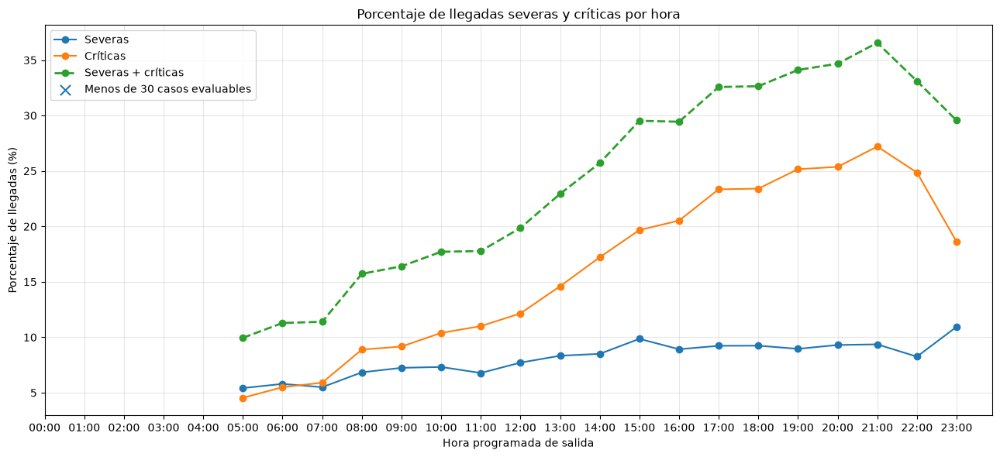

Gráfico 2: mediana de las demoras de salida y llegada por hora.
Permite observar si las demoras típicas aumentan durante la jornada.
Los valores negativos representan vuelos que salieron o llegaron adelantados respecto del horario previsto.


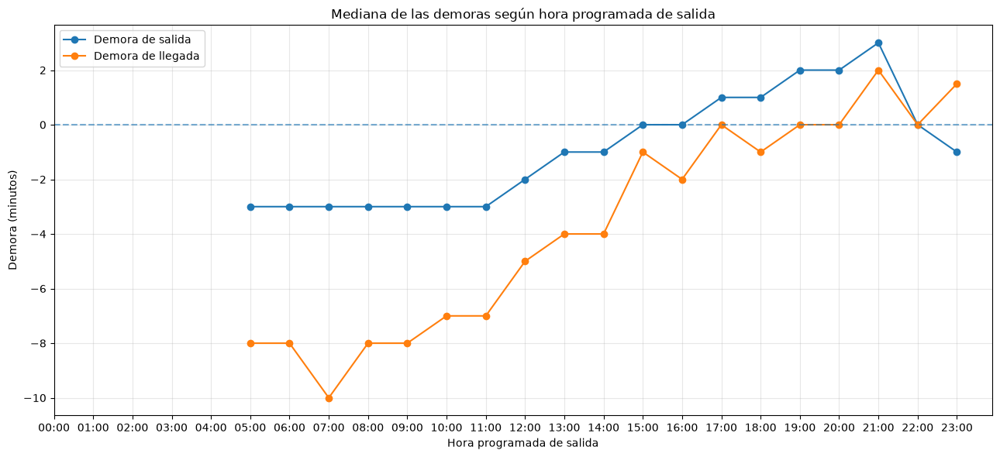

Gráfico 3: relación entre el volumen de vuelos y el porcentaje de llegadas severas y críticas.
Cada punto representa una hora del día.
Permite observar si las horas con más vuelos también presentan una mayor proporción de llegadas graves.


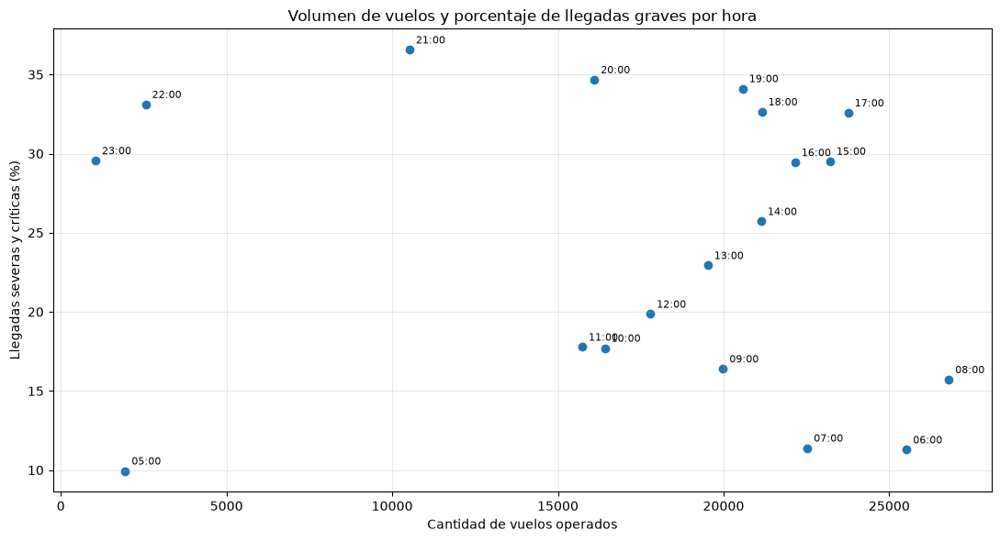

Las 5 horas con mayor porcentaje de llegadas severas y críticas (mínimo 30 casos evaluables).


,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
hora_programada,,,,,,
21,10524.0,10503.0,983.0,2857.0,3840.0,36.56
20,16103.0,16061.0,1494.0,4075.0,5569.0,34.67
19,20580.0,20507.0,1836.0,5159.0,6995.0,34.11
22,2561.0,2558.0,211.0,636.0,847.0,33.11
18,21157.0,21072.0,1947.0,4932.0,6879.0,32.65


Las 5 horas con mayor cantidad de vuelos operados.


,vuelos_operados,llegadas_evaluables,llegadas_graves,pct_graves
hora_programada,,,,
8,26800.0,26734.0,4203.0,15.72
6,25526.0,25447.0,2872.0,11.29
17,23766.0,23667.0,7709.0,32.57
15,23218.0,23082.0,6815.0,29.53
7,22532.0,22475.0,2561.0,11.39


In [86]:
# ==========================================================
# 5.2. EVOLUCIÓN DE LAS DEMORAS DURANTE EL DÍA
# ==========================================================

# Cantidad mínima de llegadas evaluables para comparar horarios
MIN_EVALUABLES = 30

# Categorías de llegada que se pueden evaluar
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# ----------------------------------------------------------
# 1. PREPARACIÓN DE LOS DATOS
# ----------------------------------------------------------

# Trabajar únicamente con vuelos operados
# y con fecha y hora de salida programada disponibles.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["fecha_hora_salida_programada"].notna())
].copy()

# Obtener la hora programada de salida (0 a 23)
base["_hora_programada"] = (
    base["fecha_hora_salida_programada"].dt.hour
)

# Indicadores de puntualidad de llegada
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Convertir las demoras a valores numéricos.
# Los valores faltantes se mantienen como NaN.

base["_demora_salida"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["_demora_arribo"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)


# ----------------------------------------------------------
# 2. RESUMEN POR HORA
# ----------------------------------------------------------

resumen_horas = (
    base.groupby("_hora_programada")
    .agg(
        vuelos_operados=("_hora_programada", "size"),

        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),

        mediana_demora_salida=("_demora_salida", "median"),
        cantidad_demoras_salida=("_demora_salida", "count"),

        mediana_demora_arribo=("_demora_arribo", "median"),
        cantidad_demoras_arribo=("_demora_arribo", "count")
    )
    .reindex(range(24))
)

resumen_horas.index.name = "hora_programada"

# Completar con cero las cantidades de horas sin vuelos.
columnas_conteo = [
    "vuelos_operados",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_graves",
    "cantidad_demoras_salida",
    "cantidad_demoras_arribo"
]

resumen_horas[columnas_conteo] = (
    resumen_horas[columnas_conteo].fillna(0)
)

# Porcentajes sobre las llegadas evaluables
resumen_horas["pct_severas"] = (
    resumen_horas["llegadas_severas"] /
    resumen_horas["llegadas_evaluables"] * 100
)

resumen_horas["pct_criticas"] = (
    resumen_horas["llegadas_criticas"] /
    resumen_horas["llegadas_evaluables"] * 100
)

resumen_horas["pct_graves"] = (
    resumen_horas["llegadas_graves"] /
    resumen_horas["llegadas_evaluables"] * 100
)

# Identificar las horas que tienen una cantidad suficiente
# de llegadas evaluables para realizar comparaciones.

resumen_horas["muestra_suficiente"] = (
    resumen_horas["llegadas_evaluables"] >= MIN_EVALUABLES
)

print("Resumen de vuelos y demoras según la hora programada de salida.")
print("Los porcentajes de llegadas graves se calculan sobre las llegadas evaluables.")
print("Las medianas utilizan los registros que tienen una demora numérica disponible.")

display(resumen_horas.round(2))


# ==========================================================
# 3. EVOLUCIÓN DEL PORCENTAJE DE LLEGADAS GRAVES
# ==========================================================

print("Gráfico 1: evolución de las llegadas severas y críticas durante el día.")
print("Permite identificar si el porcentaje de demoras graves aumenta a medida que avanza la hora programada de salida.")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_severas"],
    marker="o",
    label="Severas"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_criticas"],
    marker="o",
    label="Críticas"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["pct_graves"],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Severas + críticas"
)

# Mostrar las horas con una cantidad insuficiente
# de casos evaluables con un marcador distinto.

horas_insuficientes = resumen_horas.loc[
    ~resumen_horas["muestra_suficiente"]
]

ax.scatter(
    horas_insuficientes.index,
    horas_insuficientes["pct_graves"],
    marker="x",
    s=90,
    label=f"Menos de {MIN_EVALUABLES} casos evaluables"
)

ax.set_title("Porcentaje de llegadas severas y críticas por hora")
ax.set_xlabel("Hora programada de salida")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{hora:02d}:00" for hora in range(24)])
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. EVOLUCIÓN DE LA MEDIANA DE LAS DEMORAS
# ==========================================================

print("Gráfico 2: mediana de las demoras de salida y llegada por hora.")
print("Permite observar si las demoras típicas aumentan durante la jornada.")
print("Los valores negativos representan vuelos que salieron o llegaron adelantados respecto del horario previsto.")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    resumen_horas.index,
    resumen_horas["mediana_demora_salida"],
    marker="o",
    label="Demora de salida"
)

ax.plot(
    resumen_horas.index,
    resumen_horas["mediana_demora_arribo"],
    marker="o",
    label="Demora de llegada"
)

ax.axhline(
    0,
    linestyle="--",
    alpha=0.6
)

ax.set_title("Mediana de las demoras según hora programada de salida")
ax.set_xlabel("Hora programada de salida")
ax.set_ylabel("Demora (minutos)")
ax.set_xticks(range(24))
ax.set_xticklabels([f"{hora:02d}:00" for hora in range(24)])
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. RELACIÓN ENTRE VOLUMEN DE VUELOS Y DEMORAS GRAVES
# ==========================================================

# Utilizar únicamente las horas con una cantidad suficiente
# de llegadas evaluables.

horas_comparables = resumen_horas.loc[
    resumen_horas["muestra_suficiente"]
].copy()

print("Gráfico 3: relación entre el volumen de vuelos y el porcentaje de llegadas severas y críticas.")
print("Cada punto representa una hora del día.")
print("Permite observar si las horas con más vuelos también presentan una mayor proporción de llegadas graves.")

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    horas_comparables["vuelos_operados"],
    horas_comparables["pct_graves"]
)

# Identificar cada punto con su hora correspondiente.
for hora, fila in horas_comparables.iterrows():
    ax.annotate(
        f"{hora:02d}:00",
        (
            fila["vuelos_operados"],
            fila["pct_graves"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Volumen de vuelos y porcentaje de llegadas graves por hora")
ax.set_xlabel("Cantidad de vuelos operados")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. IDENTIFICAR LOS HORARIOS MÁS DESTACADOS
# ==========================================================

# Cinco horas con mayor porcentaje de llegadas graves
# considerando solamente muestras suficientes.

top_demoras = (
    horas_comparables
    .sort_values("pct_graves", ascending=False)
    .head(5)
)

print(f"Las 5 horas con mayor porcentaje de llegadas severas y críticas (mínimo {MIN_EVALUABLES} casos evaluables).")

display(
    top_demoras[
        [
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)


# Cinco horas con mayor volumen de vuelos

top_volumen = (
    resumen_horas
    .sort_values("vuelos_operados", ascending=False)
    .head(5)
)

print("Las 5 horas con mayor cantidad de vuelos operados.")

display(
    top_volumen[
        [
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)

#### 5.3. Relación entre puntualidad de salida y llegada

Investigar si el nivel de puntualidad con el que sale un vuelo está relacionado con su puntualidad de llegada.

Preguntas que podemos investigar:

- ¿Los vuelos que salen con demora tienen mayor probabilidad de llegar con demora severa o crítica?
- ¿Los vuelos que salen adelantados o a tiempo mantienen esa puntualidad al llegar?
- ¿Qué proporción de vuelos llega con demoras severas o críticas a pesar de haber salido puntualmente?

Para esta comparación se utilizarán únicamente los vuelos que tengan tanto la puntualidad de salida como la de llegada evaluables.

Cantidad de vuelos utilizados en la comparación:
Vuelos operados con salida y llegada evaluables: 327,346
Vuelos excluidos por tener alguna categoría desconocida: 1,175
Cantidad de vuelos según su puntualidad de salida y llegada.
Cada celda muestra cuántos vuelos pertenecen a esa combinación de categorías.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico
nivel_puntualidad_salida,,,,,,
adelantado,144346,3141,10232,15698,6677,3041
a tiempo,11066,347,1288,2166,1073,526
aceptable,15212,590,2055,3720,1931,957
moderado,14421,905,3374,7261,4588,2443
severo,3491,365,1698,5791,6406,4632
critico,397,61,335,1756,5456,39900


Distribución porcentual de las llegadas según la puntualidad de salida.
Cada fila suma aproximadamente 100% y permite comparar cómo llegan los vuelos según cómo salieron.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico
nivel_puntualidad_salida,,,,,,
adelantado,78.82,1.72,5.59,8.57,3.65,1.66
a tiempo,67.21,2.11,7.82,13.15,6.52,3.19
aceptable,62.18,2.41,8.40,15.21,7.89,3.91
moderado,43.71,2.74,10.23,22.01,13.91,7.40
severo,15.60,1.63,7.59,25.87,28.62,20.69
critico,0.83,0.13,0.70,3.67,11.39,83.29


Gráfico 1: relación entre las categorías de puntualidad de salida y llegada.
Los porcentajes muestran cómo se distribuyen las llegadas dentro de cada categoría de salida.


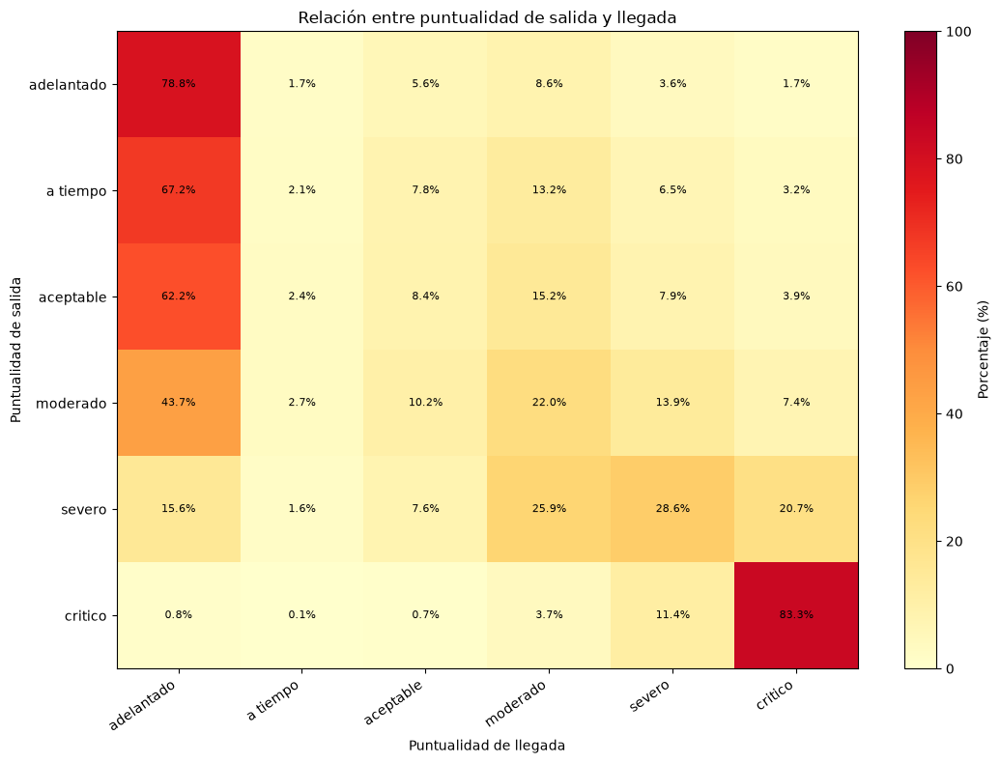

Resumen de llegadas severas y críticas según la categoría de puntualidad de salida.
Los porcentajes indican qué proporción de los vuelos de cada categoría de salida termina llegando con demoras graves.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
nivel_puntualidad_salida,,,,,,,
adelantado,183135,6677,3041,9718,3.65,1.66,5.31
a tiempo,16466,1073,526,1599,6.52,3.19,9.71
aceptable,24465,1931,957,2888,7.89,3.91,11.80
moderado,32992,4588,2443,7031,13.91,7.40,21.31
severo,22383,6406,4632,11038,28.62,20.69,49.31
critico,47905,5456,39900,45356,11.39,83.29,94.68


Gráfico 2: porcentaje de llegadas severas y críticas según la puntualidad de salida.
Permite observar si las categorías de salida con mayores demoras presentan también más llegadas graves.


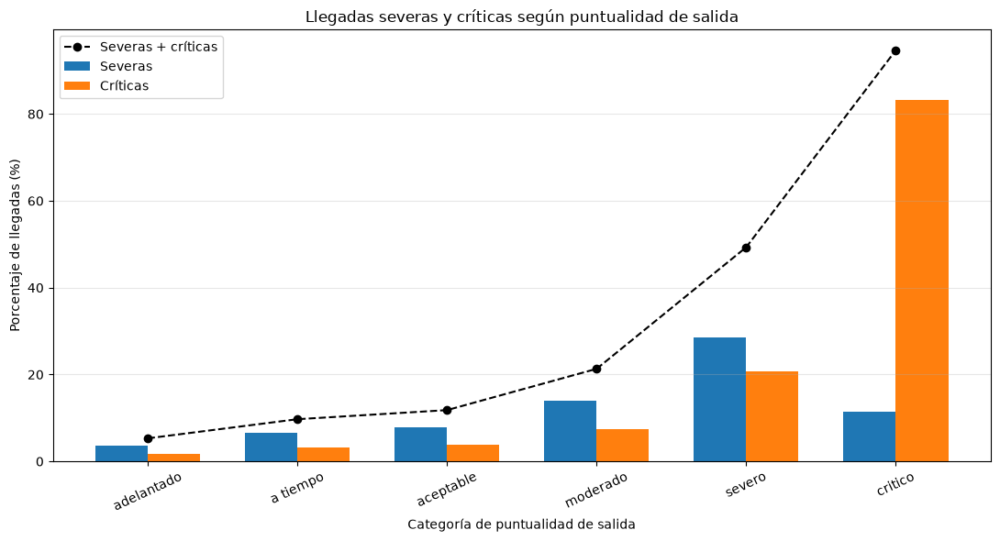

Comparación de llegadas severas y críticas según grupos de puntualidad de salida.
'Salida puntual' reúne adelantado y a tiempo.
'Salida aceptable' se mantiene separada.
'Demora moderada o mayor' reúne moderado, severo y crítico.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
_grupo_salida,,,,,,,
Salida puntual,199601,7750,3567,11317,3.88,1.79,5.67
Salida aceptable,24465,1931,957,2888,7.89,3.91,11.80
Demora moderada o mayor,103280,16450,46975,63425,15.93,45.48,61.41


Gráfico 3: porcentaje de llegadas severas y críticas según el grupo de salida.
Permite comparar directamente los vuelos que salieron puntualmente, los aceptables y los que salieron con demora moderada o mayor.


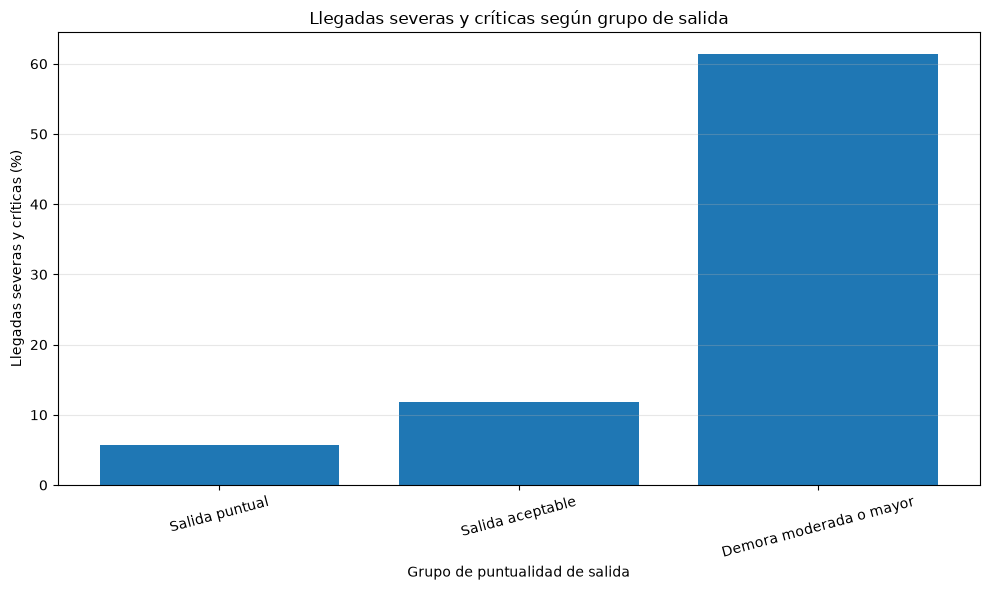

Llegadas severas y críticas entre los vuelos que salieron puntualmente.
Vuelos que salieron adelantados o a tiempo: 199,601
Llegadas severas: 7,750 (3.88%)
Llegadas críticas: 3,567 (1.79%)
Total de llegadas severas y críticas: 11,317 (5.67%)


In [87]:
# ==========================================================
# 5.3. RELACIÓN ENTRE PUNTUALIDAD DE SALIDA Y LLEGADA
# ==========================================================

# Orden de las categorías de puntualidad
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# ----------------------------------------------------------
# 1. PREPARACIÓN DE LOS DATOS
# ----------------------------------------------------------

# Trabajar únicamente con vuelos operados.
# Se utilizan las dos categorías de puntualidad para
# conservar solamente vuelos evaluables en ambas etapas.

base = df.loc[
    df["estado_vuelo"] == "operado",
    [
        "nivel_puntualidad_salida",
        "nivel_puntualidad_arribo"
    ]
].copy()

comparables = base.loc[
    base["nivel_puntualidad_salida"].isin(orden_niveles) &
    base["nivel_puntualidad_arribo"].isin(orden_niveles)
].copy()

# Indicadores de puntualidad de llegada
comparables["_arribo_severo"] = (
    comparables["nivel_puntualidad_arribo"] == "severo"
)

comparables["_arribo_critico"] = (
    comparables["nivel_puntualidad_arribo"] == "critico"
)

comparables["_arribo_grave"] = (
    comparables["_arribo_severo"] |
    comparables["_arribo_critico"]
)

print("Cantidad de vuelos utilizados en la comparación:")
print(f"Vuelos operados con salida y llegada evaluables: {len(comparables):,}")
print(f"Vuelos excluidos por tener alguna categoría desconocida: {len(base) - len(comparables):,}")


# ==========================================================
# 2. RELACIÓN ENTRE CADA CATEGORÍA DE SALIDA Y LLEGADA
# ==========================================================

# Tabla de cantidades
tabla_conteos = pd.crosstab(
    comparables["nivel_puntualidad_salida"],
    comparables["nivel_puntualidad_arribo"]
)

tabla_conteos = tabla_conteos.reindex(
    index=orden_niveles,
    columns=orden_niveles,
    fill_value=0
)

# Tabla de porcentajes por fila.
# Cada fila representa una categoría de salida
# y suma aproximadamente 100%.

tabla_porcentajes = (
    tabla_conteos
    .div(tabla_conteos.sum(axis=1), axis=0) * 100
)

print("Cantidad de vuelos según su puntualidad de salida y llegada.")
print("Cada celda muestra cuántos vuelos pertenecen a esa combinación de categorías.")

display(tabla_conteos)

print("Distribución porcentual de las llegadas según la puntualidad de salida.")
print("Cada fila suma aproximadamente 100% y permite comparar cómo llegan los vuelos según cómo salieron.")

display(tabla_porcentajes.round(2))


# ----------------------------------------------------------
# Gráfico 1: mapa de calor de puntualidad de salida y llegada
# ----------------------------------------------------------

print("Gráfico 1: relación entre las categorías de puntualidad de salida y llegada.")
print("Los porcentajes muestran cómo se distribuyen las llegadas dentro de cada categoría de salida.")

fig, ax = plt.subplots(figsize=(11, 8))

imagen = ax.imshow(
    tabla_porcentajes.values,
    cmap="YlOrRd",
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(orden_niveles)))
ax.set_xticklabels(orden_niveles, rotation=35, ha="right")

ax.set_yticks(range(len(orden_niveles)))
ax.set_yticklabels(orden_niveles)

ax.set_title("Relación entre puntualidad de salida y llegada")
ax.set_xlabel("Puntualidad de llegada")
ax.set_ylabel("Puntualidad de salida")

for i in range(len(orden_niveles)):
    for j in range(len(orden_niveles)):
        ax.text(
            j,
            i,
            f"{tabla_porcentajes.iloc[i, j]:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(imagen, ax=ax, label="Porcentaje (%)")

plt.tight_layout()
plt.show()


# ==========================================================
# 3. LLEGADAS SEVERAS Y CRÍTICAS SEGÚN CATEGORÍA DE SALIDA
# ==========================================================

resumen_salida = (
    comparables.groupby("nivel_puntualidad_salida")
    .agg(
        vuelos=("nivel_puntualidad_arribo", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_niveles)
)

# Calcular porcentajes sobre los vuelos de cada categoría de salida
resumen_salida["pct_severas"] = (
    resumen_salida["llegadas_severas"] /
    resumen_salida["vuelos"] * 100
)

resumen_salida["pct_criticas"] = (
    resumen_salida["llegadas_criticas"] /
    resumen_salida["vuelos"] * 100
)

resumen_salida["pct_graves"] = (
    resumen_salida["llegadas_graves"] /
    resumen_salida["vuelos"] * 100
)

print("Resumen de llegadas severas y críticas según la categoría de puntualidad de salida.")
print("Los porcentajes indican qué proporción de los vuelos de cada categoría de salida termina llegando con demoras graves.")

display(resumen_salida.round(2))


# ----------------------------------------------------------
# Gráfico 2: porcentaje de llegadas graves por categoría
# ----------------------------------------------------------

print("Gráfico 2: porcentaje de llegadas severas y críticas según la puntualidad de salida.")
print("Permite observar si las categorías de salida con mayores demoras presentan también más llegadas graves.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_niveles))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_salida["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_salida["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_salida["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_niveles, rotation=25)

ax.set_title("Llegadas severas y críticas según puntualidad de salida")
ax.set_xlabel("Categoría de puntualidad de salida")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. COMPARACIÓN ENTRE SALIDAS PUNTUALES Y NO PUNTUALES
# ==========================================================

# Mantener "aceptable" como categoría independiente.
# Se consideran puntuales únicamente "adelantado" y "a tiempo".

mapa_grupos = {
    "adelantado": "Salida puntual",
    "a tiempo": "Salida puntual",
    "aceptable": "Salida aceptable",
    "moderado": "Demora moderada o mayor",
    "severo": "Demora moderada o mayor",
    "critico": "Demora moderada o mayor"
}

orden_grupos = [
    "Salida puntual",
    "Salida aceptable",
    "Demora moderada o mayor"
]

comparables["_grupo_salida"] = (
    comparables["nivel_puntualidad_salida"].map(mapa_grupos)
)

comparables["_grupo_salida"] = pd.Categorical(
    comparables["_grupo_salida"],
    categories=orden_grupos,
    ordered=True
)

resumen_grupos = (
    comparables.groupby("_grupo_salida", observed=False)
    .agg(
        vuelos=("nivel_puntualidad_arribo", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_grupos)
)

resumen_grupos["pct_severas"] = (
    resumen_grupos["llegadas_severas"] /
    resumen_grupos["vuelos"] * 100
)

resumen_grupos["pct_criticas"] = (
    resumen_grupos["llegadas_criticas"] /
    resumen_grupos["vuelos"] * 100
)

resumen_grupos["pct_graves"] = (
    resumen_grupos["llegadas_graves"] /
    resumen_grupos["vuelos"] * 100
)

print("Comparación de llegadas severas y críticas según grupos de puntualidad de salida.")
print("'Salida puntual' reúne adelantado y a tiempo.")
print("'Salida aceptable' se mantiene separada.")
print("'Demora moderada o mayor' reúne moderado, severo y crítico.")

display(resumen_grupos.round(2))


# ----------------------------------------------------------
# Gráfico 3: comparación entre grupos de salida
# ----------------------------------------------------------

print("Gráfico 3: porcentaje de llegadas severas y críticas según el grupo de salida.")
print("Permite comparar directamente los vuelos que salieron puntualmente, los aceptables y los que salieron con demora moderada o mayor.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    resumen_grupos.index.astype(str),
    resumen_grupos["pct_graves"]
)

ax.set_title("Llegadas severas y críticas según grupo de salida")
ax.set_xlabel("Grupo de puntualidad de salida")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. LLEGADAS GRAVES A PESAR DE HABER SALIDO PUNTUALMENTE
# ==========================================================

salidas_puntuales = comparables.loc[
    comparables["nivel_puntualidad_salida"].isin(
        ["adelantado", "a tiempo"]
    )
].copy()

vuelos_puntuales = len(salidas_puntuales)

llegadas_severas_puntuales = (
    salidas_puntuales["_arribo_severo"].sum()
)

llegadas_criticas_puntuales = (
    salidas_puntuales["_arribo_critico"].sum()
)

llegadas_graves_puntuales = (
    salidas_puntuales["_arribo_grave"].sum()
)

if vuelos_puntuales > 0:

    pct_severas_puntuales = (
        llegadas_severas_puntuales / vuelos_puntuales * 100
    )

    pct_criticas_puntuales = (
        llegadas_criticas_puntuales / vuelos_puntuales * 100
    )

    pct_graves_puntuales = (
        llegadas_graves_puntuales / vuelos_puntuales * 100
    )

    print("Llegadas severas y críticas entre los vuelos que salieron puntualmente.")
    print(f"Vuelos que salieron adelantados o a tiempo: {vuelos_puntuales:,}")
    print(
        f"Llegadas severas: {llegadas_severas_puntuales:,} "
        f"({pct_severas_puntuales:.2f}%)"
    )
    print(
        f"Llegadas críticas: {llegadas_criticas_puntuales:,} "
        f"({pct_criticas_puntuales:.2f}%)"
    )
    print(
        f"Total de llegadas severas y críticas: {llegadas_graves_puntuales:,} "
        f"({pct_graves_puntuales:.2f}%)"
    )

else:
    print("No hay vuelos con salida puntual y llegada evaluable para realizar esta comparación.")

#### 5.4. Posible acumulación de demoras durante la jornada

Explorar si los vuelos programados para horarios más avanzados presentan una mayor proporción de demoras severas y críticas.

Preguntas que podemos investigar:

- ¿Los vuelos de las últimas horas del día presentan más llegadas graves que los primeros vuelos?
- ¿Se observa una tendencia creciente en las demoras a lo largo de la jornada?
- ¿Los horarios con mayor demora de salida también presentan mayor demora de llegada?

**Hipótesis:** A medida que avanza el día, las demoras pueden acumularse y afectar la puntualidad de los vuelos programados para horarios posteriores.

**Consideración:** observar un aumento de las demoras durante el día no demuestra por sí solo que exista acumulación. Para investigar el efecto de arrastre será necesario relacionar cada vuelo con el comportamiento del vuelo anterior de la misma aeronave.

**Criterio de análisis:** se priorizarán las categorías `severo` y `critico`, tanto por separado como combinadas. Los porcentajes se calcularán sobre los vuelos con puntualidad evaluable, excluyendo la categoría `desconocido`.

Preparación del análisis de acumulación de demoras.
Vuelos operados con llegada evaluable: 327,346
Puntualidad de llegada según el orden programado del vuelo de cada aeronave.
Se compara el primer vuelo, el segundo, el tercero, el cuarto y los posteriores.
Los porcentajes muestran la proporción de llegadas severas y críticas en cada posición.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves
_grupo_orden,,,,,,,,,
1.er vuelo,247358,18897,33563,52460,-2.0,-6.0,7.64,13.57,21.21
2.º vuelo,62745,5644,13052,18696,0.0,-2.0,9.00,20.80,29.80
3.er vuelo,14389,1354,4070,5424,0.0,3.0,9.41,28.29,37.70
4.º vuelo,2784,231,777,1008,-1.0,1.0,8.30,27.91,36.21
5.º o posterior,70,5,37,42,40.0,37.0,7.14,52.86,60.00


Gráfico 1: porcentaje de llegadas severas y críticas según el orden del vuelo de la aeronave.
Una tendencia creciente indicaría que los vuelos posteriores de una misma jornada presentan una mayor proporción de demoras graves.


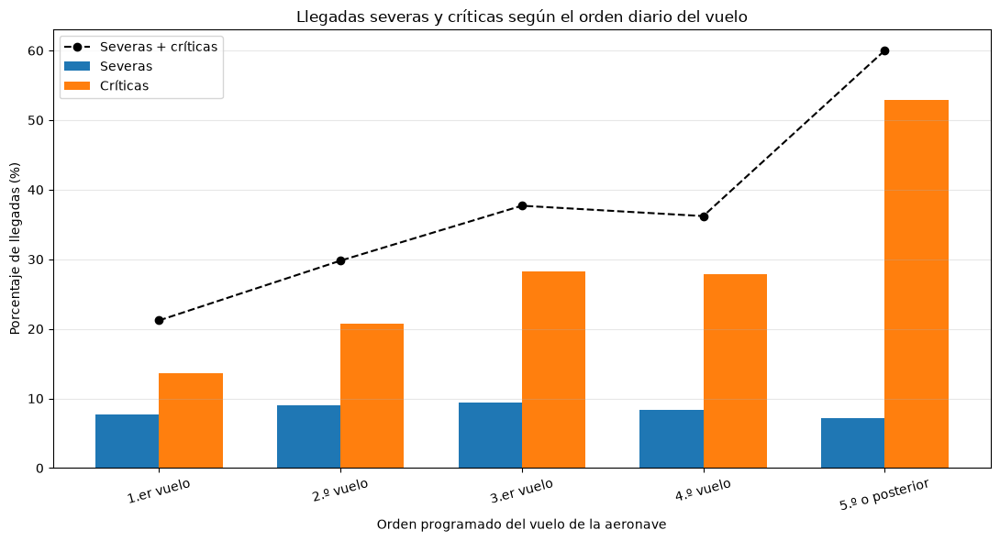

Gráfico 2: mediana de las demoras de salida y llegada según el orden del vuelo.
Permite observar si las demoras típicas aumentan en los vuelos posteriores de una misma aeronave durante el día.


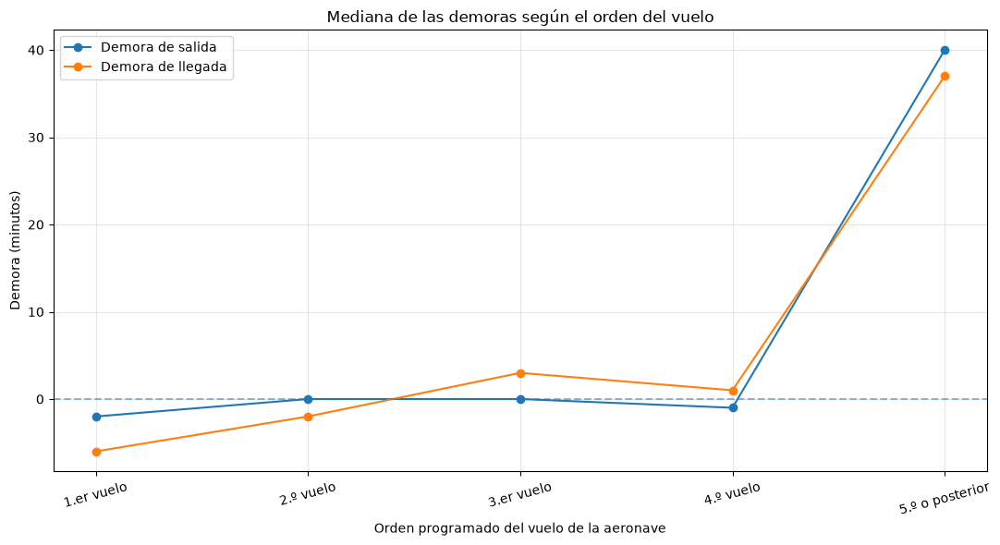

Relación entre la demora del vuelo anterior y la puntualidad de llegada del vuelo actual.
Se compara si el vuelo anterior llegó con demora positiva o sin demora positiva.
Los porcentajes corresponden a las llegadas severas y críticas del vuelo actual.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_anterior,mediana_demora_actual,pct_severas,pct_criticas,pct_graves
_estado_vuelo_anterior,,,,,,,,,
Vuelo anterior sin demora positiva (≤ 0),189395,13415,24118,37533,-15.0,-7.0,7.08,12.73,19.82
Vuelo anterior con demora positiva,128907,11964,26091,38055,21.0,-1.0,9.28,20.24,29.52


Vuelos sin información de demora de llegada del vuelo anterior: 9,044
Gráfico 3: llegadas severas y críticas según el estado del vuelo anterior.
Permite observar si los vuelos cuyo avión llegó previamente demorado presentan más llegadas graves en el vuelo actual.


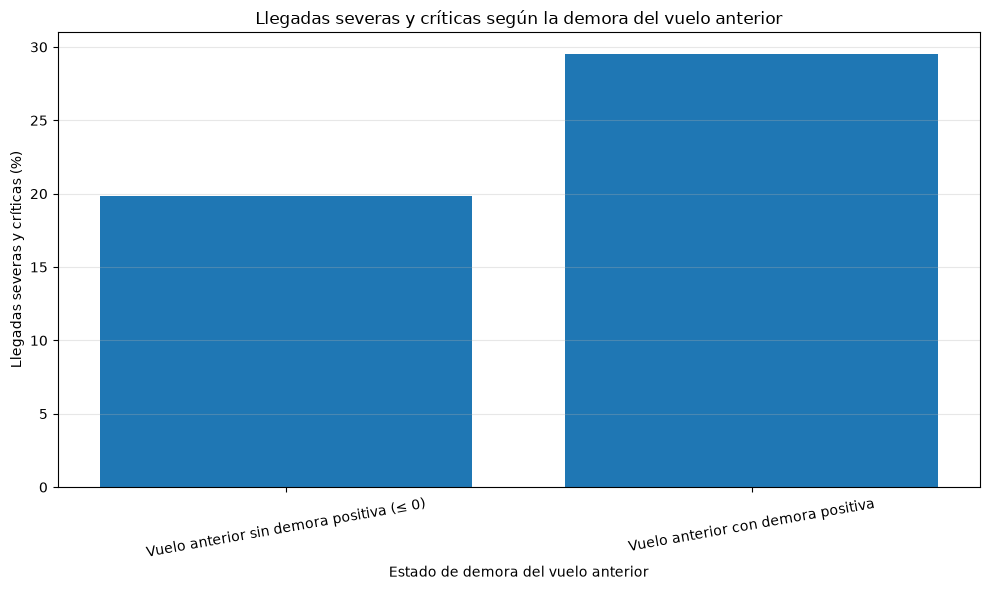

Rangos de demora de llegada del vuelo anterior:
Cuartil 1: desde -86.0 hasta -17.0 minutos
Cuartil 2: desde -17.0 hasta -5.0 minutos
Cuartil 3: desde -5.0 hasta 14.0 minutos
Cuartil 4: desde 14.0 hasta 1272.0 minutos
Llegadas severas y críticas según el nivel de demora del vuelo anterior.
Los cuartiles ordenan los vuelos desde los valores más bajos hasta los más altos de demora anterior.


,vuelos,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_anterior,mediana_demora_salida_actual,mediana_demora_arribo_actual,pct_severas,pct_criticas,pct_graves
_cuartil_demora_anterior,,,,,,,,,,
Cuartil 1,81971,5225,9506,14731,-24.0,-2.0,-9.0,6.37,11.60,17.97
Cuartil 2,79445,5919,10668,16587,-11.0,-2.0,-6.0,7.45,13.43,20.88
Cuartil 3,79236,6841,12265,19106,3.0,-1.0,-3.0,8.63,15.48,24.11
Cuartil 4,77650,7394,17770,25164,42.0,0.0,1.0,9.52,22.88,32.41


Gráfico 4: porcentaje de llegadas severas y críticas según el cuartil de demora del vuelo anterior.
Una tendencia creciente entre cuartiles sería compatible con una asociación entre una mayor demora previa y una mayor proporción de llegadas graves en el vuelo actual.


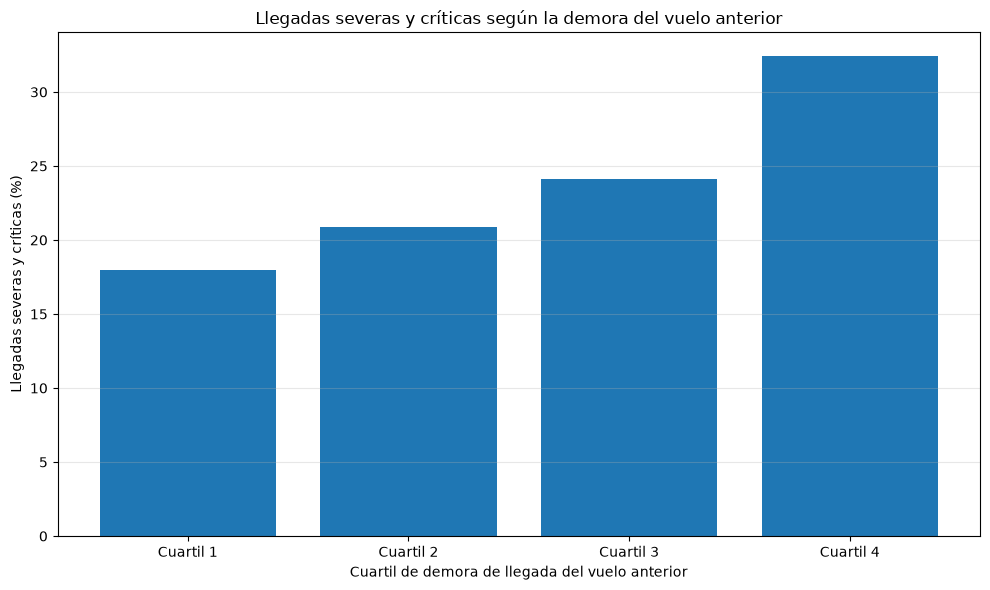

Correlación de Spearman entre la demora de llegada del vuelo anterior y el comportamiento del vuelo actual.
Los valores positivos indican que, en general, mayores demoras anteriores se asocian con valores mayores en la variable actual.
Una correlación no demuestra causalidad.


,Demora de salida actual,Demora de llegada actual,Llegada severa o crítica actual
Demora de llegada del vuelo anterior,0.116,0.169,0.127


In [88]:
# ==========================================================
# 5.4. POSIBLE ACUMULACIÓN DE DEMORAS DURANTE LA JORNADA
# ==========================================================

niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# ----------------------------------------------------------
# 1. PREPARACIÓN DE LOS DATOS
# ----------------------------------------------------------

# Utilizar vuelos operados con puntualidad de llegada evaluable.
base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["nivel_puntualidad_arribo"].isin(niveles_evaluables))
].copy()

# Indicadores de puntualidad de llegada del vuelo actual
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Demoras actuales del vuelo
base["_demora_salida_actual"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["_demora_arribo_actual"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

print("Preparación del análisis de acumulación de demoras.")
print(f"Vuelos operados con llegada evaluable: {len(base):,}")


# ==========================================================
# 2. PUNTUALIDAD SEGÚN EL ORDEN DEL VUELO DE LA AERONAVE
# ==========================================================

# Utilizar el orden de vuelo programado para cada aeronave.
base_orden = base.copy()

base_orden["_orden_vuelo"] = pd.to_numeric(
    base_orden["numero_orden_vuelo_dia_programado"],
    errors="coerce"
)

# Excluir registros sin orden de vuelo válido.
base_orden = base_orden.loc[
    base_orden["_orden_vuelo"].notna() &
    (base_orden["_orden_vuelo"] >= 1)
].copy()

# Agrupar el orden de los vuelos:
# 1, 2, 3, 4 y 5 o más.

orden_grupos = [
    "1.er vuelo",
    "2.º vuelo",
    "3.er vuelo",
    "4.º vuelo",
    "5.º o posterior"
]

base_orden["_grupo_orden"] = pd.cut(
    base_orden["_orden_vuelo"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, np.inf],
    labels=orden_grupos,
    right=False
)

# Resumen por posición del vuelo en la jornada
resumen_orden = (
    base_orden.groupby("_grupo_orden", observed=False)
    .agg(
        vuelos=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_salida=("_demora_salida_actual", "median"),
        mediana_demora_arribo=("_demora_arribo_actual", "median")
    )
    .reindex(orden_grupos)
)

# Porcentajes sobre los vuelos evaluables de cada grupo
resumen_orden["pct_severas"] = (
    resumen_orden["llegadas_severas"] /
    resumen_orden["vuelos"] * 100
)

resumen_orden["pct_criticas"] = (
    resumen_orden["llegadas_criticas"] /
    resumen_orden["vuelos"] * 100
)

resumen_orden["pct_graves"] = (
    resumen_orden["llegadas_graves"] /
    resumen_orden["vuelos"] * 100
)

print("Puntualidad de llegada según el orden programado del vuelo de cada aeronave.")
print("Se compara el primer vuelo, el segundo, el tercero, el cuarto y los posteriores.")
print("Los porcentajes muestran la proporción de llegadas severas y críticas en cada posición.")

display(resumen_orden.round(2))


# ----------------------------------------------------------
# Gráfico 1: llegadas graves según el orden del vuelo
# ----------------------------------------------------------

print("Gráfico 1: porcentaje de llegadas severas y críticas según el orden del vuelo de la aeronave.")
print("Una tendencia creciente indicaría que los vuelos posteriores de una misma jornada presentan una mayor proporción de demoras graves.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_grupos))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_orden["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_orden["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_orden["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos, rotation=15)

ax.set_title("Llegadas severas y críticas según el orden diario del vuelo")
ax.set_xlabel("Orden programado del vuelo de la aeronave")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Gráfico 2: medianas de demoras según el orden del vuelo
# ----------------------------------------------------------

print("Gráfico 2: mediana de las demoras de salida y llegada según el orden del vuelo.")
print("Permite observar si las demoras típicas aumentan en los vuelos posteriores de una misma aeronave durante el día.")

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    x,
    resumen_orden["mediana_demora_salida"],
    marker="o",
    label="Demora de salida"
)

ax.plot(
    x,
    resumen_orden["mediana_demora_arribo"],
    marker="o",
    label="Demora de llegada"
)

ax.axhline(0, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos, rotation=15)

ax.set_title("Mediana de las demoras según el orden del vuelo")
ax.set_xlabel("Orden programado del vuelo de la aeronave")
ax.set_ylabel("Demora (minutos)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. RELACIÓN CON LA DEMORA DEL VUELO ANTERIOR
# ==========================================================

# Utilizar la demora de llegada del vuelo anterior
# de la misma aeronave en el mismo aeropuerto de origen,
# según la definición de la columna ya creada.

base_anterior = base.loc[
    base["retraso_vuelo_anterior_arribo"].notna()
].copy()

base_anterior["_demora_anterior"] = pd.to_numeric(
    base_anterior["retraso_vuelo_anterior_arribo"],
    errors="coerce"
)

base_anterior = base_anterior.loc[
    base_anterior["_demora_anterior"].notna()
].copy()

# Diferenciar vuelos cuyo vuelo anterior tuvo demora positiva
# de aquellos cuyo vuelo anterior llegó sin demora positiva.

base_anterior["_estado_vuelo_anterior"] = np.where(
    base_anterior["_demora_anterior"] > 0,
    "Vuelo anterior con demora positiva",
    "Vuelo anterior sin demora positiva (≤ 0)"
)

orden_estado_anterior = [
    "Vuelo anterior sin demora positiva (≤ 0)",
    "Vuelo anterior con demora positiva"
]

base_anterior["_estado_vuelo_anterior"] = pd.Categorical(
    base_anterior["_estado_vuelo_anterior"],
    categories=orden_estado_anterior,
    ordered=True
)

# Resumen según el estado del vuelo anterior
resumen_anterior = (
    base_anterior.groupby(
        "_estado_vuelo_anterior",
        observed=False
    )
    .agg(
        vuelos=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_anterior=("_demora_anterior", "median"),
        mediana_demora_actual=("_demora_arribo_actual", "median")
    )
    .reindex(orden_estado_anterior)
)

resumen_anterior["pct_severas"] = (
    resumen_anterior["llegadas_severas"] /
    resumen_anterior["vuelos"] * 100
)

resumen_anterior["pct_criticas"] = (
    resumen_anterior["llegadas_criticas"] /
    resumen_anterior["vuelos"] * 100
)

resumen_anterior["pct_graves"] = (
    resumen_anterior["llegadas_graves"] /
    resumen_anterior["vuelos"] * 100
)

print("Relación entre la demora del vuelo anterior y la puntualidad de llegada del vuelo actual.")
print("Se compara si el vuelo anterior llegó con demora positiva o sin demora positiva.")
print("Los porcentajes corresponden a las llegadas severas y críticas del vuelo actual.")

display(resumen_anterior.round(2))

print(
    "Vuelos sin información de demora de llegada del vuelo anterior:",
    f"{len(base) - len(base_anterior):,}"
)


# ----------------------------------------------------------
# Gráfico 3: puntualidad actual según el estado del vuelo anterior
# ----------------------------------------------------------

print("Gráfico 3: llegadas severas y críticas según el estado del vuelo anterior.")
print("Permite observar si los vuelos cuyo avión llegó previamente demorado presentan más llegadas graves en el vuelo actual.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    resumen_anterior.index.astype(str),
    resumen_anterior["pct_graves"]
)

ax.set_title("Llegadas severas y críticas según la demora del vuelo anterior")
ax.set_xlabel("Estado de demora del vuelo anterior")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.tick_params(axis="x", rotation=10)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. CUANTO MAYOR FUE LA DEMORA ANTERIOR, ¿MAYOR ES LA ACTUAL?
# ==========================================================

# Analizar los valores de demora del vuelo anterior por cuartiles.
# Los grupos se forman a partir de la distribución observada,
# sin imponer límites arbitrarios de minutos.

if base_anterior["_demora_anterior"].nunique() >= 2:

    codigos, bordes = pd.qcut(
        base_anterior["_demora_anterior"],
        q=4,
        labels=False,
        retbins=True,
        duplicates="drop"
    )

    cantidad_cuartiles = len(bordes) - 1

    nombres_cuartiles = [
        f"Cuartil {i + 1}"
        for i in range(cantidad_cuartiles)
    ]

    mapa_cuartiles = {
        i: nombre
        for i, nombre in enumerate(nombres_cuartiles)
    }

    base_anterior["_cuartil_demora_anterior"] = pd.Categorical(
        pd.Series(codigos, index=base_anterior.index).map(mapa_cuartiles),
        categories=nombres_cuartiles,
        ordered=True
    )

    print("Rangos de demora de llegada del vuelo anterior:")
    for i, nombre in enumerate(nombres_cuartiles):
        print(
            f"{nombre}: desde {bordes[i]:.1f} "
            f"hasta {bordes[i + 1]:.1f} minutos"
        )

else:
    nombres_cuartiles = ["Sin variación"]

    base_anterior["_cuartil_demora_anterior"] = "Sin variación"


# Resumen por cuartil de demora anterior
resumen_cuartiles = (
    base_anterior.groupby(
        "_cuartil_demora_anterior",
        observed=False
    )
    .agg(
        vuelos=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_anterior=("_demora_anterior", "median"),
        mediana_demora_salida_actual=("_demora_salida_actual", "median"),
        mediana_demora_arribo_actual=("_demora_arribo_actual", "median")
    )
    .reindex(nombres_cuartiles)
)

resumen_cuartiles["pct_severas"] = (
    resumen_cuartiles["llegadas_severas"] /
    resumen_cuartiles["vuelos"] * 100
)

resumen_cuartiles["pct_criticas"] = (
    resumen_cuartiles["llegadas_criticas"] /
    resumen_cuartiles["vuelos"] * 100
)

resumen_cuartiles["pct_graves"] = (
    resumen_cuartiles["llegadas_graves"] /
    resumen_cuartiles["vuelos"] * 100
)

print("Llegadas severas y críticas según el nivel de demora del vuelo anterior.")
print("Los cuartiles ordenan los vuelos desde los valores más bajos hasta los más altos de demora anterior.")

display(resumen_cuartiles.round(2))


# ----------------------------------------------------------
# Gráfico 4: porcentaje de llegadas graves por cuartil
# ----------------------------------------------------------

print("Gráfico 4: porcentaje de llegadas severas y críticas según el cuartil de demora del vuelo anterior.")
print("Una tendencia creciente entre cuartiles sería compatible con una asociación entre una mayor demora previa y una mayor proporción de llegadas graves en el vuelo actual.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    resumen_cuartiles.index.astype(str),
    resumen_cuartiles["pct_graves"]
)

ax.set_title("Llegadas severas y críticas según la demora del vuelo anterior")
ax.set_xlabel("Cuartil de demora de llegada del vuelo anterior")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. CORRELACIÓN ENTRE LA DEMORA ANTERIOR Y LA ACTUAL
# ==========================================================

# Comparar la demora de llegada anterior con las demoras
# actuales de salida y llegada, además del indicador de
# llegada severa o crítica.

base_anterior["_llegada_grave_num"] = (
    base_anterior["_arribo_grave"].astype(int)
)

datos_correlacion = base_anterior[
    [
        "_demora_anterior",
        "_demora_salida_actual",
        "_demora_arribo_actual",
        "_llegada_grave_num"
    ]
].copy()

correlaciones = datos_correlacion.corr(method="spearman")

print("Correlación de Spearman entre la demora de llegada del vuelo anterior y el comportamiento del vuelo actual.")
print("Los valores positivos indican que, en general, mayores demoras anteriores se asocian con valores mayores en la variable actual.")
print("Una correlación no demuestra causalidad.")

display(
    correlaciones.loc[
        ["_demora_anterior"],
        [
            "_demora_salida_actual",
            "_demora_arribo_actual",
            "_llegada_grave_num"
        ]
    ].rename(
        columns={
            "_demora_salida_actual": "Demora de salida actual",
            "_demora_arribo_actual": "Demora de llegada actual",
            "_llegada_grave_num": "Llegada severa o crítica actual"
        },
        index={
            "_demora_anterior": "Demora de llegada del vuelo anterior"
        }
    ).round(3)
)

###
---
---
---

### 6. Análisis por Mes / época del año

El momento del año y el día en que se programa un vuelo pueden estar relacionados con su puntualidad. La demanda de vuelos, las condiciones climáticas y la actividad aeroportuaria pueden variar según el mes, la semana y el día.

El objetivo de este análisis es identificar si existen períodos del año con una mayor proporción de llegadas severas y críticas, y explorar si determinados días o semanas presentan un comportamiento diferente.

Para el análisis utilizaremos la fecha de salida programada y las variables temporales disponibles en el dataset.


**Criterio de análisis:** se priorizarán las categorías `severo` y `critico`, tanto por separado como combinadas. Los porcentajes se calcularán sobre los vuelos operados con puntualidad de llegada evaluable, excluyendo la categoría `desconocido`.

Se analizarán tanto las cantidades absolutas como los porcentajes, ya que un mes o día puede tener más demoras simplemente por concentrar un mayor volumen de vuelos.

**Consideración:** el dataset corresponde al año 2013. Por lo tanto, podremos identificar patrones temporales dentro de ese año, pero no confirmar que se repitan todos los años ni establecer una estacionalidad general a largo plazo.

**Aplicación predictiva:** los resultados permitirán evaluar si el mes, el trimestre, el día de la semana, la semana del mes y el día del mes aportan información útil para predecir las demoras de llegada.

#### 6.1. Puntualidad según el mes

Analizar la distribución de las demoras durante los doce meses del año.

Preguntas que podemos investigar:

- ¿Hay meses con mayor cantidad de llegadas severas y críticas?
- ¿Qué meses presentan el mayor porcentaje de demoras graves?
- ¿Existen meses especialmente problemáticos?
- ¿Los meses con mayor volumen de vuelos también presentan una mayor proporción de demoras?

Distribución general de los niveles de puntualidad de llegada por mes.
Se incluyen todas las categorías, también 'desconocido'.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_mes,,,,,,,
Enero,14743,505,1744,3405,2261,3740,85
Febrero,13099,412,1625,3057,2047,3371,79
Marzo,16553,430,1564,2981,2095,4279,71
Abril,14576,466,1614,3208,2501,5199,98
Mayo,17559,380,1403,2608,1988,4190,105
Junio,14179,406,1452,2698,2140,6200,159
Julio,14588,401,1447,2955,2296,6606,192
Agosto,16649,478,1617,3160,2310,4542,85
Septiembre,19781,384,1240,2030,1257,2318,112


Distribución porcentual de los niveles de puntualidad por mes.
Cada fila representa un mes y permite comparar la distribución de sus categorías.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_mes,,,,,,,
Enero,55.67,1.91,6.59,12.86,8.54,14.12,0.32
Febrero,55.29,1.74,6.86,12.90,8.64,14.23,0.33
Marzo,59.17,1.54,5.59,10.66,7.49,15.30,0.25
Abril,52.69,1.68,5.83,11.60,9.04,18.79,0.35
Mayo,62.19,1.35,4.97,9.24,7.04,14.84,0.37
Junio,52.06,1.49,5.33,9.91,7.86,22.77,0.58
Julio,51.21,1.41,5.08,10.37,8.06,23.19,0.67
Agosto,57.73,1.66,5.61,10.96,8.01,15.75,0.29
Septiembre,72.93,1.42,4.57,7.48,4.63,8.55,0.41


Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada por mes.
Permite observar cómo se distribuyen las categorías de puntualidad a lo largo del año.


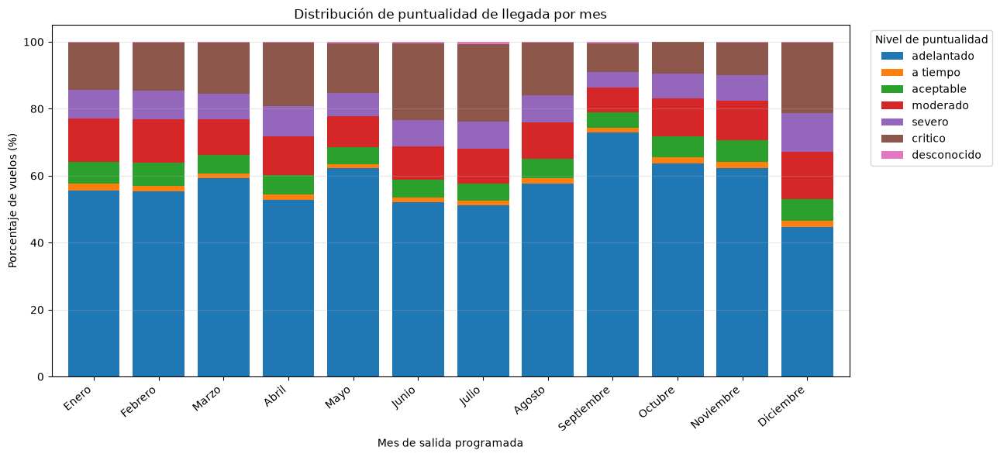

Resumen mensual de vuelos y llegadas severas y críticas.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.
También se incluye el promedio diario de vuelos para considerar la duración de cada mes.


,vuelos_operados,dias_calendario,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,vuelos_por_dia
_mes,,,,,,,,,,
Enero,26483,31,26398,2261,3740,6001,8.57,14.17,22.73,854.29
Febrero,23690,28,23611,2047,3371,5418,8.67,14.28,22.95,846.07
Marzo,27973,31,27902,2095,4279,6374,7.51,15.34,22.84,902.35
Abril,27662,30,27564,2501,5199,7700,9.07,18.86,27.93,922.07
Mayo,28233,31,28128,1988,4190,6178,7.07,14.90,21.96,910.74
Junio,27234,30,27075,2140,6200,8340,7.90,22.90,30.80,907.80
Julio,28485,31,28293,2296,6606,8902,8.12,23.35,31.46,918.87
Agosto,28841,31,28756,2310,4542,6852,8.03,15.79,23.83,930.35
Septiembre,27122,30,27010,1257,2318,3575,4.65,8.58,13.24,904.07


Gráfico 2: cantidad de llegadas severas y críticas por mes.
Muestra los casos absolutos de cada categoría. No representa porcentajes.


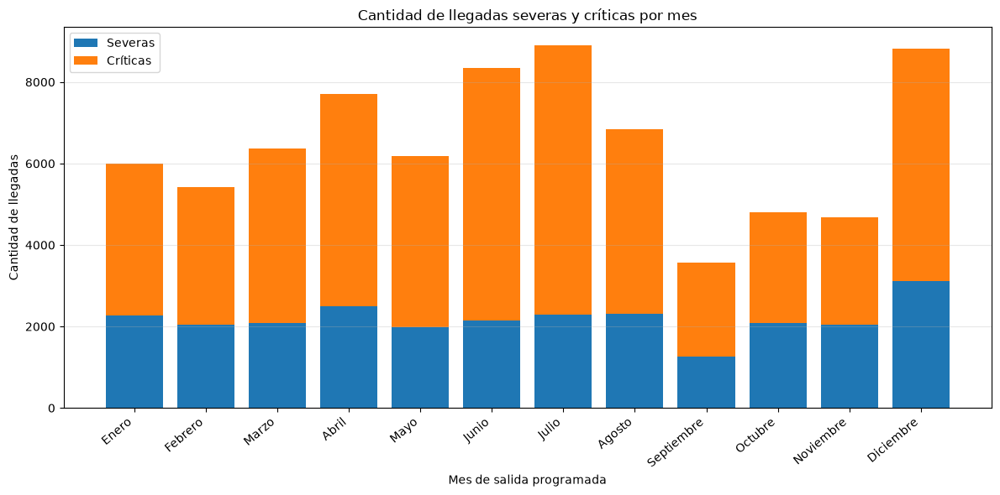

Gráfico 3: porcentaje de llegadas severas y críticas por mes.
Permite identificar los meses con mayor proporción de demoras graves, independientemente del volumen de vuelos.


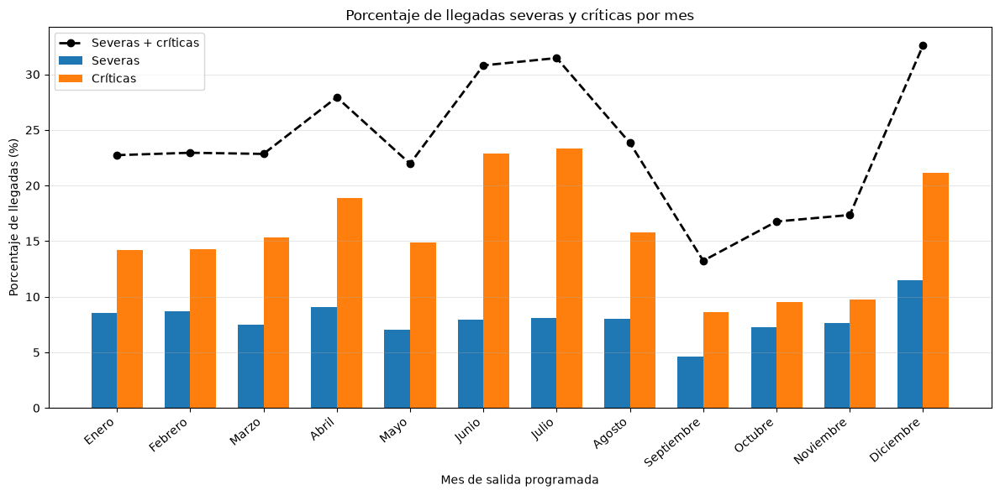

Gráfico 4: relación entre volumen de vuelos y porcentaje de llegadas severas y críticas.
Cada punto representa un mes.
Permite observar si los meses con más vuelos también presentan una mayor proporción de demoras graves.


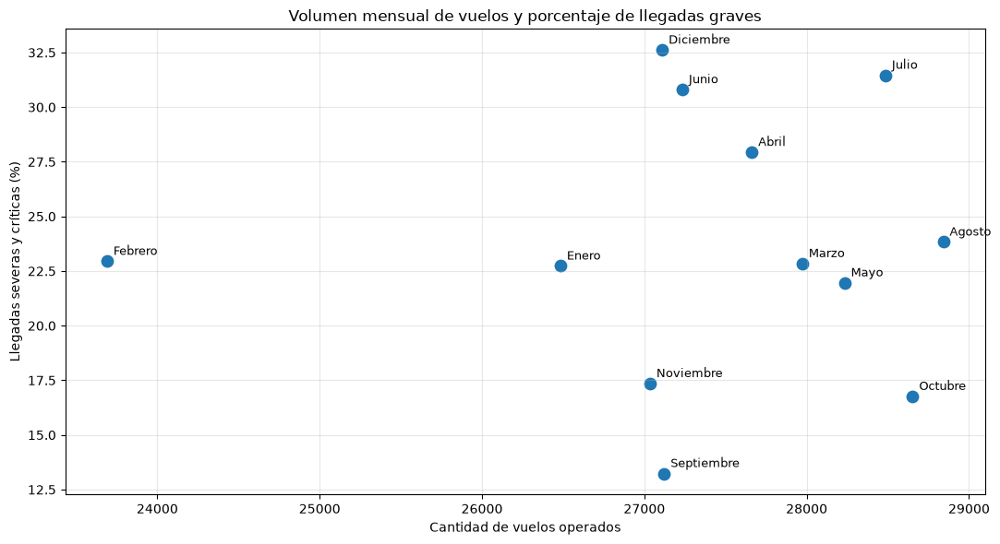

Los 5 meses con mayor cantidad de llegadas severas y críticas.


,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
_mes,,,,,,
Julio,28485,28293,2296,6606,8902,31.46
Diciembre,27110,27020,3106,5706,8812,32.61
Junio,27234,27075,2140,6200,8340,30.80
Abril,27662,27564,2501,5199,7700,27.93
Agosto,28841,28756,2310,4542,6852,23.83


Los 5 meses con mayor porcentaje de llegadas severas y críticas (mínimo 30 casos evaluables).


,vuelos_operados,llegadas_evaluables,llegadas_graves,pct_graves,vuelos_por_dia
_mes,,,,,
Diciembre,27110,27020,8812,32.61,874.52
Julio,28485,28293,8902,31.46,918.87
Junio,27234,27075,8340,30.80,907.80
Abril,27662,27564,7700,27.93,922.07
Agosto,28841,28756,6852,23.83,930.35


In [89]:
# ==========================================================
# 6.1. PUNTUALIDAD SEGÚN EL MES
# ==========================================================

# Cantidad mínima de vuelos evaluables para incluir
# un mes en las comparaciones porcentuales.
MIN_EVALUABLES = 30

# Orden de los meses
orden_meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Orden de los niveles de puntualidad
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Categorías que se consideran evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

# ----------------------------------------------------------
# 1. PREPARACIÓN DE LOS DATOS
# ----------------------------------------------------------

# Trabajar únicamente con vuelos operados
# y con mes de salida programado disponible.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["mes_salida_programado"].notna()) &
    (df["fecha_hora_salida_programada"].notna())
].copy()

# Nombres de los meses
nombres_meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

# Crear categoría temporal del mes
base["_mes"] = (
    pd.to_numeric(base["mes_salida_programado"], errors="coerce")
    .map(nombres_meses)
)

base = base.loc[base["_mes"].notna()].copy()

base["_mes"] = pd.Categorical(
    base["_mes"],
    categories=orden_meses,
    ordered=True
)

# Obtener la cantidad de días calendario de cada mes.
# Esto permite calcular el promedio diario de vuelos.

base["_dias_mes"] = (
    base["fecha_hora_salida_programada"].dt.days_in_month
)

# Indicadores de puntualidad de llegada

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)


# ==========================================================
# 2. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD POR MES
# ==========================================================

# Cantidad de vuelos por nivel de puntualidad y mes
tabla_niveles = pd.crosstab(
    base["_mes"],
    base["nivel_puntualidad_arribo"]
)

tabla_niveles = tabla_niveles.reindex(
    index=orden_meses,
    columns=orden_niveles,
    fill_value=0
)

# Distribución porcentual por mes
# Incluye "desconocido" porque muestra la distribución completa.

tabla_pct_niveles = (
    tabla_niveles
    .div(tabla_niveles.sum(axis=1), axis=0) * 100
)

print("Distribución general de los niveles de puntualidad de llegada por mes.")
print("Se incluyen todas las categorías, también 'desconocido'.")

display(tabla_niveles)

print("Distribución porcentual de los niveles de puntualidad por mes.")
print("Cada fila representa un mes y permite comparar la distribución de sus categorías.")

display(tabla_pct_niveles.round(2))


# Gráfico 1: distribución porcentual de todos los niveles

print("Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada por mes.")
print("Permite observar cómo se distribuyen las categorías de puntualidad a lo largo del año.")

ax = tabla_pct_niveles.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Distribución de puntualidad de llegada por mes")
ax.set_xlabel("Mes de salida programada")
ax.set_ylabel("Porcentaje de vuelos (%)")
ax.set_xticklabels(orden_meses, rotation=40, ha="right")
ax.legend(
    title="Nivel de puntualidad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. RESUMEN MENSUAL DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

resumen_meses = (
    base.groupby("_mes", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        dias_calendario=("_dias_mes", "first"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_meses)
)

# Porcentajes sobre las llegadas evaluables

resumen_meses["pct_severas"] = (
    resumen_meses["llegadas_severas"] /
    resumen_meses["llegadas_evaluables"] * 100
)

resumen_meses["pct_criticas"] = (
    resumen_meses["llegadas_criticas"] /
    resumen_meses["llegadas_evaluables"] * 100
)

resumen_meses["pct_graves"] = (
    resumen_meses["llegadas_graves"] /
    resumen_meses["llegadas_evaluables"] * 100
)

# Promedio diario de vuelos por mes

resumen_meses["vuelos_por_dia"] = (
    resumen_meses["vuelos_operados"] /
    resumen_meses["dias_calendario"]
)

print("Resumen mensual de vuelos y llegadas severas y críticas.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.")
print("También se incluye el promedio diario de vuelos para considerar la duración de cada mes.")

display(resumen_meses.round(2))


# ==========================================================
# 4. CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS POR MES
# ==========================================================

print("Gráfico 2: cantidad de llegadas severas y críticas por mes.")
print("Muestra los casos absolutos de cada categoría. No representa porcentajes.")

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(orden_meses))
severas = resumen_meses["llegadas_severas"].values
criticas = resumen_meses["llegadas_criticas"].values

ax.bar(
    x,
    severas,
    label="Severas"
)

ax.bar(
    x,
    criticas,
    bottom=severas,
    label="Críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_meses, rotation=40, ha="right")

ax.set_title("Cantidad de llegadas severas y críticas por mes")
ax.set_xlabel("Mes de salida programada")
ax.set_ylabel("Cantidad de llegadas")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS POR MES
# ==========================================================

print("Gráfico 3: porcentaje de llegadas severas y críticas por mes.")
print("Permite identificar los meses con mayor proporción de demoras graves, independientemente del volumen de vuelos.")

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(orden_meses))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_meses["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_meses["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_meses["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_meses, rotation=40, ha="right")

ax.set_title("Porcentaje de llegadas severas y críticas por mes")
ax.set_xlabel("Mes de salida programada")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. VOLUMEN DE VUELOS Y PORCENTAJE DE DEMORAS GRAVES
# ==========================================================

# Cada punto representa un mes.
# Se utiliza el volumen total de vuelos operados como
# referencia para compararlo con el porcentaje de llegadas graves.

meses_comparables = resumen_meses.loc[
    resumen_meses["llegadas_evaluables"] >= MIN_EVALUABLES
].copy()

print("Gráfico 4: relación entre volumen de vuelos y porcentaje de llegadas severas y críticas.")
print("Cada punto representa un mes.")
print("Permite observar si los meses con más vuelos también presentan una mayor proporción de demoras graves.")

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    meses_comparables["vuelos_operados"],
    meses_comparables["pct_graves"],
    s=80
)

# Identificar cada punto con el nombre del mes

for mes, fila in meses_comparables.iterrows():
    ax.annotate(
        mes,
        (
            fila["vuelos_operados"],
            fila["pct_graves"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Volumen mensual de vuelos y porcentaje de llegadas graves")
ax.set_xlabel("Cantidad de vuelos operados")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 7. IDENTIFICAR LOS MESES MÁS PROBLEMÁTICOS
# ==========================================================

# Cinco meses con mayor cantidad de llegadas graves

top_meses_cantidad = (
    resumen_meses
    .sort_values("llegadas_graves", ascending=False)
    .head(5)
)

print("Los 5 meses con mayor cantidad de llegadas severas y críticas.")

display(
    top_meses_cantidad[
        [
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)


# Cinco meses con mayor porcentaje de llegadas graves

top_meses_porcentaje = (
    meses_comparables
    .sort_values("pct_graves", ascending=False)
    .head(5)
)

print(f"Los 5 meses con mayor porcentaje de llegadas severas y críticas (mínimo {MIN_EVALUABLES} casos evaluables).")

display(
    top_meses_porcentaje[
        [
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_graves",
            "pct_graves",
            "vuelos_por_dia"
        ]
    ].round(2)
)

#### 6.2. Puntualidad según el trimestre y la época del año

Agrupar los meses según el trimestre y comparar el comportamiento de las demoras durante diferentes períodos del año.

Preguntas que podemos investigar:

- ¿Hay trimestres con mayor proporción de llegadas severas y críticas?
- ¿Se observan diferencias entre los períodos del año?
- ¿Los meses que presentan peores resultados pertenecen a un mismo trimestre?
- ¿Los patrones observados por mes también se mantienen al agruparlos por trimestre?

Preparación del análisis trimestral.
Vuelos operados incluidos: 328,521
Trimestres disponibles: 2013Q1, 2013Q2, 2013Q3, 2013Q4
Distribución general de los niveles de puntualidad de llegada por trimestre.
Se incluyen todas las categorías, también 'desconocido'.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_trimestre,,,,,,,
2013Q1,44395,1347,4933,9443,6403,11390,235
2013Q2,46314,1252,4469,8514,6629,15589,362
2013Q3,51018,1263,4304,8145,5863,13466,389
2013Q4,47206,1547,5276,10290,7236,11054,189


Distribución porcentual de los niveles de puntualidad por trimestre.
Cada fila representa un trimestre y permite comparar la distribución de sus categorías.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_trimestre,,,,,,,
2013Q1,56.81,1.72,6.31,12.08,8.19,14.58,0.30
2013Q2,55.71,1.51,5.38,10.24,7.97,18.75,0.44
2013Q3,60.41,1.50,5.10,9.64,6.94,15.95,0.46
2013Q4,57.01,1.87,6.37,12.43,8.74,13.35,0.23


Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada por trimestre.
Permite comparar cómo se distribuyen las categorías de puntualidad en los distintos períodos del año.


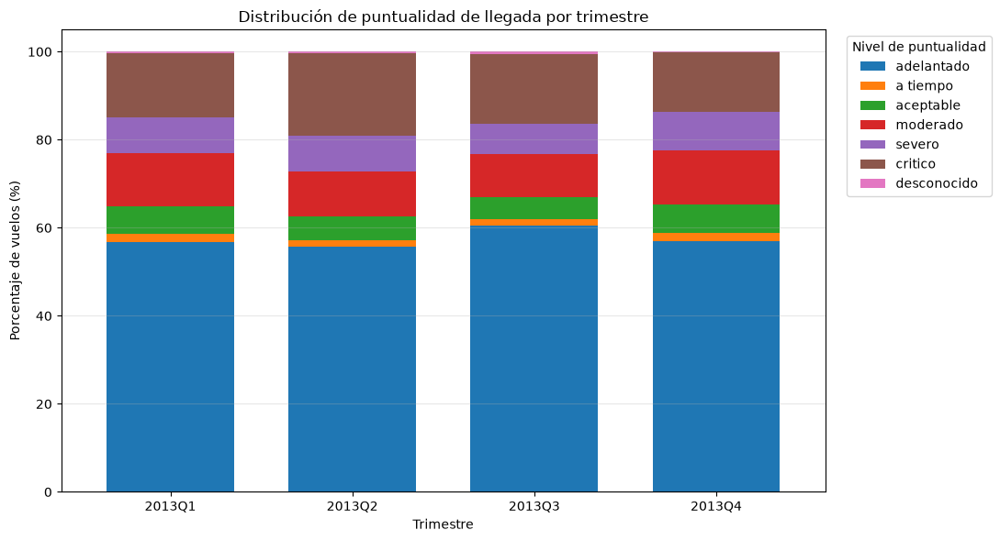

Resumen de vuelos y puntualidad según el trimestre.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.
También se incluye el promedio diario de vuelos para contemplar la duración de cada trimestre.


,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,dias_calendario,vuelos_por_dia,pct_severas,pct_criticas,pct_graves
_trimestre,,,,,,,,,,
2013Q1,78146,77911,6403,11390,17793,90,868.29,8.22,14.62,22.84
2013Q2,83129,82767,6629,15589,22218,91,913.51,8.01,18.83,26.84
2013Q3,84448,84059,5863,13466,19329,92,917.91,6.97,16.02,22.99
2013Q4,82798,82609,7236,11054,18290,92,899.98,8.76,13.38,22.14


Gráfico 2: cantidad de llegadas severas y críticas por trimestre.
Muestra los casos absolutos de cada categoría y permite identificar qué período concentra más demoras graves.


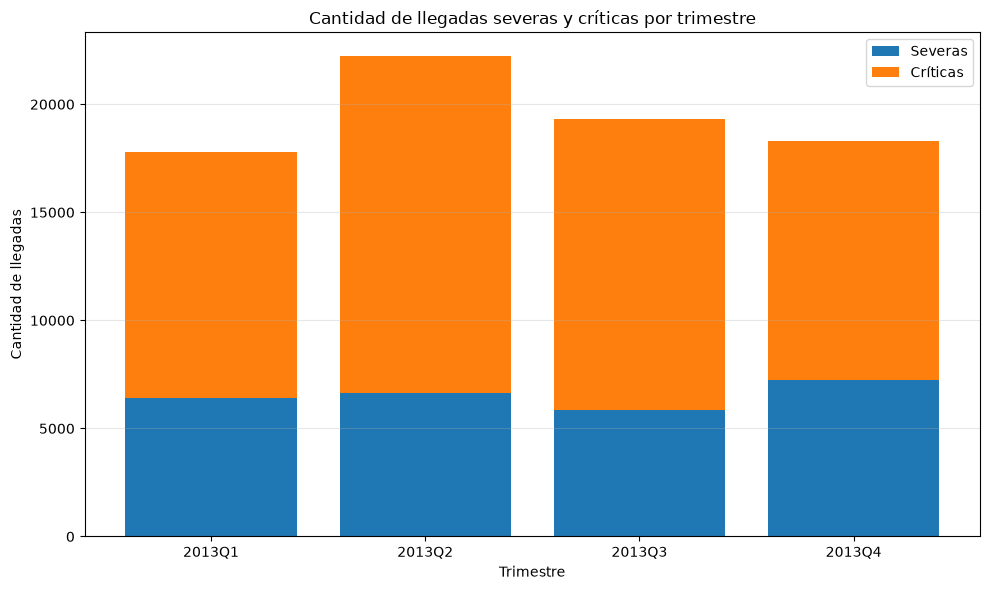

Gráfico 3: porcentaje de llegadas severas y críticas por trimestre.
Es el gráfico principal para comparar la puntualidad entre períodos, independientemente del volumen de vuelos.


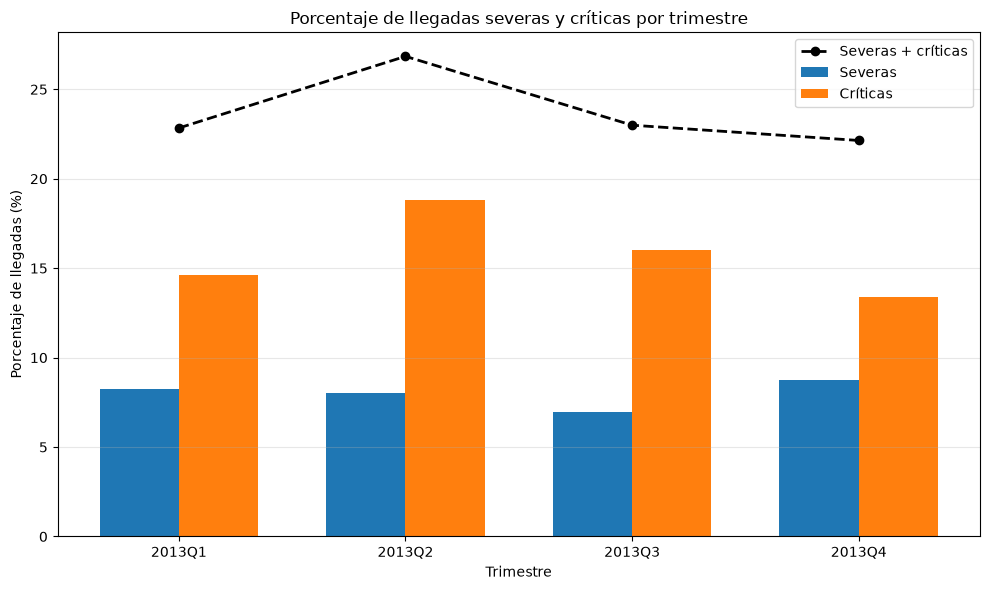

Detalle mensual de llegadas severas y críticas dentro de cada trimestre.
Esta tabla permite comprobar si los meses con peores resultados se concentran en algún trimestre.


,_trimestre,_mes,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
0,2013Q1,Enero,26483,26398,2261,3740,6001,22.73
1,2013Q1,Febrero,23690,23611,2047,3371,5418,22.95
2,2013Q1,Marzo,27973,27902,2095,4279,6374,22.84
3,2013Q2,Abril,27662,27564,2501,5199,7700,27.93
4,2013Q2,Mayo,28233,28128,1988,4190,6178,21.96
5,2013Q2,Junio,27234,27075,2140,6200,8340,30.80
6,2013Q3,Julio,28485,28293,2296,6606,8902,31.46
7,2013Q3,Agosto,28841,28756,2310,4542,6852,23.83
8,2013Q3,Septiembre,27122,27010,1257,2318,3575,13.24
9,2013Q4,Octubre,28653,28618,2080,2718,4798,16.77


Gráfico 4: porcentaje de llegadas severas y críticas por mes, agrupado visualmente por trimestre.
Permite comprobar si los meses con peores porcentajes se concentran en determinados períodos del año.


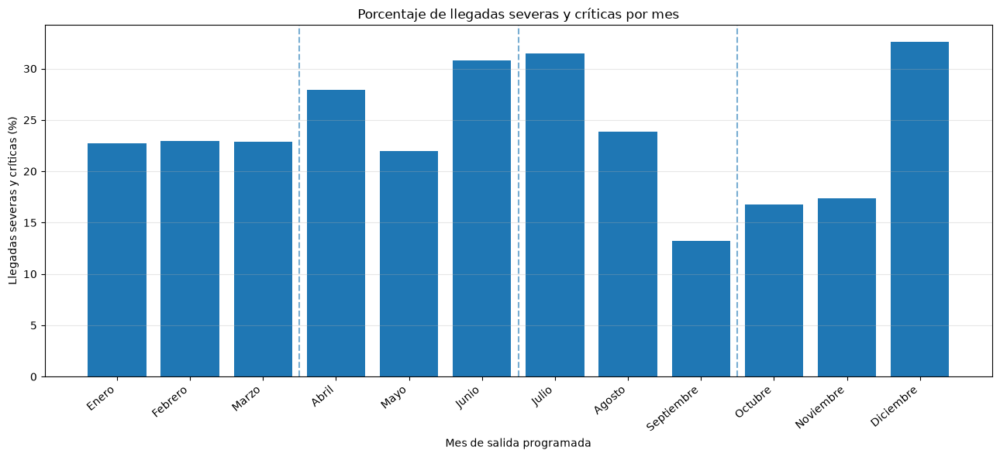

Mes con mayor porcentaje de llegadas severas y críticas dentro de cada trimestre.


,_trimestre,_mes,vuelos_operados,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
1,2013Q1,Febrero,23690,23611,2047,3371,5418,22.95
5,2013Q2,Junio,27234,27075,2140,6200,8340,30.80
6,2013Q3,Julio,28485,28293,2296,6606,8902,31.46
11,2013Q4,Diciembre,27110,27020,3106,5706,8812,32.61


Trimestre con mayor cantidad de llegadas severas y críticas: 2013Q2
Trimestre con mayor porcentaje de llegadas severas y críticas: 2013Q2
Porcentaje de llegadas graves en ese trimestre: 26.84%


In [90]:
# ==========================================================
# 6.2. PUNTUALIDAD SEGÚN EL TRIMESTRE Y LA ÉPOCA DEL AÑO
# ==========================================================

# Categorías de puntualidad
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Categorías evaluables: se excluye "desconocido"
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]

orden_meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

nombres_meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Trabajar únicamente con vuelos operados
# que tengan trimestre asignado.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["trimestre"].notna())
].copy()

# Orden cronológico de los trimestres disponibles
periodos = sorted(base["trimestre"].unique())

orden_trimestres = [
    str(periodo) for periodo in periodos
]

# Etiqueta de texto para los gráficos y las tablas
base["_trimestre"] = base["trimestre"].astype(str)

# Indicadores de puntualidad de llegada

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

print("Preparación del análisis trimestral.")
print(f"Vuelos operados incluidos: {len(base):,}")
print(f"Trimestres disponibles: {', '.join(orden_trimestres)}")


# ==========================================================
# 2. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD POR TRIMESTRE
# ==========================================================

# Cantidad de vuelos por categoría de puntualidad
tabla_niveles = pd.crosstab(
    base["_trimestre"],
    base["nivel_puntualidad_arribo"]
)

tabla_niveles = tabla_niveles.reindex(
    index=orden_trimestres,
    columns=orden_niveles,
    fill_value=0
)

# Porcentaje de cada categoría sobre el total de vuelos
# operados del trimestre. Incluye "desconocido".

tabla_pct_niveles = (
    tabla_niveles
    .div(tabla_niveles.sum(axis=1), axis=0) * 100
)

print("Distribución general de los niveles de puntualidad de llegada por trimestre.")
print("Se incluyen todas las categorías, también 'desconocido'.")

display(tabla_niveles)

print("Distribución porcentual de los niveles de puntualidad por trimestre.")
print("Cada fila representa un trimestre y permite comparar la distribución de sus categorías.")

display(tabla_pct_niveles.round(2))


# Gráfico 1: distribución porcentual de puntualidad

print("Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada por trimestre.")
print("Permite comparar cómo se distribuyen las categorías de puntualidad en los distintos períodos del año.")

ax = tabla_pct_niveles.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    width=0.7
)

ax.set_title("Distribución de puntualidad de llegada por trimestre")
ax.set_xlabel("Trimestre")
ax.set_ylabel("Porcentaje de vuelos (%)")
ax.set_xticklabels(orden_trimestres, rotation=0)

ax.legend(
    title="Nivel de puntualidad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. RESUMEN TRIMESTRAL DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

resumen_trimestres = (
    base.groupby("_trimestre")
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_trimestres)
)

# Calcular cantidad de días calendario de cada trimestre
dias_por_trimestre = {
    str(periodo): (
        periodo.end_time.normalize() -
        periodo.start_time.normalize()
    ).days + 1
    for periodo in periodos
}

resumen_trimestres["dias_calendario"] = pd.Series(
    dias_por_trimestre
)

# Promedio diario de vuelos
resumen_trimestres["vuelos_por_dia"] = (
    resumen_trimestres["vuelos_operados"] /
    resumen_trimestres["dias_calendario"]
)

# Porcentajes sobre las llegadas evaluables
resumen_trimestres["pct_severas"] = (
    resumen_trimestres["llegadas_severas"] /
    resumen_trimestres["llegadas_evaluables"] * 100
)

resumen_trimestres["pct_criticas"] = (
    resumen_trimestres["llegadas_criticas"] /
    resumen_trimestres["llegadas_evaluables"] * 100
)

resumen_trimestres["pct_graves"] = (
    resumen_trimestres["llegadas_graves"] /
    resumen_trimestres["llegadas_evaluables"] * 100
)

print("Resumen de vuelos y puntualidad según el trimestre.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.")
print("También se incluye el promedio diario de vuelos para contemplar la duración de cada trimestre.")

display(resumen_trimestres.round(2))


# ==========================================================
# 4. CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS POR TRIMESTRE
# ==========================================================

print("Gráfico 2: cantidad de llegadas severas y críticas por trimestre.")
print("Muestra los casos absolutos de cada categoría y permite identificar qué período concentra más demoras graves.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_trimestres))

severas = resumen_trimestres["llegadas_severas"].values
criticas = resumen_trimestres["llegadas_criticas"].values

ax.bar(
    x,
    severas,
    label="Severas"
)

ax.bar(
    x,
    criticas,
    bottom=severas,
    label="Críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_trimestres)

ax.set_title("Cantidad de llegadas severas y críticas por trimestre")
ax.set_xlabel("Trimestre")
ax.set_ylabel("Cantidad de llegadas")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS POR TRIMESTRE
# ==========================================================

print("Gráfico 3: porcentaje de llegadas severas y críticas por trimestre.")
print("Es el gráfico principal para comparar la puntualidad entre períodos, independientemente del volumen de vuelos.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_trimestres))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_trimestres["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_trimestres["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_trimestres["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_trimestres)

ax.set_title("Porcentaje de llegadas severas y críticas por trimestre")
ax.set_xlabel("Trimestre")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. ANÁLISIS DE LOS MESES DENTRO DE CADA TRIMESTRE
# ==========================================================

# Utilizar el mes de salida programada para conservar
# la misma referencia temporal del análisis anterior.

base_mensual = base.copy()

base_mensual["_mes_num"] = pd.to_numeric(
    base_mensual["mes_salida_programado"],
    errors="coerce"
)

base_mensual = base_mensual.loc[
    base_mensual["_mes_num"].between(1, 12)
].copy()

base_mensual["_mes_num"] = (
    base_mensual["_mes_num"].astype(int)
)

base_mensual["_mes"] = (
    base_mensual["_mes_num"].map(nombres_meses)
)

base_mensual["_mes"] = pd.Categorical(
    base_mensual["_mes"],
    categories=orden_meses,
    ordered=True
)

# Resumen de cada mes, conservando el trimestre al que pertenece

resumen_mensual = (
    base_mensual
    .groupby(
        ["_trimestre", "_mes"],
        observed=True
    )
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_mensual["pct_graves"] = (
    resumen_mensual["llegadas_graves"] /
    resumen_mensual["llegadas_evaluables"] * 100
)

resumen_mensual["pct_severas"] = (
    resumen_mensual["llegadas_severas"] /
    resumen_mensual["llegadas_evaluables"] * 100
)

resumen_mensual["pct_criticas"] = (
    resumen_mensual["llegadas_criticas"] /
    resumen_mensual["llegadas_evaluables"] * 100
)

# Ordenar cronológicamente
resumen_mensual = resumen_mensual.sort_values(
    ["_trimestre", "_mes"]
)

print("Detalle mensual de llegadas severas y críticas dentro de cada trimestre.")
print("Esta tabla permite comprobar si los meses con peores resultados se concentran en algún trimestre.")

display(
    resumen_mensual[
        [
            "_trimestre",
            "_mes",
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)


# ==========================================================
# 7. COMPARACIÓN DE LOS MESES DENTRO DEL AÑO
# ==========================================================

print("Gráfico 4: porcentaje de llegadas severas y críticas por mes, agrupado visualmente por trimestre.")
print("Permite comprobar si los meses con peores porcentajes se concentran en determinados períodos del año.")

fig, ax = plt.subplots(figsize=(13, 6))

x_meses = np.arange(len(resumen_mensual))

ax.bar(
    x_meses,
    resumen_mensual["pct_graves"]
)

# Separadores visuales entre trimestres
for posicion in [2.5, 5.5, 8.5]:
    if posicion < len(resumen_mensual) - 0.5:
        ax.axvline(
            posicion,
            linestyle="--",
            alpha=0.6
        )

ax.set_xticks(x_meses)
ax.set_xticklabels(
    resumen_mensual["_mes"].astype(str),
    rotation=40,
    ha="right"
)

ax.set_title("Porcentaje de llegadas severas y críticas por mes")
ax.set_xlabel("Mes de salida programada")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 8. IDENTIFICAR EL MES MÁS PROBLEMÁTICO DE CADA TRIMESTRE
# ==========================================================

# Seleccionar el mes con mayor porcentaje de llegadas graves
# dentro de cada trimestre.

peores_meses = (
    resumen_mensual
    .sort_values(
        ["_trimestre", "pct_graves"],
        ascending=[True, False]
    )
    .groupby("_trimestre")
    .head(1)
    .sort_values("_trimestre")
)

print("Mes con mayor porcentaje de llegadas severas y críticas dentro de cada trimestre.")

display(
    peores_meses[
        [
            "_trimestre",
            "_mes",
            "vuelos_operados",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)


# ==========================================================
# 9. IDENTIFICAR LOS TRIMESTRES MÁS PROBLEMÁTICOS
# ==========================================================

# Mayor cantidad absoluta de llegadas graves

trimestre_mayor_cantidad = (
    resumen_trimestres["llegadas_graves"].idxmax()
)

# Mayor porcentaje de llegadas graves

trimestre_mayor_porcentaje = (
    resumen_trimestres["pct_graves"].idxmax()
)

print(
    "Trimestre con mayor cantidad de llegadas severas y críticas:",
    trimestre_mayor_cantidad
)

print(
    "Trimestre con mayor porcentaje de llegadas severas y críticas:",
    trimestre_mayor_porcentaje
)

print(
    "Porcentaje de llegadas graves en ese trimestre:",
    f"{resumen_trimestres.loc[trimestre_mayor_porcentaje, 'pct_graves']:.2f}%"
)

#### 6.3. Puntualidad según el día de la semana

Analizar si existen diferencias en la puntualidad según el día de salida programado.

Preguntas que podemos investigar:

- ¿Hay días de la semana con mayor porcentaje de llegadas severas y críticas?
- ¿Los días de mayor actividad presentan también más demoras graves?
- ¿Los fines de semana tienen un comportamiento diferente a los días hábiles?
- ¿Existen días especialmente problemáticos?

Preparación del análisis por día de la semana.
Vuelos operados incluidos: 328,521
Distribución general de los niveles de puntualidad de llegada por día.
Se incluyen todas las categorías, también 'desconocido'.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_dia_semana,,,,,,,
lunes,27632,847,2910,5423,3950,8539,169
martes,28465,809,2930,5638,3914,7381,133
miércoles,27835,836,2879,5612,4018,7452,226
jueves,25579,796,2869,5801,4135,9265,212
viernes,26681,807,2843,5521,4196,8483,169
sábado,25152,586,2007,3656,2579,3814,129
domingo,27589,728,2544,4741,3339,6565,137


Distribución porcentual de los niveles de puntualidad por día.
Cada fila representa un día de la semana y permite comparar la distribución de sus categorías.


nivel_puntualidad_arribo,adelantado,a tiempo,aceptable,moderado,severo,critico,desconocido
_dia_semana,,,,,,,
lunes,55.86,1.71,5.88,10.96,7.98,17.26,0.34
martes,57.77,1.64,5.95,11.44,7.94,14.98,0.27
miércoles,56.97,1.71,5.89,11.49,8.22,15.25,0.46
jueves,52.57,1.64,5.90,11.92,8.50,19.04,0.44
viernes,54.79,1.66,5.84,11.34,8.62,17.42,0.35
sábado,66.32,1.55,5.29,9.64,6.80,10.06,0.34
domingo,60.45,1.59,5.57,10.39,7.32,14.38,0.30


Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada según el día de la semana.
Permite observar cómo se distribuyen las categorías de puntualidad durante los distintos días.


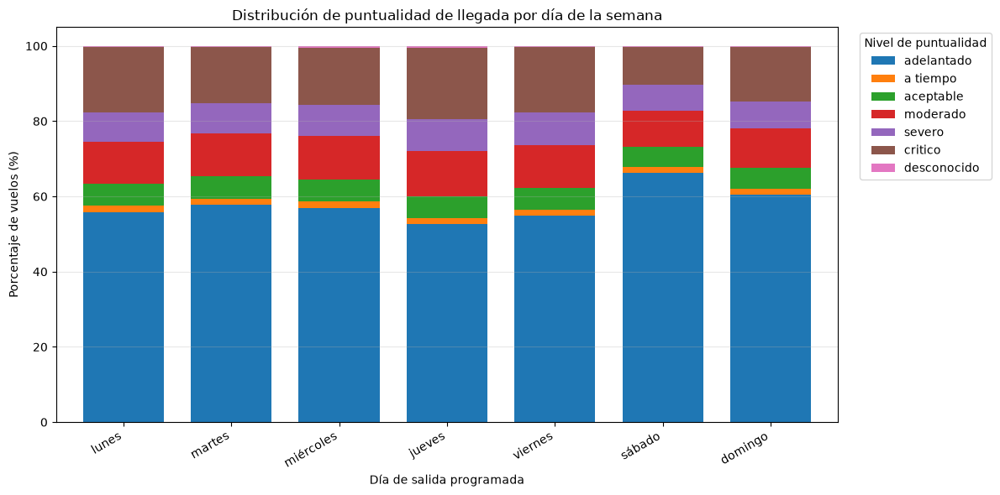

Resumen de vuelos y llegadas severas y críticas por día de la semana.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.
También se incluye el promedio diario de vuelos para comparar la actividad de cada día.


,vuelos_operados,dias_con_vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,vuelos_promedio_por_dia
_dia_semana,,,,,,,,,,
lunes,49470,52,49301,3950,8539,12489,8.01,17.32,25.33,951.35
martes,49270,53,49137,3914,7381,11295,7.97,15.02,22.99,929.62
miércoles,48858,52,48632,4018,7452,11470,8.26,15.32,23.59,939.58
jueves,48657,52,48445,4135,9265,13400,8.54,19.12,27.66,935.71
viernes,48700,52,48531,4196,8483,12679,8.65,17.48,26.13,936.54
sábado,37923,52,37794,2579,3814,6393,6.82,10.09,16.92,729.29
domingo,45643,52,45506,3339,6565,9904,7.34,14.43,21.76,877.75


Gráfico 2: cantidad de llegadas severas y críticas por día de la semana.
Muestra los casos absolutos y permite identificar qué días concentran más demoras graves.


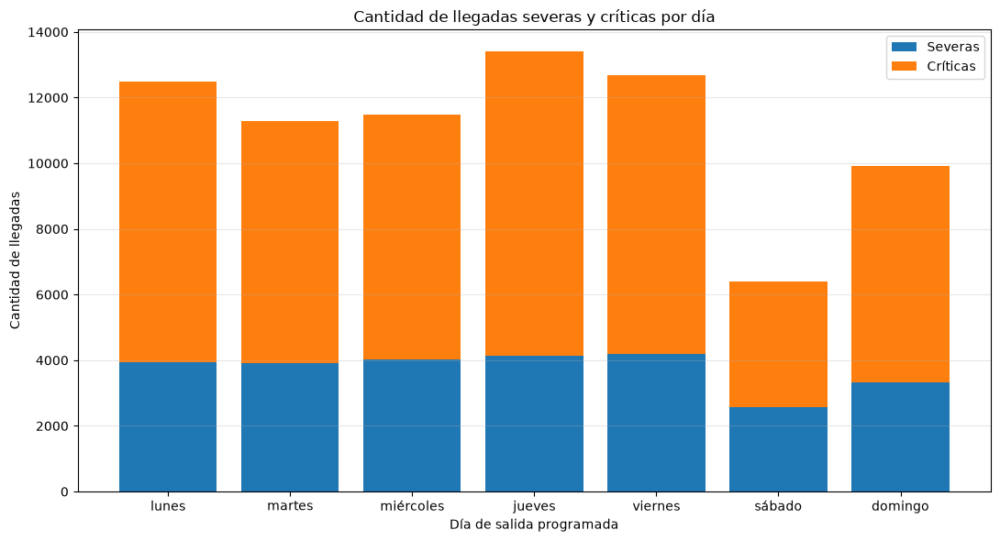

Gráfico 3: porcentaje de llegadas severas y críticas por día de la semana.
Es el gráfico principal para identificar qué días presentan peor puntualidad, independientemente de la cantidad de vuelos.


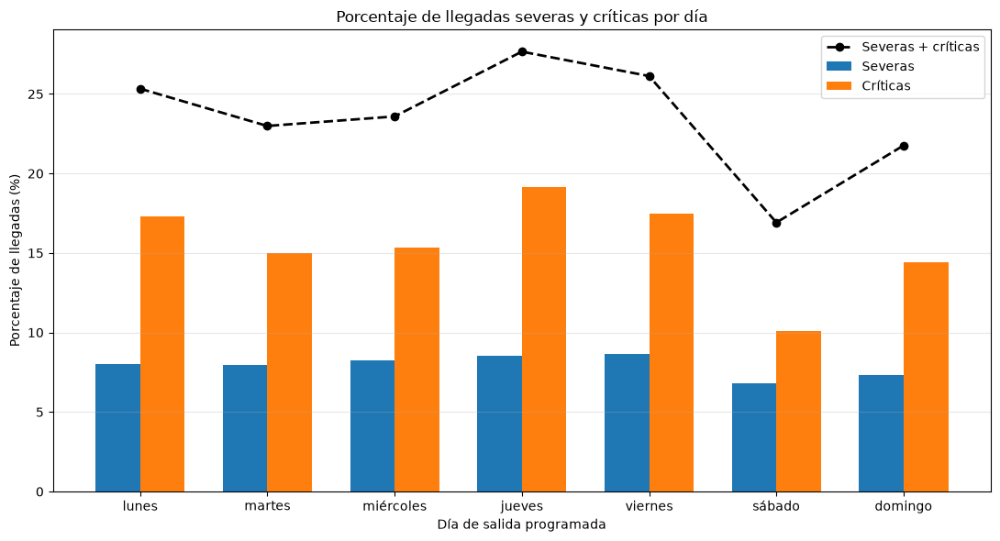

Gráfico 4: relación entre el promedio diario de vuelos y el porcentaje de llegadas severas y críticas.
Cada punto representa un día de la semana.
Permite observar si los días con mayor actividad también presentan una mayor proporción de demoras graves.


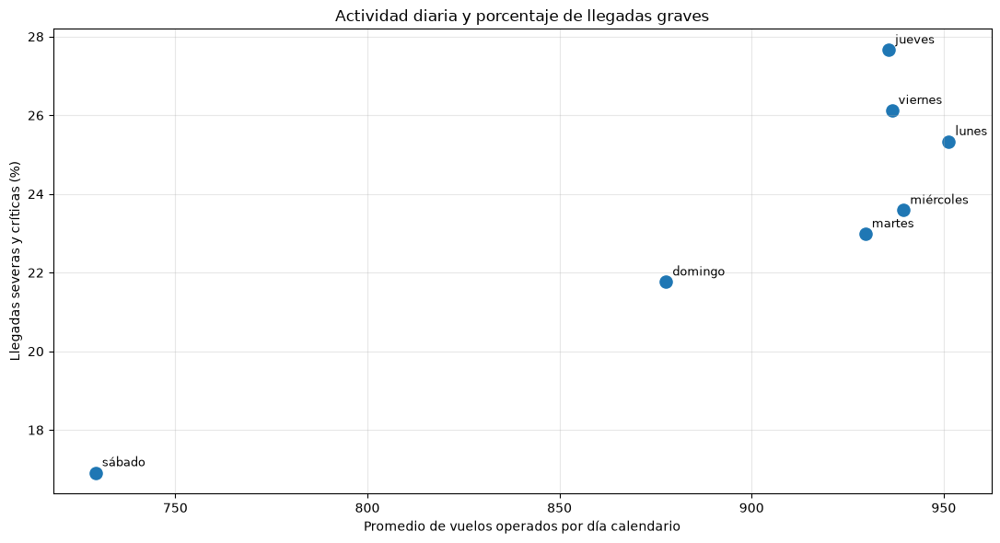

Comparación de puntualidad entre días hábiles y fines de semana.
Días hábiles: lunes a viernes.
Fin de semana: sábado y domingo.
Los porcentajes utilizan las llegadas evaluables como denominador.


,vuelos_operados,dias_con_vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,vuelos_promedio_por_dia
_grupo_dia,,,,,,,,,,
Día hábil,244955,261,244046,20213,41120,61333,8.28,16.85,25.13,938.52
Fin de semana,83566,104,83300,5918,10379,16297,7.10,12.46,19.56,803.52


Gráfico 5: porcentaje de llegadas severas y críticas entre días hábiles y fines de semana.
Permite identificar si existe una diferencia en la proporción de demoras graves entre ambos grupos.


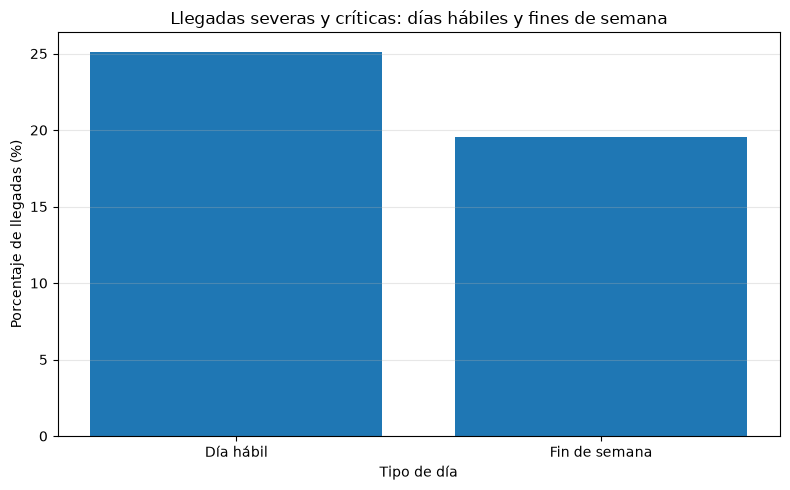

Días ordenados según el porcentaje de llegadas severas y críticas.


,vuelos_operados,dias_con_vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves,vuelos_promedio_por_dia
_dia_semana,,,,,,,,
jueves,48657,52,48445,4135,9265,13400,27.66,935.71
viernes,48700,52,48531,4196,8483,12679,26.13,936.54
lunes,49470,52,49301,3950,8539,12489,25.33,951.35
miércoles,48858,52,48632,4018,7452,11470,23.59,939.58
martes,49270,53,49137,3914,7381,11295,22.99,929.62
domingo,45643,52,45506,3339,6565,9904,21.76,877.75
sábado,37923,52,37794,2579,3814,6393,16.92,729.29


El día con mayor porcentaje de llegadas severas y críticas es jueves, con 27.66%.
El día con mayor cantidad de llegadas severas y críticas es jueves, con 13,400 vuelos.


In [91]:
# ==========================================================
# 6.3. PUNTUALIDAD SEGÚN EL DÍA DE LA SEMANA
# ==========================================================

# Orden cronológico de los días
orden_dias = [
    "lunes",
    "martes",
    "miércoles",
    "jueves",
    "viernes",
    "sábado",
    "domingo"
]

# Orden de los niveles de puntualidad
orden_niveles = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico",
    "desconocido"
]

# Categorías de llegada evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Trabajar únicamente con vuelos operados
# que tengan día de salida programada.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["dia_semana_salida_programada"].notna()) &
    (df["fecha_hora_salida_programada"].notna())
].copy()

# Establecer el orden de los días de la semana
base["_dia_semana"] = pd.Categorical(
    base["dia_semana_salida_programada"],
    categories=orden_dias,
    ordered=True
)

# Obtener la fecha programada sin la hora.
# Se utilizará para calcular el promedio de vuelos por día calendario.

base["_fecha_programada"] = (
    base["fecha_hora_salida_programada"].dt.normalize()
)

# Indicadores de puntualidad de llegada

base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

print("Preparación del análisis por día de la semana.")
print(f"Vuelos operados incluidos: {len(base):,}")


# ==========================================================
# 2. DISTRIBUCIÓN GENERAL DE PUNTUALIDAD POR DÍA
# ==========================================================

# Cantidad de vuelos por nivel de puntualidad y día
tabla_niveles = pd.crosstab(
    base["_dia_semana"],
    base["nivel_puntualidad_arribo"]
)

tabla_niveles = tabla_niveles.reindex(
    index=orden_dias,
    columns=orden_niveles,
    fill_value=0
)

# Porcentaje sobre todos los vuelos operados de cada día.
# Incluye "desconocido" para mostrar la distribución completa.

tabla_pct_niveles = (
    tabla_niveles
    .div(tabla_niveles.sum(axis=1), axis=0)
    .mul(100)
)

print("Distribución general de los niveles de puntualidad de llegada por día.")
print("Se incluyen todas las categorías, también 'desconocido'.")

display(tabla_niveles)

print("Distribución porcentual de los niveles de puntualidad por día.")
print("Cada fila representa un día de la semana y permite comparar la distribución de sus categorías.")

display(tabla_pct_niveles.round(2))


# Gráfico 1: distribución porcentual de todos los niveles

print("Gráfico 1: distribución porcentual de los niveles de puntualidad de llegada según el día de la semana.")
print("Permite observar cómo se distribuyen las categorías de puntualidad durante los distintos días.")

ax = tabla_pct_niveles.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.75
)

ax.set_title("Distribución de puntualidad de llegada por día de la semana")
ax.set_xlabel("Día de salida programada")
ax.set_ylabel("Porcentaje de vuelos (%)")
ax.set_xticklabels(orden_dias, rotation=30, ha="right")

ax.legend(
    title="Nivel de puntualidad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. RESUMEN DE LLEGADAS SEVERAS Y CRÍTICAS POR DÍA
# ==========================================================

resumen_dias = (
    base.groupby("_dia_semana", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        dias_con_vuelos=("_fecha_programada", "nunique"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_dias)
)

# Porcentajes sobre las llegadas evaluables

resumen_dias["pct_severas"] = (
    resumen_dias["llegadas_severas"] /
    resumen_dias["llegadas_evaluables"] * 100
)

resumen_dias["pct_criticas"] = (
    resumen_dias["llegadas_criticas"] /
    resumen_dias["llegadas_evaluables"] * 100
)

resumen_dias["pct_graves"] = (
    resumen_dias["llegadas_graves"] /
    resumen_dias["llegadas_evaluables"] * 100
)

# Promedio de vuelos por día calendario.
# Esto contempla que un mismo día de la semana aparece
# 52 o 53 veces durante el año.

resumen_dias["vuelos_promedio_por_dia"] = (
    resumen_dias["vuelos_operados"] /
    resumen_dias["dias_con_vuelos"]
)

print("Resumen de vuelos y llegadas severas y críticas por día de la semana.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.")
print("También se incluye el promedio diario de vuelos para comparar la actividad de cada día.")

display(resumen_dias.round(2))


# ==========================================================
# 4. CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS POR DÍA
# ==========================================================

print("Gráfico 2: cantidad de llegadas severas y críticas por día de la semana.")
print("Muestra los casos absolutos y permite identificar qué días concentran más demoras graves.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_dias))

severas = resumen_dias["llegadas_severas"].values
criticas = resumen_dias["llegadas_criticas"].values

ax.bar(
    x,
    severas,
    label="Severas"
)

ax.bar(
    x,
    criticas,
    bottom=severas,
    label="Críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_dias)

ax.set_title("Cantidad de llegadas severas y críticas por día")
ax.set_xlabel("Día de salida programada")
ax.set_ylabel("Cantidad de llegadas")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS POR DÍA
# ==========================================================

print("Gráfico 3: porcentaje de llegadas severas y críticas por día de la semana.")
print("Es el gráfico principal para identificar qué días presentan peor puntualidad, independientemente de la cantidad de vuelos.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_dias))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_dias["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_dias["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_dias["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_dias)

ax.set_title("Porcentaje de llegadas severas y críticas por día")
ax.set_xlabel("Día de salida programada")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. VOLUMEN DE VUELOS Y PORCENTAJE DE DEMORAS GRAVES
# ==========================================================

print("Gráfico 4: relación entre el promedio diario de vuelos y el porcentaje de llegadas severas y críticas.")
print("Cada punto representa un día de la semana.")
print("Permite observar si los días con mayor actividad también presentan una mayor proporción de demoras graves.")

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    resumen_dias["vuelos_promedio_por_dia"],
    resumen_dias["pct_graves"],
    s=90
)

# Identificar cada punto con el día correspondiente

for dia, fila in resumen_dias.iterrows():
    ax.annotate(
        dia,
        (
            fila["vuelos_promedio_por_dia"],
            fila["pct_graves"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Actividad diaria y porcentaje de llegadas graves")
ax.set_xlabel("Promedio de vuelos operados por día calendario")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 7. COMPARACIÓN ENTRE DÍAS HÁBILES Y FINES DE SEMANA
# ==========================================================

# Agrupar los días:
# Lunes a viernes = Día hábil
# Sábado y domingo = Fin de semana

base["_grupo_dia"] = np.where(
    base["_dia_semana"].isin(["sábado", "domingo"]),
    "Fin de semana",
    "Día hábil"
)

orden_grupos = [
    "Día hábil",
    "Fin de semana"
]

base["_grupo_dia"] = pd.Categorical(
    base["_grupo_dia"],
    categories=orden_grupos,
    ordered=True
)

# Resumen de cada grupo

resumen_grupos = (
    base.groupby("_grupo_dia", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        dias_con_vuelos=("_fecha_programada", "nunique"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_grupos)
)

# Porcentajes de llegadas graves

resumen_grupos["pct_severas"] = (
    resumen_grupos["llegadas_severas"] /
    resumen_grupos["llegadas_evaluables"] * 100
)

resumen_grupos["pct_criticas"] = (
    resumen_grupos["llegadas_criticas"] /
    resumen_grupos["llegadas_evaluables"] * 100
)

resumen_grupos["pct_graves"] = (
    resumen_grupos["llegadas_graves"] /
    resumen_grupos["llegadas_evaluables"] * 100
)

# Promedio diario de vuelos para hacer más justa
# la comparación entre grupos de distinta cantidad de días.

resumen_grupos["vuelos_promedio_por_dia"] = (
    resumen_grupos["vuelos_operados"] /
    resumen_grupos["dias_con_vuelos"]
)

print("Comparación de puntualidad entre días hábiles y fines de semana.")
print("Días hábiles: lunes a viernes.")
print("Fin de semana: sábado y domingo.")
print("Los porcentajes utilizan las llegadas evaluables como denominador.")

display(resumen_grupos.round(2))


# Gráfico 5: comparación de demoras graves entre grupos

print("Gráfico 5: porcentaje de llegadas severas y críticas entre días hábiles y fines de semana.")
print("Permite identificar si existe una diferencia en la proporción de demoras graves entre ambos grupos.")

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    resumen_grupos.index.astype(str),
    resumen_grupos["pct_graves"]
)

ax.set_title("Llegadas severas y críticas: días hábiles y fines de semana")
ax.set_xlabel("Tipo de día")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 8. IDENTIFICAR LOS DÍAS MÁS PROBLEMÁTICOS
# ==========================================================

# Ordenar por porcentaje de llegadas graves

top_dias_porcentaje = (
    resumen_dias
    .sort_values("pct_graves", ascending=False)
)

print("Días ordenados según el porcentaje de llegadas severas y críticas.")

display(
    top_dias_porcentaje[
        [
            "vuelos_operados",
            "dias_con_vuelos",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves",
            "vuelos_promedio_por_dia"
        ]
    ].round(2)
)


# Identificar el día con mayor porcentaje de demoras graves

dia_mayor_porcentaje = resumen_dias["pct_graves"].idxmax()

print(
    f"El día con mayor porcentaje de llegadas severas y críticas "
    f"es {dia_mayor_porcentaje}, con "
    f"{resumen_dias.loc[dia_mayor_porcentaje, 'pct_graves']:.2f}%."
)


# Identificar el día con mayor cantidad absoluta de demoras graves

dia_mayor_cantidad = resumen_dias["llegadas_graves"].idxmax()

print(
    f"El día con mayor cantidad de llegadas severas y críticas "
    f"es {dia_mayor_cantidad}, con "
    f"{int(resumen_dias.loc[dia_mayor_cantidad, 'llegadas_graves']):,} vuelos."
)

#### 6.4. Puntualidad según la semana y el día dentro de cada mes

Profundizar el análisis temporal observando cómo se distribuyen las demoras dentro de cada mes.

Se analizarán dos dimensiones:

- **Semana del mes:** primera, segunda, tercera, cuarta y quinta semana, según el día del calendario (del 1 al 7, del 8 al 14, del 15 al 21, del 22 al 28 y del 29 al 31).
- **Día del mes:** comparar los días del 1 al 31 para identificar posibles patrones en fechas específicas.

Preguntas que podemos investigar:

- ¿Hay semanas del mes con mayor proporción de llegadas severas y críticas?
- ¿El comportamiento cambia según la semana dentro de cada mes?
- ¿Existen días del mes que presentan reiteradamente más demoras?
- ¿Se observan patrones similares en distintos meses?

Preparación del análisis por semana y día del mes.
Vuelos operados incluidos: 328,521
Se utilizan las fechas de salida programadas.
Resumen de puntualidad según la semana del mes.
Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.


,vuelos_operados,fechas_con_vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,vuelos_por_fecha
_semana_mes,,,,,,,,,,
Semana 1 (1-7),75489,84,75236,5554,10037,15591,7.38,13.34,20.72,898.68
Semana 2 (8-14),74650,84,74304,6350,14048,20398,8.55,18.91,27.45,888.69
Semana 3 (15-21),77054,84,76802,6189,10744,16933,8.06,13.99,22.05,917.31
Semana 4 (22-28),75282,84,75027,6214,13548,19762,8.28,18.06,26.34,896.21
Semana 5 (29-31),26046,29,25977,1824,3122,4946,7.02,12.02,19.04,898.14


Gráfico 1: porcentaje de llegadas severas y críticas según la semana del mes.
Permite identificar si alguna de las cinco partes del mes presenta una mayor proporción de demoras graves.


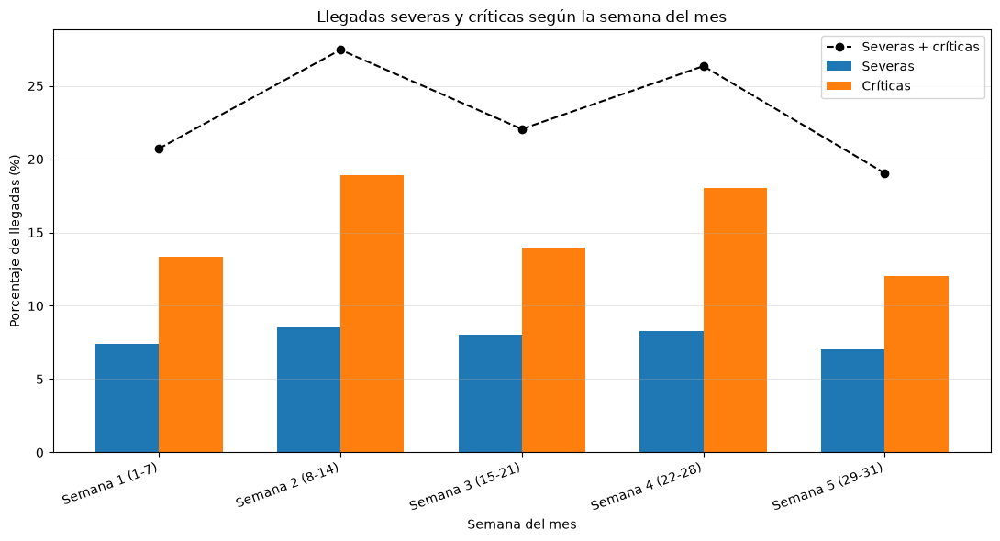

Porcentaje de llegadas severas y críticas según el mes y la semana del mes.
Cada celda representa el porcentaje de llegadas graves para esa combinación.


_semana_mes,Semana 1 (1-7),Semana 2 (8-14),Semana 3 (15-21),Semana 4 (22-28),Semana 5 (29-31)
_mes,,,,,
Enero,21.30,15.24,23.25,27.06,32.84
Febrero,19.65,26.31,21.01,25.29,NaN
Marzo,19.52,28.47,28.82,19.93,9.78
Abril,20.10,28.92,28.06,39.08,13.99
Mayo,12.67,26.41,22.74,28.60,17.61
Junio,24.98,31.51,25.17,39.29,40.79
Julio,31.28,36.84,25.75,37.68,19.57
Agosto,25.97,39.83,12.48,20.86,14.63
Septiembre,12.70,20.82,10.71,10.32,8.76


Gráfico 2: mapa de calor de las llegadas severas y críticas por mes y semana.
Permite identificar combinaciones de mes y semana con porcentajes elevados.


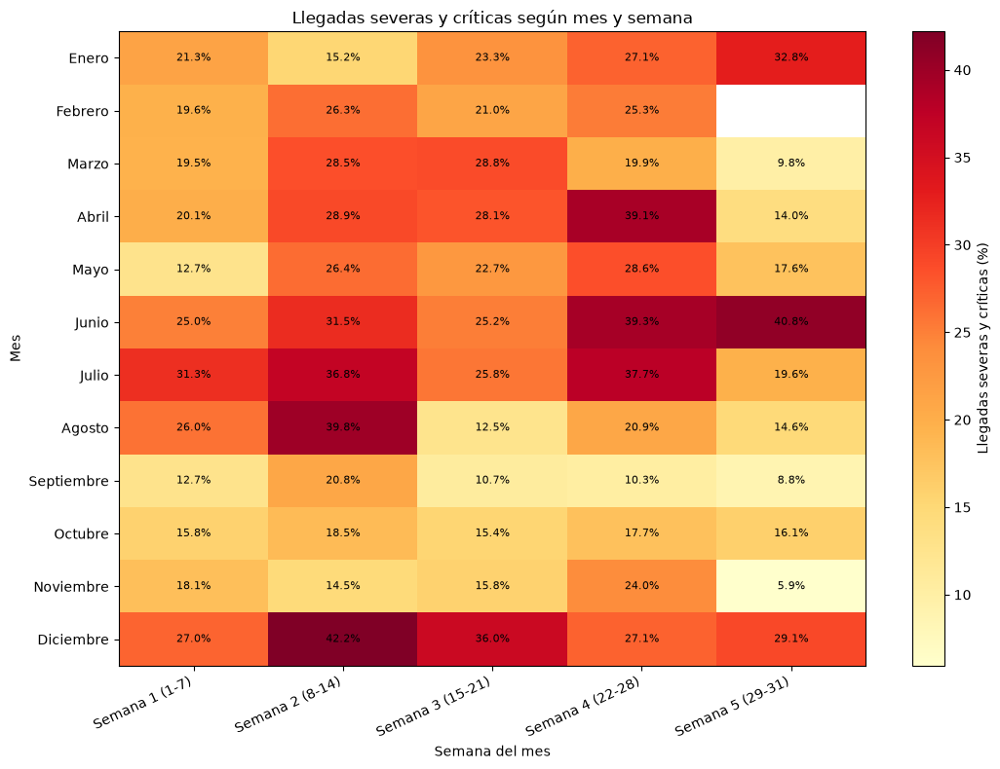

Resumen de puntualidad según el número de día del mes.
Se agrupan los días 1 al 31 de todos los meses.
También se muestra en cuántos meses aparece cada número de día.


,vuelos_operados,fechas_con_vuelos,meses_con_operaciones,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,vuelos_por_fecha
dia_del_mes,,,,,,,,,,,
1,10790,12,12,10748,858,1834,2692,7.98,17.06,25.05,899.17
2,10558,12,12,10524,734,1628,2362,6.97,15.47,22.44,879.83
3,11102,12,12,11070,964,1476,2440,8.71,13.33,22.04,925.17
4,10977,12,12,10949,790,1012,1802,7.22,9.24,16.46,914.75
5,10632,12,12,10609,712,1087,1799,6.71,10.25,16.96,886.00
6,10763,12,12,10725,679,1067,1746,6.33,9.95,16.28,896.92
7,10667,12,12,10611,817,1933,2750,7.70,18.22,25.92,888.92
8,10350,12,12,10308,813,2503,3316,7.89,24.28,32.17,862.50
9,10264,12,12,10231,805,1888,2693,7.87,18.45,26.32,855.33


Gráfico 3: porcentaje de llegadas severas y críticas según el día del mes.
Permite observar si determinados números de día presentan una mayor proporción de demoras graves.
Las marcas con menos de 30 llegadas evaluables se muestran de manera diferenciada.


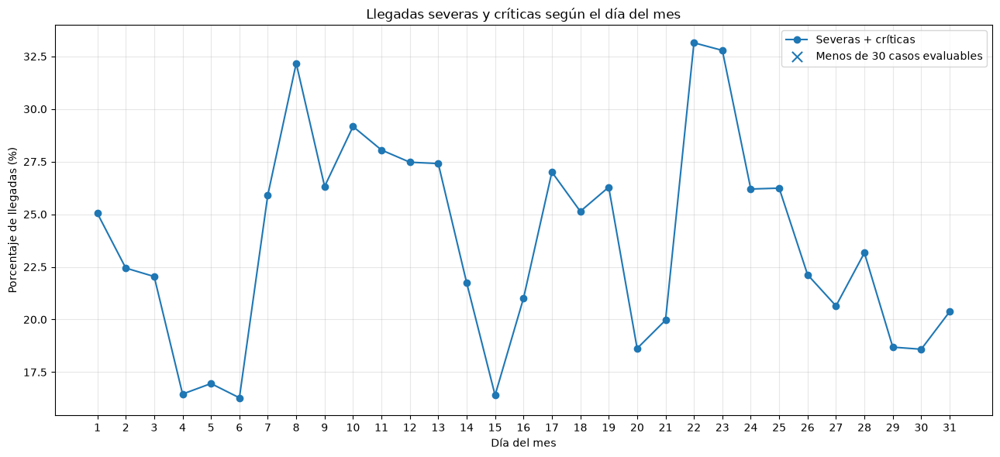

Tabla de porcentajes de llegadas severas y críticas según el mes y el día del mes.
Las celdas sin datos corresponden a fechas inexistentes o con menos de 30 llegadas evaluables.


_dia_mes,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
_mes,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Enero,29.48,29.20,26.11,16.85,12.83,22.20,11.51,12.11,14.56,9.04,12.43,6.75,31.23,20.26,17.14,55.80,21.53,16.15,8.20,17.03,23.95,30.40,21.17,33.92,38.23,19.23,16.87,26.72,11.51,40.70,47.44
Febrero,22.03,12.70,19.77,23.86,24.40,14.80,18.27,47.25,23.02,23.72,46.70,15.38,15.32,21.85,18.50,22.83,18.31,14.67,27.83,19.51,25.64,31.06,32.20,16.11,17.48,21.96,48.62,11.44,NaN,NaN,NaN
Marzo,19.70,20.16,13.34,13.69,11.79,24.53,35.19,79.20,12.90,17.52,18.28,37.85,16.72,22.24,19.07,33.51,21.38,46.16,45.14,18.70,19.65,21.09,33.82,29.36,29.97,8.28,8.32,13.32,7.42,6.40,15.25
Abril,30.66,21.43,17.00,20.55,25.03,11.99,11.91,9.29,18.48,36.35,39.14,53.72,21.93,24.07,14.78,14.41,23.63,47.78,49.66,24.40,22.77,57.31,45.83,39.06,57.29,45.81,7.55,13.20,17.30,10.60,NaN
Mayo,10.50,11.84,21.39,13.28,10.79,13.55,7.28,52.30,33.78,28.00,35.99,12.04,15.02,10.97,17.34,20.61,20.41,7.64,39.78,26.76,24.37,42.48,59.79,42.90,16.30,8.24,9.51,19.96,19.92,19.51,13.38
Junio,7.61,36.91,41.11,16.11,11.69,17.86,42.54,14.64,16.81,44.16,22.87,15.84,69.47,35.86,15.40,16.70,44.83,47.92,25.39,10.03,15.31,11.18,26.97,48.22,50.53,42.25,44.47,48.61,30.09,51.03,NaN
Julio,66.36,34.16,34.91,8.19,11.37,11.55,44.53,44.34,45.10,48.11,33.05,39.37,33.67,13.96,12.82,21.79,24.54,32.75,30.81,27.04,31.45,50.47,54.35,32.52,33.47,28.76,16.04,48.71,28.02,16.02,14.79
Agosto,50.27,26.97,24.09,21.44,17.45,12.47,29.88,58.13,56.71,22.79,26.52,25.13,54.18,34.21,17.91,13.65,10.81,12.91,12.45,10.37,8.87,51.90,15.77,6.87,7.56,8.63,9.29,44.35,21.81,10.48,10.12
Septiembre,10.96,44.11,14.85,5.87,5.49,4.37,4.23,8.20,7.89,11.81,28.81,51.24,33.13,6.46,7.86,11.19,6.47,6.19,19.27,12.86,10.87,16.29,13.27,7.27,9.02,10.48,9.19,5.63,11.21,6.49,NaN


Gráfico 4: mapa de calor de las llegadas severas y críticas según el mes y el día del mes.
Permite observar cómo se distribuyen los porcentajes en las distintas fechas de 2013.


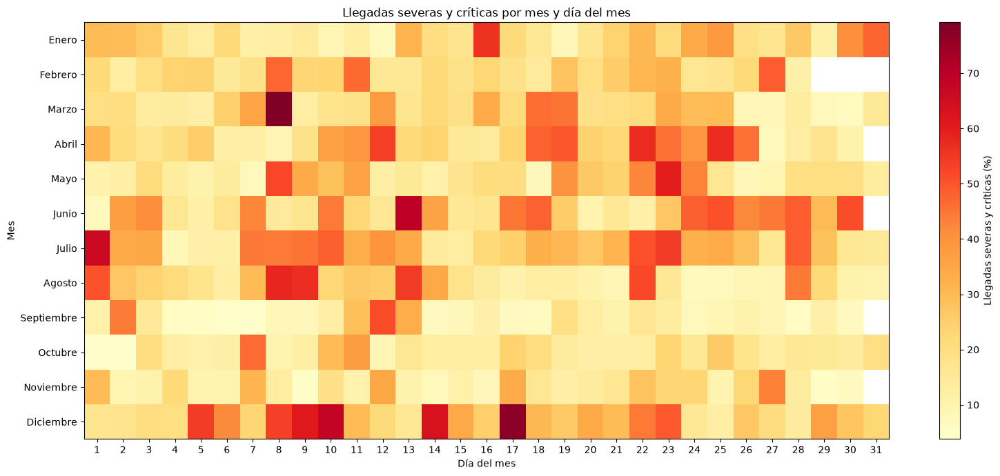

Los 10 números de día con mayor porcentaje de llegadas severas y críticas (mínimo 30 casos evaluables).


,vuelos_operados,meses_con_operaciones,fechas_con_vuelos,llegadas_evaluables,llegadas_graves,pct_graves
dia_del_mes,,,,,,
22,11041,12,12,10985,3641,33.15
23,10552,12,12,10511,3446,32.78
8,10350,12,12,10308,3316,32.17
10,10692,12,12,10614,3096,29.17
11,11016,12,12,10983,3081,28.05
12,10632,12,12,10556,2900,27.47
13,10869,12,12,10818,2965,27.41
17,10994,12,12,10961,2960,27.00
9,10264,12,12,10231,2693,26.32


Semanas del mes ordenadas según el porcentaje de llegadas severas y críticas.


,vuelos_operados,fechas_con_vuelos,llegadas_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_graves
_semana_mes,,,,,,,
Semana 2 (8-14),74650,84,74304,6350,14048,20398,27.45
Semana 4 (22-28),75282,84,75027,6214,13548,19762,26.34
Semana 3 (15-21),77054,84,76802,6189,10744,16933,22.05
Semana 1 (1-7),75489,84,75236,5554,10037,15591,20.72
Semana 5 (29-31),26046,29,25977,1824,3122,4946,19.04


In [92]:
# ==========================================================
# 6.4. PUNTUALIDAD SEGÚN LA SEMANA Y EL DÍA DENTRO DEL MES
# ==========================================================

MIN_EVALUABLES = 30

orden_meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

nombres_meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

orden_semanas = [
    "Semana 1 (1-7)",
    "Semana 2 (8-14)",
    "Semana 3 (15-21)",
    "Semana 4 (22-28)",
    "Semana 5 (29-31)"
]

niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Utilizar únicamente vuelos operados con fecha programada.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["mes_salida_programado"].notna()) &
    (df["dia_salida_programado"].notna()) &
    (df["fecha_hora_salida_programada"].notna())
].copy()

# Convertir mes y día a valores numéricos
base["_mes_num"] = pd.to_numeric(
    base["mes_salida_programado"],
    errors="coerce"
)

base["_dia_mes"] = pd.to_numeric(
    base["dia_salida_programado"],
    errors="coerce"
)

# Conservar únicamente valores válidos
base = base.loc[
    base["_mes_num"].between(1, 12) &
    base["_dia_mes"].between(1, 31)
].copy()

base["_mes_num"] = base["_mes_num"].astype(int)
base["_dia_mes"] = base["_dia_mes"].astype(int)

# Nombre del mes
base["_mes"] = base["_mes_num"].map(nombres_meses)

base["_mes"] = pd.Categorical(
    base["_mes"],
    categories=orden_meses,
    ordered=True
)

# Fecha programada sin hora, para contar fechas calendario
base["_fecha_programada"] = (
    base["fecha_hora_salida_programada"].dt.normalize()
)

# Indicadores de puntualidad de llegada
base["_arribo_evaluable"] = (
    base["nivel_puntualidad_arribo"].isin(niveles_evaluables)
)

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Clasificar los días según la semana del mes.
# Los intervalos son:
# 1 a 7, 8 a 14, 15 a 21, 22 a 28 y 29 a 31.

base["_semana_mes"] = pd.cut(
    base["_dia_mes"],
    bins=[0, 7, 14, 21, 28, 31],
    labels=orden_semanas,
    right=True,
    include_lowest=True
)

print("Preparación del análisis por semana y día del mes.")
print(f"Vuelos operados incluidos: {len(base):,}")
print("Se utilizan las fechas de salida programadas.")


# ==========================================================
# 2. PUNTUALIDAD SEGÚN LA SEMANA DEL MES
# ==========================================================

resumen_semanas = (
    base.groupby("_semana_mes", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        fechas_con_vuelos=("_fecha_programada", "nunique"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_semanas)
)

# Porcentajes sobre las llegadas evaluables

resumen_semanas["pct_severas"] = (
    resumen_semanas["llegadas_severas"] /
    resumen_semanas["llegadas_evaluables"] * 100
)

resumen_semanas["pct_criticas"] = (
    resumen_semanas["llegadas_criticas"] /
    resumen_semanas["llegadas_evaluables"] * 100
)

resumen_semanas["pct_graves"] = (
    resumen_semanas["llegadas_graves"] /
    resumen_semanas["llegadas_evaluables"] * 100
)

# Promedio de vuelos por fecha calendario
resumen_semanas["vuelos_por_fecha"] = (
    resumen_semanas["vuelos_operados"] /
    resumen_semanas["fechas_con_vuelos"]
)

print("Resumen de puntualidad según la semana del mes.")
print("Los porcentajes se calculan sobre las llegadas evaluables, excluyendo 'desconocido'.")

display(resumen_semanas.round(2))


# ----------------------------------------------------------
# Gráfico 1: porcentaje de llegadas graves por semana
# ----------------------------------------------------------

print("Gráfico 1: porcentaje de llegadas severas y críticas según la semana del mes.")
print("Permite identificar si alguna de las cinco partes del mes presenta una mayor proporción de demoras graves.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_semanas))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_semanas["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_semanas["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_semanas["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_semanas, rotation=20, ha="right")

ax.set_title("Llegadas severas y críticas según la semana del mes")
ax.set_xlabel("Semana del mes")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. COMPARACIÓN DE SEMANAS DENTRO DE CADA MES
# ==========================================================

# Agrupar por mes y semana del mes.
# Esto permite observar si el comportamiento de una semana
# cambia según el mes del año.

resumen_mes_semana = (
    base.groupby(
        ["_mes", "_semana_mes"],
        observed=False
    )
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_mes_semana["pct_graves"] = (
    resumen_mes_semana["llegadas_graves"] /
    resumen_mes_semana["llegadas_evaluables"] * 100
)

# Tabla de porcentajes: filas = meses, columnas = semanas

tabla_mes_semana = (
    resumen_mes_semana
    .pivot(
        index="_mes",
        columns="_semana_mes",
        values="pct_graves"
    )
    .reindex(
        index=orden_meses,
        columns=orden_semanas
    )
)

print("Porcentaje de llegadas severas y críticas según el mes y la semana del mes.")
print("Cada celda representa el porcentaje de llegadas graves para esa combinación.")

display(tabla_mes_semana.round(2))


# ----------------------------------------------------------
# Gráfico 2: mapa de calor mes vs. semana
# ----------------------------------------------------------

print("Gráfico 2: mapa de calor de las llegadas severas y críticas por mes y semana.")
print("Permite identificar combinaciones de mes y semana con porcentajes elevados.")

matriz = np.ma.masked_invalid(tabla_mes_semana.values)

fig, ax = plt.subplots(figsize=(11, 8))

imagen = ax.imshow(
    matriz,
    cmap="YlOrRd",
    aspect="auto"
)

ax.set_xticks(range(len(orden_semanas)))
ax.set_xticklabels(orden_semanas, rotation=25, ha="right")

ax.set_yticks(range(len(orden_meses)))
ax.set_yticklabels(orden_meses)

ax.set_title("Llegadas severas y críticas según mes y semana")
ax.set_xlabel("Semana del mes")
ax.set_ylabel("Mes")

# Mostrar los porcentajes dentro de cada celda.
for i in range(len(orden_meses)):
    for j in range(len(orden_semanas)):
        valor = tabla_mes_semana.iloc[i, j]

        if pd.notna(valor):
            ax.text(
                j,
                i,
                f"{valor:.1f}%",
                ha="center",
                va="center",
                fontsize=8
            )

fig.colorbar(
    imagen,
    ax=ax,
    label="Llegadas severas y críticas (%)"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. PUNTUALIDAD SEGÚN EL DÍA DEL MES (1 AL 31)
# ==========================================================

resumen_dias_mes = (
    base.groupby("_dia_mes")
    .agg(
        vuelos_operados=("id", "size"),
        fechas_con_vuelos=("_fecha_programada", "nunique"),
        meses_con_operaciones=("_mes_num", "nunique"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(range(1, 32))
)

# Completar con cero las cantidades de los días sin registros
columnas_conteo = [
    "vuelos_operados",
    "fechas_con_vuelos",
    "meses_con_operaciones",
    "llegadas_evaluables",
    "llegadas_severas",
    "llegadas_criticas",
    "llegadas_graves"
]

resumen_dias_mes[columnas_conteo] = (
    resumen_dias_mes[columnas_conteo].fillna(0)
)

# Porcentajes sobre las llegadas evaluables

resumen_dias_mes["pct_severas"] = (
    resumen_dias_mes["llegadas_severas"] /
    resumen_dias_mes["llegadas_evaluables"] * 100
)

resumen_dias_mes["pct_criticas"] = (
    resumen_dias_mes["llegadas_criticas"] /
    resumen_dias_mes["llegadas_evaluables"] * 100
)

resumen_dias_mes["pct_graves"] = (
    resumen_dias_mes["llegadas_graves"] /
    resumen_dias_mes["llegadas_evaluables"] * 100
)

# Promedio de vuelos por fecha calendario
resumen_dias_mes["vuelos_por_fecha"] = (
    resumen_dias_mes["vuelos_operados"] /
    resumen_dias_mes["fechas_con_vuelos"]
)

resumen_dias_mes.index.name = "dia_del_mes"

print("Resumen de puntualidad según el número de día del mes.")
print("Se agrupan los días 1 al 31 de todos los meses.")
print("También se muestra en cuántos meses aparece cada número de día.")

display(resumen_dias_mes.round(2))


# ----------------------------------------------------------
# Gráfico 3: porcentaje de llegadas graves por día del mes
# ----------------------------------------------------------

print("Gráfico 3: porcentaje de llegadas severas y críticas según el día del mes.")
print("Permite observar si determinados números de día presentan una mayor proporción de demoras graves.")
print(f"Las marcas con menos de {MIN_EVALUABLES} llegadas evaluables se muestran de manera diferenciada.")

# Separar días con muestra suficiente e insuficiente
dias_suficientes = resumen_dias_mes.loc[
    resumen_dias_mes["llegadas_evaluables"] >= MIN_EVALUABLES
]

dias_insuficientes = resumen_dias_mes.loc[
    (resumen_dias_mes["llegadas_evaluables"] < MIN_EVALUABLES) &
    (resumen_dias_mes["llegadas_evaluables"] > 0)
]

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    dias_suficientes.index,
    dias_suficientes["pct_graves"],
    marker="o",
    label="Severas + críticas"
)

ax.scatter(
    dias_insuficientes.index,
    dias_insuficientes["pct_graves"],
    marker="x",
    s=90,
    label=f"Menos de {MIN_EVALUABLES} casos evaluables"
)

ax.set_title("Llegadas severas y críticas según el día del mes")
ax.set_xlabel("Día del mes")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.set_xticks(range(1, 32))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. COMPARACIÓN DEL DÍA DEL MES ENTRE LOS DISTINTOS MESES
# ==========================================================

# Agrupar por mes y número de día.
# Cada celda representa una fecha concreta del año 2013.

resumen_mes_dia = (
    base.groupby(
        ["_mes", "_dia_mes"],
        observed=True
    )
    .agg(
        vuelos_operados=("id", "size"),
        llegadas_evaluables=("_arribo_evaluable", "sum"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_mes_dia["pct_graves"] = (
    resumen_mes_dia["llegadas_graves"] /
    resumen_mes_dia["llegadas_evaluables"] * 100
)

# Tabla: filas = meses; columnas = días del mes

tabla_mes_dia = (
    resumen_mes_dia
    .pivot(
        index="_mes",
        columns="_dia_mes",
        values="pct_graves"
    )
    .reindex(
        index=orden_meses,
        columns=range(1, 32)
    )
)

# Evitar interpretar porcentajes con muy pocos casos.
tabla_conteos_mes_dia = (
    resumen_mes_dia
    .pivot(
        index="_mes",
        columns="_dia_mes",
        values="llegadas_evaluables"
    )
    .reindex(
        index=orden_meses,
        columns=range(1, 32)
    )
)

tabla_mes_dia = tabla_mes_dia.where(
    tabla_conteos_mes_dia >= MIN_EVALUABLES
)

print("Tabla de porcentajes de llegadas severas y críticas según el mes y el día del mes.")
print("Las celdas sin datos corresponden a fechas inexistentes o con menos de 30 llegadas evaluables.")

display(tabla_mes_dia.round(2))


# ----------------------------------------------------------
# Gráfico 4: mapa de calor mes vs. día del mes
# ----------------------------------------------------------

print("Gráfico 4: mapa de calor de las llegadas severas y críticas según el mes y el día del mes.")
print("Permite observar cómo se distribuyen los porcentajes en las distintas fechas de 2013.")

matriz_dias = np.ma.masked_invalid(tabla_mes_dia.values)

fig, ax = plt.subplots(figsize=(16, 7))

imagen = ax.imshow(
    matriz_dias,
    cmap="YlOrRd",
    aspect="auto"
)

ax.set_xticks(range(31))
ax.set_xticklabels(range(1, 32))

ax.set_yticks(range(len(orden_meses)))
ax.set_yticklabels(orden_meses)

ax.set_title("Llegadas severas y críticas por mes y día del mes")
ax.set_xlabel("Día del mes")
ax.set_ylabel("Mes")

fig.colorbar(
    imagen,
    ax=ax,
    label="Llegadas severas y críticas (%)"
)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. IDENTIFICAR LOS DÍAS DEL MES CON MAYOR PORCENTAJE
# ==========================================================

# Considerar únicamente días con una muestra suficiente
dias_comparables = resumen_dias_mes.loc[
    resumen_dias_mes["llegadas_evaluables"] >= MIN_EVALUABLES
].copy()

top_dias_mes = (
    dias_comparables
    .sort_values("pct_graves", ascending=False)
    .head(10)
)

print(
    f"Los 10 números de día con mayor porcentaje de llegadas severas "
    f"y críticas (mínimo {MIN_EVALUABLES} casos evaluables)."
)

display(
    top_dias_mes[
        [
            "vuelos_operados",
            "meses_con_operaciones",
            "fechas_con_vuelos",
            "llegadas_evaluables",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)


# ==========================================================
# 7. IDENTIFICAR LAS SEMANAS MÁS PROBLEMÁTICAS
# ==========================================================

semanas_ordenadas = (
    resumen_semanas
    .sort_values("pct_graves", ascending=False)
)

print("Semanas del mes ordenadas según el porcentaje de llegadas severas y críticas.")

display(
    semanas_ordenadas[
        [
            "vuelos_operados",
            "fechas_con_vuelos",
            "llegadas_evaluables",
            "llegadas_severas",
            "llegadas_criticas",
            "llegadas_graves",
            "pct_graves"
        ]
    ].round(2)
)

###
---
---
---

### 7. Análisis por efecto cascada (varios vuelos del mismo avión en el día)

Una aeronave puede realizar varios vuelos durante una misma jornada. Cuando uno de esos vuelos presenta demoras, existe la posibilidad de que afecte las operaciones posteriores de esa misma aeronave.

Por ejemplo, si un avión llega demorado a un aeropuerto, puede disponer de menos tiempo para realizar las tareas operativas necesarias antes de su siguiente salida. Esto podría trasladar parte de la demora al próximo vuelo y generar un efecto de arrastre durante el día.

El objetivo de este análisis es investigar si existe una relación entre la cantidad y el orden de los vuelos realizados por una misma aeronave, las demoras de sus vuelos anteriores y la puntualidad de sus vuelos posteriores.

Para ello, utilizaremos la matrícula del avión (`matricula_avion`), el orden real de sus operaciones diarias y las variables relacionadas con las demoras de vuelos anteriores y los intervalos entre salidas.


**Criterio de análisis:** se priorizarán las categorías `severo` y `critico`, tanto por separado como combinadas. Los porcentajes se calcularán sobre los vuelos operados con puntualidad de llegada evaluable, excluyendo la categoría `desconocido`.

También se tendrá en cuenta la cantidad de vuelos disponibles en cada grupo para evitar conclusiones basadas en muestras demasiado pequeñas.

**Conclusión del análisis:** se buscará determinar si existe evidencia de un efecto cascada en las operaciones de una misma aeronave, identificando si las demoras de vuelos anteriores, la secuencia de operaciones y el tiempo entre salidas están asociados con una peor puntualidad en los vuelos posteriores.

**Aplicación predictiva:** los resultados permitirán evaluar si la actividad previa de una aeronave aporta información útil para predecir demoras de llegada en sus próximas operaciones.

#### 7.1. Cantidad de vuelos realizados por aeronave durante el día

Analizar si la cantidad de vuelos que realiza una misma aeronave durante una jornada está relacionada con su puntualidad.

Preguntas que podemos investigar:

- ¿Las aeronaves que realizan más vuelos durante el día presentan una mayor proporción de llegadas severas y críticas?
- ¿Existe una diferencia de puntualidad entre los aviones que realizan pocos vuelos y los que realizan muchos?
- ¿A medida que aumenta la cantidad de operaciones diarias, empeora el comportamiento de las demoras?
- ¿Las aeronaves con mayor actividad concentran más casos de demoras graves?

Se agruparán las aeronaves según la cantidad de vuelos realizados durante cada día, comparando las cantidades y los porcentajes de llegadas severas y críticas.

Preparación del análisis de actividad diaria por aeronave.
Vuelos operados en el dataset: 328,521
Vuelos con matrícula y salida real disponibles: 328,521
Vuelos excluidos del conteo diario por falta de matrícula o fecha de salida real: 0
Vuelos utilizados para evaluar la puntualidad:
Vuelos con llegada evaluable: 327,346
Vuelos operados excluidos por tener llegada desconocida: 1,175
Resumen de actividad diaria y puntualidad según la cantidad de vuelos por aeronave.
Los porcentajes se calculan sobre las llegadas evaluables de cada grupo.


,vuelos_operados,matriculas,jornadas_aeronave_dia,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
_grupo_vuelos_dia,,,,,,,,,,
1 vuelo,186226,4029,186226,185515,14685,28177,42862,7.92,15.19,23.10
2 vuelos,97778,2880,48889,97437,7758,15581,23339,7.96,15.99,23.95
3 vuelos,34167,1283,11389,34059,2961,6159,9120,8.69,18.08,26.78
4 vuelos,9960,366,2490,9945,699,1463,2162,7.03,14.71,21.74
5 o más vuelos,390,46,78,390,28,119,147,7.18,30.51,37.69


Comparación complementaria: porcentaje de llegadas graves por jornada de aeronave.
La mediana representa el comportamiento central de las jornadas individuales de cada grupo.


,vuelos_operados,vuelos_evaluables,jornadas_aeronave_dia,pct_severas,pct_criticas,pct_graves,jornadas_evaluables,mediana_pct_graves_jornada,promedio_pct_graves_jornada
_grupo_vuelos_dia,,,,,,,,,
1 vuelo,186226,185515,186226,7.92,15.19,23.10,185515,0.00,23.10
2 vuelos,97778,97437,48889,7.96,15.99,23.95,48883,0.00,23.99
3 vuelos,34167,34059,11389,8.69,18.08,26.78,11389,33.33,26.83
4 vuelos,9960,9945,2490,7.03,14.71,21.74,2490,0.00,21.77
5 o más vuelos,390,390,78,7.18,30.51,37.69,78,40.00,37.69


Gráfico 1: cantidad de jornadas de aeronaves según el número de vuelos realizados.
Cada jornada representa una matrícula en una fecha determinada.
Permite conocer qué tan frecuentes son los distintos niveles de actividad diaria.


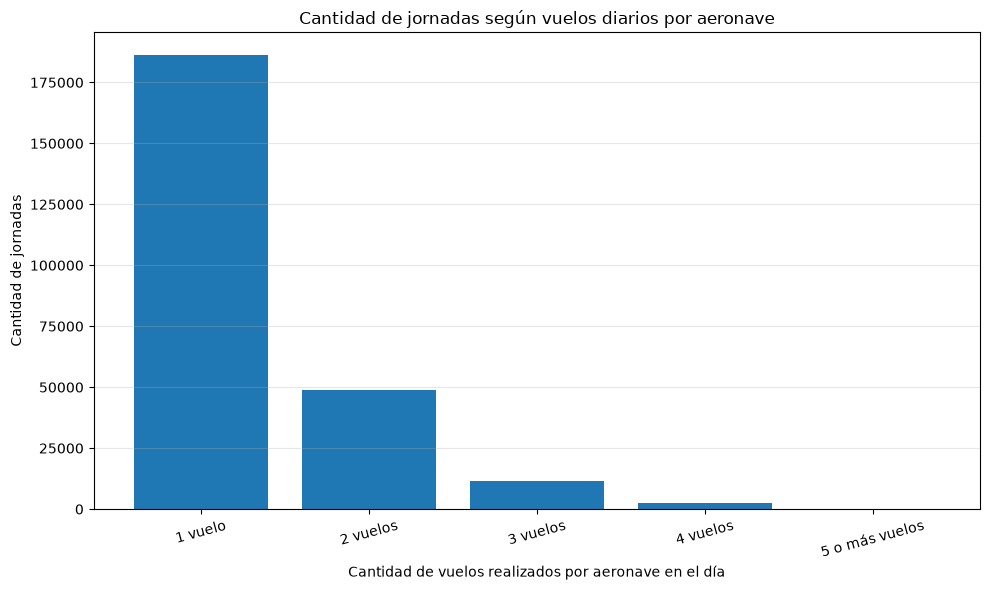

Gráfico 2: cantidad de llegadas severas y críticas según la actividad diaria de la aeronave.
Permite observar en qué grupos se concentran más casos absolutos de demoras graves.


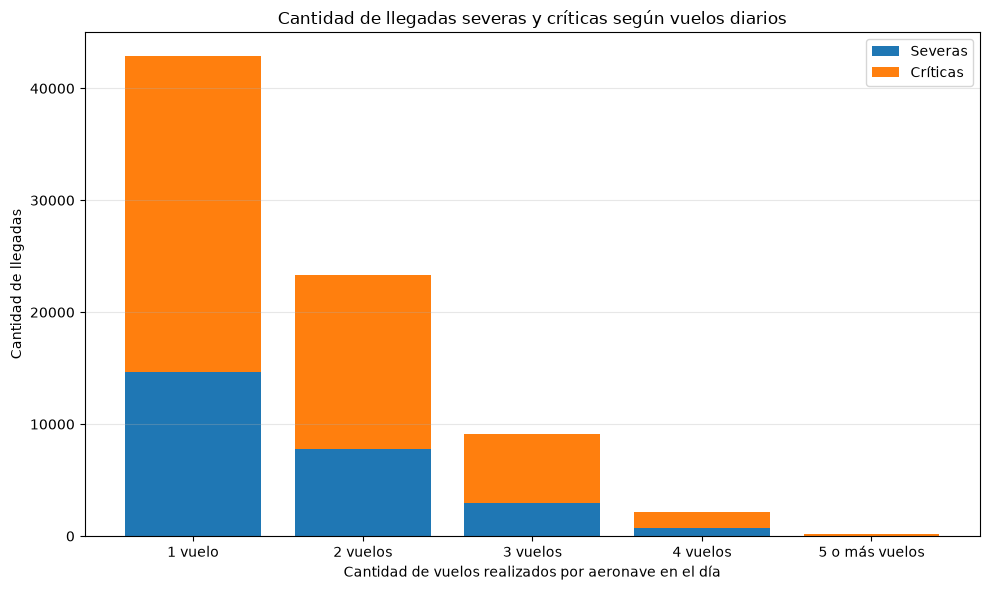

Gráfico 3: porcentaje de llegadas severas y críticas según la cantidad de vuelos diarios.
Es el gráfico principal para investigar si una mayor actividad diaria está asociada con una peor puntualidad.


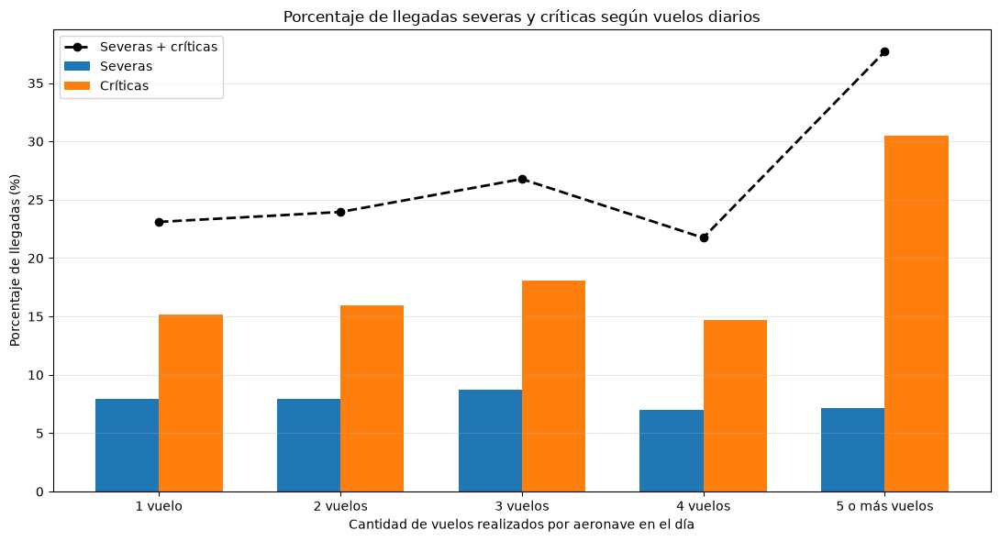

Gráfico 4: comparación entre el porcentaje de llegadas graves por vuelo y la mediana por jornada.
La primera línea da más peso a cada vuelo; la segunda considera el porcentaje de cada jornada de aeronave.
Permite comprobar si la conclusión se mantiene al dar el mismo peso a cada jornada.


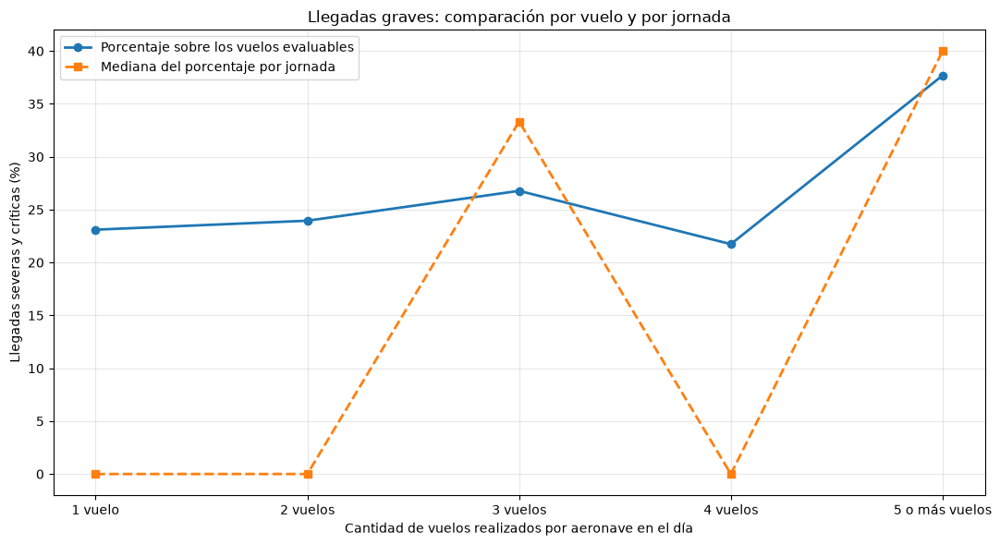

Grupo con mayor cantidad absoluta de llegadas severas y críticas: 1 vuelo
Grupo con mayor porcentaje de llegadas severas y críticas: 5 o más vuelos
Porcentaje de llegadas graves en ese grupo: 37.69%


In [93]:
# ==========================================================
# 7.1. CANTIDAD DE VUELOS REALIZADOS POR AERONAVE DURANTE EL DÍA
# ==========================================================

# Orden de los grupos de actividad
orden_grupos = [
    "1 vuelo",
    "2 vuelos",
    "3 vuelos",
    "4 vuelos",
    "5 o más vuelos"
]

# Categorías de puntualidad de llegada que se pueden evaluar
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Partimos de todos los vuelos operados.
operados = df.loc[
    df["estado_vuelo"] == "operado"
].copy()

# Para contar las operaciones diarias necesitamos:
# - matrícula identificada
# - fecha y hora real de salida disponibles

base_operados = operados.loc[
    operados["matricula_avion"].notna() &
    operados["fecha_hora_salida_real"].notna()
].copy()

# Obtener la fecha real de salida sin considerar la hora
base_operados["_fecha_operacion"] = (
    base_operados["fecha_hora_salida_real"].dt.normalize()
)

# Calcular cuántos vuelos realizó cada aeronave en cada día.
# Se cuentan todos los vuelos operados disponibles,
# aunque alguno tenga la puntualidad de llegada desconocida.

base_operados["_cantidad_vuelos_dia"] = (
    base_operados
    .groupby(
        ["matricula_avion", "_fecha_operacion"]
    )["id"]
    .transform("size")
)

# Clasificar las jornadas según la cantidad de vuelos realizados
base_operados["_grupo_vuelos_dia"] = pd.cut(
    base_operados["_cantidad_vuelos_dia"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=orden_grupos,
    right=True
)

print("Preparación del análisis de actividad diaria por aeronave.")
print(f"Vuelos operados en el dataset: {len(operados):,}")
print(f"Vuelos con matrícula y salida real disponibles: {len(base_operados):,}")
print(
    "Vuelos excluidos del conteo diario por falta de matrícula "
    "o fecha de salida real:",
    f"{len(operados) - len(base_operados):,}"
)


# ==========================================================
# 2. SELECCIONAR LOS VUELOS CON LLEGADA EVALUABLE
# ==========================================================

# Para analizar la puntualidad solamente utilizamos
# los vuelos cuya categoría de llegada se puede evaluar.

base = base_operados.loc[
    base_operados["nivel_puntualidad_arribo"].isin(niveles_evaluables)
].copy()

# Indicadores de llegada
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

print("Vuelos utilizados para evaluar la puntualidad:")
print(f"Vuelos con llegada evaluable: {len(base):,}")
print(
    "Vuelos operados excluidos por tener llegada desconocida:",
    f"{len(base_operados) - len(base):,}"
)


# ==========================================================
# 3. RESUMEN DE ACTIVIDAD DIARIA POR GRUPO
# ==========================================================

# Cantidad total de vuelos operados por grupo
resumen_operaciones = (
    base_operados
    .groupby("_grupo_vuelos_dia", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        matriculas=("matricula_avion", "nunique")
    )
)

# Cantidad de jornadas distintas de aeronave por grupo
# Una jornada representa una matrícula en una fecha determinada.

jornadas = (
    base_operados[
        [
            "matricula_avion",
            "_fecha_operacion",
            "_grupo_vuelos_dia"
        ]
    ]
    .drop_duplicates()
    .groupby("_grupo_vuelos_dia", observed=False)
    .size()
    .rename("jornadas_aeronave_dia")
)

# Resumen de puntualidad por grupo
resumen_puntualidad = (
    base.groupby("_grupo_vuelos_dia", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
)

# Unir actividad y puntualidad
resumen = (
    resumen_operaciones
    .join(jornadas)
    .join(resumen_puntualidad)
    .reindex(orden_grupos)
)

# Porcentajes sobre las llegadas evaluables
resumen["pct_severas"] = (
    resumen["llegadas_severas"] /
    resumen["vuelos_evaluables"] * 100
)

resumen["pct_criticas"] = (
    resumen["llegadas_criticas"] /
    resumen["vuelos_evaluables"] * 100
)

resumen["pct_graves"] = (
    resumen["llegadas_graves"] /
    resumen["vuelos_evaluables"] * 100
)

print("Resumen de actividad diaria y puntualidad según la cantidad de vuelos por aeronave.")
print("Los porcentajes se calculan sobre las llegadas evaluables de cada grupo.")

display(resumen.round(2))


# ==========================================================
# 4. PORCENTAJE DE DEMORAS GRAVES POR JORNADA DE AERONAVE
# ==========================================================

# Análisis complementario:
# calcular primero el porcentaje de llegadas graves de cada
# matrícula en cada día, y después resumir esos porcentajes
# dentro de cada grupo de actividad.

resumen_jornadas = (
    base.groupby(
        [
            "matricula_avion",
            "_fecha_operacion",
            "_grupo_vuelos_dia"
        ],
        observed=True
    )
    .agg(
        vuelos_evaluables=("_arribo_grave", "size"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_jornadas["pct_graves_jornada"] = (
    resumen_jornadas["llegadas_graves"] /
    resumen_jornadas["vuelos_evaluables"] * 100
)

# Mediana y promedio de los porcentajes de cada jornada
resumen_por_jornada = (
    resumen_jornadas
    .groupby("_grupo_vuelos_dia", observed=False)
    .agg(
        jornadas_evaluables=("pct_graves_jornada", "size"),
        mediana_pct_graves_jornada=("pct_graves_jornada", "median"),
        promedio_pct_graves_jornada=("pct_graves_jornada", "mean")
    )
    .reindex(orden_grupos)
)

resumen = resumen.join(resumen_por_jornada)

print("Comparación complementaria: porcentaje de llegadas graves por jornada de aeronave.")
print("La mediana representa el comportamiento central de las jornadas individuales de cada grupo.")

display(
    resumen[
        [
            "vuelos_operados",
            "vuelos_evaluables",
            "jornadas_aeronave_dia",
            "pct_severas",
            "pct_criticas",
            "pct_graves",
            "jornadas_evaluables",
            "mediana_pct_graves_jornada",
            "promedio_pct_graves_jornada"
        ]
    ].round(2)
)


# ==========================================================
# 5. CANTIDAD DE JORNADAS SEGÚN EL NÚMERO DE VUELOS
# ==========================================================

print("Gráfico 1: cantidad de jornadas de aeronaves según el número de vuelos realizados.")
print("Cada jornada representa una matrícula en una fecha determinada.")
print("Permite conocer qué tan frecuentes son los distintos niveles de actividad diaria.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    orden_grupos,
    resumen["jornadas_aeronave_dia"]
)

ax.set_title("Cantidad de jornadas según vuelos diarios por aeronave")
ax.set_xlabel("Cantidad de vuelos realizados por aeronave en el día")
ax.set_ylabel("Cantidad de jornadas")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. CANTIDAD DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

print("Gráfico 2: cantidad de llegadas severas y críticas según la actividad diaria de la aeronave.")
print("Permite observar en qué grupos se concentran más casos absolutos de demoras graves.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_grupos))

severas = resumen["llegadas_severas"].values
criticas = resumen["llegadas_criticas"].values

ax.bar(
    x,
    severas,
    label="Severas"
)

ax.bar(
    x,
    criticas,
    bottom=severas,
    label="Críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos)

ax.set_title("Cantidad de llegadas severas y críticas según vuelos diarios")
ax.set_xlabel("Cantidad de vuelos realizados por aeronave en el día")
ax.set_ylabel("Cantidad de llegadas")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 7. PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

print("Gráfico 3: porcentaje de llegadas severas y críticas según la cantidad de vuelos diarios.")
print("Es el gráfico principal para investigar si una mayor actividad diaria está asociada con una peor puntualidad.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_grupos))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos)

ax.set_title("Porcentaje de llegadas severas y críticas según vuelos diarios")
ax.set_xlabel("Cantidad de vuelos realizados por aeronave en el día")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 8. COMPARAR EL PORCENTAJE POR VUELO Y POR JORNADA
# ==========================================================

print("Gráfico 4: comparación entre el porcentaje de llegadas graves por vuelo y la mediana por jornada.")
print("La primera línea da más peso a cada vuelo; la segunda considera el porcentaje de cada jornada de aeronave.")
print("Permite comprobar si la conclusión se mantiene al dar el mismo peso a cada jornada.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_grupos))

ax.plot(
    x,
    resumen["pct_graves"],
    marker="o",
    linewidth=2,
    label="Porcentaje sobre los vuelos evaluables"
)

ax.plot(
    x,
    resumen["mediana_pct_graves_jornada"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Mediana del porcentaje por jornada"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos)

ax.set_title("Llegadas graves: comparación por vuelo y por jornada")
ax.set_xlabel("Cantidad de vuelos realizados por aeronave en el día")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 9. IDENTIFICAR LOS GRUPOS CON MAYOR ACTIVIDAD Y DEMORAS
# ==========================================================

grupo_mayor_cantidad = resumen["llegadas_graves"].idxmax()
grupo_mayor_porcentaje = resumen["pct_graves"].idxmax()

print(
    "Grupo con mayor cantidad absoluta de llegadas severas y críticas:",
    grupo_mayor_cantidad
)

print(
    "Grupo con mayor porcentaje de llegadas severas y críticas:",
    grupo_mayor_porcentaje
)

print(
    "Porcentaje de llegadas graves en ese grupo:",
    f"{resumen.loc[grupo_mayor_porcentaje, 'pct_graves']:.2f}%"
)

#### 7.2. Puntualidad según el orden del vuelo durante la jornada

Investigar si el primer vuelo de una aeronave presenta un comportamiento diferente al de los vuelos posteriores.

Preguntas que podemos investigar:

- ¿El primer vuelo del día presenta menos demoras que los siguientes?
- ¿El segundo y tercer vuelo presentan un aumento en la proporción de demoras graves?
- ¿Los últimos vuelos de la jornada presentan peores resultados?
- ¿Existe una tendencia creciente en las demoras a medida que avanza la secuencia de operaciones?

Se utilizará el orden real de los vuelos de cada aeronave (`numero_orden_vuelo_dia_real`) para estudiar la secuencia en la que se realizaron las operaciones.

Preparación del análisis según el orden real de las operaciones.
Vuelos operados con matrícula y orden real disponibles: 328,521
Jornadas distintas de aeronave y fecha: 249,072
Vuelos utilizados para evaluar la puntualidad:
Vuelos con llegada evaluable: 327,346
Vuelos operados excluidos por llegada desconocida: 1,175
Resumen de puntualidad según el orden real del vuelo durante la jornada.
Los porcentajes se calculan sobre las llegadas evaluables de cada posición.


,vuelos_operados,matriculas,jornadas_aeronave_dia,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves
_grupo_orden,,,,,,,,,,,,
1.er vuelo,249072,4037,249072,248231,18940,34351,53291,-2.0,-6.0,7.63,13.84,21.47
2.º vuelo,62846,2887,62846,62583,5654,12791,18445,-1.0,-2.0,9.03,20.44,29.47
3.er vuelo,13957,1285,13957,13888,1324,3716,5040,0.0,2.0,9.53,26.76,36.29
4.º vuelo,2568,366,2568,2566,208,611,819,-3.0,-2.0,8.11,23.81,31.92
5.º o posterior,78,46,78,78,5,30,35,20.0,13.0,6.41,38.46,44.87


Gráfico 1: porcentaje de llegadas severas y críticas según el orden real del vuelo.
Permite observar si la proporción de demoras graves aumenta en las operaciones posteriores de una aeronave.


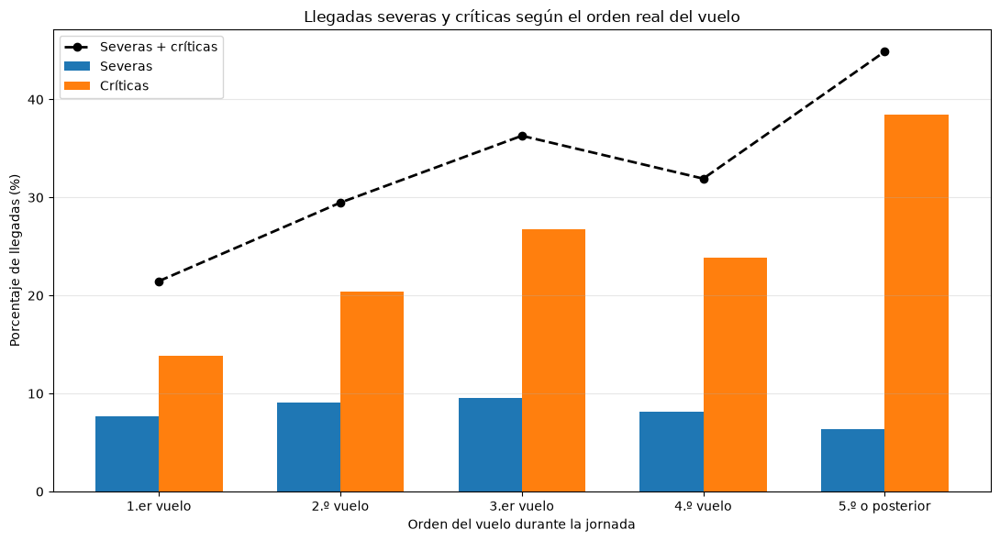

Gráfico 2: mediana de las demoras de salida y llegada según el orden real del vuelo.
Permite observar si las demoras típicas aumentan en las operaciones posteriores.


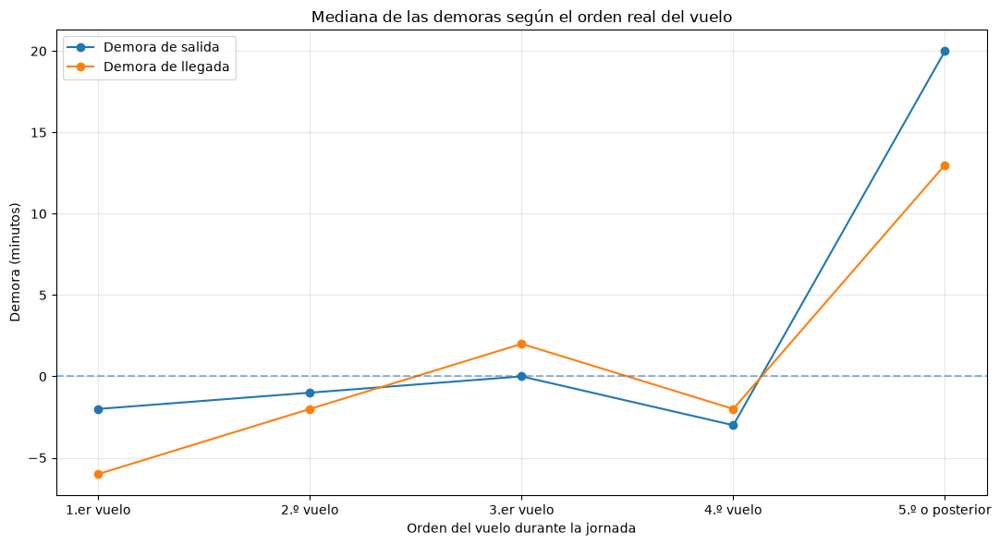

Comparación directa entre el primer vuelo y los vuelos posteriores de la aeronave.
Los vuelos posteriores reúnen todas las posiciones desde la segunda en adelante.


,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves
_primer_vs_posterior,,,,,,,,
Primer vuelo,248231,18940,34351,53291,-6.0,7.63,13.84,21.47
Vuelos posteriores,79115,7191,17148,24339,-1.0,9.09,21.67,30.76


Gráfico 3: porcentaje de llegadas severas y críticas del primer vuelo frente a los posteriores.
Permite responder directamente si el primer vuelo presenta mejor puntualidad que las siguientes operaciones.


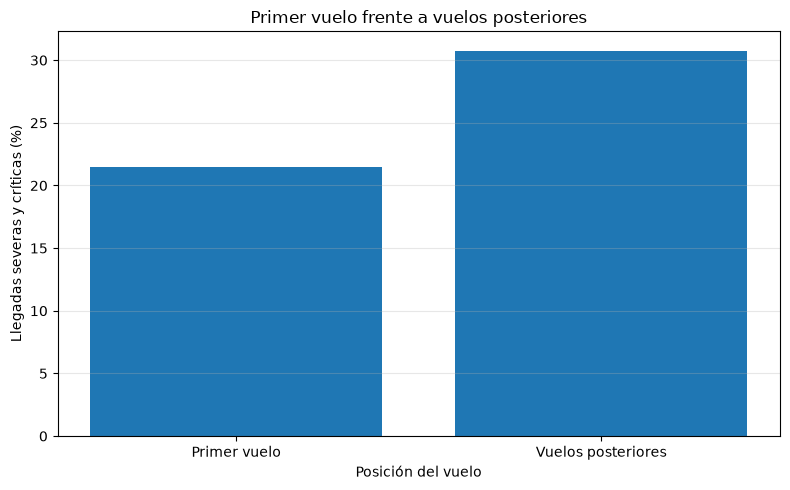

Resumen de puntualidad según la posición del vuelo en la jornada.
Se diferencian los días con un único vuelo, el primero, los intermedios y el último.


,vuelos_operados,matriculas,jornadas_aeronave_dia,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves
_posicion_jornada,,,,,,,,,,,,
Único vuelo,186226,4029,186226,185515,14685,28177,42862,-1.0,-5.0,7.92,15.19,23.10
Primer vuelo,62846,2887,62846,62716,4255,6174,10429,-3.0,-7.0,6.78,9.84,16.63
Vuelo intermedio,16603,1285,13957,16564,1516,2616,4132,-2.0,-3.0,9.15,15.79,24.95
Último vuelo,62846,2887,62846,62551,5675,14532,20207,0.0,0.0,9.07,23.23,32.30


Gráfico 4: porcentaje de llegadas severas y críticas según la posición del vuelo en la jornada.
Permite comparar el primer vuelo, las operaciones intermedias y el último vuelo.


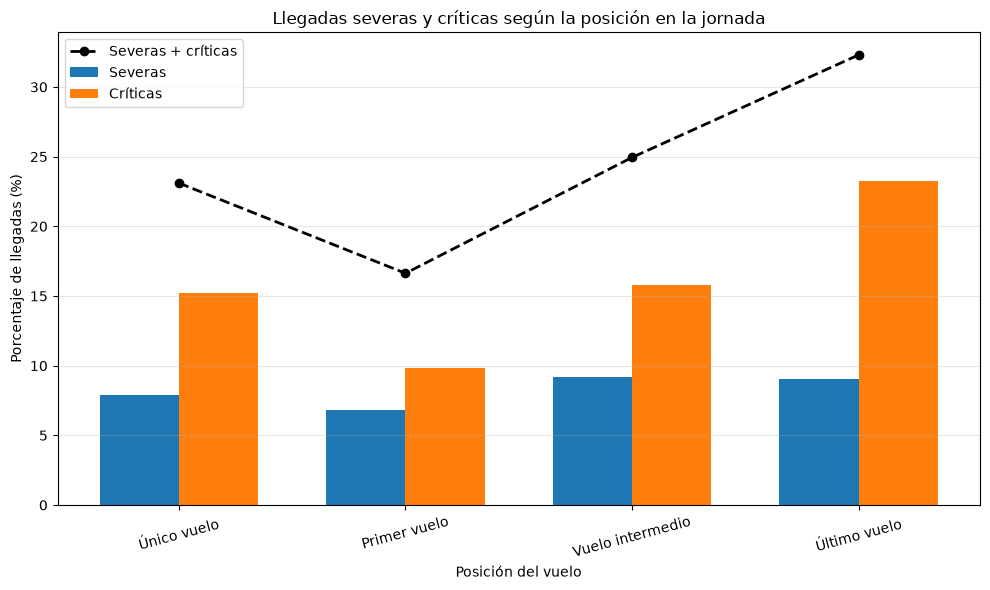

Gráfico 5: mediana de las demoras de salida y llegada según la posición en la jornada.
Permite observar si el último vuelo presenta demoras típicas mayores que el primero o los intermedios.


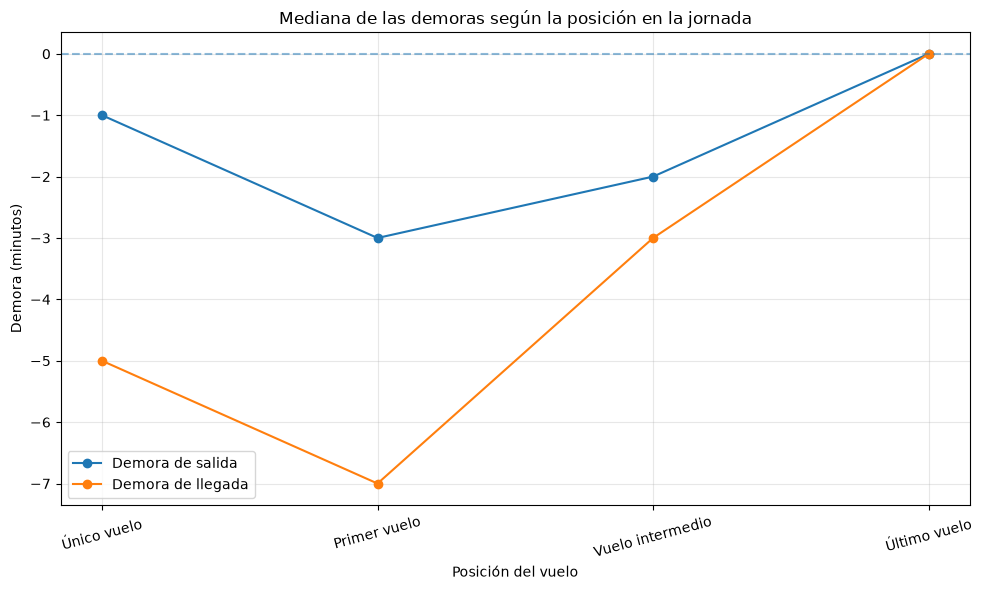

Comparación directa entre el primer y el último vuelo de la jornada.
Porcentaje de llegadas graves del primer vuelo: 16.63%
Porcentaje de llegadas graves del último vuelo: 32.30%
Diferencia entre último y primer vuelo: +15.68 puntos porcentuales


In [94]:
# ==========================================================
# 7.2. PUNTUALIDAD SEGÚN EL ORDEN DEL VUELO DURANTE LA JORNADA
# ==========================================================

# Orden de los grupos de vuelos
orden_grupos = [
    "1.er vuelo",
    "2.º vuelo",
    "3.er vuelo",
    "4.º vuelo",
    "5.º o posterior"
]

# Posición dentro de la jornada
orden_posiciones = [
    "Único vuelo",
    "Primer vuelo",
    "Vuelo intermedio",
    "Último vuelo"
]

# Categorías evaluables de llegada
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Utilizar vuelos operados con matrícula, fecha real
# de salida y orden real disponibles.

base_operados = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["matricula_avion"].notna()) &
    (df["fecha_hora_salida_real"].notna()) &
    (df["numero_orden_vuelo_dia_real"].notna())
].copy()

# Asegurar que el orden sea numérico
base_operados["_orden_real"] = pd.to_numeric(
    base_operados["numero_orden_vuelo_dia_real"],
    errors="coerce"
)

# Excluir órdenes no válidos
base_operados = base_operados.loc[
    base_operados["_orden_real"].notna() &
    (base_operados["_orden_real"] >= 1)
].copy()

base_operados["_orden_real"] = (
    base_operados["_orden_real"].astype(int)
)

# Obtener la fecha real de operación sin la hora
base_operados["_fecha_operacion"] = (
    base_operados["fecha_hora_salida_real"].dt.normalize()
)

# Identificar el último orden de cada aeronave en cada fecha.
# Se calcula antes de excluir las llegadas desconocidas.

base_operados["_ultimo_orden_dia"] = (
    base_operados
    .groupby(
        ["matricula_avion", "_fecha_operacion"]
    )["_orden_real"]
    .transform("max")
)

# ----------------------------------------------------------
# 1.1. Agrupar según el orden del vuelo
# ----------------------------------------------------------

base_operados["_grupo_orden"] = pd.cut(
    base_operados["_orden_real"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, np.inf],
    labels=orden_grupos,
    right=True
)

# ----------------------------------------------------------
# 1.2. Identificar la posición del vuelo en la jornada
# ----------------------------------------------------------

condiciones = [
    base_operados["_ultimo_orden_dia"] == 1,

    base_operados["_orden_real"] == 1,

    base_operados["_orden_real"] ==
    base_operados["_ultimo_orden_dia"]
]

opciones = [
    "Único vuelo",
    "Primer vuelo",
    "Último vuelo"
]

base_operados["_posicion_jornada"] = np.select(
    condiciones,
    opciones,
    default="Vuelo intermedio"
)

base_operados["_posicion_jornada"] = pd.Categorical(
    base_operados["_posicion_jornada"],
    categories=orden_posiciones,
    ordered=True
)

print("Preparación del análisis según el orden real de las operaciones.")
print(f"Vuelos operados con matrícula y orden real disponibles: {len(base_operados):,}")

print(
    "Jornadas distintas de aeronave y fecha:",
    f"{base_operados[['matricula_avion', '_fecha_operacion']].drop_duplicates().shape[0]:,}"
)


# ==========================================================
# 2. PREPARACIÓN DE LOS INDICADORES DE PUNTUALIDAD
# ==========================================================

# Para evaluar puntualidad, excluir las llegadas desconocidas.
# La identificación de primer y último vuelo ya se realizó
# utilizando todos los vuelos operados con orden disponible.

base = base_operados.loc[
    base_operados["nivel_puntualidad_arribo"].isin(niveles_evaluables)
].copy()

# Indicadores de llegada
base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Demoras numéricas de salida y llegada
base["_demora_salida"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["_demora_arribo"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

print("Vuelos utilizados para evaluar la puntualidad:")
print(f"Vuelos con llegada evaluable: {len(base):,}")

print(
    "Vuelos operados excluidos por llegada desconocida:",
    f"{len(base_operados) - len(base):,}"
)


# ==========================================================
# 3. PUNTUALIDAD SEGÚN EL ORDEN DEL VUELO
# ==========================================================

# Resumen de todas las operaciones por orden
resumen_operaciones = (
    base_operados.groupby("_grupo_orden", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        matriculas=("matricula_avion", "nunique")
    )
    .reindex(orden_grupos)
)

# Cantidad de jornadas de aeronave en cada posición
jornadas_orden = (
    base_operados[
        [
            "matricula_avion",
            "_fecha_operacion",
            "_grupo_orden"
        ]
    ]
    .drop_duplicates()
    .groupby("_grupo_orden", observed=False)
    .size()
    .reindex(orden_grupos)
    .rename("jornadas_aeronave_dia")
)

# Resumen de puntualidad
resumen_puntualidad = (
    base.groupby("_grupo_orden", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_grupos)
)

# Medianas de demora
resumen_demoras = (
    base.groupby("_grupo_orden", observed=False)
    .agg(
        mediana_demora_salida=("_demora_salida", "median"),
        mediana_demora_arribo=("_demora_arribo", "median")
    )
    .reindex(orden_grupos)
)

# Integrar los resultados
resumen_orden = (
    resumen_operaciones
    .join(jornadas_orden)
    .join(resumen_puntualidad)
    .join(resumen_demoras)
)

# Porcentajes sobre las llegadas evaluables
resumen_orden["pct_severas"] = (
    resumen_orden["llegadas_severas"] /
    resumen_orden["vuelos_evaluables"] * 100
)

resumen_orden["pct_criticas"] = (
    resumen_orden["llegadas_criticas"] /
    resumen_orden["vuelos_evaluables"] * 100
)

resumen_orden["pct_graves"] = (
    resumen_orden["llegadas_graves"] /
    resumen_orden["vuelos_evaluables"] * 100
)

print("Resumen de puntualidad según el orden real del vuelo durante la jornada.")
print("Los porcentajes se calculan sobre las llegadas evaluables de cada posición.")

display(resumen_orden.round(2))


# ----------------------------------------------------------
# Gráfico 1: llegadas severas y críticas según el orden
# ----------------------------------------------------------

print("Gráfico 1: porcentaje de llegadas severas y críticas según el orden real del vuelo.")
print("Permite observar si la proporción de demoras graves aumenta en las operaciones posteriores de una aeronave.")

fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(orden_grupos))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_orden["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_orden["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_orden["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos)

ax.set_title("Llegadas severas y críticas según el orden real del vuelo")
ax.set_xlabel("Orden del vuelo durante la jornada")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Gráfico 2: medianas de demora según el orden
# ----------------------------------------------------------

print("Gráfico 2: mediana de las demoras de salida y llegada según el orden real del vuelo.")
print("Permite observar si las demoras típicas aumentan en las operaciones posteriores.")

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    x,
    resumen_orden["mediana_demora_salida"],
    marker="o",
    label="Demora de salida"
)

ax.plot(
    x,
    resumen_orden["mediana_demora_arribo"],
    marker="o",
    label="Demora de llegada"
)

ax.axhline(0, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(orden_grupos)

ax.set_title("Mediana de las demoras según el orden real del vuelo")
ax.set_xlabel("Orden del vuelo durante la jornada")
ax.set_ylabel("Demora (minutos)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. COMPARAR PRIMER VUELO Y VUELOS POSTERIORES
# ==========================================================

base["_primer_vs_posterior"] = np.where(
    base["_orden_real"] == 1,
    "Primer vuelo",
    "Vuelos posteriores"
)

orden_primer_posterior = [
    "Primer vuelo",
    "Vuelos posteriores"
]

base["_primer_vs_posterior"] = pd.Categorical(
    base["_primer_vs_posterior"],
    categories=orden_primer_posterior,
    ordered=True
)

resumen_primer_posterior = (
    base.groupby("_primer_vs_posterior", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_arribo=("_demora_arribo", "median")
    )
    .reindex(orden_primer_posterior)
)

resumen_primer_posterior["pct_severas"] = (
    resumen_primer_posterior["llegadas_severas"] /
    resumen_primer_posterior["vuelos_evaluables"] * 100
)

resumen_primer_posterior["pct_criticas"] = (
    resumen_primer_posterior["llegadas_criticas"] /
    resumen_primer_posterior["vuelos_evaluables"] * 100
)

resumen_primer_posterior["pct_graves"] = (
    resumen_primer_posterior["llegadas_graves"] /
    resumen_primer_posterior["vuelos_evaluables"] * 100
)

print("Comparación directa entre el primer vuelo y los vuelos posteriores de la aeronave.")
print("Los vuelos posteriores reúnen todas las posiciones desde la segunda en adelante.")

display(resumen_primer_posterior.round(2))


# ----------------------------------------------------------
# Gráfico 3: primer vuelo frente a vuelos posteriores
# ----------------------------------------------------------

print("Gráfico 3: porcentaje de llegadas severas y críticas del primer vuelo frente a los posteriores.")
print("Permite responder directamente si el primer vuelo presenta mejor puntualidad que las siguientes operaciones.")

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    resumen_primer_posterior.index.astype(str),
    resumen_primer_posterior["pct_graves"]
)

ax.set_title("Primer vuelo frente a vuelos posteriores")
ax.set_xlabel("Posición del vuelo")
ax.set_ylabel("Llegadas severas y críticas (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. PUNTUALIDAD SEGÚN LA POSICIÓN DENTRO DE LA JORNADA
# ==========================================================

# Resumen de operaciones por posición
resumen_operaciones_posicion = (
    base_operados.groupby("_posicion_jornada", observed=False)
    .agg(
        vuelos_operados=("id", "size"),
        matriculas=("matricula_avion", "nunique")
    )
    .reindex(orden_posiciones)
)

# Cantidad de jornadas distintas por posición
jornadas_posicion = (
    base_operados[
        [
            "matricula_avion",
            "_fecha_operacion",
            "_posicion_jornada"
        ]
    ]
    .drop_duplicates()
    .groupby("_posicion_jornada", observed=False)
    .size()
    .reindex(orden_posiciones)
    .rename("jornadas_aeronave_dia")
)

# Resumen de puntualidad por posición
resumen_puntualidad_posicion = (
    base.groupby("_posicion_jornada", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_demora_salida=("_demora_salida", "median"),
        mediana_demora_arribo=("_demora_arribo", "median")
    )
    .reindex(orden_posiciones)
)

resumen_posicion = (
    resumen_operaciones_posicion
    .join(jornadas_posicion)
    .join(resumen_puntualidad_posicion)
)

resumen_posicion["pct_severas"] = (
    resumen_posicion["llegadas_severas"] /
    resumen_posicion["vuelos_evaluables"] * 100
)

resumen_posicion["pct_criticas"] = (
    resumen_posicion["llegadas_criticas"] /
    resumen_posicion["vuelos_evaluables"] * 100
)

resumen_posicion["pct_graves"] = (
    resumen_posicion["llegadas_graves"] /
    resumen_posicion["vuelos_evaluables"] * 100
)

print("Resumen de puntualidad según la posición del vuelo en la jornada.")
print("Se diferencian los días con un único vuelo, el primero, los intermedios y el último.")

display(resumen_posicion.round(2))


# ----------------------------------------------------------
# Gráfico 4: llegadas graves según la posición
# ----------------------------------------------------------

print("Gráfico 4: porcentaje de llegadas severas y críticas según la posición del vuelo en la jornada.")
print("Permite comparar el primer vuelo, las operaciones intermedias y el último vuelo.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_posiciones))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_posicion["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_posicion["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_posicion["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_posiciones, rotation=15)

ax.set_title("Llegadas severas y críticas según la posición en la jornada")
ax.set_xlabel("Posición del vuelo")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Gráfico 5: medianas de demora según la posición
# ----------------------------------------------------------

print("Gráfico 5: mediana de las demoras de salida y llegada según la posición en la jornada.")
print("Permite observar si el último vuelo presenta demoras típicas mayores que el primero o los intermedios.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    x,
    resumen_posicion["mediana_demora_salida"],
    marker="o",
    label="Demora de salida"
)

ax.plot(
    x,
    resumen_posicion["mediana_demora_arribo"],
    marker="o",
    label="Demora de llegada"
)

ax.axhline(0, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(orden_posiciones, rotation=15)

ax.set_title("Mediana de las demoras según la posición en la jornada")
ax.set_xlabel("Posición del vuelo")
ax.set_ylabel("Demora (minutos)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. COMPARACIÓN ENTRE PRIMER Y ÚLTIMO VUELO
# ==========================================================

# Extraer los porcentajes del primer y último vuelo
pct_primer_vuelo = resumen_posicion.loc[
    "Primer vuelo", "pct_graves"
]

pct_ultimo_vuelo = resumen_posicion.loc[
    "Último vuelo", "pct_graves"
]

diferencia_primer_ultimo = (
    pct_ultimo_vuelo - pct_primer_vuelo
)

print("Comparación directa entre el primer y el último vuelo de la jornada.")

print(
    f"Porcentaje de llegadas graves del primer vuelo: "
    f"{pct_primer_vuelo:.2f}%"
)

print(
    f"Porcentaje de llegadas graves del último vuelo: "
    f"{pct_ultimo_vuelo:.2f}%"
)

print(
    f"Diferencia entre último y primer vuelo: "
    f"{diferencia_primer_ultimo:+.2f} puntos porcentuales"
)

#### 7.3. Relación entre la demora de un vuelo anterior y el siguiente

Analizar si la demora que presenta un vuelo se encuentra asociada con la puntualidad del siguiente vuelo de la misma aeronave.

Preguntas que podemos investigar:

- ¿Los vuelos cuyo avión llegó previamente demorado presentan una mayor proporción de llegadas severas y críticas?
- ¿Una mayor demora del vuelo anterior está asociada con una mayor demora en el vuelo actual?
- ¿Los vuelos posteriores a una operación puntual presentan mejores resultados?
- ¿La demora previa se mantiene, aumenta o disminuye en las operaciones siguientes?

Se utilizarán las variables `retraso_vuelo_anterior_salida` y `retraso_vuelo_anterior_arribo` para relacionar el comportamiento del vuelo anterior con el resultado del vuelo actual, respetando la definición utilizada al construir esas variables.

Preparación del análisis de demoras entre vuelos consecutivos.
Vuelos actuales operados con llegada evaluable: 327,346
Vuelos sin información de demora de llegada del vuelo anterior: 9,044
Vuelos sin información de demora de salida del vuelo anterior: 7,907
Puntualidad del vuelo actual según la demora de llegada del vuelo anterior.
Se compara si el vuelo anterior llegó con demora positiva o sin demora positiva.
Los porcentajes corresponden a las llegadas del vuelo actual.


,vuelos_actuales,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_anterior,mediana_demora_salida_actual,mediana_demora_arribo_actual,pct_severas,pct_criticas,pct_graves
_estado_anterior,,,,,,,,,,
Vuelo anterior sin demora positiva (≤ 0),189395,13415,24118,37533,-15.0,-2.0,-7.0,7.08,12.73,19.82
Vuelo anterior con demora positiva,128907,11964,26091,38055,21.0,-1.0,-1.0,9.28,20.24,29.52


Gráfico 1: porcentaje de llegadas severas y críticas según la demora de llegada del vuelo anterior.
Permite observar si los vuelos cuyo avión llegó previamente demorado presentan más llegadas graves.


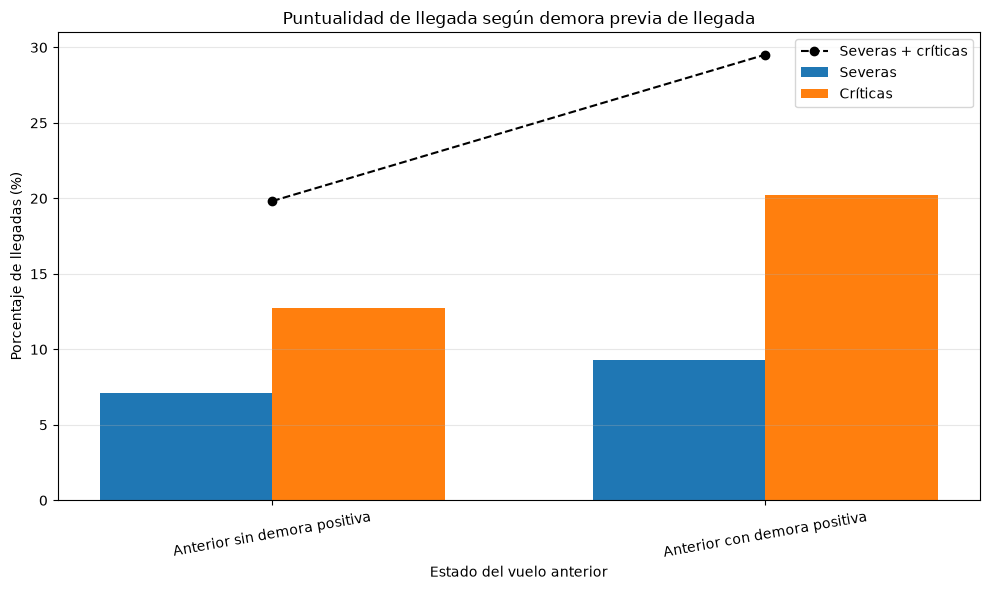

Gráfico 2: mediana de las demoras de salida y llegada del vuelo actual según la demora de llegada anterior.
Permite observar si el vuelo actual presenta mayores demoras cuando su aeronave llegó previamente demorada.


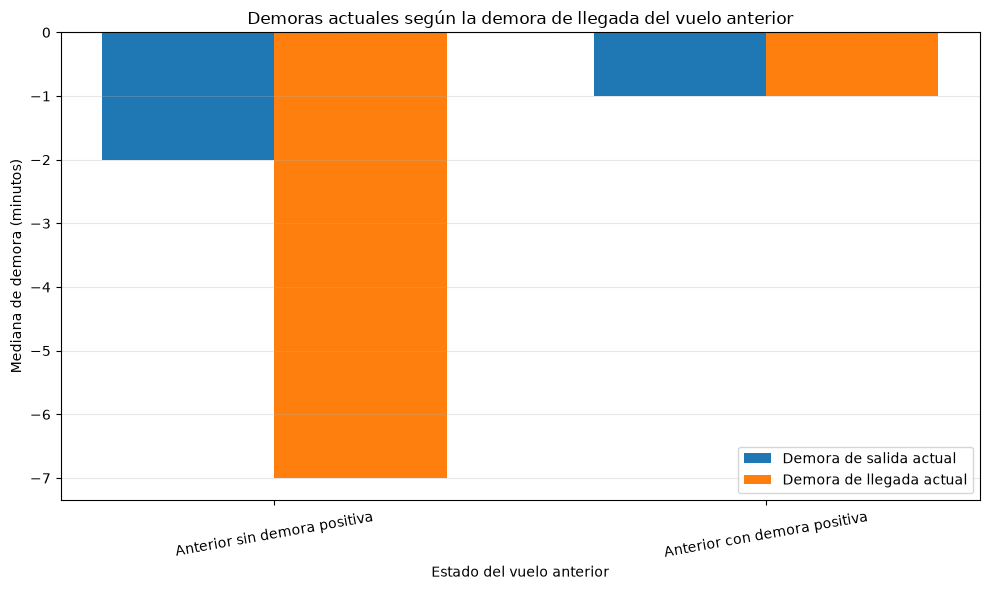

Puntualidad del vuelo actual según la demora de salida del vuelo anterior.
Este análisis permite observar si el comportamiento de salida de la operación previa también está relacionado con la llegada actual.


,vuelos_actuales,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_anterior,mediana_demora_salida_actual,mediana_demora_arribo_actual,pct_severas,pct_criticas,pct_graves
_estado_anterior,,,,,,,,,,
Vuelo anterior sin demora positiva (≤ 0),194994,14514,26244,40758,-4.0,-2.0,-6.0,7.44,13.46,20.90
Vuelo anterior con demora positiva,124445,10964,24266,35230,19.0,0.0,-2.0,8.81,19.50,28.31


Gráfico 3: porcentaje de llegadas severas y críticas según la demora de salida del vuelo anterior.
Permite comparar los resultados actuales cuando el vuelo anterior salió con demora positiva o sin ella.


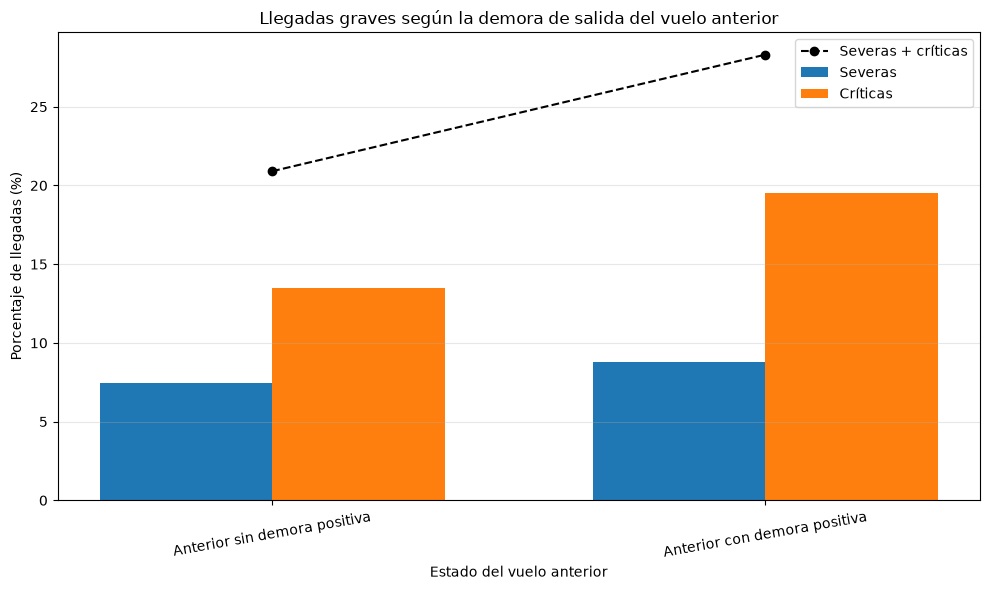

Puntualidad actual según la magnitud de la demora de llegada del vuelo anterior.
Los cuartiles ordenan los valores de demora previa desde los más bajos hasta los más altos.


,vuelos_actuales,demora_anterior_mediana,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_demora_salida_actual,mediana_demora_arribo_actual,pct_severas,pct_criticas,pct_graves
_cuartil_demora_anterior,,,,,,,,,,
"(-86.001, -17.0]",81971,-24.0,5225,9506,14731,-2.0,-9.0,6.37,11.60,17.97
"(-17.0, -5.0]",79445,-11.0,5919,10668,16587,-2.0,-6.0,7.45,13.43,20.88
"(-5.0, 14.0]",79236,3.0,6841,12265,19106,-1.0,-3.0,8.63,15.48,24.11
"(14.0, 1272.0]",77650,42.0,7394,17770,25164,0.0,1.0,9.52,22.88,32.41


Gráfico 4: porcentaje de llegadas severas y críticas según el cuartil de demora anterior.
Permite observar si una demora previa más elevada está asociada con una mayor proporción de llegadas graves en el vuelo actual.


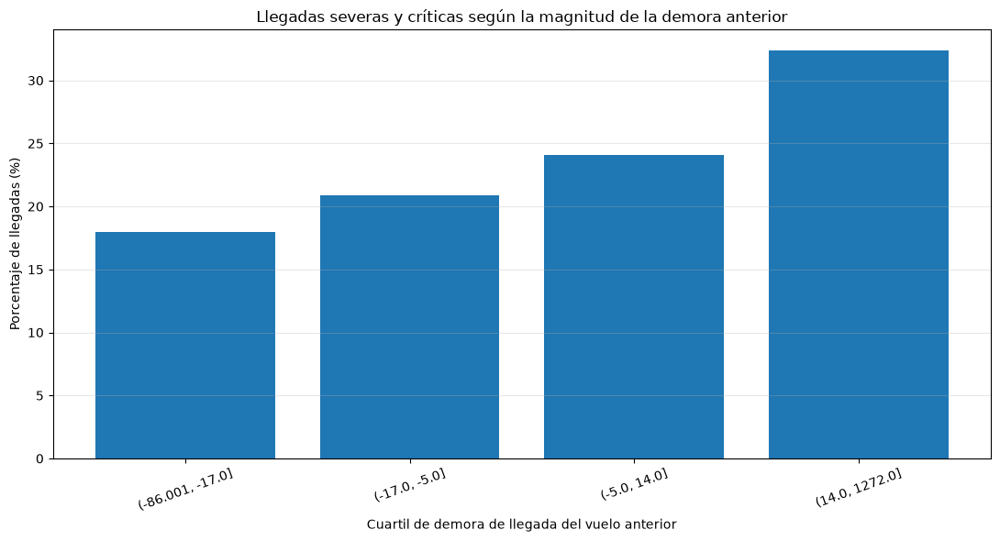

Correlación entre las demoras de vuelos anteriores y los resultados del vuelo actual.
Spearman permite evaluar si existe una relación ordenada entre las variables.


,relacion,vuelos_comparados,correlacion_spearman
0,Salida anterior → salida actual,319439,0.159
1,Llegada anterior → llegada actual,318302,0.169
2,Llegada anterior → salida actual,318302,0.116
3,Llegada anterior → llegada grave actual,318302,0.127


Comparación de la demora de llegada anterior con la demora de llegada actual.
La diferencia se calcula como: demora actual - demora anterior.
Un valor positivo indica que la demora actual fue mayor; un valor negativo, que fue menor.
Mediana de la variación: 0.00 minutos
Vuelos comparados: 318,302
Vuelos donde la demora actual fue mayor: 157,245
Vuelos donde la demora actual fue menor: 156,409
Vuelos donde ambas demoras fueron iguales: 4,648
Gráfico 5: distribución de la diferencia entre la demora de llegada anterior y actual.
Permite observar si las demoras del vuelo actual tienden a ser mayores o menores que las del vuelo previo.


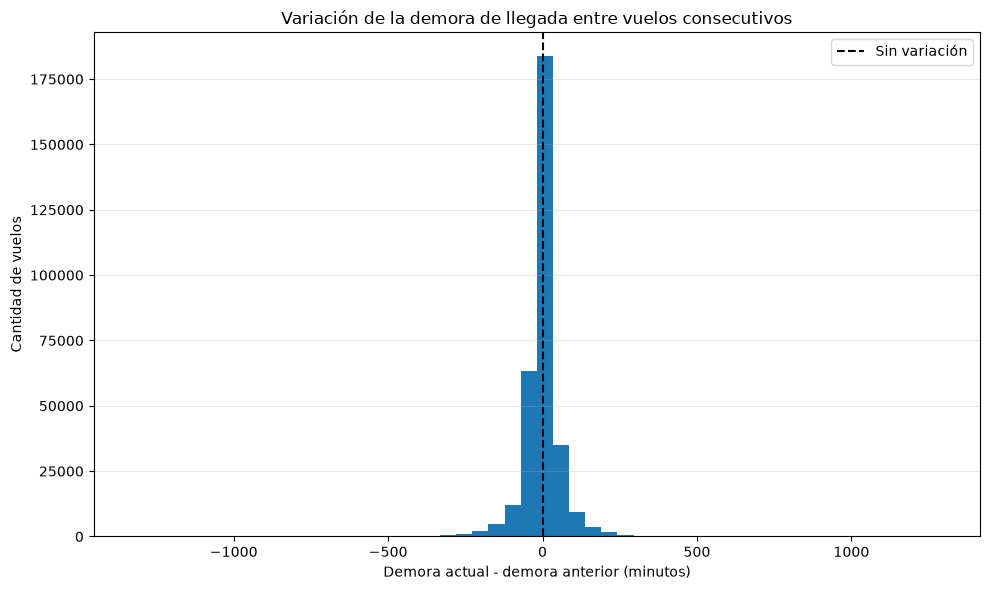

In [95]:
# ==========================================================
# 7.3. RELACIÓN ENTRE LA DEMORA DE UN VUELO ANTERIOR Y EL SIGUIENTE
# ==========================================================

# Orden de los grupos de demora anterior
orden_estados = [
    "Vuelo anterior sin demora positiva (≤ 0)",
    "Vuelo anterior con demora positiva"
]

# Categorías de puntualidad de llegada evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Trabajar únicamente con vuelos operados.
# El vuelo actual debe tener una llegada evaluable.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["nivel_puntualidad_arribo"].isin(niveles_evaluables))
].copy()

# Convertir las variables de demora a valores numéricos

columnas_demoras = [
    "retraso_vuelo_anterior_salida",
    "retraso_vuelo_anterior_arribo",
    "demora_salida_min",
    "demora_arribo_min"
]

for columna in columnas_demoras:
    base[columna] = pd.to_numeric(
        base[columna],
        errors="coerce"
    )

# Indicadores de puntualidad de llegada del vuelo actual

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Copias de las demoras actuales para facilitar el análisis

base["_demora_salida_actual"] = base["demora_salida_min"]
base["_demora_arribo_actual"] = base["demora_arribo_min"]

print("Preparación del análisis de demoras entre vuelos consecutivos.")
print(f"Vuelos actuales operados con llegada evaluable: {len(base):,}")

print(
    "Vuelos sin información de demora de llegada del vuelo anterior:",
    f"{base['retraso_vuelo_anterior_arribo'].isna().sum():,}"
)

print(
    "Vuelos sin información de demora de salida del vuelo anterior:",
    f"{base['retraso_vuelo_anterior_salida'].isna().sum():,}"
)


# ==========================================================
# 2. FUNCIÓN PARA COMPARAR LA DEMORA DEL VUELO ANTERIOR
# ==========================================================

def resumir_demora_anterior(datos, columna_anterior):

    # Conservar vuelos que tengan información de la demora previa
    muestra = datos.loc[
        datos[columna_anterior].notna()
    ].copy()

    # Clasificar el estado del vuelo anterior.
    # Una demora positiva es mayor que cero.
    # Cero o valores negativos representan ausencia de demora positiva.

    muestra["_estado_anterior"] = np.where(
        muestra[columna_anterior] > 0,
        "Vuelo anterior con demora positiva",
        "Vuelo anterior sin demora positiva (≤ 0)"
    )

    muestra["_estado_anterior"] = pd.Categorical(
        muestra["_estado_anterior"],
        categories=orden_estados,
        ordered=True
    )

    # Resumen por estado del vuelo anterior
    resumen = (
        muestra.groupby(
            "_estado_anterior",
            observed=False
        )
        .agg(
            vuelos_actuales=("id", "size"),

            llegadas_severas=("_arribo_severo", "sum"),
            llegadas_criticas=("_arribo_critico", "sum"),
            llegadas_graves=("_arribo_grave", "sum"),

            mediana_demora_anterior=(columna_anterior, "median"),

            mediana_demora_salida_actual=(
                "_demora_salida_actual",
                "median"
            ),

            mediana_demora_arribo_actual=(
                "_demora_arribo_actual",
                "median"
            )
        )
        .reindex(orden_estados)
    )

    # Porcentajes de llegadas graves sobre los vuelos actuales
    # de cada grupo.

    resumen["pct_severas"] = (
        resumen["llegadas_severas"] /
        resumen["vuelos_actuales"] * 100
    )

    resumen["pct_criticas"] = (
        resumen["llegadas_criticas"] /
        resumen["vuelos_actuales"] * 100
    )

    resumen["pct_graves"] = (
        resumen["llegadas_graves"] /
        resumen["vuelos_actuales"] * 100
    )

    return muestra, resumen


# ==========================================================
# 3. RELACIÓN CON LA DEMORA DE LLEGADA DEL VUELO ANTERIOR
# ==========================================================

base_arribo_anterior, resumen_arribo_anterior = (
    resumir_demora_anterior(
        base,
        "retraso_vuelo_anterior_arribo"
    )
)

print("Puntualidad del vuelo actual según la demora de llegada del vuelo anterior.")
print("Se compara si el vuelo anterior llegó con demora positiva o sin demora positiva.")
print("Los porcentajes corresponden a las llegadas del vuelo actual.")

display(resumen_arribo_anterior.round(2))


# ----------------------------------------------------------
# Gráfico 1: llegadas graves según demora de llegada previa
# ----------------------------------------------------------

print("Gráfico 1: porcentaje de llegadas severas y críticas según la demora de llegada del vuelo anterior.")
print("Permite observar si los vuelos cuyo avión llegó previamente demorado presentan más llegadas graves.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_estados))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_arribo_anterior["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_arribo_anterior["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_arribo_anterior["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Anterior sin demora positiva",
        "Anterior con demora positiva"
    ],
    rotation=10
)

ax.set_title("Puntualidad de llegada según demora previa de llegada")
ax.set_xlabel("Estado del vuelo anterior")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# Gráfico 2: medianas de las demoras actuales
# ----------------------------------------------------------

print("Gráfico 2: mediana de las demoras de salida y llegada del vuelo actual según la demora de llegada anterior.")
print("Permite observar si el vuelo actual presenta mayores demoras cuando su aeronave llegó previamente demorada.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_estados))

ax.bar(
    x - ancho / 2,
    resumen_arribo_anterior["mediana_demora_salida_actual"],
    width=ancho,
    label="Demora de salida actual"
)

ax.bar(
    x + ancho / 2,
    resumen_arribo_anterior["mediana_demora_arribo_actual"],
    width=ancho,
    label="Demora de llegada actual"
)

ax.axhline(0, linestyle="--", alpha=0.5)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Anterior sin demora positiva",
        "Anterior con demora positiva"
    ],
    rotation=10
)

ax.set_title("Demoras actuales según la demora de llegada del vuelo anterior")
ax.set_xlabel("Estado del vuelo anterior")
ax.set_ylabel("Mediana de demora (minutos)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. RELACIÓN CON LA DEMORA DE SALIDA DEL VUELO ANTERIOR
# ==========================================================

base_salida_anterior, resumen_salida_anterior = (
    resumir_demora_anterior(
        base,
        "retraso_vuelo_anterior_salida"
    )
)

print("Puntualidad del vuelo actual según la demora de salida del vuelo anterior.")
print("Este análisis permite observar si el comportamiento de salida de la operación previa también está relacionado con la llegada actual.")

display(resumen_salida_anterior.round(2))


# ----------------------------------------------------------
# Gráfico 3: llegadas graves según demora de salida previa
# ----------------------------------------------------------

print("Gráfico 3: porcentaje de llegadas severas y críticas según la demora de salida del vuelo anterior.")
print("Permite comparar los resultados actuales cuando el vuelo anterior salió con demora positiva o sin ella.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_estados))

ax.bar(
    x - ancho / 2,
    resumen_salida_anterior["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_salida_anterior["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_salida_anterior["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Anterior sin demora positiva",
        "Anterior con demora positiva"
    ],
    rotation=10
)

ax.set_title("Llegadas graves según la demora de salida del vuelo anterior")
ax.set_xlabel("Estado del vuelo anterior")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. ANALIZAR LA MAGNITUD DE LA DEMORA DE LLEGADA ANTERIOR
# ==========================================================

# En lugar de clasificar solamente si hubo demora positiva,
# ahora vamos a dividir las demoras previas en cuartiles.

base_cuartiles = base.loc[
    base["retraso_vuelo_anterior_arribo"].notna()
].copy()

# Comprobar que exista variación suficiente para formar cuartiles

if base_cuartiles["retraso_vuelo_anterior_arribo"].nunique() >= 2:

    # Crear cuartiles. Se eliminan límites repetidos cuando
    # hay muchos valores iguales.

    base_cuartiles["_cuartil_demora_anterior"] = pd.qcut(
        base_cuartiles["retraso_vuelo_anterior_arribo"],
        q=4,
        duplicates="drop"
    )

    resumen_cuartiles = (
        base_cuartiles
        .groupby("_cuartil_demora_anterior", observed=True)
        .agg(
            vuelos_actuales=("id", "size"),

            demora_anterior_mediana=(
                "retraso_vuelo_anterior_arribo",
                "median"
            ),

            llegadas_severas=("_arribo_severo", "sum"),
            llegadas_criticas=("_arribo_critico", "sum"),
            llegadas_graves=("_arribo_grave", "sum"),

            mediana_demora_salida_actual=(
                "_demora_salida_actual",
                "median"
            ),

            mediana_demora_arribo_actual=(
                "_demora_arribo_actual",
                "median"
            )
        )
    )

    resumen_cuartiles["pct_severas"] = (
        resumen_cuartiles["llegadas_severas"] /
        resumen_cuartiles["vuelos_actuales"] * 100
    )

    resumen_cuartiles["pct_criticas"] = (
        resumen_cuartiles["llegadas_criticas"] /
        resumen_cuartiles["vuelos_actuales"] * 100
    )

    resumen_cuartiles["pct_graves"] = (
        resumen_cuartiles["llegadas_graves"] /
        resumen_cuartiles["vuelos_actuales"] * 100
    )

    print("Puntualidad actual según la magnitud de la demora de llegada del vuelo anterior.")
    print("Los cuartiles ordenan los valores de demora previa desde los más bajos hasta los más altos.")

    display(resumen_cuartiles.round(2))


    # Gráfico 4: porcentaje de llegadas graves por cuartil

    print("Gráfico 4: porcentaje de llegadas severas y críticas según el cuartil de demora anterior.")
    print("Permite observar si una demora previa más elevada está asociada con una mayor proporción de llegadas graves en el vuelo actual.")

    fig, ax = plt.subplots(figsize=(11, 6))

    etiquetas_cuartiles = [
        str(intervalo)
        for intervalo in resumen_cuartiles.index
    ]

    ax.bar(
        etiquetas_cuartiles,
        resumen_cuartiles["pct_graves"]
    )

    ax.set_title("Llegadas severas y críticas según la magnitud de la demora anterior")
    ax.set_xlabel("Cuartil de demora de llegada del vuelo anterior")
    ax.set_ylabel("Porcentaje de llegadas (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

else:

    print(
        "No hay suficiente variación en la demora de llegada anterior "
        "para formar cuartiles."
    )


# ==========================================================
# 6. RELACIÓN ENTRE LA DEMORA ANTERIOR Y LA DEMORA ACTUAL
# ==========================================================

# Correlación de Spearman:
# - demora de salida previa vs. demora de salida actual
# - demora de llegada previa vs. demora de llegada actual
# - demora de llegada previa vs. llegada grave actual

comparaciones = [
    (
        "retraso_vuelo_anterior_salida",
        "_demora_salida_actual",
        "Salida anterior → salida actual"
    ),
    (
        "retraso_vuelo_anterior_arribo",
        "_demora_arribo_actual",
        "Llegada anterior → llegada actual"
    ),
    (
        "retraso_vuelo_anterior_arribo",
        "_demora_salida_actual",
        "Llegada anterior → salida actual"
    ),
    (
        "retraso_vuelo_anterior_arribo",
        "_arribo_grave",
        "Llegada anterior → llegada grave actual"
    )
]

resultados_correlacion = []

for columna_anterior, columna_actual, nombre in comparaciones:

    pares = base[
        [columna_anterior, columna_actual]
    ].dropna()

    cantidad_pares = len(pares)

    if cantidad_pares >= 2:
        correlacion = pares[columna_anterior].corr(
            pares[columna_actual],
            method="spearman"
        )
    else:
        correlacion = np.nan

    resultados_correlacion.append({
        "relacion": nombre,
        "vuelos_comparados": cantidad_pares,
        "correlacion_spearman": correlacion
    })

tabla_correlaciones = pd.DataFrame(
    resultados_correlacion
)

print("Correlación entre las demoras de vuelos anteriores y los resultados del vuelo actual.")
print("Spearman permite evaluar si existe una relación ordenada entre las variables.")

display(tabla_correlaciones.round(3))


# ==========================================================
# 7. COMPARACIÓN DE LA DEMORA ANTERIOR Y LA ACTUAL
# ==========================================================

# Este análisis es descriptivo:
# compara la demora de llegada del vuelo anterior con
# la demora de llegada del vuelo actual.

base_variacion = base.loc[
    base["retraso_vuelo_anterior_arribo"].notna() &
    base["_demora_arribo_actual"].notna()
].copy()

base_variacion["_variacion_demora_arribo"] = (
    base_variacion["_demora_arribo_actual"] -
    base_variacion["retraso_vuelo_anterior_arribo"]
)

print("Comparación de la demora de llegada anterior con la demora de llegada actual.")
print("La diferencia se calcula como: demora actual - demora anterior.")
print("Un valor positivo indica que la demora actual fue mayor; un valor negativo, que fue menor.")

print(
    "Mediana de la variación:",
    f"{base_variacion['_variacion_demora_arribo'].median():.2f} minutos"
)

print(
    "Vuelos comparados:",
    f"{len(base_variacion):,}"
)

print(
    "Vuelos donde la demora actual fue mayor:",
    f"{(base_variacion['_variacion_demora_arribo'] > 0).sum():,}"
)

print(
    "Vuelos donde la demora actual fue menor:",
    f"{(base_variacion['_variacion_demora_arribo'] < 0).sum():,}"
)

print(
    "Vuelos donde ambas demoras fueron iguales:",
    f"{(base_variacion['_variacion_demora_arribo'] == 0).sum():,}"
)

# Gráfico 5: variación entre demora anterior y actual

print("Gráfico 5: distribución de la diferencia entre la demora de llegada anterior y actual.")
print("Permite observar si las demoras del vuelo actual tienden a ser mayores o menores que las del vuelo previo.")

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    base_variacion["_variacion_demora_arribo"],
    bins=50
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    label="Sin variación"
)

ax.set_title("Variación de la demora de llegada entre vuelos consecutivos")
ax.set_xlabel("Demora actual - demora anterior (minutos)")
ax.set_ylabel("Cantidad de vuelos")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### 7.4. Relación entre el tiempo transcurrido entre vuelos y la puntualidad

Explorar si el intervalo entre operaciones de una misma aeronave está relacionado con su puntualidad.

Preguntas que podemos investigar:

- ¿Los vuelos que tienen menos tiempo desde la última salida de esa aeronave presentan más demoras graves?
- ¿Un intervalo mayor entre operaciones está asociado con una mejor puntualidad?
- ¿Las aeronaves que realizan salidas muy próximas entre sí presentan más problemas?
- ¿Existe un intervalo a partir del cual se observa una mejora en la puntualidad?

Se utilizará `tiempo_desde_ultima_salida_avion_origen`, que representa el tiempo transcurrido desde la última salida registrada de esa misma aeronave desde el mismo aeropuerto de origen.

**Consideración:** este intervalo no representa necesariamente el tiempo exacto que el avión permaneció en tierra entre su llegada y su siguiente salida. Para medir ese tiempo operativo de escala sería necesario relacionar la llegada real del vuelo anterior con la salida real del vuelo siguiente.

Preparación del análisis del tiempo desde la última salida de la aeronave desde el mismo origen.
Vuelos operados con llegada evaluable: 327,346
Vuelos sin información del intervalo: 7,907
Vuelos con intervalo cero o negativo: 0
Vuelos incluidos en el análisis: 319,439
Resumen de puntualidad según el tiempo transcurrido desde la última salida.
Los porcentajes se calculan sobre las llegadas evaluables de cada intervalo.


,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,mediana_intervalo_horas,mediana_demora_arribo,pct_severas,pct_criticas,pct_graves,muestra_suficiente
_grupo_intervalo,,,,,,,,,,
Menos de 1 hora,37,2,2,4,0.62,-14.0,5.41,5.41,10.81,True
1 a menos de 2 horas,25,0,2,2,1.45,-16.0,0.00,8.00,8.00,False
2 a menos de 4 horas,7454,569,1002,1571,3.80,-6.0,7.63,13.44,21.08,True
4 a menos de 8 horas,47114,4366,9354,13720,5.70,-2.0,9.27,19.85,29.12,True
8 a menos de 12 horas,22599,1978,4969,6947,9.53,-1.0,8.75,21.99,30.74,True
12 a menos de 24 horas,63232,4508,7108,11616,17.28,-7.0,7.13,11.24,18.37,True
24 horas o más,178978,14055,28073,42128,114.50,-5.0,7.85,15.69,23.54,True


Gráfico 1: porcentaje de llegadas severas y críticas según el tiempo desde la última salida.
Permite observar si los intervalos más cortos están asociados con una mayor proporción de demoras graves.
Las marcas en forma de X indican grupos con menos de 30 llegadas evaluables.


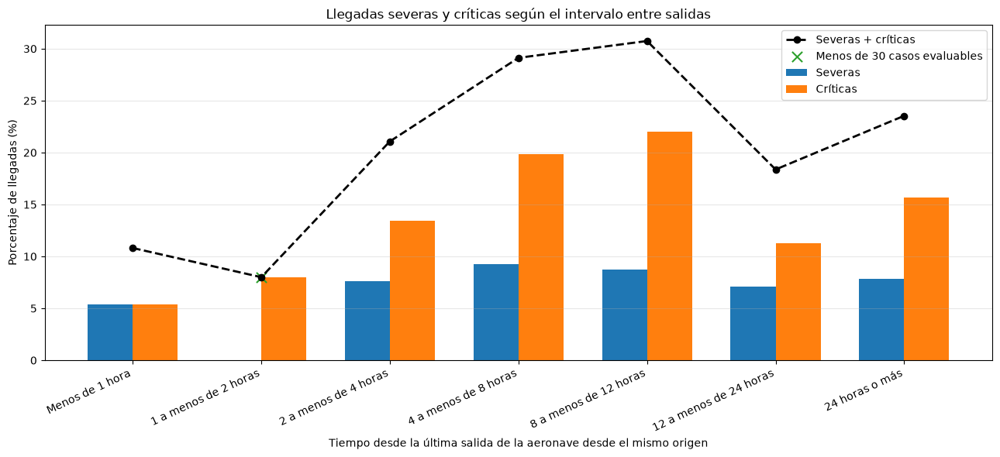

Gráfico 2: mediana de la demora de llegada según el tiempo desde la última salida.
Permite observar si los vuelos con intervalos más cortos presentan mayores demoras típicas.
Los valores negativos representan llegadas adelantadas.


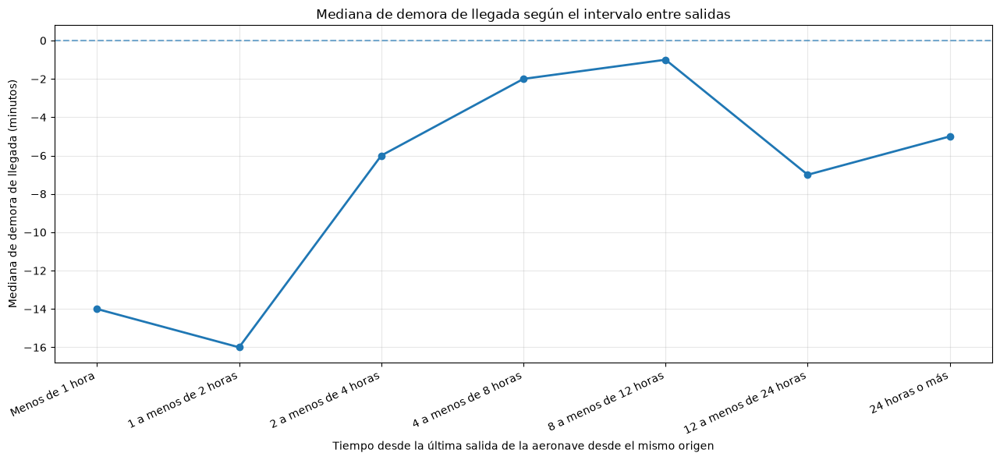

Distribución del intervalo desde la última salida según la puntualidad de llegada.
Se comparan los intervalos de los vuelos con llegada severa, crítica y otros niveles evaluables.


,vuelos,mediana_intervalo_horas,primer_cuartil,tercer_cuartil
_grupo_puntualidad,,,,
Otros niveles evaluables,243451,32.35,13.40,139.30
Severa,25478,29.11,10.34,127.38
Crítica,50510,28.73,9.23,124.71


Gráfico 3: distribución del tiempo desde la última salida según la categoría de puntualidad de llegada.
Permite comparar si los vuelos con llegada severa o crítica suelen tener intervalos diferentes.
Se utiliza una escala logarítmica para facilitar la visualización de intervalos muy distintos.


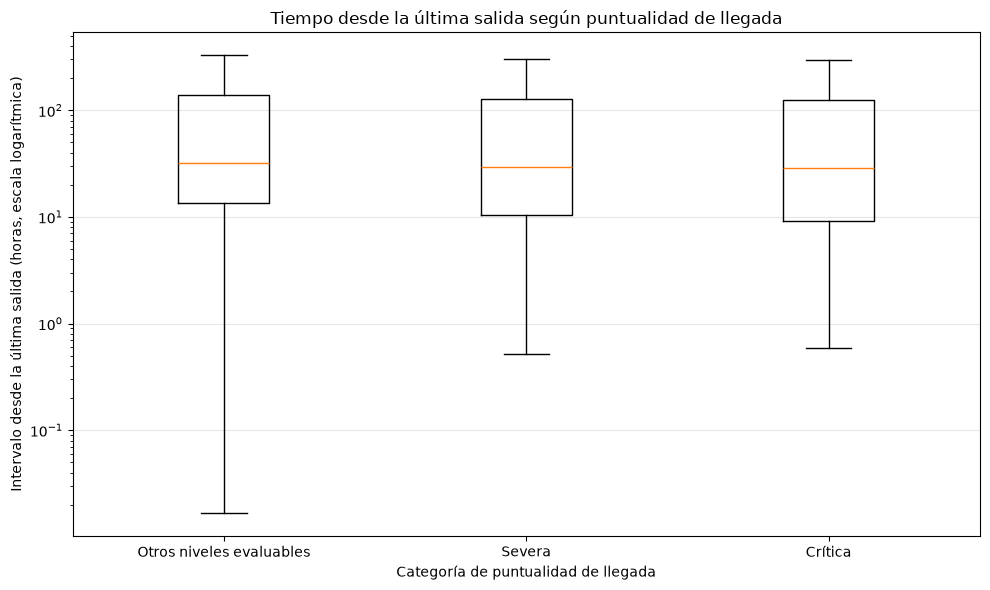

Correlación de Spearman entre el intervalo desde la última salida y la puntualidad de llegada.
Una correlación positiva indica que los intervalos mayores tienden a acompañarse de valores mayores en la variable analizada.
Una correlación no demuestra causalidad.


,variable_actual,vuelos_comparados,correlacion_spearman
0,Demora de llegada actual,319439,-0.041
1,Llegada severa o crítica actual,319439,-0.029


Intervalo con mayor porcentaje de llegadas severas y críticas: 8 a menos de 12 horas
Porcentaje: 30.74%
Intervalo con menor porcentaje de llegadas severas y críticas: Menos de 1 hora
Porcentaje: 10.81%


In [96]:
# ==========================================================
# 7.4. RELACIÓN ENTRE EL TIEMPO ENTRE SALIDAS Y LA PUNTUALIDAD
# ==========================================================

MIN_EVALUABLES = 30

# Orden de los intervalos
orden_intervalos = [
    "Menos de 1 hora",
    "1 a menos de 2 horas",
    "2 a menos de 4 horas",
    "4 a menos de 8 horas",
    "8 a menos de 12 horas",
    "12 a menos de 24 horas",
    "24 horas o más"
]

# Categorías de llegada evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Trabajar únicamente con vuelos operados cuya puntualidad
# de llegada pueda evaluarse.

base = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["nivel_puntualidad_arribo"].isin(niveles_evaluables))
].copy()

# Convertir el intervalo a timedelta, por seguridad.
base["_tiempo_ultima_salida"] = pd.to_timedelta(
    base["tiempo_desde_ultima_salida_avion_origen"],
    errors="coerce"
)

# Convertir el intervalo a horas
base["_intervalo_horas"] = (
    base["_tiempo_ultima_salida"].dt.total_seconds() / 3600
)

# Contar los registros sin intervalo y los intervalos no positivos
intervalos_faltantes = base["_intervalo_horas"].isna().sum()

intervalos_no_positivos = (
    base["_intervalo_horas"].notna() &
    (base["_intervalo_horas"] <= 0)
).sum()

# Excluir intervalos faltantes o no positivos.
# Un intervalo transcurrido debe ser mayor que cero.

base = base.loc[
    base["_intervalo_horas"].notna() &
    (base["_intervalo_horas"] > 0)
].copy()

# Indicadores de puntualidad de llegada

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Demora actual de llegada en minutos
base["_demora_arribo_actual"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

# Clasificar los intervalos
base["_grupo_intervalo"] = pd.cut(
    base["_intervalo_horas"],
    bins=[0, 1, 2, 4, 8, 12, 24, np.inf],
    labels=orden_intervalos,
    right=False
)

print("Preparación del análisis del tiempo desde la última salida de la aeronave desde el mismo origen.")
print(f"Vuelos operados con llegada evaluable: {len(df.loc[(df['estado_vuelo'] == 'operado') & (df['nivel_puntualidad_arribo'].isin(niveles_evaluables))]):,}")
print(f"Vuelos sin información del intervalo: {intervalos_faltantes:,}")
print(f"Vuelos con intervalo cero o negativo: {intervalos_no_positivos:,}")
print(f"Vuelos incluidos en el análisis: {len(base):,}")


# ==========================================================
# 2. RESUMEN DE PUNTUALIDAD SEGÚN EL INTERVALO
# ==========================================================

resumen_intervalos = (
    base.groupby("_grupo_intervalo", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum"),
        mediana_intervalo_horas=("_intervalo_horas", "median"),
        mediana_demora_arribo=("_demora_arribo_actual", "median")
    )
    .reindex(orden_intervalos)
)

# Porcentajes sobre las llegadas evaluables

resumen_intervalos["pct_severas"] = (
    resumen_intervalos["llegadas_severas"] /
    resumen_intervalos["vuelos_evaluables"] * 100
)

resumen_intervalos["pct_criticas"] = (
    resumen_intervalos["llegadas_criticas"] /
    resumen_intervalos["vuelos_evaluables"] * 100
)

resumen_intervalos["pct_graves"] = (
    resumen_intervalos["llegadas_graves"] /
    resumen_intervalos["vuelos_evaluables"] * 100
)

# Identificar grupos con muestra suficiente
resumen_intervalos["muestra_suficiente"] = (
    resumen_intervalos["vuelos_evaluables"] >= MIN_EVALUABLES
)

print("Resumen de puntualidad según el tiempo transcurrido desde la última salida.")
print("Los porcentajes se calculan sobre las llegadas evaluables de cada intervalo.")

display(resumen_intervalos.round(2))


# ==========================================================
# 3. PORCENTAJE DE LLEGADAS SEVERAS Y CRÍTICAS
# ==========================================================

print("Gráfico 1: porcentaje de llegadas severas y críticas según el tiempo desde la última salida.")
print("Permite observar si los intervalos más cortos están asociados con una mayor proporción de demoras graves.")
print(f"Las marcas en forma de X indican grupos con menos de {MIN_EVALUABLES} llegadas evaluables.")

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(orden_intervalos))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_intervalos["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_intervalos["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_intervalos["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    linewidth=2,
    label="Severas + críticas"
)

# Marcar grupos con pocos casos evaluables
grupos_insuficientes = resumen_intervalos.loc[
    ~resumen_intervalos["muestra_suficiente"]
]

ax.scatter(
    grupos_insuficientes.index.map(
        lambda grupo: orden_intervalos.index(grupo)
    ),
    grupos_insuficientes["pct_graves"],
    marker="x",
    s=90,
    label=f"Menos de {MIN_EVALUABLES} casos evaluables"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_intervalos, rotation=25, ha="right")

ax.set_title("Llegadas severas y críticas según el intervalo entre salidas")
ax.set_xlabel("Tiempo desde la última salida de la aeronave desde el mismo origen")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. MEDIANA DE LA DEMORA ACTUAL SEGÚN EL INTERVALO
# ==========================================================

print("Gráfico 2: mediana de la demora de llegada según el tiempo desde la última salida.")
print("Permite observar si los vuelos con intervalos más cortos presentan mayores demoras típicas.")
print("Los valores negativos representan llegadas adelantadas.")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    x,
    resumen_intervalos["mediana_demora_arribo"],
    marker="o",
    linewidth=2
)

ax.axhline(
    0,
    linestyle="--",
    alpha=0.6
)

ax.set_xticks(x)
ax.set_xticklabels(orden_intervalos, rotation=25, ha="right")

ax.set_title("Mediana de demora de llegada según el intervalo entre salidas")
ax.set_xlabel("Tiempo desde la última salida de la aeronave desde el mismo origen")
ax.set_ylabel("Mediana de demora de llegada (minutos)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 5. DISTRIBUCIÓN DEL INTERVALO SEGÚN LA PUNTUALIDAD
# ==========================================================

# Agrupar los resultados de llegada en tres categorías:
# - Otros niveles evaluables
# - Severo
# - Crítico

base["_grupo_puntualidad"] = np.select(
    [
        base["nivel_puntualidad_arribo"] == "severo",
        base["nivel_puntualidad_arribo"] == "critico"
    ],
    [
        "Severa",
        "Crítica"
    ],
    default="Otros niveles evaluables"
)

orden_puntualidad = [
    "Otros niveles evaluables",
    "Severa",
    "Crítica"
]

base["_grupo_puntualidad"] = pd.Categorical(
    base["_grupo_puntualidad"],
    categories=orden_puntualidad,
    ordered=True
)

# Resumen estadístico de los intervalos por categoría de llegada

resumen_distribucion = (
    base.groupby("_grupo_puntualidad", observed=False)
    .agg(
        vuelos=("id", "size"),
        mediana_intervalo_horas=("_intervalo_horas", "median"),
        primer_cuartil=("_intervalo_horas", lambda serie: serie.quantile(0.25)),
        tercer_cuartil=("_intervalo_horas", lambda serie: serie.quantile(0.75))
    )
    .reindex(orden_puntualidad)
)

print("Distribución del intervalo desde la última salida según la puntualidad de llegada.")
print("Se comparan los intervalos de los vuelos con llegada severa, crítica y otros niveles evaluables.")

display(resumen_distribucion.round(2))


# ----------------------------------------------------------
# Gráfico 3: intervalos según la categoría de llegada
# ----------------------------------------------------------

print("Gráfico 3: distribución del tiempo desde la última salida según la categoría de puntualidad de llegada.")
print("Permite comparar si los vuelos con llegada severa o crítica suelen tener intervalos diferentes.")
print("Se utiliza una escala logarítmica para facilitar la visualización de intervalos muy distintos.")

datos_boxplot = [
    base.loc[
        base["_grupo_puntualidad"] == categoria,
        "_intervalo_horas"
    ].dropna().values
    for categoria in orden_puntualidad
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    datos_boxplot,
    tick_labels=orden_puntualidad,
    showfliers=False
)

ax.set_yscale("log")

ax.set_title("Tiempo desde la última salida según puntualidad de llegada")
ax.set_xlabel("Categoría de puntualidad de llegada")
ax.set_ylabel("Intervalo desde la última salida (horas, escala logarítmica)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 6. RELACIÓN ENTRE EL INTERVALO Y LA DEMORA DE LLEGADA
# ==========================================================

# Calcular la correlación de Spearman entre:
# - Intervalo desde la última salida
# - Demora de llegada actual
# - Indicador de llegada severa o crítica

base["_arribo_grave_num"] = (
    base["_arribo_grave"].astype(int)
)

datos_correlacion = base[
    [
        "_intervalo_horas",
        "_demora_arribo_actual",
        "_arribo_grave_num"
    ]
].copy()

relaciones = [
    ("_demora_arribo_actual", "Demora de llegada actual"),
    ("_arribo_grave_num", "Llegada severa o crítica actual")
]

resultados_correlacion = []

for columna, nombre in relaciones:

    pares = datos_correlacion[
        ["_intervalo_horas", columna]
    ].dropna()

    if len(pares) >= 2 and pares["_intervalo_horas"].nunique() > 1 and pares[columna].nunique() > 1:
        correlacion = pares["_intervalo_horas"].corr(
            pares[columna],
            method="spearman"
        )
    else:
        correlacion = np.nan

    resultados_correlacion.append({
        "variable_actual": nombre,
        "vuelos_comparados": len(pares),
        "correlacion_spearman": correlacion
    })

tabla_correlaciones = pd.DataFrame(
    resultados_correlacion
)

print("Correlación de Spearman entre el intervalo desde la última salida y la puntualidad de llegada.")
print("Una correlación positiva indica que los intervalos mayores tienden a acompañarse de valores mayores en la variable analizada.")
print("Una correlación no demuestra causalidad.")

display(tabla_correlaciones.round(3))


# ==========================================================
# 7. IDENTIFICAR LOS INTERVALOS CON MEJOR Y PEOR PUNTUALIDAD
# ==========================================================

# Considerar solamente grupos con una cantidad suficiente
# de llegadas evaluables.

intervalos_comparables = resumen_intervalos.loc[
    resumen_intervalos["muestra_suficiente"]
].copy()

if not intervalos_comparables.empty:

    intervalo_mayor = intervalos_comparables["pct_graves"].idxmax()
    intervalo_menor = intervalos_comparables["pct_graves"].idxmin()

    print(
        "Intervalo con mayor porcentaje de llegadas severas y críticas:",
        intervalo_mayor
    )

    print(
        f"Porcentaje: {intervalos_comparables.loc[intervalo_mayor, 'pct_graves']:.2f}%"
    )

    print(
        "Intervalo con menor porcentaje de llegadas severas y críticas:",
        intervalo_menor
    )

    print(
        f"Porcentaje: {intervalos_comparables.loc[intervalo_menor, 'pct_graves']:.2f}%"
    )

else:
    print(
        f"No hay intervalos con al menos {MIN_EVALUABLES} llegadas evaluables."
    )

#### 7.5. Efecto cascada según la aerolínea

Investigar si el posible efecto de arrastre presenta diferencias entre las compañías aéreas.

Preguntas que podemos investigar:

- ¿El aumento de demoras en los vuelos posteriores se observa en todas las aerolíneas?
- ¿Hay compañías en las que las demoras de un vuelo anterior parecen trasladarse con mayor frecuencia al siguiente?
- ¿Qué aerolíneas presentan mejores resultados cuando sus aeronaves realizan varias operaciones durante el día?
- ¿Existen diferencias entre aerolíneas tradicionales, regionales y de bajo costo?

Se compararán los porcentajes de llegadas severas y críticas según la aerolínea, considerando la cantidad y el orden de las operaciones, las demoras anteriores y los intervalos entre vuelos.

Preparación del análisis del efecto cascada según la aerolínea.
Vuelos operados: 328,521
Vuelos con llegada evaluable: 327,346
Vuelos excluidos por llegada desconocida: 1,175
Puntualidad general de llegada por aerolínea.
Se muestran todas las compañías; la columna de muestra permite identificar las que tienen menos de 100 vuelos evaluables.


,nombre_aerolinea,tipo_aerolinea,vuelos_evaluables,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves,muestra_suficiente
aerolinea,,,,,,,,,,
F9,Frontier Airlines Inc.,Bajo costo,681,83,171,254,12.19,25.11,37.30,True
FL,AirTran Airways Corporation,Bajo costo,3175,400,665,1065,12.60,20.94,33.54,True
YV,Mesa Airlines Inc.,Otro,544,45,126,171,8.27,23.16,31.43,True
EV,ExpressJet Airlines Inc.,Regional,51108,4362,11666,16028,8.53,22.83,31.36,True
MQ,Envoy Air,Regional,25037,2340,4437,6777,9.35,17.72,27.07,True
B6,JetBlue Airways,Bajo costo,54049,4690,9421,14111,8.68,17.43,26.11,True
9E,Endeavor Air Inc.,Regional,17294,1210,3099,4309,7.00,17.92,24.92,True
WN,Southwest Airlines Co.,Bajo costo,12044,1068,1926,2994,8.87,15.99,24.86,True
OO,SkyWest Airlines Inc.,Regional,29,1,6,7,3.45,20.69,24.14,False


Gráfico 1: porcentaje de llegadas severas y críticas por aerolínea.
Se muestran compañías con al menos 100 vuelos evaluables.
Este gráfico funciona como referencia general para interpretar los análisis posteriores.


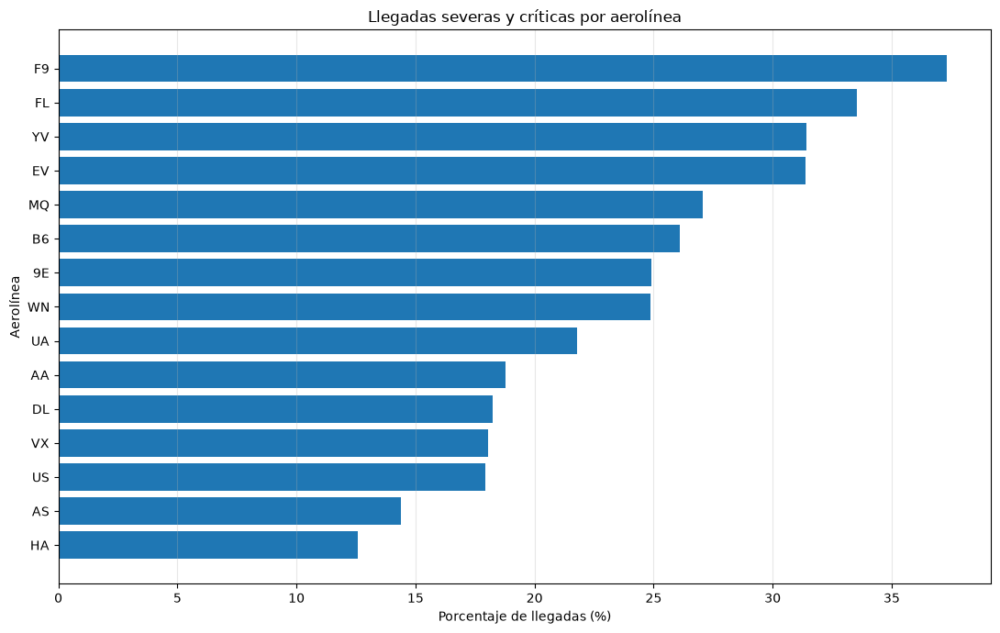

Puntualidad general según el tipo de aerolínea.
Se conservan las cuatro categorías, incluida 'Otro'.


,vuelos_evaluables,aerolineas,llegadas_severas,llegadas_criticas,llegadas_graves,pct_severas,pct_criticas,pct_graves
_tipo_aerolinea,,,,,,,,
Tradicional,158269,6,11623,19367,30990,7.34,12.24,19.58
Regional,93468,4,7913,19208,27121,8.47,20.55,29.02
Bajo costo,75065,5,6550,12798,19348,8.73,17.05,25.77
Otro,544,1,45,126,171,8.27,23.16,31.43


Gráfico 2: porcentaje de llegadas severas y críticas según el tipo de aerolínea.
Permite comparar compañías tradicionales, regionales, de bajo costo y la categoría 'Otro'.


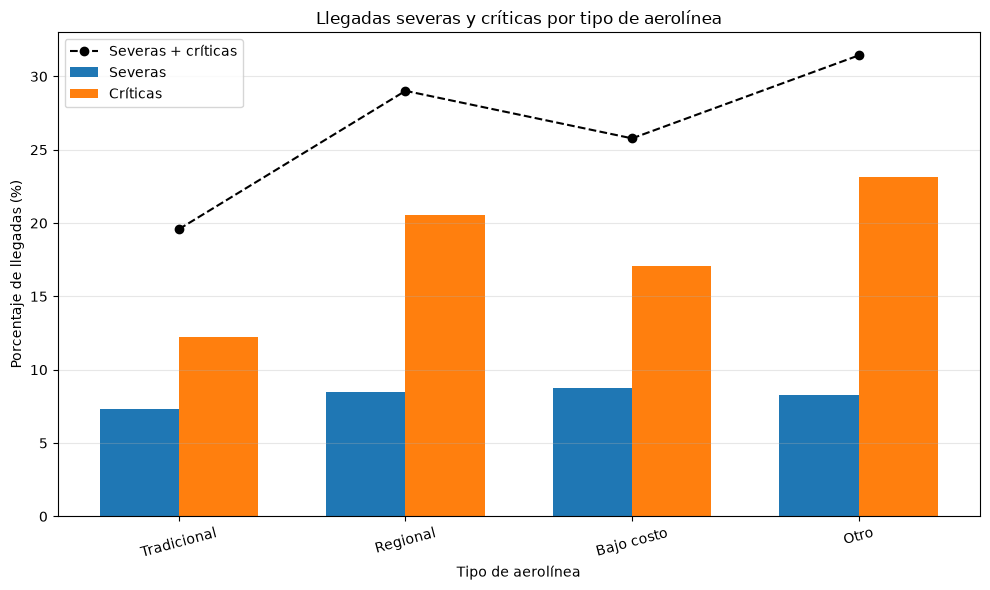

Porcentaje de llegadas severas y críticas según aerolínea y cantidad de vuelos diarios de la aeronave.
Las celdas representan la puntualidad de los vuelos actuales dentro de cada grupo de actividad.


_grupo_actividad,1 vuelo,2 vuelos,3 vuelos,4 vuelos,5 o más vuelos
aerolinea,,,,,
9E,26.11,23.15,23.79,41.67,NaN
AA,19.82,16.66,15.29,NaN,NaN
AS,14.39,NaN,NaN,NaN,NaN
B6,27.13,25.74,25.53,23.24,37.22
DL,18.44,17.77,20.17,0.00,NaN
EV,30.41,32.03,31.67,32.60,40.00
F9,37.00,62.50,NaN,NaN,NaN
FL,33.61,33.79,31.25,NaN,NaN
HA,12.57,NaN,NaN,NaN,NaN


Cantidad de vuelos evaluables en cada combinación de aerolínea y actividad.


_grupo_actividad,1 vuelo,2 vuelos,3 vuelos,4 vuelos,5 o más vuelos
aerolinea,,,,,
9E,9955,5965,1362,12,0
AA,21921,9241,785,0,0
AS,709,0,0,0,0
B6,19500,20009,10497,3683,360
DL,30422,16513,719,4,0
EV,19198,19286,11164,1445,15
F9,673,8,0,0,0
FL,2368,663,144,0,0
HA,342,0,0,0,0


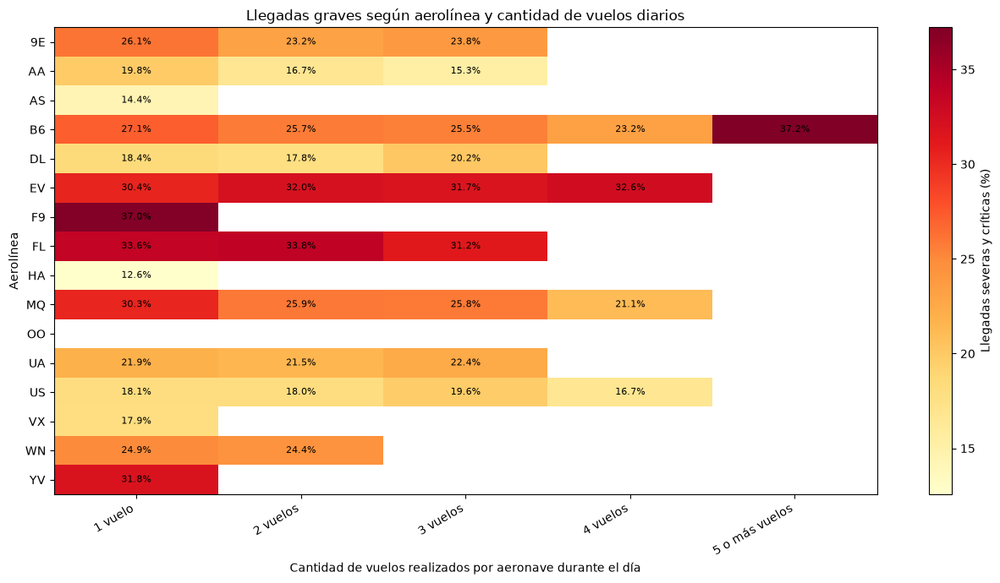

Porcentaje de llegadas severas y críticas por aerolínea y orden real del vuelo.
Permite observar si las operaciones posteriores presentan peores resultados dentro de cada compañía.


_grupo_orden,1.er vuelo,2.º vuelo,3.er vuelo,4.º vuelo,5.º o posterior
aerolinea,,,,,
9E,23.64,28.50,35.16,66.67,NaN
AA,18.04,22.18,32.57,NaN,NaN
AS,14.39,NaN,NaN,NaN,NaN
B6,23.48,29.47,33.33,33.23,43.06
DL,16.83,24.32,30.71,0.00,NaN
EV,27.17,36.68,45.49,51.37,66.67
F9,36.93,100.00,NaN,NaN,NaN
FL,32.63,40.48,31.25,NaN,NaN
HA,12.57,NaN,NaN,NaN,NaN


Cantidad de vuelos evaluables por aerolínea y posición.


_grupo_orden,1.er vuelo,2.º vuelo,3.er vuelo,4.º vuelo,5.º o posterior
aerolinea,,,,,
9E,13401,3435,455,3,0
AA,26812,4874,261,0,0
AS,709,0,0,0,0
B6,34011,14488,4485,993,72
DL,38926,8490,241,1,0
EV,32950,13718,4073,364,3
F9,677,4,0,0,0
FL,2749,378,48,0,0
HA,342,0,0,0,0


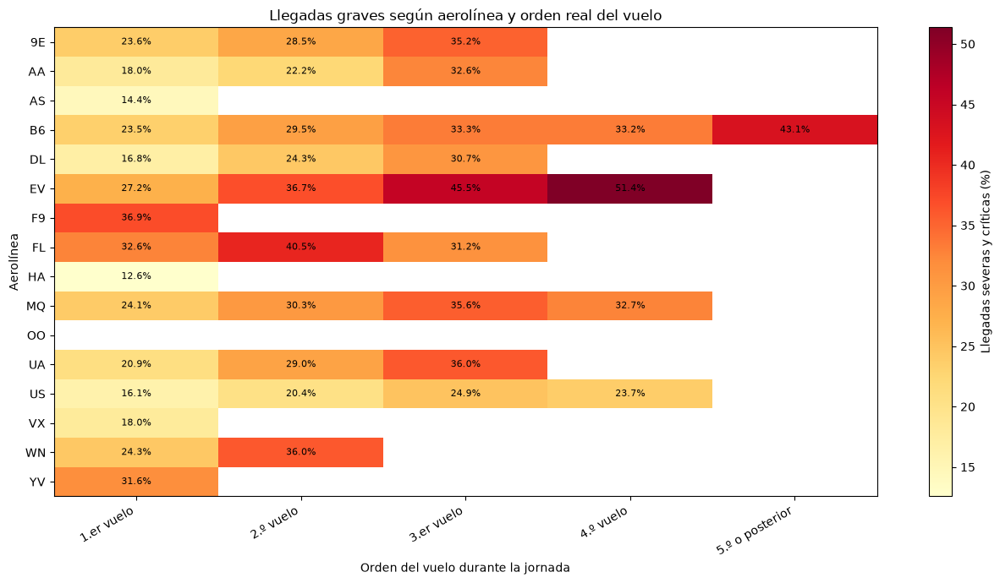

Comparación por aerolínea entre el primer vuelo y los vuelos posteriores.
La diferencia se calcula como porcentaje de vuelos posteriores menos porcentaje del primer vuelo.


_primer_vs_posterior,Primer vuelo,Vuelos posteriores,diferencia_puntos_porcentuales
aerolinea,,,
9E,23.64,29.31,5.67
AA,18.04,22.71,4.66
AS,14.39,NaN,NaN
B6,23.48,30.57,7.09
DL,16.83,24.50,7.67
EV,27.17,38.96,11.78
F9,36.93,100.00,NaN
FL,32.63,39.44,6.81
HA,12.57,NaN,NaN


Puntualidad de llegada por aerolínea según la demora de llegada del vuelo anterior.


_estado_previo,Anterior sin demora positiva,Anterior con demora positiva
aerolinea,,
9E,22.69,28.54
AA,17.07,21.82
AS,9.53,21.64
B6,20.63,33.30
DL,15.94,22.70
EV,25.25,37.82
F9,32.25,40.63
FL,29.08,37.31
HA,12.45,12.63


Cantidad de vuelos evaluables en cada grupo.


_estado_previo,Anterior sin demora positiva,Anterior con demora positiva
aerolinea,,
9E,10210,6381
AA,20343,10146
AS,451,171
B6,30214,23210
DL,30387,15821
EV,26213,24077
F9,276,379
FL,1231,1804
HA,233,95


Gráfico 5: diferencia en el porcentaje de llegadas graves según el estado del vuelo anterior.
La diferencia se calcula como: anterior con demora positiva menos anterior sin demora positiva.
Los valores positivos indican una mayor proporción de llegadas graves cuando el vuelo anterior llegó demorado.


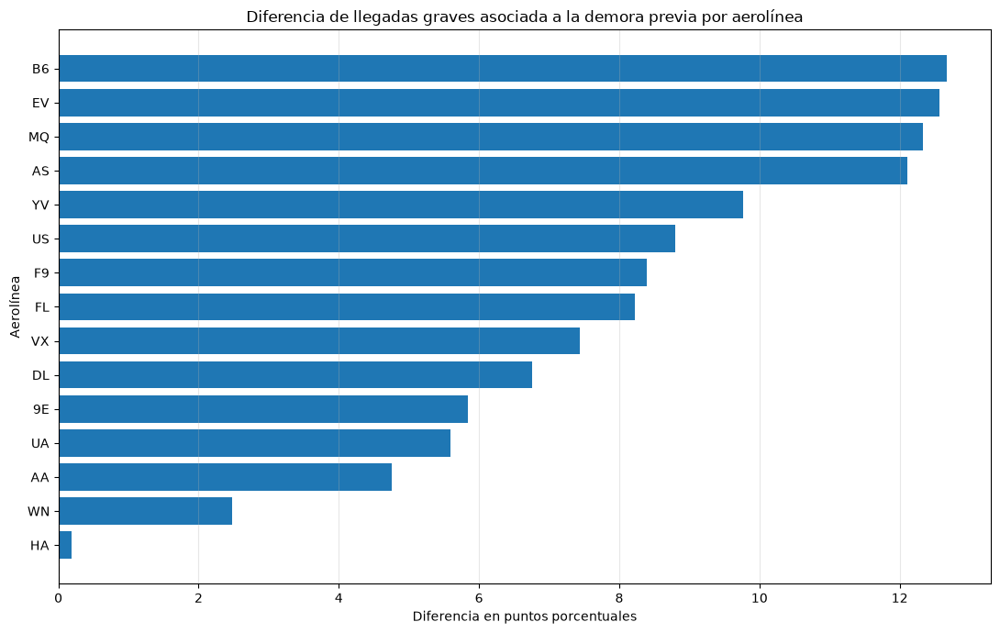

Análisis complementario: puntualidad actual según la demora de salida del vuelo anterior.


_estado_previo,Anterior sin demora positiva,Anterior con demora positiva
aerolinea,,
9E,22.74,28.35
AA,17.60,21.11
AS,10.40,17.82
B6,22.43,31.85
DL,16.81,21.48
EV,26.45,37.29
F9,35.38,38.97
FL,31.46,36.42
HA,14.18,5.97


Relación entre demora de llegada previa y puntualidad actual según tipo de aerolínea.
Se compara si la asociación entre demora anterior y llegada grave cambia entre los tipos de compañía.


_estado_previo,Anterior sin demora positiva,Anterior con demora positiva
_tipo_aerolinea,,
Tradicional,17.30,23.63
Regional,23.69,35.27
Bajo costo,21.11,32.09
Otro,26.88,36.64


Diferencia en puntos porcentuales según tipo de aerolínea.


_tipo_aerolinea
Tradicional     6.32
Regional       11.58
Bajo costo     10.98
Otro            9.76
dtype: float64

Porcentaje de llegadas severas y críticas según aerolínea e intervalo desde la última salida.
Permite observar si los intervalos más cortos se asocian con más demoras graves dentro de cada compañía.


_grupo_intervalo,Menos de 1 hora,1 a menos de 2 horas,2 a menos de 4 horas,4 a menos de 8 horas,8 a menos de 12 horas,12 a menos de 24 horas,24 horas o más
aerolinea,,,,,,,
9E,NaN,NaN,27.73,27.04,28.21,18.83,26.41
AA,NaN,NaN,41.67,15.66,24.86,14.06,19.99
AS,NaN,NaN,NaN,NaN,NaN,5.88,12.99
B6,NaN,NaN,19.64,28.48,30.38,21.84,26.48
DL,11.76,4.17,14.75,17.12,37.41,13.18,19.00
EV,NaN,100.00,29.95,38.26,33.12,23.81,30.78
F9,NaN,NaN,NaN,NaN,100.00,23.73,38.11
FL,NaN,NaN,25.00,38.94,27.91,32.39,33.54
HA,NaN,NaN,NaN,NaN,NaN,0.00,12.58


Cantidad de vuelos evaluables en cada combinación.


_grupo_intervalo,Menos de 1 hora,1 a menos de 2 horas,2 a menos de 4 horas,4 a menos de 8 horas,8 a menos de 12 horas,12 a menos de 24 horas,24 horas o más
aerolinea,,,,,,,
9E,0,0,220,2592,982,3510,9403
AA,0,0,12,2082,2466,7189,18884
AS,0,0,0,0,0,17,608
B6,0,0,2327,10158,6422,10172,24460
DL,34,24,61,5164,2550,11892,26582
EV,0,1,2421,12551,4590,10717,20256
F9,0,0,0,0,4,59,593
FL,0,0,8,398,86,142,2412
HA,0,0,0,0,0,2,326


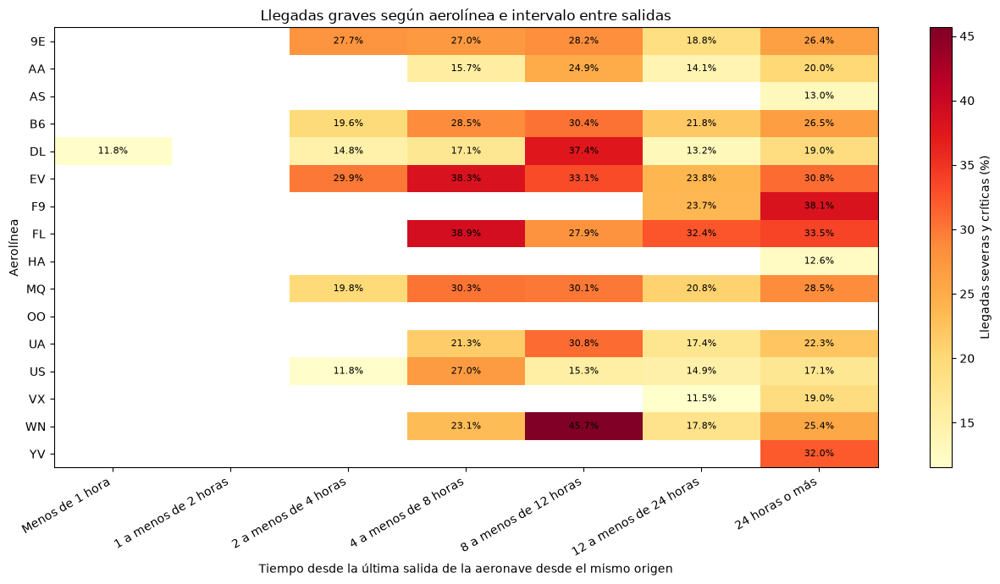

Puntualidad según el tipo de aerolínea y la cantidad de vuelos diarios de la aeronave.


_grupo_actividad,1 vuelo,2 vuelos,3 vuelos,4 vuelos,5 o más vuelos
_tipo_aerolinea,,,,,
Tradicional,20.05,18.62,19.43,16.69,46.67
Regional,29.22,28.76,29.09,29.14,40.00
Bajo costo,25.85,25.95,25.61,23.24,37.22
Otro,31.78,0.00,NaN,NaN,NaN


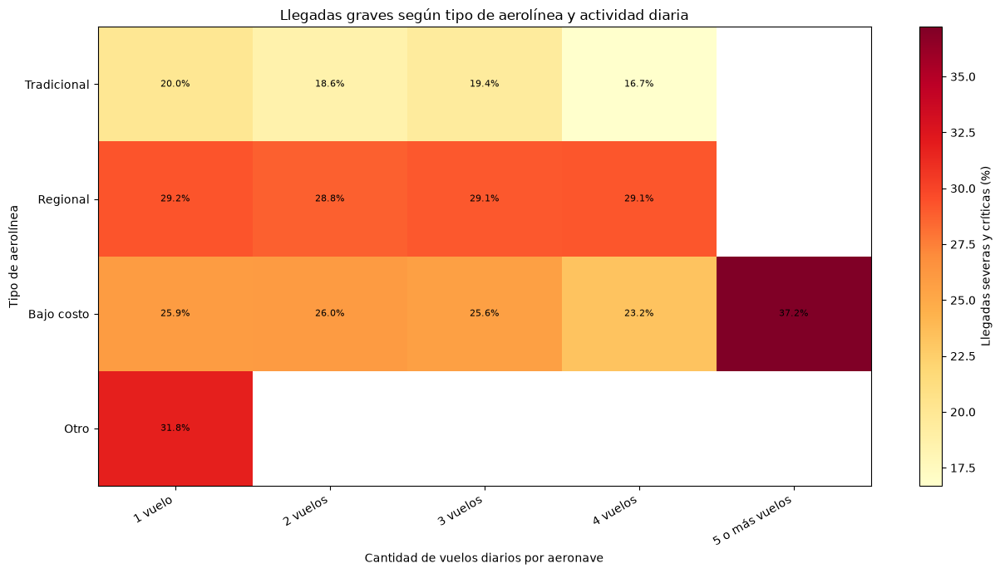

Puntualidad según el tipo de aerolínea y el intervalo desde la última salida.


_grupo_intervalo,Menos de 1 hora,1 a menos de 2 horas,2 a menos de 4 horas,4 a menos de 8 horas,8 a menos de 12 horas,12 a menos de 24 horas,24 horas o más
_tipo_aerolinea,,,,,,,
Tradicional,10.81,4.17,12.13,20.22,29.95,14.88,20.29
Regional,NaN,100.00,28.65,34.21,31.71,22.03,29.22
Bajo costo,NaN,NaN,19.64,28.82,30.68,21.35,26.00
Otro,NaN,NaN,NaN,0.00,NaN,0.00,32.01


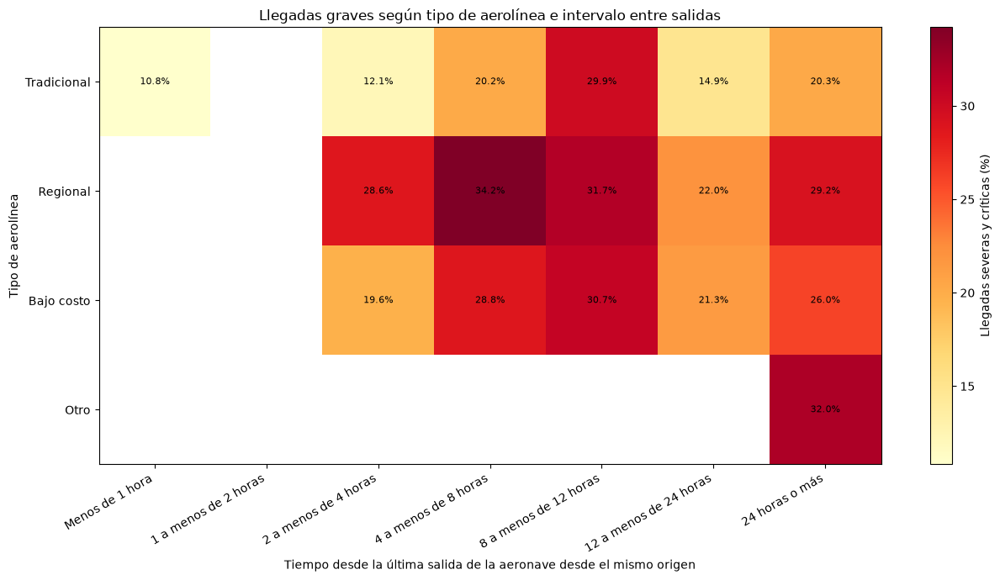

Resumen final: aerolíneas con mayor porcentaje de llegadas graves y con mayor diferencia asociada a una demora previa.


,nombre_aerolinea,tipo_aerolinea,vuelos_evaluables,pct_graves,diferencia_por_demora_previa_pp,diferencia_primer_vs_posteriores_pp
aerolinea,,,,,,
F9,Frontier Airlines Inc.,Bajo costo,681,37.30,8.39,NaN
FL,AirTran Airways Corporation,Bajo costo,3175,33.54,8.22,6.81
YV,Mesa Airlines Inc.,Otro,544,31.43,9.76,NaN
EV,ExpressJet Airlines Inc.,Regional,51108,31.36,12.56,11.78
MQ,Envoy Air,Regional,25037,27.07,12.33,7.52
B6,JetBlue Airways,Bajo costo,54049,26.11,12.67,7.09
9E,Endeavor Air Inc.,Regional,17294,24.92,5.84,5.67
WN,Southwest Airlines Co.,Bajo costo,12044,24.86,2.47,11.74
OO,SkyWest Airlines Inc.,Regional,29,24.14,NaN,NaN


In [97]:
# ==========================================================
# 7.5. EFECTO CASCADA SEGÚN LA AEROLÍNEA
# ==========================================================

MIN_EVALUABLES = 30
MIN_AEROLINEA = 100

# Grupos de cantidad de operaciones diarias
orden_actividad = [
    "1 vuelo",
    "2 vuelos",
    "3 vuelos",
    "4 vuelos",
    "5 o más vuelos"
]

# Grupos de orden real
orden_orden = [
    "1.er vuelo",
    "2.º vuelo",
    "3.er vuelo",
    "4.º vuelo",
    "5.º o posterior"
]

# Estados del vuelo anterior
orden_estado_anterior = [
    "Anterior sin demora positiva",
    "Anterior con demora positiva"
]

# Intervalos desde la última salida
orden_intervalos = [
    "Menos de 1 hora",
    "1 a menos de 2 horas",
    "2 a menos de 4 horas",
    "4 a menos de 8 horas",
    "8 a menos de 12 horas",
    "12 a menos de 24 horas",
    "24 horas o más"
]

# Categorías de llegada evaluables
niveles_evaluables = [
    "adelantado",
    "a tiempo",
    "aceptable",
    "moderado",
    "severo",
    "critico"
]


# ==========================================================
# 1. PREPARACIÓN DE LOS DATOS
# ==========================================================

# Utilizar vuelos operados con aerolínea identificada.

operados = df.loc[
    (df["estado_vuelo"] == "operado") &
    (df["aerolinea"].notna())
].copy()

# ----------------------------------------------------------
# 1.1. Cantidad de vuelos diarios por aeronave
# ----------------------------------------------------------

# Obtener la fecha real de salida sin considerar la hora.
operados["_fecha_operacion"] = (
    operados["fecha_hora_salida_real"].dt.normalize()
)

# Calcular la cantidad de vuelos realizados por cada matrícula
# durante cada día, utilizando los vuelos con fecha y matrícula.

operados["_cantidad_vuelos_dia"] = np.nan

validos_actividad = operados.loc[
    operados["matricula_avion"].notna() &
    operados["_fecha_operacion"].notna()
].copy()

validos_actividad["_cantidad_vuelos_dia"] = (
    validos_actividad
    .groupby(
        ["matricula_avion", "_fecha_operacion"]
    )["id"]
    .transform("size")
)

operados.loc[
    validos_actividad.index,
    "_cantidad_vuelos_dia"
] = validos_actividad["_cantidad_vuelos_dia"]

# Agrupar según cantidad de vuelos realizados por jornada.

operados["_grupo_actividad"] = pd.cut(
    operados["_cantidad_vuelos_dia"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=orden_actividad,
    right=True
)

# ----------------------------------------------------------
# 1.2. Preparar el orden real de los vuelos
# ----------------------------------------------------------

operados["_orden_real"] = pd.to_numeric(
    operados["numero_orden_vuelo_dia_real"],
    errors="coerce"
)

operados["_grupo_orden"] = pd.cut(
    operados["_orden_real"],
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, np.inf],
    labels=orden_orden,
    right=True
)

# ----------------------------------------------------------
# 1.3. Preparar las demoras de los vuelos anteriores
# ----------------------------------------------------------

operados["_demora_anterior_salida"] = pd.to_numeric(
    operados["retraso_vuelo_anterior_salida"],
    errors="coerce"
)

operados["_demora_anterior_arribo"] = pd.to_numeric(
    operados["retraso_vuelo_anterior_arribo"],
    errors="coerce"
)

# ----------------------------------------------------------
# 1.4. Preparar el intervalo desde la última salida
# ----------------------------------------------------------

operados["_intervalo_timedelta"] = pd.to_timedelta(
    operados["tiempo_desde_ultima_salida_avion_origen"],
    errors="coerce"
)

operados["_intervalo_horas"] = (
    operados["_intervalo_timedelta"].dt.total_seconds() / 3600
)

# ----------------------------------------------------------
# 1.5. Seleccionar vuelos con llegada evaluable
# ----------------------------------------------------------

base = operados.loc[
    operados["nivel_puntualidad_arribo"].isin(niveles_evaluables)
].copy()

# Indicadores de puntualidad de llegada del vuelo actual

base["_arribo_severo"] = (
    base["nivel_puntualidad_arribo"] == "severo"
)

base["_arribo_critico"] = (
    base["nivel_puntualidad_arribo"] == "critico"
)

base["_arribo_grave"] = (
    base["_arribo_severo"] |
    base["_arribo_critico"]
)

# Demoras actuales

base["_demora_salida_actual"] = pd.to_numeric(
    base["demora_salida_min"],
    errors="coerce"
)

base["_demora_arribo_actual"] = pd.to_numeric(
    base["demora_arribo_min"],
    errors="coerce"
)

# Mantener el orden de los tipos de aerolínea
orden_tipos = [
    "Tradicional",
    "Regional",
    "Bajo costo",
    "Otro"
]

base["_tipo_aerolinea"] = pd.Categorical(
    base["tipo_aerolinea"],
    categories=orden_tipos,
    ordered=True
)

print("Preparación del análisis del efecto cascada según la aerolínea.")
print(f"Vuelos operados: {len(operados):,}")
print(f"Vuelos con llegada evaluable: {len(base):,}")
print(
    "Vuelos excluidos por llegada desconocida:",
    f"{len(operados) - len(base):,}"
)


# ==========================================================
# 2. RESULTADOS GENERALES POR AEROLÍNEA
# ==========================================================

resumen_aerolineas = (
    base.groupby("aerolinea")
    .agg(
        nombre_aerolinea=("nombre_aerolinea", "first"),
        tipo_aerolinea=("_tipo_aerolinea", "first"),
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
)

resumen_aerolineas["pct_severas"] = (
    resumen_aerolineas["llegadas_severas"] /
    resumen_aerolineas["vuelos_evaluables"] * 100
)

resumen_aerolineas["pct_criticas"] = (
    resumen_aerolineas["llegadas_criticas"] /
    resumen_aerolineas["vuelos_evaluables"] * 100
)

resumen_aerolineas["pct_graves"] = (
    resumen_aerolineas["llegadas_graves"] /
    resumen_aerolineas["vuelos_evaluables"] * 100
)

resumen_aerolineas["muestra_suficiente"] = (
    resumen_aerolineas["vuelos_evaluables"] >= MIN_AEROLINEA
)

print("Puntualidad general de llegada por aerolínea.")
print("Se muestran todas las compañías; la columna de muestra permite identificar las que tienen menos de 100 vuelos evaluables.")

display(
    resumen_aerolineas.sort_values(
        "pct_graves",
        ascending=False
    ).round(2)
)


# ----------------------------------------------------------
# Gráfico 1: puntualidad general por aerolínea
# ----------------------------------------------------------

aerolineas_comparables = resumen_aerolineas.loc[
    resumen_aerolineas["muestra_suficiente"]
].sort_values("pct_graves")

print("Gráfico 1: porcentaje de llegadas severas y críticas por aerolínea.")
print(f"Se muestran compañías con al menos {MIN_AEROLINEA} vuelos evaluables.")
print("Este gráfico funciona como referencia general para interpretar los análisis posteriores.")

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    aerolineas_comparables.index.astype(str),
    aerolineas_comparables["pct_graves"]
)

ax.set_title("Llegadas severas y críticas por aerolínea")
ax.set_xlabel("Porcentaje de llegadas (%)")
ax.set_ylabel("Aerolínea")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 3. RESULTADOS GENERALES POR TIPO DE AEROLÍNEA
# ==========================================================

resumen_tipos = (
    base.groupby("_tipo_aerolinea", observed=False)
    .agg(
        vuelos_evaluables=("id", "size"),
        aerolineas=("aerolinea", "nunique"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reindex(orden_tipos)
)

resumen_tipos["pct_severas"] = (
    resumen_tipos["llegadas_severas"] /
    resumen_tipos["vuelos_evaluables"] * 100
)

resumen_tipos["pct_criticas"] = (
    resumen_tipos["llegadas_criticas"] /
    resumen_tipos["vuelos_evaluables"] * 100
)

resumen_tipos["pct_graves"] = (
    resumen_tipos["llegadas_graves"] /
    resumen_tipos["vuelos_evaluables"] * 100
)

print("Puntualidad general según el tipo de aerolínea.")
print("Se conservan las cuatro categorías, incluida 'Otro'.")

display(resumen_tipos.round(2))


# ----------------------------------------------------------
# Gráfico 2: puntualidad por tipo de aerolínea
# ----------------------------------------------------------

print("Gráfico 2: porcentaje de llegadas severas y críticas según el tipo de aerolínea.")
print("Permite comparar compañías tradicionales, regionales, de bajo costo y la categoría 'Otro'.")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(orden_tipos))
ancho = 0.35

ax.bar(
    x - ancho / 2,
    resumen_tipos["pct_severas"],
    width=ancho,
    label="Severas"
)

ax.bar(
    x + ancho / 2,
    resumen_tipos["pct_criticas"],
    width=ancho,
    label="Críticas"
)

ax.plot(
    x,
    resumen_tipos["pct_graves"],
    marker="o",
    linestyle="--",
    color="black",
    label="Severas + críticas"
)

ax.set_xticks(x)
ax.set_xticklabels(orden_tipos, rotation=15)
ax.set_title("Llegadas severas y críticas por tipo de aerolínea")
ax.set_xlabel("Tipo de aerolínea")
ax.set_ylabel("Porcentaje de llegadas (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. FUNCIÓN PARA CREAR MAPAS DE CALOR
# ==========================================================

def graficar_heatmap(matriz, titulo, xlabel, ylabel):

    matriz = matriz.copy()

    fig, ax = plt.subplots(figsize=(13, 7))

    valores = matriz.to_numpy(dtype=float)
    valores_mascara = np.ma.masked_invalid(valores)

    imagen = ax.imshow(
        valores_mascara,
        cmap="YlOrRd",
        aspect="auto"
    )

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(
        matriz.columns.astype(str),
        rotation=30,
        ha="right"
    )

    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index.astype(str))

    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # Mostrar porcentajes únicamente donde hay datos válidos
    for i in range(len(matriz.index)):
        for j in range(len(matriz.columns)):

            valor = matriz.iloc[i, j]

            if pd.notna(valor):
                ax.text(
                    j,
                    i,
                    f"{valor:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=8
                )

    fig.colorbar(
        imagen,
        ax=ax,
        label="Llegadas severas y críticas (%)"
    )

    plt.tight_layout()
    plt.show()


# ==========================================================
# 5. CANTIDAD DE VUELOS DIARIOS Y PUNTUALIDAD POR AEROLÍNEA
# ==========================================================

base_actividad = base.loc[
    base["_grupo_actividad"].notna()
].copy()

resumen_actividad = (
    base_actividad
    .groupby(
        ["aerolinea", "_grupo_actividad"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_actividad["pct_graves"] = (
    resumen_actividad["llegadas_graves"] /
    resumen_actividad["vuelos_evaluables"] * 100
)

# Tabla de porcentajes por aerolínea y cantidad de vuelos diarios

tabla_actividad = (
    resumen_actividad
    .pivot(
        index="aerolinea",
        columns="_grupo_actividad",
        values="pct_graves"
    )
    .reindex(columns=orden_actividad)
)

tabla_actividad_conteos = (
    resumen_actividad
    .pivot(
        index="aerolinea",
        columns="_grupo_actividad",
        values="vuelos_evaluables"
    )
    .reindex(columns=orden_actividad)
)

# En el mapa se ocultan las combinaciones con menos de 30 vuelos.

tabla_actividad_grafico = tabla_actividad.where(
    tabla_actividad_conteos >= MIN_EVALUABLES
)

print("Porcentaje de llegadas severas y críticas según aerolínea y cantidad de vuelos diarios de la aeronave.")
print("Las celdas representan la puntualidad de los vuelos actuales dentro de cada grupo de actividad.")

display(tabla_actividad.round(2))

print("Cantidad de vuelos evaluables en cada combinación de aerolínea y actividad.")

display(tabla_actividad_conteos.fillna(0).astype(int))


# Gráfico 3: actividad diaria por aerolínea

graficar_heatmap(
    tabla_actividad_grafico,
    "Llegadas graves según aerolínea y cantidad de vuelos diarios",
    "Cantidad de vuelos realizados por aeronave durante el día",
    "Aerolínea"
)


# ==========================================================
# 6. ORDEN REAL DE LOS VUELOS Y PUNTUALIDAD POR AEROLÍNEA
# ==========================================================

base_orden = base.loc[
    base["_grupo_orden"].notna()
].copy()

resumen_orden = (
    base_orden
    .groupby(
        ["aerolinea", "_grupo_orden"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_severas=("_arribo_severo", "sum"),
        llegadas_criticas=("_arribo_critico", "sum"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_orden["pct_graves"] = (
    resumen_orden["llegadas_graves"] /
    resumen_orden["vuelos_evaluables"] * 100
)

tabla_orden = (
    resumen_orden
    .pivot(
        index="aerolinea",
        columns="_grupo_orden",
        values="pct_graves"
    )
    .reindex(columns=orden_orden)
)

tabla_orden_conteos = (
    resumen_orden
    .pivot(
        index="aerolinea",
        columns="_grupo_orden",
        values="vuelos_evaluables"
    )
    .reindex(columns=orden_orden)
)

tabla_orden_grafico = tabla_orden.where(
    tabla_orden_conteos >= MIN_EVALUABLES
)

print("Porcentaje de llegadas severas y críticas por aerolínea y orden real del vuelo.")
print("Permite observar si las operaciones posteriores presentan peores resultados dentro de cada compañía.")

display(tabla_orden.round(2))

print("Cantidad de vuelos evaluables por aerolínea y posición.")

display(tabla_orden_conteos.fillna(0).astype(int))


# Gráfico 4: orden del vuelo por aerolínea

graficar_heatmap(
    tabla_orden_grafico,
    "Llegadas graves según aerolínea y orden real del vuelo",
    "Orden del vuelo durante la jornada",
    "Aerolínea"
)


# ==========================================================
# 7. PRIMER VUELO FRENTE A LOS VUELOS POSTERIORES POR AEROLÍNEA
# ==========================================================

base_orden["_primer_vs_posterior"] = np.where(
    base_orden["_orden_real"] == 1,
    "Primer vuelo",
    "Vuelos posteriores"
)

orden_primer_posterior = [
    "Primer vuelo",
    "Vuelos posteriores"
]

resumen_primer_posterior = (
    base_orden
    .groupby(
        ["aerolinea", "_primer_vs_posterior"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_primer_posterior["pct_graves"] = (
    resumen_primer_posterior["llegadas_graves"] /
    resumen_primer_posterior["vuelos_evaluables"] * 100
)

tabla_primer_posterior = (
    resumen_primer_posterior
    .pivot(
        index="aerolinea",
        columns="_primer_vs_posterior",
        values="pct_graves"
    )
    .reindex(columns=orden_primer_posterior)
)

conteos_primer_posterior = (
    resumen_primer_posterior
    .pivot(
        index="aerolinea",
        columns="_primer_vs_posterior",
        values="vuelos_evaluables"
    )
    .reindex(columns=orden_primer_posterior)
)

# Diferencia: posteriores menos primer vuelo.
# Solo se calcula cuando ambos grupos tienen al menos 30 casos.

tabla_diferencia_orden = (
    tabla_primer_posterior["Vuelos posteriores"] -
    tabla_primer_posterior["Primer vuelo"]
)

tabla_diferencia_orden = tabla_diferencia_orden.where(
    (conteos_primer_posterior["Primer vuelo"] >= MIN_EVALUABLES) &
    (conteos_primer_posterior["Vuelos posteriores"] >= MIN_EVALUABLES)
)

print("Comparación por aerolínea entre el primer vuelo y los vuelos posteriores.")
print("La diferencia se calcula como porcentaje de vuelos posteriores menos porcentaje del primer vuelo.")

tabla_comparacion_orden = tabla_primer_posterior.copy()
tabla_comparacion_orden["diferencia_puntos_porcentuales"] = (
    tabla_diferencia_orden
)

display(tabla_comparacion_orden.round(2))


# ==========================================================
# 8. DEMORA DEL VUELO ANTERIOR Y PUNTUALIDAD POR AEROLÍNEA
# ==========================================================

def resumir_demora_previa(datos, columna_previa, agrupador):

    # Conservar vuelos con información de la demora anterior
    muestra = datos.loc[
        datos[columna_previa].notna()
    ].copy()

    # Clasificar el vuelo anterior
    muestra["_estado_previo"] = np.where(
        muestra[columna_previa] > 0,
        "Anterior con demora positiva",
        "Anterior sin demora positiva"
    )

    # Resumen
    resumen = (
        muestra
        .groupby(
            [agrupador, "_estado_previo"],
            observed=True
        )
        .agg(
            vuelos_evaluables=("id", "size"),
            llegadas_severas=("_arribo_severo", "sum"),
            llegadas_criticas=("_arribo_critico", "sum"),
            llegadas_graves=("_arribo_grave", "sum"),
            mediana_demora_previa=(columna_previa, "median")
        )
        .reset_index()
    )

    resumen["pct_severas"] = (
        resumen["llegadas_severas"] /
        resumen["vuelos_evaluables"] * 100
    )

    resumen["pct_criticas"] = (
        resumen["llegadas_criticas"] /
        resumen["vuelos_evaluables"] * 100
    )

    resumen["pct_graves"] = (
        resumen["llegadas_graves"] /
        resumen["vuelos_evaluables"] * 100
    )

    return resumen


# ----------------------------------------------------------
# 8.1. Demora de llegada del vuelo anterior
# ----------------------------------------------------------

resumen_previo_arribo = resumir_demora_previa(
    base,
    "retraso_vuelo_anterior_arribo",
    "aerolinea"
)

tabla_previo_arribo = (
    resumen_previo_arribo
    .pivot(
        index="aerolinea",
        columns="_estado_previo",
        values="pct_graves"
    )
    .reindex(columns=orden_estado_anterior)
)

conteos_previo_arribo = (
    resumen_previo_arribo
    .pivot(
        index="aerolinea",
        columns="_estado_previo",
        values="vuelos_evaluables"
    )
    .reindex(columns=orden_estado_anterior)
)

# Diferencia entre grupos:
# demora previa positiva menos ausencia de demora positiva.

tabla_diferencia_previa = (
    tabla_previo_arribo["Anterior con demora positiva"] -
    tabla_previo_arribo["Anterior sin demora positiva"]
)

tabla_diferencia_previa = tabla_diferencia_previa.where(
    (conteos_previo_arribo["Anterior con demora positiva"] >= MIN_EVALUABLES) &
    (conteos_previo_arribo["Anterior sin demora positiva"] >= MIN_EVALUABLES)
)

print("Puntualidad de llegada por aerolínea según la demora de llegada del vuelo anterior.")

display(
    tabla_previo_arribo.round(2)
)

print("Cantidad de vuelos evaluables en cada grupo.")

display(
    conteos_previo_arribo.fillna(0).astype(int)
)


# Gráfico 5: diferencia de llegadas graves según demora anterior

diferencias_aerolineas = (
    tabla_diferencia_previa
    .dropna()
    .sort_values()
)

print("Gráfico 5: diferencia en el porcentaje de llegadas graves según el estado del vuelo anterior.")
print("La diferencia se calcula como: anterior con demora positiva menos anterior sin demora positiva.")
print("Los valores positivos indican una mayor proporción de llegadas graves cuando el vuelo anterior llegó demorado.")

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    diferencias_aerolineas.index.astype(str),
    diferencias_aerolineas.values
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    alpha=0.7
)

ax.set_title("Diferencia de llegadas graves asociada a la demora previa por aerolínea")
ax.set_xlabel("Diferencia en puntos porcentuales")
ax.set_ylabel("Aerolínea")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 8.2. Demora de salida del vuelo anterior
# ----------------------------------------------------------

resumen_previo_salida = resumir_demora_previa(
    base,
    "retraso_vuelo_anterior_salida",
    "aerolinea"
)

tabla_previo_salida = (
    resumen_previo_salida
    .pivot(
        index="aerolinea",
        columns="_estado_previo",
        values="pct_graves"
    )
    .reindex(columns=orden_estado_anterior)
)

print("Análisis complementario: puntualidad actual según la demora de salida del vuelo anterior.")

display(tabla_previo_salida.round(2))


# ==========================================================
# 9. COMPARACIÓN DE LA DEMORA PREVIA SEGÚN EL TIPO DE AEROLÍNEA
# ==========================================================

resumen_previo_tipo = resumir_demora_previa(
    base,
    "retraso_vuelo_anterior_arribo",
    "_tipo_aerolinea"
)

tabla_previo_tipo = (
    resumen_previo_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_estado_previo",
        values="pct_graves"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_estado_anterior
    )
)

conteos_previo_tipo = (
    resumen_previo_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_estado_previo",
        values="vuelos_evaluables"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_estado_anterior
    )
)

tabla_diferencia_previa_tipo = (
    tabla_previo_tipo["Anterior con demora positiva"] -
    tabla_previo_tipo["Anterior sin demora positiva"]
)

tabla_diferencia_previa_tipo = tabla_diferencia_previa_tipo.where(
    (conteos_previo_tipo["Anterior con demora positiva"] >= MIN_EVALUABLES) &
    (conteos_previo_tipo["Anterior sin demora positiva"] >= MIN_EVALUABLES)
)

print("Relación entre demora de llegada previa y puntualidad actual según tipo de aerolínea.")
print("Se compara si la asociación entre demora anterior y llegada grave cambia entre los tipos de compañía.")

display(tabla_previo_tipo.round(2))

print("Diferencia en puntos porcentuales según tipo de aerolínea.")

display(tabla_diferencia_previa_tipo.round(2))


# ==========================================================
# 10. INTERVALO ENTRE SALIDAS Y PUNTUALIDAD POR AEROLÍNEA
# ==========================================================

# Utilizar intervalos positivos disponibles.
base_intervalos = base.loc[
    base["_intervalo_horas"].notna() &
    (base["_intervalo_horas"] > 0)
].copy()

base_intervalos["_grupo_intervalo"] = pd.cut(
    base_intervalos["_intervalo_horas"],
    bins=[0, 1, 2, 4, 8, 12, 24, np.inf],
    labels=orden_intervalos,
    right=False
)

resumen_intervalos = (
    base_intervalos
    .groupby(
        ["aerolinea", "_grupo_intervalo"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_intervalos["pct_graves"] = (
    resumen_intervalos["llegadas_graves"] /
    resumen_intervalos["vuelos_evaluables"] * 100
)

tabla_intervalos = (
    resumen_intervalos
    .pivot(
        index="aerolinea",
        columns="_grupo_intervalo",
        values="pct_graves"
    )
    .reindex(columns=orden_intervalos)
)

conteos_intervalos = (
    resumen_intervalos
    .pivot(
        index="aerolinea",
        columns="_grupo_intervalo",
        values="vuelos_evaluables"
    )
    .reindex(columns=orden_intervalos)
)

tabla_intervalos_grafico = tabla_intervalos.where(
    conteos_intervalos >= MIN_EVALUABLES
)

print("Porcentaje de llegadas severas y críticas según aerolínea e intervalo desde la última salida.")
print("Permite observar si los intervalos más cortos se asocian con más demoras graves dentro de cada compañía.")

display(tabla_intervalos.round(2))

print("Cantidad de vuelos evaluables en cada combinación.")

display(conteos_intervalos.fillna(0).astype(int))


# Gráfico 6: intervalo por aerolínea

graficar_heatmap(
    tabla_intervalos_grafico,
    "Llegadas graves según aerolínea e intervalo entre salidas",
    "Tiempo desde la última salida de la aeronave desde el mismo origen",
    "Aerolínea"
)


# ==========================================================
# 11. RESUMEN POR TIPO DE AEROLÍNEA Y ACTIVIDAD DIARIA
# ==========================================================

resumen_actividad_tipo = (
    base_actividad
    .groupby(
        ["_tipo_aerolinea", "_grupo_actividad"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_actividad_tipo["pct_graves"] = (
    resumen_actividad_tipo["llegadas_graves"] /
    resumen_actividad_tipo["vuelos_evaluables"] * 100
)

tabla_actividad_tipo = (
    resumen_actividad_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_grupo_actividad",
        values="pct_graves"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_actividad
    )
)

conteos_actividad_tipo = (
    resumen_actividad_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_grupo_actividad",
        values="vuelos_evaluables"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_actividad
    )
)

tabla_actividad_tipo_grafico = tabla_actividad_tipo.where(
    conteos_actividad_tipo >= MIN_EVALUABLES
)

print("Puntualidad según el tipo de aerolínea y la cantidad de vuelos diarios de la aeronave.")

display(tabla_actividad_tipo.round(2))


# Gráfico 7: tipo de aerolínea y actividad

graficar_heatmap(
    tabla_actividad_tipo_grafico,
    "Llegadas graves según tipo de aerolínea y actividad diaria",
    "Cantidad de vuelos diarios por aeronave",
    "Tipo de aerolínea"
)


# ==========================================================
# 12. RESUMEN POR TIPO DE AEROLÍNEA E INTERVALO ENTRE SALIDAS
# ==========================================================

resumen_intervalos_tipo = (
    base_intervalos
    .groupby(
        ["_tipo_aerolinea", "_grupo_intervalo"],
        observed=True
    )
    .agg(
        vuelos_evaluables=("id", "size"),
        llegadas_graves=("_arribo_grave", "sum")
    )
    .reset_index()
)

resumen_intervalos_tipo["pct_graves"] = (
    resumen_intervalos_tipo["llegadas_graves"] /
    resumen_intervalos_tipo["vuelos_evaluables"] * 100
)

tabla_intervalos_tipo = (
    resumen_intervalos_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_grupo_intervalo",
        values="pct_graves"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_intervalos
    )
)

conteos_intervalos_tipo = (
    resumen_intervalos_tipo
    .pivot(
        index="_tipo_aerolinea",
        columns="_grupo_intervalo",
        values="vuelos_evaluables"
    )
    .reindex(
        index=orden_tipos,
        columns=orden_intervalos
    )
)

tabla_intervalos_tipo_grafico = tabla_intervalos_tipo.where(
    conteos_intervalos_tipo >= MIN_EVALUABLES
)

print("Puntualidad según el tipo de aerolínea y el intervalo desde la última salida.")

display(tabla_intervalos_tipo.round(2))


# Gráfico 8: tipo de aerolínea e intervalo

graficar_heatmap(
    tabla_intervalos_tipo_grafico,
    "Llegadas graves según tipo de aerolínea e intervalo entre salidas",
    "Tiempo desde la última salida de la aeronave desde el mismo origen",
    "Tipo de aerolínea"
)


# ==========================================================
# 13. RESUMEN DE LAS DIFERENCIAS ENTRE AEROLÍNEAS
# ==========================================================

print("Resumen final: aerolíneas con mayor porcentaje de llegadas graves y con mayor diferencia asociada a una demora previa.")

resumen_final = resumen_aerolineas[
    [
        "nombre_aerolinea",
        "tipo_aerolinea",
        "vuelos_evaluables",
        "pct_graves"
    ]
].copy()

resumen_final["diferencia_por_demora_previa_pp"] = (
    tabla_diferencia_previa
)

resumen_final["diferencia_primer_vs_posteriores_pp"] = (
    tabla_diferencia_orden
)

display(
    resumen_final.sort_values(
        "pct_graves",
        ascending=False
    ).round(2)
)

#
---
---
---

### Concluciones EDA


#### 0. Análisis Estadístico General de los Vuelos

##### 0.1. Tasa de Ejecución vs. Cancelaciones
* De un total de **336,776 vuelos programados**, el **97.55%** (328,521 vuelos) fueron operados, mientras que el **2.45%** (8,255 vuelos) resultaron cancelados.
* Dentro de los vuelos operados, existen **1,175 registros (0.36%)** sin datos de demora de llegada ni tiempo de vuelo, correspondientes a aeronaves que despegaron pero fueron desviadas a otros aeropuertos o cuyo arribo no quedó registrado.

##### 0.2. Alta Asimetría Positiva y Sesgo en las Demoras
* **La mediana y la moda indican puntualidad o adelanto habitual:** La operación típica (el 50% central de los vuelos) ocurre a tiempo o antes de lo previsto. La mediana de demora de salida es de **-2.0 minutos** (moda: -5 min) y la de llegada es de **-5.0 minutos** (moda: -13 min).
* **El promedio está fuertemente distorsionado por retrasos extremos:** La media de demora de salida sube a **12.64 minutos** (desviación estándar de 40.21 min) y la de llegada a **6.90 minutos** (desviación estándar de 44.63 min). Esta brecha entre media y mediana se explica por una marcada asimetría positiva (4.80 en salida y 3.72 en llegada), generada por una cola derecha de retrasos muy severos.

##### 0.3. Recuperación de Tiempo en el Aire (Buffer Operativo)
* Si bien el 75% de los vuelos salen con hasta 11 minutos de retraso ($Q3 = 11.0\text{ min}$) y llegan con hasta 14 minutos de demora ($Q3 = 14.0\text{ min}$), el promedio de demora en llegada (6.90 min) es casi la mitad que el de salida (12.64 min).
* Esto evidencia que las aerolíneas incorporan márgenes de holgura (*schedule padding*) en sus itinerarios programados, logrando absorber y recuperar en vuelo aproximadamente **5.7 minutos en promedio** respecto al retraso acumulado en pista antes del despegue.

##### 0.4. Comportamiento de Valores Atípicos (Outliers IQR)
* **Concentración casi exclusiva en retrasos:** Aplicando el criterio del Rango Intercuartílico ($Q3 + 1.5 \times \text{IQR}$), se detectan **43,212 outliers superiores (13.15%)** en salida (retrasos mayores a 35 minutos) y **27,789 outliers superiores (8.49%)** en llegada (retrasos mayores a 60.5 minutos). En contraste, los adelantos extremos (outliers inferiores) son estadísticamente insignificantes (0.00% en salida y 0.03% en llegada).
* **Casos más extremos:** Los mayores retrasos registrados superan las 18 a 21 horas y coinciden exactamente en salida y llegada, encabezados por el vuelo ID 7072 (matrícula `N384HA`, ruta `JFK → HNL`, con 1,301 min en salida y 1,272 min en llegada), seguido por los vuelos ID 235778 (`N504MQ`, `JFK → CMH`, 1,137 min) e ID 8239 (`N517MQ`, `EWR → ORD`, 1,126 min).

##### 0.5. Estructura Operativa: Distancias, Aeropuertos y Aerolíneas
* **Perfil de rutas:** El sistema opera mayoritariamente vuelos de corta y media distancia (mediana de 888 millas náuticas y 129 minutos de vuelo; el 75% de los vuelos recorre menos de 1,389 nm), aunque existe un segmento importante de vuelos transcontinentales (percentil 90 en 2,446 nm, con una moda en 2,475 nm, correspondiente a rutas hacia la costa oeste como Los Ángeles y San Francisco).
* **Equilibrio entre aeropuertos de origen:** El volumen de salidas de Nueva York está repartido de forma bastante balanceada entre sus tres terminales principales: Newark (`EWR`) lidera con el **35.88%** (120,835 vuelos), seguido por John F. Kennedy (`JFK`) con el **33.04%** (111,279) y LaGuardia (`LGA`) con el **31.08%** (104,662).
* **Concentración por aerolínea:** Las 5 principales aerolíneas (United, JetBlue, ExpressJet, Delta y American Airlines) concentran el **73.74%** del tráfico total de la región, destacando United Air Lines (17.42%) y JetBlue Airways (16.22%).
* **Distribución horaria:** La mayor carga operativa se concentra en los períodos de Mañana y Tarde para las salidas, desplazándose hacia Tarde y Noche en las llegadas programadas.


#### 1. Análisis por Matrícula de Avión (`tailnum`)

##### 1.1. Datos Generales y Cobertura de la Flota
* **Universo de aeronaves:** El dataset registra **4,037 matrículas distintas** que operaron vuelos durante 2013.
* **Cobertura de datos:** Existe un nivel de registro excelente; de los 328,521 vuelos operados, el **100%** cuenta con matrícula identificada (los 2,512 registros sin matrícula corresponden exclusivamente a vuelos cancelados o datos incompletos no operados).
* **Actividad por avión:** En promedio, cada matrícula realiza múltiples operaciones anuales, aunque la distribución muestra una gran diversidad entre aviones de alta rotación (flotas principales) y aeronaves regionales de menor frecuencia en los aeropuertos de Nueva York.

##### 1.2. Demoras Recurrentes y Niveles de Puntualidad
* **Filtro de fiabilidad estadística:** Para evitar distorsiones por aviones con pocos vuelos, se aislaron las **2,724 matrículas** que cuentan con al menos 30 salidas y llegadas evaluables.
* **Casos críticos aislados:** Al evaluar el criterio estricto de tener más del 30% de los vuelos con demoras severas o críticas en ambas etapas, **solo 5 matrículas** superaron este umbral de forma sostenida, lo que indica que las demoras graves suelen ser sistémicas u operativas más que un defecto exclusivo de aeronaves particulares.
* **Distribución de demoras extremas:** Las demoras superiores a 60 minutos afectan de manera similar tanto a la salida como a la llegada, aunque con una ligera ventaja de absorción en el aire para la gran mayoría de los aviones.

##### 1.3. Relación entre Salida y Llegada (Recuperación en Vuelo)
* **Alta correlación:** Existe una fuerte correlación lineal entre la demora de salida y la de llegada (**Pearson de 0.915** y **Spearman de 0.626**), lo que confirma que un avión que sale tarde arrastra una alta probabilidad de llegar tarde.
* **Capacidad de recuperación (Buffer):** A pesar de la correlación, el **67.7%** de los vuelos (221,565 vuelos) logra disminuir su demora durante el trayecto en el aire. Un **30.2%** incrementa el retraso y apenas un **2.1%** llega exactamente con la misma demora con la que partió, demostrando que las aerolíneas planifican holguras temporales en ruta para mitigar los retrasos iniciales en pista.

##### 1.4. Factores Contextuales y Operativos (Horarios, Días y Estacionalidad)
* **Franjas horarias:** La puntualidad se degrada progresivamente conforme avanza el día. Los vuelos programados para la mañana operan con mayor estabilidad, mientras que las operaciones de tarde y noche acumulan las mayores tasas de demoras severas debido al efecto acumulativo de la congestión aeroportuaria.
* **Tipos de días y estacionalidad:** Al comparar días normales con feriados y vísperas, el comportamiento de las matrículas mantiene una alta correlación, lo que indica que el impacto en feriados afecta de forma global al sistema y no a aviones específicos. A nivel trimestral, se observan variaciones estacionales leves vinculadas principalmente a condiciones meteorológicas adversas (como en el primer trimestre - Q1).
* **Persistencia anual (Semestres):** Al comparar el primer y segundo semestre de 2013, se identifica una fuerte persistencia en el comportamiento de las aeronaves: las matrículas que operaban con alta puntualidad en el primer semestre tendieron a mantener ese estándar, mientras que aquellas con problemas crónicos mantuvieron desvíos similares, salvo casos puntuales de reestructuración de flota.

##### 1.5. Características de Operación y Uso de la Flota
* **Aerolíneas múltiples:** Se detectó que un grupo muy reducido de **17 matrículas** operaron para más de una aerolínea durante el año (típicamente por *leasing*, transferencias o códigos compartidos regionales), mostrando que el cambio de operador no altera drásticamente su perfil de puntualidad si el tipo de ruta se mantiene.
* **Intensidad de uso diario:** El análisis de la cantidad de vuelos diarios por avión (desde 1 hasta 4 o más vuelos por jornada) revela que a mayor rotación diaria, mayor exposición al efecto cascada: los aviones asignados a itinerarios de 3 o 4 tramos por día presentan tasas significativamente más altas de demoras severas en sus últimos vuelos debido a que cualquier inconveniente matutino se propaga al resto del día.
* **Distancia recorrida:** Al clasificar los vuelos en distancias cortas, medias y largas, se observa que los vuelos de corta distancia concentran proporcionalmente mayores porcentajes de demoras severas o críticas (**22.75% en salida** y **24.63% en llegada**), debido a que los tiempos de escala ajustados impiden absorber pequeños contratiempos en tierra, en contraste con los vuelos largos, que disponen de mayor margen en ruta para recuperar tiempo.

#### 2. Análisis por Aerolínea

##### 2.1. Datos Generales y Volumen de Operaciones por Aerolínea
* **Concentración del mercado de Nueva York (2013):** El tráfico aéreo está fuertemente concentrado en un puñado de grandes operadores. United Air Lines encabeza el volumen con **58,665 vuelos (17.4%)**, seguida de cerca por JetBlue Airways (**54,635 vuelos / 16.2%**), ExpressJet Airlines (**54,173 vuelos / 16.1%**) y Delta Air Lines (**48,110 vuelos / 14.3%**). Estas cuatro compañías gestionan más del **64%** de toda la operación regional.
* **Diversidad de flota:** Las aerolíneas varían significativamente en la cantidad de matrículas distintas que movilizan y en la intensidad con la que operan cada aeronave individual, diferenciando a los transportistas principales de las aerolíneas regionales (*feeder airlines*).

##### 2.2. Demoras y Niveles de Puntualidad por Aerolínea
* **Desempeño dispar entre compañías:** Existe una brecha considerable en los niveles de puntualidad según la aerolínea:
  * **Extremo más puntual:** Destacan Alaska Airlines (demora media de llegada de **-9.93 min**) y Hawaiian Airlines (**-6.92 min**).
  * **Extremo más demorado:** Aerolíneas como Frontier Airlines (demora media de llegada de **21.92 min**) y AirTran Airways (**20.12 min**) registran los mayores retrasos promedio y las tasas más elevadas de demoras severas y críticas.
* **Efecto de red:** Las aerolíneas con bases masivas de conexión (*hubs*) en los aeropuertos de Nueva York experimentan presiones operativas constantes que influyen directamente en sus índices de puntualidad.

##### 2.3. Distribución de las Demoras entre las Matrículas de cada Aerolínea
* **Naturaleza sistémica vs. localizada:** El análisis de las demoras severas a nivel de matrícula dentro de cada aerolínea demuestra que los retrasos graves no suelen recaer en aviones aislados o defectuosos, sino que se distribuyen de manera generalizada entre la flota. Esto indica que los problemas de puntualidad responden a restricciones operativas globales de la aerolínea (como rotaciones ajustadas, congestión o clima) más que a fallas mecánicas de matrículas específicas.

##### 2.4. Relación entre Puntualidad de Salida y Llegada según la Aerolínea
* **Capacidad diferencial de recuperación (Buffer):** Prácticamente todas las aerolíneas muestran correlación entre salir tarde y llegar tarde, pero su capacidad para descontar minutos en el aire varía. Las compañías que operan rutas de mayor distancia o que diseñan itinerarios con mayor holgura temporal logran absorber mejor las demoras iniciales de salida en comparación con los operadores regionales de vuelos ultracortos.

##### 2.5. Cantidad de Vuelos Diarios por Avión y Puntualidad según Aerolínea
* **Impacto del ritmo de rotación (Turnaround):** El análisis confirma que las matrículas asignadas a itinerarios de 3 o 4 tramos diarios acumulan tasas de demoras severas considerablemente más altas en sus vuelos vespertinos y nocturnos. Las aerolíneas con modelos de alta rotación sufren un efecto cascada mucho más agresivo cuando se producen contratiempos matutinos en pista.

##### 2.6. Relación entre el Número de Vuelo y la Distancia Recorrida
* **Convenciones de numeración:** Se identificaron patrones en la asignación de números de vuelo por parte de las aerolíneas (por ejemplo, rangos específicos para vuelos *shuttle*, regionales o transcontinentales), los cuales guardan relación directa con la distancia mediana operada y las características operativas de cada ruta.

##### 2.7. Puntualidad según el Tipo de Aerolínea
* **Comparación macro de categorías:** Al agrupar las compañías en categorías comerciales (Tradicionales, Bajo costo, Regionales y Otros):
  * Las **aerolíneas tradicionales y de red** muestran mayor estabilidad global gracias a la flexibilidad de sus flotas y redes de conexión, aunque cargan con operaciones complejas.
  * Algunas **aerolíneas de bajo costo o regionales** concentran mayores porcentajes de demoras severas debido a la estrechez de sus márgenes operativos y tiempos mínimos de escala en tierra.

#### 3. Análisis por Aeropuerto de Origen (`origen`)


##### 3.1. Volumen de Operaciones y Demoras por Aeropuerto
* **Distribución del volumen total:** Los vuelos de la región de Nueva York se reparten de forma relativamente equilibrada entre sus tres aeropuertos principales, liderados por `EWR` con **120,835 registros (35.88%)**, seguido por `JFK` con **111,279 registros (33.04%)** y `LGA` con **104,662 registros (31.08%)**.
* **Desempeño y demoras promedio:**
  * **Newark (`EWR`):** Registra el peor desempeño operativo de la región, con una demora media de salida de **15.11 minutos** y una demora media de llegada de **9.11 minutos**.
  * **John F. Kennedy (`JFK`):** Presenta una demora media de salida de **12.11 minutos** y de llegada de **5.55 minutos**.
  * **LaGuardia (`LGA`):** Se posiciona como el aeropuerto más puntual de los tres, con una demora media de salida de **10.35 minutos** y de llegada de **5.78 minutos**.
* **Concentración de demoras severas y críticas:** `EWR` encabeza con claridad la incidencia de problemas graves, acumulando un **24.61% de salidas** y un **25.59% de llegadas** clasificadas con demoras severas o críticas, superando los índices de `JFK` y `LGA`.

##### 3.2. Relación entre Puntualidad de Salida y Llegada según el Aeropuerto
* **Propagación del retraso (Efecto Origen):** Si bien en los tres aeropuertos se cumple la regla general de que un vuelo que sale tarde tiene alta probabilidad de llegar tarde, `EWR` muestra mayor fragilidad sistémica. Los vuelos que parten demorados desde Newark tienen una probabilidad significativamente mayor de cristalizar en demoras de llegada severas o críticas en comparación con las otras terminales.
* **Vuelos con afectación dual (Salida y Llegada graves):** Al medir los vuelos que sufren demoras severas o críticas en ambas etapas del trayecto, `EWR` destaca con un volumen crítico: **23,199 vuelos (el 19.8% de sus vuelos comparables)** sufrieron demoras graves tanto al despegar como al aterrizar, evidenciando limitaciones estructurales en su espacio aéreo circundante y tiempos de rodaje en pista.

##### 3.3. Congestión de Operaciones Programadas por Aeropuerto
* **Densidad horaria y ventanas de tráfico:** Al analizar las ventanas móviles de 15, 30 y 60 minutos de operaciones programadas, se observa que los picos de densidad horaria están estrechamente vinculados al colapso operativo.
* **Impacto de la congestión:** Los aeropuertos con mayor saturación programada (especialmente `EWR` y las franjas pico en `JFK`) experimentan un incremento directo en el porcentaje de demoras severas y críticas. Cuando la densidad de salidas en una ventana de 15 minutos supera los umbrales críticos, el sistema de pistas y rodaje colapsa, propagando retrasos en cadena a lo largo de toda la jornada.


#### 4. Análisis por Destino (`destino`)

##### 4.1. Volumen de Operaciones y Demoras por Destino
Existe una clara disociación entre los destinos con mayor volumen absoluto de retrasos y aquellos con mayor tasa relativa de gravedad:
* **Concentración por volumen (Grandes Hubs):** Los aeropuertos troncales acumulan la mayor cantidad bruta de llegadas severas o críticas simplemente por su altísimo tráfico, pero mantienen porcentajes cercanos al promedio del sistema (~18% a 26%):
  * **Atlanta (`ATL`):** Lidera en cantidad con **4,255 llegadas graves** sobre 16,837 evaluables (**25.27%**).
  * **Chicago O'Hare (`ORD`):** Registra **3,866 llegadas graves** sobre 16,566 evaluables (**23.34%**).
  * **Los Ángeles (`LAX`):** Acumula **3,243 llegadas graves** sobre 16,026 evaluables (**20.24%**).
  * **Charlotte (`CLT`) y Fort Lauderdale (`FLL`):** Completan el top 5 en volumen con **3,187 (23.31%)** y **3,087 (25.95%)** casos graves respectivamente.
* **Concentración por proporción (Aeropuertos Regionales):** Entre los destinos con al menos 30 llegadas evaluables, los mayores porcentajes de demoras graves ocurren en terminales medianas o pequeñas, donde predominan las demoras críticas por sobre las severas:
  * **Columbia (`CAE`):** Encabeza el ranking con un **63.21%** de llegadas graves (67 de 106 vuelos; 48.11% críticas).
  * **Oklahoma City (`OKC`):** Alcanza el **50.16%** (158 de 315 vuelos; 38.41% críticas).
  * **Tulsa (`TUL`):** Registra el **47.96%** (141 de 294 vuelos; 37.76% críticas).
  * **Knoxville (`TYS`):** Presenta el **38.75%** (224 de 578 vuelos; 30.45% críticas).

##### 4.2. Distribución de las Demoras según la Ruta de Origen a Destino
Al cruzar origen y destino en las **223 rutas identificadas**, surgen patrones estructurales muy marcados:
* **Rutas de mayor carga absoluta y persistencia anual:** Las rutas de alta frecuencia mantienen casos graves de manera sostenida durante los 4 trimestres del año. Destacan en volumen:
  * `LGA → ATL`: **2,582 llegadas graves** sobre 10,041 vuelos (**25.71%**).
  * `JFK → LAX`: **2,138 llegadas graves** sobre 11,159 vuelos (**19.16%**).
  * `LGA → ORD`: **1,735 llegadas graves** sobre 8,507 vuelos (**20.39%**).
  * `JFK → SFO`: **1,723 llegadas graves** sobre 8,109 vuelos (**21.25%**).
* **Predominio abrumador de Newark (`EWR`) en las rutas más críticas:** De las 20 rutas con mayor porcentaje de llegadas graves (con al menos 30 evaluables), **16 parten desde `EWR`**, incluyendo el top 9 completo: `EWR → CAE` (63.83%), `EWR → OKC` (50.16%), `EWR → TYS` (49.20%), `EWR → TUL` (47.96%), `EWR → RIC` (39.50%, con 1,615 vuelos) y `EWR → DCA` (38.35%, con 1,567 vuelos).
* **El aeropuerto de origen determina el riesgo para un mismo destino:** El análisis comparativo de destinos servidos simultáneamente desde `EWR`, `JFK` y `LGA` demuestra que la puntualidad depende fuertemente de la terminal de partida en Nueva York:
  * **Washington (`DCA`):** Desde `EWR` sufre un **38.35%** de llegadas graves, mientras que desde `JFK` baja al **23.34%** y desde `LGA` al **20.59%**.
  * **Detroit (`DTW`):** Desde `EWR` alcanza un **26.42%**, frente al **22.71%** desde `JFK` y apenas **16.89%** desde `LGA`.
  * **Boston (`BOS`):** Desde `EWR` (**20.16%**) y `JFK` (**20.11%**) supera el 20%, mientras que desde `LGA` desciende al **13.84%**.
  * **Chicago (`ORD`):** Presenta su peor desempeño partiendo desde `JFK` (**30.17%**) y `EWR` (**25.02%**), frente a `LGA` (**20.39%**).

##### 4.3. Relación entre Puntualidad de Salida y Llegada según el Destino
* **Efecto de arrastre global:**
  * Si un vuelo sale adelantado, solo el **5.31%** termina en llegada severa o crítica (3.65% severa, 1.66% crítica).
  * Si sale a tiempo, el riesgo sube al **9.71%**, y con demora moderada llega al **21.31%**.
  * Si sale con demora severa, casi la mitad (**49.31%**) llega grave.
  * Si sale con demora crítica, el **94.68%** termina en llegada grave (83.29% mantiene nivel crítico), demostrando que las demoras extremas en origen son prácticamente irrecuperables en el aire.
* **Destinos con deterioro en ruta (salen puntuales, llegan graves):** Algunos destinos presentan tasas elevadas de llegadas graves incluso cuando el avión parte adelantado o a tiempo (con al menos 30 vuelos puntuales), lo que sugiere congestión en el espacio aéreo de destino, vientos en contra o falta de holgura horaria: `OKC` (**13.08%**), `XNA` (**11.79%**), `ABQ` (**11.51%**), `CAE` (**11.43%**), `SMF` (**11.03%**), `SJC` (**10.94%**) y `PHL` (**10.57%**).
* **Destinos con doble afectación crítica:** En terminales regionales conectadas principalmente con Newark, una altísima proporción de vuelos sufre demoras graves tanto al despegar como al aterrizar: `CAE` (**47.17%**), `TUL` (**40.48%**), `OKC` (**39.05%**) y `TYS` (**33.56%**).

##### 4.4. Relación entre Distancia, Duración del Vuelo y Demoras
* **Correlación lineal/monotónica prácticamente nula:** La correlación de Spearman entre la probabilidad de llegada severa/crítica y la distancia es de **-0.0248**, y con la duración del vuelo es de **0.0027**. Por sí solas, la distancia y la duración no explican las demoras graves.
* **Menor tasa de demoras críticas en vuelos de larga distancia:**
  * **Distancia Corta (80–659 nm):** **24.63%** de llegadas graves (17.07% críticas).
  * **Distancia Media (659–1,085 nm):** **24.68%** de llegadas graves (16.22% críticas).
  * **Distancia Larga (1,085–4,983 nm):** Desciende al **21.77%** de llegadas graves (13.85% críticas). Los vuelos transcontinentales cuentan con mayor margen de crucero (*buffer*) para compensar retrasos ocurridos antes del despegue.
* **Comportamiento por duración del vuelo:** Las tasas globales son muy estables entre terciles (23.68% en corta duración, 23.22% en media y 24.24% en larga), aunque en los vuelos largos (157–695 min) aumenta ligeramente la proporción de demoras severas (9.06%) a expensas de una reducción en las críticas (15.18%).
* **Primacía de la ruta sobre la longitud del trayecto:** Rutas cortas como `EWR → DCA` (199 nm, 42 min) y rutas largas como `EWR → OKC` (1,325 nm, 190 min) o `JFK → SMF` (2,521 nm, 337 min) pueden presentar tasas altas de demoras graves simultáneamente, reafirmando que la combinación específica de aeropuerto de origen, aerolínea y congestión en destino pesa mucho más que los kilómetros recorridos.

#### 5. Análisis por Horario del Vuelo

##### 5.1. Puntualidad según la Franja Horaria
Al agrupar los vuelos en cuatro franjas horarias, se observa una degradación drástica y sistemática de la puntualidad a medida que avanza el día:
* **Volumen de operaciones:** La mayor parte del tráfico se concentra en la **Tarde** (169,343 vuelos) y la **Mañana** (126,998 vuelos), mientras que la **Noche** cuenta con 30,236 vuelos y la **Madrugada** con 1,944 vuelos.
* **Incidencia de demoras graves (Severas + Críticas):**
  * **Madrugada (00:00–05:59):** Presenta el mejor desempeño, con un **9.95%** de llegadas graves (5.41% severas y 4.54% críticas).
  * **Mañana (06:00–11:59):** Registra un **14.68%** de llegadas graves (6.51% severas y 8.17% críticas).
  * **Tarde (12:00–19:59):** El porcentaje se duplica respecto a la mañana, alcanzando el **28.64%** de llegadas graves (8.89% severas y 19.75% críticas).
  * **Noche (20:00–23:59):** Encabeza el peor desempeño con un **35.02%** de llegadas graves (9.29% severas y 25.73% críticas). Más de 1 de cada 4 vuelos nocturnos sufre una demora crítica al aterrizar.

##### 5.2. Evolución de las Demoras durante el Día
El análisis hora por hora (desde las 05:00 hasta las 23:00) confirma una tendencia lineal creciente y acumulativa en las demoras:
* **Comportamiento de la mediana:** Las medianas de demora de salida y llegada se mantienen negativas o cercanas a cero durante las primeras horas de la mañana (ej. -3 min de salida y -8 min de llegada a las 06:00–08:00), lo que indica que los primeros vuelos del día suelen partir puntuales o adelantados. A partir del mediodía las medianas aumentan progresivamente hasta alcanzar demoras positivas en las franjas vespertinas y nocturnas.
* **Horas con peores tasas de demoras graves:** Las 5 horas con mayor porcentaje de llegadas severas y críticas se concentran al final de la jornada:
  1. **21:00 hrs:** 36.56% de llegadas graves.
  2. **20:00 hrs:** 34.67% de llegadas graves.
  3. **19:00 hrs:** 34.11% de llegadas graves.
  4. **22:00 hrs:** 33.11% de llegadas graves.
  5. **18:00 hrs:** 32.65% de llegadas graves.
* **Volumen absoluto vs. Porcentaje:** Aunque las horas con mayor cantidad de vuelos operados son las 08:00 (26,800 vuelos), las 06:00 (25,526) y las 17:00 (23,766), la proporción de retrasos críticos es notablemente superior en los bloques nocturnos, evidenciando un efecto de arrastre acumulativo a lo largo del día.

##### 5.3. Relación entre Puntualidad de Salida y Llegada
Cruzando la puntualidad de salida y llegada en los **327,346 vuelos evaluables**, se evidencia que un retraso en el origen condiciona de manera casi absoluta el resultado en destino:
* **Vuelos puntuales:** Si un vuelo sale adelantado, el **78.82%** llega adelantado y solo el **5.31%** termina en llegada severa o crítica. Si sale a tiempo, el **67.21%** llega adelantado/a tiempo y el riesgo de llegada grave sube al **9.71%**.
* **Vuelos con demora moderada o mayor:** Al agrupar las salidas con demora moderada o superior (103,280 vuelos), el **61.41%** termina sufriendo una llegada severa o crítica (45.48% críticas).
* **Irrecuperabilidad de las demoras extremas:** Cuando un vuelo sale con nivel crítico, el **83.29%** de las veces llega con nivel crítico y el **94.68%** resulta en llegada grave, confirmando que las demoras severas iniciales son prácticamente imposibles de descontar en el aire.

##### 5.4. Posible Acumulación de Demoras durante la Jornada
El estudio del orden de los vuelos asignados a una misma aeronave (`tailnum`) a lo largo del día permite rastrear la propagación del retraso:
* **Efecto de rotación por orden de vuelo:**
  * **1.er vuelo del día:** 247,358 vuelos; registra un **21.21%** de llegadas graves (7.64% severas, 13.57% críticas) y una mediana de llegada de **-6 min**.
  * **2.º vuelo del día:** 62,745 vuelos; el porcentaje de llegadas graves asciende al **29.80%** (9.00% severas, 20.80% críticas).
  * **3.er vuelo del día:** 14,389 vuelos; sube al **37.70%** de llegadas graves (9.41% severas, 28.29% críticas).
  * **4.º vuelo del día:** 2,784 vuelos; se sitúa en **36.21%** de llegadas graves.
  * **5.º o posterior:** 70 vuelos; alcanza un **60.00%** de llegadas graves con una mediana de demora de llegada de **+37 min**.
* **Impacto del estado del vuelo anterior:** Los vuelos cuyo avión llegó previamente con demora positiva (mayor a 0 min) presentan un **29.52%** de llegadas graves frente al **19.82%** de aquellos cuyos aviones llegaron a tiempo o adelantados. Al segmentar por cuartiles de demora anterior, la tasa de llegadas graves del vuelo actual escala desde el **17.97%** (Cuartil 1: vuelos anteriores muy adelantados) hasta el **32.41%** (Cuartil 4: vuelos anteriores con demoras severas), confirmando la fuerte inercia operativa en la red aeroportuaria de Nueva York.

#### 6. Análisis por Mes y Época del Año


##### 6.1. Puntualidad según el Mes
La gravedad de las demoras no depende simplemente del volumen mensual de vuelos, sino de picos estacionales y meteorológicos muy marcados:
* **Meses más críticos (por tasa de demoras graves):**
  * **Diciembre:** Registra el peor porcentaje del año con un **32.61%** de llegadas graves (8,812 vuelos: 11.50% severas y 21.12% críticas), a pesar de tener un promedio diario moderado (874.5 vuelos/día).
  * **Julio:** Alcanza el **31.46%** y lidera en cantidad bruta con **8,902 llegadas graves** (23.35% críticas).
  * **Junio:** Completa el podio con **30.80%** (8,340 llegadas graves; 22.90% críticas).
  * **Abril:** Ocupa el cuarto lugar con **27.93%** (7,700 llegadas graves).
* **Meses más puntuales (otoño):** **Septiembre** es el mes más estable de todo 2013, con apenas **13.24%** de llegadas graves (y un 72.93% de vuelos llegando adelantados), seguido por **Octubre (16.77%)** y **Noviembre (17.35%)**, incluso operando promedios diarios altos (924.3 vuelos/día en octubre).

##### 6.2. Puntualidad según el Trimestre y la Época del Año
Al consolidar los meses en trimestres, las diferencias se suavizan pero mantienen un patrón estacional claro:
* **2013Q2 (Abril–Junio):** Es el trimestre más afectado tanto en cantidad absoluta (**22,218 llegadas graves**) como en porcentaje (**26.84%**, impulsado por los picos de junio y abril y un 18.83% de demoras críticas).
* **2013Q3 (Julio–Septiembre):** Registra **22.99%** (19,329 casos), promediando el peor mes de verano (julio: 31.46%) con el mejor mes del año (septiembre: 13.24%).
* **2013Q1 (Enero–Marzo):** Presenta un **22.84%** (17,793 casos), con un comportamiento muy homogéneo en sus tres meses (~22.7% a 22.9%).
* **2013Q4 (Octubre–Diciembre):** Tiene el menor porcentaje global (**22.14%**, 18,290 casos), aunque es el trimestre más polarizado: combina la alta puntualidad de octubre y noviembre con el colapso de diciembre (32.61%).

##### 6.3. Puntualidad según el Día de la Semana
El análisis semanal revela una fuerte correlación entre la presión de los días laborales y la degradación de la puntualidad:
* **Días hábiles vs. Fines de semana:** De lunes a viernes se operan en promedio **938.5 vuelos/día** con una tasa de llegadas graves del **25.13%**, mientras que los fines de semana el tráfico cae a **803.5 vuelos/día** y las demoras graves descienden al **19.56%**.
* **Peores días de la semana:**
  * **Jueves:** Lidera tanto en porcentaje (**27.66%**) como en cantidad absoluta (**13,400 llegadas graves**; 19.12% críticas).
  * **Viernes:** Segundo peor desempeño con **26.13%** (12,679 casos).
  * **Lunes:** Tercero con **25.33%** (12,489 casos y el mayor volumen diario promedio: 951.4 vuelos/día).
* **Mejor día de la semana:** El **Sábado** destaca como el día más fluido de la operación aérea neoyorquina, con solo **16.92%** de llegadas graves (10.09% críticas) y **66.32%** de llegadas adelantadas, favorecido por una caída del ~23% en el volumen diario respecto al lunes (729.3 vuelos/día).

##### 6.4. Puntualidad según la Semana y el Día dentro de cada Mes
* **Comportamiento por semana del mes:** En el agregado anual, la **Semana 2** (días 8–14) y la **Semana 4** (días 22–28) muestran los porcentajes más altos (**27.45%** y **26.34%**), frente a la Semana 1 (20.72%), Semana 3 (22.05%) y Semana 5 (19.04%).
* **Naturaleza episódica vs. estacionalidad fija:** Al cruzar mes y día del calendario, se observa que los picos diarios más extremos (como el 8 de marzo con 79.20%, el 17 de diciembre con 76.89%, el 13 de junio con 69.47%, el 10 de diciembre con 68.06% o el 1 de julio con 66.36%) no se repiten exactamente en el mismo número de día todos los meses. Esto indica que, para el modelo predictivo, el **mes** y el **día de la semana** aportan señal estructural sólida, mientras que el **número de día del mes** captura principalmente tormentas severas aisladas o picos de feriados específicos de 2013 (donde conviene evitar el sobreajuste).

#### 7. Análisis por Efecto Cascada (Múltiples Vuelos del Mismo Avión en el Día)

##### 7.1. Cantidad de Vuelos Realizados por Aeronave durante el Día
* **Intensidad operativa (Turnaround y rotación):** Al agrupar las operaciones según cuántos tramos realiza una misma matrícula (`tailnum`) en una misma jornada real, se observa que la gran mayoría de los aviones operan **1 o 2 vuelos diarios**, mientras que un grupo menor sostiene itinerarios complejos de **3, 4 o más tramos**.
* **Impacto en la puntualidad:** Las aeronaves con alta rotación diaria presentan tasas significativamente más elevadas de demoras severas y críticas tanto en salida como en llegada, reflejando la vulnerabilidad del sistema ante cualquier contratiempo inicial.

##### 7.2. Puntualidad según el Orden del Vuelo durante la Jornada
El seguimiento del orden cronológico de los vuelos de un avión (`numero_orden_vuelo_dia_real`) confirma la degradación progresiva de la puntualidad:
* **Primer vuelo del día (1.º vuelo):** Opera con los niveles más altos de estabilidad, sirviendo como punto de partida limpio para la flota.
* **Vuelos sucesivos (2.º, 3.º y 4.º o posterior):** Acusan un incremento marcado en la proporción de demoras graves. A medida que la aeronave acumula tramos previos, cualquier alteración en la escala anterior se transfiere al vuelo actual, amplificando el riesgo de retrasos críticos.

##### 7.3. Relación entre la Demora de un Vuelo Anterior y el Siguiente
* **Inercia y propagación del retraso:** Al cruzar la demora de llegada del vuelo anterior (`retraso_vuelo_anterior_arribo`) con la puntualidad del vuelo actual, se comprueba que un avión que llegó tarde incrementa drásticamente la probabilidad de partir y llegar demorado en su siguiente operación.
* **Correlación estadística:** La correlación de Spearman entre la demora de llegada previa y la demora de salida actual se sitúa en **0.116** (calculada sobre más de 319,000 operaciones emparejadas), evidenciando una asociación positiva en la cadena de vuelos de la red.

##### 7.4. Relación entre el Tiempo Transcurrido entre Vuelos y la Puntualidad
* **Ventanas de separación y escalas ajustadas:** Analizando los intervalos temporales registrados entre operaciones sucesivas en el mismo origen:
  * Los vuelos con **tiempos de separación muy reducidos (escalas estrechas)** concentran las mayores tasas de demoras severas y críticas. Cuando el margen operativo entre tramos es mínimo, el personal de tierra y la tripulación no disponen del tiempo necesario para absorber imprevistos de limpieza, embarque o carga.
  * A **mayor holgura temporal** entre operaciones sucesivas, disminuye la incidencia de retrasos graves, permitiendo que el sistema se estabilice.

##### 7.5. Efecto Cascada según la Aerolínea
* **Vulnerabilidad diferencial por modelo de negocio:** El impacto del efecto cascada no afecta por igual a todas las compañías. Las **aerolíneas regionales y de bajo costo** que exprimen al máximo la utilización diaria de sus aeronaves con tiempos mínimos en tierra experimentan una propagación de demoras mucho más agresiva en comparación con las **aerolíneas tradicionales**, cuyas flotas disponen de mayores márgenes de holgura en sus redes de conexión (*hubs*).

#
---
---
---

## 7. Backup df

In [98]:
df_prepared = df.copy()

## 8. Modelado Predictivo y Machine Learning

### 8.1. Paso previo: Preparación y Limpieza para Modelado

#### 8.1.1 Filtrado Base y Definición de la Variable Objetivo ($y$)

En las etapas previas de nuestro Análisis Exploratorio de Datos (EDA), establecimos que los niveles de puntualidad **severo** ($15 < \text{demora} \le 30$ min) y **crítico** ($> 30$ min) encapsulan los retrasos operativos de mayor relevancia, alineándose directamente con el estándar internacional de la FAA de más de 15 minutos de demora.

Para estructurar nuestro set de datos de entrenamiento con rigor analítico, ejecutamos los siguientes criterios:

* **Filtro de registros operativos:** Seleccionamos estrictamente aquellos vuelos cuyo `estado_vuelo` sea `"operado"` y posean un `nivel_puntualidad_arribo` válido y conocido, descartando los registros con valores faltantes o rotulados como `"desconocido"`.
* **Definición del Target Binario ($y$ para Clasificación):** 
  * Asignamos el valor **`1` (Demora relevante)** cuando el vuelo presenta un nivel de puntualidad clasificado como `"severo"` o `"critico"` ($\text{demora\_arribo\_min} > 15$). Este criterio configura un balance de clases óptimo y manejable, representando aproximadamente el 23% del total de los vuelos analizados.
  * Asignamos el valor **`0` (Sin demora relevante)** para el resto de las categorías de puntualidad operativamente aceptables (`"adelantado"`, `"a tiempo"`, `"aceptable"` y `"moderado"`).
* **Definición del Target Continuo ($y$ para Regresión):** De manera complementaria, conservamos la variable numérica continua `demora_arribo_min` (minutos exactos de demora en arribo) evaluada exactamente sobre el mismo subconjunto de datos filtrados, permitiendo así abordar ambas vertientes de modelado supervisado con idéntica base muestral.

In [99]:
# ==========================================================
# 1. FILTRADO BASE Y DEFINICIÓN DE LA VARIABLE OBJETIVO (y)
# ==========================================================

# A. Filtrar vuelos operados con llegada evaluable (conocida y distinta de "desconocido")
df_model = df_prepared.loc[
    (df_prepared["estado_vuelo"] == "operado") &
    (df_prepared["nivel_puntualidad_arribo"].notna()) &
    (df_prepared["nivel_puntualidad_arribo"] != "desconocido")
].copy()

# B. Definir la variable objetivo para CLASIFICACIÓN (Binaria: 1 = Demora severa/crítica, 0 = Puntual/demora menor)
df_model["target_demora_relevante"] = (
    df_model["nivel_puntualidad_arribo"].isin(["severo", "critico"]).astype(int)
)

# C. Definir la variable objetivo para REGRESIÓN (Continua: minutos exactos de demora en arribo)
df_model["target_demora_min"] = df_model["demora_arribo_min"].astype(float)

# D. Verificación rápida del filtrado y balance de clases
print(f"Cantidad total de registros en df_model: {len(df_model):,}")
print("\nDistribución del Target de Clasificación (%):")
print((df_model["target_demora_relevante"].value_counts(normalize=True) * 100).round(2))

Cantidad total de registros en df_model: 327,346

Distribución del Target de Clasificación (%):
target_demora_relevante
0    76.29
1    23.71
Name: proportion, dtype: float64


#### 8.1.2 Selección de Variables Predictoras ($X$) y Tratamiento Especial de Alta Cardinalidad (`Destino`)

Para garantizar que nuestros modelos predictivos simulen un escenario real de operación (es decir, predecir la probabilidad de demora antes de que el avión despegue), aplicamos un control estricto de **evitación de fuga de datos (*Data Leakage*)**. 

* **Descarte de variables futuras:** Eliminamos por completo cualquier métrica o registro obtenido *posteriormente* al despegue (tales como horas reales de salida o arribo, tiempos efectivos de vuelo, demoras de salida reales y órdenes de vuelo basados en la ejecución real).
* **Selección de features válidas ($X$):** Agrupamos el conjunto de variables predictoras disponibles *ex-ante* en cuatro dimensiones clave:
  1. **Calendario y Horario:** Mes, día de la semana, hora programada, período del día e indicador de feriado.
  2. **Aerolínea y Ruta:** Aerolínea operadora, tipo de aerolínea (tradicional, bajo costo, regional, etc.), aeropuerto de origen, destino (agrupado) y distancia en millas náuticas.
  3. **Congestión Programada:** Densidad de salidas previstas en pista en ventanas móviles de 15, 30 y 60 minutos.
  4. **Rotación y Efecto Cascada (`Matrícula`):** Orden de vuelo programado, volumen acumulado de operaciones anuales del avión y, de forma crítica, el retraso registrado en el vuelo anterior de la misma aeronave (`retraso_vuelo_anterior_*`) junto con el tiempo transcurrido desde su última salida.

* **Tratamiento de Nulos e Imputación Lógica:** Los primeros vuelos del día o del año para una aeronave específica no poseen un vuelo previo registrado (`NaN` en variables de rezago). Aplicamos una imputación con criterio operativo: asignamos `0` minutos de retraso previo (asumiendo que no arrastran demoras previas) y un valor neutral de descanso prolongado (1,440 minutos / 24 horas) para el tiempo transcurrido desde la última salida.

  ***Apartado Técnico: ¿Cómo manejamos los 105 destinos?***

Nuestro dataset cuenta con vuelos hacia **105 destinos diferentes**. Si aplicáramos un codificador tradicional de variables categóricas (*One-Hot Encoding*) directamente a esta columna, la computadora crearía 105 columnas binarias adicionales. Esto genera inconvenientes analíticos:
1. **Escasez de datos (*Sparsity*):** Se generan columnas con muchísimos ceros y muy pocos registros (destinos con apenas 2 o 3 vuelos al año), lo que introduce ruido puro.
2. **Riesgo de *Overfitting*:** El modelo intentará memorizar patrones anómalos de rutas poco frecuentes en lugar de aprender tendencias robustas.

Para resolverlo de forma profesional, evaluamos tres opciones analíticas:
* **Opción A (Descartar la variable):** Eliminar el destino para simplificar el modelo. *(Descartada: perderíamos información geográfica y de rutas troncales clave para las demoras).*
* **Opción B (Target Encoding por tasa de demora histórica):** Reemplazar cada aeropuerto por el promedio de retraso histórico. *(Descartada en esta etapa inicial para evitar complejidades de validación cruzada y prevenir filtraciones de datos).*
* **Opción C (Agrupación de los Top $N$ + Categoría "OTRO" - *Seleccionada*):** Seleccionar los destinos con mayor volumen operativo (en nuestro caso, los **20 principales**) y consolidar los 85 aeropuertos restantes bajo la etiqueta única `"OTRO"`.

**¿Por qué elegimos la Opción C?** 
Porque equilibra perfectamente la dimensionalidad: retiene el 100% de la información crítica de las rutas comerciales masivas (que concentran la gran mayoría de las operaciones) y agrupa el tráfico marginal de baja densidad, entregándole al codificador One-Hot una estructura limpia, compacta y sumamente generalizable para el aprendizaje automático..

In [100]:
# ==========================================================
# 2. SELECCIÓN DE PREDICTORAS (X) Y TRATAMIENTO DE DESTINOS
# ==========================================================

# A. Convertir la variable de tipo timedelta (tiempo desde última salida) a minutos numéricos
df_model["min_desde_ultima_salida_avion"] = (
    df_model["tiempo_desde_ultima_salida_avion_origen"].dt.total_seconds() / 60.0
)

# B. Tratamiento de alta cardinalidad en la variable DESTINO:
# Definimos el umbral de los Top N destinos con mayor tráfico operativo (fijado en 20)
TOP_N_DESTINOS = 20

# Identificamos los índices de los 20 aeropuertos con mayor cantidad de vuelos en el dataset
destinos_frecuentes = df_model["destino"].value_counts().nlargest(TOP_N_DESTINOS).index

# Agrupamos la variable: si el destino está en el Top 20 se mantiene su código original,
# de lo contrario se reasigna a la categoría común "OTRO"
df_model["destino_agrupado"] = df_model["destino"].apply(
    lambda x: x if x in destinos_frecuentes else "OTRO"
)

# C. Definición de las listas de características (Features) para el modelo
features_numericas = [
    "mes_salida_programado",
    "dia_semana_salida_programada_num",
    "hora_salida_programada_num",
    "distancia_nm",
    "densidad_salida_programada_15m",
    "densidad_salida_programada_30m",
    "densidad_salida_programada_60m",
    "numero_orden_vuelo_dia_programado",
    "vuelos_acumulados_avion_origen_año",
    "retraso_vuelo_anterior_salida",
    "retraso_vuelo_anterior_arribo",
    "min_desde_ultima_salida_avion",
    "porcentaje_demora_salida_anteriores_origen_%",
    "porcentaje_demora_arribo_anteriores_origen_%",
    "porcentaje_demora_salida_anteriores_avion_origen_%"
]

# Incluimos 'destino_agrupado' (con los Top 20 + OTRO) en lugar de la variable original de 105 destinos
features_categoricas_ohe = [
    "origen",
    "aerolinea",
    "tipo_aerolinea",
    "periodo_salida_programado",
    "feriado",
    "destino_agrupado"
]

# D. Estandarización estricta de tipos de datos para prevenir errores en los estimadores
for col in features_numericas:
    df_model[col] = df_model[col].astype(float)

for col in features_categoricas_ohe:
    df_model[col] = df_model[col].astype(str)

# E. Imputación lógica para valores iniciales (primeros vuelos del día/año para una aeronave)
# Asignamos 0 minutos de retraso previo y 1,440 minutos (24 hs) de descanso acumulado
df_model["retraso_vuelo_anterior_salida"] = df_model["retraso_vuelo_anterior_salida"].fillna(0.0)
df_model["retraso_vuelo_anterior_arribo"] = df_model["retraso_vuelo_anterior_arribo"].fillna(0.0)
df_model["min_desde_ultima_salida_avion"] = df_model["min_desde_ultima_salida_avion"].fillna(1440.0)

# F. Consolidación de matrices finales de predictoras (X) y vectores objetivo (Y)
columnas_X = features_numericas + features_categoricas_ohe
X = df_model[columnas_X].copy()
y_clf = df_model["target_demora_relevante"].copy()
y_reg = df_model["target_demora_min"].copy()

# G. Verificación final de dimensiones y control de valores faltantes
print(f"Dimensiones finales de la matriz de predictoras (X): {X.shape}")
print(f"Valores nulos totales restantes en X: {X.isna().sum().sum()}")

Dimensiones finales de la matriz de predictoras (X): (327346, 21)
Valores nulos totales restantes en X: 7913


In [101]:
df_model.sample(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,trimestre,periodo_semana_salida_programada,mes_salida_programado,semana_año_salida_programada,fecha_hora_salida_programada,fecha_salida_programada,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada,hora_salida_programada_num,minuto_salida_programada_num,periodo_salida_real,semana_año_salida_real,periodo_semana_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,dia_salida_real,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,hora_salida_real_num,minuto_salida_real_num,periodo_salida_programado,feriado,demora_arribo,hora_arribo_programada,hora_arribo_real,periodo_arribo_programado,periodo_arribo__real,estado_vuelo,tiempo_vuelo,nivel_puntualidad_salida,nivel_puntualidad_arribo,diferencia_demora,ruta,vuelos_acumulados_avion_origen_año,numero_orden_vuelo_dia_real,numero_orden_vuelo_dia_programado,retraso_vuelo_anterior_salida,retraso_vuelo_anterior_arribo,porcentaje_demora_vuelos_anteriores_origen_%,porcentaje_demora_salida_anteriores_origen_%,porcentaje_demora_arribo_anteriores_origen_%,densidad_salida_programada_15m,densidad_salida_programada_30m,densidad_salida_programada_60m,densidad_salida_real_15m,densidad_salida_real_30m,densidad_salida_real_60m,tiempo_desde_ultima_salida_avion_origen,tiempo_hasta_proxima_salida_avion_origen,porcentaje_demora_salida_anteriores_avion_origen_%,porcentaje_demora_arribo_anteriores_avion_origen_%,numero_aerolineas_por_matricula,tipo_aerolinea,target_demora_relevante,target_demora_min,min_desde_ultima_salida_avion,destino_agrupado
41940,41940,2013,10,16,2153.0,2159,-6,2300.0,2306,-6,EV,3842,N13978,EWR,MHT,35.0,209.0,21,59,2013-10-16 21:00:00,ExpressJet Airlines Inc.,-1 days +23:54:00,2013Q4,2013-10-14/2013-10-20,10.0,42,2013-10-16 21:59:00,2013-10-16,2.0,miércoles,16,21:59:00,21.0,59,Noche,42,2013-10-14/2013-10-20,10.0,2.0,miércoles,16.0,2013-10-16 21:53:00,2013-10-16,21:53:00,21.0,53.0,Noche,Día normal,-1 days +23:54:00,23:06:00,23:00:00,Noche,Noche,operado,0 days 00:35:00,adelantado,adelantado,0 days,EWR-MHT,190.0,1,1.0,0.0,8.0,43.76,36.37,36.34,1.0,3.0,14.0,1,3,15,1 days 04:43:00,0 days 09:44:00,39.68,42.86,1,Regional,0,-6.0,1723.0,OTRO


#### 8.1.3 Limpieza, Imputación y Transformación (Preprocesamiento)

En esta etapa consolidamos la preparación matemática de los datos para que los algoritmos de Machine Learning puedan procesarlos correctamente sin sesgos ni errores de formato.

* **1. Conversión de `timedelta`:** Transformamos la columna temporal `tiempo_desde_ultima_salida_avion_origen` a un formato numérico continuo expresado en **minutos** (`.dt.total_seconds() / 60`), facilitando su tratamiento matemático por parte de los modelos.
* **2. Manejo de nulos en rezagos (*Shift*):** Los primeros vuelos del día o del año de una aeronave no poseen un registro previo, generando valores nulos (`NaN`). Aplicamos una imputación lógica basada en criterios operativos:
  * Asignamos **`0` minutos** a los retrasos previos (`retraso_vuelo_anterior_*`), asumiendo que no arrastran demoras de operaciones anteriores.
  * Asignamos un valor neutral de descanso prolongado de **`1,440` minutos** (equivalente a 24 horas) en `min_desde_ultima_salida_avion` para indicar que el avión estuvo pernoctando o fuera de servicio activo recientemente.
* **3. Codificación y Escalado mediante un `ColumnTransformer`:** Para evitar el *Data Leakage* y mantener una arquitectura limpia, estructuramos un transformador centralizado de Scikit-Learn:
  * **Variables Categóricas (`One-Hot Encoding`):** Aplicamos `OneHotEncoder(handle_unknown='ignore')` a todas nuestras variables categóricas (incluyendo `origen`, `aerolinea`, `tipo_aerolinea`, `periodo_salida_programado`, `feriado` y nuestro `destino_agrupado` con los Top 20 + `"OTRO"`). Esto convierte cada categoría en columnas binarias limpias y previene que el modelo interprete jerarquías numéricas inexistentes.
  * **Variables Numéricas (`StandardScaler`):** Normalizamos todas las variables cuantitativas (distancias, densidades, conteos y rezagos) centrando su media en 0 y su desviación estándar en 1. Esto es vital para que modelos sensibles a la escala (como la Regresión Logística) funcionen de forma óptima, mientras que resulta totalmente inocuo para los modelos de árboles.

In [102]:
# ==========================================================
# 3. LIMPIEZA, IMPUTACIÓN Y TRANSFORMACIÓN (PREPROCESAMIENTO)
# ==========================================================

# A. Conversión final de timedelta a minutos numéricos (por seguridad)
df_model["min_desde_ultima_salida_avion"] = (
    df_model["tiempo_desde_ultima_salida_avion_origen"].dt.total_seconds() / 60.0
)

# B. Imputación lógica de valores nulos en variables de rezago
df_model["retraso_vuelo_anterior_salida"] = df_model["retraso_vuelo_anterior_salida"].fillna(0.0)
df_model["retraso_vuelo_anterior_arribo"] = df_model["retraso_vuelo_anterior_arribo"].fillna(0.0)
df_model["min_desde_ultima_salida_avion"] = df_model["min_desde_ultima_salida_avion"].fillna(1440.0)

# C. Definición de características numéricas y categóricas para el transformador
features_numericas = [
    "mes_salida_programado",
    "dia_semana_salida_programada_num",
    "hora_salida_programada_num",
    "distancia_nm",
    "densidad_salida_programada_15m",
    "densidad_salida_programada_30m",
    "densidad_salida_programada_60m",
    "numero_orden_vuelo_dia_programado",
    "vuelos_acumulados_avion_origen_año",
    "retraso_vuelo_anterior_salida",
    "retraso_vuelo_anterior_arribo",
    "min_desde_ultima_salida_avion",
    "porcentaje_demora_salida_anteriores_origen_%",
    "porcentaje_demora_arribo_anteriores_origen_%",
    "porcentaje_demora_salida_anteriores_avion_origen_%"
]

features_categoricas_ohe = [
    "origen",
    "aerolinea",
    "tipo_aerolinea",
    "periodo_salida_programado",
    "feriado",
    "destino_agrupado"  # Nuestra variable de destino optimizada (Top 20 + OTRO)
]

# D. Construcción del ColumnTransformer (Preprocesador centralizado)
# - StandardScaler: Estandariza las numéricas (media=0, escala=1)
# - OneHotEncoder: Codifica las categóricas en columnas binarias, ignorando categorías nuevas en test
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_categoricas_ohe)
    ],
    remainder='drop' # Desarta cualquier columna no especificada
)

# E. Verificación estructural
print("Pipeline de preprocesamiento (ColumnTransformer) configurado exitosamente.")
print(f"Cantidad de variables numéricas a escalar: {len(features_numericas)}")
print(f"Cantidad de variables categóricas a codificar por OHE: {len(features_categoricas_ohe)}")

Pipeline de preprocesamiento (ColumnTransformer) configurado exitosamente.
Cantidad de variables numéricas a escalar: 15
Cantidad de variables categóricas a codificar por OHE: 6


In [103]:
df_model.sample(1)

,id,año,mes,dia,hora_salida_hs,hora_salida_programada_hs,demora_salida_min,hora_arribo_hs,hora_arribo_programada_hs,demora_arribo_min,aerolinea,vuelo,matricula_avion,origen,destino,tiempo_vuelo_min,distancia_nm,hora_hs,minuto_min,fecha_hora,nombre_aerolinea,demora_salida,trimestre,periodo_semana_salida_programada,mes_salida_programado,semana_año_salida_programada,fecha_hora_salida_programada,fecha_salida_programada,dia_semana_salida_programada_num,dia_semana_salida_programada,dia_salida_programado,hora_salida_programada,hora_salida_programada_num,minuto_salida_programada_num,periodo_salida_real,semana_año_salida_real,periodo_semana_salida_real,mes_salida_real,dia_semanasalida_real_num,dia_semana_salida_real,dia_salida_real,fecha_hora_salida_real,fecha_salida_real,hora_salida_real,hora_salida_real_num,minuto_salida_real_num,periodo_salida_programado,feriado,demora_arribo,hora_arribo_programada,hora_arribo_real,periodo_arribo_programado,periodo_arribo__real,estado_vuelo,tiempo_vuelo,nivel_puntualidad_salida,nivel_puntualidad_arribo,diferencia_demora,ruta,vuelos_acumulados_avion_origen_año,numero_orden_vuelo_dia_real,numero_orden_vuelo_dia_programado,retraso_vuelo_anterior_salida,retraso_vuelo_anterior_arribo,porcentaje_demora_vuelos_anteriores_origen_%,porcentaje_demora_salida_anteriores_origen_%,porcentaje_demora_arribo_anteriores_origen_%,densidad_salida_programada_15m,densidad_salida_programada_30m,densidad_salida_programada_60m,densidad_salida_real_15m,densidad_salida_real_30m,densidad_salida_real_60m,tiempo_desde_ultima_salida_avion_origen,tiempo_hasta_proxima_salida_avion_origen,porcentaje_demora_salida_anteriores_avion_origen_%,porcentaje_demora_arribo_anteriores_avion_origen_%,numero_aerolineas_por_matricula,tipo_aerolinea,target_demora_relevante,target_demora_min,min_desde_ultima_salida_avion,destino_agrupado
7193,7193,2013,1,9,836.0,845,-9,1019.0,1006,13,EV,4112,N13553,EWR,RIC,64.0,277.0,8,45,2013-01-09 08:00:00,ExpressJet Airlines Inc.,-1 days +23:51:00,2013Q1,2013-01-07/2013-01-13,1.0,2,2013-01-09 08:45:00,2013-01-09,2.0,miércoles,9,08:45:00,8.0,45,Mañana,2,2013-01-07/2013-01-13,1.0,2.0,miércoles,9.0,2013-01-09 08:36:00,2013-01-09,08:36:00,8.0,36.0,Mañana,Día normal,0 days 00:13:00,10:06:00,10:19:00,Mañana,Mañana,operado,0 days 01:04:00,adelantado,moderado,0 days 00:22:00,EWR-RIC,10.0,1,1.0,-6.0,2.0,48.44,36.52,41.62,20.0,30.0,51.0,13,30,52,0 days 16:47:00,0 days 06:44:00,77.78,66.67,1,Regional,0,13.0,1007.0,OTRO


### 8.2. Modelado Predictivo: Clasificación de Demoras de Vuelos

En esta sección estructuraremos el pipeline completo de machine learning supervisado. Tomaremos nuestro dataset limpio tras el análisis exploratorio (EDA) para entrenar modelos capaces de predecir si un vuelo sufrirá demoras significativas, asegurando que el modelo generalice correctamente ante nuevos datos mediante técnicas de validación y control de overfitting.

#### 8.2.1. Definición de la Variable Objetivo y Selección de Features

Para que un modelo de clasificación funcione, necesitamos definir claramente qué intentamos predecir (Target o variable objetivo) y qué pistas usaremos para adivinarlo (Features o características). En este paso definiremos como target si la demora de salida supera los 15 minutos y separaremos la matriz de datos.

In [104]:
# ============================================================
# 8.2.1. DEFINICIÓN DE TARGET Y SELECCIÓN DE VARIABLES (X, y)
# ============================================================

# Definir la variable objetivo (1 si la demora es mayor a 15 min, 0 en caso contrario)
# Filtramos únicamente vuelos con estado operado para asegurar consistencia
df_model = df[df["estado_vuelo"] == "operado"].copy()
df_model["target"] = (df_model["demora_salida_min"] > 15).astype(int)

# Seleccionar características (features) numéricas y categóricas relevantes
features_numericas = [
    "mes", "dia", "distancia_nm", "hora_salida_programada_num", 
    "minuto_salida_programada_num", "vuelos_acumulados_avion_origen_año",
    "numero_orden_vuelo_dia_programado", "retraso_vuelo_anterior_salida",
    "porcentaje_demora_vuelos_anteriores_origen_%",
    "densidad_salida_programada_30m", "numero_aerolineas_por_matricula"
]

features_categoricas = [
    "origen", "destino", "aerolinea", "tipo_aerolinea", "feriado", "periodo_salida_programado"
]

# Imputación básica de seguridad para nulos remanentes en las features seleccionadas
for col in features_numericas:
    df_model[col] = df_model[col].fillna(df_model[col].median())

for col in features_categoricas:
    df_model[col] = df_model[col].fillna("Desconocido").astype(str)

# Construir matrices X (features) e y (target)
X = df_model[features_numericas + features_categoricas]
y = df_model["target"]

print(f"Forma de la matriz de features (X): {X.shape}")
print(f"Distribución porcentual de clases en el Target:\n{y.value_counts(normalize=True) * 100}%")

Forma de la matriz de features (X): (328521, 17)
Distribución porcentual de clases en el Target:
target
0    78.456781
1    21.543219
Name: proportion, dtype: float64%


#### 8.2.2. División de Datos en Entrenamiento y Prueba (Train/Test Split)

Dividir los datos es un paso fundamental para evitar evaluar al modelo con los mismos datos que usó para estudiar. Utilizaremos un conjunto de entrenamiento (train) para ajustar los parámetros del modelo y un conjunto de prueba (test) aislado para la evaluación final imparcial.

In [105]:
# ============================================================
# 8.2.2. DIVISIÓN DEL DATASET (TRAIN / TEST ESTRATIFICADO)
# ============================================================


# Dividir manteniendo la proporción de clases desbalanceadas (estratificación)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # 80% para entrenamiento, 20% para evaluación final
    random_state=42,     # Semilla de reproducibilidad
    stratify=y           # Preserva el porcentaje de vuelos demorados y a tiempo
)

print(f"Registros en conjunto de entrenamiento (Train): {X_train.shape[0]}")
print(f"Registros en conjunto de prueba (Test): {X_test.shape[0]}")

Registros en conjunto de entrenamiento (Train): 262816
Registros en conjunto de prueba (Test): 65705


#### 8.2.3. Creación del Pipeline y Modelo Base (Baseline - Regresión Logística)

Antes de utilizar algoritmos complejos, es una buena práctica científica construir un Modelo Base (Baseline) rápido y sencillo (como una Regresión Logística). Esto nos otorga una línea de referencia mínima: cualquier modelo avanzado que construyamos después debe superar obligatoriamente el rendimiento de este baseline.

In [106]:
# ============================================================
# 8.2.3. PIPELINE DE PREPROCESAMIENTO Y MODELO BASE
# ============================================================



# Transformador para escalar numéricas y codificar categóricas sin data leakage
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), features_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), features_categoricas)
    ]
)

# Pipeline que une el preprocesamiento y el modelo de Regresión Logística
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Entrenar el modelo base con los datos de entrenamiento
baseline_pipeline.fit(X_train, y_train)

# Generar probabilidades y métricas sobre el set de prueba
y_prob_base = baseline_pipeline.predict_proba(X_test)[:, 1]
print(f"ROC-AUC Score del Modelo Base: {roc_auc_score(y_test, y_prob_base):.4f}")

ROC-AUC Score del Modelo Base: 0.6987


#### 8.2.4. Implementación del Modelo Avanzado (Random Forest) y Prevención de Overfitting


Para capturar relaciones no lineales y patrones más complejos en las operaciones de vuelo, implementaremos un Random Forest (bosque aleatorio). Para evitar el overfitting (sobreajuste), limitaremos la profundidad de los árboles y utilizaremos Validación Cruzada (Cross-Validation) en el entrenamiento.

In [107]:
# ============================================================
# 8.2.4. MODELO AVANZADO: RANDOM FOREST Y VALIDACIÓN CRUZADA
# ============================================================


# Configurar el pipeline con Random Forest y restricciones contra overfitting
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,      # Cantidad de árboles en el bosque
        max_depth=12,          # Límite de profundidad para prevenir memorización (overfitting)
        min_samples_leaf=20,   # Mínimo de muestras por hoja para regularizar
        random_state=42,
        n_jobs=-1
    ))
])

# Validación cruzada estratificada de 5 particiones en el set de entrenamiento
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)

print(f"Scores ROC-AUC en Validación Cruzada: {cv_scores}")
print(f"ROC-AUC Promedio (CV): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Ajustar el modelo final sobre todo el set de entrenamiento
rf_pipeline.fit(X_train, y_train)

Scores ROC-AUC en Validación Cruzada: [0.7276566  0.72471829 0.7253723  0.72809431 0.72818642]
ROC-AUC Promedio (CV): 0.7268 (+/- 0.0015)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['mes','dia','distancia_nm',...,'tipo_aerolinea','feriado', 'periodo_salida_programado']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

#### 8.2.5. Evaluación Final, Métricas de Desempeño y Visualización


Finalmente, evaluamos el modelo avanzado sobre el conjunto de prueba (X_test), analizando métricas clave como la matriz de confusión, el reporte de clasificación (precision, recall, f1-score) y la curva ROC para validar su capacidad predictiva real.

=== REPORTE DE CLASIFICACIÓN FINAL (RANDOM FOREST) ===
              precision    recall  f1-score   support

           0       0.79      1.00      0.88     51550
           1       0.79      0.04      0.07     14155

    accuracy                           0.79     65705
   macro avg       0.79      0.52      0.48     65705
weighted avg       0.79      0.79      0.71     65705

ROC-AUC Final Score: 0.7296


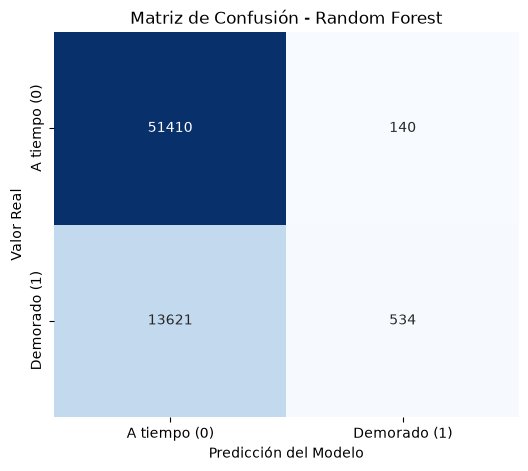

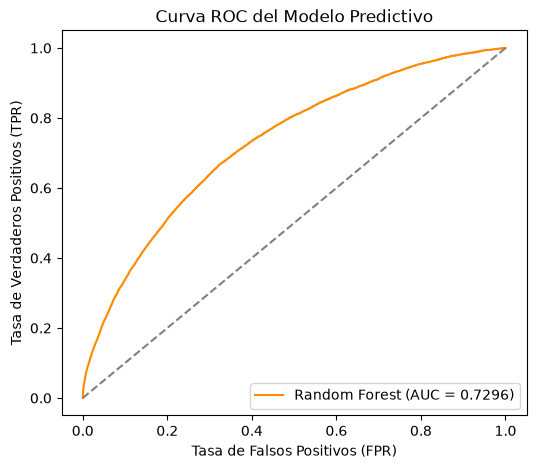

In [108]:
# ============================================================
# 8.2.5. EVALUACIÓN FINAL EN TEST Y GRÁFICOS DE RENDIMIENTO
# ============================================================


# Predicciones finales en test
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("=== REPORTE DE CLASIFICACIÓN FINAL (RANDOM FOREST) ===")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Final Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

# Visualizar Matriz de Confusión
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["A tiempo (0)", "Demorado (1)"],
            yticklabels=["A tiempo (0)", "Demorado (1)"])
plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.show()

# Visualizar Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.4f})", color="darkorange")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC del Modelo Predictivo")
plt.legend(loc="lower right")
plt.show()

### 8.3. Modelado de Clustering (K-Means)

#### 8.3.1 Planteo del problema y unidad de análisis


**agrupar**

Las matrículas de los aviones (`matricula_avion`) que tengan al menos **30 vuelos con llegada evaluable**.

**¿Por qué matrículas y no vuelos individuales?**

- Un mismo avión realiza numerosos vuelos durante el año, lo que permite construir un perfil de su comportamiento operativo.
- Conecta con los análisis del EDA: demoras recurrentes, recuperación de tiempo, intensidad de operaciones y puntualidad.
- Permite identificar aeronaves con comportamientos similares.
- Reduce el ruido que puede introducir el análisis de vuelos individuales.

**Pregunta de investigación:**

¿Existen diferentes perfiles de aviones según su comportamiento operativo y sus niveles de puntualidad?

**Objetivo:**

Identificar grupos de aeronaves con características similares, considerando sus niveles de demora, capacidad de recuperación, variabilidad e intensidad de operaciones.

**Alcance y limitaciones:**

El análisis comprende los vuelos registrados durante 2013 desde los aeropuertos de Nueva York (JFK, LGA y EWR). Por lo tanto, los perfiles representan el comportamiento observado en este conjunto de datos y no necesariamente toda la actividad de cada aeronave.

**Importante:**

Este modelo no busca predecir demoras ni reemplaza al modelo supervisado. Su finalidad es descubrir y describir grupos de aeronaves con características similares.


#### 8.3.2 AED para clustering: construcción y exploración del dataset de perfiles

##### 8.3.2.1 Indicadores que vamos a construir

Indicador	Qué vamos a medir
% llegadas graves	Porcentaje de llegadas con demora superior a 15 minutos
recuperacion_media_min	Promedio de demora de salida menos demora de llegada
variabilidad_demora_arribo_min	Desviación estándar de las demoras de llegada
distancia_media_millas	Distancia promedio de los vuelos
% vuelos tarde/noche	Porcentaje de vuelos programados desde las 12:00
vuelos_promedio_dia	Promedio de vuelos realizados por día activo
cantidad_vuelos	Cantidad total de vuelos operados durante el año

##### 8.3.2.2 Construcción de df_perfiles_avion

**Construcción del dataset de perfiles de aeronaves**

Se transforma el dataset original, que contiene un registro por vuelo, en una tabla con un registro por matrícula.

Para cada aeronave se calculan indicadores que resumen su puntualidad, comportamiento de las demoras, distancia recorrida e intensidad de operaciones.

Se consideran únicamente vuelos operados con matrícula identificada y se exige un mínimo de 30 llegadas evaluables por aeronave para asegurar una base suficiente de observaciones.

El resultado será `df_perfiles_avion`, que se utilizará en las siguientes etapas del clustering.


In [109]:
# ============================================================
# 1. PREPARAR LOS DATOS
# ============================================================

# Comprobar las columnas necesarias
columnas_necesarias = [
    "id",
    "estado_vuelo",
    "matricula_avion",
    "demora_salida_min",
    "demora_arribo_min",
    "distancia_nm",
    "periodo_salida_programado",
    "fecha_hora_salida_programada"
]

faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise KeyError(f"Faltan columnas: {faltantes}")


# Trabajar únicamente con vuelos operados
base = df.loc[
    df["estado_vuelo"].eq("operado")
].copy()


# Excluir matrículas faltantes o vacías
matricula_valida = (
    base["matricula_avion"].notna()
    & base["matricula_avion"]
        .astype("string")
        .str.strip()
        .ne("")
)

base = base.loc[matricula_valida].copy()


# Asegurar que las variables numéricas sean numéricas
columnas_numericas = [
    "demora_salida_min",
    "demora_arribo_min",
    "distancia_nm"
]

for columna in columnas_numericas:
    base[columna] = pd.to_numeric(
        base[columna],
        errors="coerce"
    )


# ============================================================
# 2. CREAR INDICADORES AUXILIARES POR VUELO
# ============================================================

# Identificar llegadas con demora superior a 15 minutos
base["_llegada_grave"] = (
    base["demora_arribo_min"]
    .gt(15)
    .fillna(False)
    .astype("int64")
)


# Recuperación de tiempo durante el vuelo
base["_recuperacion_min"] = (
    base["demora_salida_min"]
    - base["demora_arribo_min"]
)


# Identificar vuelos programados de tarde o noche
periodo = (
    base["periodo_salida_programado"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

base["_vuelo_tarde_noche"] = np.where(
    periodo.isna(),
    np.nan,
    periodo.isin(["tarde", "noche"]).astype(float)
)


# Crear fecha del día de operación
base["_fecha_operacion"] = (
    pd.to_datetime(
        base["fecha_hora_salida_programada"],
        errors="coerce"
    )
    .dt.normalize()
)


# ============================================================
# 3. RESUMIR LOS INDICADORES POR MATRÍCULA
# ============================================================

resumen = (
    base.groupby("matricula_avion")
    .agg(
        cantidad_vuelos=("id", "size"),

        arribos_evaluables=(
            "demora_arribo_min",
            "count"
        ),

        llegadas_graves=(
            "_llegada_grave",
            "sum"
        ),

        recuperacion_media_min=(
            "_recuperacion_min",
            "mean"
        ),

        variabilidad_demora_arribo_min=(
            "demora_arribo_min",
            "std"
        ),

        distancia_media_millas=(
            "distancia_nm",
            "mean"
        ),

        pct_vuelos_tarde_noche=(
            "_vuelo_tarde_noche",
            "mean"
        )
    )
)


# ============================================================
# 4. CALCULAR PORCENTAJES
# ============================================================

# Porcentaje de llegadas graves
resumen["pct_llegadas_graves"] = (
    100 * resumen["llegadas_graves"]
    / resumen["arribos_evaluables"].replace(0, np.nan)
)


# Convertir porcentaje de tarde/noche a escala 0-100
resumen["pct_vuelos_tarde_noche"] = (
    resumen["pct_vuelos_tarde_noche"] * 100
)


# ============================================================
# 5. CALCULAR PROMEDIO DE VUELOS POR DÍA ACTIVO
# ============================================================

# Contar vuelos diarios por matrícula
vuelos_por_dia = (
    base.dropna(
        subset=["_fecha_operacion"]
    )
    .groupby(
        ["matricula_avion", "_fecha_operacion"]
    )
    .size()
    .rename("vuelos_dia")
    .reset_index()
)


# Calcular el promedio diario de cada matrícula
vuelos_promedio_dia = (
    vuelos_por_dia
    .groupby("matricula_avion")["vuelos_dia"]
    .mean()
)


# Incorporar el promedio al resumen
resumen = resumen.join(
    vuelos_promedio_dia
    .rename("vuelos_promedio_dia")
)


# ============================================================
# 6. APLICAR CRITERIO MÍNIMO DE 30 LLEGADAS EVALUABLES
# ============================================================

MIN_VUELOS = 30

df_perfiles_avion = (
    resumen.loc[
        resumen["arribos_evaluables"] >= MIN_VUELOS
    ]
    .reset_index()
    .sort_values("matricula_avion")
    .reset_index(drop=True)
)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("CONSTRUCCIÓN DEL DATASET DE PERFILES")
print("-" * 45)

print(f"Vuelos operados con matrícula: {len(base):,}")

print(
    f"Matrículas identificadas: "
    f"{base['matricula_avion'].nunique():,}"
)

print(
    f"Matrículas con al menos {MIN_VUELOS} "
    f"llegadas evaluables: {len(df_perfiles_avion):,}"
)

print(
    f"Filas del nuevo DataFrame: "
    f"{df_perfiles_avion.shape[0]:,}"
)

print(
    f"Columnas del nuevo DataFrame: "
    f"{df_perfiles_avion.shape[1]}"
)

display(df_perfiles_avion.head(10))

CONSTRUCCIÓN DEL DATASET DE PERFILES
---------------------------------------------
Vuelos operados con matrícula: 328,521
Matrículas identificadas: 4,037
Matrículas con al menos 30 llegadas evaluables: 2,724
Filas del nuevo DataFrame: 2,724
Columnas del nuevo DataFrame: 10


,matricula_avion,cantidad_vuelos,arribos_evaluables,llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,pct_llegadas_graves,vuelos_promedio_dia
0,N0EGMQ,354,352,91,-1.46875,40.478896,679.734463,56.779661,25.852273,1.726829
1,N10156,146,145,47,5.234483,39.623875,756.089041,57.534247,32.413793,1.505155
2,N102UW,48,48,7,5.0625,43.932931,535.875000,47.916667,14.583333,1.090909
3,N103US,46,46,1,3.73913,12.102162,535.195652,32.608696,2.173913,1.022222
4,N104UW,47,46,6,8.326087,45.232545,535.255319,40.425532,13.043478,1.021739
5,N10575,272,269,91,1.453532,52.316395,520.128676,63.970588,33.828996,1.721519
6,N105UW,45,45,9,2.844444,30.572864,524.844444,51.111111,20.0,1.000000
7,N107US,41,41,5,5.268293,23.610405,528.707317,51.219512,12.195122,1.051282
8,N108UW,60,60,11,5.466667,31.416084,534.500000,46.666667,18.333333,1.034483
9,N109UW,48,48,7,2.625,22.45183,535.875000,47.916667,14.583333,1.043478


##### 8.3.2.3 Comprobar el nuevo DataFrame

**Control inicial del dataset de perfiles**

Se revisa la estructura, los tipos de datos, los valores faltantes y las estadísticas descriptivas de los indicadores calculados.

El objetivo es comprobar que cada matrícula tenga un único registro y que los indicadores tengan valores coherentes antes de iniciar el análisis exploratorio.


In [110]:
# Dimensiones
print(df_perfiles_avion.shape)

# Tipos de datos
display(
    df_perfiles_avion.dtypes.to_frame(
        name="tipo_dato"
    )
)

# Valores faltantes
display(
    df_perfiles_avion.isna().sum().to_frame(
        name="valores_nulos"
    )
)

# Estadísticas descriptivas
display(
    df_perfiles_avion.describe().T.round(2)
)

# Comprobar matrículas duplicadas
print(
    "Matrículas duplicadas:",
    df_perfiles_avion["matricula_avion"].duplicated().sum()
)

(2724, 10)


,tipo_dato
matricula_avion,str
cantidad_vuelos,int64
arribos_evaluables,Int64
llegadas_graves,int64
recuperacion_media_min,Float64
variabilidad_demora_arribo_min,Float64
distancia_media_millas,float64
pct_vuelos_tarde_noche,float64
pct_llegadas_graves,Float64
vuelos_promedio_dia,float64


,valores_nulos
matricula_avion,0
cantidad_vuelos,0
arribos_evaluables,0
llegadas_graves,0
recuperacion_media_min,0
variabilidad_demora_arribo_min,0
distancia_media_millas,0
pct_vuelos_tarde_noche,0
pct_llegadas_graves,0
vuelos_promedio_dia,0


,count,mean,std,min,25%,50%,75%,max
cantidad_vuelos,2724.0,114.423275,82.453091,30.0,52.0,90.0,139.0,546.0
arribos_evaluables,2724.0,114.015786,82.155291,30.0,51.0,90.0,139.0,544.0
llegadas_graves,2724.0,26.959618,23.500897,0.0,11.0,18.0,32.0,121.0
recuperacion_media_min,2724.0,6.161851,4.058092,-8.277778,3.190299,6.449491,9.217309,20.5625
variabilidad_demora_arribo_min,2724.0,42.076853,13.965185,12.102162,33.332709,40.582224,48.564426,225.360973
distancia_media_millas,2724.0,1072.917295,563.002785,173.093333,634.126689,1001.064286,1349.953334,4983.0
pct_vuelos_tarde_noche,2724.0,60.235856,10.362561,0.0,55.172414,60.324019,65.317618,100.0
pct_llegadas_graves,2724.0,22.69169,7.108143,0.0,17.647059,22.073444,27.027027,54.285714
vuelos_promedio_dia,2724.0,1.280653,0.274462,1.0,1.090909,1.192308,1.379038,2.544444


Matrículas duplicadas: 0


##### 8.3.2.4 Distribuciones, asimetrías y valores extremos

Ahora comienza el AED propiamente dicho del dataset de perfiles.

Vamos a utilizar los siete indicadores.

In [111]:
variables_perfil = [
    "pct_llegadas_graves",
    "recuperacion_media_min",
    "variabilidad_demora_arribo_min",
    "distancia_media_millas",
    "pct_vuelos_tarde_noche",
    "vuelos_promedio_dia",
    "cantidad_vuelos"
]

A. Histogramas

**Distribución de los indicadores de las aeronaves**

Se analiza cómo se distribuyen los valores de cada indicador entre las matrículas.

Los histogramas permiten identificar concentraciones de aeronaves, asimetrías y posibles distribuciones de cola larga.


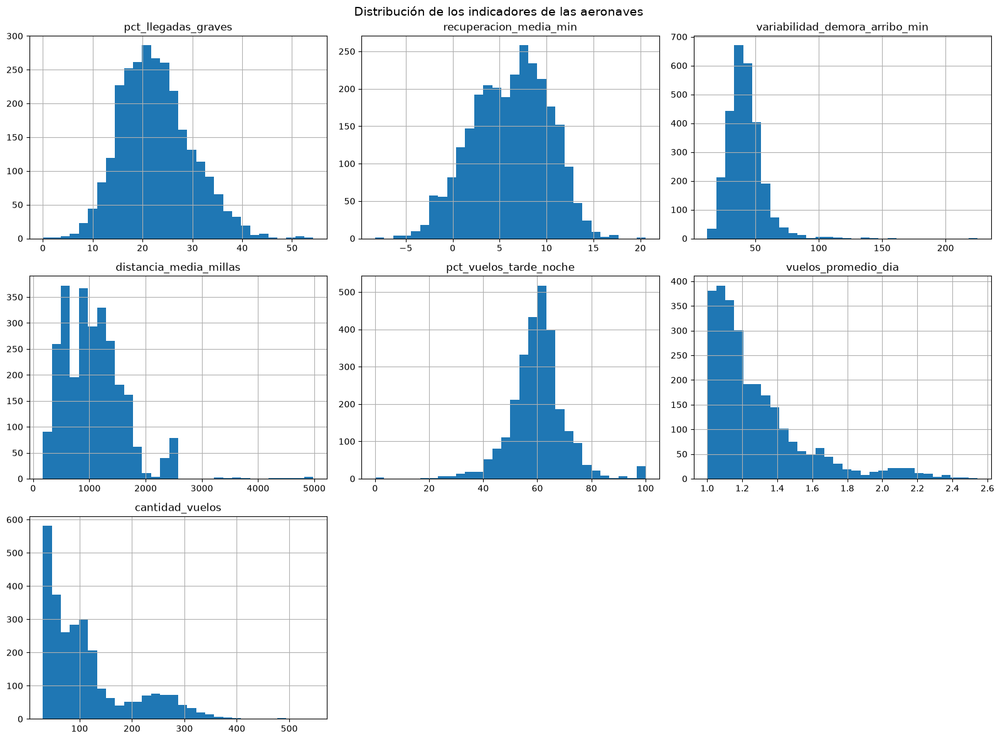

In [112]:
df_perfiles_avion[variables_perfil].hist(
    bins=30,
    figsize=(16, 12)
)

plt.suptitle(
    "Distribución de los indicadores de las aeronaves",
    fontsize=14
)

plt.tight_layout()
plt.show()

B. Boxplots


**Identificación de valores extremos**

Se utilizan diagramas de caja para observar la dispersión de cada indicador y detectar posibles valores extremos.

Estos valores se revisarán antes de aplicar K-Means, ya que pueden influir considerablemente en la formación de los grupos.


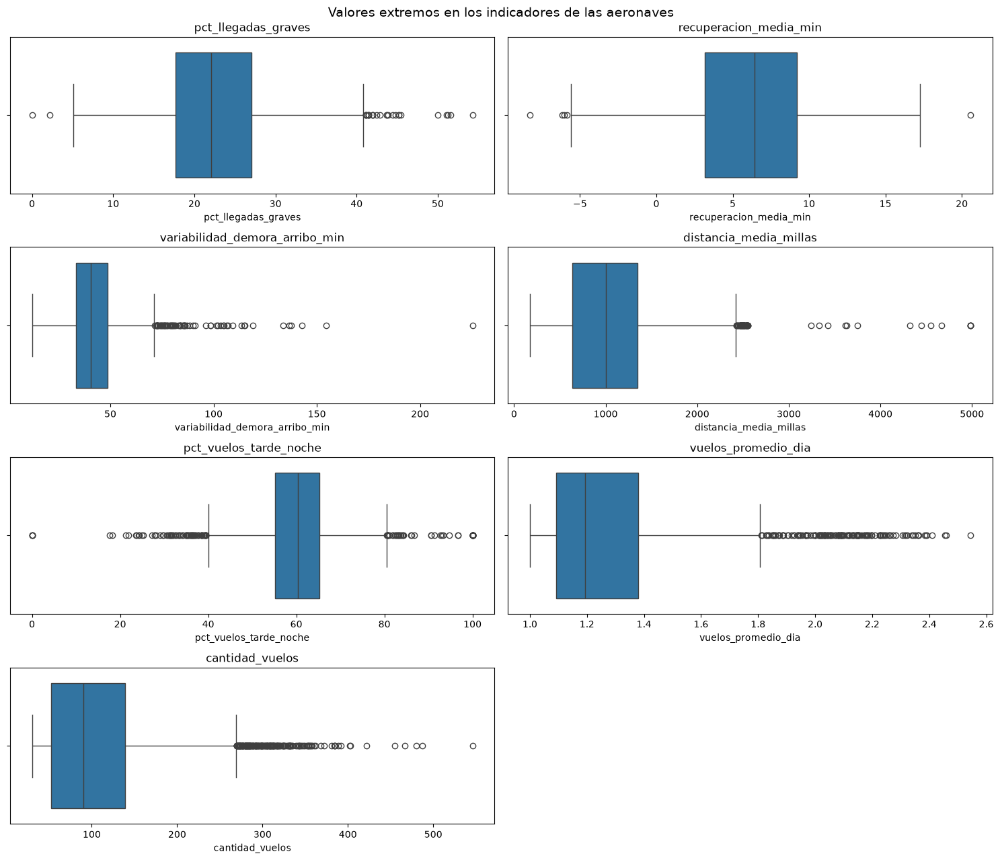

In [113]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 13)
)

for variable, ax in zip(
    variables_perfil,
    axes.flat
):
    sns.boxplot(
        x=df_perfiles_avion[variable],
        ax=ax
    )

    ax.set_title(variable)

# Ocultar el último espacio vacío
axes.flat[-1].set_visible(False)

plt.suptitle(
    "Valores extremos en los indicadores de las aeronaves",
    fontsize=14
)

plt.tight_layout()
plt.show()

C. Asimetría de las variables

**Análisis de asimetría**

Se calcula el coeficiente de asimetría de cada indicador para identificar distribuciones que presentan concentraciones de valores y colas hacia alguno de sus extremos.

Las variables con mayor asimetría serán revisadas para determinar si necesitan una transformación antes del clustering.


In [114]:
asimetria = (
    df_perfiles_avion[variables_perfil]
    .skew()
    .sort_values(ascending=False)
)

display(
    asimetria.to_frame(
        name="coeficiente_asimetria"
    ).round(3)
)

,coeficiente_asimetria
variabilidad_demora_arribo_min,2.345
vuelos_promedio_dia,1.694
distancia_media_millas,1.483
cantidad_vuelos,1.308
pct_llegadas_graves,0.453
pct_vuelos_tarde_noche,0.047
recuperacion_media_min,-0.185


D. Matriz de correlación


**Correlación entre los indicadores**

Se analiza la relación entre las variables numéricas para identificar posibles redundancias.

Se prestará especial atención a las correlaciones superiores a 0,8 en valor absoluto, ya que podrían indicar que dos indicadores aportan información muy similar.

Los resultados servirán para justificar la selección definitiva de variables en la siguiente etapa.


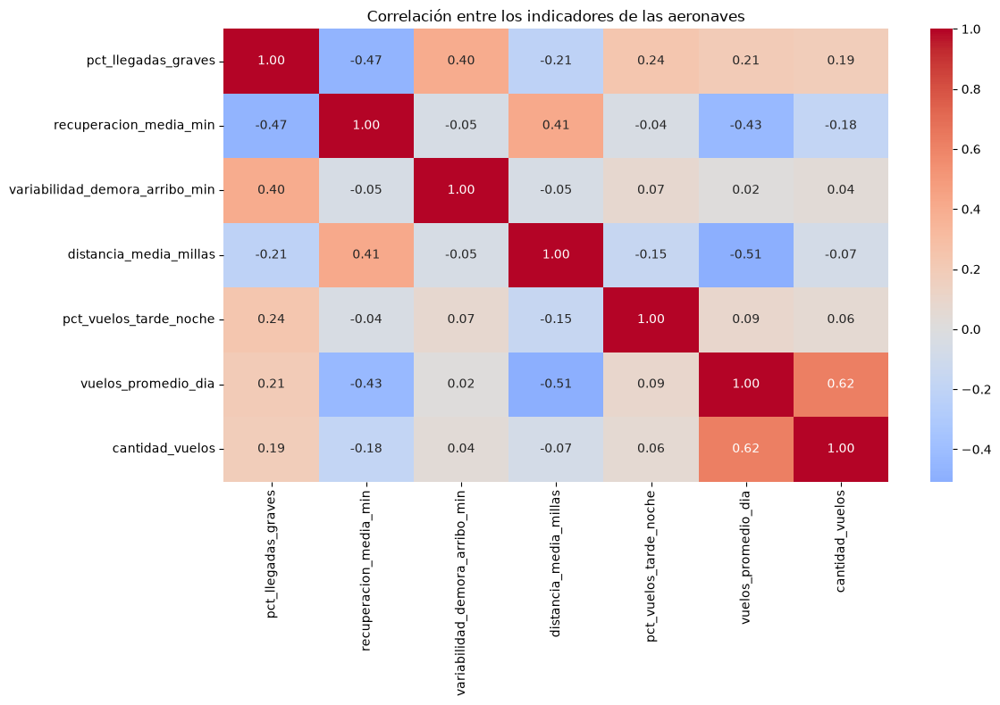

In [115]:
matriz_correlacion = (
    df_perfiles_avion[variables_perfil]
    .corr()
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="coolwarm"
)

plt.title(
    "Correlación entre los indicadores de las aeronaves"
)

plt.tight_layout()
plt.show()


**Resultados preliminares del AED de perfiles**

Se construyó un dataset de perfiles de aeronaves con 2.724 matrículas que cumplen el requisito de al menos 30 llegadas evaluables.

La nueva tabla contiene un registro por matrícula y presenta 10 columnas, sin valores nulos ni matrículas duplicadas.

Entre los principales resultados se observa:

- El porcentaje promedio de llegadas graves es del 22,69 %.
- La recuperación media de tiempo durante el vuelo es de aproximadamente 6,16 minutos.
- La variabilidad promedio de las demoras de llegada es de 42,08 minutos.
- El promedio de vuelos por día activo es de 1,28.

El análisis de asimetría identificó distribuciones con mayor concentración hacia valores bajos y colas hacia valores altos, especialmente en la variabilidad de las demoras, los vuelos promedio por día, la distancia media y la cantidad total de vuelos.

Estos resultados indican que será necesario revisar las distribuciones y los valores extremos antes de aplicar el algoritmo de clustering.

También se evaluará la influencia de la cantidad total de vuelos, para evitar que el nivel de actividad tenga un peso excesivo frente a los indicadores de puntualidad.


#### 8.3.3 Selección de variables y preprocesamiento

Para aplicar K-Means se seleccionan siete variables numéricas que representan la puntualidad, la recuperación de demoras, la regularidad y el comportamiento operativo de cada avión.

El análisis de correlaciones no encontró pares con una relación superior a 0.8, por lo que se conservan todas las variables.

Debido a la asimetría observada en algunas distribuciones, se aplica una transformación logarítmica (`log1p`) a las variables con cola derecha pronunciada. Finalmente, se utiliza `StandardScaler` para llevar todas las variables a una escala comparable.

Las variables de identificación y contexto, como matrícula y aerolínea, no ingresan al algoritmo. Se reservan para interpretar los grupos posteriormente.

In [116]:
# Variables que ingresarán al modelo de clustering
columnas_cluster = [
    "pct_llegadas_graves",
    "recuperacion_media_min",
    "variabilidad_demora_arribo_min",
    "distancia_media_millas",
    "pct_vuelos_tarde_noche",
    "vuelos_promedio_dia",
    "cantidad_vuelos"
]

# Variables con asimetría positiva que transformaremos con log1p
columnas_log = [
    "variabilidad_demora_arribo_min",
    "distancia_media_millas",
    "vuelos_promedio_dia",
    "cantidad_vuelos"
]

# Crear una matriz de trabajo sin modificar los perfiles originales
X_original = df_perfiles_avion[columnas_cluster].copy()

# Comprobar que no haya valores faltantes
print("Valores nulos:", X_original.isna().sum().sum())

# Comprobar que las variables a transformar no tengan valores negativos
print("Valores negativos en variables log:")
display((X_original[columnas_log] < 0).sum())

# Aplicar transformación logarítmica
X_transformado = X_original.copy()

X_transformado[columnas_log] = np.log1p(
    X_transformado[columnas_log]
)

# Estandarizar las variables
escalador_base = StandardScaler()

X_cluster_base = pd.DataFrame(
    escalador_base.fit_transform(X_transformado),
    columns=columnas_cluster,
    index=X_transformado.index
)

# Revisar el resultado
display(X_cluster_base.describe().round(2))

Valores nulos: 0
Valores negativos en variables log:


variabilidad_demora_arribo_min    0
distancia_media_millas            0
vuelos_promedio_dia               0
cantidad_vuelos                   0
dtype: Int64

,pct_llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,vuelos_promedio_dia,cantidad_vuelos
count,2724.00,2724.00,2724.00,2724.00,2724.00,2724.00,2724.00
mean,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.19,-3.56,-3.81,-3.10,-5.81,-1.12,-1.62
25%,-0.71,-0.73,-0.60,-0.71,-0.49,-0.72,-0.82
50%,-0.09,0.07,0.03,0.13,0.01,-0.30,-0.01
75%,0.61,0.75,0.62,0.68,0.49,0.44,0.63
max,4.45,3.55,5.68,3.08,3.84,4.03,2.66


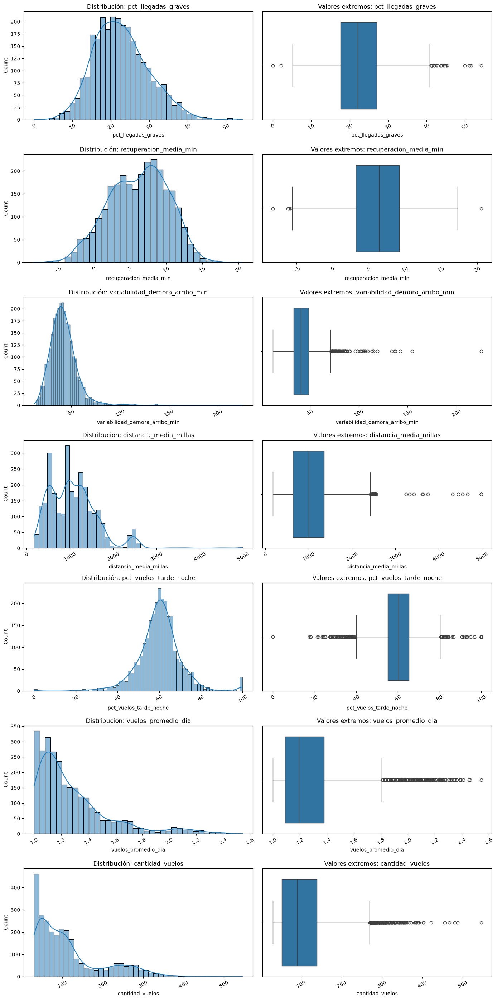

In [117]:
# Crear gráficos: una fila por variable
fig, axes = plt.subplots(
    len(columnas_cluster),
    2,
    figsize=(14, 4 * len(columnas_cluster))
)

for i, columna in enumerate(columnas_cluster):

    # Histograma
    sns.histplot(
        data=X_original,
        x=columna,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Distribución: {columna}")
    axes[i, 0].tick_params(axis="x", rotation=30)

    # Boxplot
    sns.boxplot(
        data=X_original,
        x=columna,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"Valores extremos: {columna}")
    axes[i, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

##### 8.3.3.1 Elección del algoritmo y del número de grupos

Se selecciona K-Means porque permite agrupar matrículas según la similitud de sus características operativas y de puntualidad. Además, sus centros representan el perfil promedio de cada grupo, lo que facilita su interpretación.

Para determinar el número adecuado de grupos (`k`), se prueban valores entre 2 y 8.

Se utilizan cuatro criterios complementarios:

- Método del codo: analiza cuánto disminuye la dispersión interna al aumentar los grupos.
- Silhouette: cuanto más alto, mejor separación entre grupos.
- Davies-Bouldin: cuanto más bajo, mejor compacidad y separación.
- Calinski-Harabasz: cuanto más alto, mejor separación entre grupos.

También se revisa el tamaño de los grupos para evitar segmentos demasiado pequeños.

###### Evaluar distintos valores de k

In [118]:
# Valores de k que vamos a comparar
valores_k = range(2, 9)

# Preparar contenedores para los resultados
resultados_k = []
modelos_base = {}
etiquetas_base = {}

for k in valores_k:

    # Crear y entrenar el modelo
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_cluster_base)

    # Calcular tamaño del grupo más pequeño
    tamanos = pd.Series(etiquetas).value_counts()

    porcentaje_minimo = tamanos.min() / len(etiquetas) * 100

    # Guardar métricas
    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_cluster_base, etiquetas),
        "davies_bouldin": davies_bouldin_score(X_cluster_base, etiquetas),
        "calinski_harabasz": calinski_harabasz_score(X_cluster_base, etiquetas),
        "grupo_minimo_pct": porcentaje_minimo
    })

    modelos_base[k] = modelo
    etiquetas_base[k] = etiquetas

# Convertir los resultados en una tabla
resultados_k = pd.DataFrame(resultados_k)

display(resultados_k.round(3))

,k,inercia,silhouette,davies_bouldin,calinski_harabasz,grupo_minimo_pct
0,2,14315.608,0.274,1.536,903.631,31.828
1,3,12317.877,0.226,1.693,745.546,23.642
2,4,11105.118,0.195,1.680,650.124,17.841
3,5,10257.476,0.170,1.634,583.868,14.611
4,6,9463.582,0.175,1.611,551.693,7.379
5,7,8950.913,0.174,1.528,511.832,6.461
6,8,8487.180,0.173,1.546,483.713,6.278


###### Gráficos para elegir k

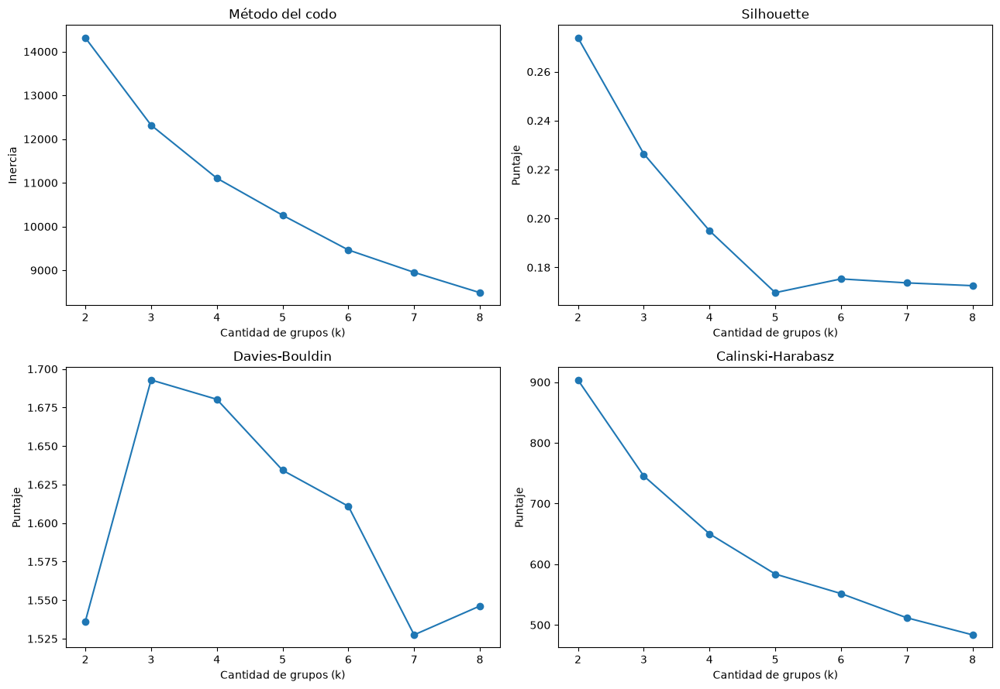

In [119]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Método del codo
axes[0, 0].plot(
    resultados_k["k"],
    resultados_k["inercia"],
    marker="o"
)
axes[0, 0].set_title("Método del codo")
axes[0, 0].set_xlabel("Cantidad de grupos (k)")
axes[0, 0].set_ylabel("Inercia")

# Silhouette
axes[0, 1].plot(
    resultados_k["k"],
    resultados_k["silhouette"],
    marker="o"
)
axes[0, 1].set_title("Silhouette")
axes[0, 1].set_xlabel("Cantidad de grupos (k)")
axes[0, 1].set_ylabel("Puntaje")

# Davies-Bouldin
axes[1, 0].plot(
    resultados_k["k"],
    resultados_k["davies_bouldin"],
    marker="o"
)
axes[1, 0].set_title("Davies-Bouldin")
axes[1, 0].set_xlabel("Cantidad de grupos (k)")
axes[1, 0].set_ylabel("Puntaje")

# Calinski-Harabasz
axes[1, 1].plot(
    resultados_k["k"],
    resultados_k["calinski_harabasz"],
    marker="o"
)
axes[1, 1].set_title("Calinski-Harabasz")
axes[1, 1].set_xlabel("Cantidad de grupos (k)")
axes[1, 1].set_ylabel("Puntaje")

plt.tight_layout()
plt.show()

##### 8.3.3.5 Evaluación y revisión crítica del modelo base


Como no existe una clasificación correcta de los aviones, el clustering no se evalúa mediante accuracy. Se revisan las métricas internas y la estabilidad de los grupos.

Para evaluar la estabilidad, se repite K-Means con distintas semillas y con submuestras del 80 % de los datos. Se comparan las agrupaciones mediante ARI (Adjusted Rand Index), donde 1 indica coincidencia total y 0 una coincidencia similar a la aleatoria.

También se revisa el tamaño mínimo de los grupos y qué variables contribuyen más a diferenciarlos.

**Criterio:** se considera deseable un ARI promedio de al menos 0.85 tanto entre semillas como entre submuestras, y que ningún grupo represente menos del 10 % de las matrículas.

estabilidad de K-Means

In [120]:
#from itertools import combinations
#
#from sklearn.metrics import (
#    silhouette_score,
#    davies_bouldin_score,
#    calinski_harabasz_score,
#    adjusted_rand_score
#)
#
#from sklearn.preprocessing import StandardScaler, RobustScaler
#from sklearn.decomposition import PCA

In [121]:
def promedio_ari(particiones):

    comparaciones = [
        adjusted_rand_score(a, b)
        for a, b in combinations(particiones, 2)
    ]

    return np.mean(comparaciones)


def evaluar_estabilidad_kmeans(
    X,
    k,
    repeticiones=10,
    fraccion=0.80
):

    particiones_semillas = []
    particiones_submuestras = []

    # 1. Repetir el modelo con distintas semillas
    for semilla in range(repeticiones):

        modelo = KMeans(
            n_clusters=k,
            random_state=100 + semilla,
            n_init=20
        )

        etiquetas = modelo.fit_predict(X)

        particiones_semillas.append(etiquetas)

    # 2. Entrenar con distintas submuestras del 80 %
    generador = np.random.default_rng(2026 + k)

    cantidad_muestra = int(len(X) * fraccion)

    for repeticion in range(repeticiones):

        indices = generador.choice(
            len(X),
            size=cantidad_muestra,
            replace=False
        )

        # Seleccionar la submuestra
        if isinstance(X, pd.DataFrame):
            X_muestra = X.iloc[indices]
        else:
            X_muestra = X[indices]

        modelo = KMeans(
            n_clusters=k,
            random_state=200 + repeticion,
            n_init=20
        )

        modelo.fit(X_muestra)

        # Asignar todos los aviones a los centros obtenidos
        etiquetas_completas = modelo.predict(X)

        particiones_submuestras.append(etiquetas_completas)

    # 3. Comparar las particiones mediante ARI
    ari_semillas = promedio_ari(particiones_semillas)

    ari_submuestras = promedio_ari(particiones_submuestras)

    return {
        "ARI_semillas": ari_semillas,
        "ARI_submuestras": ari_submuestras,
        "ARI_minimo": min(ari_semillas, ari_submuestras)
    }

###### Revisar el tamaño de los grupos y las variables que los diferencian

In [122]:
# Reemplazar por el k elegido luego de revisar las métricas
K_ELEGIDO = None

if K_ELEGIDO not in modelos_base:
    print("Definí K_ELEGIDO con el valor seleccionado en la evaluación.")
else:

    etiquetas_base_elegidas = etiquetas_base[K_ELEGIDO]

    # Tamaño y porcentaje de cada grupo
    tamanos_clusters = pd.Series(
        etiquetas_base_elegidas
    ).value_counts().sort_index()

    resumen_tamanos = pd.DataFrame({
        "cantidad_aviones": tamanos_clusters,
        "porcentaje_flota": (
            tamanos_clusters / len(df_perfiles_avion) * 100
        )
    })

    display(resumen_tamanos.round(2))

Definí K_ELEGIDO con el valor seleccionado en la evaluación.


In [123]:
if K_ELEGIDO in modelos_base:

    etiquetas = pd.Series(
        etiquetas_base[K_ELEGIDO],
        index=X_cluster_base.index
    )

    media_global = X_cluster_base.mean()

    variabilidad_total = (
        (X_cluster_base - media_global) ** 2
    ).sum()

    variabilidad_entre_grupos = pd.Series(
        0.0,
        index=X_cluster_base.columns
    )

    for cluster in sorted(etiquetas.unique()):

        grupo = X_cluster_base.loc[etiquetas == cluster]

        variabilidad_entre_grupos += (
            len(grupo) * (grupo.mean() - media_global) ** 2
        )

    contribucion_variables = (
        variabilidad_entre_grupos / variabilidad_total * 100
    ).sort_values(ascending=False)

    display(
        contribucion_variables
        .rename("separacion_entre_clusters_pct")
        .round(2)
    )

##### 8.3.3.6 Mejora del modelo

A partir de la evaluación del modelo base, se comparan distintas alternativas de preprocesamiento para comprobar si permiten obtener grupos más estables, compactos e interpretables.

Se realizan dos pruebas, modificando una decisión por vez:

1. Sustituir StandardScaler por RobustScaler, para reducir la influencia de valores extremos.
2. Quitar `cantidad_vuelos`, para comprobar si el volumen total de actividad está condicionando demasiado la agrupación.

Se mantiene el mismo número de grupos (`k`) para que la comparación se concentre en el efecto de cada cambio.

Una alternativa se conserva solamente si mejora la estabilidad o las métricas, o si simplifica la interpretación sin empeorar los resultados.

In [132]:
# Definir el número de grupos seleccionado
K_ELEGIDO = 2

print("Número de grupos seleccionado:", K_ELEGIDO)

Número de grupos seleccionado: 2


preparar las alternativas

In [125]:
# Alternativa 1: utilizar RobustScaler
escalador_robusto = RobustScaler()

X_cluster_robusto = pd.DataFrame(
    escalador_robusto.fit_transform(X_transformado),
    columns=columnas_cluster,
    index=X_transformado.index
)


# Alternativa 2: quitar cantidad_vuelos
columnas_sin_cantidad = [
    columna
    for columna in columnas_cluster
    if columna != "cantidad_vuelos"
]

escalador_sin_cantidad = StandardScaler()

X_cluster_sin_cantidad = pd.DataFrame(
    escalador_sin_cantidad.fit_transform(
        X_transformado[columnas_sin_cantidad]
    ),
    columns=columnas_sin_cantidad,
    index=X_transformado.index
)


# Preparar las tres alternativas
variantes = {
    "Base": X_cluster_base,
    "RobustScaler": X_cluster_robusto,
    "Sin cantidad_vuelos": X_cluster_sin_cantidad
}

print("Alternativas preparadas:")
print(list(variantes.keys()))

Alternativas preparadas:
['Base', 'RobustScaler', 'Sin cantidad_vuelos']


comparar las variantes

In [129]:
# Asegurar el número de grupos seleccionado
K_ELEGIDO = 2

# Comparar las variantes
resultados_mejora = []

modelos_variantes = {}
etiquetas_variantes = {}

for nombre, X_variante in variantes.items():

    modelo = KMeans(
        n_clusters=K_ELEGIDO,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_variante)

    tamanos = pd.Series(etiquetas).value_counts()

    estabilidad = evaluar_estabilidad_kmeans(
        X_variante,
        K_ELEGIDO
    )

    resultados_mejora.append({
        "variante": nombre,
        "silhouette": silhouette_score(X_variante, etiquetas),
        "davies_bouldin": davies_bouldin_score(X_variante, etiquetas),
        "calinski_harabasz": calinski_harabasz_score(X_variante, etiquetas),
        "grupo_minimo_pct": tamanos.min() / len(etiquetas) * 100,
        **estabilidad
    })

    modelos_variantes[nombre] = modelo
    etiquetas_variantes[nombre] = etiquetas

resultados_mejora = pd.DataFrame(resultados_mejora)

display(resultados_mejora.round(3))

,variante,silhouette,davies_bouldin,calinski_harabasz,grupo_minimo_pct,ARI_semillas,ARI_submuestras,ARI_minimo
0,Base,0.274,1.536,903.631,31.828,1.000,0.960,0.960
1,RobustScaler,0.262,1.595,831.502,32.709,0.995,0.982,0.982
2,Sin cantidad_vuelos,0.290,1.450,989.522,31.351,0.994,0.934,0.934


elegir el modelo final

In [127]:
# Definir el número de grupos
K_ELEGIDO = 2

print("K elegido:", K_ELEGIDO)

K elegido: 2


In [130]:
# Seleccionar la alternativa ganadora
VARIANTE_FINAL = "Sin cantidad_vuelos"

# Recuperar la matriz seleccionada
X_final = variantes[VARIANTE_FINAL]

# Entrenar el modelo final
modelo_final = KMeans(
    n_clusters=K_ELEGIDO,
    random_state=42,
    n_init=20
)

etiquetas_final = modelo_final.fit_predict(X_final)

print("Modelo final:", VARIANTE_FINAL)
print("Cantidad de grupos:", K_ELEGIDO)
print("Matrículas agrupadas:", len(etiquetas_final))

Modelo final: Sin cantidad_vuelos
Cantidad de grupos: 2
Matrículas agrupadas: 2724


##### 8.3.3.7 Perfilado e interpretación de los clusters



Una vez seleccionado el modelo final, se asigna cada matrícula a un grupo y se construye un perfil para describir sus características.

Se analizan los promedios y medianas de las variables utilizadas en el clustering. También se incorporan variables que no participaron en el algoritmo, como aerolínea, tipo de aerolínea y aeropuerto de origen más frecuente.

Estas variables externas permiten contextualizar los grupos y comprobar si presentan diferencias operativas reconocibles.

Finalmente, se utilizan gráficos de perfiles, boxplots y PCA para visualizar las diferencias entre los grupos.

asignar los grupos y agregar información descriptiva

In [133]:
# Función para obtener la categoría más frecuente
def moda_segura(serie):

    valores = serie.mode()

    if valores.empty:
        return pd.NA

    return valores.iloc[0]


# Seleccionar vuelos operados con llegada evaluable
base_interpretacion = df.loc[
    (df["estado_vuelo"] == "operado")
    & df["matricula_avion"].notna()
    & df["demora_arribo_min"].notna()
].copy()


# Obtener los datos predominantes de cada matrícula
descriptores_avion = (
    base_interpretacion
    .groupby("matricula_avion")
    .agg(
        aerolinea_principal=("nombre_aerolinea", moda_segura),
        tipo_aerolinea_principal=("tipo_aerolinea", moda_segura),
        origen_principal=("origen", moda_segura),
        cantidad_aerolineas=("aerolinea", "nunique")
    )
)


# Crear la tabla final de aviones y agregar su cluster
df_clusters_final = df_perfiles_avion.copy()

df_clusters_final["cluster"] = pd.Series(
    etiquetas_final,
    index=df_perfiles_avion.index
)


# Incorporar información descriptiva
df_clusters_final = df_clusters_final.merge(
    descriptores_avion.reset_index(),
    on="matricula_avion",
    how="left"
)

display(df_clusters_final.head())

,matricula_avion,cantidad_vuelos,arribos_evaluables,llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,pct_llegadas_graves,vuelos_promedio_dia,cluster,aerolinea_principal,tipo_aerolinea_principal,origen_principal,cantidad_aerolineas
0,N0EGMQ,354,352,91,-1.46875,40.478896,679.734463,56.779661,25.852273,1.726829,0,Envoy Air,Regional,LGA,1
1,N10156,146,145,47,5.234483,39.623875,756.089041,57.534247,32.413793,1.505155,0,ExpressJet Airlines Inc.,Regional,EWR,1
2,N102UW,48,48,7,5.0625,43.932931,535.875000,47.916667,14.583333,1.090909,1,US Airways Inc.,Tradicional,EWR,1
3,N103US,46,46,1,3.73913,12.102162,535.195652,32.608696,2.173913,1.022222,1,US Airways Inc.,Tradicional,EWR,1
4,N104UW,47,46,6,8.326087,45.232545,535.255319,40.425532,13.043478,1.021739,1,US Airways Inc.,Tradicional,EWR,1


tabla de perfiles numéricos

In [134]:
# Calcular los promedios de las variables por grupo
perfil_clusters = (
    df_clusters_final
    .groupby("cluster")[columnas_cluster]
    .mean()
)

# Calcular el tamaño de cada grupo
tamanos = (
    df_clusters_final["cluster"]
    .value_counts()
    .sort_index()
)

# Agregar cantidad y porcentaje de aviones
perfil_clusters.insert(
    0,
    "cantidad_aviones",
    tamanos
)

perfil_clusters.insert(
    1,
    "porcentaje_flota",
    tamanos / len(df_clusters_final) * 100
)

display(perfil_clusters.round(2))

,cantidad_aviones,porcentaje_flota,pct_llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,vuelos_promedio_dia,cantidad_vuelos
cluster,,,,,,,,,
0,854,31.35,28.63,2.57,46.63,626.08,64.27,1.53,158.45
1,1870,68.65,19.98,7.8,40.0,1276.98,58.39,1.17,94.32


comparar también las medianas

In [135]:
medianas_clusters = (
    df_clusters_final
    .groupby("cluster")[columnas_cluster]
    .median()
)

display(medianas_clusters.round(2))

,pct_llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,vuelos_promedio_dia,cantidad_vuelos
cluster,,,,,,,
0,28.57,2.42,45.59,531.12,62.87,1.49,141.0
1,19.82,7.95,38.43,1208.14,58.90,1.14,82.0


características externas de cada grupo

In [136]:
perfil_categorico = (
    df_clusters_final
    .groupby("cluster")
    .agg(
        tipo_aerolinea_mas_frecuente=(
            "tipo_aerolinea_principal",
            moda_segura
        ),
        aerolinea_mas_frecuente=(
            "aerolinea_principal",
            moda_segura
        ),
        origen_mas_frecuente=(
            "origen_principal",
            moda_segura
        ),
        promedio_aerolineas_por_avion=(
            "cantidad_aerolineas",
            "mean"
        )
    )
)

display(perfil_categorico.round(2))

,tipo_aerolinea_mas_frecuente,aerolinea_mas_frecuente,origen_mas_frecuente,promedio_aerolineas_por_avion
cluster,,,,
0,Regional,ExpressJet Airlines Inc.,JFK,1.01
1,Tradicional,United Air Lines Inc.,LGA,1.00


In [137]:
distribucion_tipos = pd.crosstab(
    df_clusters_final["cluster"],
    df_clusters_final["tipo_aerolinea_principal"],
    normalize="index"
) * 100

display(distribucion_tipos.round(2))

tipo_aerolinea_principal,Bajo costo,Regional,Tradicional
cluster,,,
0,22.01,62.18,15.81
1,13.96,5.29,80.75


gráfico de perfiles

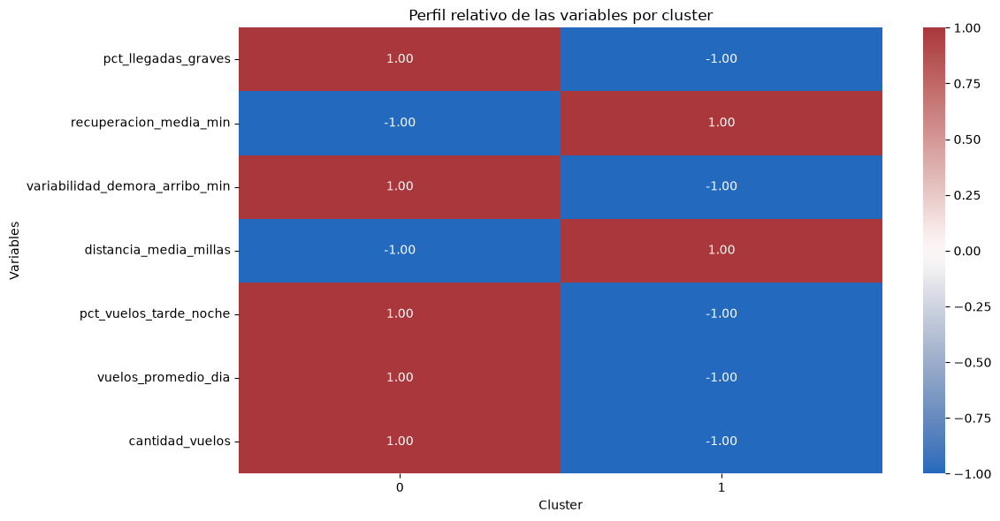

In [141]:
# Tomar solamente las variables del modelo y convertirlas a números
datos_grafico = (
    perfil_clusters[columnas_cluster]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

# Estandarizar los promedios entre grupos
perfil_grafico = (
    datos_grafico - datos_grafico.mean()
) / datos_grafico.std(ddof=0).replace(0, np.nan)

# Generar el mapa de calor
plt.figure(figsize=(12, 6))

sns.heatmap(
    perfil_grafico.T,
    annot=True,
    center=0,
    fmt=".2f",
    cmap="vlag"
)

plt.title("Perfil relativo de las variables por cluster")
plt.xlabel("Cluster")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

boxplots de los indicadores principales de puntualidad

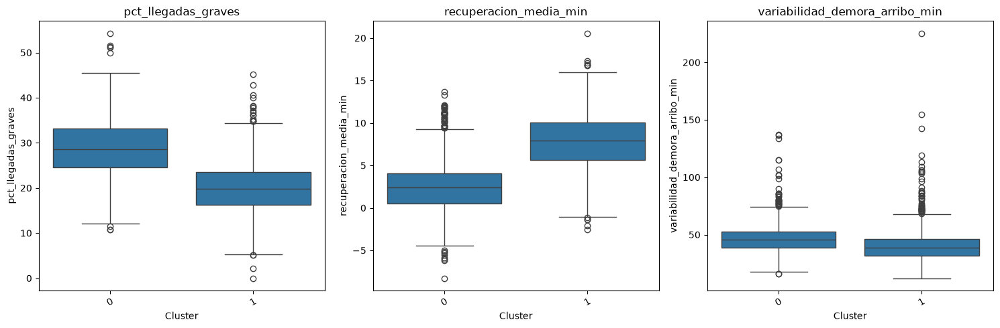

In [139]:
variables_graficos = [
    "pct_llegadas_graves",
    "recuperacion_media_min",
    "variabilidad_demora_arribo_min"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, columna in zip(axes, variables_graficos):

    sns.boxplot(
        data=df_clusters_final,
        x="cluster",
        y=columna,
        ax=ax
    )

    ax.set_title(columna)
    ax.set_xlabel("Cluster")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

visualización de los grupos mediante PCA

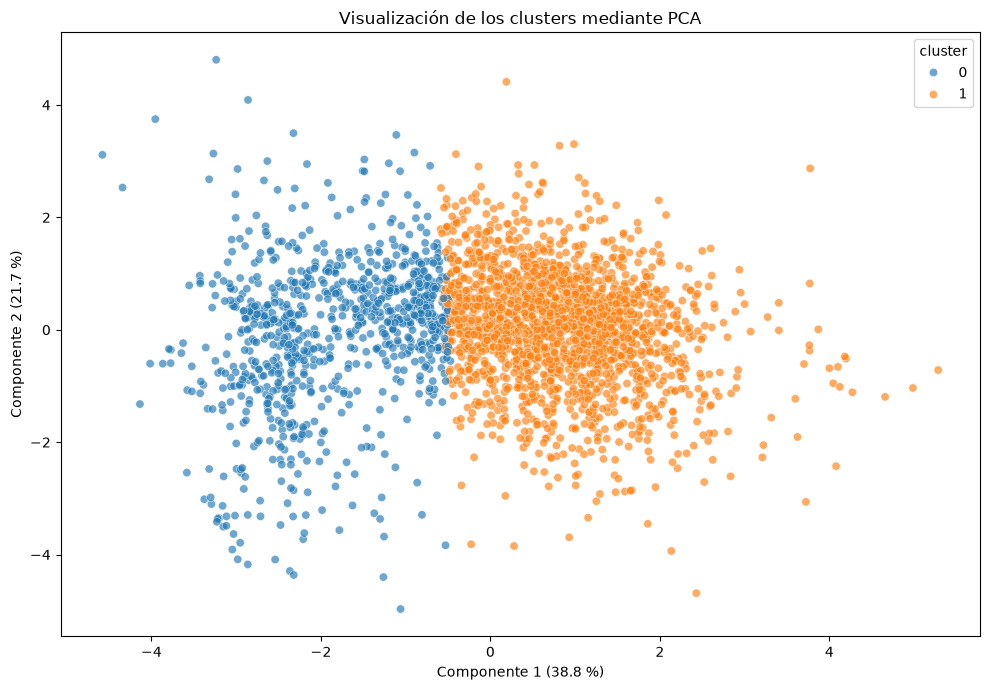

In [140]:
# Reducir las variables a dos componentes principales
pca = PCA(n_components=2)

coordenadas_pca = pca.fit_transform(X_final)

df_pca = pd.DataFrame(
    coordenadas_pca,
    columns=["componente_1", "componente_2"],
    index=df_perfiles_avion.index
)

df_pca["cluster"] = etiquetas_final


# Representar los grupos
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_pca,
    x="componente_1",
    y="componente_2",
    hue="cluster",
    alpha=0.65
)

plt.title("Visualización de los clusters mediante PCA")

plt.xlabel(
    f"Componente 1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)"
)

plt.ylabel(
    f"Componente 2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)"
)

plt.tight_layout()
plt.show()

##### 8.3.3.8 Conclusiones y decisiones del modelo de clustering

**Resumen de decisiones**

| Decisión | Elegido | Criterio | Alternativa descartada |
|---|---|---|---|
| Unidad de análisis | Matrículas con al menos 30 vuelos | Permite construir perfiles de comportamiento por avión | Vuelos individuales |
| Variables | 6 variables operativas y de puntualidad | Sin redundancia significativa y con sentido operativo | Incluir `cantidad_vuelos` |
| Preprocesamiento | `log1p` + `StandardScaler` | Reduce la asimetría y permite comparar variables en escalas similares | `RobustScaler` |
| Algoritmo | K-Means | Sencillo de aplicar e interpretar | Agrupamiento jerárquico Ward y Mezcla Gaussiana |
| Número de grupos | K = 2 | Mejor equilibrio entre separación, tamaño de grupos y estabilidad | Otros valores de K evaluados |
| Mejoras aplicadas | Eliminar `cantidad_vuelos` | Mejoró los tres indicadores de separación y mantuvo buena estabilidad | Modelo con las 7 variables originales |

**Hallazgos principales**

El análisis permitió identificar dos perfiles de comportamiento entre las matrículas de los aviones:

- **Cluster 0 – Mayor nivel de demoras graves:** presenta un 28,63 % de llegadas graves, una recuperación media de 2,57 minutos y una variabilidad de demora de 46,63 minutos. Representa el grupo que requiere mayor atención y seguimiento.
- **Cluster 1 – Mejor comportamiento de puntualidad:** presenta un 19,98 % de llegadas graves, una recuperación media de 7,8 minutos y una variabilidad de demora de 40 minutos. Muestra un comportamiento relativamente más favorable.

La diferencia entre ambos grupos es de 8,65 puntos porcentuales en las llegadas graves. También se observa que el Cluster 0 tiene mayor proporción de vuelos de tarde/noche y más vuelos promedio por día.

Estas diferencias son descriptivas y no permiten establecer relaciones causales. La distancia media también presenta diferencias importantes entre los grupos, por lo que debe considerarse al interpretar los resultados.

**Utilidad práctica**

La segmentación podría utilizarse como herramienta de seguimiento de la flota para:

- Identificar matrículas con mayor proporción de llegadas graves.
- Priorizar el monitoreo de aviones con menor recuperación de demoras y mayor variabilidad.
- Detectar patrones de comportamiento que justifiquen un análisis operativo más detallado.
- Comparar los perfiles de puntualidad entre diferentes matrículas.

El clustering no determina por sí solo que un avión tenga un problema técnico, pero permite identificar patrones que pueden justificar una revisión más detallada.

**Limitaciones**

- Los datos corresponden a un solo año y contemplan únicamente vuelos con salida desde aeropuertos de Nueva York.
- No se dispone de información sobre condiciones climáticas ni tráfico aéreo.
- K-Means depende de las variables seleccionadas y de la escala de los datos.
- El Silhouette final de 0,290 indica una separación moderada entre los grupos. Por lo tanto, deben interpretarse como segmentos descriptivos y no como categorías naturales perfectamente diferenciadas.

**Relación con el modelo supervisado (8.2)**

El clustering y el modelo supervisado cumplen funciones complementarias.

El clustering permite descubrir perfiles de comportamiento y segmentar las matrículas según sus características operativas y de puntualidad.

El modelo supervisado busca predecir la categoría de demora de un vuelo a partir de las variables disponibles.

En conjunto, ambos enfoques permiten analizar el comportamiento histórico de los vuelos, identificar patrones y aportar información para anticipar y monitorear posibles problemas de puntualidad.

**Conclusión general**

El modelo K-Means permitió segmentar las matrículas en dos grupos con perfiles diferenciados. La eliminación de `cantidad_vuelos` mejoró los indicadores de separación y mantuvo una estabilidad adecuada.

Aunque la separación entre los grupos es moderada, la segmentación resulta útil para describir patrones de puntualidad e identificar matrículas que podrían requerir mayor seguimiento operativo.

# Controles y anotaciones

In [ ]:
print(df.columns.tolist())
print(df_model.columns.tolist())

In [ ]:
# Mostrar la matriz de correlación
display(
    matriz_correlacion.round(3)
)

In [142]:
display(
    perfil_clusters[
        [
            "pct_llegadas_graves",
            "recuperacion_media_min",
            "variabilidad_demora_arribo_min",
            "distancia_media_millas",
            "pct_vuelos_tarde_noche",
            "vuelos_promedio_dia"
        ]
    ].round(2)
)

,pct_llegadas_graves,recuperacion_media_min,variabilidad_demora_arribo_min,distancia_media_millas,pct_vuelos_tarde_noche,vuelos_promedio_dia
cluster,,,,,,
0,28.63,2.57,46.63,626.08,64.27,1.53
1,19.98,7.8,40.0,1276.98,58.39,1.17


In [ ]:
# Obtener solamente la mitad superior de la matriz
correlaciones_superiores = (
    matriz_correlacion
    .where(
        np.triu(
            np.ones(matriz_correlacion.shape),
            k=1
        ).astype(bool)
    )
)

# Convertir las correlaciones a una tabla
pares_correlacion = (
    correlaciones_superiores
    .stack()
    .reset_index()
)

pares_correlacion.columns = [
    "variable_1",
    "variable_2",
    "correlacion"
]

# Mostrar las correlaciones más altas
pares_correlacion = (
    pares_correlacion
    .assign(
        correlacion_absoluta=lambda x:
            x["correlacion"].abs()
    )
    .sort_values(
        "correlacion_absoluta",
        ascending=False
    )
)

display(
    pares_correlacion.round(3)
)

In [ ]:
# Obtener únicamente las posiciones del triángulo superior, sin la diagonal
filas, columnas = np.triu_indices_from(matriz_correlacion, k=1)

# Construir la tabla con los pares de variables
pares_correlacion = pd.DataFrame({
    "variable_1": matriz_correlacion.index[filas],
    "variable_2": matriz_correlacion.columns[columnas],
    "correlacion": matriz_correlacion.to_numpy()[filas, columnas]
})

# Calcular el valor absoluto y ordenar de mayor a menor
pares_correlacion["correlacion_absoluta"] = pares_correlacion["correlacion"].abs()

pares_correlacion = (
    pares_correlacion
    .sort_values("correlacion_absoluta", ascending=False)
    .reset_index(drop=True)
)

display(pares_correlacion.round(3))